# Phase 5: statute identification — all original experiments


In [1]:
# Settings: edit this cell before running the notebook.
NOTEBOOK_VERSION = "LSI_V1_2026_10_25"
RUN_WORKFLOW = True
RUN_MODE = "train"  # "train" or "predict_saved" (export recovered best.pt files).
RUN_NAME = "lsi_run1"  # Change for a different training configuration; keep for exact resume.
INCLUDE_MODEL_D = True
ONLY_EXPERIMENTS = []  # D alone: ["D_lorma_hier"]. KD alone needs its saved Phase 5 D teacher.
RUN_TAIL_ABLATION = True
RUN_LOSS_ABLATION = True

PHASE1_REPOS = {
    "A": "I-230482/cs781-phase1-71m-checkpoints",
    "B": "I-230482/cs781-encdec-50m",
    "C": "I-230482/cs781-phase1-model-c-gqa-200m",
    "D": "I-230482/cs781-model-d-prefixlm",
}
PHASE1_FILES = {}  # Exact paths inside a repo, only if automatic selection is ambiguous.
PHASE1_REVISIONS = {}  # Optional pinned commits; otherwise main is resolved and recorded.
CHECKPOINT_OVERRIDES = {}  # Optional original local .pt paths/folders.
MODEL_D_CHECKPOINT = ""  # Blank loads D from its own HF repo above.
ALLOW_PHASE1_DOWNLOADS = True
LOCAL_DATA_DIR = ""  # Optional attached Phase_5_LSI folder or its parent.
DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
DATASET_REVISION = "93b0059be756c6c461f3a225de25aabda7d5f84a"

SEED = 42
MAX_GPUS = 2
CHUNK_TOKENS = 384
MAX_CHUNKS = 4
OVERLAP_TOKENS = 64
EPOCHS = 4
MINIMUM_EPOCHS = 2
PATIENCE = 2
HEAD_LR = 3e-4
ADAPTATION_LR = 3e-4
BACKBONE_LR = 3e-5
CLASS_WEIGHT_MODE = (
    "sqrt_ratio"  # Train-only positive BCE weights; "none" or "ratio" also supported.
)
POSITIVE_WEIGHT_CLIP = 20.0
INITIALIZE_BIAS_FROM_TRAIN = True
WEIGHT_DECAY = 0.01
WARMUP_FRACTION = 0.05
MAX_GRAD_NORM = 1.0
MICRO_BATCH_DOCS_PER_GPU = 2
EFFECTIVE_BATCH_DOCS = 16
EVAL_BATCH_DOCS = 4
WORKERS_PER_RANK = 0
CPU_THREADS_PER_RANK = 2
CHECKPOINT_EVERY_UPDATES = 200
LOG_EVERY_UPDATES = 20
TUNE_THRESHOLDS = True
PER_LABEL_MIN_SUPPORT = 5
THRESHOLD_SHRINK = 20.0
COMPARE_COOCCURRENCE = True
RUN_SECTION_ABLATIONS = True
RUN_THROUGHPUT_PILOT = True
PROFILE_UPDATES = 4

# Keep HF_TOKEN in Kaggle Secrets and enable access to it. Never paste it here.
AUTO_HF_BACKUP = True  # Upload task weights/history/thresholds every epoch and after export.
HF_BACKUP_REPO = "I-230482/cs781-phase5-models"
UPLOAD_RESUME_STATE = False  # True also uploads large last.pt optimizer/RNG states.
RESTORE_FROM_HF = False  # True restores this RUN_NAME using saved controls and pinned base files.
CREATE_LOCAL_MODEL_BUNDLE = True
INCLUDE_BASE_WEIGHTS_IN_BUNDLE = (
    False  # Original HF bases can normally be recovered by pinned references.
)

from pathlib import Path
import gc
import importlib
import importlib.util
import json
import os
import shutil
import subprocess
import sys
import time

ROOT = (
    (
        Path("/kaggle/working/cs781-phase5")
        if Path("/kaggle").is_dir()
        else Path.cwd() / "cs781-phase5"
    )
    / RUN_NAME
).resolve()
RUNTIME = ROOT / "runtime"
TOKENIZER_DIR = ROOT / "tokenizer"
DATA_DIR = ROOT / "official_data" / "Phase_5_LSI"
OUTPUT_DIR = ROOT / "results"
CONFIG_PATH = ROOT / "phase5_config.json"
for folder in (ROOT, RUNTIME, TOKENIZER_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["RAYON_NUM_THREADS"] = str(min(4, os.cpu_count() or 1))
print("Version:", NOTEBOOK_VERSION)
print("Run folder:", ROOT)
print("Mode:", RUN_MODE, "| real workflow:", RUN_WORKFLOW)


Version: LSI_V1_2026_10_25
Run folder: /kaggle/working/cs781-phase5/lsi_run1
Mode: train | real workflow: True


## Setup


In [2]:
if importlib.util.find_spec("torch") is None:
    raise RuntimeError("Use a Kaggle Python GPU image with PyTorch preinstalled.")
packages = {
    "numpy": "numpy>=1.26,<3",
    "tokenizers": "tokenizers>=0.20,<0.24",
    "huggingface_hub": "huggingface_hub==0.34.6",
    "sklearn": "scikit-learn>=1.3,<2",
    "matplotlib": "matplotlib>=3.8,<4",
}
missing = [
    requirement
    for module, requirement in packages.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import torch
import numpy as np

print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if str(RUNTIME) not in sys.path:
    sys.path.insert(0, str(RUNTIME))


PyTorch: 2.11.0+cu128 | CUDA: True


### `evaluate_phase5.py`


In [3]:
source = r'''#!/usr/bin/env python3
"""Local evaluator for Phase 5.

Truth JSON: a list of objects, [{"id":"...", "gold":[0,2,5,...]}, ...]
Prediction JSON: [{"id":"...", "pred":[0,2,5,...]}, ...]
"""
import argparse,json,sys
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def read_truth(path):
    try:
        x=json.load(open(path,encoding="utf-8"))
    except json.JSONDecodeError as e:
        raise ValueError(f"Truth must be a JSON file containing a list of records: {e}")
    if not isinstance(x,list) or not x: raise ValueError('Truth must be a non-empty JSON list.')
    out={}; max_label=-1
    for n,r in enumerate(x):
        if not isinstance(r,dict) or 'id' not in r or 'gold' not in r: raise ValueError(f'Truth item {n} must contain id and gold.')
        if not isinstance(r['id'],str) or not r['id'].strip() or not isinstance(r['gold'],list): raise ValueError(f'Invalid truth item {n}.')
        if r['id'] in out: raise ValueError(f'Duplicate truth ID: {r["id"]}')
        seen=set()
        for label in r['gold']:
            if isinstance(label,bool) or not isinstance(label,int) or label<0 or label in seen: raise ValueError(f'Invalid/duplicate label in truth item {n}.')
            seen.add(label); max_label=max(max_label,label)
        out[r['id']]=r['gold']
    return out,max_label+1

def read_pred(path,nlab):
    x=json.load(open(path,encoding='utf-8'))
    if not isinstance(x,list) or not x: raise ValueError('Prediction must be a non-empty JSON list.')
    out={}
    for n,r in enumerate(x):
        if not isinstance(r,dict) or 'id' not in r or 'pred' not in r: raise ValueError(f'Prediction item {n} must contain id and pred.')
        if not isinstance(r['id'],str) or not isinstance(r['pred'],list) or r['id'] in out: raise ValueError(f'Invalid or duplicate prediction item {n}.')
        seen=set()
        for x in r['pred']:
            if isinstance(x,bool) or not isinstance(x,int) or x<0 or x>=nlab or x in seen: raise ValueError(f'Invalid/duplicate label in prediction item {n}.')
            seen.add(x)
        out[r['id']]=r['pred']
    return out

def main():
    ap=argparse.ArgumentParser(description='Evaluate Phase 5 multilabel predictions on your own held-out split.')
    ap.add_argument('--truth',required=True); ap.add_argument('--prediction',required=True); a=ap.parse_args()
    t,n=read_truth(a.truth); p=read_pred(a.prediction,n)
    if set(t)!=set(p): raise ValueError(f"ID mismatch: missing={len(set(t)-set(p))}, extra={len(set(p)-set(t))}")
    yt=np.zeros((len(t),n),dtype=np.uint8); yp=np.zeros((len(t),n),dtype=np.uint8)
    for i,k in enumerate(t):
        for x in t[k]: yt[i,x]=1
        for x in p[k]: yp[i,x]=1
    print(f'Examples: {len(t)}'); print(f'Labels: {n}')
    print(f'Macro-F1: {f1_score(yt,yp,average="macro",zero_division=0):.6f}')
    micro=f1_score(yt,yp,average='micro',zero_division=0)
    subset=accuracy_score(yt,yp)
    print(f'Micro-F1: {micro:.6f}')
    print(f'Subset Accuracy: {subset:.6f}')
if __name__=='__main__':
    try: main()
    except Exception as e: print(f'EVALUATION FAILED: {e}',file=sys.stderr); sys.exit(1)
'''
(RUNTIME / 'evaluate_phase5.py').write_text(source, encoding='utf-8')


3132

### `legal_encdec_model.py`


In [4]:
source = r'''from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


def parameter_counts(model):
    seen = set(); total = 0; trainable = 0
    for p in model.parameters():
        if id(p) in seen:
            continue
        seen.add(id(p)); total += p.numel()
        if p.requires_grad:
            trainable += p.numel()
    return {"total": total, "trainable": trainable}


def seq2seq_loss(logits, labels):
    if logits.ndim != 3 or labels.ndim != 2 or logits.shape[:2] != labels.shape:
        raise ValueError("Expected logits [B,T,V] and labels [B,T]")
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1))


def initialize_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Embedding):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
    elif isinstance(module, nn.LayerNorm):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc1 = nn.Linear(cfg["d_model"], cfg["d_ff"])
        self.fc2 = nn.Linear(cfg["d_ff"], cfg["d_model"])
        self.dropout = nn.Dropout(cfg["dropout"])

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return self.dropout(x)


class EncoderSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.d_model = cfg["d_model"]
        self.n_heads = cfg["n_heads"]
        if self.d_model % self.n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.head_dim = self.d_model // self.n_heads
        self.dropout_p = float(cfg["dropout"])
        self.qkv = nn.Linear(self.d_model, 3 * self.d_model)
        self.out = nn.Linear(self.d_model, self.d_model)
        self.out_dropout = nn.Dropout(cfg["dropout"])

    def forward(self, x):
        B, S, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, S, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, S, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, S, self.n_heads, self.head_dim).transpose(1, 2)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=False,
        )
        y = y.transpose(1, 2).contiguous().view(B, S, D)
        return self.out_dropout(self.out(y))


class DecoderSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.d_model = cfg["d_model"]
        self.n_heads = cfg["n_heads"]
        if self.d_model % self.n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.head_dim = self.d_model // self.n_heads
        self.dropout_p = float(cfg["dropout"])
        self.qkv = nn.Linear(self.d_model, 3 * self.d_model)
        self.out = nn.Linear(self.d_model, self.d_model)
        self.out_dropout = nn.Dropout(cfg["dropout"])

    def _shape(self, x, B, T):
        return x.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = self._shape(q, B, T); k = self._shape(k, B, T); v = self._shape(v, B, T)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=True,
        )
        y = y.transpose(1, 2).contiguous().view(B, T, D)
        return self.out_dropout(self.out(y))

    def step(self, x, past_kv=None):
        # x: [B,1,D]. There are no future keys in the cache, so no causal mask is needed.
        B, T, D = x.shape
        if T != 1:
            raise ValueError("DecoderSelfAttention.step expects one token")
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = self._shape(q, B, 1); k = self._shape(k, B, 1); v = self._shape(v, B, 1)
        if past_kv is not None:
            pk, pv = past_kv
            k = torch.cat((pk, k), dim=-2)
            v = torch.cat((pv, v), dim=-2)
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=False)
        y = y.transpose(1, 2).contiguous().view(B, 1, D)
        return self.out(y), (k, v)


class CrossAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.d_model = cfg["d_model"]
        self.n_heads = cfg["n_heads"]
        if self.d_model % self.n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.head_dim = self.d_model // self.n_heads
        self.dropout_p = float(cfg["dropout"])
        self.q_proj = nn.Linear(self.d_model, self.d_model)
        self.kv_proj = nn.Linear(self.d_model, 2 * self.d_model)
        self.out = nn.Linear(self.d_model, self.d_model)
        self.out_dropout = nn.Dropout(cfg["dropout"])

    def _shape(self, x, B, L):
        return x.view(B, L, self.n_heads, self.head_dim).transpose(1, 2)

    def project_kv(self, memory):
        B, S, _ = memory.shape
        k, v = self.kv_proj(memory).chunk(2, dim=-1)
        return self._shape(k, B, S), self._shape(v, B, S)

    def forward_projected(self, x, projected_kv):
        B, T, D = x.shape
        k, v = projected_kv
        q = self._shape(self.q_proj(x), B, T)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=False,
        )
        y = y.transpose(1, 2).contiguous().view(B, T, D)
        return self.out_dropout(self.out(y))

    def forward(self, x, memory):
        return self.forward_projected(x, self.project_kv(memory))


class EncoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["d_model"]; eps = cfg["norm_epsilon"]
        self.norm1 = nn.LayerNorm(d, eps=eps)
        self.self_attention = EncoderSelfAttention(cfg)
        self.norm2 = nn.LayerNorm(d, eps=eps)
        self.ffn = FeedForward(cfg)

    def forward(self, x):
        x = x + self.self_attention(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["d_model"]; eps = cfg["norm_epsilon"]
        self.norm1 = nn.LayerNorm(d, eps=eps)
        self.self_attention = DecoderSelfAttention(cfg)
        self.norm2 = nn.LayerNorm(d, eps=eps)
        self.cross_attention = CrossAttention(cfg)
        self.norm3 = nn.LayerNorm(d, eps=eps)
        self.ffn = FeedForward(cfg)

    def forward(self, x, memory):
        x = x + self.self_attention(self.norm1(x))
        x = x + self.cross_attention(self.norm2(x), memory)
        x = x + self.ffn(self.norm3(x))
        return x

    def prepare_cross(self, memory):
        return self.cross_attention.project_kv(memory)

    def step(self, x, past_kv, cross_kv):
        sa, new_kv = self.self_attention.step(self.norm1(x), past_kv)
        x = x + sa
        x = x + self.cross_attention.forward_projected(self.norm2(x), cross_kv)
        x = x + self.ffn(self.norm3(x))
        return x, new_kv


class EncoderDecoderLegalLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        required = (
            "vocab_size", "source_length", "target_length", "d_model", "n_heads",
            "n_encoder_layers", "n_decoder_layers", "d_ff", "dropout",
            "norm_epsilon", "tie_embeddings",
        )
        for key in required:
            if key not in cfg:
                raise ValueError(f"Missing config field: {key}")
        if cfg["d_model"] % cfg["n_heads"]:
            raise ValueError("d_model must be divisible by n_heads")
        if min(cfg["source_length"], cfg["target_length"], cfg["n_encoder_layers"], cfg["n_decoder_layers"]) <= 0:
            raise ValueError("Lengths/layer counts must be positive")

        self.token_embedding = nn.Embedding(cfg["vocab_size"], cfg["d_model"])
        self.encoder_positions = nn.Embedding(cfg["source_length"], cfg["d_model"])
        self.decoder_positions = nn.Embedding(cfg["target_length"], cfg["d_model"])
        self.embedding_dropout = nn.Dropout(cfg["dropout"])
        self.encoder_blocks = nn.ModuleList([EncoderBlock(cfg) for _ in range(cfg["n_encoder_layers"])])
        self.decoder_blocks = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg["n_decoder_layers"])])
        self.encoder_norm = nn.LayerNorm(cfg["d_model"], eps=cfg["norm_epsilon"])
        self.decoder_norm = nn.LayerNorm(cfg["d_model"], eps=cfg["norm_epsilon"])
        self.lm_head = nn.Linear(cfg["d_model"], cfg["vocab_size"], bias=False)
        self.apply(initialize_weights)
        if cfg["tie_embeddings"]:
            self.lm_head.weight = self.token_embedding.weight

    def encode(self, source_ids):
        if source_ids.ndim != 2:
            raise ValueError("source_ids must be [B,S]")
        B, S = source_ids.shape
        if not 0 < S <= self.cfg["source_length"]:
            raise ValueError("Invalid source length")
        pos = torch.arange(S, device=source_ids.device)
        x = self.token_embedding(source_ids) + self.encoder_positions(pos)[None, :, :]
        x = self.embedding_dropout(x)
        for block in self.encoder_blocks:
            x = block(x)
        return self.encoder_norm(x)

    def decode(self, decoder_input_ids, memory):
        if decoder_input_ids.ndim != 2:
            raise ValueError("decoder_input_ids must be [B,T]")
        B, T = decoder_input_ids.shape
        if not 0 < T <= self.cfg["target_length"]:
            raise ValueError("Invalid decoder length")
        if memory.ndim != 3 or memory.shape[0] != B:
            raise ValueError("Invalid encoder memory")
        pos = torch.arange(T, device=decoder_input_ids.device)
        x = self.token_embedding(decoder_input_ids) + self.decoder_positions(pos)[None, :, :]
        x = self.embedding_dropout(x)
        for block in self.decoder_blocks:
            x = block(x, memory)
        return self.decoder_norm(x)

    def forward(self, source_ids, decoder_input_ids):
        if source_ids.shape[0] != decoder_input_ids.shape[0]:
            raise ValueError("Batch mismatch")
        memory = self.encode(source_ids)
        return self.lm_head(self.decode(decoder_input_ids, memory))

    @torch.inference_mode()
    def prepare_generation(self, source_ids):
        was_training = self.training
        self.eval()
        memory = self.encode(source_ids)
        cross_cache = [block.prepare_cross(memory) for block in self.decoder_blocks]
        if was_training:
            self.train()
        return cross_cache

    @torch.inference_mode()
    def generation_step(self, token_ids, position, cross_cache, self_cache=None):
        # token_ids: [B,1], position is the absolute decoder position of token_ids.
        if token_ids.ndim != 2 or token_ids.shape[1] != 1:
            raise ValueError("generation_step expects [B,1]")
        if not 0 <= int(position) < self.cfg["target_length"]:
            raise ValueError("Decoder position outside trained range")
        was_training = self.training
        self.eval()
        B = token_ids.shape[0]
        pos = torch.tensor([int(position)], device=token_ids.device)
        x = self.token_embedding(token_ids) + self.decoder_positions(pos)[None, :, :]
        # dropout is disabled in eval
        if self_cache is None:
            self_cache = [None] * len(self.decoder_blocks)
        if len(self_cache) != len(self.decoder_blocks) or len(cross_cache) != len(self.decoder_blocks):
            raise ValueError("Cache length mismatch")
        new_cache = []
        for i, block in enumerate(self.decoder_blocks):
            x, kv = block.step(x, self_cache[i], cross_cache[i])
            new_cache.append(kv)
        logits = self.lm_head(self.decoder_norm(x))
        if was_training:
            self.train()
        return logits, new_cache'''
(RUNTIME / 'legal_encdec_model.py').write_text(source, encoding='utf-8')


12182

### `legal_gqa_model.py`


In [5]:
source = r'''from __future__ import annotations
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def parameter_counts(model):
    seen = set()
    total = trainable = 0
    for p in model.parameters():
        if id(p) in seen:
            continue
        seen.add(id(p))
        total += p.numel()
        if p.requires_grad:
            trainable += p.numel()
    return {"total": total, "trainable": trainable}


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = float(eps)

    def forward(self, x):
        dtype = x.dtype
        y = x.float()
        y = y * torch.rsqrt(y.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return y.to(dtype) * self.weight


class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, max_seq_len, theta=10000.0):
        super().__init__()
        if head_dim % 2:
            raise ValueError("RoPE head_dim must be even")
        inv = 1.0 / (
            float(theta) ** (torch.arange(0, head_dim, 2, dtype=torch.float32) / head_dim)
        )
        positions = torch.arange(max_seq_len, dtype=torch.float32)
        freqs = torch.outer(positions, inv)
        self.register_buffer("cos_cached", freqs.cos(), persistent=False)
        self.register_buffer("sin_cached", freqs.sin(), persistent=False)
        self.max_seq_len = int(max_seq_len)

    def forward(self, x, offset=0):
        # x: [B,H,T,head_dim]
        T = x.shape[-2]
        end = int(offset) + T
        if end > self.max_seq_len:
            raise ValueError(f"RoPE position {end} exceeds {self.max_seq_len}")
        cos = self.cos_cached[offset:end].to(device=x.device, dtype=x.dtype)[None, None]
        sin = self.sin_cached[offset:end].to(device=x.device, dtype=x.dtype)[None, None]
        even, odd = x[..., 0::2], x[..., 1::2]
        rotated = torch.stack((even * cos - odd * sin, even * sin + odd * cos), dim=-1)
        return rotated.flatten(-2)


class GroupedQueryAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D = int(cfg["d_model"])
        H = int(cfg["n_heads"])
        K = int(cfg["n_kv_heads"])
        if D % H:
            raise ValueError("d_model must be divisible by n_heads")
        if H % K:
            raise ValueError("n_heads must be divisible by n_kv_heads")
        self.d_model = D
        self.n_heads = H
        self.n_kv_heads = K
        self.head_dim = D // H
        self.groups = H // K
        self.dropout_p = float(cfg["dropout"])

        self.q_proj = nn.Linear(D, H * self.head_dim, bias=False)
        self.k_proj = nn.Linear(D, K * self.head_dim, bias=False)
        self.v_proj = nn.Linear(D, K * self.head_dim, bias=False)
        self.o_proj = nn.Linear(H * self.head_dim, D, bias=False)
        self.resid_dropout = nn.Dropout(self.dropout_p)
        self.rope = RotaryEmbedding(
            self.head_dim, int(cfg["context_length"]), float(cfg["rope_theta"])
        )

    def forward(self, x, past_kv=None, use_cache=False):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)

        past_len = 0 if past_kv is None else int(past_kv[0].shape[-2])
        q = self.rope(q, past_len)
        k = self.rope(k, past_len)

        if past_kv is not None:
            pk, pv = past_kv
            k = torch.cat((pk, k), dim=-2)
            v = torch.cat((pv, v), dim=-2)

        present = (k, v) if use_cache else None

        # Explicit expansion is maximally compatible across Kaggle PyTorch builds.
        # The stored/projection K/V tensors still use only n_kv_heads=2.
        k_attn = k.repeat_interleave(self.groups, dim=1)
        v_attn = v.repeat_interleave(self.groups, dim=1)

        # Full-sequence training is causal. Cached generation feeds one new token;
        # every cache key is past/current, so that one-token query needs no mask.
        causal = past_kv is None and T > 1
        a = F.scaled_dot_product_attention(
            q,
            k_attn,
            v_attn,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=causal,
        )
        a = a.transpose(1, 2).contiguous().view(B, T, self.d_model)
        return self.resid_dropout(self.o_proj(a)), present


class SwiGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, Ff = int(cfg["d_model"]), int(cfg["d_ff"])
        self.gate = nn.Linear(D, Ff, bias=False)
        self.up = nn.Linear(D, Ff, bias=False)
        self.down = nn.Linear(Ff, D, bias=False)
        self.dropout = nn.Dropout(float(cfg["dropout"]))

    def forward(self, x):
        return self.dropout(self.down(F.silu(self.gate(x)) * self.up(x)))


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, eps = int(cfg["d_model"]), float(cfg["norm_epsilon"])
        self.attn_norm = RMSNorm(D, eps)
        self.attn = GroupedQueryAttention(cfg)
        self.ffn_norm = RMSNorm(D, eps)
        self.ffn = SwiGLU(cfg)

    def forward(self, x, past_kv=None, use_cache=False):
        a, present = self.attn(self.attn_norm(x), past_kv=past_kv, use_cache=use_cache)
        x = x + a
        x = x + self.ffn(self.ffn_norm(x))
        return x, present


class EfficientGQALegalLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        required = (
            "vocab_size", "context_length", "d_model", "n_layers", "n_heads",
            "n_kv_heads", "d_ff", "dropout", "norm_epsilon", "rope_theta",
            "tie_embeddings",
        )
        for key in required:
            if key not in cfg:
                raise ValueError(f"Missing config field: {key}")
        if cfg["d_model"] % cfg["n_heads"]:
            raise ValueError("d_model/n_heads mismatch")
        if cfg["n_heads"] % cfg["n_kv_heads"]:
            raise ValueError("n_heads/n_kv_heads mismatch")

        self.token_embedding = nn.Embedding(int(cfg["vocab_size"]), int(cfg["d_model"]))
        self.embedding_dropout = nn.Dropout(float(cfg["dropout"]))
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(int(cfg["n_layers"]))])
        self.final_norm = RMSNorm(int(cfg["d_model"]), float(cfg["norm_epsilon"]))
        self.lm_head = nn.Linear(int(cfg["d_model"]), int(cfg["vocab_size"]), bias=False)

        self.apply(self._init_weights)
        residual_scale = 1.0 / math.sqrt(2.0 * int(cfg["n_layers"]))
        for block in self.blocks:
            block.attn.o_proj.weight.data.mul_(residual_scale)
            block.ffn.down.weight.data.mul_(residual_scale)

        if bool(cfg["tie_embeddings"]):
            self.lm_head.weight = self.token_embedding.weight

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, past_key_values=None, use_cache=False, loss_only=False):
        if input_ids.ndim != 2:
            raise ValueError("input_ids must be [B,T]")
        _, T = input_ids.shape
        if T <= 0:
            raise ValueError("Empty input")

        if past_key_values is None:
            past_key_values = [None] * len(self.blocks)
            past_len = 0
        else:
            if len(past_key_values) != len(self.blocks):
                raise ValueError("Bad KV cache length")
            past_len = 0 if past_key_values[0] is None else int(past_key_values[0][0].shape[-2])

        if past_len + T > int(self.cfg["context_length"]):
            raise ValueError("Context length exceeded")
        if loss_only and past_len:
            raise ValueError("loss_only does not support cached input")

        x = self.embedding_dropout(self.token_embedding(input_ids))
        presents = []
        for block, pkv in zip(self.blocks, past_key_values):
            x, present = block(x, past_kv=pkv, use_cache=use_cache)
            if use_cache:
                presents.append(present)

        x = self.final_norm(x)
        logits = self.lm_head(x)

        if loss_only:
            if T < 2:
                raise ValueError("Need >=2 tokens for next-token loss")
            loss = F.cross_entropy(
                logits[:, :-1, :].contiguous().view(-1, logits.shape[-1]),
                input_ids[:, 1:].contiguous().view(-1),
            )
            # A length-1 tensor gathers cleanly under DataParallel; caller takes mean().
            return loss.view(1)

        return (logits, presents) if use_cache else logits'''
(RUNTIME / 'legal_gqa_model.py').write_text(source, encoding='utf-8')


8790

### `legal_manual_model.py`


In [6]:
source = r'''"""Optimized manual decoder for CS781 Phase 1.

The architecture remains a manually implemented dense causal Transformer baseline.
Optimizations are kernel/implementation changes: fused QKV projection, PyTorch SDPA,
fused layer_norm primitive, optional activation checkpointing, and KV-cached generation.
No pretrained language-model weights are used.
"""
import contextlib
import math
import re
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint


class TokenEmbedding(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.table = nn.Embedding(cfg["vocab_size"], cfg["d_model"])

    def forward(self, ids):
        return self.table(ids)


class LearnedPositions(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg["position"] == "learned"
        self.table = nn.Embedding(cfg["context_length"], cfg["d_model"])
        self.register_buffer(
            "position_ids",
            torch.arange(cfg["context_length"], dtype=torch.long),
            persistent=False,
        )

    def forward(self, x, offset=0):
        end = offset + x.shape[1]
        assert end <= self.table.num_embeddings
        pos = self.position_ids[offset:end]
        return x + self.table(pos)[None, :, :]


class CausalAttention(nn.Module):
    """Manual MHA projections + optimized scaled-dot-product attention kernel."""

    def __init__(self, cfg):
        super().__init__()
        d = cfg["d_model"]
        self.heads = cfg["n_heads"]
        assert d % self.heads == 0
        self.head_dim = d // self.heads

        # One projection instead of three separate GEMMs; parameter count is unchanged.
        self.qkv = nn.Linear(d, 3 * d)
        self.out = nn.Linear(d, d)
        self.attn_dropout = float(cfg["dropout"])

    def _project(self, x):
        B, T, D = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.heads, self.head_dim)
        q, k, v = qkv.unbind(dim=2)
        return (
            q.transpose(1, 2),  # [B,H,T,h]
            k.transpose(1, 2),
            v.transpose(1, 2),
        )

    def forward(self, x, past_kv=None, use_cache=False):
        q, k, v = self._project(x)

        if past_kv is None:
            # Training and prompt prefill: ordinary causal self-attention.
            is_causal = True
        else:
            # Cached generation only feeds one new token at a time.
            assert q.shape[-2] == 1, "Cached continuation expects one token per step."
            past_k, past_v = past_kv
            k = torch.cat((past_k, k), dim=-2)
            v = torch.cat((past_v, v), dim=-2)
            # All keys are past/current; there are no future keys to mask.
            is_causal = False

        y = F.scaled_dot_product_attention(
            q,
            k,
            v,
            attn_mask=None,
            dropout_p=self.attn_dropout if self.training else 0.0,
            is_causal=is_causal,
        )
        B, H, T, h = y.shape
        y = y.transpose(1, 2).contiguous().view(B, T, H * h)
        y = self.out(y)

        if use_cache:
            return y, (k, v)
        return y


class Normalization(nn.Module):
    """Learned LayerNorm parameters with PyTorch's fused layer_norm primitive."""

    def __init__(self, cfg):
        super().__init__()
        assert cfg["normalization"] == "layernorm"
        d = cfg["d_model"]
        self.weight = nn.Parameter(torch.ones(d))
        self.bias = nn.Parameter(torch.zeros(d))
        self.eps = cfg["norm_epsilon"]

    def forward(self, x):
        return F.layer_norm(
            x,
            (x.shape[-1],),
            self.weight,
            self.bias,
            self.eps,
        )


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg["activation"] == "gelu"
        self.up = nn.Linear(cfg["d_model"], cfg["d_ff"])
        self.down = nn.Linear(cfg["d_ff"], cfg["d_model"])
        self.dropout = nn.Dropout(cfg["dropout"])

    def forward(self, x):
        return self.down(self.dropout(F.gelu(self.up(x))))


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = Normalization(cfg)
        self.norm2 = Normalization(cfg)
        self.attention = CausalAttention(cfg)
        self.mlp = FeedForward(cfg)
        self.dropout = nn.Dropout(cfg["dropout"])
        self.placement = cfg["norm_placement"]
        assert self.placement in ("pre", "post")

    def forward(self, x, past_kv=None, use_cache=False):
        if self.placement == "pre":
            h = self.norm1(x)
            if use_cache:
                attn, new_kv = self.attention(h, past_kv=past_kv, use_cache=True)
            else:
                attn = self.attention(h)
            x = x + self.dropout(attn)
            x = x + self.dropout(self.mlp(self.norm2(x)))
        else:
            if use_cache:
                attn, new_kv = self.attention(x, past_kv=past_kv, use_cache=True)
            else:
                attn = self.attention(x)
            x = self.norm1(x + self.dropout(attn))
            x = self.norm2(x + self.dropout(self.mlp(x)))

        if use_cache:
            return x, new_kv
        return x


def initialize_weights(module):
    if isinstance(module, (nn.Linear, nn.Embedding)):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, Normalization):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


class LegalLanguageModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        assert cfg["d_model"] % cfg["n_heads"] == 0

        self.tokens = TokenEmbedding(cfg)
        self.positions = LearnedPositions(cfg)
        self.dropout = nn.Dropout(cfg["dropout"])
        self.blocks = nn.ModuleList(
            [DecoderBlock(cfg) for _ in range(cfg["n_layers"])]
        )
        self.final_norm = Normalization(cfg)
        self.lm_head = nn.Linear(
            cfg["d_model"],
            cfg["vocab_size"],
            bias=False,
        )

        self.apply(initialize_weights)
        if cfg["tie_embeddings"]:
            self.lm_head.weight = self.tokens.table.weight

    def forward(self, ids, past_key_values=None, use_cache=False):
        assert ids.ndim == 2 and 0 < ids.shape[1] <= self.cfg["context_length"]

        if past_key_values is None:
            offset = 0
            if use_cache:
                past_key_values = [None] * len(self.blocks)
        else:
            assert use_cache
            assert len(past_key_values) == len(self.blocks)
            offset = past_key_values[0][0].shape[-2]

        assert offset + ids.shape[1] <= self.cfg["context_length"]

        x = self.tokens(ids)
        x = self.positions(x, offset=offset)
        x = self.dropout(x)

        if use_cache:
            new_cache = []
            for i, block in enumerate(self.blocks):
                x, kv = block(
                    x,
                    past_kv=past_key_values[i],
                    use_cache=True,
                )
                new_cache.append(kv)
            logits = self.lm_head(self.final_norm(x))
            return logits, new_cache

        for block in self.blocks:
            if self.training and self.cfg["activation_checkpointing"]:
                x = checkpoint(block, x, use_reentrant=False)
            else:
                x = block(x)

        return self.lm_head(self.final_norm(x))


def parameter_counts(model):
    seen = set()
    total = 0
    for p in model.parameters():
        if id(p) not in seen:
            total += p.numel()
            seen.add(id(p))
    return {
        "total": total,
        "trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
    }


def causal_loss(logits, ids):
    """logits[:,i] predicts ids[:,i+1]. Autocast handles CE precision safely."""
    return F.cross_entropy(
        logits[:, :-1].reshape(-1, logits.shape[-1]),
        ids[:, 1:].reshape(-1),
    )


def _inference_precision(device, requested="auto"):
    if device.type != "cuda":
        return "fp32"
    if requested == "auto":
        return "bf16" if torch.cuda.is_bf16_supported() else "fp16"
    return requested


def _amp_context(device, precision):
    if precision == "fp32":
        return contextlib.nullcontext()
    dtype = torch.bfloat16 if precision == "bf16" else torch.float16
    return torch.autocast(device_type=device.type, dtype=dtype)


@torch.inference_mode()
def generate_tokens(
    model,
    tokenizer,
    prompt,
    max_new_tokens=512,
    temperature=0.8,
    top_p=0.95,
    seed=42,
    precision="auto",
    stop_after_words=None,
):
    """KV-cached autoregressive generation.

    The full prompt is evaluated once. Every later step evaluates only the new token.
    """
    assert max_new_tokens > 0
    assert temperature >= 0
    assert 0 < top_p <= 1

    ids = tokenizer.encode(
        prompt,
        add_special_tokens=False,
        split_special_tokens=True,
    )
    assert ids, "Supply a nonempty prompt."
    assert len(ids) + max_new_tokens <= model.cfg["context_length"], (
        "Prompt + max_new_tokens exceeds model context."
    )

    device = next(model.parameters()).device
    precision = _inference_precision(device, precision)
    rng = torch.Generator(device=device).manual_seed(seed)

    was_training = model.training
    model.eval()
    generated = []

    try:
        x = torch.tensor([ids], dtype=torch.long, device=device)
        with _amp_context(device, precision):
            logits, cache = model(x, use_cache=True)

        for step in range(max_new_tokens):
            next_logits = logits[0, -1].float()

            for special in (
                tokenizer.pad_token_id,
                tokenizer.bos_token_id,
                tokenizer.unk_token_id,
            ):
                if special is not None:
                    next_logits[special] = float("-inf")

            if temperature == 0:
                next_id = int(next_logits.argmax())
            else:
                sorted_logits, order = torch.sort(
                    next_logits / temperature,
                    descending=True,
                )
                probs = sorted_logits.softmax(-1)
                remove = probs.cumsum(-1) - probs > top_p
                sorted_logits[remove] = float("-inf")
                next_id = int(
                    order[
                        torch.multinomial(
                            sorted_logits.softmax(-1),
                            1,
                            generator=rng,
                        )
                    ]
                )

            if next_id == tokenizer.eos_token_id:
                break

            generated.append(next_id)

            # Check words every 8 generated tokens; avoids generating hundreds of
            # unnecessary extra tokens once the required 128 words are available.
            if (
                stop_after_words is not None
                and (len(generated) % 8 == 0 or step + 1 == max_new_tokens)
            ):
                partial = tokenizer.decode(
                    generated,
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                )
                if len(re.findall(r"\S+", partial)) >= stop_after_words:
                    break

            x = torch.tensor([[next_id]], dtype=torch.long, device=device)
            with _amp_context(device, precision):
                logits, cache = model(
                    x,
                    past_key_values=cache,
                    use_cache=True,
                )

        return tokenizer.decode(
            generated,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )
    finally:
        model.train(was_training)


def continuation_words(
    model,
    tokenizer,
    prompt,
    words=128,
    max_new_tokens=512,
    **kwargs,
):
    text = generate_tokens(
        model,
        tokenizer,
        prompt,
        max_new_tokens=max_new_tokens,
        stop_after_words=words,
        **kwargs,
    )
    spans = list(re.finditer(r"\S+", text))
    if len(spans) < words:
        raise ValueError(
            f"Only {len(spans)} words generated; need {words}. "
            "Review EOS/token/context limits."
        )
    return text[: spans[words - 1].end()].strip()
'''
(RUNTIME / 'legal_manual_model.py').write_text(source, encoding='utf-8')


12633

### `legal_prefix_model.py`


In [7]:
source = r'''from __future__ import annotations
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def parameter_counts(model):
    seen = set()
    total = trainable = 0
    for p in model.parameters():
        if id(p) in seen:
            continue
        seen.add(id(p))
        total += p.numel()
        if p.requires_grad:
            trainable += p.numel()
    return {"total": total, "trainable": trainable}


def sinusoidal_positions(max_len, dim):
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    div = torch.exp(
        torch.arange(0, dim, 2, dtype=torch.float32)
        * (-math.log(10000.0) / dim)
    )
    table = torch.zeros(max_len, dim, dtype=torch.float32)
    table[:, 0::2] = torch.sin(pos * div)
    table[:, 1::2] = torch.cos(pos * div)
    return table


def prefix_lm_mask(q_len, k_len, past_len, prefix_length, device):
    """Boolean SDPA mask: True means this query/key pair may attend."""
    q = torch.arange(past_len, past_len + q_len, device=device)[:, None]
    k = torch.arange(k_len, device=device)[None, :]
    prefix_q = q < int(prefix_length)
    return torch.where(prefix_q, k < int(prefix_length), k <= q)


class PrefixSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, H = int(cfg["d_model"]), int(cfg["n_heads"])
        if D % H:
            raise ValueError("d_model must be divisible by n_heads")
        self.d_model = D
        self.n_heads = H
        self.head_dim = D // H
        self.dropout_p = float(cfg["dropout"])
        self.qkv = nn.Linear(D, 3 * D, bias=True)
        self.out = nn.Linear(D, D, bias=True)
        self.resid_dropout = nn.Dropout(self.dropout_p)

    def forward(self, x, attn_mask=None, past_kv=None, use_cache=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        if past_kv is not None:
            pk, pv = past_kv
            k = torch.cat((pk, k), dim=-2)
            v = torch.cat((pv, v), dim=-2)

        present = (k, v) if use_cache else None
        a = F.scaled_dot_product_attention(
            q,
            k,
            v,
            attn_mask=attn_mask,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=False,
        )
        a = a.transpose(1, 2).contiguous().view(B, T, D)
        return self.resid_dropout(self.out(a)), present


class GEGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, Ff = int(cfg["d_model"]), int(cfg["d_ff"])
        self.gate = nn.Linear(D, Ff, bias=True)
        self.up = nn.Linear(D, Ff, bias=True)
        self.down = nn.Linear(Ff, D, bias=True)
        self.dropout = nn.Dropout(float(cfg["dropout"]))

    def forward(self, x):
        return self.dropout(
            self.down(F.gelu(self.gate(x), approximate="tanh") * self.up(x))
        )


class PrefixBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, eps = int(cfg["d_model"]), float(cfg["norm_epsilon"])
        self.norm1 = nn.LayerNorm(D, eps=eps)
        self.attn = PrefixSelfAttention(cfg)
        self.norm2 = nn.LayerNorm(D, eps=eps)
        self.ffn = GEGLU(cfg)

    def forward(self, x, attn_mask=None, past_kv=None, use_cache=False):
        a, present = self.attn(
            self.norm1(x), attn_mask=attn_mask, past_kv=past_kv, use_cache=use_cache
        )
        x = x + a
        x = x + self.ffn(self.norm2(x))
        return x, present


class PrefixLMLegalModel(nn.Module):
    """Single-stack hybrid Prefix-LM / UniLM-style legal language model.

    Prefix positions attend bidirectionally inside the prefix. Suffix positions attend
    to the whole prefix plus their causal suffix history. Training scores only suffix
    targets; generation treats the entire official prompt as the bidirectional prefix.
    """

    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        required = (
            "vocab_size", "context_length", "train_prefix_length", "d_model",
            "n_layers", "n_heads", "d_ff", "dropout", "norm_epsilon",
            "tie_embeddings",
        )
        for key in required:
            if key not in cfg:
                raise ValueError(f"Missing config field: {key}")

        C, P = int(cfg["context_length"]), int(cfg["train_prefix_length"])
        D, H = int(cfg["d_model"]), int(cfg["n_heads"])
        if not (1 <= P < C):
            raise ValueError("train_prefix_length must be inside context")
        if D % H:
            raise ValueError("d_model must be divisible by n_heads")

        self.token_embedding = nn.Embedding(int(cfg["vocab_size"]), D)
        self.register_buffer(
            "position_table", sinusoidal_positions(C, D), persistent=False
        )
        # Precompute the only large mask used in production training.
        self.register_buffer(
            "train_attention_mask",
            prefix_lm_mask(C, C, 0, P, torch.device("cpu")),
            persistent=False,
        )
        self.embedding_dropout = nn.Dropout(float(cfg["dropout"]))
        self.blocks = nn.ModuleList(
            [PrefixBlock(cfg) for _ in range(int(cfg["n_layers"]))]
        )
        self.final_norm = nn.LayerNorm(D, eps=float(cfg["norm_epsilon"]))
        self.lm_head = nn.Linear(D, int(cfg["vocab_size"]), bias=False)

        self.apply(self._init_weights)
        residual_scale = 1.0 / math.sqrt(2.0 * int(cfg["n_layers"]))
        for block in self.blocks:
            block.attn.out.weight.data.mul_(residual_scale)
            block.ffn.down.weight.data.mul_(residual_scale)

        if bool(cfg["tie_embeddings"]):
            self.lm_head.weight = self.token_embedding.weight

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(
        self,
        input_ids,
        prefix_length=None,
        past_key_values=None,
        use_cache=False,
        loss_only=False,
    ):
        if input_ids.ndim != 2:
            raise ValueError("input_ids must be [B,T]")
        _, T = input_ids.shape
        if T <= 0:
            raise ValueError("Empty input")

        if past_key_values is None:
            past_key_values = [None] * len(self.blocks)
            past_len = 0
        else:
            if len(past_key_values) != len(self.blocks):
                raise ValueError("Bad KV cache length")
            past_len = (
                0 if past_key_values[0] is None
                else int(past_key_values[0][0].shape[-2])
            )

        total_len = past_len + T
        if total_len > int(self.cfg["context_length"]):
            raise ValueError("Context length exceeded")

        if prefix_length is None:
            prefix_length = int(self.cfg["train_prefix_length"])
        prefix_length = int(prefix_length)
        if not (1 <= prefix_length <= total_len):
            raise ValueError("Invalid prefix_length")
        if loss_only:
            if past_len:
                raise ValueError("loss_only does not support cached input")
            if prefix_length >= T:
                raise ValueError("Need suffix target tokens for Prefix-LM loss")

        tok = self.token_embedding(input_ids)
        pos = self.position_table[past_len:total_len].to(
            device=input_ids.device, dtype=tok.dtype
        )
        x = self.embedding_dropout(tok + pos.unsqueeze(0))

        # Build/share one attention mask for all blocks. During one-token cached
        # generation the query is a suffix position and every cached key is legal.
        if past_len and T == 1 and past_len >= prefix_length:
            attn_mask = None
        elif (
            past_len == 0
            and T == int(self.cfg["context_length"])
            and prefix_length == int(self.cfg["train_prefix_length"])
        ):
            attn_mask = self.train_attention_mask
        elif past_len == 0 and prefix_length == T:
            # Entire sequence is the bidirectional prompt prefix.
            attn_mask = None
        else:
            attn_mask = prefix_lm_mask(
                T, total_len, past_len, prefix_length, input_ids.device
            )

        presents = []
        for block, pkv in zip(self.blocks, past_key_values):
            x, present = block(
                x, attn_mask=attn_mask, past_kv=pkv, use_cache=use_cache
            )
            if use_cache:
                presents.append(present)

        x = self.final_norm(x)

        if loss_only:
            # Prefix raw positions: [0, P-1]. Score raw targets [P, T-1].
            # Logit at P-1 predicts first suffix token P. Project only the
            # supervised half, which substantially reduces training memory.
            start = prefix_length - 1
            pred_hidden = x[:, start:-1, :].contiguous()
            target = input_ids[:, prefix_length:].contiguous()
            if pred_hidden.shape[:2] != target.shape:
                raise RuntimeError("Prefix-LM target shape mismatch")
            pred = self.lm_head(pred_hidden)
            loss = F.cross_entropy(
                pred.view(-1, pred.shape[-1]), target.view(-1)
            )
            # Length-1 tensors gather cleanly under DataParallel.
            return loss.view(1)

        logits = self.lm_head(x)
        return (logits, presents) if use_cache else logits'''
(RUNTIME / 'legal_prefix_model.py').write_text(source, encoding='utf-8')


9885

### `phase2_adaptation.py`


In [8]:
source = r'''"""Task/adaptation glue around the user's unchanged Phase 1 model classes.

No foreign pretrained models. All original backbones are strictly restored before
the LM output path is replaced by the task projection. Defaults are explicit
baseline settings, not a hyperparameter search or a claim of optimality.
"""
from __future__ import annotations
import importlib
from pathlib import Path
import types
import math
import torch
from torch import nn
import torch.nn.functional as F
from phase2_io import checkpoint_family

ORIGINAL_CLASSES = {
    "A": ("legal_manual_model", "LegalLanguageModel"),
    "B": ("legal_encdec_model", "EncoderDecoderLegalLM"),
    "C": ("legal_gqa_model", "EfficientGQALegalLM"),
    "D": ("legal_prefix_model", "PrefixLMLegalModel"),
}

def parameter_counts(module):
    values = list(module.parameters())
    return {"total": sum(x.numel() for x in values), "trainable": sum(x.numel() for x in values if x.requires_grad)}

def load_original(info, *, software_smoke=False):
    checkpoint = torch.load(info["path"], map_location="cpu", weights_only=False, mmap=True)
    cfg = checkpoint["identity"]["model"]
    if checkpoint_family(cfg) != info["family"]:
        raise ValueError("Phase 1 config family mismatch.")
    if checkpoint.get("software_test_fixture") and not software_smoke:
        raise ValueError("A software-test checkpoint is forbidden in the real experiment workflow.")
    module_name, class_name = ORIGINAL_CLASSES[info["family"]]
    constructor = getattr(importlib.import_module(module_name), class_name)
    backbone = constructor(cfg)
    backbone.load_state_dict(checkpoint["model"], strict=True, assign=True)
    if cfg.get("tie_embeddings"):
        embedding = backbone.tokens.table if info["family"] == "A" else backbone.token_embedding
        backbone.lm_head.weight = embedding.weight
    count = parameter_counts(backbone)["total"]
    if not software_smoke and not 50_000_000 <= count <= 300_000_000:
        raise ValueError("Original foundation model is outside the capstone's 50M–300M bound.")
    del checkpoint
    return backbone

class LoRALinear(nn.Module):
    def __init__(self, base, rank, alpha):
        super().__init__(); self.base = base; self.scale = alpha / rank
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        for p in base.parameters(): p.requires_grad_(False)
    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(x, self.A), self.B)

class LoRMAQKV(nn.Module):
    """LoRMA+ on independent Q and V slices of the original fused projection.

    W_eff = (I + alpha/r * B A) W0; frozen bias is outside the transform.
    Computes on activations; no dense out×out update matrix is constructed.
    """
    def __init__(self, base, rank, alpha):
        super().__init__(); self.base = base; self.scale = alpha / rank
        self.dim = base.out_features // 3
        if base.out_features != 3 * base.in_features:
            raise ValueError("Expected the original square Q/K/V slices in a fused projection.")
        self.A_q = nn.Parameter(torch.zeros(rank, self.dim))
        self.B_q = nn.Parameter(torch.empty(self.dim, rank))
        self.A_v = nn.Parameter(torch.zeros(rank, self.dim))
        self.B_v = nn.Parameter(torch.empty(self.dim, rank))
        nn.init.kaiming_uniform_(self.B_q, a=math.sqrt(5)); nn.init.kaiming_uniform_(self.B_v, a=math.sqrt(5))
        for p in base.parameters(): p.requires_grad_(False)
    def forward(self, x):
        projected = F.linear(x, self.base.weight, None)
        q, k, v = projected.split(self.dim, dim=-1)
        q = q + self.scale * F.linear(F.linear(q, self.A_q), self.B_q)
        v = v + self.scale * F.linear(F.linear(v, self.A_v), self.B_v)
        y = torch.cat((q, k, v), dim=-1)
        return y if self.base.bias is None else y + self.base.bias.to(y.dtype)

class BottleneckAdapter(nn.Module):
    def __init__(self, dim, bottleneck):
        super().__init__()
        self.down = nn.Linear(dim, bottleneck); self.up = nn.Linear(bottleneck, dim)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x):
        return x + self.up(F.gelu(self.down(x)))

def _adapter_output(block, inputs, output):
    if isinstance(output, tuple):
        return (block.phase2_adapter(output[0]), *output[1:])
    return block.phase2_adapter(output)

def _encoder_attention_with_padding(self, x):
    # Same projections and SDPA as the original encoder; add valid-key masking.
    B, T, D = x.shape
    q, k, v = self.qkv(x).chunk(3, dim=-1)
    q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
    k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
    v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
    y = F.scaled_dot_product_attention(q, k, v, attn_mask=self._phase2_key_mask,
            dropout_p=self.dropout_p if self.training else 0.0, is_causal=False)
    y = y.transpose(1, 2).contiguous().view(B, T, D)
    return self.out_dropout(self.out(y))

def _prefix_padding_hook(attention, args, kwargs):
    key_mask = attention._phase2_key_mask
    old = kwargs.get("attn_mask")
    kwargs["attn_mask"] = key_mask if old is None else old & key_mask
    return args, kwargs

class LegalNER(nn.Module):
    def __init__(self, backbone, family, labels, experiment):
        super().__init__()
        self.backbone = backbone; self.family = family; self.labels = list(labels)
        self.original_lm_parameters = parameter_counts(backbone)["total"]
        self.method = experiment["method"]
        for p in backbone.parameters(): p.requires_grad_(False)
        if family in ("A", "C", "D"):
            # Tied embedding is still owned by the input path; avoid vocabulary logits.
            backbone.lm_head = nn.Identity()
        self.head = nn.Linear(backbone.cfg["d_model"], 1 + 2 * len(labels))
        nn.init.normal_(self.head.weight, std=0.02); nn.init.zeros_(self.head.bias)
        if self.method in ("full", "kd"):
            if family == "B":
                raise ValueError("Full/KD B is not configured; the workflow uses B's encoder with partial fine-tuning.")
            for p in backbone.parameters(): p.requires_grad_(True)
        elif self.method == "partial":
            blocks = backbone.encoder_blocks if family == "B" else backbone.blocks
            number = int(experiment["partial_layers"])
            if not 1 <= number <= len(blocks): raise ValueError("Invalid number of partial layers.")
            for block in list(blocks)[-number:]:
                for p in block.parameters(): p.requires_grad_(True)
            norm = backbone.encoder_norm if family == "B" else backbone.final_norm
            for p in norm.parameters(): p.requires_grad_(True)
        elif self.method == "lora":
            if family != "C": raise ValueError("This declared LoRA experiment targets C's separate Q/V projections.")
            for block in backbone.blocks:
                block.attn.q_proj = LoRALinear(block.attn.q_proj, experiment["rank"], experiment["alpha"])
                block.attn.v_proj = LoRALinear(block.attn.v_proj, experiment["rank"], experiment["alpha"])
        elif self.method == "lorma":
            if family != "D": raise ValueError("This declared LoRMA+ experiment targets D's independent fused Q/V slices.")
            for block in backbone.blocks:
                block.attn.qkv = LoRMAQKV(block.attn.qkv, experiment["rank"], experiment["alpha"])
        elif self.method == "adapter":
            for block in backbone.blocks:
                block.add_module("phase2_adapter", BottleneckAdapter(backbone.cfg["d_model"], experiment["bottleneck"]))
                block.register_forward_hook(_adapter_output)
        else:
            raise ValueError("Unknown method: " + str(self.method))
        if family == "B":
            for block in backbone.encoder_blocks:
                block.self_attention._phase2_key_mask = None
                block.self_attention.forward = types.MethodType(_encoder_attention_with_padding, block.self_attention)
        if family == "D":
            for block in backbone.blocks:
                block.attn._phase2_key_mask = None
                block.attn.register_forward_pre_hook(_prefix_padding_hook, with_kwargs=True)

    def forward(self, input_ids, attention_mask):
        # Collator right-pads. Real A/C positions see no future padding causally.
        if self.family in ("B", "D"):
            key_mask = attention_mask[:, None, None, :].bool()
            blocks = self.backbone.encoder_blocks if self.family == "B" else self.backbone.blocks
            for block in blocks:
                attention = block.self_attention if self.family == "B" else block.attn
                attention._phase2_key_mask = key_mask
        if self.family == "B": hidden = self.backbone.encode(input_ids)
        elif self.family == "D": hidden = self.backbone(input_ids, prefix_length=input_ids.shape[1])
        else: hidden = self.backbone(input_ids)
        return self.head(hidden)

def create_task_model(info, labels, experiment, *, software_smoke=False):
    return LegalNER(load_original(info, software_smoke=software_smoke), info["family"], labels, experiment)

def unwrap(module):
    if hasattr(module, "module"): module = module.module
    if hasattr(module, "_orig_mod"): module = module._orig_mod
    return module

def trainable_state(module):
    return {name: p.detach().cpu().clone() for name, p in unwrap(module).named_parameters() if p.requires_grad}

def restore_trainable(module, state):
    expected = {name: p for name, p in unwrap(module).named_parameters() if p.requires_grad}
    if set(expected) != set(state):
        raise ValueError("Task checkpoint trainable-key set differs from this declared adaptation.")
    with torch.no_grad():
        for name, value in state.items():
            if expected[name].shape != value.shape: raise ValueError("Task checkpoint parameter shape mismatch.")
            expected[name].copy_(value)
'''
(RUNTIME / 'phase2_adaptation.py').write_text(source, encoding='utf-8')


10145

### `phase2_checks.py`


In [9]:
source = r'''"""Ancillary checks for CS781 Phase 2; no model, optimizer or training code.

The span schema and metric follow the supplied capstone and organizer evaluator.
Token IDs remain unchanged. Offset trimming operates only on metadata.
"""
from __future__ import annotations

from collections import Counter, defaultdict
from pathlib import Path
import hashlib
import json
import os
import re
import zipfile

CAPSTONE_LABELS = (
    "APP", "RESP", "A.COUNSEL", "R.COUNSEL", "JUDGE", "WIT",
    "AUTH", "COURT", "STAT", "PREC", "DATE", "CASENO",
)
TOKENIZER_FILES = ("tokenizer.json", "tokenizer_config.json", "special_tokens_map.json")
EXPECTED_TOKENIZER_SHA256 = "3163063597ba6358484fc37200c76f548040a2a58186862b519904ba427deb2b"


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def tokenizer_identity(folder):
    hashes = {name: file_sha256(Path(folder) / name) for name in TOKENIZER_FILES}
    raw = json.dumps(hashes, sort_keys=True, ensure_ascii=False, separators=(",", ":"))
    return {"files": hashes, "sha256": hashlib.sha256(raw.encode()).hexdigest()}


def _unique_pairs(pairs):
    result = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key: {key!r}")
        result[key] = value
    return result


def _reject_constant(value):
    raise ValueError(f"Non-standard JSON constant: {value}")


def read_json(path):
    # JSON escapes preserve CRLF inside each document string.
    with Path(path).open(encoding="utf-8") as f:
        return json.load(f, object_pairs_hook=_unique_pairs, parse_constant=_reject_constant)


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".partial")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)
    return path


def validate_labels(labels):
    if not isinstance(labels, (list, tuple)) or len(labels) != 12:
        raise ValueError("Expected the 12 labels from the official labels.txt.")
    if any(not isinstance(label, str) or not label for label in labels):
        raise ValueError("Labels must be non-empty strings.")
    if len(set(labels)) != len(labels):
        raise ValueError("Duplicate entity labels.")
    if set(labels) != set(CAPSTONE_LABELS):
        raise ValueError("Label names differ from the 12 Phase 2 labels in the supplied capstone.")
    return tuple(labels)


def read_labels(path):
    return validate_labels([line.strip() for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()])


def validate_documents(documents):
    if not isinstance(documents, dict) or not documents:
        raise ValueError("Documents must be a non-empty object mapping string IDs to original text.")
    if any(not isinstance(key, str) or not key or not isinstance(text, str) for key, text in documents.items()):
        raise ValueError("Document IDs and texts must be strings; do not cast IDs to integers.")
    return documents


def validate_spans(documents, annotations, labels, *, verify_entity_text=True):
    """Validate both the organizer schema and offsets against original documents."""
    validate_documents(documents)
    labels = set(validate_labels(labels))
    if not isinstance(annotations, dict):
        raise ValueError("Annotations must be a document-ID object.")
    missing = set(documents) - set(annotations)
    extra = set(annotations) - set(documents)
    if missing or extra:
        raise ValueError(f"ID mismatch: missing={len(missing)}, extra={len(extra)}")
    canonical = {}
    for document_id, text in documents.items():
        entities = annotations[document_id]
        if not isinstance(entities, list):
            raise ValueError(f"{document_id}: entities must be a list, including [] when none.")
        seen = set()
        normalized = []
        for index, item in enumerate(entities):
            if not isinstance(item, list) or len(item) not in (3, 4):
                raise ValueError(f"{document_id}/{index}: expected [start,end,label,(text)].")
            start, end, label = item[:3]
            if type(start) is not int or type(end) is not int:
                raise ValueError(f"{document_id}/{index}: integer offsets required; bool/float rejected.")
            if not 0 <= start < end <= len(text):
                raise ValueError(f"{document_id}/{index}: offset outside original document.")
            if not isinstance(label, str) or label not in labels:
                raise ValueError(f"{document_id}/{index}: unknown label {label!r}.")
            key = (start, end, label)
            if key in seen:
                raise ValueError(f"{document_id}/{index}: duplicate span {key}.")
            seen.add(key)
            if len(item) == 4:
                if not isinstance(item[3], str):
                    raise ValueError("Optional entity_text must be a string.")
                if verify_entity_text and item[3] != text[start:end]:
                    raise ValueError(f"{document_id}/{index}: entity_text differs from text[start:end].")
            normalized.append([start, end, label])
        canonical[document_id] = normalized
    return canonical


def duplicate_groups(documents, *, comparison_whitespace=False):
    """Fingerprint only; never change the text fed to the model or its offsets."""
    groups = defaultdict(list)
    for document_id, original in validate_documents(documents).items():
        comparison = re.sub(r"\s+", " ", original).strip() if comparison_whitespace else original
        groups[hashlib.sha256(comparison.encode("utf-8")).hexdigest()].append(document_id)
    return [ids for ids in groups.values() if len(ids) > 1]


def assert_disjoint_documents(train, dev):
    """Reject shared IDs and exact/whitespace-equivalent documents across splits."""
    if set(train) & set(dev):
        raise ValueError("A document ID appears in both training and development.")
    combined = {**train, **dev}
    for mode in (False, True):
        for group in duplicate_groups(combined, comparison_whitespace=mode):
            if set(group) & set(train) and set(group) & set(dev):
                raise ValueError("Duplicate-case leakage across splits: " + repr(group))


def content_offsets(text, offsets):
    """Trim surrounding whitespace on each token's original character range.

    No token is added, removed or re-encoded. Whitespace-only tokens become empty
    ranges and are unsuitable as entity boundaries, but remain context tokens.
    Unicode byte-level tokens may legitimately share the same character range.
    """
    result = []
    for start, end in offsets:
        if not 0 <= start <= end <= len(text):
            raise ValueError("Tokenizer offset is outside the original text.")
        while start < end and text[start].isspace():
            start += 1
        while end > start and text[end - 1].isspace():
            end -= 1
        result.append((start, end))
    return result


def exact_token_ranges(offsets, start, end):
    """All token ranges with these exact endpoints; token end is exclusive.

    Endpoint-compatible ranges are an upper bound on token-head reachability.
    Shared Unicode offsets and overlapping gold annotations need further checks
    before claiming that a single-label BIO sequence can represent all entities.
    """
    starts = [i for i, (a, b) in enumerate(offsets) if a == start and a < b]
    ends = [j for j, (a, b) in enumerate(offsets) if b == end and a < b]
    return [(i, j + 1) for i in starts for j in ends if i <= j]


def make_windows(token_count, max_tokens, overlap_tokens):
    """Pure indexing helper; the user chooses training window settings."""
    if type(token_count) is not int or token_count < 0:
        raise ValueError("token_count must be a non-negative integer.")
    if type(max_tokens) is not int or type(overlap_tokens) is not int:
        raise ValueError("Window settings must be integers.")
    if not 0 <= overlap_tokens < max_tokens:
        raise ValueError("Require 0 <= overlap_tokens < max_tokens.")
    if token_count == 0:
        return []
    windows = []
    first = 0
    while first < token_count:
        end = min(first + max_tokens, token_count)
        windows.append((first, end))
        if end == token_count:
            break
        first = end - overlap_tokens
    return windows


def containing_windows(windows, token_start, token_end):
    if not 0 <= token_start < token_end:
        raise ValueError("A non-empty token range is required.")
    return [i for i, (first, end) in enumerate(windows) if first <= token_start and token_end <= end]


def alignment_audit(documents, gold, labels, tokenizer, *, max_tokens=None, overlap_tokens=None):
    """Report facts about alignability/coverage; do not create training labels."""
    canonical = validate_spans(documents, gold, labels)
    if (max_tokens is None) != (overlap_tokens is None):
        raise ValueError("Provide both window settings or neither.")
    totals = {label: Counter() for label in labels}
    doc_rows, failures = [], []
    for document_id, text in documents.items():
        encoded = tokenizer.encode(text, add_special_tokens=False)
        raw = encoded.offsets
        adjusted = content_offsets(text, raw)
        if len(raw) != len(encoded.ids):
            raise ValueError("One offset entry is required for every token ID.")
        windows = make_windows(len(encoded.ids), max_tokens, overlap_tokens) if max_tokens is not None else None
        entities = canonical[document_id]
        overlapping = 0
        ordered = sorted(entities)
        for i, (start, end, _) in enumerate(ordered):
            overlapping += sum(start < other_end and other_start < end for other_start, other_end, _ in ordered[:i])
        doc_rows.append({"id": document_id, "characters": len(text), "tokens": len(encoded.ids),
                         "entities": len(entities), "overlapping_entity_pairs": overlapping,
                         "windows": None if windows is None else len(windows),
                         "shared_character_offsets": len([x for x in raw if x[0] < x[1]]) - len({x for x in raw if x[0] < x[1]})})
        for start, end, label in entities:
            stats = totals[label]
            stats["gold_entities"] += 1
            raw_ranges = exact_token_ranges(raw, start, end)
            adjusted_ranges = exact_token_ranges(adjusted, start, end)
            stats["raw_endpoint_compatible"] += bool(raw_ranges)
            stats["trimmed_endpoint_compatible"] += bool(adjusted_ranges)
            stats["boundary_whitespace_in_gold"] += text[start:end] != text[start:end].strip()
            covered = None if windows is None else any(containing_windows(windows, a, b) for a, b in adjusted_ranges)
            if covered is not None:
                stats["fully_contained_in_a_window"] += covered
            if not adjusted_ranges or covered is False:
                failures.append({"document_id": document_id, "start": start, "end": end, "label": label,
                                 "reason": "unalignable endpoints" if not adjusted_ranges else "not contained in any window"})
    return {"per_label": {label: dict(totals[label]) for label in labels},
            "documents": doc_rows, "failures": failures,
            "window_settings": {"max_tokens": max_tokens, "overlap_tokens": overlap_tokens},
            "scope": "Endpoint and coverage audit, not a measured NER score or a complete BIO representability proof."}


def strict_metrics(documents, truth, prediction, labels):
    """Exact spans + labels; macro averages all twelve classes, as the organizer does."""
    labels = validate_labels(labels)
    truth = validate_spans(documents, truth, labels)
    prediction = validate_spans(documents, prediction, labels, verify_entity_text=False)
    rows = []
    for label in labels:
        tp = fp = fn = 0
        for document_id in documents:
            g = {tuple(item) for item in truth[document_id] if item[2] == label}
            p = {tuple(item) for item in prediction[document_id] if item[2] == label}
            tp += len(g & p)
            fp += len(p - g)
            fn += len(g - p)
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
        rows.append({"label": label, "tp": tp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1})
    return {"strict_macro_f1": sum(row["f1"] for row in rows) / 12,
            "strict_macro_precision": sum(row["precision"] for row in rows) / 12,
            "strict_macro_recall": sum(row["recall"] for row in rows) / 12,
            "per_label": rows}


def export_submission(documents, prediction, labels, output_folder):
    """Only packages real predictions supplied by the caller; never invents missing IDs."""
    canonical = validate_spans(documents, prediction, labels)
    output_folder = Path(output_folder)
    path = write_json(output_folder / "prediction.json", canonical)
    archive = output_folder / "submission.zip"
    temporary = archive.with_name(archive.name + ".partial")
    with zipfile.ZipFile(temporary, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(path, arcname="prediction.json")
    os.replace(temporary, archive)
    with zipfile.ZipFile(archive) as z:
        if z.namelist() != ["prediction.json"]:
            raise ValueError("ZIP must contain prediction.json directly at the root.")
        restored = json.loads(z.read("prediction.json"), object_pairs_hook=_unique_pairs, parse_constant=_reject_constant)
        if restored != canonical:
            raise ValueError("ZIP round-trip changed the predictions.")
    return {"prediction_json": str(path.resolve()), "submission_zip": str(archive.resolve()),
            "documents": len(canonical), "entities": sum(map(len, canonical.values())),
            "prediction_sha256": file_sha256(path)}


def inspect_own_checkpoint(path, tokenizer_folder, expected_family):
    """Read the user's own Phase 1 checkpoint; do not call this on unknown .pt files.

    The supplied checkpoints contain NumPy RNG state, so a weights-only loader
    cannot read every field. mmap avoids eagerly reading optimizer tensor bytes.
    No optimizer state is reused for Phase 2.
    """
    import torch
    path = Path(path)
    checkpoint = torch.load(path, map_location="cpu", weights_only=False, mmap=True)
    identity = checkpoint.get("identity", {})
    config = identity.get("model")
    if not isinstance(config, dict) or not isinstance(checkpoint.get("model"), dict):
        raise ValueError("Expected the original checkpoint with model, state and identity.model fields.")
    family = "C" if "n_kv_heads" in config else "D" if "train_prefix_length" in config else "B" if "n_encoder_layers" in config else "A" if "position" in config else None
    if family != expected_family:
        raise ValueError(f"Checkpoint family {family!r} differs from requested {expected_family!r}.")
    tokenizer_hash = tokenizer_identity(tokenizer_folder)["sha256"]
    if identity.get("tokenizer") != tokenizer_hash:
        raise ValueError("Checkpoint/tokenizer identity mismatch. Restore the checkpoint's own tokenizer.")
    state = checkpoint.get("state", {})
    if int(state.get("step", 0)) <= 0:
        raise ValueError("No evidence of completed pretraining optimizer steps in this checkpoint.")
    weights = checkpoint["model"]
    embedding_key = "tokens.table.weight" if family == "A" else "token_embedding.weight"
    expected_shape = (int(config["vocab_size"]), int(config["d_model"]))
    if embedding_key not in weights or tuple(weights[embedding_key].shape) != expected_shape:
        raise ValueError("Embedding shape does not match checkpoint config.")
    if config.get("tie_embeddings"):
        if "lm_head.weight" not in weights or not torch.equal(weights[embedding_key], weights["lm_head.weight"]):
            raise ValueError("Checkpoint does not preserve the declared tied LM embedding values.")
    return {"file": str(path.resolve()), "family": family, "model_config": config,
            "tokenizer_sha256": tokenizer_hash, "optimizer_steps": int(state["step"]),
            "training_counters": {key: state[key] for key in ("tokens", "raw_tokens", "scored_tokens", "target_tokens") if key in state},
            "requested_raw_token_budget": identity.get("training", {}).get("train_raw_token_budget", identity.get("training", {}).get("train_token_budget")),
            "state_dict_entries": len(weights),
            "note": "Config/identity checks passed; strict original-class loading and task training are separate checks."}

'''
(RUNTIME / 'phase2_checks.py').write_text(source, encoding='utf-8')


16946

### `phase2_io.py`


In [10]:
source = r'''"""Checkpoint provenance, exact-text data caches and document splits."""
from __future__ import annotations
from collections import defaultdict
from pathlib import Path
import hashlib
import json
import os
import random
import re
import numpy as np
from phase2_checks import (CAPSTONE_LABELS, EXPECTED_TOKENIZER_SHA256, file_sha256,
                           read_json, write_json, read_labels, validate_documents,
                           validate_spans, content_offsets, make_windows,
                           tokenizer_identity, assert_disjoint_documents)

PHASE1_SOURCES = {
    "A": {"notebook": "MODEL A.ipynb", "run_dir": "/kaggle/working/legal-lm-phase1-optimized/baseline_71m_200m_optimized_2gpu",
          "checkpoint": "checkpoint-00003051.pt", "checkpoint_evidence": "Filename appears in backup-download output; verify the actual checkpoint state.",
          "hf_repo": "I-230482/cs781-phase1-71m-checkpoints"},
    "B": {"notebook": "Model B.ipynb", "run_dir": "/kaggle/working/cs781-phase1-encdec-50m/encdec_5e5d_640_50m_2gpu",
          "checkpoint": "checkpoint-00000762.pt", "checkpoint_evidence": "Completed-run and submission output.",
          "hf_repo": "I-230482/cs781-encdec-50m"},
    "C": {"notebook": "MODEL C.ipynb", "run_dir": "/kaggle/working/cs781-phase1-model-c-gqa-200m/model_c_gqa_rope_72m_200m_2gpu",
          "checkpoint": "checkpoint-00003051.pt", "checkpoint_evidence": "Completed-run and submission output.",
          "hf_repo": "I-230482/cs781-phase1-model-c-gqa-200m"},
    "D": {"notebook": "MODEL D.ipynb", "run_dir": "/kaggle/working/cs781-phase1-model-d-prefixlm-75m/model_d_prefixlm_82m_75m_2gpu1",
          "checkpoint": None, "checkpoint_evidence": "Only the run directory is verified; no completed checkpoint filename in attached outputs.",
          "hf_repo": None},
}
DATA_FILES = ["Phase_2_LNER/Train/" + x for x in
              ("fold1-text.json", "fold1-gold.json", "fold2-text.json", "fold2-gold.json", "labels.txt")]
DATA_FILES += ["Phase_2_LNER/Test/fold3-text.json"]

def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest()

def checkpoint_family(cfg):
    return "C" if "n_kv_heads" in cfg else "D" if "train_prefix_length" in cfg else "B" if "n_encoder_layers" in cfg else "A" if "position" in cfg else None

def checkpoint_step(path):
    found = re.search(r"checkpoint-(\d+)\.pt$", str(path))
    return int(found.group(1)) if found else -1

def checkpoint_candidates(folder):
    folder = Path(folder)
    if folder.is_file():
        return [folder]
    if not folder.is_dir():
        return []
    return sorted(folder.rglob("checkpoint-*.pt"), key=checkpoint_step, reverse=True)

def get_hf_token(required=False):
    token = None
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        token = os.environ.get("HF_TOKEN")
    if required and not token:
        raise RuntimeError("Configure HF_TOKEN in Kaggle Secrets for your accepted dataset access and private Phase 1 backups.")
    return token

def own_checkpoint_metadata(path, tokenizer_folder, expected_family, *, hash_file=True):
    # The user's own .pt files contain NumPy RNG state; full loading is intentional.
    import torch
    path = Path(path).resolve()
    checkpoint = torch.load(path, map_location="cpu", weights_only=False, mmap=True)
    cfg = checkpoint.get("identity", {}).get("model", {})
    if checkpoint_family(cfg) != expected_family:
        raise ValueError("Wrong checkpoint family for " + expected_family)
    token_hash = tokenizer_identity(tokenizer_folder)["sha256"]
    if checkpoint.get("identity", {}).get("tokenizer") != token_hash:
        raise ValueError("Checkpoint tokenizer does not match your restored Phase 1 tokenizer.")
    state = checkpoint.get("state", {})
    if int(state.get("step", 0)) <= 0:
        raise ValueError("Checkpoint has no completed Phase 1 optimizer steps.")
    weights = checkpoint.get("model")
    if not isinstance(weights, dict):
        raise ValueError("Expected checkpoint['model'] state dictionary.")
    embedding = "tokens.table.weight" if expected_family == "A" else "token_embedding.weight"
    if embedding not in weights or tuple(weights[embedding].shape) != (cfg["vocab_size"], cfg["d_model"]):
        raise ValueError("Checkpoint embedding shape/config mismatch.")
    if cfg.get("tie_embeddings") and not torch.equal(weights[embedding], weights.get("lm_head.weight")):
        raise ValueError("Declared embedding tie does not match checkpoint tensors.")
    info = {"path": str(path), "family": expected_family, "model_config": cfg,
            "tokenizer_sha256": token_hash, "pretraining_step": int(state["step"]),
            "pretraining_counters": {k: state[k] for k in ("tokens", "raw_tokens", "target_tokens", "scored_tokens") if k in state},
            "bytes": path.stat().st_size,
            "sha256": file_sha256(path) if hash_file else None}
    del weights, checkpoint
    return info

def resolve_checkpoints(tokenizer_folder, output_dir, *, overrides=None, allow_download=True, scan_kaggle=True, families="ABCD"):
    """Resolve actual files; never return a guessed path or random initialization."""
    families = tuple(families)
    if not families or len(set(families)) != len(families) or any(f not in PHASE1_SOURCES for f in families):
        raise ValueError("families must contain unique names from A/B/C/D.")
    overrides = overrides or {}
    output_dir = Path(output_dir); output_dir.mkdir(parents=True, exist_ok=True)
    attached = list(Path("/kaggle/input").rglob("checkpoint-*.pt")) if scan_kaggle and Path("/kaggle/input").is_dir() else []
    results, failures = {}, {}
    # D is checked first only when requested; the A/B/C plan never inspects D.
    for family in (f for f in ("D", "A", "B", "C") if f in families):
        source = PHASE1_SOURCES[family]
        candidates = []
        if overrides.get(family):
            candidates = checkpoint_candidates(overrides[family])
            if not candidates:
                failures[family] = "The explicit override contains no checkpoint file."
                write_json(output_dir / "checkpoint_resolution.json", {"resolved": results, "pending": failures})
                raise RuntimeError("CHECKPOINT_OVERRIDES['" + family + "'] contains no checkpoint file. "
                                   "Correct the path before downloading backups or starting training.")
        else:
            expected = Path(source["run_dir"]) / source["checkpoint"] if source["checkpoint"] else None
            candidates = [expected] if expected is not None and expected.is_file() else checkpoint_candidates(source["run_dir"])
            if not candidates:
                # Directory naming is evidence only; the metadata is checked below.
                hint = source["run_dir"].split("/")[-2].replace("-", "").replace("_", "")
                candidates = [p for p in attached if hint in str(p).replace("-", "").replace("_", "")]
                if not candidates:
                    candidates = attached
        valid = []
        for path in candidates:
            try:
                info = own_checkpoint_metadata(path, tokenizer_folder, family, hash_file=False)
                valid.append(info)
            except (ValueError, KeyError, TypeError):
                continue
        if valid:
            newest = max(x["pretraining_step"] for x in valid)
            newest_files = [x for x in valid if x["pretraining_step"] == newest]
            if len(newest_files) > 1:
                raise RuntimeError("Ambiguous attached checkpoints for " + family + "; set CHECKPOINT_OVERRIDES explicitly.")
            info = newest_files[0]
            info["sha256"] = file_sha256(info["path"])
            results[family] = info
            print(f"{family}: verified {info['path']} (pretraining step {info['pretraining_step']})", flush=True)
            continue
        if allow_download and source["hf_repo"] and not overrides.get(family):
            from huggingface_hub import HfApi, hf_hub_download
            token = get_hf_token(required=True)
            try:
                api = HfApi(token=token)
                repo = api.model_info(source["hf_repo"])
                filenames = api.list_repo_files(source["hf_repo"], repo_type="model", revision=repo.sha)
                files = [name for name in filenames if re.search(r"checkpoint-\d+\.pt$", name)]
                if not files:
                    raise ValueError("Backup has no checkpoint-*.pt files.")
                best_step = max(checkpoint_step(name) for name in files)
                best = [name for name in files if checkpoint_step(name) == best_step]
                if len(best) != 1:
                    raise ValueError("Backup has ambiguous latest checkpoint files.")
                downloaded = hf_hub_download(repo_id=source["hf_repo"], repo_type="model", revision=repo.sha,
                                             filename=best[0], local_dir=str(output_dir / family), token=token)
                info = own_checkpoint_metadata(downloaded, tokenizer_folder, family)
                info.update({"hf_repo": source["hf_repo"], "hf_revision": repo.sha, "hf_filename": best[0]})
                results[family] = info
                print(f"{family}: verified one checkpoint from your backup (step {info['pretraining_step']})", flush=True)
            except Exception as error:
                failures[family] = type(error).__name__ + "; check private-repository access and the saved checkpoint."
            finally:
                del token
        else:
            failures[family] = "Attach the Phase 1 saved output or set an explicit local .pt override. D has no configured backup." if family == "D" else "No matching local checkpoint."
        if family == "D" and family in failures:
            write_json(output_dir / "checkpoint_resolution.json", {"resolved": results, "pending": failures})
            raise RuntimeError("D's pretrained checkpoint is unavailable. Attach its saved Kaggle output or set CHECKPOINT_OVERRIDES['D']. "
                               "Its verified run directory is " + source["run_dir"] + ". No large backup downloads or training were started.")
    write_json(output_dir / "checkpoint_resolution.json", {"resolved": results, "pending": failures})
    if failures:
        raise RuntimeError("Phase 1 checkpoint preflight incomplete: " + json.dumps(failures) +
                           ". No model training was started. /kaggle/working paths do not persist across new sessions.")
    return results

def download_official(data_dir, repo, revision):
    data_dir = Path(data_dir)
    missing = [x for x in DATA_FILES if not (data_dir / x).is_file()]
    if not missing:
        return
    from huggingface_hub import hf_hub_download
    token = get_hf_token(required=True)
    try:
        for filename in missing:
            hf_hub_download(repo_id=repo, repo_type="dataset", revision=revision,
                            filename=filename, local_dir=str(data_dir), token=token)
    except Exception as error:
        raise RuntimeError("Official data download failed (" + type(error).__name__ +
                           "). Verify accepted dataset access, HF_TOKEN and notebook internet.") from None
    finally:
        del token

def load_official(data_dir):
    root = Path(data_dir) / "Phase_2_LNER"
    labels = read_labels(root / "Train/labels.txt")
    docs, gold = {}, {}
    for fold in (1, 2):
        part = validate_documents(read_json(root / f"Train/fold{fold}-text.json"))
        part_gold = validate_spans(part, read_json(root / f"Train/fold{fold}-gold.json"), labels)
        if set(docs) & set(part):
            raise ValueError("Duplicate document IDs across official public folds.")
        docs.update(part); gold.update(part_gold)
    test = validate_documents(read_json(root / "Test/fold3-text.json"))
    if set(docs) & set(test):
        raise ValueError("Training/test document IDs overlap.")
    return docs, gold, test, labels

def make_document_split(docs, gold, labels, *, dev_fraction, seed, explicit=None):
    """Fixed group split; covers every document once before any windowing."""
    if explicit:
        split = read_json(explicit)
        train_ids, dev_ids = split["train_ids"], split["dev_ids"]
    else:
        if not 0 < dev_fraction < 1:
            raise ValueError("dev_fraction must be inside (0,1).")
        groups = defaultdict(list)
        for did, text in docs.items():
            # Fingerprints only. Stored text and offsets remain unchanged.
            key = hashlib.sha256(re.sub(r"\s+", " ", text).strip().encode()).hexdigest()
            groups[key].append(did)
        ordered = list(groups.values()); random.Random(seed).shuffle(ordered)
        if len(ordered) < 2:
            raise ValueError("At least two independent document groups are required.")
        target = max(1, round(len(docs) * dev_fraction))
        dev_ids = []
        for group in ordered[:-1]:
            if len(dev_ids) >= target:
                break
            dev_ids.extend(group)
        dev_set = set(dev_ids)
        train_ids = [did for did in docs if did not in dev_set]
    if not train_ids or not dev_ids or len(train_ids) != len(set(train_ids)) or len(dev_ids) != len(set(dev_ids)):
        raise ValueError("Split must have unique, non-empty train/dev ID lists.")
    if set(train_ids) & set(dev_ids) or set(train_ids) | set(dev_ids) != set(docs):
        raise ValueError("Split must cover all public documents exactly once.")
    assert_disjoint_documents({x: docs[x] for x in train_ids}, {x: docs[x] for x in dev_ids})
    supports = {name: {label: sum(item[2] == label for did in ids for item in gold[did]) for label in labels}
                for name, ids in (("train", train_ids), ("dev", dev_ids))}
    return {"train_ids": train_ids, "dev_ids": dev_ids, "seed": seed,
            "entity_support": supports, "absent_dev_labels": [label for label in labels if supports["dev"][label] == 0]}

def align_bio(text, offsets, entities, labels):
    """Exact-endpoint BIO supervision; report and mask unrepresentable gold."""
    offsets = [tuple(x) for x in offsets]
    starts, ends = defaultdict(list), defaultdict(list)
    for i, (a, b) in enumerate(offsets):
        if a < b:
            starts[a].append(i); ends[b].append(i)
    encoded = np.zeros(len(offsets), dtype=np.int64)
    occupied = np.zeros(len(offsets), dtype=bool)
    ranges, failures = [], []
    for start, end, label in sorted(entities):
        first, last = starts.get(start), ends.get(end)
        if not first or not last or first[0] > last[-1]:
            failures.append({"span": [start, end, label], "reason": "not exactly representable by content offsets"})
            # Do not teach O on the gold entity merely because a boundary is internal to a token.
            for i, (a, b) in enumerate(offsets):
                if a < end and start < b:
                    encoded[i] = -100; occupied[i] = True
            continue
        a, b = first[0], last[-1] + 1
        if occupied[a:b].any():
            encoded[a:b] = -100; occupied[a:b] = True
            failures.append({"span": [start, end, label], "reason": "overlapping/coincident annotations cannot share one BIO sequence"})
            continue
        tag = 1 + 2 * labels.index(label)
        encoded[a] = tag; encoded[a + 1:b] = tag + 1
        occupied[a:b] = True; ranges.append((a, b))
    return encoded, ranges, failures

def prepare_cache(data_dir, tokenizer_dir, cache_dir, *, window_tokens, overlap_tokens, dev_fraction, seed, split_file=None):
    from tokenizers import Tokenizer
    cache_dir = Path(cache_dir); cache_dir.mkdir(parents=True, exist_ok=True)
    tok_hash = tokenizer_identity(tokenizer_dir)["sha256"]
    if tok_hash != EXPECTED_TOKENIZER_SHA256:
        raise ValueError("Phase 1 tokenizer identity mismatch.")
    source = {name: file_sha256(Path(data_dir) / name) for name in DATA_FILES}
    cache_identity = {"data": source, "tokenizer": tok_hash, "window": window_tokens, "overlap": overlap_tokens,
                      "dev_fraction": dev_fraction, "seed": seed, "split_file": file_sha256(split_file) if split_file else None,
                      "implementation": file_sha256(__file__),
                      "checks_implementation": file_sha256(Path(__file__).with_name("phase2_checks.py"))}
    key = fingerprint(cache_identity)
    folder = cache_dir / key
    if (folder / "complete.json").is_file():
        print("Reusing exact tokenization/window cache:", key[:12], flush=True)
        return folder
    folder.mkdir(parents=True, exist_ok=True)
    docs, gold, test, labels = load_official(data_dir)
    split = make_document_split(docs, gold, labels, dev_fraction=dev_fraction, seed=seed, explicit=split_file)
    tokenizer = Tokenizer.from_file(str(Path(tokenizer_dir) / "tokenizer.json")); tokenizer.no_truncation(); tokenizer.no_padding()
    all_docs = {**docs, **test}; tokens, offsets, tags, ranges = {}, {}, {}, {}
    failures = []
    for did, text in all_docs.items():
        encoding = tokenizer.encode(text, add_special_tokens=False)
        tokens[did] = np.asarray(encoding.ids, dtype=np.int64)
        offsets[did] = np.asarray(content_offsets(text, encoding.offsets), dtype=np.int64).reshape(-1, 2)
        if did in gold:
            tags[did], ranges[did], bad = align_bio(text, offsets[did], gold[did], list(labels))
            failures.extend({"document_id": did, **item} for item in bad)
    manifest = {"cache_key": key, "identity": cache_identity, "labels": list(labels), "split": split,
                "public_ids": list(docs), "test_ids": list(test), "documents": {}, "windows": {},
                "alignment_failures": failures}
    for index, did in enumerate(all_docs):
        stem = f"document-{index:06}"
        np.save(folder / (stem + "-ids.npy"), tokens[did], allow_pickle=False)
        np.save(folder / (stem + "-offsets.npy"), offsets[did], allow_pickle=False)
        if did in tags:
            np.save(folder / (stem + "-tags.npy"), tags[did], allow_pickle=False)
        manifest["documents"][did] = {"stem": stem, "tokens": len(tokens[did]), "gold_token_ranges": ranges.get(did, [])}
    for name, ids in (("train", split["train_ids"]), ("dev", split["dev_ids"]), ("test", list(test))):
        manifest["windows"][name] = [{"document_id": did, "start": a, "end": b}
                    for did in ids for a, b in make_windows(len(tokens[did]), window_tokens, overlap_tokens)]
    uncovered = []
    for did in docs:
        document_windows = make_windows(len(tokens[did]), window_tokens, overlap_tokens)
        for a, b in ranges[did]:
            if not any(first <= a and b <= end for first, end in document_windows):
                first_character, last_character = int(offsets[did][a, 0]), int(offsets[did][b - 1, 1])
                uncovered.append({"document_id": did, "token_start": a, "token_end": b,
                                  "character_span": [first_character, last_character],
                                  "labels": [g[2] for g in gold[did] if g[0] == first_character and g[1] == last_character]})
    manifest["representable_gold_without_complete_window"] = uncovered
    # Actual gold remains complete for strict scoring, including unrepresentable spans.
    write_json(folder / "public_text.json", docs); write_json(folder / "public_gold.json", gold)
    write_json(folder / "test_text.json", test); write_json(folder / "manifest.json", manifest)
    write_json(folder / "complete.json", {"cache_key": key})
    print("Created shared cache:", {k: len(v) for k, v in manifest["windows"].items()}, flush=True)
    print("Unrepresentable/overlapping gold entities:", len(failures), "; inspect manifest; no gold is removed from evaluation.", flush=True)
    print("Representable gold without a complete window:", len(uncovered), flush=True)
    if split["absent_dev_labels"]:
        print("Development labels with no support:", split["absent_dev_labels"], "; official macro metric still includes them.", flush=True)
    return folder
'''
(RUNTIME / 'phase2_io.py').write_text(source, encoding='utf-8')


20309

### `phase5_backup.py`


In [11]:
source = r'''"""Private, atomic HF snapshots during training and portable local model bundles."""

from __future__ import annotations
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
import shutil
import zipfile
from phase2_checks import file_sha256
from phase2_io import get_hf_token
from phase5_data import read, write, digest


def run_prefix(cfg):
    import re

    name = cfg["run_name"]
    if not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]{0,79}", name):
        raise ValueError("RUN_NAME must be a short name without spaces or slashes.")
    return "runs/" + name


def identity(cfg, runtime_dir):
    controls = {
        k: v
        for k, v in cfg.items()
        if k
        not in (
            "experiments",
            "output_dir",
            "cache_dir",
            "phase1_manifest",
            "runtime_dir",
            "tokenizer_dir",
            "hf_backup",
        )
    }
    foundations = read(cfg["phase1_manifest"])
    return {
        "phase": 5,
        "task": "LSI",
        "controls": controls,
        "cache_key": read(Path(cfg["cache_dir"]) / "manifest.json")["key"],
        "foundation_sha256": {k: v["sha256"] for k, v in foundations.items()},
        "runtime_sha256": {p.name: file_sha256(p) for p in Path(runtime_dir).glob("*.py")},
    }


def make_stage(cfg, runtime_dir, names, *, include_resume=False, include_bases=False):
    root = Path(cfg["output_dir"])
    stage = root.parent / "snapshot_stage"
    if stage.exists():
        shutil.rmtree(stage)
    stage.mkdir(parents=True)
    files = {}

    def add(source, relative):
        source = Path(source)
        target = stage / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        # Avoid making another large local copy of checkpoint tensors.
        try:
            import os

            os.link(source, target)
        except OSError:
            shutil.copyfile(source, target)
        files[relative] = {"sha256": file_sha256(source), "bytes": source.stat().st_size}

    for source in sorted(Path(runtime_dir).glob("*.py")):
        add(source, "runtime/" + source.name)
    for source in Path(cfg["tokenizer_dir"]).iterdir():
        if source.is_file():
            add(source, "tokenizer/" + source.name)
    foundations = deepcopy(read(cfg["phase1_manifest"]))
    if include_bases:
        for family, info in foundations.items():
            relative = "phase1_weights/" + family + "/" + Path(info["path"]).name
            add(info["path"], relative)
            info["path"] = relative
    write(stage / "metadata/phase1_manifest.json", foundations)
    write(stage / "metadata/workflow_config.json", cfg)
    write(stage / "metadata/cache_manifest.json", read(Path(cfg["cache_dir"]) / "manifest.json"))
    write(stage / "metadata/identity.json", identity(cfg, runtime_dir))
    for path in (stage / "metadata").glob("*.json"):
        files[path.relative_to(stage).as_posix()] = {
            "sha256": file_sha256(path),
            "bytes": path.stat().st_size,
        }
    for name in names:
        folder = root / name
        if not (folder / "best.pt").is_file():
            continue
        import torch

        saved = torch.load(folder / "best.pt", map_location="cpu", weights_only=False, mmap=True)
        if saved.get("format") != "cs781_lsi_task_v1":
            raise ValueError("Refusing to back up a checkpoint from another task/phase.")
        for filename, sha in saved["runtime_sources"].items():
            if file_sha256(Path(runtime_dir) / filename) != sha:
                raise ValueError("Restore the exact matching runtime before exporting " + name)
        del saved
        for path in folder.rglob("*"):
            if (
                path.is_file()
                and not path.name.endswith(".partial")
                and (include_resume or path.name != "last.pt")
            ):
                add(path, "results/" + name + "/" + path.relative_to(folder).as_posix())
    return stage, files


def private_api(repo, token=None):
    from huggingface_hub import HfApi

    api = HfApi(token=token or get_hf_token(required=True))
    api.create_repo(repo_id=repo, repo_type="model", private=True, exist_ok=True)
    api.update_repo_settings(repo_id=repo, repo_type="model", private=True)
    if not api.model_info(repo_id=repo).private:
        raise ValueError("Phase 5 backups require a private repository.")
    return api


def prepare_cloud(cfg, runtime_dir):
    from huggingface_hub import hf_hub_download

    options = cfg.get("hf_backup", {})
    if not options.get("enabled"):
        return
    repo = options["repo"]
    api = private_api(repo)
    prefix = run_prefix(cfg)
    commit = api.model_info(repo_id=repo).sha
    names = api.list_repo_files(repo_id=repo, repo_type="model", revision=commit)
    expected = identity(cfg, runtime_dir)
    name = prefix + "/metadata/identity.json"
    if name in names:
        saved = read(
            hf_hub_download(repo, name, revision=commit, token=get_hf_token(required=True))
        )
        # Independent later family selections may extend, but cannot change, the foundations.
        old_foundations = saved.pop("foundation_sha256")
        new_foundations = expected.pop("foundation_sha256")
        if saved != expected or any(
            new_foundations.get(k, v) != v for k, v in old_foundations.items()
        ):
            raise ValueError(
                "This HF run name already belongs to another configuration/data/code identity. Use a fresh RUN_NAME; old backups are retained."
            )
        index_name = prefix + "/snapshot_index.json"
        if index_name in names:
            index = read(
                hf_hub_download(
                    repo, index_name, revision=commit, token=get_hf_token(required=True)
                )
            )
            write(Path(cfg["output_dir"]).parent / "cloud_registry.json", index)
    print("Private Phase 5 backup destination:", repo, prefix, flush=True)


def sync_snapshot(cfg, runtime_dir, experiment):
    options = cfg.get("hf_backup", {})
    if not options.get("enabled"):
        return None
    import time

    started = time.perf_counter()
    stage, files = make_stage(
        cfg, runtime_dir, [experiment], include_resume=options.get("include_resume", False)
    )
    registry_path = Path(cfg["output_dir"]).parent / "cloud_registry.json"
    previous = read(registry_path) if registry_path.exists() else {"files": {}}
    # Each commit points to an exact set of hashes; old remote files not listed
    # here are ignored during restore instead of being mistaken for current state.
    previous_files = {
        k: v
        for k, v in previous["files"].items()
        if not k.startswith("results/" + experiment + "/")
    }
    index = {
        "phase": 5,
        "task": "LSI",
        "run_name": cfg["run_name"],
        "saved_utc": datetime.now(timezone.utc).isoformat(),
        "files": {**previous_files, **files},
        "optimizer_resume_included": options.get("include_resume", False),
    }
    write(stage / "snapshot_index.json", index)
    repo = options["repo"]
    api = private_api(repo)
    commit = api.upload_folder(
        repo_id=repo,
        repo_type="model",
        folder_path=str(stage),
        path_in_repo=run_prefix(cfg),
        commit_message="Save Phase 5 " + experiment,
    )
    receipt = {
        "repo": repo,
        "prefix": run_prefix(cfg),
        "commit": commit.oid,
        "experiment": experiment,
        "seconds": time.perf_counter() - started,
        "optimizer_resume_included": index["optimizer_resume_included"],
    }
    write(registry_path, index)
    write(Path(cfg["output_dir"]) / experiment / "hf_backup_receipt.json", receipt)
    print("HF_BACKUP_COMPLETED", receipt, flush=True)
    return receipt


def restore_snapshot(repo, run_name, output):
    from huggingface_hub import HfApi, hf_hub_download

    token = get_hf_token(required=True)
    commit = HfApi(token=token).model_info(repo_id=repo).sha
    prefix = run_prefix({"run_name": run_name})
    index = read(
        hf_hub_download(repo, prefix + "/snapshot_index.json", revision=commit, token=token)
    )
    if index.get("phase") != 5:
        raise ValueError("Expected a Phase 5 snapshot.")
    output = Path(output)
    for name, expected in index["files"].items():
        parts = PurePosixPath(name)
        if parts.is_absolute() or ".." in parts.parts:
            raise ValueError("Unsafe snapshot path.")
        target = output / name
        if target.is_file() and file_sha256(target) == expected["sha256"]:
            continue
        source = hf_hub_download(repo, prefix + "/" + name, revision=commit, token=token)
        if file_sha256(source) != expected["sha256"]:
            raise ValueError("Snapshot checksum differs: " + name)
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(source, target)
    write(output / "snapshot_index.json", index)
    write(output / "cloud_registry.json", index)
    print("Restored Phase 5 snapshot at commit", commit, flush=True)
    return output


def recover_foundations(bundle, tokenizer_dir=None, families=None):
    from huggingface_hub import hf_hub_download

    bundle = Path(bundle)
    infos = read(bundle / "metadata/phase1_manifest.json")
    if families is not None:
        infos = {family: info for family, info in infos.items() if family in families}
    for family, info in infos.items():
        path = Path(info["path"])
        if not path.is_absolute():
            path = bundle / path
        if not path.is_file() or file_sha256(path) != info["sha256"]:
            if not all(k in info for k in ("hf_repo", "hf_filename", "hf_revision")):
                raise FileNotFoundError(
                    f"Attach the exact original Model {family} checkpoint (SHA256 {info['sha256']}) or export a bundle with include_bases=True."
                )
            path = Path(
                hf_hub_download(
                    info["hf_repo"],
                    info["hf_filename"],
                    revision=info["hf_revision"],
                    local_dir=str(bundle / "phase1_weights" / family),
                    token=get_hf_token(required=True),
                )
            )
        if file_sha256(path) != info["sha256"]:
            raise ValueError("Recovered original foundation checksum differs for " + family)
        info["path"] = str(path)
    return infos


def make_backup(
    config_path, runtime_dir, tokenizer_dir, output, include_resume=False, include_bases=False
):
    cfg = read(config_path)
    names = [path.parent.name for path in Path(cfg["output_dir"]).glob("*/best.pt")]
    if not names:
        raise ValueError("There are no Phase 5 task checkpoints to export.")
    stage, files = make_stage(
        cfg, runtime_dir, names, include_resume=include_resume, include_bases=include_bases
    )
    index = {
        "phase": 5,
        "task": "LSI",
        "run_name": cfg["run_name"],
        "files": files,
        "optimizer_resume_included": include_resume,
        "original_bases_included": include_bases,
    }
    write(stage / "snapshot_index.json", index)
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
    target = output / ("cs781_phase5_models_" + stamp + ".zip")
    with zipfile.ZipFile(target, "w", zipfile.ZIP_STORED, allowZip64=True) as archive:
        for path in stage.rglob("*"):
            if path.is_file():
                archive.write(path, path.relative_to(stage))
    receipt = {
        "phase": 5,
        "archive": str(target),
        "sha256": file_sha256(target),
        "bytes": target.stat().st_size,
        "experiments": names,
        "optimizer_resume_included": include_resume,
        "original_bases_included": include_bases,
    }
    write(target.with_suffix(".receipt.json"), receipt)
    return target, receipt
'''
(RUNTIME / 'phase5_backup.py').write_text(source, encoding='utf-8')


12047

### `phase5_course_helpers.py`


In [12]:
source = r'''"""Verbatim measurement helpers from the supplied A4 common.py, section 4.

Source: https://drive.google.com/file/d/1VPbE2XNbvj0uMnNeFcckDLLxr_YpHT5_/view
The three measurement functions are copied below; pooling and adapter components
are appended from A4 Working cells 69 and 129. The original supplied
common.py is not edited or imported, so its IMDb/GPT/Qwen setup cannot run here.
"""
import time
import numpy as np
import torch

def cuda_sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def median_latency(fn, repeats=3, warmup=1):
    """Median wall time (s) of fn() after warm-up, with CUDA synchronisation."""
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(repeats):
        cuda_sync(); t0 = time.perf_counter()
        fn()
        cuda_sync(); times.append(time.perf_counter() - t0)
    return float(np.median(times))


def state_bytes(state_dict):
    return int(sum(t.numel() * t.element_size() for t in state_dict.values() if torch.is_tensor(t)))

from torch import nn
from torch.nn import functional as F

def last_nonpad(hidden_states, attention_mask):
    mask = attention_mask.to(device=hidden_states.device, dtype=torch.bool)
    if mask.ndim != 2 or hidden_states.shape[:2] != mask.shape or not mask.any(-1).all():
        raise ValueError("Each review needs at least one real, unmasked token")
    positions = torch.arange(mask.shape[1], device=mask.device).expand_as(mask)
    last = positions.masked_fill(~mask, -1).max(-1).values
    return hidden_states[torch.arange(mask.shape[0], device=mask.device), last]

class BottleneckAdapter(nn.Module):
    def __init__(self, hidden_size, bottleneck=16, init_std=None):
        super().__init__()
        self.down = nn.Linear(hidden_size,bottleneck)
        self.up = nn.Linear(bottleneck,hidden_size)
        self.enabled = True
        nn.init.zeros_(self.down.bias)
        nn.init.zeros_(self.up.bias)
        if init_std is None:
            nn.init.zeros_(self.up.weight)
        else:
            if init_std < 0:
                raise ValueError("Negative standard deviation")
            nn.init.normal_(self.down.weight,0,init_std)
            nn.init.normal_(self.up.weight,0,init_std)

    def forward(self, hidden_states):
        if not self.enabled:
            return hidden_states
        return hidden_states + self.up(F.gelu(self.down(hidden_states)))
'''
(RUNTIME / 'phase5_course_helpers.py').write_text(source, encoding='utf-8')


2397

### `phase5_data.py`


In [13]:
source = r'''"""Official LSI parsing, leakage audits and a reusable full-token store.

Labels are original nonnegative statute IDs. Test labels are never read.
Only the clean dev split is used for validation and model/threshold selection.
"""

from __future__ import annotations
from collections import defaultdict
import hashlib
import json
import math
import os
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import Dataset
from phase2_checks import file_sha256, tokenizer_identity, read_json as read, write_json as write

DATA_FILES = ("Train/train.json", "Train/dev.json", "Test/test.json")
DATA_POLICY = "lsi_duplicate_conflict_and_heldout_quarantine_v1"


def digest(value):
    encoded = json.dumps(value, sort_keys=True, ensure_ascii=False, separators=(",", ":")).encode()
    return hashlib.sha256(encoded).hexdigest()


def id_key(value):
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"The supplied evaluator requires a nonempty string ID; got {value!r}.")
    return value


def text_key(row):
    text = " ".join(row["text"].split())
    return hashlib.sha256(text.encode()).hexdigest() if text else None


def records(value, split):
    if isinstance(value, dict) and len(value) == 1:
        key = next(iter(value))
        if key in ("data", "documents", "cases", "records", split) and isinstance(value[key], list):
            value = value[key]
    if isinstance(value, list):
        items = [(None, item) for item in value]
    elif isinstance(value, dict):
        items = list(value.items())
    else:
        raise ValueError(f"Unsupported {split} data type: {type(value).__name__}")
    result = []
    for key, item in items:
        if split == "test" and key is not None and isinstance(item, (str, list)):
            item = {"id": key, "text": item}
        if not isinstance(item, dict):
            raise ValueError(f"Each {split} example must be a case record.")
        case_id = item.get("id", key)
        id_key(case_id)
        text = item.get("text")
        if isinstance(text, list) and all(isinstance(x, str) for x in text):
            text = "\n".join(text)
        if not isinstance(text, str):
            raise ValueError(f"Case {case_id!r} has no string/string-list text.")
        row = {"id": case_id, "text": text}
        if split != "test":
            labels = item.get("labels")
            if not isinstance(labels, list) or not labels:
                raise ValueError(f"Case {case_id!r}: expected a nonempty list of statute IDs.")
            if any(isinstance(x, bool) or not isinstance(x, int) or x < 0 for x in labels):
                raise ValueError(f"Case {case_id!r}: statute IDs must be nonnegative integers.")
            row["labels"] = sorted(set(labels))
        result.append(row)
    if not result:
        raise ValueError(f"Empty {split} split.")
    return result


def unique_supervised(rows):
    groups = defaultdict(list)
    for row in rows:
        groups[row["id"]].append(row)
    kept, copies, conflicts = [], [], []
    for group in groups.values():
        if any(row != group[0] for row in group[1:]):
            conflicts.extend(group)
        else:
            kept.append(group[0])
            copies.extend(group[1:])
    return kept, copies, conflicts


def load_official(data_root, audit_dir=None):
    root = Path(data_root)
    if (root / "Phase_5_LSI").is_dir():
        root = root / "Phase_5_LSI"
    original = {
        split: records(read(root / name), split)
        for split, name in zip(("train", "dev", "test"), DATA_FILES)
    }
    # Label vocabulary is public schema, not training targets/statistics from dev.
    label_ids = sorted(
        {x for split in ("train", "dev") for row in original[split] for x in row["labels"]}
    )
    test = original["test"]
    if len({r["id"] for r in test}) != len(test):
        raise ValueError(
            "Test IDs are duplicated. Obtain an organizer correction; do not rename/drop test cases."
        )
    train, train_copies, train_conflicts = unique_supervised(original["train"])
    dev, dev_copies, dev_conflicts = unique_supervised(original["dev"])
    excluded = {
        "train": [{"record": r, "reason": "conflicting_id"} for r in train_conflicts],
        "dev": [{"record": r, "reason": "conflicting_id"} for r in dev_conflicts],
    }
    test_ids = {r["id"] for r in test}
    test_texts = {h for r in test if (h := text_key(r)) is not None}
    clean_dev = []
    for row in dev:
        reasons = []
        if row["id"] in test_ids:
            reasons.append("test_id")
        if text_key(row) is not None and text_key(row) in test_texts:
            reasons.append("test_text_whitespace_normalized")
        if reasons:
            excluded["dev"].append({"record": row, "reason": "+".join(reasons)})
        else:
            clean_dev.append(row)
    # All original dev rows remain protected, including ambiguous/excluded ones.
    protected = original["dev"] + test
    heldout_ids = {r["id"] for r in protected}
    heldout_texts = {h for r in protected if (h := text_key(r)) is not None}
    conflict_train_texts = {h for r in train_conflicts if (h := text_key(r)) is not None}
    by_text = defaultdict(list)
    for row in train:
        by_text[text_key(row) or ("blank:" + row["id"])].append(row)
    clean_train = []
    for key, group in by_text.items():
        label_sets = {tuple(r["labels"]) for r in group}
        for i, row in enumerate(group):
            reasons = []
            if row["id"] in heldout_ids:
                reasons.append("heldout_id")
            if key in heldout_texts:
                reasons.append("heldout_text")
            if key in conflict_train_texts or len(label_sets) > 1:
                reasons.append("conflicting_train_text_labels")
            if not reasons and i > 0:
                reasons.append("repeated_train_text")
            if reasons:
                excluded["train"].append({"record": row, "reason": "+".join(reasons)})
            else:
                clean_train.append(row)
    splits = {"train": clean_train, "dev": clean_dev, "test": test}
    audit = {
        "policy": DATA_POLICY,
        "original_counts": {k: len(v) for k, v in original.items()},
        "counts": {k: len(v) for k, v in splits.items()},
        "identical_id_copies_removed": {"train": len(train_copies), "dev": len(dev_copies)},
        "quarantined": {k: len(v) for k, v in excluded.items()},
        "conflicting_id_rows": {"train": len(train_conflicts), "dev": len(dev_conflicts)},
        "clean_ids_sha256": {k: digest([r["id"] for r in rows]) for k, rows in splits.items()},
        "input_sha256": {name: file_sha256(root / name) for name in DATA_FILES},
        "test_labels_used": False,
        "test_ids_order_preserved": True,
        "text_matching": "Whole text after whitespace collapse; blank text matches by ID only.",
    }
    if audit_dir is not None:
        audit_dir = Path(audit_dir)
        for split in ("train", "dev"):
            write(audit_dir / (split + "_quarantined.json"), excluded[split])
            write(audit_dir / (split + "_clean.json"), splits[split])
        write(audit_dir / "split_audit.json", audit)
    if not clean_train or not clean_dev:
        raise ValueError(
            "No clean train/dev cases remain. Inspect split_audit and obtain corrected official files."
        )
    return root, splits, label_ids, audit


def download_data(output, repo, revision):
    from huggingface_hub import HfApi, hf_hub_download
    from phase2_io import get_hf_token

    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    provenance = output / "download_provenance.json"
    if provenance.is_file() and all((output / f).is_file() for f in DATA_FILES):
        saved = read(provenance)
        if saved["repo"] != repo or saved["requested_revision"] != revision:
            raise ValueError("Data revision changed. Use a fresh ROOT.")
        if any(file_sha256(output / f) != saved["files"][f] for f in DATA_FILES):
            raise ValueError(
                "Downloaded data changed after its recorded provenance; use a fresh ROOT."
            )
        return output
    token = get_hf_token(required=True)
    commit = HfApi(token=token).dataset_info(repo, revision=revision).sha
    import shutil

    for name in DATA_FILES:
        path = hf_hub_download(
            repo, "Phase_5_LSI/" + name, repo_type="dataset", revision=commit, token=token
        )
        target = output / name
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(path, target)
    write(
        provenance,
        {
            "repo": repo,
            "revision": commit,
            "requested_revision": revision,
            "files": {f: file_sha256(output / f) for f in DATA_FILES},
        },
    )
    return output


def prepare_cache(data_root, tokenizer_dir, output, software_smoke=False):
    from tokenizers import Tokenizer

    root, splits, label_ids, audit = load_official(data_root, Path(output).parent / "split_audit")
    identity = {
        "files": {f: file_sha256(root / f) for f in DATA_FILES},
        "tokenizer": tokenizer_identity(tokenizer_dir)["sha256"],
        "source": file_sha256(__file__),
        "policy": DATA_POLICY,
        "label_ids": label_ids,
        "format": "lsi_tokens_v1",
        "software_smoke": software_smoke,
    }
    key = digest(identity)
    folder = Path(output) / key
    if (folder / "manifest.json").exists():
        validate_cache(folder)
        return folder
    folder.mkdir(parents=True, exist_ok=True)
    tokenizer = Tokenizer.from_file(str(Path(tokenizer_dir) / "tokenizer.json"))
    tokenizer.no_padding()
    tokenizer.no_truncation()
    lengths = {}
    for split, rows in splits.items():
        offsets, info = [0], []
        temporary = folder / (split + "_tokens.partial")
        with temporary.open("wb") as handle:
            for start in range(0, len(rows), 128):
                group = rows[start : start + 128]
                encoded = tokenizer.encode_batch(
                    [r["text"] for r in group], add_special_tokens=False
                )
                for row, enc in zip(group, encoded):
                    np.asarray(enc.ids, dtype=np.int32).tofile(handle)
                    offsets.append(offsets[-1] + len(enc.ids))
                    info.append({k: v for k, v in row.items() if k != "text"})
                if start % 4096 == 0:
                    print(
                        "Tokenizing", split, min(start + 128, len(rows)), "/", len(rows), flush=True
                    )
        os.replace(temporary, folder / (split + "_tokens.bin"))
        np.save(folder / (split + "_offsets.npy"), np.asarray(offsets, dtype=np.int64))
        write(folder / (split + "_rows.json"), info)
        n = np.diff(offsets)
        lengths[split] = {
            "total": int(n.sum()),
            "empty": int((n == 0).sum()),
            "quantiles": {str(q): float(np.quantile(n, q)) for q in (0.5, 0.9, 0.99, 1.0)},
        }
    write(
        folder / "manifest.json",
        {
            "key": key,
            "identity": identity,
            "audit": audit,
            "label_ids": label_ids,
            "lengths": lengths,
        },
    )
    validate_cache(folder)
    return folder


def validate_cache(folder):
    folder = Path(folder)
    manifest = read(folder / "manifest.json")
    if manifest.get("identity", {}).get("policy") != DATA_POLICY:
        raise ValueError(
            "This cache is not from the audited Phase 5 pipeline. Rerun data preparation."
        )
    ids = {}
    for split in ("train", "dev", "test"):
        rows = read(folder / (split + "_rows.json"))
        values = [id_key(row["id"]) for row in rows]
        if not values or len(set(values)) != len(values):
            raise ValueError("Empty or duplicate case IDs in cached " + split)
        if digest(values) != manifest["audit"]["clean_ids_sha256"][split]:
            raise ValueError("Cached case membership/order differs from its split audit.")
        ids[split] = set(values)
    if ids["train"] & (ids["dev"] | ids["test"]) or ids["dev"] & ids["test"]:
        raise ValueError("Cross-split case IDs in the token cache.")
    return manifest


def window_starts(n, body, overlap):
    if body < 1 or not 0 <= overlap < body:
        raise ValueError("Invalid chunk/overlap budget.")
    if n <= body:
        return [0]
    last = n - body
    starts = list(range(0, last + 1, body - overlap))
    if starts[-1] != last:
        starts.append(last)
    return starts


def select_starts(starts, count, policy):
    if count < 1:
        raise ValueError("MAX_CHUNKS must be positive.")
    if len(starts) <= count:
        return list(starts)
    if policy == "tail":
        return starts[-count:]
    if policy == "head":
        return starts[:count]
    if policy == "middle":
        first = (len(starts) - count) // 2
        return starts[first : first + count]
    if policy != "uniform":
        raise ValueError("Unknown chunk policy: " + policy)
    if count == 1:
        return [starts[-1]]
    indices = [round(i * (len(starts) - 1) / (count - 1)) for i in range(count)]
    return [starts[i] for i in indices]


def make_case(tokens, chunk_tokens, max_chunks, overlap, policy):
    body = chunk_tokens - 2
    starts = select_starts(window_starts(len(tokens), body, overlap), max_chunks, policy)
    chunks, positions = [], []
    for start in starts:
        end = min(start + body, len(tokens))
        chunks.append(np.asarray([2, *tokens[start:end].tolist(), 3], dtype=np.int64))
        positions.append([start / max(1, len(tokens)), end / max(1, len(tokens))])
    return {"chunks": chunks, "positions": positions}


class LSIDataset(Dataset):
    def __init__(
        self,
        folder,
        split,
        chunk_tokens=384,
        max_chunks=4,
        overlap=64,
        policy="uniform",
        indices=None,
    ):
        self.folder = Path(folder)
        self.split = split
        self.rows = read(self.folder / (split + "_rows.json"))
        self.label_ids = read(self.folder / "manifest.json")["label_ids"]
        self.label_index = {label: i for i, label in enumerate(self.label_ids)}
        self.offsets = np.load(self.folder / (split + "_offsets.npy"), mmap_mode="r")
        raw = self.folder / (split + "_tokens.bin")
        self.tokens = (
            np.memmap(raw, dtype=np.int32, mode="r")
            if raw.stat().st_size
            else np.empty(0, dtype=np.int32)
        )
        self.chunk_tokens, self.max_chunks, self.overlap, self.policy = (
            chunk_tokens,
            max_chunks,
            overlap,
            policy,
        )
        if (
            chunk_tokens < 8
            or chunk_tokens % 8
            or max_chunks < 1
            or not 0 <= overlap < chunk_tokens - 2
        ):
            raise ValueError(
                "Choose chunk_tokens >=8 divisible by 8, positive max_chunks and overlap < chunk_tokens-2."
            )
        self.indices = list(range(len(self.rows))) if indices is None else list(indices)

    def __len__(self):
        return len(self.indices)

    def length(self, index):
        i = self.indices[index]
        n = int(self.offsets[i + 1] - self.offsets[i])
        return min(
            self.max_chunks, len(window_starts(n, self.chunk_tokens - 2, self.overlap))
        ) * min(n + 2, self.chunk_tokens)

    def __getitem__(self, index):
        i = self.indices[index]
        tokens = self.tokens[self.offsets[i] : self.offsets[i + 1]]
        value = make_case(tokens, self.chunk_tokens, self.max_chunks, self.overlap, self.policy)
        return {**value, "index": index, "source_index": i, "label": self.target(i)}

    def target(self, index):
        vector = np.zeros(len(self.label_ids), dtype=np.float32)
        for label in self.rows[index].get("labels", []):
            vector[self.label_index[label]] = 1
        return vector

    def with_policy(self, policy, max_chunks=None):
        return LSIDataset(
            self.folder,
            self.split,
            self.chunk_tokens,
            max_chunks or self.max_chunks,
            self.overlap,
            policy,
            self.indices,
        )

    def coverage(self):
        coverage = []
        chunk_counts = []
        for i in self.indices:
            n = int(self.offsets[i + 1] - self.offsets[i])
            body = self.chunk_tokens - 2
            starts = select_starts(
                window_starts(n, body, self.overlap), self.max_chunks, self.policy
            )
            covered = 0
            previous_end = 0
            for start in starts:
                end = min(n, start + body)
                covered += max(0, end - max(start, previous_end))
                previous_end = end
            coverage.append(covered / max(1, n) if n else 1.0)
            chunk_counts.append(len(starts))
        return {
            "mean_token_coverage": float(np.mean(coverage)),
            "full_document_fraction": float(np.mean(np.asarray(coverage) >= 1.0)),
            "mean_chunks": float(np.mean(chunk_counts)),
            "case_count": len(self),
        }


def collate(rows):
    # Flatten REAL chunks only; dummy chunk padding never traverses the backbone.
    chunks = [c for row in rows for c in row["chunks"]]
    width = math.ceil(max(map(len, chunks)) / 8) * 8
    ids = torch.zeros((len(chunks), width), dtype=torch.long)
    valid = torch.zeros_like(ids, dtype=torch.bool)
    owners, positions = [], []
    for owner, row in enumerate(rows):
        for chunk, pos in zip(row["chunks"], row["positions"]):
            j = len(owners)
            ids[j, : len(chunk)] = torch.from_numpy(chunk)
            valid[j, : len(chunk)] = True
            owners.append(owner)
            positions.append(pos)
    return {
        "ids": ids,
        "valid": valid,
        "owners": torch.tensor(owners),
        "positions": torch.tensor(positions, dtype=torch.float32),
        "labels": torch.from_numpy(np.stack([r["label"] for r in rows])),
        "indices": torch.tensor([r["index"] for r in rows]),
        "source_indices": torch.tensor([r["source_index"] for r in rows]),
    }
'''
(RUNTIME / 'phase5_data.py').write_text(source, encoding='utf-8')


18334

### `phase5_io.py`


In [14]:
source = r'''"""Restore original Phase 1 weights directly from the user's own repositories."""

from pathlib import Path
import re
from phase2_io import get_hf_token, own_checkpoint_metadata
from phase2_checks import write_json, read_json

PHASE1_REPOS = {
    "A": "I-230482/cs781-phase1-71m-checkpoints",
    "B": "I-230482/cs781-encdec-50m",
    "C": "I-230482/cs781-phase1-model-c-gqa-200m",
    "D": "I-230482/cs781-model-d-prefixlm",
}


def select_checkpoint(files, explicit=""):
    files = sorted(set(files))
    if explicit:
        if explicit not in files or Path(explicit).suffix not in (".pt", ".pth"):
            raise ValueError(
                "The explicit checkpoint must be an actual .pt/.pth path in this repository."
            )
        return explicit
    excluded = {"optimizer.pt", "scheduler.pt", "scaler.pt", "rng_state.pth"}
    candidates = [
        name
        for name in files
        if Path(name).suffix in (".pt", ".pth") and Path(name).name not in excluded
    ]
    numbered = {}
    for name in candidates:
        match = re.fullmatch(r"checkpoint[-_](\d+)\.(?:pt|pth)", Path(name).name)
        if match:
            numbered[name] = int(match.group(1))
    if numbered:
        latest = max(numbered.values())
        candidates = [name for name, step in numbered.items() if step == latest]
        compact = [name for name in candidates if "phase2_checkpoint" in Path(name).parts]
        if len(compact) == 1 and len({Path(name).name for name in candidates}) == 1:
            candidates = compact
    if len(candidates) != 1:
        raise ValueError(
            "Set PHASE1_FILES for an ambiguous/missing checkpoint. Candidates: " + repr(candidates)
        )
    return candidates[0]


def load_phase1_checkpoints(
    tokenizer_dir,
    output_dir,
    families,
    *,
    local_paths=None,
    repos=None,
    filenames=None,
    revisions=None,
    allow_download=True,
):
    from huggingface_hub import HfApi, hf_hub_download

    families = list(families)
    if not families or len(families) != len(set(families)) or set(families) - set("ABCD"):
        raise ValueError("Choose unique Phase 1 families A/B/C/D.")
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    local_paths, filenames, revisions = local_paths or {}, filenames or {}, revisions or {}
    repos = PHASE1_REPOS if repos is None else repos
    resolution = output_dir / "checkpoint_resolution.json"
    old = read_json(resolution).get("resolved", {}) if resolution.is_file() else {}
    plans, resolved = {}, {}
    token = None
    api = None
    for family in families:
        local = local_paths.get(family)
        if not local and family in old and Path(old[family]["path"]).is_file():
            local = old[family]["path"]
        if local:
            path = Path(local).expanduser()
            if path.is_dir():
                names = [
                    p.relative_to(path).as_posix()
                    for p in path.rglob("*")
                    if p.suffix in (".pt", ".pth")
                ]
                path = path / select_checkpoint(names)
            if not path.is_file():
                raise FileNotFoundError(f"Model {family}: missing local checkpoint {path}")
            plans[family] = {"path": str(path)}
            continue
        if not allow_download:
            raise FileNotFoundError(f"Attach Model {family} or enable ALLOW_PHASE1_DOWNLOADS.")
        if api is None:
            token = get_hf_token(required=True)
            api = HfApi(token=token)
        repo = repos.get(family)
        if not repo:
            raise ValueError(f"No Phase 1 repository configured for {family}.")
        try:
            commit = api.model_info(repo_id=repo, revision=revisions.get(family) or "main").sha
            files = api.list_repo_files(repo_id=repo, repo_type="model", revision=commit)
            filename = select_checkpoint(files, filenames.get(family, ""))
        except Exception as error:
            raise RuntimeError(
                f"Model {family}, {repo}: verify HF_TOKEN access and PHASE1_FILES. No weight download has started. {type(error).__name__}: {error}"
            ) from error
        plans[family] = {"hf_repo": repo, "hf_revision": commit, "hf_filename": filename}
        print(f"Model {family}: {repo}/{filename}", flush=True)
    for family, plan in plans.items():
        if "path" in plan:
            path = plan["path"]
        else:
            path = hf_hub_download(
                repo_id=plan["hf_repo"],
                filename=plan["hf_filename"],
                revision=plan["hf_revision"],
                repo_type="model",
                local_dir=str(output_dir / family),
                token=token,
            )
        info = own_checkpoint_metadata(path, tokenizer_dir, family)
        if old.get(family, {}).get("sha256") == info["sha256"]:
            info = {**old[family], **info}
        info.update({k: v for k, v in plan.items() if k != "path"})
        resolved[family] = info
        write_json(
            resolution,
            {
                "resolved": {**old, **resolved},
                "pending": [f for f in families if f not in resolved],
            },
        )
        print(
            f"Model {family}: verified original pretraining step {info['pretraining_step']:,}",
            flush=True,
        )
    return resolved
'''
(RUNTIME / 'phase5_io.py').write_text(source, encoding='utf-8')


5409

### `phase5_losses.py`


In [15]:
source = r'''"""Independent Bernoulli losses for statutes; never softmax across labels."""

import torch
from torch.nn import functional as F


def asymmetric_loss(logits, labels, gamma_negative=4.0, gamma_positive=0.0, clip=0.05):
    # ASL (Ben-Baruch et al., ICCV 2021), detached focusing-weight variant.
    # Return a mean over labels for each document, for consistent accumulation.
    dtype = torch.float64 if logits.dtype == torch.float64 else torch.float32
    p = torch.sigmoid(logits.to(dtype))
    y = labels.to(dtype)
    q = (1 - p + clip).clamp(max=1.0)
    log_likelihood = y * p.clamp_min(1e-8).log() + (1 - y) * q.clamp_min(1e-8).log()
    pt = y * p + (1 - y) * q
    gamma = y * gamma_positive + (1 - y) * gamma_negative
    focusing = (1 - pt).pow(gamma).detach()
    return -(log_likelihood * focusing).mean(-1)


def hard_loss(logits, labels, mode="bce", positive_weight=None):
    dtype = torch.float64 if logits.dtype == torch.float64 else torch.float32
    if mode == "asl":
        return asymmetric_loss(logits, labels)
    if mode != "bce":
        raise ValueError("Unknown multi-label loss: " + mode)
    return F.binary_cross_entropy_with_logits(
        logits.to(dtype), labels.to(dtype), pos_weight=positive_weight, reduction="none"
    ).mean(-1)


def bernoulli_kd(student_logits, teacher_logits, temperature=2.0):
    if temperature <= 0:
        raise ValueError("KD temperature must be positive.")
    dtype = torch.float64 if student_logits.dtype == torch.float64 else torch.float32
    s = student_logits.to(dtype) / temperature
    t = teacher_logits.detach().to(device=s.device, dtype=dtype) / temperature
    log_tp, log_tq = F.logsigmoid(t), F.logsigmoid(-t)
    p, q = log_tp.exp(), log_tq.exp()
    kl = p * (log_tp - F.logsigmoid(s)) + q * (log_tq - F.logsigmoid(-s))
    return kl.mean(-1) * temperature**2


def distillation_loss(
    student_logits, teacher_logits, labels, tau=2.0, kd_weight=0.5, positive_weight=None
):
    if not 0 <= kd_weight <= 1:
        raise ValueError("KD weight must be in [0, 1].")
    hard = hard_loss(student_logits, labels, positive_weight=positive_weight)
    soft = bernoulli_kd(student_logits, teacher_logits, tau)
    return ((1 - kd_weight) * hard + kd_weight * soft).mean()
'''
(RUNTIME / 'phase5_losses.py').write_text(source, encoding='utf-8')


2251

### `phase5_metrics.py`


In [16]:
source = r'''"""Multi-label metrics, clean-dev calibration and exact Phase 5 submissions.

The supplied evaluator averages over integer IDs 0..max(reference statute ID),
including gaps. Keep that denominator instead of averaging only observed IDs.
"""

from __future__ import annotations
import csv
from pathlib import Path
import zipfile
import numpy as np
from phase5_data import read, write, digest

THRESHOLDS = np.unique(np.round(np.r_[0.005, 0.01, 0.02, 0.03, np.arange(0.05, 0.951, 0.025)], 6))


def targets(rows, label_ids):
    index = {label: i for i, label in enumerate(label_ids)}
    y = np.zeros((len(rows), len(label_ids)), dtype=np.uint8)
    for i, row in enumerate(rows):
        for label in row.get("labels", []):
            y[i, index[label]] = 1
    return y


def probabilities(logits):
    values = np.asarray(logits, dtype=np.float64)
    if not np.isfinite(values).all():
        raise FloatingPointError("Non-finite statute logits.")
    values = np.clip(values, -60, 60)
    return 1 / (1 + np.exp(-values))


def reference_dimension(rows):
    return 1 + max(label for row in rows for label in row["labels"])


def metrics(y, values, threshold=0.5, *, label_ids=None, metric_dim=None, is_probability=False):
    y = np.asarray(y, dtype=bool)
    p = np.asarray(values) if is_probability else probabilities(values)
    if p.shape != y.shape or y.ndim != 2 or not len(y) or not np.isfinite(p).all():
        raise ValueError("Expected finite [cases, statutes] predictions matching the targets.")
    ids = np.asarray(label_ids if label_ids is not None else range(y.shape[1]), dtype=np.int64)
    metric_dim = int(metric_dim if metric_dim is not None else ids.max() + 1)
    pred = p >= np.asarray(threshold)
    tp = (y & pred).sum(0)
    fp = (~y & pred).sum(0)
    fn = (y & ~pred).sum(0)
    support = y.sum(0)
    f1 = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros(len(ids)), where=2 * tp + fp + fn > 0)
    precision = np.divide(tp, tp + fp, out=np.zeros(len(ids)), where=tp + fp > 0)
    recall = np.divide(tp, support, out=np.zeros(len(ids)), where=support > 0)
    inside = ids < metric_dim
    denom = 2 * tp.sum() + fp.sum() + fn.sum()
    clipped = np.clip(p, 1e-7, 1 - 1e-7)
    return {
        "macro_f1": float(f1[inside].sum() / metric_dim),
        "micro_f1": float(2 * tp.sum() / denom) if denom else 0.0,
        "subset_accuracy": float((y == pred).all(1).mean()),
        "macro_precision": float(precision[inside].sum() / metric_dim),
        "macro_recall": float(recall[inside].sum() / metric_dim),
        "supported_macro_f1": float(f1[support > 0].mean()) if (support > 0).any() else 0.0,
        "bce_nll": float(-(y * np.log(clipped) + (~y) * np.log1p(-clipped)).mean()),
        "brier": float(((p - y) ** 2).mean()),
        "hamming_loss": float((y != pred).mean()),
        "mean_predicted_labels": float(pred.sum(1).mean()),
        "mean_gold_labels": float(y.sum(1).mean()),
        "empty_prediction_fraction": float((pred.sum(1) == 0).mean()),
        "cases": len(y),
        "metric_label_dimension": metric_dim,
        "out_of_reference_label_predictions": int(pred[:, ~inside].sum()),
        "per_label": [
            {
                "id": int(label),
                "support": int(support[i]),
                "tp": int(tp[i]),
                "fp": int(fp[i]),
                "fn": int(fn[i]),
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i]),
            }
            for i, label in enumerate(ids)
        ],
    }


def choose_global(y, p, label_ids, metric_dim):
    choices = []
    for threshold in THRESHOLDS:
        score = metrics(
            y, p, threshold, label_ids=label_ids, metric_dim=metric_dim, is_probability=True
        )["macro_f1"]
        choices.append((score, -abs(float(threshold) - 0.5), float(threshold)))
    best = max(choices)
    return best[2], best[0]


def cooccurrence_matrix(y, min_pair=3, shrink=10.0):
    """Train-only positive conditional excess; a small controlled postprocessor."""
    y = np.asarray(y, dtype=np.float64)
    support = y.sum(0)
    pairs = y.T @ y
    prior = support / max(1, len(y))
    conditional = (pairs + shrink * prior[None, :]) / (support[:, None] + shrink)
    strength = np.maximum(conditional - prior[None, :], 0)
    strength *= pairs / (pairs + shrink)
    strength[pairs < min_pair] = 0
    np.fill_diagonal(strength, 0)
    sums = strength.sum(0)
    matrix = np.divide(
        strength, sums[None, :], out=np.zeros_like(strength), where=sums[None, :] > 0
    )
    for i in np.flatnonzero(sums == 0):
        matrix[i, i] = 1
    return matrix.astype(np.float32)


def apply_cooccurrence(p, matrix, strength):
    if not strength:
        return np.asarray(p)
    return np.clip((p + strength * (p @ matrix)) / (1 + strength), 0, 1)


def calibrate(
    y,
    logits,
    label_ids,
    metric_dim,
    matrix,
    *,
    tune=True,
    min_support=5,
    shrink=20.0,
    use_cooccurrence=True,
):
    base = probabilities(logits)
    candidates = []
    strengths = (0.0, 0.15, 0.3) if use_cooccurrence and tune else (0.0,)
    support = np.asarray(y).sum(0)
    for strength in strengths:
        p = apply_cooccurrence(base, matrix, strength)
        threshold, score = choose_global(y, p, label_ids, metric_dim) if tune else (0.5, None)
        candidates.append(
            {
                "mode": "global",
                "thresholds": threshold,
                "cooccurrence_strength": strength,
                "macro_f1": metrics(
                    y, p, threshold, label_ids=label_ids, metric_dim=metric_dim, is_probability=True
                )["macro_f1"],
            }
        )
        if not tune:
            continue
        per_label = np.full(len(label_ids), threshold, dtype=float)
        for j, count in enumerate(support):
            if count < min_support or len(y) - count < min_support:
                continue
            choices = []
            for t in THRESHOLDS:
                predicted = p[:, j] >= t
                tp = (predicted & (y[:, j] > 0)).sum()
                denominator = predicted.sum() + count
                f1 = 2 * tp / denominator if denominator else 0.0
                choices.append((float(f1), -abs(float(t) - threshold), float(t)))
            raw = max(choices)[2]
            weight = count / (count + shrink)
            per_label[j] = weight * raw + (1 - weight) * threshold
        candidates.append(
            {
                "mode": "shrunk_per_label",
                "thresholds": per_label.tolist(),
                "cooccurrence_strength": strength,
                "macro_f1": metrics(
                    y, p, per_label, label_ids=label_ids, metric_dim=metric_dim, is_probability=True
                )["macro_f1"],
            }
        )
    best = max(
        candidates,
        key=lambda x: (x["macro_f1"], -x["cooccurrence_strength"], x["mode"] == "global"),
    )
    return {
        **best,
        "label_ids": list(label_ids),
        "selected_using": "clean dev only",
        "min_positive_and_negative_support": min_support,
        "shrink_strength": shrink,
        "selection_biased_dev_measurement": True,
        "candidates": candidates,
        "cooccurrence_matrix_sha256": digest(matrix.tolist()),
        "test_labels_used": False,
    }


def decision_probabilities(logits, decision, matrix):
    if digest(matrix.tolist()) != decision["cooccurrence_matrix_sha256"]:
        raise ValueError("Prediction co-occurrence matrix differs from the saved decision.")
    return apply_cooccurrence(probabilities(logits), matrix, decision["cooccurrence_strength"])


def prediction_records(rows, p, thresholds, label_ids):
    selected = np.asarray(p) >= np.asarray(thresholds)
    if selected.shape != (len(rows), len(label_ids)):
        raise ValueError("Prediction shape differs from test cases/label order.")
    return [
        {"id": row["id"], "pred": [int(label_ids[j]) for j in np.flatnonzero(selected[i])]}
        for i, row in enumerate(rows)
    ]


def validate_prediction(rows, predictions, label_ids):
    ids = [r["id"] for r in rows]
    if (
        not ids
        or len(ids) != len(set(ids))
        or any(not isinstance(x, str) or not x.strip() for x in ids)
    ):
        raise ValueError("Official case IDs must be unique nonempty strings.")
    if [r["id"] for r in predictions] != [r["id"] for r in rows]:
        raise ValueError("Predictions must preserve every official test ID and its order.")
    valid = set(label_ids)
    for row in predictions:
        values = row["pred"]
        if not isinstance(values, list) or len(values) != len(set(values)):
            raise ValueError("Predictions must contain unique statute IDs.")
        if any(isinstance(x, bool) or not isinstance(x, int) or x not in valid for x in values):
            raise ValueError("Invalid statute ID in prediction.")


def export(folder, rows, logits, decision, label_ids, matrix):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    p = decision_probabilities(logits, decision, matrix)
    predictions = prediction_records(rows, p, decision["thresholds"], label_ids)
    validate_prediction(rows, predictions, label_ids)
    write(folder / "prediction.json", predictions)
    target = folder / "submission.zip"
    with zipfile.ZipFile(target, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        archive.write(folder / "prediction.json", "prediction.json")
    return target


def label_analysis(folder, y, p, decision, label_ids, train_support):
    folder = Path(folder)
    report = metrics(y, p, decision["thresholds"], label_ids=label_ids, is_probability=True)
    with (folder / "per_label_metrics.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(report["per_label"][0]))
        writer.writeheader()
        writer.writerows(report["per_label"])
    bands = {}
    for name, indices in {
        "unseen_in_train": np.flatnonzero(train_support == 0),
        "rare_train_1_to_10": np.flatnonzero((train_support > 0) & (train_support <= 10)),
        "medium_train_11_to_100": np.flatnonzero((train_support > 10) & (train_support <= 100)),
        "frequent_train_over_100": np.flatnonzero(train_support > 100),
    }.items():
        values = [report["per_label"][i] for i in indices]
        bands[name] = {
            "statutes": len(values),
            "dev_positive_support": sum(v["support"] for v in values),
            "macro_f1_over_band": float(np.mean([v["f1"] for v in values])) if values else None,
            "ids": [int(label_ids[i]) for i in indices],
        }
    write(folder / "rare_label_analysis.json", bands)


def official_local_check(runtime_dir, folder, rows, predictions):
    """Run the supplied evaluator verbatim whenever its local range accepts predictions."""
    import subprocess
    import sys

    folder = Path(folder)
    write(folder / "dev_truth.json", [{"id": r["id"], "gold": r["labels"]} for r in rows])
    write(folder / "dev_prediction.json", predictions)
    dimension = reference_dimension(rows)
    outside = sorted({x for row in predictions for x in row["pred"] if x >= dimension})
    if outside:
        report = {
            "status": "not_applicable",
            "reason": "The supplied local evaluator derives its ID bound only from dev truth; public training IDs exceed that bound.",
            "out_of_local_reference_range_ids": outside,
            "predictions_were_not_silently_filtered": True,
        }
    else:
        result = subprocess.run(
            [
                sys.executable,
                str(Path(runtime_dir) / "evaluate_phase5.py"),
                "--truth",
                str(folder / "dev_truth.json"),
                "--prediction",
                str(folder / "dev_prediction.json"),
            ],
            capture_output=True,
            text=True,
        )
        report = {
            "status": "passed" if result.returncode == 0 else "failed",
            "stdout": result.stdout,
            "stderr": result.stderr,
            "returncode": result.returncode,
        }
        if result.returncode:
            write(folder / "official_local_evaluator.json", report)
            raise ValueError(
                "Official local evaluator rejected the generated dev file: " + result.stderr
            )
    write(folder / "official_local_evaluator.json", report)
    return report
'''
(RUNTIME / 'phase5_metrics.py').write_text(source, encoding='utf-8')


12539

### `phase5_model.py`


In [17]:
source = r'''"""Original Phase 1 backbones plus a hierarchical LSI classifier.

Source map: A4 Q2.2 masked pooling, Q4.2 identity adapters, Q4.4 reordered
LoRMA+, Q6.2 KD loss; Module-4_1 pp7-9 and 110-117. No GPT/Qwen weights.
The chunk attention head is an adaptation of HAN, not a reproduction of HAN.
"""

from __future__ import annotations
import hashlib
import math
import types
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from phase5_course_helpers import BottleneckAdapter, last_nonpad
from phase2_adaptation import (
    load_original,
    parameter_counts,
    LoRMAQKV,
    _encoder_attention_with_padding,
    _prefix_padding_hook,
)


def adapter_hook(module, inputs, output):
    if isinstance(output, tuple):
        return (module.phase5_adapter(output[0]), *output[1:])
    return module.phase5_adapter(output)


class StatuteClassifier(nn.Module):
    def __init__(self, foundation, experiment, *, seed=42, software_smoke=False, label_ids=None):
        super().__init__()
        self.label_ids = list(label_ids or [])
        self.family = foundation["family"]
        self.experiment = dict(experiment)
        self.backbone = load_original(foundation, software_smoke=software_smoke)
        base = self.backbone
        self.original_lm_parameters = parameter_counts(base)["total"]
        if not self.label_ids or len(set(self.label_ids)) != len(self.label_ids):
            raise ValueError("Statute head requires unique original label IDs.")
        for p in base.parameters():
            p.requires_grad_(False)
        base.lm_head = nn.Identity()  # Never compute the unused 32,000-way LM logits.
        if self.family == "A":
            base.cfg["activation_checkpointing"] = False
        if self.family == "B":
            # Strict original restore happened above. The decoder is unused for classification.
            for name in ("decoder_blocks", "decoder_positions", "decoder_norm"):
                delattr(base, name)
        method = experiment["method"]
        if method in ("full", "kd"):
            for p in base.parameters():
                p.requires_grad_(True)
        elif method == "partial":
            blocks = base.encoder_blocks if self.family == "B" else base.blocks
            number = int(experiment.get("partial_layers", 2))
            if not 1 <= number <= len(blocks):
                raise ValueError("Invalid partial-layer count.")
            for block in list(blocks)[-number:]:
                for p in block.parameters():
                    p.requires_grad_(True)
            norm = base.encoder_norm if self.family == "B" else base.final_norm
            for p in norm.parameters():
                p.requires_grad_(True)
        elif method == "adapter":
            if self.family != "C":
                raise ValueError("This plan declares C adapters.")
            # Two residual adapters per block, on attention/FFN outputs before the residual.
            # C is pre-norm, so this adapts the lecture's insertion pattern to C's own layout.
            for block in base.blocks:
                for module in (block.attn, block.ffn):
                    module.add_module(
                        "phase5_adapter",
                        BottleneckAdapter(base.cfg["d_model"], experiment.get("bottleneck", 32)),
                    )
                    module.register_forward_hook(adapter_hook)
        elif method == "lorma":
            if self.family != "D":
                raise ValueError("This plan declares D LoRMA+.")
            for block in base.blocks:
                block.attn.qkv = LoRMAQKV(
                    block.attn.qkv, experiment.get("rank", 8), experiment.get("alpha", 16)
                )
        elif method == "bitfit":
            for name, p in base.named_parameters():
                if name.endswith("bias"):
                    p.requires_grad_(True)
            if not any(p.requires_grad for p in base.parameters()):
                raise ValueError("This backbone has no bias terms for BitFit.")
        elif method == "probe":
            pass
        else:
            raise ValueError("Unknown adaptation method: " + method)
        if self.family == "B":
            for block in base.encoder_blocks:
                block.self_attention._phase2_key_mask = None
                block.self_attention.forward = types.MethodType(
                    _encoder_attention_with_padding, block.self_attention
                )
        if self.family == "D":
            for block in base.blocks:
                block.attn._phase2_key_mask = None
                block.attn.register_forward_pre_hook(_prefix_padding_hook, with_kwargs=True)
        d = base.cfg["d_model"]
        # Matched head initialization for A CE vs A KD, independent of other constructor draws.
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            self.chunk_projection = nn.Sequential(
                nn.LayerNorm(2 * d), nn.Linear(2 * d, d), nn.GELU()
            )
            self.position_projection = nn.Linear(2, d, bias=False)
            self.attention_score = nn.Sequential(
                nn.Linear(d, max(8, d // 4)), nn.Tanh(), nn.Linear(max(8, d // 4), 1, bias=False)
            )
            self.head = nn.Sequential(
                nn.LayerNorm(2 * d), nn.Dropout(0.1), nn.Linear(2 * d, len(self.label_ids))
            )
        self.initial_head_sha = self.head_hash()

    def head_hash(self):
        h = hashlib.sha256()
        for name, p in self.named_parameters():
            if not name.startswith("backbone."):
                h.update(name.encode())
                h.update(p.detach().cpu().contiguous().numpy().tobytes())
        return h.hexdigest()

    def train(self, mode=True):
        super().train(mode)
        # A4 Q4: eval() disables frozen-backbone dropout, but DOES NOT disable autograd.
        if self.experiment["method"] not in ("full", "kd"):
            self.backbone.eval()
        return self

    def forward(self, ids, valid, owners, positions, n_docs, return_attention=False):
        if self.family in ("B", "D"):
            mask = valid[:, None, None, :].bool()
            for block in (
                self.backbone.encoder_blocks if self.family == "B" else self.backbone.blocks
            ):
                attention = block.self_attention if self.family == "B" else block.attn
                attention._phase2_key_mask = mask
        if self.family == "B":
            hidden = self.backbone.encode(ids)
        elif self.family == "D":
            hidden = self.backbone(ids, prefix_length=ids.shape[1])
        else:
            hidden = self.backbone(ids)
        # A4 Q2.2: use the mask rather than token values to locate real text.
        mask = valid.to(hidden.dtype)
        mean = (hidden * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp_min(1)
        last = last_nonpad(hidden, valid)
        chunks = self.chunk_projection(torch.cat([mean, last], -1)) + self.position_projection(
            positions.to(hidden.dtype)
        )
        scores = self.attention_score(chunks).squeeze(-1).float()
        pooled, tail, weights = [], [], []
        for i in range(n_docs):
            selected = owners == i
            values = chunks[selected]
            weight = torch.softmax(scores[selected], dim=0).to(values.dtype)
            pooled.append((values * weight[:, None]).sum(0))
            tail.append(values[-1])
            weights.append(weight)
        logits = self.head(torch.cat([torch.stack(pooled), torch.stack(tail)], -1))
        return (logits, weights) if return_attention else logits


def trainable_state(model):
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}


def restore(model, state):
    expected = {n: p for n, p in model.named_parameters() if p.requires_grad}
    if set(expected) != set(state):
        raise ValueError("Task checkpoint parameter names differ from this adaptation.")
    with torch.no_grad():
        for name, p in expected.items():
            if p.shape != state[name].shape:
                raise ValueError("Task checkpoint shape differs: " + name)
            p.copy_(state[name])


def load_task(path, foundations, *, software_smoke=False):
    saved = torch.load(path, map_location="cpu", weights_only=False)
    if saved.get("format") != "cs781_lsi_task_v1":
        raise ValueError("Expected a Phase 5 task checkpoint, not Phase 2/3 weights.")
    from phase2_checks import file_sha256

    for name, expected in saved.get("runtime_sources", {}).items():
        source = Path(__file__).parent / name
        if not source.is_file() or file_sha256(source) != expected:
            raise ValueError(
                "Saved task requires its exact runtime source: "
                + name
                + ". Restore runtime/ from the matching backup."
            )
    family = saved["experiment"]["family"]
    if saved["foundation_sha"] != foundations[family]["sha256"]:
        raise ValueError("Original Phase 1 checkpoint hash changed.")
    model = StatuteClassifier(
        foundations[family],
        saved["experiment"],
        seed=saved["seed"],
        software_smoke=software_smoke,
        label_ids=saved["label_ids"],
    )
    restore(model, saved["trainable_state"])
    return model, saved
'''
(RUNTIME / 'phase5_model.py').write_text(source, encoding='utf-8')


9405

### `phase5_predict.py`


In [18]:
source = r'''"""Use a saved Phase 5 snapshot/bundle without its training notebook or cache."""

from pathlib import Path
import numpy as np
import torch
from tokenizers import Tokenizer
from phase2_checks import tokenizer_identity
from phase5_backup import recover_foundations
from phase5_data import read, make_case, collate, records
from phase5_model import load_task
from phase5_metrics import decision_probabilities, prediction_records, validate_prediction


class Predictor:
    def __init__(self, bundle_dir, experiment, device=None, *, software_smoke=False):
        from phase5_runner import precision_for

        self.root = Path(bundle_dir).resolve()
        folder = self.root / "results" / experiment
        header = torch.load(folder / "best.pt", map_location="cpu", weights_only=False, mmap=True)
        family = header["experiment"]["family"]
        del header
        foundations = recover_foundations(self.root, families=[family])
        self.model, self.saved = load_task(
            folder / "best.pt", foundations, software_smoke=software_smoke
        )
        if (
            tokenizer_identity(self.root / "tokenizer")["sha256"]
            != foundations[family]["tokenizer_sha256"]
        ):
            raise ValueError("Saved tokenizer differs from the original foundation tokenizer.")
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.precision = precision_for(self.device)
        self.model.to(self.device).eval()
        self.tokenizer = Tokenizer.from_file(str(self.root / "tokenizer/tokenizer.json"))
        self.tokenizer.no_padding()
        self.tokenizer.no_truncation()
        self.label_ids = self.saved["label_ids"]
        self.settings = self.saved["input_config"]
        self.experiment = self.saved["experiment"]
        self.decision = read(folder / "decision.json")
        self.matrix = np.load(folder / "cooccurrence.npy")
        if self.decision["label_ids"] != self.label_ids:
            raise ValueError("Saved threshold order differs from the model's statute IDs.")

    @torch.inference_mode()
    def predict(self, texts, batch_size=2):
        from phase5_runner import move, amp, forward

        if batch_size < 1:
            raise ValueError("batch_size must be positive.")
        if not texts:
            return [], np.empty((0, len(self.label_ids)), dtype=np.float32)
        if not all(isinstance(text, str) for text in texts):
            raise TypeError("predict expects text strings.")
        logits = []
        for start in range(0, len(texts), batch_size):
            rows = []
            encoded = self.tokenizer.encode_batch(
                texts[start : start + batch_size], add_special_tokens=False
            )
            for i, enc in enumerate(encoded):
                case = make_case(
                    np.asarray(enc.ids, dtype=np.int32),
                    self.settings["chunk_tokens"],
                    self.experiment.get("max_chunks", self.settings["max_chunks"]),
                    self.settings["overlap"],
                    self.experiment.get("policy", "uniform"),
                )
                rows.append(
                    {
                        **case,
                        "index": i,
                        "source_index": i,
                        "label": np.zeros(len(self.label_ids), dtype=np.float32),
                    }
                )
            batch = move(collate(rows), self.device)
            with amp(self.device, self.precision):
                result = forward(self.model, batch)
            logits.append(result.float().cpu().numpy())
        p = decision_probabilities(np.concatenate(logits), self.decision, self.matrix)
        labels = [
            [
                int(self.label_ids[j])
                for j in np.flatnonzero(row >= np.asarray(self.decision["thresholds"]))
            ]
            for row in p
        ]
        return labels, p


if __name__ == "__main__":
    import argparse
    import zipfile
    from phase5_data import write

    parser = argparse.ArgumentParser()
    parser.add_argument("--bundle", required=True)
    parser.add_argument("--experiment", required=True)
    parser.add_argument("--input", required=True)
    parser.add_argument("--output", required=True)
    args = parser.parse_args()
    rows = records(read(args.input), "test")
    predictor = Predictor(args.bundle, args.experiment)
    labels, _ = predictor.predict([r["text"] for r in rows])
    predictions = [{"id": r["id"], "pred": label} for r, label in zip(rows, labels)]
    validate_prediction(rows, predictions, predictor.label_ids)
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)
    write(output / "prediction.json", predictions)
    with zipfile.ZipFile(output / "submission.zip", "w", zipfile.ZIP_DEFLATED) as archive:
        archive.write(output / "prediction.json", "prediction.json")
'''
(RUNTIME / 'phase5_predict.py').write_text(source, encoding='utf-8')


4944

### `phase5_runner.py`


In [19]:
source = r'''"""One LSI experiment per process group, AMP/DDP and exact batch-boundary resume.

Structure follows A4 common.py train_updates: restore -> zero_grad -> autocast ->
scaled backward -> unscale/clip -> optimizer/scaler -> scheduler -> atomic save.
Task-specific additions: document batches, global sample normalization, exact
distributed evaluation without padded sampler duplicates, offline teacher cache.
"""

from __future__ import annotations
import argparse
import contextlib
import gc
import math
import os
import random
import statistics
import time
from datetime import timedelta
from pathlib import Path
import numpy as np
import torch
import torch.distributed as dist
from torch import nn
from torch.nn import functional as F
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, DistributedSampler
from phase5_data import read, write, digest, LSIDataset, collate, id_key
from phase5_model import StatuteClassifier, parameter_counts, trainable_state, restore, load_task
from phase5_metrics import (
    metrics,
    choose_global,
    export,
    probabilities,
    targets,
    reference_dimension,
    cooccurrence_matrix,
    calibrate,
    decision_probabilities,
    prediction_records,
    label_analysis,
    official_local_check,
)
from phase5_losses import hard_loss, bernoulli_kd
from phase5_data import validate_cache
from phase5_backup import sync_snapshot
from phase2_checks import file_sha256
from phase5_course_helpers import median_latency, state_bytes


def seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(value)


def precision_for(device):
    if device.type != "cuda":
        return "fp32"
    try:
        native = torch.cuda.is_bf16_supported(including_emulation=False)
    except TypeError:
        native = torch.cuda.get_device_capability(device)[0] >= 8
    return "bf16" if native else "fp16"


def amp(device, precision):
    return (
        torch.autocast("cuda", dtype=torch.bfloat16 if precision == "bf16" else torch.float16)
        if device.type == "cuda"
        else contextlib.nullcontext()
    )


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def move(batch, device):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}


def forward(model, b):
    return model(b["ids"], b["valid"], b["owners"], b["positions"], len(b["labels"]))


def atomic_save(path, value):
    path = Path(path)
    tmp = path.with_name(path.name + ".partial")
    torch.save(value, tmp)
    os.replace(tmp, path)


def rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state() if torch.cuda.is_available() else None,
    }


def restore_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] is not None:
        torch.cuda.set_rng_state(state["cuda"])


class BucketBatches:
    def __init__(self, sampler, dataset, size, seed_value):
        self.sampler = sampler
        self.dataset = dataset
        self.size = size
        self.seed = seed_value
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = epoch
        self.sampler.set_epoch(epoch)

    def __len__(self):
        return math.ceil(len(self.sampler) / self.size)

    def __iter__(self):
        indices = list(self.sampler)
        batches = []
        pool = self.size * 32
        for a in range(0, len(indices), pool):
            ordered = sorted(indices[a : a + pool], key=self.dataset.length, reverse=True)
            batches.extend(ordered[k : k + self.size] for k in range(0, len(ordered), self.size))
        random.Random(self.seed + self.epoch).shuffle(batches)
        return iter(batches)


def evaluation_loader(dataset, cfg, device, rank=0, world=1):
    # Stride partition: every original dev/test row is evaluated exactly once.
    ordered = sorted(range(rank, len(dataset), world), key=dataset.length, reverse=True)
    size = cfg["eval_batch_size"]
    return DataLoader(
        dataset,
        batch_sampler=[ordered[i : i + size] for i in range(0, len(ordered), size)],
        collate_fn=collate,
        num_workers=0,
        pin_memory=device.type == "cuda",
    )


@torch.inference_mode()
def infer(model, dataset, cfg, device, precision, rank=0, world=1, output_array=None, already=None):
    model.eval()
    indices_all = []
    logits_all = []
    synchronize(device)
    tick = time.perf_counter()
    for batch in evaluation_loader(dataset, cfg, device, rank, world):
        indices = batch["indices"].numpy()
        if already is not None and already[indices].all():
            continue
        b = move(batch, device)
        with amp(device, precision):
            logits = forward(model, b)
        values = logits.float().cpu().numpy()
        if not np.isfinite(values).all():
            raise FloatingPointError("Non-finite evaluation logits.")
        if output_array is not None:
            output_array[indices] = values
            output_array.flush()
            already[indices] = True
            already.flush()
        else:
            indices_all.extend(indices.tolist())
            logits_all.extend(values.tolist())
    synchronize(device)
    seconds = time.perf_counter() - tick
    if output_array is not None:
        return None, seconds
    local = (indices_all, logits_all, seconds)
    if world > 1:
        gathered = [None] * world if rank == 0 else None
        dist.gather_object(local, gathered, dst=0)
    else:
        gathered = [local]
    if rank != 0:
        return None, seconds
    out = np.empty((len(dataset), len(dataset.label_ids)), dtype=np.float32)
    seen = np.zeros(len(dataset), dtype=bool)
    for indices, values, _ in gathered:
        if not indices:
            continue
        indices = np.asarray(indices)
        if seen[indices].any():
            raise ValueError("Repeated row during distributed evaluation.")
        out[indices] = values
        seen[indices] = True
    if not seen.all():
        raise ValueError("Evaluation missed cases.")
    return out, max(item[2] for item in gathered)


def dataset_for(cfg, experiment, split):
    return LSIDataset(
        cfg["cache_dir"],
        split,
        cfg["chunk_tokens"],
        experiment.get("max_chunks", cfg["max_chunks"]),
        cfg["overlap"],
        experiment.get("policy", "uniform"),
    )


def class_weights(dataset, mode, cap=20.0):
    y = targets(dataset.rows, dataset.label_ids)
    counts = y.sum(0)
    if mode == "none":
        return None, counts
    if mode not in ("ratio", "sqrt_ratio"):
        raise ValueError("Unknown positive class weighting.")
    values = (len(y) - counts) / np.maximum(1, counts)
    if mode == "sqrt_ratio":
        values = np.sqrt(values)
    values = np.clip(values, 1, cap)
    values[counts == 0] = 1
    return torch.tensor(values, dtype=torch.float32), counts


def optimizer_for(model, cfg, device):
    groups = []
    for role in ("head", "adaptation", "backbone"):
        for decay in (True, False):
            params = []
            for name, p in model.named_parameters():
                if not p.requires_grad:
                    continue
                selected = (
                    "head"
                    if not name.startswith("backbone.")
                    else (
                        "adaptation"
                        if (
                            "phase5_adapter" in name
                            or name.endswith((".A_q", ".B_q", ".A_v", ".B_v"))
                        )
                        else "backbone"
                    )
                )
                if selected == role and (p.ndim >= 2) == decay:
                    params.append(p)
            if params:
                groups.append(
                    {
                        "params": params,
                        "lr": cfg[role + "_lr"],
                        "weight_decay": cfg["weight_decay"] if decay else 0.0,
                        "role": role,
                    }
                )
    if sum(p.numel() for g in groups for p in g["params"]) != parameter_counts(model)["trainable"]:
        raise ValueError("Optimizer parameter coverage differs.")
    return torch.optim.AdamW(groups, fused=device.type == "cuda")


def ensure_teacher(experiment, cfg, foundations, device, precision, rank=0, world=1):
    path = Path(cfg["output_dir"]) / experiment["teacher"] / "best.pt"
    if not path.is_file():
        raise FileNotFoundError(
            "Run " + experiment["teacher"] + " first, or restore its Phase 5 task best.pt."
        )
    saved = torch.load(path, map_location="cpu", weights_only=False)
    teacher_exp = saved["experiment"]
    dataset = dataset_for(cfg, teacher_exp, "train")
    if saved["label_ids"] != dataset.label_ids:
        raise ValueError("Teacher statute vocabulary/order differs from the student data.")
    identity = {
        "teacher_sha256": file_sha256(path),
        "cache_key": read(dataset.folder / "manifest.json")["key"],
        "policy": teacher_exp.get("policy", "uniform"),
        "max_chunks": dataset.max_chunks,
        "chunk_tokens": dataset.chunk_tokens,
        "overlap": dataset.overlap,
        "ids_sha256": digest([r["id"] for r in dataset.rows]),
        "labels": dataset.label_ids,
        "source": file_sha256(__file__),
        "runtime_sources": source_identity(),
        "precision": precision,
        "cache_world": world,
        "eval_batch_size": cfg["eval_batch_size"],
    }
    folder = Path(cfg["output_dir"]) / "teacher_cache" / digest(identity)
    folder.mkdir(parents=True, exist_ok=True)
    complete = folder / "complete.json"
    if complete.exists():
        info = read(complete)
        if info["identity"] != identity:
            raise ValueError("Teacher cache identity changed.")
        array = np.load(folder / "logits.npy", mmap_mode="r")
        if array.shape != (len(dataset), len(dataset.label_ids)) or array.dtype != np.float32:
            raise ValueError("Invalid teacher-cache shape/dtype.")
        return folder, info["teacher_parameters"]
    # Resumable train-only FP32 two-class score cache, matching A4 Q6.1.
    target = folder / "logits.npy"
    mask_path = folder / "done.npy"
    if rank == 0 and not (target.exists() and mask_path.exists()):
        values = np.lib.format.open_memmap(
            target, mode="w+", dtype=np.float32, shape=(len(dataset), len(dataset.label_ids))
        )
        values[:] = 0
        values.flush()
        done = np.lib.format.open_memmap(mask_path, mode="w+", dtype=bool, shape=(len(dataset),))
        done[:] = False
        done.flush()
    if world > 1:
        dist.barrier()
    values = np.load(target, mmap_mode="r+")
    done = np.load(mask_path, mmap_mode="r+")
    model, _ = load_task(path, foundations, software_smoke=cfg.get("software_smoke", False))
    count = parameter_counts(model)["total"]
    model.to(device)
    _, seconds = infer(
        model, dataset, cfg, device, precision, rank, world, output_array=values, already=done
    )
    if world > 1:
        dist.barrier()
        elapsed = torch.tensor(seconds, device=device)
        dist.all_reduce(elapsed, op=dist.ReduceOp.MAX)
        seconds = float(elapsed)
    if not done.all() or not np.isfinite(values).all():
        raise ValueError("Incomplete teacher cache; rerun to continue its missing batches.")
    if rank == 0:
        write(
            complete,
            {
                "identity": identity,
                "teacher_parameters": count,
                "seconds_this_invocation": seconds,
                "gpus": world if device.type == "cuda" else 0,
                "rows": len(dataset),
                "teacher_dev_macro_f1": read(path.parent / "dev_metrics.json")["macro_f1"],
            },
        )
    if world > 1:
        dist.barrier()
    del model, values, done, saved
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return folder, count


def source_identity():
    return {p.name: file_sha256(p) for p in sorted(Path(__file__).parent.glob("*.py"))}


def run(config_path, name, profile_only=False):
    started = time.perf_counter()
    cfg = read(config_path)
    exp = next(e for e in cfg["experiments"] if e["name"] == name)
    cfg = {**cfg, **exp.get("training", {})}
    rank = int(os.environ.get("RANK", "0"))
    local = int(os.environ.get("LOCAL_RANK", "0"))
    world = int(os.environ.get("WORLD_SIZE", "1"))
    software = cfg.get("software_smoke", False)
    if not torch.cuda.is_available() and not software:
        raise RuntimeError("Enable GPU for real Phase 5 training.")
    device = torch.device("cpu") if software else torch.device("cuda", local)
    if device.type == "cuda":
        torch.cuda.set_device(device)
        torch.cuda.reset_peak_memory_stats(device)
    if world > 1:
        dist.init_process_group("gloo" if software else "nccl", timeout=timedelta(hours=2))
    torch.set_num_threads(cfg["cpu_threads"])
    seed(cfg["seed"])
    precision = precision_for(device)
    if world > 1 and device.type == "cuda":
        b = torch.tensor(int(precision == "bf16"), device=device)
        dist.all_reduce(b, op=dist.ReduceOp.MIN)
        precision = "bf16" if b.item() else "fp16"
    foundations = read(cfg["phase1_manifest"])
    manifest = validate_cache(cfg["cache_dir"])
    data = {split: dataset_for(cfg, exp, split) for split in ("train", "dev", "test")}
    root = Path(cfg["output_dir"]) / name
    root.mkdir(parents=True, exist_ok=True)
    teacher_path = Path(cfg["output_dir"]) / exp.get("teacher", "") / "best.pt"
    signature = digest(
        {
            "experiment": exp,
            "training": {
                k: v
                for k, v in cfg.items()
                if k
                not in (
                    "experiments",
                    "output_dir",
                    "phase1_manifest",
                    "cache_dir",
                    "hf_backup",
                    "runtime_dir",
                    "tokenizer_dir",
                )
            },
            "cache": manifest["key"],
            "foundation": foundations[exp["family"]]["sha256"],
            "world": world,
            "precision": precision,
            "teacher": (
                file_sha256(teacher_path)
                if exp["method"] == "kd" and teacher_path.exists()
                else None
            ),
            "sources": source_identity(),
        }
    )
    if not profile_only and (root / "completed.json").exists():
        if read(root / "completed.json")["signature"] != signature:
            raise ValueError(
                "Completed configuration changed. Use a new ROOT; existing results are preserved."
            )
        if not (root / "best.pt").is_file() or not (root / "submission/submission.zip").is_file():
            raise FileNotFoundError(
                "Completed result lacks its checkpoint/submission; restore those artifacts."
            )
        if rank == 0:
            print("SKIP completed", name, flush=True)
        if world > 1:
            dist.destroy_process_group()
        return
    if not profile_only and (root / "best.pt").exists() and not (root / "last.pt").exists():
        raise ValueError(
            "Recovered best.pt has no optimizer resume state. Use RUN_MODE='predict_saved' to export these weights, or a fresh RUN_NAME to retrain from Phase 1. The recovered weights were not overwritten."
        )
    teacher_info = [None]
    if exp["method"] == "kd" and not profile_only:
        teacher_info[0] = ensure_teacher(exp, cfg, foundations, device, precision, rank, world)
    teacher_folder, teacher_count = teacher_info[0] if teacher_info[0] else (None, None)
    teacher = (
        np.load(Path(teacher_folder) / "logits.npy", mmap_mode="r") if teacher_folder else None
    )
    seed(cfg["seed"])
    model = StatuteClassifier(
        foundations[exp["family"]],
        exp,
        seed=cfg["seed"],
        software_smoke=software,
        label_ids=data["train"].label_ids,
    ).to(device)
    # Student training-memory measurements exclude the separate teacher-cache pass.
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    counts = parameter_counts(model)
    if teacher_count is not None and counts["total"] >= teacher_count:
        raise ValueError("The KD student must have fewer deployed parameters than its teacher.")
    limit = model.backbone.cfg.get("source_length", model.backbone.cfg.get("context_length"))
    if cfg["chunk_tokens"] > limit:
        raise ValueError("Chunk length exceeds the original position capacity.")
    weights, support = class_weights(
        data["train"], cfg["class_weight_mode"], cfg.get("positive_weight_clip", 20.0)
    )
    weights = weights.to(device) if weights is not None else None
    label_ids = data["train"].label_ids
    dev_targets = targets(data["dev"].rows, label_ids)
    metric_dim = reference_dimension(data["dev"].rows)
    matrix = cooccurrence_matrix(targets(data["train"].rows, label_ids))
    if rank == 0:
        np.save(root / "cooccurrence.npy", matrix)
    if cfg.get("initialize_bias_from_train", True):
        prior = torch.tensor(
            (support + 0.5) / (len(data["train"]) + 1), device=device, dtype=torch.float32
        )
        with torch.no_grad():
            model.head[-1].bias.copy_(torch.logit(prior))
        model.initial_head_sha = model.head_hash()

    optimizer = optimizer_for(model, cfg, device)
    scaler = torch.amp.GradScaler("cuda", enabled=precision == "fp16", init_scale=1024.0)
    sampler = DistributedSampler(
        data["train"], num_replicas=world, rank=rank, shuffle=True, seed=cfg["seed"]
    )
    batches = BucketBatches(sampler, data["train"], cfg["micro_batch_size"], cfg["seed"])
    loader = DataLoader(
        data["train"],
        batch_sampler=batches,
        collate_fn=collate,
        num_workers=cfg["workers"],
        pin_memory=device.type == "cuda",
        generator=torch.Generator().manual_seed(cfg["seed"]),
        **(
            {"multiprocessing_context": "spawn", "persistent_workers": True}
            if cfg["workers"]
            else {}
        ),
    )
    updates_per_epoch = math.ceil(len(batches) / cfg["gradient_accumulation"])
    planned = updates_per_epoch * cfg["epochs"]
    warm = max(1, round(planned * cfg["warmup_fraction"]))

    def lr_factor(step):
        if step < warm:
            return (step + 1) / warm
        return max(0.0, (planned - step) / max(1, planned - warm))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    epoch0 = next_batch = step = bad = 0
    best = -1.0
    history = []
    training_seconds = 0.0
    resume_rng = None
    epoch_loss_prior = epoch_rows_prior = epoch_seconds_prior = 0.0
    if not profile_only and (root / "last.pt").exists():
        saved = torch.load(root / "last.pt", map_location="cpu", weights_only=False)
        if saved["signature"] != signature:
            raise ValueError(
                "Resume identity changed (settings/code/cache/GPUs). Use a new ROOT; do not delete existing weights."
            )
        restore(model, saved["trainable_state"])
        optimizer.load_state_dict(saved["optimizer"])
        scheduler.load_state_dict(saved["scheduler"])
        scaler.load_state_dict(saved["scaler"])
        epoch0 = saved["epoch"]
        next_batch = saved["next_batch"]
        step = saved["step"]
        bad = saved["bad"]
        best = saved["best"]
        history = saved["history"]
        training_seconds = saved["training_seconds"]
        resume_rng = saved["rng"][rank]
        epoch_loss_prior = saved["epoch_loss"][rank]
        epoch_rows_prior = saved["epoch_rows"][rank]
        epoch_seconds_prior = saved["epoch_seconds"]
        del saved
    distributed = (
        DDP(model, device_ids=[local] if device.type == "cuda" else None, broadcast_buffers=False)
        if world > 1
        else model
    )
    if rank == 0:
        print(
            {
                "experiment": name,
                "family": exp["family"],
                "parameters": counts,
                "precision": precision,
                "world": world,
                "train_cases": len(data["train"]),
                "updates_per_epoch": updates_per_epoch,
                "resume_epoch": epoch0,
                "resume_batch": next_batch,
            },
            flush=True,
        )
        write(
            root / "run_manifest.json",
            {
                "signature": signature,
                "experiment": exp,
                "parameters": counts,
                "initial_head_sha": model.initial_head_sha,
                "class_support": support.tolist(),
                "teacher_parameters": teacher_count,
                "sources": source_identity(),
            },
        )

    def save_progress(epoch, batch_index, loss_value, row_count, epoch_seconds):
        states = [None] * world if rank == 0 else None
        stats = [None] * world if rank == 0 else None
        if world > 1:
            dist.gather_object(rng_state(), states, dst=0)
            dist.gather_object((loss_value, row_count), stats, dst=0)
        else:
            states = [rng_state()]
            stats = [(loss_value, row_count)]
        if rank == 0:
            atomic_save(
                root / "last.pt",
                {
                    "signature": signature,
                    "trainable_state": trainable_state(model),
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(),
                    "epoch": epoch,
                    "next_batch": batch_index,
                    "step": step,
                    "bad": bad,
                    "best": best,
                    "history": history,
                    "training_seconds": training_seconds,
                    "rng": states,
                    "epoch_loss": [x[0] for x in stats],
                    "epoch_rows": [x[1] for x in stats],
                    "epoch_seconds": epoch_seconds,
                },
            )
        if world > 1:
            dist.barrier()

    successful_this_invocation = 0
    timed_update_seconds = []
    for epoch in range(epoch0, cfg["epochs"]):
        if bad >= cfg["patience"] and epoch >= cfg["minimum_epochs"]:
            break
        batches.set_epoch(epoch)
        distributed.train()
        iterator = iter(loader)
        consumed = 0
        skip = next_batch if epoch == epoch0 else 0
        for _ in range(skip):
            next(iterator)
            consumed += 1
        if resume_rng is not None:
            restore_rng(resume_rng)
            resume_rng = None
        loss_total = epoch_loss_prior if epoch == epoch0 else 0.0
        rows_total = epoch_rows_prior if epoch == epoch0 else 0.0
        prior_seconds = epoch_seconds_prior if epoch == epoch0 else 0.0
        synchronize(device)
        tick = time.perf_counter()
        while True:
            group = []
            for _ in range(cfg["gradient_accumulation"]):
                try:
                    group.append(next(iterator))
                    consumed += 1
                except StopIteration:
                    break
            if not group:
                break
            synchronize(device)
            update_tick = time.perf_counter()
            group_labels = torch.cat([b["labels"] for b in group]).to(device)
            denom = torch.tensor([len(group_labels)], device=device, dtype=torch.float32)
            if world > 1:
                dist.all_reduce(denom)
            optimizer.zero_grad(set_to_none=True)
            for j, batch in enumerate(group):
                b = move(batch, device)
                sync = (
                    distributed.no_sync()
                    if world > 1 and j < len(group) - 1
                    else contextlib.nullcontext()
                )
                with sync:
                    with amp(device, precision):
                        logits = forward(distributed, b)
                        ce = hard_loss(
                            logits,
                            b["labels"],
                            mode=exp.get("loss", "bce"),
                            positive_weight=weights,
                        ).sum()
                        loss = ce * world / denom[0]
                        if teacher is not None:
                            target = torch.tensor(
                                np.asarray(teacher[batch["source_indices"].numpy()]).copy(),
                                device=device,
                            )
                            tau = exp.get("temperature", 2.0)
                            alpha = exp.get("kd_weight", 0.5)
                            kl = bernoulli_kd(logits, target, tau).sum()
                            loss = (1 - alpha) * loss + alpha * kl * world / denom[0]
                    if not torch.isfinite(loss):
                        raise FloatingPointError(
                            "Non-finite training loss; preserve last.pt and inspect the log."
                        )
                    scaler.scale(loss).backward()
                    loss_total += float(ce.detach())
                    rows_total += len(b["labels"])
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], cfg["max_grad_norm"]
            )
            old = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            success = scaler.get_scale() >= old
            if world > 1:
                flag = torch.tensor(int(success), device=device)
                dist.all_reduce(flag, op=dist.ReduceOp.MIN)
                if bool(flag.item()) != success:
                    raise FloatingPointError("AMP update differed across ranks.")
            if success:
                scheduler.step()
                step += 1
                successful_this_invocation += 1
            synchronize(device)
            timed_update_seconds.append(time.perf_counter() - update_tick)
            if profile_only and successful_this_invocation >= min(
                cfg["profile_updates"], updates_per_epoch
            ):
                if rank == 0:
                    measured = timed_update_seconds[1:] or timed_update_seconds
                    report = {
                        "experiment": name,
                        "median_update_seconds": statistics.median(measured),
                        "updates_per_epoch": updates_per_epoch,
                        "max_plan_training_hours": statistics.median(measured) * planned / 3600,
                        "warmup_updates_discarded": int(len(timed_update_seconds) > 1),
                        "peak_allocated_bytes": (
                            torch.cuda.max_memory_allocated(device) if device.type == "cuda" else 0
                        ),
                        "profile_changes_discarded": True,
                        "excludes": "loading, tokenization, teacher caching, evaluation, saving",
                    }
                    write(Path(cfg["output_dir"]) / ("profile_" + name + ".json"), report)
                    print(report, flush=True)
                if world > 1:
                    dist.barrier()
                    dist.destroy_process_group()
                return
            if rank == 0 and success and step % cfg["log_every_steps"] == 0:
                med = statistics.median(timed_update_seconds[-20:])
                print(
                    name,
                    "epoch",
                    epoch + 1,
                    "update",
                    step,
                    "/",
                    planned,
                    "median seconds/update",
                    round(med, 3),
                    "remaining max-plan train hours",
                    round((planned - step) * med / 3600, 2),
                    flush=True,
                )
            if (
                not profile_only
                and success
                and cfg["checkpoint_every_updates"]
                and step % cfg["checkpoint_every_updates"] == 0
            ):
                elapsed = prior_seconds + time.perf_counter() - tick
                save_progress(epoch, consumed, loss_total, rows_total, elapsed)
            if not profile_only and success and cfg.get("verification_stop_after_updates") == step:
                if not cfg["checkpoint_every_updates"] or step % cfg["checkpoint_every_updates"]:
                    save_progress(
                        epoch,
                        consumed,
                        loss_total,
                        rows_total,
                        prior_seconds + time.perf_counter() - tick,
                    )
                if world > 1:
                    dist.barrier()
                    dist.destroy_process_group()
                return
        if profile_only:
            raise FloatingPointError(
                "Pilot reached the end of its first epoch without enough successful optimizer updates. Inspect AMP/gradient overflow; no pilot model was saved."
            )
        if step == 0:
            raise FloatingPointError(
                "No Phase 5 optimizer updates succeeded. Inspect AMP/gradient overflow before exporting a task model."
            )
        synchronize(device)
        epoch_seconds = prior_seconds + time.perf_counter() - tick
        training_seconds += epoch_seconds
        stats = torch.tensor([loss_total, rows_total], device=device, dtype=torch.float64)
        if world > 1:
            dist.all_reduce(stats)
        dev_logits, dev_seconds = infer(model, data["dev"], cfg, device, precision, rank, world)
        decision = [None]
        if rank == 0:
            y = dev_targets
            epoch_threshold, _ = (
                choose_global(y, probabilities(dev_logits), label_ids, metric_dim)
                if cfg.get("tune_threshold", True)
                else (0.5, None)
            )
            report = metrics(
                y, dev_logits, epoch_threshold, label_ids=label_ids, metric_dim=metric_dim
            )
            score = report["macro_f1"]
            improved = score > best
            best = max(best, score)
            bad = 0 if improved else bad + 1
            record = {
                "epoch": epoch + 1,
                "optimizer_steps": step,
                "train_loss": float(stats[0] / stats[1].clamp_min(1)),
                "training_seconds": epoch_seconds,
                "dev_inference_seconds": dev_seconds,
                "dev_macro_f1": score,
                "dev_micro_f1": report["micro_f1"],
                "dev_subset_accuracy": report["subset_accuracy"],
                "global_threshold": epoch_threshold,
            }
            history.append(record)
            write(root / "history.json", history)
            print(record, flush=True)
            if improved:
                atomic_save(
                    root / "best.pt",
                    {
                        "format": "cs781_lsi_task_v1",
                        "signature": signature,
                        "experiment": exp,
                        "label_ids": label_ids,
                        "seed": cfg["seed"],
                        "foundation_sha": foundations[exp["family"]]["sha256"],
                        "cache_key": manifest["key"],
                        "epoch": epoch + 1,
                        "parameters": counts,
                        "input_config": {
                            k: cfg[k] for k in ("chunk_tokens", "max_chunks", "overlap")
                        },
                        "runtime_sources": source_identity(),
                        "data_audit": manifest["audit"],
                        "trainable_state": trainable_state(model),
                    },
                )
                np.save(root / "dev_logits.npy", dev_logits)
                write(root / "dev_metrics.json", report)
                write(
                    root / "decision.json",
                    {
                        "mode": "global",
                        "thresholds": epoch_threshold,
                        "label_ids": label_ids,
                        "cooccurrence_strength": 0.0,
                        "cooccurrence_matrix_sha256": digest(matrix.tolist()),
                        "selected_using": "clean dev only",
                    },
                )
            decision[0] = (best, bad, history)
        if world > 1:
            dist.broadcast_object_list(decision, src=0)
        best, bad, history = decision[0]
        save_progress(epoch + 1, 0, 0.0, 0, 0.0)
        if rank == 0 and cfg.get("hf_backup", {}).get("enabled"):
            sync_snapshot(cfg, Path(__file__).parent, name)
        if world > 1:
            dist.barrier()
        if cfg.get("verification_stop_after_epoch") == epoch + 1:
            if world > 1:
                dist.barrier()
                dist.destroy_process_group()
            return
    # Load the same selected task weights on every rank before parallel final inference.
    best_state = torch.load(root / "best.pt", map_location="cpu", weights_only=False)
    restore(model, best_state["trainable_state"])
    decision = [None]
    if rank == 0:
        y = dev_targets
        best_logits = np.load(root / "dev_logits.npy")
        decision[0] = calibrate(
            y,
            best_logits,
            label_ids,
            metric_dim,
            matrix,
            tune=cfg.get("tune_threshold", True),
            min_support=cfg.get("per_label_min_support", 5),
            shrink=cfg.get("threshold_shrink", 20.0),
            use_cooccurrence=cfg.get("use_cooccurrence", True),
        )
        write(root / "decision.json", decision[0])
        selected_p = decision_probabilities(best_logits, decision[0], matrix)
        selected_report = metrics(
            y,
            selected_p,
            decision[0]["thresholds"],
            label_ids=label_ids,
            metric_dim=metric_dim,
            is_probability=True,
        )
        write(root / "dev_metrics_selected.json", selected_report)
        write(
            root / "dev_metrics_fixed_05.json",
            metrics(y, best_logits, label_ids=label_ids, metric_dim=metric_dim),
        )
        label_analysis(root, y, selected_p, decision[0], label_ids, support)
        dev_predictions = prediction_records(
            data["dev"].rows, selected_p, decision[0]["thresholds"], label_ids
        )
        official = official_local_check(
            Path(__file__).parent, root, data["dev"].rows, dev_predictions
        )
        if official["status"] == "passed":
            import re

            found = re.search(r"Macro-F1: ([0-9.]+)", official["stdout"])
            if not found or abs(float(found.group(1)) - selected_report["macro_f1"]) > 1e-6:
                raise ValueError("Local macro-F1 differs from the supplied official evaluator.")
        errors = []
        for row, pred in zip(data["dev"].rows, dev_predictions):
            gold, predicted = set(row["labels"]), set(pred["pred"])
            if gold != predicted:
                errors.append(
                    {
                        "id": row["id"],
                        "gold": sorted(gold),
                        "pred": sorted(predicted),
                        "missed": sorted(gold - predicted),
                        "extra": sorted(predicted - gold),
                    }
                )
        write(root / "dev_errors.json", errors)
    if world > 1:
        dist.broadcast_object_list(decision, src=0)
    decision = decision[0]
    test_logits, test_seconds = infer(model, data["test"], cfg, device, precision, rank, world)
    peak = torch.cuda.max_memory_allocated(device) if device.type == "cuda" else 0
    peak_reserved = torch.cuda.max_memory_reserved(device) if device.type == "cuda" else 0
    if rank == 0:
        np.save(root / "test_logits.npy", test_logits)
        export(root / "submission", data["test"].rows, test_logits, decision, label_ids, matrix)
    if cfg.get("run_section_ablations", True):
        ablations = {}
        for policy in ("head", "middle", "tail"):
            ds = data["dev"].with_policy(policy, max_chunks=1)
            logits, _ = infer(model, ds, cfg, device, precision, rank, world)
            if rank == 0:
                p = decision_probabilities(logits, decision, matrix)
                ablations[policy + "_one_chunk"] = metrics(
                    y,
                    p,
                    decision["thresholds"],
                    label_ids=label_ids,
                    metric_dim=metric_dim,
                    is_probability=True,
                )
        if rank == 0:
            write(
                root / "section_ablations.json",
                {
                    "kind": "Inference-only context removal; no retraining or threshold retuning.",
                    "results": ablations,
                },
            )

    # Fixed-shape latency and reload check use one GPU and the same case batch.
    if rank == 0:
        model.eval()
        batch = move(
            collate(
                [data["dev"][i] for i in range(min(cfg["latency_batch_size"], len(data["dev"])))]
            ),
            device,
        )

        def measured_forward():
            with torch.inference_mode(), amp(device, precision):
                return forward(model, batch)

        latency = median_latency(measured_forward, repeats=3, warmup=2)
        reference = measured_forward().float().cpu()
        reloaded, _ = load_task(root / "best.pt", foundations, software_smoke=software)
        reloaded.to(device).eval()
        with torch.inference_mode(), amp(device, precision):
            restored = forward(reloaded, batch).float().cpu()
        torch.testing.assert_close(
            reference,
            restored,
            atol=2e-3 if device.type == "cuda" else 1e-6,
            rtol=2e-3 if device.type == "cuda" else 1e-5,
        )
        write(
            root / "reload_check.json",
            {
                "passed": True,
                "max_absolute_logit_difference": float((reference - restored).abs().max()),
                "cases": len(batch["labels"]),
            },
        )
        del reloaded
        result = {
            "signature": signature,
            "experiment": exp,
            "parameters": counts,
            "original_lm_parameters": model.original_lm_parameters,
            "best_epoch": best_state["epoch"],
            "dev_metrics": read(root / "dev_metrics.json"),
            "selected_dev_metrics": read(root / "dev_metrics_selected.json"),
            "training_seconds": training_seconds,
            "test_inference_seconds": test_seconds,
            "seconds_this_invocation": time.perf_counter() - started,
            "peak_allocated_bytes": peak,
            "peak_reserved_bytes": peak_reserved,
            "precision": precision,
            "world": world,
            "inference_latency_seconds_median": latency,
            "latency_batch_cases": len(batch["labels"]),
            "latency_repeats": 3,
            "latency_gpus": 1,
            "foundation_sha": foundations[exp["family"]]["sha256"],
            "cache_key": manifest["key"],
            "teacher_parameters": teacher_count,
            "initial_head_sha": model.initial_head_sha,
            "test_f1": None,
            "teacher_cache_seconds_this_invocation": (
                read(Path(teacher_folder) / "complete.json")["seconds_this_invocation"]
                if teacher_folder
                else None
            ),
            "trainable_tensor_bytes": state_bytes(
                {n: p for n, p in model.named_parameters() if p.requires_grad}
            ),
            "coverage": data["dev"].coverage(),
            "label_ids": label_ids,
            "data_audit": manifest["audit"],
            "reload_verified": True,
        }
        write(root / "completed.json", result)
        if cfg.get("hf_backup", {}).get("enabled"):
            sync_snapshot(cfg, Path(__file__).parent, name)
        print("COMPLETE", name, str(root / "submission/submission.zip"), flush=True)
    if world > 1:
        dist.barrier()
        dist.destroy_process_group()


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--config", required=True)
    parser.add_argument("--experiment", required=True)
    parser.add_argument("--profile-only", action="store_true")
    args = parser.parse_args()
    run(args.config, args.experiment, args.profile_only)
'''
(RUNTIME / 'phase5_runner.py').write_text(source, encoding='utf-8')


41213

### `phase5_workflow.py`


In [20]:
source = r'''"""Independent experiment selection, visible subprocess logs, result packaging."""

from __future__ import annotations
from copy import deepcopy
import csv
import os
from pathlib import Path
import shutil
import socket
import subprocess
import sys
import time
import zipfile
from phase5_data import read, write, LSIDataset, validate_cache

CORE_EXPERIMENTS = [
    {"name": "A_full_hier", "family": "A", "method": "full", "policy": "uniform"},
    {
        "name": "B_partial_hier",
        "family": "B",
        "method": "partial",
        "partial_layers": 2,
        "policy": "uniform",
    },
    {
        "name": "C_adapter_hier",
        "family": "C",
        "method": "adapter",
        "bottleneck": 32,
        "policy": "uniform",
    },
    {
        "name": "D_lorma_hier",
        "family": "D",
        "method": "lorma",
        "rank": 8,
        "alpha": 16,
        "policy": "uniform",
    },
    {
        "name": "A_kd_hier",
        "family": "A",
        "method": "kd",
        "teacher": "D_lorma_hier",
        "temperature": 2.0,
        "kd_weight": 0.5,
        "policy": "uniform",
    },
]
EXTRA_EXPERIMENTS = [
    {
        "name": "C_adapter_tail",
        "family": "C",
        "method": "adapter",
        "bottleneck": 32,
        "policy": "tail",
        "max_chunks": 1,
    },
    {
        "name": "C_adapter_asl",
        "family": "C",
        "method": "adapter",
        "bottleneck": 32,
        "policy": "uniform",
        "loss": "asl",
    },
]


def plan(only=(), run_tail_ablation=True, run_loss_ablation=True, include_model_d=True):
    values = deepcopy(CORE_EXPERIMENTS)
    if run_tail_ablation:
        values.append(deepcopy(EXTRA_EXPERIMENTS[0]))
    if run_loss_ablation:
        values.append(deepcopy(EXTRA_EXPERIMENTS[1]))
    if not include_model_d:
        values = [e for e in values if e["family"] != "D" and e["method"] != "kd"]
    if only:
        available = {e["name"]: e for e in [*CORE_EXPERIMENTS, *EXTRA_EXPERIMENTS]}
        unknown = set(only) - set(available)
        if unknown:
            raise ValueError("Unknown experiment names: " + str(sorted(unknown)))
        if not include_model_d and any(
            available[n]["family"] == "D" or available[n]["method"] == "kd" for n in only
        ):
            raise ValueError("Set INCLUDE_MODEL_D=True for D or KD.")
        values = [deepcopy(available[n]) for n in only]
    if not values:
        raise ValueError("Select at least one experiment.")
    return values


def required_families(experiments):
    families = {e["family"] for e in experiments}
    if any(e["method"] == "kd" for e in experiments):
        families.add("D")
    return sorted(families)


def launch(config_path, runtime_dir, gpu_count, *, profile_names=()):
    cfg = read(config_path)
    output = Path(cfg["output_dir"])
    output.mkdir(parents=True, exist_ok=True)
    selected = [e for e in cfg["experiments"] if not profile_names or e["name"] in profile_names]
    if profile_names and set(profile_names) - {e["name"] for e in selected}:
        raise ValueError("Profile names must appear in this configuration.")
    if not profile_names:
        completed_names = {p.parent.name for p in output.glob("*/completed.json")}
        position = {e["name"]: i for i, e in enumerate(selected)}
        for e in selected:
            if e["method"] == "kd" and e["teacher"] not in completed_names:
                if e["teacher"] not in position or position[e["teacher"]] >= position[e["name"]]:
                    raise ValueError(
                        "Run/restore the Phase 5 teacher "
                        + e["teacher"]
                        + " before KD. D-only itself needs no A/B/C runs."
                    )
    started = time.perf_counter()
    for e in selected:
        command = [sys.executable]
        if gpu_count > 1:
            # Explicit loopback rendezvous avoids hostname/IPv6 resolution failures.
            with socket.socket() as reservation:
                reservation.bind(("127.0.0.1", 0))
                port = reservation.getsockname()[1]
            command += [
                "-m",
                "torch.distributed.run",
                "--rdzv-backend=static",
                "--master-addr=127.0.0.1",
                f"--master-port={port}",
                "--nnodes=1",
                f"--nproc_per_node={gpu_count}",
            ]
        command += [
            str(Path(runtime_dir) / "phase5_runner.py"),
            "--config",
            str(config_path),
            "--experiment",
            e["name"],
        ]
        if profile_names:
            command.append("--profile-only")
        log = output / (e["name"] + ("_profile" if profile_names else "") + "_console.log")
        env = dict(os.environ)
        env["OMP_NUM_THREADS"] = str(cfg["cpu_threads"])
        env["TOKENIZERS_PARALLELISM"] = "false"
        print("\nRunning", e["name"], "| log:", log, flush=True)
        with log.open("a", buffering=1) as handle:
            process = subprocess.Popen(
                command,
                stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT,
                text=True,
                bufsize=1,
                env=env,
            )
            try:
                for line in process.stdout:
                    print(line, end="", flush=True)
                    handle.write(line)
                status = process.wait()
            except KeyboardInterrupt:
                process.terminate()
                process.wait()
                raise
        if status:
            raise RuntimeError(
                f"{e['name']} exited with status {status}. Read {log}; prior task checkpoints remain saved."
            )
    write(
        output / ("profile_launcher_timing.json" if profile_names else "launcher_timing.json"),
        {
            "seconds_this_invocation": time.perf_counter() - started,
            "experiments": [e["name"] for e in selected],
            "gpus": gpu_count,
        },
    )
    return None if profile_names else collect(config_path)


def collect(config_path):
    cfg = read(config_path)
    output = Path(cfg["output_dir"])
    results = []
    # Include prior independent runs from the SAME cache/foundation set, even for D-only.
    from phase2_checks import file_sha256

    foundations = read(cfg["phase1_manifest"])
    cache_key = read(Path(cfg["cache_dir"]) / "manifest.json")["key"]
    validate_cache(cfg["cache_dir"])
    for path in sorted(output.glob("*/completed.json")):
        r = read(path)
        family = r["experiment"]["family"]
        if (
            r["cache_key"] != cache_key
            or family not in foundations
            or r["foundation_sha"] != foundations[family]["sha256"]
        ):
            continue
        if (
            not (path.parent / "best.pt").is_file()
            or not (path.parent / "submission/submission.zip").is_file()
        ):
            continue
        results.append(r)
    if not results:
        raise ValueError("No completed Phase 5 experiments are available.")
    table = []
    for r in results:
        table.append(
            {
                "experiment": r["experiment"]["name"],
                "family": r["experiment"]["family"],
                "method": r["experiment"]["method"],
                "dev_macro_f1": r["dev_metrics"]["macro_f1"],
                "selected_dev_macro_f1": r["selected_dev_metrics"]["macro_f1"],
                "dev_macro_precision": r["dev_metrics"]["macro_precision"],
                "dev_macro_recall": r["dev_metrics"]["macro_recall"],
                "dev_micro_f1": r["dev_metrics"]["micro_f1"],
                "dev_subset_accuracy": r["dev_metrics"]["subset_accuracy"],
                "dev_bce_nll": r["dev_metrics"]["bce_nll"],
                "selected_dev_micro_f1": r["selected_dev_metrics"]["micro_f1"],
                "selected_dev_subset_accuracy": r["selected_dev_metrics"]["subset_accuracy"],
                "loss": r["experiment"].get("loss", "bce"),
                "total_parameters": r["parameters"]["total"],
                "trainable_parameters": r["parameters"]["trainable"],
                "trainable_state_mib": r["trainable_tensor_bytes"] / 1024**2,
                "training_minutes": r["training_seconds"] / 60,
                "teacher_cache_seconds_last_build_invocation": r.get(
                    "teacher_cache_seconds_this_invocation"
                ),
                "peak_memory_gib": r["peak_allocated_bytes"] / 1024**3,
                "latency_batch_ms": r["inference_latency_seconds_median"] * 1000,
                "latency_batch_cases": r["latency_batch_cases"],
                "test_f1": None,
            }
        )
    write(output / "experiment_results.json", table)
    with (output / "experiment_results.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(table[0]))
        writer.writeheader()
        writer.writerows(table)
    selected = {}
    prediction_groups = {}
    for result in results:
        name = result["experiment"]["name"]
        sha = file_sha256(output / name / "submission/prediction.json")
        prediction_groups.setdefault(sha, []).append(name)
    for family in "ABCD":
        candidates = [r for r in results if r["experiment"]["family"] == family]
        if candidates:
            best = max(
                candidates,
                key=lambda r: (r["selected_dev_metrics"]["macro_f1"], r["dev_metrics"]["macro_f1"]),
            )
            name = best["experiment"]["name"]
            selected[family] = name
            shutil.copy2(
                output / name / "submission/submission.zip",
                output / ("selected_" + family + "_submission.zip"),
            )
    all_best = max(results, key=lambda r: r["selected_dev_metrics"]["macro_f1"])
    shutil.copy2(
        output / all_best["experiment"]["name"] / "submission/submission.zip",
        output / "best_submission.zip",
    )
    methods = {r["experiment"]["method"] for r in results}
    families = set(selected)
    required = {"full", "partial", "adapter", "lorma", "kd"}
    status = {
        "families_completed": sorted(families),
        "methods_completed": sorted(methods),
        "selected_per_family": selected,
        "required_families_complete": families == set("ABCD"),
        "default_methods_complete": required <= methods,
        "complete_default_plan": families == set("ABCD") and required <= methods,
        "test_f1_available": False,
        "phase": 5,
        "selection_split": "audited clean dev",
        "unique_prediction_files": len(prediction_groups),
        "duplicate_prediction_groups": [v for v in prediction_groups.values() if len(v) > 1],
        "ready_for_minimum_submission_requirements": families == set("ABCD")
        and required <= methods
        and len(prediction_groups) >= 4,
        "note": "Submit each experiment ZIP individually, including KD, subject to organizer limits. Collection ZIPs are for downloading. Identical prediction files do not count as distinct valid submissions under capstone section 6.5.",
    }
    write(output / "requirements_status.json", status)
    with zipfile.ZipFile(output / "phase5_selected_submissions.zip", "w", zipfile.ZIP_STORED) as z:
        for family in selected:
            z.write(
                output / ("selected_" + family + "_submission.zip"),
                "selected_" + family + "_submission.zip",
            )
        z.write(output / "requirements_status.json", "requirements_status.json")
    with zipfile.ZipFile(
        output / "phase5_all_experiment_submissions.zip", "w", zipfile.ZIP_STORED
    ) as z:
        for result in results:
            name = result["experiment"]["name"]
            z.write(output / name / "submission/submission.zip", name + "_submission.zip")
        z.write(output / "requirements_status.json", "requirements_status.json")
    return table


def reexport_saved(config_path):
    """Generate submissions from recovered task weights without optimizer state."""
    import gc
    import numpy as np
    import torch
    from phase5_model import load_task
    from phase5_runner import dataset_for, infer, precision_for
    from phase5_metrics import targets, reference_dimension, decision_probabilities, metrics, export

    cfg = read(config_path)
    output = Path(cfg["output_dir"])
    manifest = validate_cache(cfg["cache_dir"])
    foundations = read(cfg["phase1_manifest"])
    software = cfg.get("software_smoke", False)
    if not torch.cuda.is_available() and not software:
        raise RuntimeError("Enable one GPU to export real saved models.")
    device = torch.device("cpu" if software else "cuda:0")
    reports = []
    for experiment in cfg["experiments"]:
        name = experiment["name"]
        folder = output / name
        if not (folder / "best.pt").is_file():
            print("No saved checkpoint for", name, "— skipped", flush=True)
            continue
        model, saved = load_task(folder / "best.pt", foundations, software_smoke=software)
        if saved["cache_key"] != manifest["key"]:
            raise ValueError(
                "Recovered checkpoint requires the same audited official data and tokenizer cache."
            )
        if saved["experiment"] != experiment:
            raise ValueError("Recovered experiment settings differ from this plan.")
        for key, value in saved["input_config"].items():
            if cfg[key] != value:
                raise ValueError("Recovered input budget differs: " + key)
        model.to(device).eval()
        decision = read(folder / "decision.json")
        matrix = np.load(folder / "cooccurrence.npy")
        test_data = dataset_for(cfg, experiment, "test")
        logits, _ = infer(model, test_data, cfg, device, precision_for(device))
        export(folder / "submission", test_data.rows, logits, decision, saved["label_ids"], matrix)
        dev_data = dataset_for(cfg, experiment, "dev")
        dev_logits, _ = infer(model, dev_data, cfg, device, precision_for(device))
        p = decision_probabilities(dev_logits, decision, matrix)
        score = metrics(
            targets(dev_data.rows, saved["label_ids"]),
            p,
            decision["thresholds"],
            label_ids=saved["label_ids"],
            metric_dim=reference_dimension(dev_data.rows),
            is_probability=True,
        )
        reports.append(
            {
                "experiment": name,
                "family": experiment["family"],
                "method": experiment["method"],
                "dev_macro_f1": score["macro_f1"],
                "saved_best_epoch": saved["epoch"],
                "training_completed": (folder / "completed.json").exists(),
                "submission": str(folder / "submission/submission.zip"),
            }
        )
        del model
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    if not reports:
        raise FileNotFoundError("No requested saved Phase 5 task models were found.")
    for family in "ABCD":
        choices = [r for r in reports if r["family"] == family]
        if choices:
            selected = max(choices, key=lambda r: r["dev_macro_f1"])
            shutil.copyfile(
                selected["submission"], output / ("selected_" + family + "_submission.zip")
            )
    write(output / "reexported_submissions.json", reports)
    return reports
'''
(RUNTIME / 'phase5_workflow.py').write_text(source, encoding='utf-8')


15536

## Tokenizer and imports


In [21]:
import base64
import zlib
TOKENIZER_ASSETS = {'special_tokens_map.json': 'c-pJx<x)^kO3E*eFUikN%~P^cs0N7u#gg;$N>cMmfFepZ#db<MP~n{7lA_E4plDiRPH`$sG%vp>H!&x(Dm4XNrU<M0;>^7CoYeU8{35spkW4LDUMZD;bM)!#o`S>_yzT+Y)7L?zdD(a!1eB+jgLt`s2msXspeX', 'tokenizer.json': 'c-qXpX_F*La-R8pe+71Sm&9;q8sWD)xCgVVtGlaF7b~l00Aj#i&q&Wq?}`g?WOWU|6_VJ4_kEv55Cn0M1aA`H0g<l3|5|r_)!g6LqGp%NPbg_=k<f^AS2H&^RZ~-a?C1WQANi4Q+;{s!zukP}$A9D-$p?#Xd~1{)_ovOWJwm)WtyU)8wb$4E=9Wc+q`Us&xP8@a4ukxs2icGO$j{mThj07qLALl-__*9|j@{-s-syiDuJylsWBTSWTz1uc@p`)-|Kg@y9lGhe)#14BcW2`L`^B5>e%-G6?|0`HI_$b-->wGv(7ev1f8<;5Q8;<8!l%uv->nL#?^XElyH(xnz3Tqh?+Sf~|No2)?CJ0J@&@cX40itl4g1FN&8{08@!^|e_qe<7R^F2F_4s1=o16ZtFAlqQ*{Kf0Yu2y7*xuY6y5qss@NZ6s?u&hQ+kG`__eY??_HZ07xm|XL!&Y>=?v~r@|5~l+*8dest%n=0-gD#U55q05_uJj}bR>Pp>up}4H{%z~21dU*4Wr<T!|7@q2ClGPpxayzn%XcKes^>B{mrQHaNVfeuZ9l!Vi2sZ+GYG*e>*(+?u&J|zwHjuclX<6do?xlN5U+|Qyf~sbIAA}@+)csonM0gcKDP}pT75v;bSp<{O^WO<@D*lA3jynr~hI2R8OCN&+w_4KK<TNhgq#39Y4-GeRKRctMvQEkF!Gm<M?sb=v(8*S)*@{A7_<57(dQB{n+?%R%$VRoV7~Eo|v^t$B(mC+4ynRDjz@2S{38RS*vpVIBQjnA7`!V@#CyjGk%=4`tkAOtkv%y9|t|c@#C!3|2%%2wX$b7YxTd5A7`!p!1!_2>SFvjYxUvyan|a=_;J?iqw(Xc)x&XE%vyasew?-XWc)a5_38L=*6Pvtan|ay@#C!3PmCXDtsajbXRV%$A7`zejvr^Oo{gh(*6R8Aan|Y&jvr^OUW^}StuDupvsN$1kF!>vj~{2PzB7KDwfgS(an|Z5$B(mCKQ+E3vsQm-{5Wg%)8ofktM7ep{5-4mGvmiutv@_|oYneb{5Y%izl|Sfwc7FHtkyU=l(SmP@pYZm8ZA&Yt2IuM)vVUd_;J>1^s=g1tGn^ztW`gLoVEIL{5Weh&S}-G)i^U(vsUYI+L*N(C*OM3YCC?MwHgg-J!|!|<HuR6(b&|pR^xnG&svSMeLZV+8b8ij-H#t<tzM7Q*R0hzkvFqeZ^n<aR^J~#&RYH4_;J?i=f{t;R)1vtIBWI4j~{2PzWxW}=UJ_<e{uXg>-F_Nw3&3)?CW1L!K~ZY|HuThc3=Op31<Di{>LVmHT?QlOfc*C^{<*>*7ECLGXd%O>n0#Y|A`4m(|=}@JZbtHCLm4!xd}+qe_;aB^k15QH2qg5AWi?Z2}sj_V*=9j-<p6l{dXoHP5-^wAJX(UO+cFdmI+AH|6l^r^go(_H2qH|AWi?X2}sl5Ho>gvyFY4zS<`oa%mlNh@BX-%##z&MzhHt{(|7-e31&^-{hub7HGTJgnPArR-T!TZS<`oa!UVIX@BX9-NYg)M0@CzPn}9U^GiJ3((?4qh()7=nfHeK{CLm4!f(b~|zi0x|^e>r!H2upaAWi>@2}skwY68;qubD$Zn*MbYkfwjb1f=QTGy!S)w@g5q{%sSGrhmr-r0L%^0cra8OhB6ceG`zTZ_U>sP5*%jNYh_50cmQ}1zDGOHeHZ?d1uoFS(tY=U674=XVV2)nRhl_kezvF(*;?YcQ##+t$AnD1zDSSHeHatdG}9EK$_b8K{n@|%^zfS-r4*?cITbVA7pvn+5ADa=bg<TWPRS*{6Y5Toy{L)f!^8tK{n`}%^zfi-r4*?cIchWA7qK%+5ADa=$*|UWR2e0{6Y5Uoy{L)k>1(-K{n}~%^zfyeqi$l*`*)Y{6UuK2R46@ZTf-DA7q_=VDksrrytn-K^E!<Hh++b`hm?KWTSrYC(N&&HT}V#Gy!S)r%XVa{%I4Crhmo+r0JhE0crZ@OhB6cc@vPPf58N#>0dMfY5JGU<tI)5vI$7jzhVN?^skzLH2rHPAWi?e2}skwVFJ?hZ<>HK{aYp=P5-tDNYlS#s}a)l@0x%#{d*=LP5-_LNYl3_AWi>)2}sjlGy!S)4^2Rt{*nnu(|=?F()5>Yp+uVgV-t|3zhVN?^jA$ln*N#zNYh_80crYAOhB6cQxlM;|I7rW>2H{TH2vqch9gb?g$YR0e`x~J^k12PH2v2mAWi>`2}sj_YXZ{r-<g0k{r4syO@Gq_r0H+j@{%<D4<;Z@|Dy>=)Bj`w()2%@fHeJW6U>_a&L1_wtm*IkF%!(1{>~pa!K~@;{DKKc)3--k`p&A}btWKH-?k<pUEgj^!bA1we>dyfZ%i=jyM<uZ*P=}+S*ks*QS+T{Of+kJ>}_#AD{S$fv|@!1CYcqs=v_+2s>d&=bKhQ>gvP<!ok?bOH@FH7gttqR%=+G0S5>SnT1^(q!fq*9tll0$&HanMtGR<;n`GA5!b@q*3R_o^)%xHA6R^TZdvavAEP$Dk-D>UDWVd>2B-t&*@KZKiZ>?*{a<$e-vRth-k}MYjw<(#f4mV<TTl6_wueWQH%nGko7J#9b?X8WYj1Ab^D~M*D_gfQi7u%D`$cSxECg47{s0&-Mw-%)#Gu9qVz$#ywg!<TrMMkD<WeTz>dyAh?cpg7tl_BAAd@!BKoUPH*8Ashdu%VHWN!zYXz*@gF3C|Tb=piy|h{&fhTbSBx*xp{fG108}ZfAm7@1?28rtNKF67Feh85_5^_8w<s-rA$}2-~-}KWZ_zg-lkh$wY0t6j`~}lx8dUc8RA(hHh(mlc767z>^#<%xc?+B~y36AI(bNTPxVqy?t&H))>mLwHq5|mtu?e_JG!s(L3PsGTGsMAiKBkO)%^2W0nlx^3DW}-V84!TfeuDOhQu#e!{9lNiu*Z8*6L;-?kVx1uOo-B&7^Mdvat4`=cpJhOoEcPKNN#j8R60@ZKe})+@U%8N#FgB%?VjyxL?5?=Vcs6z;9DC2RfC3}{yJIC*Vqi#>epZ7F%iwr5^(hd(t5kCxOVDOocpU-3|RVv<?&8=L$yF^d*xCbM|5XDMd!=S{+D-<o9BdHdR;*Q~Pb3uU!TfOx&cG+tXbiD~@ABxGys;gV@=ZI-HKE(z@?^VmaB)BF#K4Db_1JzL154Gc1otr_r)Ok{@{j!fjyha4Hny&3h4tmMzyoJU6Td*A!QBxG-{Ou)U}<6ezS_&(|9Vkti~Ny3-M9dcgn4HMtmWHitZ2b1vYd2bRPD;L)4T<qmDlgKb{ajm%t9sZ1CDHb@*$zb+2YvyDz`&$#R;%l45bF!KJjR|JGZ#xrEble_rPWEzjZ32BY!_O#EZf{GT@T+Nm$?L#j09~1kLiyIYVlk7(M5MNLE-wb(+Jupl&0H)@P_i||{mIT-SM!2!Fd99CJj}5rL|&_1h%Dw7^J7jHb9i0sk&w;YW8jd*JmEq-N?PkSvYD>7*i1ZaGMcN_1hdj7Yemj01G@|v&FyJp67K37*O6@IVP^vF?5A53vD)_d$zZmxOh8)}xEc4gZOf6t+?uPJ7p(LWA~E$oS>$9g_vj>EGQPEKJ~EjnYZ=+gc8@>e7joy9=H9-v-X?>&Kbe4s$P%w@$%EV6kDP2KX4za;j~nYtvYNY<31+?57?ET#J;x{~n>mg^$SUz8@TWDc!Jt&bJ{hhiHgoVUtmnyWB7r2YSbJ=Ea<4xK178-DgGXiWEbqI8R*?B@{dtQ4eS}|;U%R(?tm6LvWa<F1qb-J%7}9b0KuZ4Y)e54Fy4{*lb2EP0B!!L_?>@1p5AYhva&t_?Fd@GKnMvqrm>OhHZ!l)ap5ARCp}EH9433q)MRPb>>Rse3pq%XL3Ee@4b&;4rR-fj{<_$jvT!@F#z3pk!3v4r0A*;{fRq0GPH^8hwA?r`ur51~N)me0-5TiN_O6#CP%<5+*A-BMmW(675(-GZRkX_xbYzuxtUWp0l6|hOPAghY`qL6jywY{(fnN_4l6&zO`W)-Z@3bL&Syq<+v*B19Af4zgGkyXCU(}h@9+*KE(%caRua`a3KGOsOul1Glv<PH_GG`(x@ae-1i0>~uXV!bKWw!Jk`!*iWa3kBKR>yruQcHG*f$lC6E8$lUIwT|{=$lCTcgbOvdHzuMbs;MN_7A`@Nu`g_1P(cQFu%`Ct$mF(b>jW~n!~A9v>V01#6=ZRby}7=H*xc(5e@YXmJ#ezQr|DX(Jzg3zyjyew8Qu*Bl&n$*FW0V5rgw)ohRkkjnW_bu-5VJ3g6wX44auze6<!)KynA%K7+%X`DJ0$%F2+$sj6X8HokiRViQDece`0&_e8~3R`5)4l!A}Y`jc{%YvcE@{ki&z&l+f3-A}&gHd)Ahq!@d6#CSh;hM!eYGFHIuBjrsaweUS(!3s=k*WO}y{aQA=PB(j#m_!Y}**+pb@KZyR>*Zd@G(NVDRwN*z!wiojPncluP0maX4QCX1D-I+IEh{?@OA}z4KmPPDfm+dbbnL6!v9OyOAq>w<b4HhxGJFHp@F}ydeiDu<*5K1U`tMcu3l2#N6^v5YH+BYWQH^6^Z%5wH-Z7s?6n$g1oy(H`Ff{dcb2&0r@e|HuDC>I(j>rBQC`3Ry)BfJL_Qkc)?oO02q#`d>lg0}}qXn{C4m+WwVjq8aaE=-b3q{Bqg1X~rCiA2q;r3tTIaP^v90eDhn!mBRRR*dlI`UYROBwM`hA(`9o?QffaTVU~wGUX_|btGBf{u=k>C@UoVCS3dSw<P;}*qVTniGJHMe@af$`He}K(162GE!hH_=UR#dh9sBhyQwcG__;+}OR~ZDX0u8%!WIH3c|-KAMT5#r!cjY$<V%SaKf<FUD|}~B`BE0XhdUF=Y-(ze5&jZ!t5O!e2ROYY+2JE1UZt4fH!w;i8RFB*CX14nz~(QPVu^S7Ls<j&8-!a+GRE*4N;1Z&`SE3;UbLI&k__?=cU60g4(7<QrD%#h#v_)MaJxds$x`_B9b|JGY-^?zb8MlXQg%|uW#}{;ky&nEo1h?%5I-qtgUFtH$stXDfTh|r$SBve!=H*pUfXKE)U8#lD@rlT!_sf|VoR~lD}=yGG0sN|m6T$gpSdk4E3ptZ8R(v?1%65~(y#sfuQ>E(%8-@5f!9&0WyaenA?6F)W+=%x&t68!`Kz{aDcMBZyh;|@eDqQb^cv4xO!S>Cc*>ghBTT}p;u{l?XZ@84Qg+C!7sxz+VCl)c4{KX5C8rSCL}^0qd5^f3WSUQSQ^hd1H~v;~LecpC9xZ!WW+jLc88{o0r4nA4tX)M0`kUV}0p}Oo9!yk3+ao>xREE*U(xu5jZ}*nwEZekjWU2+P&5p1k71`&ZXa13i5?RFB&R@m$d5gcyWL>p38NUsmo4#V8AAV(`xe3=(mym^CS<-i+O|W!rvd`~+(Xxc9_Zw(yu&kDE(0vk({uI7=C3YJ1I29Rc^n&Y2=6biX_o9;Ja%qxE<4WFTx?ny)NgiLPou#|eW`HeDE8Wo@CQ=IrRAjTqCu$;@q%0wxw{<Z?R%EnW3-?!KvKOfd=y_nMaE$r{39p&$!nr!$zLKuUVq4In5`#SkJSHEkBE!8!Shpg>y+nARBE!8kPqWI!>$`>Ft~hMH!u4y}oU<O!IcjH*h0OM_$hK|0O3e0!X+}2trrRTQU6I+|T70vLcYB9LXULVP3i1E;CZdVfR>YO8rH4_z^B>ld#V{$_kmqKPmn`_{3QOKf*3_>(4pNC3f9>(rN-TM|4kN$J#jM)YBMa=;_-lSN7R#x0KiFq2G3M7>6KQ1LDmrA0(L$&ai~ho*5EU8p-4?SqCrm9Nk;M@@k>lGph|^VM!}suHs){pYZ0LvuU*jQ@0e@vblF;_Gty`*E9TE&{vf%x#U8`0<#FUlL_KmIXDze`k^@}2al?1zA;GWzjG@!2Ix66!XCChJ^%&LiUQtSeaW-TGvs%msM)?yNsEW<5bqmqoP@VBxfYrWdY9w9^(XFgazlc7&-Z?S6lg|SCnFE~@orrTOW--D6y_q7%~f79BSs>#N0x42}^Sz`E0Zo?~+lp481T@rb|-#39wV$hDCL}lem{2Xp=r?r+utQS_ABpb^eeifxaS_VO#<my0lCM+~E2O&4&L!ZWLPRp`4u@)PTB~H!T%r?eqHSy*q*J9hv$Ht=&``%mJvnKQ2*$As;zj@!`S7cFaDy-8oase<h$hZ%W5wm!mYD*R-i=+Bjv(%Ea^~}`H)K#$uO4j{^f-`<9zt<$u#+)yAYFU(Dop9GujHv&x;wU@1knDW7$H<qZ`Hx$*8>fk2xmxpvw7sIWnE4Cqs9bU_y!Xh!Bg?6lh55e6ny?ldzwQvTu4Qq)?|jOt#n3<6T-%zrCR0BQC36yLGWPvF65DDq_P@s@G!vWOU6Y}=8ta<u{N9#6wd8d97}dqO6#$BTKfX4R`oBx;+16y+m$oxgmy$cOhe@l+x}We6%V;f#Kc1WL+WLY_y2XZqpHi0^EHqImt`zPo55wakb-YZsdP=eF{bmWTvKIS}P;g!G)`dkXYFVk<PJ2y;eS41|<+6xc;b&yoJL~I;-*h|?S)1RwwXemtUxz3}Em8FC#uDo4I@*M{*jODWf?;i2lbK&bK$}Pqa8n*wT462w*Vo;R$<*2McSM%zwMit<fHi+j=6r`~LyY;>7VEXx^6UO!b1Iqg)5_vpH5qctf~zH#-Y&zKCQE(~V<t=X<(*%y($^GTUrpw`TOxm}CWF3*J#H3@D7Zh(f(;q=(J<TV((s=4^{q)VNzt{iS3^eKqXUf?^?q}2GTNTO#V8`WFhR}!=F&tBMQThbG3jHx62qtAjqMu~q?D#<f{gd<4kqGR_mxT1n6FL7J{2xS1`t|N{W5wq(Ontjku;oOjkQuEc6>Y8@rLa9J^a0fx3!N*bZAnJT3Mfw89yET9@GMx0U9>pd;FOcXY5QQk)N<^YQ%bvp<wGvG2n+gUrjZcW-)g*bv0thzk3H6mq7TO+mIdqy|_&&hTTN`W^ck9(2x~xzchh1XYcc9!@JxoND|$w4qG0LhS^6>j4zBDiMD^fq1UsKt?vtaxH*?gxR240Z3i`}A-g`zvwkB^TG_aaTh>^a``o4^F#)?K)=0MId-F3JHs{!!X~>|PrD%Ayen2p@A$z{YU(JfYhVR>mHD6kTd6j<c>2Xb|8~2+jK-S1|{rGxoGJYU05gKVq4nJU{zmbLd;9o*<G3lMn?TxP0?>c*iycfQ~;}VO0L96ga%=%r27eS2r1LP|<vR+S`!elbWEMc~h$osJc8mG}kyCrW~?@RdoXwl?`4E(+CFE(W1xBhOEc|Yxa+7a8n!K%Cw+rH|ip;$|Ti1|K^#NZL6@k`f|V2>wNYtf5^>>IK3x8_JRV&{MMG*230>JO(Y-|K3`;NJ{WGIB2)viZI3Bs666w@aJy$>OgdNHw9%VkS+K#k(iIOl-*V_dARrS-;O)El^4vfF1VInkEVwS(i)L9;Q@c_RGP`UxQY$kQeR<VWNv<8(V`oJqx(m=pMeISpunsgDlsOkL5=V;^J&-M#AIp6-AO<Qpt`^@VkdEI9bVdody{#l9y-*xdx9OK|+(>Yg~)mf+U4R1I9}Ta}5IeA4?fi4H<<hH~z=urg{I!I)6+@@|D-{4L_;}llPS@$XEF02aqHZY{cJ_pRj!e34zplzZT8nNbeqGMdXT}d_b_bu!s7x;>YYU2<vzg7a5YnH<9xLO~r3`bOTwUDL)XVI`j{a&dowe%^=F79U=tbhcCEo_uiqIuASHJ1rA?S@eWF8qHNN)A<uG<H!^Qm;J9%6?hry5q+Ac`mnApiB}S^a59?uqhm_m*(Y&@Dz9A=X<71Zmhpo4a9Ef3x!fVD3#Af4zfjo#7Plh~*_TYMx6LIY~Ep#8_7S?`{bE&`yqFg$yfpBif5jtzh*A>>WgP0%Er!I>U(jaUim%t5nvLM%@y>d}PB~ji=@hRFHbO$H3TSRscaeKnh7ms3$=XwW=S1~S~!p$m5nX#mqL8e)P$78q#J*2fyA62}l3)4C$+<DJdkuMITP;ttj|81^WTmI*?XSRbxBj^4zp8a~a8I|tS?ETiXNbPXzTJsd90m^>G0Z*UY3Z&)@qD)o?y}yICj=U1Wg7+=_aga|jZWRV8kG*?@Oa^JKHp1PB;R~74VF@LQaEo~OAe~$F>?tI)TQeEJMrQ|q^i8y<=6jpN7lnq4m*_9e&~tm(RA-YS<l<DoQj%9OuJk?oK1n37;MO=1w_-Q-a3X%iRcB$GgsE7)tw)n&@t!TiaKnNt>kg2Kzl2vbk!rNl4&BMLtov?dYuzMS=sw#Xj4Y{Ryq{Jn3FEWIbtKv*8wrEkg%rAkNm^s}1qf70qA~bs`!q=sjcVaVO_C_ZIK-=yL{jXZp^=<pe-Af+SzEou$`Yn+^+#w+ZpI$T{z;OiQ94y0bd}VBgVzBhOyKG;2QY){6vi2IxGtVTQbhw~<(k$acfHgQ*Wi|E;S$D7rp^=YE}q86TNiSRzC`FNNu)OX4kB4Se%1NFm3lWk4Dm27{jX~+{eW<8&&6Xf*Wz`f`*caJbtt%z1Sodxo9P`T2jhePkAL{Ru9p!YNSOK6!=GU4SGX6qHpwBITl??@B#kT?;At}dYxH-fML;6k5lI1=Y}_G{BS{KPV%}QCMUsg7acNaLNg}%wW3V35Qo{nB&uQd?Ofw~u!nRAl6}@LzuOy{nEPN+EVQAR0+qo<~3kgEblO#G{eGu<|@j))J)J~Wr)_R>ml9bh%yRz{YyR0?o*=K?>N;mfe(S#{uxBlBo_lq&niWl<P2{)4fhefQCM8X@M?UW={@xJ&FY=HP9;oXyc3{U4s5^+d|We&`cggRdM-c6EdIr|2MO-WL#i322@31z-IW=2`x!!p(RdotsEL`ks2VjW2$!H(-N(8Mu$iQ1kd5y#}ZedE$5-q(V1;+b4~i)DjjkIrdyS@zns)no<RK2H)!SHNr8a6R(^BFR?p%W38qo*{W7w>~@@F8P5EkV>)M9Yh@W^j}f&KCUmovoVKzS^*0A?5&qZCyYPaTFQEo#%T*X?Bga3LPK>~A}F*mn&m+aA)*b=7+hk(qK(r*@IeHR_Vx)hOU@n=8l7b48|9v8nFuuPZIVHz$tC_n4h{IkBK$NIq}mQll4{TcdAo_g)ZSh`0MJwG=<$9DRBf2CAxqDlUVl`Kp_#Jj66UP6_mIdG;{K-4*4|$G-KwYsTfb%<<;3=WjYfbW{<z5>S-Y;8CcsO)i-~MM_H9V!rd_;*Bv&6c7<y*2&8tBMw4H1RC}Bj~p#I8Lt+`Cg|F+>Qf8bRYar-fEFtg1<?{lN_G>QpfLoX4C+Zc!PO{+v;ZsvzgZ6q&bczJH|rb}wX6@mdwcWXD-VZ@R%;*J1A-kijeFz0O*rWkTVEK4CtBiPM-xQVzSou^(U0)88_deNccha@Fr6tagwWdz&@--3jzko;OoHMyE{ofF2v_3#)K2p5I{c_70RM9WLA#YiEFA|M`BNyP!#F7YTzeZTxhbAui}g{0<$(rK;}w_}WaL#awZGa)RZ)VSl_-n)i;j}x9!6=9%`zFVF!MDF0)itq6<_!5kgTZVB$UdLUFC$Fg!r)mDIA`+LkSey=vWrRNvzvDwUVY12cUB3ivdHb9ye#do>iMr<cc^_&F?C$oVU&-NEcGoBG0C6}z3P~YJDuIwO=z+dzIJAgYjr@&^7m%b<gX9A^-e1{4N_#6<#4(Vr57UMOKn@s{;%;2Et{^2;;MvKBirF}?JW3Q$cfbyEl4(Xo4;eWgVP&nLy7tybD#Pm5z?~$@t9!VCOo~P^3uhAc7*lL0jVXx;cEg~$gE;nmLA2)hfCso3X4h_(KE5-JezZZEgsW}*?{i6RfvjNemH#QdSO^p`*{(%pMv_IFE66-Zm~htz7com0QD_ANi%EB{QS6r}>h8LmUxQ479@krMDVH`bdk=dk`)-Nh$@shW`;b)e8e<hyW9QfJBwMmmG=*V!{nCFcuEz7$f0%04^4fo!o%uDM%9LcX*)mM2!SD(sZ__V*cQavDUhi)}riqF-5c2k(cYVg`OX%}lr+OH82In2!*JW~EfA5_bdl`cTaX?FwiKFo(+^&cN_7In{XYRsEW+gaSnWSGHeNRWBdRHBs2!-nHyW0~kQ6$lieZiuHy{i-2O&-UOe;X1Skzwo>ymrA5B~QcmWf-!DR~%adnQplt0W)FV-e9qDQN;&c-$SVUj%iLJhvSh;B<76@wImad<H4|^qspX&L401ynlOuR@bxH-IZ-6vXM=-@#*hc{s`J}w(8C|F?!6$P2v4F)#O=iG$oUx7WxkZmA_ruL&Xd?jx`0fx>a^+1?c4XRh3;!&X|DJ_zcM#3gRB<t4PIY94`eb1wHAzu*RMD~cm_TLiX)PykQK5OzlKoge!e)!B=TX(Ow+b_BS{6BM)&djbWdi?aP^CmH-go0CdHU=!x;J3O>2uR-jzX=G?P7<?*`W~6PM(=3ySHoGfaxICzBSC@kF`CSq}@@6~%kNEWoY7ff6PG?v0a^<l>E7EL|u~^2>3?>IRb|;{cHrm?#hM#-pM6qK*nlkaL{m>V#O{UXlw;H!K2kiGCP533pUC1c@_AF7c1$^inb}u=SytOX%aHj`zA49=Pw0p3I^I!HZCynB?M_thVURM58>Rf+As>;0ewH!vs%z|5eJlgAirBFF#)|KT9w7QOa<^ak`MdDx>Jg3B!sUlv4<8C~pu|_KETaFECjOa?nGEOdY&-hcg$?<PcV$d8Us4wf{Kh1&&`duE#O9P?Agf$8rUPL82@|+r;sCgpq`Y(6me|S}-QaGueAIJlEYBIInqB^hw+Gx%eliO^7!rtFUuYLZZCF3p`T^fNXa`k-2?W7*phzU>}9Kg?HXt;*eNE7xYn&#CO8-BF@;EDq9lf7`9haMnGQZ;KbWVzR8{cOdI9O5m~->za|&YWN?WlpFe^d+KBd9fipt<%_yT9x1(QPHf1iM2l*)1r=?#q*Zoj$8M!9?CQKX5TtbkYk%w>?bFB&WAtw&WHLzz1QxC^lb~|Vx$t&Hac;kG)gz1NSHwo&EbbH<@U<%@Etof9IIJ5zyv(mB{FUm?7g?K_ue!?t7S*9`)aqr>9JjxC^PRnSfA_j6nl8b9H7E!>%V>05s=M*R#(K7V>w*@CXKvZ&7!VP4!HHhFbvk|wUwY&)fYd}uO9?m`U5yy>o^fY-OmP7E*A<bk{$NO1)kdHmvCfBr(*3&t2bwT>W+GkvGLcWZx1o<NU4v#=$B<=Mzj&oW>lagORF^XQ!ofM1oJvk1YUrJ2?WHLQY5enrh9$>)~tN0wXDoG(8%5z@q6bnrlcEua@M{!8if_Jju^A%cZ$~FE8V;AQ!ujs`zgG}*T*!^exB6ipdNe{Vd4|t4<U%Ym|qKHB!8^1j#)xN@ETMO}paC6z1v78S)Aqkk^)YYVrSjmHsi&BVl@*Ks2iP9K%0Qe@1V?24{q2d_b1}Kp6nd3B*BGrU^2s5oD^5>Fiby~QvcqKhVSzHT(si=@ZNigJ0YHYvX`OV5`MF%OjEXBjkqUUu3X|xv~j8Gx5l4l=7mS}<$l9h{GgIp*#ObYQwx}*P=Pa1HMdRzV&#T8k3YsnMY-9b{H1!depWuhZaph*<zcoQ~F3-L(C+H*9ZNYC>We3;74%nO@j+;TDM@o4qp39}v@`IRW`@%98+#e@lnv{>?hio%46kNw0`OA3jY*lQJ*9g2VSomA#O-p+G~p58N-Ki>F=7uRHXm+vr;HC?1z&g+_@ETawS@Oa2gdG-PliFRQ*SBRVPeCGcoN{F=b34b_}w;EhHg+(4b?8Lyx{^)OCC1qscqQ!eWz)+u(FgkL~GqD4i66Hr809i?tAvyRq5H`_d=IIB891qkvV=F158d!8mtqeCSC`k&5ptSd4{;##DY}&ysB!)6p>$owJFiLwP+Q<<mFsu?pdE#$}L{Tmf(o@vr&W$9wFhDIPOq<-^`mZ!7i#3+=Cb59SOCS!6FP!}WYqd=4qo%2ZzV5=BcXc6>l!QAZk1~Mr>IexXYu$Mir4*OtlQ6e4g3{x0N}#-*3jY$tP+sHwgM>kpw#o@Vj?yhQkk(PMlpQmcD3j8*m%^M<CYo6oq!B^}k?2zMN=|!U(ki3U6GQQZ93TO(W1_Um?Nx}<GO_Z9p<4c55H1PhEmw$!GvBiHeUmcLZ9Ei!Cd|0>vKoe4cGu27Ny;b<b{Lwzzrdu+Ww-KQ(^M3G#_j(QMaM}gA(z9vccj?MSFTyD^%1ZsWyIQ8hFm2EU`}HwOQIx%una1*_vF`1BSwIjce6NGs+UjNOvXg96mv1V<rGCK#p5};j5z;6>xK)&aDM87(&fFu<mfzl3W@jvzMfD(=9S0NN(s2w>+A|eo=))Q(NuDHhV_$=Hgb5j!SI#mP!5+jnl1t<`8<x*Nfe$LC_Iz>FJs5YzV;>;QLS4@uTZR}rHA=5B=2Xn@<4#XH9w(=tk7Uun90Ns`bmfyemke3#Ng|V@8vUTGi*94Y;z)OLgzAjPqAGX;N%3oac_p%n|D}VFnn`ZZvPr&9CliQrj{sx^TC}b)-!{%3k6h6;XJ~SD}?jLom!@Fj@(128EqB8t}=iV8%2uWY`p+GVg6?8Ca#K3zJU*+2+pU-d1D0U!%G}IOhx7;B$9UHmY`10&}p52!*~qbg-?5ej^xmE$1qOBoB90^MaaQWWyC<vejny{ab<2?A8}<~TH$oUV9pN=KAx0u?Qe(YBks)WU<JsXIpRSyI+Lsd&?`|;=a}WYo@N*c$N27r5<B+>NlF;l*=|}K0KL#-)TS||)Xtv;C?`>F=QV%<NhJZ8<;uM*Mt44X07)Ss639v|zTQAuG29Jr39~!zdq^7bMsbGqB0?cSDxNhewW{dksAI?!V1(ze8t?@?Lp=NMyH4b|SWq|gpF~|&eTc1Adg{fM-%dlhYX}>yRmEPKVm;gI34@R*)pN`?m^M`v?s@CxRq39-@4<M__SO%WNEq(99{e82xQS0V#UsLe?z_qMG3j%Ua}E+EeRit}y_-~-#&utX-W5N^Tf^s4dDu{)pPrpqiCgk8Tu~OgOUSr^X#$yqmr$<908l#uD5)d@bAwG(Wq@8IuwO~|C9NTgfK*<6&IHgNhdd@#RFHFokXw^hkm($PI=@O%R1V?K6;%w|Q;8=srg((Cxk?Y!KoO`yK@TuWRqTYIx5WK;jM-4ppd*GUJbW$<-a=ARw&+WUm|-!cLns$?ga`&trz-SyLx(HhdyYFWBJ}7h8wP}qOdN-xB#H<PweU;`-S>Whf)DAqb)nE-CU;Ibq1XM52Xhn^>P74LLRNhHurJEg&_|b$Bod|bsvQP~#${nl4h8Bysp7M-JTh3t=_(j4vNiMs(N#u>o(>KKOBf?MOwLn>FbW)@J9wo^6djCV=TlLgoYC?83t~aw-C^dK!CaFnsvXWDEHncbIgCmYy?g*;$mdW_W<$a&&k;0HlxV+MddP`!qGQm*ACny1>|I8VNq^%aG1_-t5-mK@6;_+d6Mgs<t<ab&y7yhCN<5N>u2dcEANqcHB_Wp8))&+a8Ew~IQOKCl!*B`QP8p+{0KiIWO<CFak99W>GR@wGjHu5wB-|<=_DUNKnZFDi9hMl@PDPHcI<NR)>gcplz}!)v(Cg%Efd+A|n}5FzX`uz(m>HBky4{6KRC4x%zfBAv_43179FnI|_As+Zz1~()q>teYGl%r_3KDG_=EpipQVE$rwM0s8;I!0fc@9fE;2X}j--Hm1Qb|AGOpTC)H?#N*B@O!+OeOuc|AU-!a6<fE@ub(?a$5H>rgTgt@l}jcN)I&2)#8#E{S(d9lQXewsk8SPyY+MvdGmT?6)?VZ?8cBI&j`~wJ(Dq}-n(!(8D{Ev!ga12dzge7XS!}7DWjaJa5hGwJky&HwNjqxbqAn*QfuVI*O$1fI4l<^$WyTC6Mxd;u%snqS(L`$F9>-oU)rHI2~$oj^WqmFr4@IN-jN8&6ER>h@busjhFXs#89AEHH>kyL`PhR8wQLp*3+pb(Q%=?hoy~__dq<1U0*j^e(<{uVvOVM}A<RELg_xD%PhW>(&pOJhMWhCQQE8(73JtEbF4a3ucZcp=NCEg38;(pvz46=3%|b?Htw(sGO%f-$oT!tD;!xYoloiWB)DGT(;!u%j5#|SSQASHL&$gPuGKL!b4|r%k48>)PNHwN&qJY$KPZ8l_g`~cA@C!py`{8wjYpS5sV@SEF#a)@`Bg{*^>+yCpN%WZ6!)0!2n6}AjS-HER=+t3Mhw&?3i*1mFMR){J-46>||C1`Jet=Y`7aT{E)Z)1~anxoP2C9xVgB%xV7Rj00?o({DNY66NPWVCt(m={3jrua}9?zN~tDe;k@!aM|FCY<mP3IBLMtqvX5rz1TmLP98sDEnYc<#_fa%w)utrFcI@dk601sQxyUcH|)U=_c*^Q2@3unyJ-gOVAny;rR_n$==!EB`{4={Clg#TqiK6~<~vmauMYB((CKK1e0My^~VhCXGpk@NXM&ZJxU}R4lVbzEYFw$*EsLNcE8?|66X|Pxv2a>RCf3Sp?Uf+`^33vDR$TpZuBA#`88A)4E+>K|~cLoB6LPX(xpCnAQ5tAB99*YhQ0LtF=XuUz0D+Qp4t54@I`35R|@5b)gF(({zJOUbWDYJfg`V_{zN2kuo;lO@r#lVPbCU^XHJvZM?*d#9euTbpA%%m5(T2gbA)VA2DHq>uC*B)D-y{vfH0Vp-XfOFxlKm8^|ci64F7H=;}U3Q^Xd1irFjKwOws}7KsvWPkVnC$y*6v79qPLL5;z#FCPJ-rC8VR`WCr@U3atJ-jwQYe&xMWMr(BU^%U=V-1_dM0$%&|ZXWb{&KlC<6!ZF15M}4*x*WnaxEdMHRRS#c*rjPI&De1vA9CQ@N@ap)f-ve8B{|G_eS;NSBk`1n$beDC>sV{#0O6z&SLG8}Iti*gymldNHBK{fT}FvNYnN9<M0f~MtySmP4q>`0GPRmUpHv8RH{zx|xNE1~B89!Kx<KSp-0Q{RFuT>vdma4p@cSZKsRcZ2qP*896JAJ>ufh2buOPWB!(<ExT;Z=*sPRh|5&eBTm2am^fE^?1few@^1NP7vNh@85n_?R@sq$Y31@9r1LK-NYE@USN*~TfuU$0T@mo64c$m(w)ZFG+V-blJoR@+y8dTqK$lCvZ{=t0iPH|;pRR9UchU0|G~%!9pn0tqc>uON{^weguFhL|p7Gw3D+x>BXW-kdfQY%ygl>{v6=dt=CHSq4#}`=0ZGjp;(1mJvxB+M@@vdWCtqNcA|YO<2ICOp6^1&~dr}xA`lGBnMy*S<Q)h^ItdY=HsWCnt7)krb>#vK21H6rBc9!jwR2fwb><AR_qNRC@F(tEotgMKpL@pFkU3~(r=K6oH8T!4pgsH`LLH$Zg9GYXl{WLlrHk*?68v#&m>PJF6BSZ&Vufzsaw^H8JQMazk3l=47_v6mDwRhJY9$zGkBFPo{#42j`PudXj}81W68o}QrD(K*A;vu^`yRpVjkP^UMcfrPls?#Zs(6dBy~~l;ik%z?Kk&c(V8+<c37tSkE4Pcq+F(p=w#UWVQ|vQ0YSNRQAT9rt-oUA)(i&K_JC8S%Ubzu%5Yh)S5BENd)q?S2v*<Y8Hq#l++_-t-J`TQU6c_mhAN~}rprFvLZU|_@Pa2*z^o%Xu@+AkRd%)uGk=$J7C;E?rwj3Lo`-t-RJpT<lWi@f44xgg9l}&cp3bKaA!*b>Kj5kopSiJZ+jJq$&UAoux)6WoI~b2O1E>!ER*<Vx;L(zw^C~E*ZcdL;5p(R<J-S&OoyV;YED6WF=t5O)s_5DArN6?kZL}buLobS}^EAw!<mh<qa;p5<kKB&y`LiARfP9;S|E!X`_zWu%7-P7n44oa5xG(|~IeXoKF_$uQ)~aVx#mzqdE@Wc-_ItmirX8=hkaD5y8;Hti!y2T)lxeeLp4t(@IzB|jH;hw7&W>~bEv`eJ%*oG`NE2~m0zN)v<m?I#QX)>wV5?7%Mq5a~1ZnY}gd==YMltx1ACod}w%vPM#Fg=rQI_~dXvnyNB)6bmE=|(pJ<c(%E`H2CERm9DpNHdV(nOq?N7#5y6UE)HR$DYv9GJU_%aAID)*#BRN*xE+{X%?#DsGuAw99`5(uAun(I4c*tlBB6kt&LIa5>yFW*F@*^buoNRzaq%!=frpBH%spEK?=YqQ)Xk#Fcsa%w+lEynKJM-wdW5r)&&g@?zS9ABmYJu^WTdiU0D4AS$90tbg$DAfFqE6TwoY&t7!_pO7ZvxjgX4Ois%^+zLj}w#z&J9l0u2l9eia_Bk)8lt6pvc0OQ>{JjiDd{@L~7~(RTBGwSo*;#h_K$>VYW(5RSnuybal+jdSv^Pd{NRv`07__8J--{_lM=_7~6(qSFd+AHkl!>&y`eGdIYoAw2J!QgQEOK1zE&2^e8x7Wjo0TS2Z0vlVB)?^K3hN_g(IQVPRTAy+kZvHQbcq`m(auo`NvR|-2<JvEV3NooxkE>aL-J7<TyW*iF7H~OEo$|_*6sl?c^0SQrc9pQhatf!wuif;w_7)gPP8eUDtz|g<`$<vriz~p6$h#EXUAg2KsHa4T3d<<TjMdCd#qNNL2G-ezY1x}S<F~S#|+vd(o54sT$JS=CS6>V!Ts~0E&-Tf=^s|4N~C@1*HC=$Ei9NsUVKX%!#!Or&dxwO;EO~<VN<F_%Andl_{55;-E|w!-btBMd%{Lnnl2((@@C5XNEuk$-}ogeibzkIQz3?5wV`62-)ABTzTEiuU_kA$!y`$fEuz)jT=iQ<@`o3+rwXVAP{1cn<<y#!JcU0PS36iv%$<y@ef|IvAxEGnCsj`E#r1s%e5XvSMIC@c6H_JD_Ex2vGP3rP`d{3aN0V(&qoaAp6IDW6)8hO*U60i%zIK??eXc)4*k1S7Q#)i|*N2R3CcWC&9%PzIRL1rY@zyZN_QLk|(o_j9rz?!}j8_oX!9!t=?P2If_wQ55jCs+1Ir|K0rjT#%wTLWtn3F-%G&?`Dboy#;?FZj9iTF0#t1s!t5~F$U6q}UEwx53l2|wDW9l9{rDk-FErp&Uv8(hC>LROybZd&}N;@>=jDNdu*n5FZpQ|8*X{su-_yx99nnQS{2*}Jo^c-uoLdrTQ`yP6`#O1C|P5}uU#wt#k~jJG|xd0@Wn1-i13V=Vkv%~||DKo`=qRN#bz_R};<ib3Ed)iR<`fgUbJ<jVOvF@X-!xqTOxkSOjpT(UYpbjz<m2P8a(Bue|~+7*5pr^dj^V&-k<I}T}DMJp%YmPr+S`|vBL9;K<I^CDuQ+*?#_`U4}Er$+)<%IMn{k07aIx?wv-y3?q3+7jzirr#2eJ!SSS4hBn=e2a)=_;JQbu6K~-N;val&(c&JARLsOG6i?%@1;0B22AjovyOO=Vb<2FX>)lPf&0y$fg}-HDP-j9+<FpIstnw*k_S==-TTuQS7*#9ag}1`OE_38RUR%%5@ri6Ue95QaVQ<v{8U6ln2o!~G?OioILl^U?`9IMK`@g6xqhfxnrS8V=y>|yM`zk0V=rY&?!3LFm|Wn<Q>EiRGDt?sY}`E<8)=p-&gg1*Y*~`L&*b`dGM#$jcA7<H)Ls{zDk=BUb~MvWT%J$om_;Tr8}PWNXj7I{(P@*A#)t|(%qYzgjZTFbMG3mL--Q0qeW?9*y`3Jbgl{k>hlG-pS-Qs_YpYCrpx4`dc$XBWi&EndvC7giI<azUiX;c)Ip}f6;fT<b$+}y|PNj_1-LAIKBr2hvF2Je5Yeb|Jt2=JUOes&PVs$%@;boc`e1~%w(@cDy_WIgSze*XbYh^&GP<0PD+9}N>m^0@0Vw923vuGgEGCJ=^2J3pK=h2R-|1c+K5ABS~r<aa!Pc!v%Cg!kzsp+!fA!TwDa=2O(9SP~{dM51NcNlqENZszevLVgRN~md1gekk@S_85uiG4SFjm+C^_is><nKE*Bwe^csXB*gu=^_*}2n}kYSHYy^+4)I6*@^%22r9xk%gXn0uD!KV)N~I;OWj}GhsXl+cl$0(ZG7&~GE7F|2aQ|%p5&b}efKmk4wb;Wo{$VFLwG;<QAiSn5l*|+S*6jekgb_2g!j99pV6ua3Ags6Hd99NE^<g@>UFbGRdFf)!LR(@6$yHm{Gmq{Zp|bN^r^Rn9HB)4Ng5?DpsOYS#<1cLQxs_DQ+pi;A*Wh}R583`xozk>t-GEgzKr4h*0&+inB5J=F}XqyK7~YA(Sd=NGKF`y$F6K9-cWyZAYaNH-tHDnj=Z5wcjFIQ+@Z^mB%LaU7uofxQh0}sz*FP15w~8mlq!n%+1`cRJOg#7d6a3hcOFN|K;Hh=gV7A+osd~6BYCqD5_<KngEdklZ@=CFPm?l~w+{<(2J&`$+$V{S=$!ctDMNW5eFqY)arMW>Jl>NPGo-nm3K0Bqrtv;{42iHAd@Fz%ykl+;WOI`i=#qr(`w<NykLIhdAW7n-7doCCna?jF5&PG#!}wG9?$B)SPjO(L&IhZd5qEccz`8I`)k$4WJA%yKwKUCC!MjWN3=H12+U7JD*Ci_;iwLfMck)~o6(nrh{YPhMB_ZQ2RqF0x%6Q15WEzJxq`98BJfao+RT9_b)7g^d`652<&$~KT7=_2z6vDfl2D&&hcq^u4=9DqK2am)mgLlkR@?yu7NxX-XuN!l5WpL;hx{ur#D{BY}#k<4nkfz0O-YkbCQJe*?T&Q8cnf{*AXyF4ej(2D{M8z5M2~Gw>dAC=P(An)rfAocdQQF<~g%oUUJjIM*ykl$=vLwPQ1b}d=KwbnDaCvcA2E7j_h^d918^~1NBc75b)cB**s12-1%;j}`r6vYuB(D}RQfm%>Fr9apkla&YG;e=cO&KxD=luYpoWjfgD{?unJP^!KUc(Qhc@-G~4{_y{#=|YqI?b!*jDLg{h<oy3x4HERO}434Z5Zz2rd;_?iJs-wfc%p^4unf{4bfo9jW5cGLgry%#`1=UYhKsq$zT&dF=a&Wowr0bs9xahASY#-S|oSI@JGQmlb7=9OGsqNfcH`yl<|T10#+HlOHY?kLhmEw%jAlLY5VCCf~~b7!EoL~3kemXb^8OlM5(-ENoOB+XBEnO^st#?c^|{?U?#6eGK=WY#Erjj%;X&$jOkvrU@<&<Oo6=p24~HrMTECI?P1cG%DeZ4Z6Qv|OFG^uRV1%hm--*&%H#w*CoLpA<MvMJyvv#AmolLD@k2=FcH-SDBo^}-HbNN9JEjstmQe8>#-37npR{``M@*H=i^59}zbKpcDVC>-=6$+7MkQ})Ar6c~G&=v=N}~9or}Ri?&$Coo@8AWxSWk7np0k6L*}Jl1PEsZIdU<|YM3I;^?G_f%0Y`|FGq-mcemFN2-V-Bx#{w3}>gYfxA5h}R1h>IkqMJ|4rN5_n5*3p9OwI7#*C7O==-%t?3BsHcW#$s@R0+QAEuN(WWjwrChzA45gAu-uUP2N<iI;P}1tWY%Bj~Lz_>IKe#`xY7Xtb$vd)u`KvkOhD*$xjh%nahejLfP2fU#eca_Vx>Ln5U7j*2VuA<Q~cd{-R~4@!&ZoaYsAaH#@(r_gNhFB#=KtgQX5DJ6LWB87qbbSw2vtIpjtrT4b`y}tv|na}IBKOAvr?x*_SlqtU7`-V9kjPHH;6(roikNv>#RKdObIV-i$VyERX%n6)n<G#P*dtdtBm+`?E;m1{s(D0OOMfYM=hmIE4#-QKR*sLQavv-O3Hk}Vd@@!hXbrO4d?0+g7P*w|=Dz$gzJ6p=^_0k-FSjy}j9yz+3e4DI+gbxV9WgDgtVtA4_GZ?4cbQ|$#3?@BMA<`n+h;lY#ssLXf%jDX0{yOvN&-)hoHyZEVwCLF==HfFcrv`VS(x8k|gEtT+LiR&JY|8B3q$weKA3od1mJ)osuXY}oQh@K3V?WYT+?!h@+%vz|f;SM>XZso$v<mPYE2}(vql{8+ZXo1#UWBEX(tDp^zgW?|BVpk_{5n6|qVookYxCeCBqg7DIE_yR@{WB7SuN+S`40t8;^VkX7jYpr#PS$HEl8Eh8&G+ePD=H1P8)I@%T(KW<yR}@Sg)}3Qb;e7;DT0qbmJ7SR8;R+F*N%=%Igi3HS}_HG68NPP7bo8AQ$A{7BWdKdJ0*7wlx}VCnrYVK~~0ev4dZlJh^!>US_((?;O*Vk-aoH^mqbGHS}KL+~ND_K}pEwQ2=A5O7J!I1_l~AJA;=4O|<r@n=*ULT#HF|5JsnQ`cG>;;4@4)<nn~Dcv-07=poci7(VtpRdDb2YIX}1+dJ0Q9;Uy^^$>69BYw|1#5on)d((U877{nDAfuhNW9TRi+k8b8XQg;O9TI#>ae1c0Q&UFw4s&9-IypNJpFqMPskxiP*?A<#Af~0bJg<EFzl;jJ;WaV1ceqRdjipTPJ%(+jQqL<mgq<A4_a66fZW!PDGv9)Qd^y*((xbhAv`&@Y``{U51P4S-DWiLbVUNWMgL^YPNpWo+IO8#8bnkx3<0vJ$1`kmWB^X>{kFu3@_P#yR@Epj=@ie(oTpWAp(O0#A4}An{>606*S`Lbxn$jp~HEcX8&DY>U5bK$$(`3>_AvfPRWvcJKcmI!}zP1JNOOO`lu>v%{5kB~|LQ$&kFwcfG0w(+R*T~Rkuy1C|edYRo>bvjC^u4gdLQ+Ng9{O9CX3>@$m{Tc3eQ$kAQ>^cIJ;bJ9-^VCjW3KPsmv4;qose<|d~<fXb~wW;Wz27X!o|hOIfSBHru>eT+>m9O-ZC8mmNMn{RqOYXvop3XEENd&K?KE2EAe%v!b7J0woAWf6DNXv1>H54(?FJRnz372Mf?tPhU2}{i1NGYZ^Iy~#Lu}P#7kO9Q0L1DzL_fYcZ7mKT1ilLzD%tF@*w8T!(ihX_WKG`u5x}aHrJlxP>FLhp3n<v7MGcZ%jA)rMCvU=e{cO!XJyQi3)kQS#xXp_xp@%S6e+`h$LfERiEA?ky@Lb70ARRjivRU~&zZ)y4@%`{2&gc~#I3oS=W@jW@Alo7kZNVH-;?ub+^10r@UYbJ*OA<s9qK6*0Q_W5&8VX7r?HS4*Cu}kG5IQr;Y=GLRiV(%&byvmnI}L2r&Uo!tTae#j%a(@l2U*le#OwWRB6DwVQo6)URL7Me0G8?egC=4Xe$><?dO;}bAh)jpV&&RQ4CXHS)OIqL0)NcU<jTm8~8)i#VHr~${&3trR$T@e13JmcNx`6(F&`QK+cCfWO;nnD)OHd3cT4)XBMUk2L3$kA6F91*|g{<CIe&Nj;X-o1~9HkUe0TO?<H{4?mc~@5;y0<J4alc!_f=Bln87GsW}flRW9%t?81YRIL-yyQ0oTxa@ta1HgJ38CcQobC3Xk{RO02l^3u~voSf~=O*sB2tt6uJ2O-L$Y)k*8#KX6<udblr3p%$gWl-??${)HoIiH3qRAmKUp0F*Upx_s1PAz`Ul^^|<)(g#2yoFE?5Way>25AQwtuN3pMg;qQS}pF))u}gz$^l<hx+@a`)pdNl^-YiLhFTn*FR9F;j-oj$@6TF%oz)g0+*;x}7TJYUqx|5@sam7fkPcoW<_C`$8OX|L+NTgmEh)qwZ-bOw)d^6YDo5CISkY|~+Zn@#!IiJ06k@pjOcFj!nMSpw4IllN(P7E{I8tR2pxm5U!Vf=!giOEt2?`MY7DQ(oICIuU9pP*6xHNVX4!TI|ET-ho6qGtD{q}60T3npv-Spr!VR$S#_BbJ<gb!g<WmW8Ohr2SUCzu082tUULeXS@PIVw1<bM*-@-tsis!JGEp>O4Eclsd~tdBUNBp;jhe7k*pDu!XsLfvLhH>m|4;iWR=3R7@rdBiV?7!aiXsPPh%FmkboPvgKccG-H=>0a+d$1?zeh8nN2%!<9>_H~R!4KAEWV@)zX^zXbe5VZw(K$^aB3yuI=?bR`MzJ6B8`9;6!9WyHSjCugFTJ*#KIh$v8a3?PIzo7|lYlae?(8(%XiQ+O;ym@)<G^U|q6@=~s_4ShRYB2~2ToTY>Bq>8HdNmV=_q&wE)`P_I_dM$3x3TXaRNW)=$$Ee|UHBBqz@lYmJEzun$uKFaau;Fn&m{x0b9aU<eV>HrpS}q~wHX^3Pl;IQDXNnm<`c5N5hCf7ZLtQJ=bPM}VE{~H3lrH?q-c1&HJKMv~5B*FPFpM)V=7%R9&-Qc-i9ogZJrDdmqf|k|ezJyta~|KBI+YxsZ~lHr`1m&j6O=LhQMU}7zmze<A54dkrpy=~rpp#GD)hU8Bt0uI@q#&p3iscKERSImcwo#F_LF?lMjW8gWnV&Ey>CMsUy1wUCqAc&7QVDKTcb%j&ml{Aj?5vG%&JYu!EB;EEN?R(;1u|P%og76hb5+)szyAX2ZL|vm0(R$ohO$1^=oo+@%$7qd<(<hh^zDQ%r8>V@WVA^>3Olf-%xk4Y!Qi(uZ-c#2{WdQ;hocN8j0$(90_9Bu-U7B1E~adZf-&>QklaCGMWq?-mZNNi39Z9J4cV2JRG{C|9Ecfn;j(Lz51_co9?SH92DF)odc0JdTxT35h{E56DuRcd)kP{1Db&Xh<g}L<_<rbQ<9iC99V-*9>GHWs#3T41~PtlPtaa*Z9eqhRWb7=+`iVRiT}LO1GLdp*{C{hr#vDC4-a!4Mu~)Up6#b8iTs)ub~<3n*x?bv2^lwRu~<OJz<qQ|p*b9OFmS5C;jpGs;;{1ym^Ivge=-Hi8Xl2nVQ0G$pXSoLCUR;*)VwM42zDD@qB1(jciCgpLD|F3d`DBox4CNl#`XDOu6Tyz*<3(#CEoZ2q!t{WMe{?>b^5RQhwEkWVJyD#Ys3k98TS7fSUh4}AuAb^8=i({CXdNIm<Xc7w|CQq5tEBsk2^GS_%@zgEw-hAEIq5_bT#ypg}_u|dU5-uPZ+h9H;%=7L&wh}uP&n&O$J&#qGvad)!b7xWEwj_v)La)60uT@*ZszE@+m`%-TErN7>(nDp_U<sRKdmVTo&$Hlv+rQQK01F_1t1{f}Xd2UrBKVFCk-U@vA#X=H_J?By=F4g|0G26b~-=5i&U#-u9_7CKNBtkY|b~9+8?yS4A9ii0U&uo1c!6DW>=mJJA_KibuPEE0e?1!~M+`i3XLC37RpWc%=J6M(anvV4-A2zjqli)V}`rkkf%Jx2N!9t!@Zf#b;sI6U`J$>@G#7WMa?<FrKmqOdKlPGUXC4L(+DpVB!}qA3<2e@07o8nR1CcqAF#~Cmt(g(PNsa<0raii?oT;(dO1=(P4<b7|E1Wyr%OqvxT@k0r-q>qNLp`zeyg)eW7oroLdUWXG$;r>;z767U7GLm!2)e1@djvO!>uw+lQGiQ+)BkxdR!)i@*1cZ$Ts_1L1d>QlhTIaLDuMWeMw|jG4t?7Gz8-E*Fr<xiuIv<O6;F(I>u3lrg2aGruBZHt`(H&lW{;=KoKRE2<E`_w3VbA*njgxBfQC_SVJxmKAXf1l#Xf3@o0qQ?iA)Mt76V%otnzrRP&-%q)hb%oY;rxjY5*L8ioF%O1@Zr54NWF%6V_OyXA%(XrZ?9K{z(7I;v6%H{rW*Y6;$qFlJO-$&!<yFN6bd0)Z0eN~;MmLVxDQ*trVm%Qh+EZnQ1GbR>;J)bSA{0y@Mxg2=B>CvH;BDs3MY{i*CeqBE5auePPK8;~v^{bgeijRJ@ZpN767Z;GEoZ+)UOUa?h3rOCxndOr`xitMg=oD32894@DRJsujVIA`(0uel8UhxYT@zGJZK$DzRFt$GbYFGyg>uk|vXLOSAm?f_B#IIk-Tp98ovW2)bFYL4#9~R`+oMx*cKFu?Kqm+xYYWp=*QGBtZ9`Hp}%3`62Oew};EGWl#JYx!vLP^FC_K+24=i>xjr1+iq+gTzpp7nTYTaU`EjIqY<E@#X$_C&LcS;l?0a#<3))!vItGroBG5k#6oe@o?%St8q7pPe=?6<>VY`du~Sqg~;7CW(^c+`=-@c*OLEAM+Fa?sosmq^a^$m%ewADbm<Z6qzyrGKLzDR2lyZ$>Q1LuHyZydJuOqMH-LG4NrZ`m}=a&K^F=~x^Y#Q@p!<;YVvOq@qI>Uk5go_L_D86FL=rrY;3eemomh1i`!;;&>8g8@~eH<hGCT{w&BgzhgPO1ra)GmSNw#_%xzuWxFu7%@kl!il{}e3j&D47C1bjA8^DiQqNzMU6=sSz-tKRMm`dnjEEAysUO}WYt=Erb$~PX*ZR>!L%M@^Yd79E)GNv47wrF6;@uwG%C?WSAcZ+g(FbdG2<m$|oDH&6a@5fz12&3h3=lxccXZWe`O(oUf;h{?m$l~O`1vwRCoq}JfpySQf$1gcLcW=;j;^z$0_w<HH2*{Z5nNp4~U0-o`KJq^nBN8SeJ|J_woBFNPt$`Z|qx0qGvtTkt9j|%}BQ7TQXiS!fdo%4tW=cA~?r8bMxZ@M}vRNWN&Um&Dq@}D~U9&36K0$X>^?CU=x<vM|zIzukO)@4Rk0E=X%47rU>J6SMS6}Vi=}RPn^W`?Y590M4?zXSd?D}j=5-S7+Admc6H`n6yJUsZt>nNwnpF_<j8B9Y|Ys*msn<bIogBhVwXM7hn4Kw8*e;j_U*^o=h*vu4yeB5qf$i(Z(YsfTo?juC}oiUj0**+OVklT&D{R}_0R3U7=WXwLk#RE?l(K%vM@l~ee<FUx!F%DU}&|`~U1+nBS_XdE>Qt@}5y?{*TRA>BUsg`B!_sDt9(uJO>jGW7iDad{-T$YNnb8C668AFiwo;8#y|F|W3bjJMScfVkV3ug>I9@qH(LoN9XXLV*wJ%04`6NqZ%YyVS7HUG+H-e6&vd^}7!VK6cF_`#TV<4u<!&&S)n#UV2V9~*zx-6cjJkC9!-_#s~2xsc)UZ(KKG$NJ+-*@xRfq_6;w12W(E%3aqqOU~c~u4fh}vTXP;%8XgZuAEZ-4#)6d#kU!TwD%mjHvRYgmzCyy`)Jm}tL@gCL%RgD%a<wL*jRg5>@nLotPB`zyv3oHS%fy;-uqwYYG?1lu+uc1SCEy_B|@x6(Z<6xHoqHOd9^yN(apI=BWWQKF^)al!ieLsN4&F@aD1Bb$+J{~Ipg_^kZQ2X8OK?wJ`OPASt=gR+V=~xRKhqL(2ugTh-jS46NV3YH)g>9rAeb&b0e~N(toDB<MB8`NV%<Vj17>b3e4GeU(WLhxjO3(T}zHmySeo%$eG#hpeXEkJb4}#A}zIA;C4z`%F+n)w-0|pzRm^II6Da(_tYb(ZiUaDDfBp`(c;b$+IfOK0|g)NIVUJfCAxEa>irJ1OYoI%y<`eN{^T^p=M;W?c?auID`0JjH@%L|F+@gSrugH-vi0X5)o1O=iB<;ks>MJR=jV0jSK-35ebA(elJ!EDNVo?J4W%D{*kgk-V*v8nA6=820cZW$aB0@PKguSqKkKi%5T#NWvZpOz(X2>h>`Z3LLmuH@TZk(<;5%G83Yb@rHW7PvT=}3~nFM<fc2f%SgXac%%oKk-T*B%@eNE3C<S`2wGJTMH2qo~^lnJD=T5hia1IQSHjMGS6tmnge@QXpnmh6)$2KkZffhh?2Ic3UcS#%7<+D{S8n1uZK6G-^HlAuV!RockQ$&`P57~Ea2AkGwid^IK3Wy(K(w3*K!$P|D)662?}nlg|NK^W~9EFq1uTtfD5mWdxUQmBGFuGGe2gW1RV0+Letw}p^qAWweE7<ar1<C0vV``#S&Od>na$1_kSCr^RLK>PdhgPF(kzM@i($IW^)Pm_7D(Wbm(9FG!yKDV){AyFEeL!7cqT%mrP+h^V9rk3`?X5t84S~WM?l1C{bVQfi+C!FpYx;K9hN+JAR9>;*u`{EgmU~?bXxdxsc^^-9P`R9Kg652Glo-~Q;eJ9dSmWfkjo1Fg6$xhefsqQRe5b_94aG}&vU=|RcXgpo*_4FDkMsV;s@wSLxv_$%NxNDSnch_G*Uek^NnycB&9-z#$9Q~`Y_VD1>jxvCJzXOjXA_^`$4}vKKd9bi}v&%f*q7ToUT%-{EU<~rBSCEK%)MEINZ-k}t-sQUDgkDv24%@gx=_;su)CHGT5y+lZ!1&|-=1mw%RUUI*Auf2S1d))xum*|X$79i?Yarg=czB}An<(!BVvYdeF^MBI#%!Sk`9Tj}LPEzsyqV?#aekg*%RtG;W3bni)pI#d=mGM7+OYAM)#nEw;>j^juy=DLL7#SMp$y!RoS?_gAxWcj<nYT(wu)}hI`MqGlsHrJ@!%0dSZd6Ae;ckW2VVL36~E`TyBdui=Vi}_p~tN+8<}}LhBfdglzM#QK-4UkK+g&Mw~V33_a5G3<niEAhpW<J<PdZcbXg4<)w*mUY4|*1^oHV&ukRpB_@p)5LOhzs<0ehGKo+e<aU^>d1CIyi1Lt;Rc@iJS7UWV$_!P40d`a&b$(we4AEso6AP;M1{Fp;Kt^Y3N9Ua(;T(gvi5q*s+r;Jg^A3b~lQB(~9pHU&mm)-upU%JZT(HxMXnkfSr>41Bz&~i;szWy?#yC@6!;u?=a{F{q?*Fwq@%7+-*5fIs`0DNN1wf;O9J2XJNo9AN$&dnxMlFdo_Wk{(+!aFUi-m{G}9f+7IBKb0?+eAgk{<y@?c^rhvc_eimf_w}}zQQ;l_vWS#znUBR?dTuAFEpg;X?VH#H$w-(?NT~2&cY2gJC6?T^lr$T_|!n385xfpB5Ddqz8~i$cU~EiybMpc(BeC^xHvmjy}h6JO!BB)%PW|(T#xWP`H!UzA5@V{iOItn&36YGm^>`da0NZXbGz@5oSZQ-xj*1t5Xa_f3t~jZpybmbggtX{YsMl^1kae2yh7BJVaa=+=rxt6_21RZ;zw_aLxc5<f|4Kbgc!Lq;p96+hjMXhF6Tn_OnJ$-myl7Ec@GaSmq5>bJC+XkrQ@RkTz&Cw771jUu4M3Xe9=&--eomc5~7C{Dmc8AJBU*)fp-naySYU$IM=vN?_pKNCJzgLI7|#pPMQKD+M3*lO*jQ6?<VU_j!lQ?x`L8-INdnQC9w0z4qeQcmAnlvI=M6lMEV(%ybtLO%t_v^@rpE2)-Iy2ibx*M!VXyl%1PeLTloq~wqpq3f)^6U`D`xU&X}6~@&b}HPG*3ZIM;zhlQAuMI<YomT=HYTsFb36Fs~5T=Hd#nI;!RK7y`4B=e-^KhTNPDvW^Oc30hSh<n-v4-UUfiz-tV!Oc}|;C|f{UsBMMP;@kwV7kWs1oMF|CmM01<T|(GIC>p%Tg@kOpt}H9k<m}unj1Q$Irwcp%AX8}aOE7{n<s~CoY~Br0aPn?HromwxD>2zPZEgt|n4J5a>nN4M)oi5H!go3pmOOZz#*xmHlzg@Iba`eaJ2NL!QZh2_m5@9hVStCM06~A53q=TyKBeD`pQVx7!)&d{<o4iKpIe9>X{98u!)OqvW^kME*Alk5pshMg{0d9<9f9!Ra+!P3v3U`vVnKCsYr24a&zP7z%>jA+o+GvWB29d9L2%g%iQOO*9WNs}Hgmj_@yRdmdR(1P><kKuPXp#4<T7T*ya|7*eDuQ+4I*DAFCm$m_{A5HP*T7vo3WXcyt5MQj3LSGaf>xxQJx`aLrkm?whr_Y@8u_d60#!ljs3KGzdr9>eF+h@sDY$DOU4QT1;!({$WUiI@-WTAL@6P;J>ieZb!ojn#b+5~5uWYHXyj{zi<pdjw?z+#$KusPnNpD-xt0`b+H76cysvP=CwbYJdcNO6U#13bpq98SH_%Hqq#Uvw-ZW(*pN@BkSSl9z!RT^NshCBSiM;W7D=ILbQqT%LmAu7Lw2<v7uS&}b^<#`0J3VglX2!F4Jesbg<h4ItiP1c<jc)(7o*i&_?TwN^&CR~`gkfeS!$k;yyiAeFmw1Ze+$@b)=J##RD=_RE#U}fC0vU6YAAJOg_}az-$rzeEC3P_@*~^kM1tqV-{;`6Roj8my=&<e=kf>|3!%3MLbCOSM#3dDx{5Twik})NDaQx7I3Ew;z4S~;v%1IuV`%@N`l9CTcqZMVPxHsdmf{>PC_kxNQVNX2*z@TKDc;kaiVadZPB^>INDKPnPI*g@}{&p!f+0nPSo;W!lZ6VVl9e)t&;<S(z%H#L5j59?g`)i9Y^u(F<#Q4pal^izh{R`T14E9M8$v8j{YeD8Dzx(6A^9zur#0tV(ri|n~fh^avQ~a0Q%<p~gi~nE$;R<Esc0pRn=tLM%Ny_UvhoF=Q&lC7DXmY-g(+t96Cx__d!HzOQ@OXY>1X2!%o<pHLKRZ^{yYSo>@;6^%JRxV_JuXEnPlv>2Wgcy;FCcBi$H%}cG&LLANQCDK;Rt3bdtgdo%Fnw^`171oSnePzI8oSvK^b$Dk4MDcN(tzU*&yEGg+5N724&l7B(8-QGD_)LhiJdTlt)w)!axjDwy5GigEWiED<RGGV469jHijy@ZBd-EpP1;1R%iRCVUiMG$%e&b=$WnD2A^8l%E)Y){y?0j?@WhMWQ<sT_|y)L%u4Z`UIVj}F=u&lWt6gf?NhY4P7iR5M#iM&s(?hj!ElmErnF_Rvav77bFy5^e+X&9$5KN?=bpf&Rnqdh1)eV}#b^2h5DE9Y>yDFk*L|$63p>{eT7Cfhe#WHbkoBXS<tH#y;wRl>ouPo`?*uq?#(?FJKF)CEF|#L(2yu^4mx8_!|LEo3jVPZavGXg)_{2ldqp|Gef_!e-$DWDDWaa)1BndylUxzF`FA>ETQh<JdOcNgtbkIhoY-I~B_gAO+TlMLUHJeou`N3dk$ntjQB1R*?v1Y1r3JyocSmnXv_&#KF13$vm_~1@FEhZ_`al4t~l$`;RDNniGAe3AsF`^w0yo&134}QlcnlW&Oa#qE_9S9|^YSqkcjFhI_<Ft@WQOfsTHli41XCS!8qa5XR2UJ_86y<R<$cI97s3+zmr6|9iLxEM=ynnyOz9d&@Or(U2Czhqp=1fyg7bzaPxIrOXTtUj02nSZ;2YrZFk2%T@QI^jH<>jO#H|_Y^nIu`2>4Z69F){@ykBq9}b-BVf31i^l_9;vGLm>XMO8lDftlpEC3@A}~c%Od_Qq5I4OdTQ~&4iCoobu&t=PGe#E?gN(%6|FineE;(Pr2nKu~L<9rfnF7Dv#@wa9&ha74JpzWAGLlh;1-~6hDkw;;)D7U44q47EcF$sE;r8b^JN%G3CoK#Afnn{|YkMq{Es)@yfduAorPYl|#I(Dm5PxJx0FG+Wj3xDsRpXv&)pN{PDaQ!ffT%7<pMG2S%WDy%L}1p`qd+*YhHLNHbe`rVJ=rx!-(wa_yso$!D5brhw(=`|S;+8Y`JjsLq(LJZ`yS*01V#AIV?Ws)_Sf(8c85Jo=8E(wr%2d2rI<O)+WtbG!nzI^+n5dT(o?*7$&Y^HNdEcf%BlJuqc0Kl}<ON@k2(?xqa&s*aLcLJo=YmLHpUsHA0sU--N&5g|{VW6tu=p3roO20gogEa&-iniiVkoD3T-T(aqgO>H=dcNx@@#s$`Z0+uiR^n{EN%byI6zPC*g%e$$tPASWmonJ$Mn45bD>FDHfLW1x;psXp`jhV}30SQ08Fe@u(d2qjua|MW^mPd1Gy~mv8_UNH#hAbaFZA%f$V~Jq6X%Za}77l#K7_vOPkQ=`tw-nK2hAdCPXnY~|<RN6WY%cj#1r1?4M9ftdQdg#2<>4(t3(5C+bO8zH0p38A>w_Ahz4)StH(Xs_>X9V=UNT&Hhl!cl%1`!?G`hoS!U(BMw3QgF3>b!Dm3O%P*}<RFffN}tmA8Q3Wy({=A;FNBXXgNgJsPGefBFcLIx6mb?R_7o>&$8A%2oD#TjeQVY|vZe^Ryw@rzGVO?h15jrX1yi%Q$~-Grthz?({xCFg@85^^}}U#{y@ygl*d6af~_QkxA_4=_%BHF-E!Hom`e`@Z>bI6+AA;DCNNo4DX=$IamA6t7jCZ{E~N(n5R5eKulMXEMyNmC{uZG*tV`|^B%q*8Z3^^7;#^QZ~^0$U*YMAv-1eOTuMVb7e)wIhiUtl1-)wk|N0k-6&mYHf-0Q((TAHT9^x<!G7jSmCK<1hxIBY8C%;Oivk$Ub6si1tqGHtXxuAXxZtmwH>c(8<?dxEg$l3W4!?~)?p*7Q-E6&ct&8;^^63bgpsZ^};=V(cE&iQNqWg2fR_tPt`2TN>ME{)Lc^U96!%ENS@L8b?ww!uMA#PYQrLJm1mYkR*g?X8<9QHzuF8d1~;uWSowznAQKB~4XADyI+(FO;`XcfCf^Xt+$YW8x>XW=vJKbGCjHQY{eZrnRB+mBEqsTQ||x<?JdjV|f*J#v85Bnt>+DS{^z3kV@#W^(;3fEuVa!yIB-*Es6hHl9&vBn<;3yz4k6s$nuAwB8(x+Tep%7S>C%OiMQc=epAr$1K&1K%yI}AHM0A)-d<0qdg0r-k(ZAkDdW|{94unm@>mWE8D(hSZs^j2rtw2mGo>vfiO*-UCaTTq!YOeXQ<u$Y!)}Wbm%FfxP~7s+Yhl5lyyZ{^7jCXmpxaZ3-7s{y51C5JT()Qrb(2zgEMX&z*eu$?O(9Lrk{_nqXX)9QqV4=zkjsSNViTVsI@$XsD<Zhkq*MeW3@=8eapx6;8URCgkgIgN4VTRq@eX5)$ZM19LECt2<SCtw(=~L{Ys~$cn5LO>nf>HAe4#*sklvwy=G#DKV@C7Od;m#A4aKf8)0yvk)Z;Omc}%QAFEN)H!4SnVBMFC*%y|xpWcId82#fR5HFSKTm1uY`irBbtoLULZ<B7U(kCf3o?(UeBJfl4lCYmzN$AeV;z<oG}F;hbGxTEEX6pCnevf?~}kb|UD<BUno?JK`Y6)pVzBK28r>2&=@>urv`t%a4<{Ok%cJ=hmaP@lOgJ(dc6RAq5Y1S3{_q+w}7=P_qZrTn+x{5BF9dcK<JgUVoT&obwf#e5UsZcWuhg=e@LIZm%`AW77wWRMEz|En>$7-nknnjSuW43X5Agj;c<`o`xQK8ga?NZh35M3rbHCWPcmWiLOt3&vKQC7jUWC=;bH7X@T#<ebb!7m8wDcSq0WYMQv{fF}GV%IkJBNIuicM|Mni#w_N2*xqIi^M7e7gJPNozZfB#oI%a)wXM){Mm0Y(nqR&U=jm!#wJssf)b(Ahx(%w)@`WB&(e3-K?I-37@uDssy?{{i^;^iQvl48`&zwcSaPwYt0=hk4NLJCMRq5pm@u<cqFfJwT)TT2Nk}r}hu4h7lSH4KJru5zm=yF9mkMAj@b8DC3T*`bQQKav<tQP8Vi<voBqVvU^QIs!IrTo2ykZsQ^SDIX?c8|bOt|aFt?f#X;2=hgBM%S3}j24OqbvG5H<PpnxaEGRi;(Q?+Y02=GLpnG1WxKXCo?KbZms^vG%XGC5PdM_KyxuHKrnzFAKk5&=6SR>a)3X<s5K{cJTiyG>P=NDh6V9;672kXx%zn=N<}JwKxzd{top%^{OiN4a%o*GqVkJ3ao73TWL6%1Qfh%a0YqjZp?@x`~q(|t4{48}CEf)XC(&&!i8nXAh+WOGcMCt9}fM8g@kl@l9=Wyi<2`shi?dJ9Xg*dV_?p5I;@!_P#5S|~g?4`ZvmgogJ(_)cBR%r43z5i5lN$y-&X>~ptDqhotGHY^1IB%D;f_%co(O*RJo<6_yxj$!y^Tkg=LZw4@(;stL)GfwWSxDg$`cr~PR@<@;ucLZORs=n6NBC$hImPd`-*^Kfn)A(I;HFlR!}PHa3-XuxHVh$glm`2OIY>RF)6QF3@zJY2M1>A-C|pHZGp-ZE#(OlJoS}yok0EN#%RcN2i6LFSym*PnB>vC?Z)_c(E!%oe*SaFNqbzc!Ip=tv$r(D_!5oq+<fjGaN^iahxefR#+GM#QsA0Yk&*+&E3pW0;h<7xs(miUQE7aMuaB}83PXMue5n+B-(;+uG^PKY(5<Q=57{(As=jVD7Th1uwA9Bh`u3%@&n8a3V&UEKtGB6Do?A$bvByncQ0rFHAQZD6Kubo+vE6&-<0>k^pRA(o`<;rtjAptE{l(T1l<jF$UYxfW`u;6NX7n3C3hgpwkxoOFqE7#eMjPBie&zbDpZ9y2%neDvwH%XDsV`?P0W4ThDN2b#XVsZF(lUKrA=ho_I^F+4No;`<53a9{+$d%|kG-MfioE)It&^#BWOtlaFB_7at)SVAp#yM}V5hThP<~(%l)_+;X(7)HcKW6fL9{3S!x$>OHgLyqAJ7=0R@|kkRIF}_PM3KjzW$}{5-%CX}w^p&yf8X1eMY%P<^n-s4c_H9GFN4b!<U9_m@yv|L(lOK77E(E*oaJR@ob$_1O(KD!<$mk$8RHID7#u&eQq0v559s;6$IBvNqU}VR&za~v9@2_2Nj}ilaqYPRoyYweSFt`nE%nM@94!=^bCYxCI-ib5w2T~}t(C>)jCFqT43aD+?fcUqpNB({xiX!9g7yz{#X1A`?A^jx=M#1&a)mlCLmo<=NZ4rQv7KD0&iB}$%#$c|wDMBzT-naU8li@CZf}FhP}8Hs>{}LRJgD#vaQXYNcto%~PfC5BuAP=PE<;nIz*xv1$&+dkZ}9oJka*GcD;K7U<E7Y7&Y<Uy+;}A#EV_4fG%I?$gzkJ!>BP;<lk-EmEGsTo&hyQ_J$Z|o82dkXx}np=Df(!10wGTLY-zaeOnScWCR<o@@`8)lrN!bniAu^sk$$d>=TE2MUvmj3-AzN)VMUgRKlI%$kmhscJfEDklQZb~>V${TM3u+zEYuP51l>G|4=c5VuUzrYgEQwi-JA)}<9U{lRZ;LBO%%^(yIh`jy$_QnJ_gG3VDnU}$n0>QJQWY<W_UJlAeIA4c93P9$UTi<20XuRT~sg`eEwyr8<IJsm2Nz`2KD)AfcQevP>@WTr{e#7?|Z)w!h{J#5Xo9(KBhKT!t*NBqvffBfUFoHPa_6UsC~+n@%$uIjpdAZHk?DAioY|Az#7uIbq~!4O2ylGjPt_sG>r(dxF-2J-+2THd2v?Sl&2EpdF+sYoLSCZ#*j10xnKHU&kY&g`S!{-Ir3Bwt2o`>LfR<p5@SvRJ1@840Z3ryQ}0jlarRS^PM&IR^s(DPV{&hve-{#dR3GmVb4j!E3@7K7Lt)Ma1@?JRdCoX7whzivg(DWYigO-3?o~U7Fw#8UOYu^UoWafwUXc8~0a$#M>xm>-nJU@YcCjWzQLcz*GYziN4_R>G%Q~7Te8H`p=b!#jlS#CvTSAtILvlc4CD1dh8`>UbMCs1M{1$SkawR-lxB5^i6kIhEr}K#O><2#Q%6aw_DNMTxdp_V9bFjyAbaUlATb0+ZK(1(cB>(5ic%F*Fa>YE`LC)d&b8{c~*e!WsX*AqiAkTaBZOKVtsKCq>?`(bKeNmom+xzYT<DJJd7v^h`v-8~d5ESu@;%sk-#(VC7oXQpLe7M`f)`+iz?1gZdlCkk&Wy)yhQ5PI2mowXW91i}5i?cIQsHWry3_kLAN=(a2|55iyA<vITdk%4?hfc#jE8qE}5F|_E<1KIoV4l`xOuPx#sm_BhVZ4h2Bn`yZ(X?z%Oxi4>q^MB5kSqQ9NjNnzv|oH8%j%Z#BhJy6&REJB1HJEkIuOrjcN(U|_Tc@~M2GYqFi`Xy)BWu!{G7v?Xtg><be2}G6zFXz{K}OCeQRe>2Pczx(03<D=7zq;=~FpFp!-9(s`4zodLdT|^dX!PlQRXnACmyEZJH|v+Pl2RyU8r*i%(3#hkb33MvyZE`tE=@h0>pI+?r)^mQeyJJMlPqH5dHzu?<&c-_{p8N`AiYw-doVSN8K~emG37+-EDpYS9^~2EbNb7&%!~VZXfFgax_sp9dR!^lN43n2N)+yif-8HJ&qhPh<WfWThOO1HNdUrBRlKWAJk3K##SwkV*XAQ*3f&LAMxwTvyiL&OOP8eBIu86ZJ^beft_xL47=b?%{GJK)>AgS3UwWO>+!cRXJmz+x6P@Q-`;xA#Gv+r_FoJfF4scAQOtvgBK8{5rEL&Y4V!fP+)PQ(C6*diu)?p<Ua=><O+TsUfA`#TbTVYzv%;f%X_=twC3!vOXO|jOo6`dgUh1`=>LM_zjJ0oBkIFoXiF1;?tC6tk6EaQXuAk$W>M6rz4i+zFlvjDPu|n5yCX`2wtA^BSj2@I50uBYy5gY6^5^h-$x|3S=kQi&Wqs!jA`j|&-+1>MU;p;k{|WLUs$-rm6CF6P#qwO4&{GNDwB3?v&e0MjzPZw&uiG`!qjCjAkIa#y8&u^(-*3G;$hAT%q&4JTJ$L{KK@-LuT?o0+MG2WM%gYQ>dW8=sw-=g^jby7_>CnTQZHv)NqDHMh405EJ3KHGxz3*1=0kb-bixWNau9WD)FC*Ja8!tM}84|tUZV=VYYRyc@F%{KyoVyi9gg8vCZFakHiJT@&;S66zREV426Z&(;M%U;paguJw%++vj@{=xb?v$G$a+c<!A#){1ul@L|T)EM<>I;V&<cyCF@J`6N*&ic`M+nmED~J+aY2a;8esn)#W+2Y^Jm={+z?>1%!_064nG%V>WX$tLgs{1Wl!Ad{-XnxD(0sk~FQ`hwohGG8FZ~LMMp}$Akuy+wI>;+$n)JQ@wU+kQ6{JOUk~%6!a%D*0Y%$)IB5iyT*O#8#$v1GBA3Zwo5R!Lvv4?~y*@z7*J{qYrt`~VkaBP(x{TM+^JRKzu`Q)hZ=;cTlLzku1dx}W?rgQTy5k+8d^c|8KbLK{$cCeUCjUFK<VJ)KIXiJX``bF`ivGC7V2a1gzz4h+OuO_8DlNXVTTXgd4OWxNb$j*YebPWnNYz`jw%j1|*cisDYuiR*_#Ljc^j>cQ;1F1F7b3H+;#K<Q1=sliA9)*@LkKlRb3JRMBpX{Oi#I#OObhM$b!k`cj2{jmKq(qi3`_K|{kY3&)F*(mQwqz%2OiO%*Nc%gf$G{&BE#8TU94(1RijRJ2Ii`?P=;apgTfxpfULo>`K7V2H3I#{649*0360<5Go}2i=w;_=zb`Qr{vC(6hKBUE2_5VC$kQ4OT=O2CY#3L%qkY1f2scFZ@2P64B%dpj{1Zl?^_}#?g`7A6MlpTHL8Jf(EJ|eK;vy{Y=kQA9m$wSAGW2W%v!&m}&g0rvq=%>CTuK?+fG`T*{t0vke_mLn@(6G+Baj_beqJdPKJ6y&aR_p1S>nYDTSFE(veBhCjKU6OuDWlSr$pK)r^j+usjd^rF{Bn<HQmY?t#Wa`>$roC^3Hpf_^t8S8XGk7Uc!~9Nc&kLrbKOF-6BNQX#Q*9M{a4WRxcPkYOH%{|8$pbi9zpkzF^mTZSqheRZukM;%q<(1$`GYz<U8*Nrb}Pg8J~Hf2ZZ%Z6U+-O!aoIRDe3c&NeJxfU}%m!#!O#Lwa|GXTWI4l-!k^|B3Yc(Rrk<7VT>pSO(AijC*4t2+02~oeMBj6`of5+IrFA_ASZLBO~1s0ASY;evfC*Tr=;oKe$2N)Gc|pB@HFvzi4?tj4VfktFK3g>tm*9?BxE~MNb>Va7w;tw425$Ca)nDjZCzNMuO&i4U4)qK`Vci#$n@~Qupz3D>2bdWWu>`dreEJ-MZ}b8EU1_<Jxqaq(VR=q(HmKDc1k$9Khp!ywj;O@UsM9Fp>0HkOyi8r5CtjDPSG%c4*o8WmSLW<&)n%xFJ3@2xAe&qNMwI)74*;Zvr{|J3*rLZVqwjU>5B_UDuxyYMe8_~VnR&kikRMDgGAxdcfolpBqlUg-iJ(H#!I(>)|(ea_8w%D_mbA-cRuiSKh3XQ5*HfpCHXq1;4&AQG=ziBya$T2!%#w#%Ej67(vYk3GotQ8iG%{Ef66_CLcE|)M<WHX1a5=dpa|+Y#oLvV<Fkg>E}YSj7ZMK|&o76xj^3}yqB4y71+FeG(d7}zI0~b_q(DR=4$%ldLkq|wYL|FYy05mJ^0^9eh?XmhX5fo5#(hn%o_It%$8zS(sJ<H=4@@PID}=*8aSQT>M)t)HGf0$Ny`GP{%oSFhF46?jxxH|m6jE*cw{U?X-f;b8$m3Jvr(GYVR9}E{kSn74Idx97n}*b4rBr{`;_*eNsM;n4zF@MXj~4QWb_ld7nR-zAuJuF!Wm8`olyNeU<P{xecx+xosYT;qjgbF8q`iHQ<Vtqt_g(alG;7UOzK{_??XHdLs_O2#{Z?C5eedXHU^6qBne56;<}fp>y2si-EPWHLWNAkRyf&~}2ry(obN73h5zh(oJdq_^@HQ@HfWs`35ex>OIC0MJP@pO{b~T*3L7mWyvD8v5T>9P6*4YM*4CYf;yEU|e;o|YAOp+OrN0)-G%9v99A>N6u)CA&aruo!6xhcn=q^Fo9ooPgM9#ZHtCRE?WA1WzS&0`Bl3xOF6djibp#0h-737xuJR?(hJMnhN|L#h{HYYlU%88h|`ja9nnw2eR1#l_aUX44><gb~$u`1CNF`fzH+@1)7pIsq}$c<R$$USXzFUw)FMt_D;i+MCJLw~-l=F_=0O*@HP{gUBwjAw{$;cerU1L~Fs2XNC*OqfBpRIP54e*>EphH`Tj8V(1qGsvjyb(i;2lD9<5@s@{p!CI!~;Vbs{^g*1lu6vF4tkO;cFfK5BX=Cbdakft|*+?+9J+6SonE#(zd1(T)^iYc6F)bx;0#GL85&qR{8D_taIF=18?lKlpygEB@;BP?Q%S6=C&db5z{rc}{7HkSNAZ<;3<IVb^=$K+WOPYf%uH7n11gk84~SuQ3ik19hW=dDjWhP6;GSQ!FFBhU~L#(3$^XejBPCS+{EKILkkG7L%iTr70_CgY`-y@q4H^l$$hHp~1g|J9c%SQkf?<N-rlUq7zH4geFSzaMhp7$-e0;I=T#BJy)~{PHqV8iha5i_Bn*Us>i#cVB7?t9c>WPz0AD<@4hZZ=f;LTN!*wQdu*vs)gJTxq%Ko5eDXQDo*|Z_Q@G70QPB8%P8(WGH`lP`=XR_slepvPeNqLOsar3r-N+#FnBt+6i)IoaRPn@+tBWNj93ysm*uAS0WyDj@dY*|es+Bjlg3Y%^L76fR2rykE4khoKup#Snm&CzMw{j8VnZ($i9T3LR;#8^hbkxGsan!MRlk30M=bN6q*!8RlRYueL2*Pic2`LjJyWS?{VwhcKx%<;Wtv8f?Oi5OBZw*9&d^+IVbMbv!R?l0&`Kp!*ko%g&tRRruwudyPGdpKlQJFBA0&gW@#vXOeN|&7z@uYEb@g@M7rV+BQyo)-HKzL09crRxjHs@=j}1DNgwV5Wz%rlu7UALvp1OpOobl8fIca`QZ<NL`l&EJ=X3VCp=296b({$<rPhE+i-~Ihy(Jbn!zZB`8dts?%Hm$I_g!7D%)ZHV;5FzO^kBkY1QkRQ`dL~noxFd9AsU;!gzs`O9r-oIZ7IGOXLs7L9?8vO@ZP;Xz=r@~`lW+D_D>tA7QWdddnN2FmOO6=hs^3Y!W_eORS!L&FVs#^fi8jfQAFM&uAImKon=yqmrYKr+6TK0_QO2a|w~d@cNuuMrIfW7wnMPE1Yk4`XLg0d#z+CEA(xTiX3mxe)(nBa-A}2mWr1gKoEtCjnW>PQuv_0lhSAED9qp7`Si-4+3<EdwV3=8cX#msA)<d-#lRw*;8OP`g1W*J^nZz{Q>ql6gwZ4x#UR3XEuAFFB~?^?;DlT0C`jo!pe9Y#}M;Jw3vEam@1V2fr`ck8JBnw(@mABt*aHmM=sedJ@UjZ8zTFF(P;LLQ^WjZ%;s76Z(uMmdI=oZ4~5V1^GDDWf+haZYMP^-;D37*6e}XHi-(o_bS0uF+7XhI|PH=^9c(G7mb=i7erEU^sQ%>4fbtJr(D5Jk`OWt(P~jOp|i2a)qIth^u5s^&xEg$1g7Jl3j$-P_XN4x}F!C*`zdw&Mn7rg12nLAGy&eMLd6lUAOn&onV_Ja8l`GW>)V{vkk1AGJyR+rdInD^iV7$bE9M(x~QdkVdh2&SRqCkGrM|uk|ix;t3$P=KDSM?tB-KNxG_VtCKFgEOe9?*K!nlNf;7%Fwz~d`H^3zoTFY;Eu9{pe%Ry#VcPpMTtjR7*ALrwE%WTNAhAMNDG*UC#xx7>FuXY?@eVQRk9cu|qv@TJnK4YZyQ@8GrCqiNg{yC;ue^S&E&9e@xs=tO+H+$AIQy6UBZ~n>X*M#eG4NDr>*T_&)qUm?PgC*T{8Im+K*}5Di1cqA&)&?HUl%q5Yj3!b_adhK|J1?(+15{=Z7tL53#(N=w1bOesceJgx1DG>ozIE4=VGfaJLMmzFl^|}1gwk7;k?ArHSXjltFh^SHsan@_k*ykf-G?l>EG-&6M@|Ccu4`Xjc8dxd(tHw6Qt}mpLJ25~!AK6JH*Nnz1(<5$Mvw+x*RddNrdikWqAK<DHWVMoT#}Bzi`f25W3I1)^H0;QWe_Q`)Cfy5W3Dy4E{^<2e=HaV23v=U46EKf?MN)``nHl%TGlJ6@{&1{O3(dSC~RS0!iS-u*1kl9^cZQSr>5^o@+9rOLucSKFx)z@2;z<i^R35)#XH7ZX~&a%$!vaBo_ZKMN;sWFVlnBukugYNMLN=oDc9w0C-0cjOr5lYX=tw8vioP??DG4enE?u&G2S|U9!V(Op&VhxXzLZKQONg^+(ytL&bhOY7@44ySbD^%3obj;V)f00>+W+TpNfJvlOh+30oSM95=O!y*9YZ!)`07#6?dj9k_2ISu1X^<C6`!pt?PJiDjit9tpzEf=c;-X^O)-~;`&UozU`z>pGnC$>jhXR8fNW1-}3fpn)TDLlGQM4ah)^Ddf#(^m}PyaLZEAf2d;tEP{0K_i*Avt%|z=9VoPTlYTcd?oXtpU$zPPlj}xZCtQ^jCRwq&HYPG$WJF@4+N#X?*pYReEM%r=qqXt{Q3C=ZGHP;T@(M;p4y9Ij8g3~zb?|%9FFl8?kZ;+u`q>dv`KNe(###yfs!CFi>oKf!2=`j5M%*9z2G6pGap8XQ0F~fCw)u74MCqF&(4~RF<;G>g~#2zFcgM;=cH59kj8C&hEzsNn3)4G<wAKE#O@6WV&p+Zx<M{*ZEOURD~SBI=oTrp$X{I^Jq%@|)jnHU)VnXjk(38y^cr6dXT0Qf{f^5?ZInKilkVkd1WUdW&snyPU`tt<{Tz`BmPTa2)N2)iIs;yNpGW{K{~Rh(p!avx0$S<_hSHs)e7(Ry{#nXVda?Q>w_U+9_XL(J+g&dPnXr6ej9W^^8wH1vnzL{X1-z~JP~wr6plYrgf*{s0zLY*9$QSwXr8p$P?vqEFyHG0GYRN(XJiMC;qO6zhwKKO7@<bXm7^SjR88=cPwU8hu32N|A^nBrGw|I#y1>5n71vCAhXo>bIiFB#BTkyx-o_5bIz30v5H?6dd*id64Gf=VE-d_jAP<Ge%f{5$BKm(KLw&supq}<3NLMSXMFTupp82s)05v90Mn?nAcS6`U@;Hgv&#GsoXiAvLB|TlJY5R>;&z!)4Uhv8f|@pZDvihZiVE*H0y^bgcxKkp)o~~)Jw-*7d9!tAQw|E`wfbRWX!4#Io4s5HrKG~Q!D$h`G`~!LYBei%o$tVR?8E<9XW%mkA7FM?4zG@MpxInpl);KR$m{EW$-!WjIQpwcPTfk5<Ld_pKE$`K$_*ut?s5_{5{E~i$G`2HLm*N{RK=DjWv}%A(eFf1e<aMX0T}1-6Ptr6j8UVEn%}Hn?W?oN8~GNeL7+IV&@E}4nc~+OfDinSGG8h&NmawM8}kev6?fPx?8WD=JGHn*;&b+cw}hchntTuvD;eMIyn=mxACKwYbJGwx{(_!l04v62(P(jQ`-WTF^e)h-)Vxko4|U8zQqNV2)etzA2=pC6R96cj7ic#uTLAX>Nb7@#VThQ^#a*p`G}Q}#~cjlG`Z$dH;)+CoMZ-~RIa(yVG|=~BK7^Z1864sh@C)<+y+UX*JuVQpC8MkJSoyXGST6{(7;VIm-}KmvowpmKA*fO5xXw<6|#qN22o#s#lz2&yg3X2QakrG?jYwSNuMz;R~*{-P1;BMW#ztGnv^njlNh2*u39AEOMHd%kx7BDtDfAPk2s=wBP*p`)2KZT1WUtwM9!eseV3ag<`(f%`N(jXP2iX2Or~B)&TY<A>Q3TMVRdJDaKq$En&*4WUP|kH#w$ZQX9e<i&MfM=&wP!usggNOyQ^?_O6ABXA$9WsvolGXWhvcb*}o;3*!jpZJ5++ta%NIL_;g4a6P!a<dp7B5bHojj(z*W(8-Eb-jxmj>iLF-JW?4%gInKJqLv<z%Zj$q+dF3m)X_q8!$@AtdGI_FaP3KIdzNm2~E^vljnt1z4+5{~hLuYc$rmlB!o>vmbLq%jlD0sYv{Fj`;)Qf5;{hMnvb&l~$TVxSjB-b1ojKQrr)Fy*PC(y4#VolBvYK+G*Nt*Xz{~{kJMK}VmCm)ZvRc;I`w+h7(awbsEH&qCZ%^5-6R=Wxdg?vnE<|<Nta*d(xxg5D>PdA}#Pd*+`UWi}{3%Gnty5@QCX62ec{anJ56B-3J7T>$$8e?zFUZ1M%ODyJ^KK=0%EHtw|p`Rux?d_+(g`LJ|fGEH|d7+pHdVrM9zC6euu;T~RgnWEf&=nm!F=vp>ewx$}Y9ADFfKhR=s?`bc&bcN~uS0BNJ|>q>Hy6d)#rb%e){N{o{&UTwev;UNe4OOg$1gFnsOy~%5{7O%qfz%QCe7o=M!&0)kEb?qu);dD*x>zBs^<@Wjv+%{pKh23x>&AB)E76fOvoo*9;CB5GzeR&=n+OVeiZ;kt{K!1cd+QT1q8M96N#Q<`54Xm?ff-NI;2?Yk>=w(*^Ad+xts{pJ^?j8W~F^T%P(~!-!<|xo_z!~o-=_ugpR}mFB8S%QLCruXdGG^5R<v4PuCKUnKOGD$-;hw%iFI+&+P>)6lRP4p?pkgCocEVksKzpk*m@MX4t07$A-yRUtqL}CTkaQT$A9bm-2gBVg*P?K2Edf#X8om<#<-hTO<paV9BGit5&E3mNR!+QicTvlQVvLUE$%A^7$D|Hl<|<l_O{Nw1<VE1C{WpK~TsUIqk6+u=39PR>n68o?b1=eUtFHT>E4?@oVN|u3-NRTh191@ikEb=$c@zxyDf6U&7*8vveOrX)NiVX$Y~+nLk}_njLPPl+Ut^+c&wUP)lL@YfK@u_th!UTDB?jghh?CmHu=&*Ef^-v^Znr?%@<*DD@8&l8AE+rGEWMZb<LjF6yt|$RO$;a5W}TU!Z6~lxUhq{r&f_Oetq|BXvo0jidgT6i)kZ`4892U#?#)H?H?%7BH!BvgpKM+_fJ8D=8+CGw}KYvW;>EUVG}DEF(1Z`t#k*J!}(B7m9_2a;9F-1iX|p^!heL#=@Q_IHg^D2{ifo;uS1IL*HM)LR3yXuQ5kKhH#3Usn>_9uPl=@`T9~9i_a&C+<Iy@LUqnH2s<0eHPqrR_@na)>8uCEip(_&8#_+<gxpCX(C9zIPL<^=`TL}uVg0UI*q3-^n1g*ED-q%lRUrR}PMuDZglh5bOj3CzJ6+O`Q@sfjheKNJV=rdQU=jo)=M2OS`?Q#CCLCkbw0$}0Tw}3cUBaTm7pAaq*qHbtH3++vsYI!(Zmw~#X`)0wOEdTSErjoc%bWQCGN=UxUi;YXMcgUKHS_vse;6$Jh&Hj~C6%=L`Jcfup?sne&o$?*2S1_@ap01^@~DzHC$hk*ze?BVjQ8&5(EgDtZFO~nzE{es62H!bH_+BTGC$bODD@f*ovXxE_aglDPk#mLBo$=CA0$q+3|3zL2qdTnR_2<0UG1b<thJu{^6~j3aV|NGF49`qPn46NWv<8Itb9VUt9yMh)RgSHzJCkTgg>;WgG?Z#y1wt{W)fYC3MnVKCSdy<ec03#RKh|bMSFQ7@@vO2K;=qaa;3K_X*maC`+D{LoRjRO{pwW5bv=Wxz1qMyA;smxqQso>Mll|ql3U$uEl<=j;BOls?`6Cpa*^)pt@N+bT>tu)unZ0DgkRkv=Qn54b+2>fG$gv-G+6j+#&!4Vc*O-XQEt$e1x-mgY`Lbnp+A(o^6@ZYB>(nuIehn&xbm}6v=+R_1$8hTz2N<og&9Mw7hbS5un$fA`R~Cp)nSSU*hn&O5g?H>)7rnbAz~kgXfx&;Z2V$|?6X`0t?_<oj5U0%(=peP4<Qk`=2(X{EZ%=cSr1`wGJZAF`d*&sl*@gDev{4PT!XD8Q7WI3v*~)+w8ugIZtf&yC}+BLn6b97^Dg02T$D228W34rpX5-ORn+)o!1aBFyP71?RdS*<4-cH$d`g<=sy?6vI?$+F31ezuwzbqP&8MV?Za3l}*KF%<Kw}${$=09R6<*mXiK1;8Ae8xZ%H9~CAs`*BMA7RzSk8)$Z~G551Fk#0t7_}znsO~k!?^}rci+3;{L??es(eioSc-(lw;D!=QbG@FSX2SKO^H`UX(6bwDfycAKEJd%A&x3%xb-N9jRSKL){ryP`p0$eN7F#-Rok2}QBSk8x^6HhBUUDvocAoEm4On6eLs<DV)eQ_)VRf*H!ZMYn6k&|C{uuvLl@XJWoGpV4=(3=@o*AOX>;v;jbH#qR(nrI_ijtvQ?9AiJ~kcmw`Nv<_lK|y4Krg{c>5P0{He*(bnMtQ38)$#AEs1?XruBQ<RpWtduXs+h8#`Z>S<B;_fA14C_<lWOm&R$$rD0#D0h`>K=pTj0L#$QA8%oy3X*u`mDKs}ml###R|+NI@+oPZUDL{UUo)vcf4IQQZaJkxwmBF{eOL9`L}RHhaR#Mr<}wE-6h>bU4t?s9z`i=Z1+<fPjP<wksY|N#%3MwuMv0coHI`bvcga2)uE)aWD3u8EX~G>^1&2M3C{X+tybDUxgbH2xv`Aww`bmL2M;EaQbj}d!+nY}?vK#xWw7OtW;eH>B>*N|hy$WL`BVn_Z$^dybO6v>4%4l)a{J^O*@*l~rV!y)6NaX|ot#`ZQP?8hsHwNX8XdAeKGSXP;;3D{YSY666jk-M}f6w7p!8Yc4?^u2_ntHjx+n<r>@g-4)W|6n236Kc%#yC5Rp@N-gzpdIbVpR2gr+eg4D9wWat&GG@sQg<YvNG4O>K}1M7CPMu5N9Qs6TgiNtln1JS=CBDV6KtXrN?2xNX2)s0@J|ikR*w|QUa$ZbL5PxzKyf4`~?A*VxN=W=Pf>Lnpyo=$q&=CvasU}rOMpu(nruAktLNgxZ1~s!uzAC)h>f2=fvtAtd#WHZ$C4z`mS2^%z&J^)$bo*djWoeb}5-7Y{i^m)evK_PY880gZg7q^(8i*GLkwUWFTjZ9C(W4#az>=rP6H9Wa`sikm9)}Q)AyeOF2Yy#8okn`nP}i(_jAdpJ5*>$k7%fl7ZCo7-Xbb)cfiyOxYRm7kA7~ALtauP=AbPO*fmKJZDqhgWSEy#>TPYY~wE2$^8?;qh;VK&2w`f7g8Ddeo*B^&Xc4t`*4osQcjg6$rRBIp<&fm68V`KlWvx)@&$QDGU!_+=W*%wRCKgwNxj#@J}%XnT>TCo7bSr%Kiyq?fRReQ`VB}~CuZdR2^F$?zntb)!$qa3)n$8(Q<6>BTw=BfN)A@#YnSK(rc?*~cK>>iG&+9U<0MKK?ZrjGl<NN5h_S=2pCbww<Qh^PIi-1)6now7t7ClFN*`Igf6gXrRy;D7)D%MRCDGIM7Ees6qgA<SWLPV0BvTnBmOTq(C}%$Ph1fEh+*hL6GSWrQ6?PXGPklEOeathGM*DSxZcxf-CpTMgAvSMhMD@6E1*}86oPlM+J8Upcsm_2b<Tac6w}0`|U;g$lU}ery1*2|ND36gdlX?XYL!LwvAq`B<Q80|XY2cVlk<@i`)8(XnwlTLP*Hr3LJA-M;U-JI|YnJW{!vm3%<~gG1e6EqyUusymjkWx4Xk_^)pYJ@`<HA0L22tPAHg2AR7tu*NV7kG_H78$=1XExmKtrj!3HDpO7o~RYuo94oUqh+4(wj=|G;MzdM?fg~m}(Gp@2_VJHL6cw+$ps)$HzY>k<-k+z?jrx16nT6r`cJYxhOv-QqQ~BU;cswYc+2xxf4qmf}`BHJ4>v`OsP548#x7q51r!Hjiygu>~_`H_#l<ac`l<Zd62SXWeW8OuQrJsRHKyAMtM$No#hEOJyO?5%g8l~dIOYF&IIaM?Lyj3Qs>w#purhLy{P7RJxS}JfTvpHFpc`&XV)%Jq9xZb>QG@JUR@{Y%7Edru0!fsuA$UmU<-mR*JSF$3G)L3hXib%Cpc;y8pTBFZN$Llnnt}YF-s`5Q!d1m@h<Mo1<ZL;-|OGPY<SfiHJrvz`!J8;Jtm2>^QCqw`HP{U@{v%&=7*abn8q5rCk?hba}{eh4V`|(Y(dVQtLh2ORa(YJ>>OpFDlzl;$FR`G4!(@JW$%FeEyZTaJ-V|>y#E{QW9`1hr%-8_GI|>{Rk|8{!wFj2zsE42QCQ?G=@$A)K4tEFuMUre>yA}e#%ru}xyNcFKdUwtsA)1IDj_2v3wfi8G}abT8@MY{HQ0XFnCbg97T^q+UiZ=LIcb`!>-R8{BHhQRE+$KVjE&L{GZZ1pnJnEsb-$X#0oBL`7WGv;;niiJ^sU%3+GyOtm^gDfArUXc*q|68VMy5^DJcGhZd`y2=4NzWX*hm}HD0=b??khu8_COJwDi*wwzSaU0p_8JbJT&znJ0bK?|o^Qv@c}|o29H&=_7LAeBQ<Hpcxlwdfku&o@=1=kQ|z8q;x6Uv1T%Pf$<wZJDMrImvdyg;1IB0xuI>U4GNOU8PrB=oIM#T{T@S!gv~ptN}MxK`d#!fGf-M)&oi8KxAuVGVWhN|n|Nkv-Lc*Qqj}OuG14&UP|qC`u{mQY)@Zj9Hgl{%45^x1WUS*rp(jZUUZrZb@>I!hb9jVJu@VvM#3bn|R0+&AL3)e`EKQESKzAtla)lQzOUmV<A(=~}j$tj5BBgP(EA8T$=kY^s@-)H{ccIivfd0YAPN?0}5d3EHGyiG40Qua?RvfO(jt=GF<1RBJr0bPjK*#NS&%`1=IZ`iQzlM*KA?<SLq`_f{u|mpaDY)I(OXRY-EAdj8=~+>re$<#`PL%<vl*|Sp#|)DW^)1oUMh8Ql#71PjF>C~;4WB6nNp}J*hQ~5U`jwoOTr=<B#Abr@JCSjWk3Q|7&^0}Jjr2Z7M{lbmz!15nM%PD7<4VVb0IA==nz)=!8|fDkGqVajx7;MbID3>;%^4Vd@ddW&OR-ck{*<U`dKgR2sOaY=&d^HJJk@f8NxHC4;FgsqL!z&{$-Ma{TU>@*Gk4uL4zEdZmRIwSuqTApZscqw>RV%@AJ-C2WD3st#+zH56>wb2uq^Vk8b7_~-V{k%pKt?n21q}Z^Ekzmyy?ys(|`<@o<E-A%gY4m0IKLmv8G7JR6qtu?@Q#lT9P}STM28jYd3@SEP{6tXCBKNSoK1zmNt4&7%jIXcRpUjrV?(S<1E1d>0^ZtFvFuUDj6M()slurqaYTnlt^3(+dJ3X=v^r%7+Mty#=~gOHSqyQxXvGdRdT4{jr*;LXvRhlCB^07_(hh3+%SosOGITdMEb)CPnq_vu4R416zMi(jiN7gyz&-)3dTpbA$zG4MBi|Xn3t`D_*yP6b~^aH0lC7IcbftF$eAcTFApehpEFWA6dux`=A6;e<!UuVRWM(=+I?wo%Q}R)uh*J0TlzkhEy*=ide^{0dH)Cb^CHR5UFf^aII=FT3p7hw98NZyB!va!45|`fsD+X<LAuj8$NrU63hD7REV^|+NZ)2j72Tsy$8yb({%{M6T39adF6&wvl>{#^Iy!jKv7WR^Vbz`>o!gu<H)EyT+$M!J08+*r%sgp8d0<yK#0e}mjn0n+Y;xvFf0BF!W=SLc&!%O@RDs}}Y0`@r8O$*0>!I*cZq4*1IIeUd7aXgWVX~EZ#^h<JeZa}(jFt{NsZydVw@Ct-%1O3{^R0bp4%l@JY_KTV^i2Y-EGZ_b7KRQX*>v!z7qpv{lP{ktpJmOMzWMm(Eo=-UUah<vNN(JkH0XLI2W-MXTMdzw8Zdo2NV_;}-80eRYR@t>QJ#(xQ;#KNnx;#mq*+{tGGRKv-|HxNExCx+)n*SXeQHl~8pClXW%P(!$LXt^W$bFl#q@grvc^q|{*v4PCQi>}C=^_-VQOGa%Hvc$bSHsLcNb{-{0L2)_GCi2Y?5=H!D>`S*1zihgO!@wGlO%+O>eMpwFxc=<#ltWOfNkzD6-3QCQbX~1GPuM$Y~!&w1s)fg+%%sIfhPmtNj~T^R({Q0``RO)x@1H&73ZGnCTcd9WuEp`LW_%g;*8G;m`h=<Aq?@^j$U7f619RjXG}!9GL37eB61G`Q_1ru?y0g9GEiQ*qr5x9pwn^YBuP3odZ@a<T;YEl594)AuiV%-)KfoKfqVUxaqJl5>=RnO|PZgXs&6~A3hAR3z{}vNhc<$_O&E_JCalZDA2+_H1lUahlL{caKj{_USm<peCd&cZD<)*BIseInNEl@ajcb=n5WRov@!O!jJa`)mR?lz;gNHg^I!kdU%|?|?#9BZ(|G%tTBD^Gm6%i|gRih?7F2VRpJ^hCI-%lb&zb-yM`vVQm|{0<@-s>rbyKhnp;^)rh~>z)^tS2eTLwwrRiP|Wyerxr>sGvSE)r1yWypb{#q!`tJpEA1&$1LC@l;pOIFzR`VbWM7oVweCNzFRjy}UvRN_xBRcgY;b0M)<7A22>~NXx;kl61OQJPpVtCQP@|G?V5nwu78u()6wrOowJn`%+-Anbddi53t)LOkN-*8ZrG`%8RIE(suCcF<|;aqO%w;jna0oPZ-P@DLtAiy+dqA0+p^L(ukqb_oe*S5a?2Fjr^j~NQnDJZkL2nClY>L$)xB;=bm?5k{nF|`Is|Q`s(`qTYLkRFuGNBBXXD2B<snJIg_RDqfBJ9^egdhxU?8qe|oi(TZySiq9OW9vbjrYl3}VPNpy<whK!a*iWD9sDWY|`$D6CPP`8YP``#7F){?4Ll`~!Xq4KaT*puBQU+gmaQCw1oW95q!w9+`mo8I?@9&^o{ew3Ig22Oj2x<u15a{7JPL6Mn{k<<5O8|kKbF-n%M5#ds>qbV@PdMHCd`sm^kHcL-`2BYHgT)<MCBM!oWu`ZqHOVOfLV;zaPlb=o!%A<7GnDcPgHEx1Sl+|$pW#DupzRZI3(5C5E5DcAu=vU3fnB9h7h9Y>mW=}t^!#24FPTya{GJc6NB=S#Frz2B6FF0;!UEy70?sO>h9G4VDvcHCooS3sXRcY*mH}idc<+8sc3JBlzxaYhe4pG~?b(udM91D`H#29K13X!)(Q>f)*tohSN5AlYPu&2)rj3jlx$}i1Xc~&{Ea`*3$o>P!U8X4FMj&1j=0-S-oN}(>(tVeegwCM&WX}8RY(*jedtKC!GHoM{AG$}A1AE#1LZ)L1y3AfL|s#|@7PUiv~vejIWZVGj|b4E~CU*`hGEV%T>&VL;iC-JrvIj?1Wx}O}FoY!ZB7fEBNpCv0)1E>WBB&VUQmEBG}l#HPEXq_5?Mg=*ZuBs;(UE<t<Yg+TC7yY}RqKTrrnW58EdM4N0=|?#Y#h~_i6h)FewwEF<a*15+phs4QMo`C@ixkr~8g*8~3_f+nPG40s+^<qgk>sdx({J(UNhSF>X51wQNVlG(B7LW%QlMf%(=uoJ5-T^ROoKehkm-T>R&e=x*)GtG={roXq>^s2jfMj>_cZ+tCnd^|zs7uNlqVQ!kLFC7u9sf~xypd)h4`r$Fn#BvanOq{*)1>CJmR?iQ7zY{Ey&X@dOVmjeg92GaWHQB$0oj>B%6*69urBXSMp{m#Wd{pY1DMLwCXqFm^NKXRVtbPNikh7PIKL-1%p_Q15ldz)A!i<HKP#+`ioJw_J@#tVwgI8SM}o7Fm@X2n%EShsnfeqpTRJ4`c)~vW5BkAJetvnUr}F%4MN9^MhT3iMHd;3p5FL4gJZCgC#gKf+Iwa+=HTN#OU!5r_5axYgH7eo2M;ZFVT>kGufmq088JOb;I{GHYC5Xc6}plYQ-z*aa;XY?%djd1+(yl8MoBu^raH>?lxDhF!lH^|_D$AVWFhX`Xc9H5KAI6}qgU$^{mxZfWkHN1mQWaStB&TyqcoS?M!~O-pOYlI2-@C^k{mL>7crNX(DvJXA7XDbjrvQ4`<rqgr+1zXLwL$eV;>NLj^TZ`x3F1a_11W<Q^p^x@d!DE3`-j`%Gi~CjH8-VQTNFkd`@PRO_Ep8W0%piEXn(fn>B{n)B!_fm`uIsJEFv+QPSw4frTQi<J~xN?8wy$zK@N>1sct#?j95FniSD()2;B(Wl9h|9`KUoOm}FGV$RNM9rkYt38L?n@-~`LE%{6^>j)RD>I@^QSCRu@G^6_FO|Xy}`u8wV@r_5=lKLvKhmr*PRw9QC6RCXxf^M>tAx+zD|3bK%VQBRsxPOdBR{M064IYKzxB=KW_fxvmre2qNCpE&1rd9*WZ5UboX^F{-)Y6v|Y+1r!ImEfxCVP$BM(%{j7Gv1#c^2HT8ZnHo4k0;6`Zf%(?m5-rkmCdi+%L(e(=NWeE(r(iNeG4^*7I^Ny8&k8vefYt^sh`6ETKBJiu+X>>ZB$Ql2G^cw%*8muJqIO11yCKEeRGTSYN@$j?phLPS`1j&Ly$*zQJoi;Y%MHd8S<8^%%q04TGy?c*QqIsipGJ8y(foMPrpd3bFM6#aqW5myMuoqw&?B-^0R**>T2Xe)YSP7}Zvy@{$>iu)hBQi#dzr!nV0d5!THCRw}SkBf!%zzxvtNT?yt?6Ls<=&XF2o-TGBj950NrzJh)mr#WYT1M3S#bL1&7$r@NIITgtWpT)b9yH%VP`C5+2mo$^-qqI@;7_Udl2*_%jLMfy7RoU+3Bon5}5B?9sDC_EL*cOO?MGMn!xbevgp$~8j7)DwjfbBQq3D=r#<>VaAyb~)=x)>cwEj3d1!;I66`?*ZHnqqws+>VAB){E*O>9B?&)}2JC<TjK{`Vhzjuo{Jss$tT^;}RxE5M=pNcBSki8qAE7n52CGdYN%HPMmXcXQYnC&WvCsPf-YNKm)Uk5{ZXMD>Ek2q6AeN&9QF!;mr)|XURD*46*(YJq%`?Cfxg3Ookizj^009!8lH{bfj~XL~1ti4ATU6-<GkpT(qp&o#Zd_Gh}k#LAgoyj^d>$MpjlqV^T@C!0ebY?YLcqufaIYxR2dVTB%z^EpU${m!1*6X&7hyP<|aIF2io^WB;tU?7hzdl&QfmTk;s_C(>AQ9(jaPEq3-g$g8WAQClw21*D5kJ6uu;A^{Z{##)zAl;e=f;rc2i-wlJUQCTgvm84PAy}kVbPS&2sdbvguu0J;MmK=FGWP8MnlZ<;5{WKbHJrfI!UwMPMl1GW%T%(cJo}(zQozg%+!I&`#pO3gx@*M3dA6-_qsK#Q(&L)^OdAQD<1B7BnDG_v4_s}83Q0p6105Z(94nQn3CM{GxH8OHY426x9IC4o5-Irpdtk@^%l_JUdJ+-2>7-HRx2nm@q<HDT>4&eX^T#tDQcFnWi45hpcBdvYr6s(i8%(A+~5#?-%K`LfKJ8Z{t_XumAe!F1S&3#|WZ>{!?lqVQnLg|#}IZ3PBOFV|r$mvToT<5E8EBO^?{_ZOHNSHKz`ANmw7{*P9RI)wngyjp{QQvSN(YR05w>X1O$Z7OSib0tPDWhu;F^r~9chB7f8!4kNexZ!FW0FL2gA#~0gwfM|rUDL8G<SWVN;O7fs4v>c{WTgzJzvYvVUN<hzqX3f@d%p#`#YE^tnAe8nmAxdBK<HFP&b-K-6;?G;4qT9JjEjOhJn<ZX0ehxnoiI7KB7>WN`2qReuSBjTd9+{;%-Wj)P2sY9JRD7Sz&BX-Ag6D5&LHtPW{K-ngDNKHcHCs#%)QX3DxC%e(KE%!+&@G`5s0EsUD_+EOEa?7{1Z8>aR5{|4e}l9ON0g8=O7{N7lhitzHc2)@H&RaVU3aCM2aU8w$cPlLXf|`x4g(6QVWFbo#krn6*#Mi=#+MtM?c_Iip4Qn`Vn=k<<ujeHO+}{0tM4RkIBsGe)DVU*Ub#MM4gJACaoMkM+pSgj7`^-x&s2Ka`sj<`R<<RK<%uNhH;3S1+aiNmF&-_k-LF)w2<<o?&oxNM?-#p5)a33=_i+4^nBxOp;O|P3!@RU%KeV|M0P~le20y@nlJ8tWNheOtId3lz2BVS8_S#jvX<VDSg$+?=5T!H?ozEvuX6RbOb4@`;+&e2D_40Z7HU)2D8D$ISiZTInKM}V~Qn+4b!XFO@A9Cv6@*ddSsYky{dY3&HU<pxA+k6)`UdXLdEeIO|o9c@m^@v(Z79+dMssGt@+jcJgD?l_hE?7x#0C|pYLNP#d(HxY!mO$%?|QPDT%cypO^6WObSM;G_7=HQKYrW`etdMHBz4|n8#`C-`~ML;oZG8tkbhhta+RkG}!uwYgmT%Zsjfrv{oMFv^H^n!0HlTPm2HnGvx@Ts)BVqN~u!~D2ztat^W<sATSS&{O`4yW%EH!pX|8)U$Evx6qCoPq1N9H;&5b`bqKDOkSD`9>r$9DhH2LGX0wSsFkud>RP;6sv+mY!6|&?FbF70v^t+O{3Kvov65|act-HzU6g46<tuOrR53@;Tg`?cBWeny(aW)!m{rDO&T4qWD%SSRki_ePr)<^$+-onmhP4;L3>8l5yv3F|ah@!8=Q)K^wEe`xLMS9mVXqDL7#*s7C+Z_@PW~L;u0_@r_?D}mLn@qwA8-}ot6X1;=#hg6XmT`X8^y@OBjd37Lnd&g-EbBnw0Fl}-1UvA<v6HGH*nSsoagu35DXc#WH9ZU?uy4g5%>?W_;iVWxVBcL|!Ki}4OZlD3SBM=(zNzOLk4$N(wu#rK@XF&c7Bn>)e;vaf4b!h9iVR0+dE|o4a5#(vwqjH$4Yii-t|@7#!Slix?5b^n_cj`YeQ}V}st6`osWAWgN5r5RMql50nKg%<8MG?A#4z`I8Nt$KO7dyr^T}G+lV#wt>UGeRT~nccLu@YzD3lJw^>vZiW(HHTx?h58Zy1dI(Dhm!<3E^>9jdR_rQFoe_`4g_$Tk|0-OtM$4<50(W=hVfMcjv-l8CzOW2g+1vOOfHM+}%0mffwO+frIUTIxMiFAf-Pz{Pu*NhLSC_<)p<YP>rJT}OdVx1WMdX(<0y{ICBDtegZo6X)Wz;9aeSoVZ9AyCK{Fhp4f0Q96vxo_k`rXk`t~9v20s)gmpis{_Z3=4T`5Vp?z@MYu~%&JNI`7FGrL1jx^5Y_=3LHrZKF6F><#MkK{hWeRrw$ks4YfS!eoVucTLRHwrsoh`P9i7F1%m>ZdpeUBSpK6Wi)f&tlYy0u3M^YncEFH2X=$G*IIfGO8i3oALbZrvOCTbn?)r5v$gF!o&}bl^~eFcolz(R}P$P;5rivCGX0rU`8t%OCUF=Fp!sqq4$J2tCRsTw!V<jpS4~U*Ra8Mz{3mKZngFFGsVf<<}}K1Or!Nv3=x0&+;`Ij=jOSXC`)FM#)d7=KwaDBQugnelr42OO3{UeF2MZ<aj)Sk-jc>usQt(!BNLFY@e}(o+Bmnp^>OVreT-edo6j{M)R;w;-|=xQnPJz$}kYy(-WlTnqeyTRW<K}6*JO5Pu*uRV&e?Mu|p`V(O~S!Xp+G;v~?(^Wi%PvCkW%-N&UQP5a7UI?2nhQO*v%@&sHg*dKSMM48^WC@wY|?F2{&I=3-wq-NGy;i5iW?zL;a$q<y(p4VHWf3wzxH+GnyPnj0B%@_0xG^}R<b$nQVNZIUO+dsAd4GFtA*WI<BsbtOL>+W863+R$fFZi?&E#7zJuUcYK!qph0)wj@|*>8otTZ#_e=Lt<F3yfg9`T`ZR+D0U_z?StA#azLp7k>kw1?tUrz?3s0En7+99V+!`XFRN;pfjw(FN%{=?(C`CBoSU45^TV!bpVH7I4bE4_+RE3><uCcRg>h^$MoIcC^{1h4N&I-4KN_dB&n0Fu(mnUb5)ot>*PLC%xZtc9r{q>NxkxrRdS@_$u@_iP)^a-qFIg7Sqe=ihG!h)7@z}ElVMrQ`U3I!#PD=F$(92Ab4DS|$u|0L9Imqmkr%7;~O7H#N8kBwi29{}BuD+3~(<V>kkG%6Zl%I`%Y+x}od)8?=SZ(Ubg_#N#?jr2kFgE+vCq?c0Mvx%tzNL{yZ8SRD`~6_!63UUBXL3?S+e$_W)3ZHnqdrDY8UwV2F)bh9e9YlJ*c)V&wq&T{K&l?(>P139fX_82ztVmED4r4KX)C6I$w?-a9*xki3z@B5%GQ>~YG24X2#tz%l16&BhK)8Ro9^>0*HHoOR6x$;lj3ZcuENfZ25ZY=J?C(yxHGA-+H-(9jHYVGB1ndj+6erQ-NgBDPj&BsWvaHXkOixKp+-P=GPyc$&wZ(eS8tlu*{Jq-<QbC^wi2<BlXm*jO&d55xsNXW%es=LEBW;411!A39)~fBrc3#$dEtXL1SV+G_NS$6{b<nkquexO|Ke(g5!<V%Dl}qS@;cBIrJE!~ApvX4gqf4$sES6lfRR~|{6^2+f?m=rP0rOs%4ZmfxzsND`zm<ShiGD;_T9zzFpjAJHEf()BQHHErFD;GFq)_RT(+1=X}j(7j_^2!ncCm`&||qU&%ZvkU)DAnsx7i0H(VZWm@`Q{z3;yE!$wBVdvEKloSx~F2Za6S3|R`nEAbMUcC^7n%kBAGwo7wz8Oc5$v$hXN3zRpCH{8}fmTrRs6cYS*KmEsGCDF96VH>}gHi7#g?ewY-NYVK1p5ASkzWrMEz8JpUeGmyRZ<xW|oQ@u-);}HQaL@ewH#{ENgS&0ZFBndwp%xzg)yh7fW^(WM@fu1*`O-ZYz@(tob+n#K3)qt{?8et->d!y4|FVyE#}Orx%P%m|*A)+0NvLuqqhCp=$3qBCU=Fw6tvJA(09Na`H?L{jm$)O7umkY1(Kzl3pEQPXFUxidt2r-yg_nj|+?PYrztJr2jSvY8!?-_TeP_lTbV$_#j3E!w9;X>=c6{_^Yb1Bw$Hr+QcPrtyOyu^vB>j&mcB@{><*Z)Dwy-IO?)Cl66^zup5UdgGB#MTBZZk<<Qi^J4DEFbqk{Uy*=v}iBbeb`fEJ+HN8ns5Fx!(nNwlN7fKwMw_HSBrtZ(P1<O7|X|Kcf-d<u`a$n9toUFZ&jdPU?{*vgl$?ci5jR<9JJ>n*3gY2ztX|P1R2JRy4EwEA#;Kx@Uc?s3FmGY&LRH4j10YT^3aG3(ygxk=-hghq2x8$4g(3PI@Xgr(pzS960P5B@1N2Xq5L+Hq1<xCurgb7dM7f)1@bW%D^BO6QGK6z@_{8e-pk5zrj)6`2Q}La!yQ%K|Kuk?k*kUHVpZk?oRtE+EZu#zIU@~%J+A_{1ce+wCKcd!vFp!95oC;8>;OXjrsn7kFth*dpQAHK^s1p6O9i2kN|8(dmm*YBq{ar)b<ZvsVOg-<2m#w4gd&aNJ@oo5Jq-VeQkM)nUp5MRBlRqOlS{of$d8T_TC`BPIJBM1<t5clP?7kR}vcP{UB^#!%*+rvQ_K{quJhV3=}Yo5>QTRCVVdfaZ?(p6x74pYnaqRZYOUfIh#&9JbR^?d~9c&sg-O(Z9t>J-eKnlMrMvaiS9O>1y{FoDb{J2>-|5#q^crpXD9ic3fQTIYi*e49d5&Ke&JB@Vuf|NQKgO6k{82B?^(>qGR5R<NhBSu1X6jx_%E`Qt+a@9P4PlS54johg3AX-Y+88-|M#cAGXx}Pxc9t)MYsL+r|@B8qIX-bV5GQ~c3AIfpm(=)IYLu1(0kU%#uXF2w=w#Lk>0a%_b9(6P;mVP#-XW_9mXK<RgGi}OJb=ypn!y7mUo~!$yt<Ay1a!&HBItBEqRmvCzvvg{HbBfITlJTp(6(CQqE}4SL8V0cmv@PRz~<mAd=At?~8}GFpV`3K(<>M*!{X`EAVO!L%SdDZeYyV`MO0nPB@+D`LHiV%2-lHzI320YBan%pf!v}c9$(ini4{>$g^QkcL=zHS+(zobu&Y{Z+-zARbj7jn^XPRcJjw*wP3x4r?K2e3D>YBdH&r=x>!k`+q>%zuni6S9&cJkwX4wG+4%hJ#{qWO3u4Du-b`!e$5uXXn#ql_LdKHBSt(SmVJi1+56d<-iP!F?`*?nrRCUKwR@!EZmm!fhtq4`k=Wemm(`4>)Q9i*o)sd6<9x#u49%^sGo}Xt##wO;;wr}0Yw4{`b4+)jWox3yUGwcO}!P=9|Amkppp&&cPa>wFRMq{}f0I!V(a_={FTs3GEcQcn6l9bJ&J;6vDzoSs8#xQyNO@r}Hg60}83ps^+8pB+iPL{kvK6Gu!I%NL#?JzvaEp%VXlOTa}+Rb6in9eKH2}zsp{u}?{j7m7HpyD*EdsWFZBR|qI5^NaLy_S6*>zHP8XyzFF<VixQL#(1KZ^5;7x8jUGUd`%$lzt#>)XYOEN{qX76VBI^iv6!d(hcSzrI6Zw9FjniB(wO~T~gXKgc9P)MFOX(W%rUv-S@!x;{ds}%Y7|-XByS*r_5^@6{$uh6Ou>oB@4<HoY%SB;8h^UQCte+h~vnwZA|`UP<Q`W{2>kNzD4B&!;tR7u?a*?qw(Bf@BRQQ*8=@AEL<4R9cnF{V9yf*M-8({6f~@9pcO`e=5vd4L6f;vE~LhD*YMRanEScz9Vv|E4r}5=e`u=1E(_SQ7v2PPI+MBYKldYm+1ww>(55))FrIr?%I%W7;S#nYp`34}7nEp1mEfQLSJ)L<|H~St38z)SNW}*yuw`j_L|pA@EO#7<%;kP7P7_V#jzvL@qfjKj%B$KZ9N-!!Vx1<a^*(gLCCtgTT(#wXjeArADiqf+n$a!QWMEFi0#1iRJpa(nrK&SvG^o297Zx_lZvV!I@W{X=-_dEeM7b!VQQaTpQ7Sc6wU01ySW-l08b@NP(|B^*8Gn|Bj1QMYCM|v3syq~>sh-z0JYkIMep_#2AyT7p-FJurWnA}_oFJ*I756wbrn_y1cTs7n`wLhmX$qm7V44(Lhx3|2-Eb7Z&N~&d+;Ays5<N(}Y)d(TirU%BACtz29_w((jLs9a<>aKH?oazT`pHG~eOaT}s9`?$yx$39H22~eHd4mYg-S`i`uq_l2A_R_kvE*8l5-|uhi*=B4~Mzj5=4vvV%e+hp%-%BHVI&vD^8pybdOP;&@iHVJP{+M)L;Jy<IvLguVGQ+w0ACQJogrFv`tdV(Q;BlS8yUQlKV$l6l*9qYFf*}!?~oeWIdNOX6AB#8nQYymb-gk@_H!=bb(cyCUW0?zJo~xA>YDMkYbj_g2r&)T;9M$4O6?$n!|lu*V1CHN+RelS8zG^HQWQ5!u|h8>}pVV6(fF_(*40x5_$okgi)-kXdG#x&k_ycj}*!N8p8QSIWnj_><pHjHjM{)K`VQ-4C?N_D&p8<Ot%yjlG{s2-HSemf+^iYSW}VcBp>q!yF06}-aBfT+l|DhCe#=*1v!-(NvkWy9Ei4yN#{)O_T?E%6yq?=@7_s5iN<$#vkUrZoOpcawb)4*HXAvEP5pNm35@Rc(ArXNkqcBG;UFm{qofXCeAG-9h#O}GSH_jEI<vc%p&Eo?a<^a6tDFmFccY2~rb`BRd#F$=*BDy-s@cwvNXy{vZcQ((CH-_4GAo$aja_#1C5flm=^I}4f*el=pUxZmhTKoHZk1FmVNYOMCqK!>zoGAuECw{d+sEm_rV5ajaQbU@_mhm?X_2B!r8yLrwC=w)4DEikE}x;ZnAUyi3k1W=Nt<}4B%4C5sOTZqtnOwLZzWBdKOuICaoyoV>b*4h8ZfmxupMFxDDwIG<7M!QGP!#mkpVcAc;Dj226MZ^OjgfMeYi$JnyPzRzBGEAoRqF=uzSMz?kCw-(D3fVT9RrR+%2gy82IF#63U<S2+6A@oTUu#zQ!d<QN2SBdy$liD<#&K(cJ;f+Ro+F96-7YDBjq9_EA+HIwKc1OcgvyI+CV%zYp~!jb?an;=YPzc<=XOBVC0=m%^qw)}acJDbmnyzh#5xsl-(6i=D!lr4dK56uK!=2$OpLmTQuJ?d>)VJdf?N99;<M6OR?N_1<8URTI8vC_7>_-1`xNRCB%SRm{p{uD6sD#Q}PKm*RG3pm*2S5Je!ZqQIq1wTeMm%=Jdu$tdiZ>+NI5qBmc&y+f56OttKGg1Xd5@6)dLUNO@9{)F@vW_lk^!5J*)&eCv9B%W%v_wW7;7TS+f1WwKL_C8YBhDO%D$6zd|0LQA_)rWW*t6|;;A3p`-m~rG1zhD{YUBz%Qt8w14eSd(R{4xCwq-CDB&#H&}$}-bC5&^>VwaoQKG(J)St>$`P+}y#WxT7Ubu02n3ha{k`u3?)HxdaeHt0~^4uZPh0A$gt3!vQsvETg=~;~YjVL?1#B`xB|%tCQ3-wj+-3hC9-ZNIkV>jV_v;*EH`dq1n+SsXkR7`Xjo@kGn|vu%k(`LIT(jeMfSt`&4ZtB+N4F`=RyA<q`)J_E4TG#WC&WXD*@i0@P<2^xdiLNaD8|^*!z;SJ=kqB{k&^$ps}3Sc#~o5>I5B6mLi0PxG@1<LD8NS`w_5WxzM$W#%}bURdCUEEB#Dr`Z7Jw#@lnLr7aq`4&W|Wx98>-*-A+ZazDYrF@ESpAu7x5MpVW?p-dsuZ#2`my6pi`eN3W3E%gX4;@Abm}SnlRE>%!OzImV!&MHFqPp<Q8JKBLC{*8+14H|-%J|SpL;YKr*y}cfk%n)#JPYYSc0>-T+wvfnQg5xylf19jwNVBssitXgp;!(2u8~%6ne_cOl5{N7zVA=7rd`y#IDSbzmGfa5HfJ#}+rE6V)zt4ROr1(Lt)j}XBl1hlx3IahJj+JLk|`43$|EkP<Wm46?1XM+iR-<=NU}T?qa?08O*>7be1oS)BI+Ud@-g;EK|S2vME{K)Sx!mDyKi;X!=W6xWxDt4P1A^3?Mh3Flx7MqAbN(JR6oeooDOoSWRiCb4X);={%LT=ocx@&I2vrp+mTEBsE5;b-+#PZQUP$Nie*P6ny}{B#1~n~Cco+mHm<1KiNsYav@WXw-#`EV_=n#!H=*7vTIs1`n&!<Mj)-};8UtP)wx>BdK<TOjCf>p%;jMTw<g_Zc$P>2=|Mt63c;H2mZdSwjWf=kP!~W#`)fDgu)w2l*TyS;roS6phpWWuzAL3l3gJ6~Ic$B{cnXltL(4q)_VYrPf1H!}f+(*b-=7givF<fd^v%(jrdAvamgaZ81j!ANTz-*xb;i2ZLSea$NiNP6`DdB%4EhE8IeeK${sQbGo;pL-Pq{-yBdL7hK>?vJEMWXlZn1t6aZi0<u*Rm~7ixc{V6jz1`UsJ+kbx_!+=O{rLP$ac(c8D30hLPAp@h4<(+VSM9O!^|KH^zm7h=&eQ;;Z=r3s*XYsu@qYJQ*H2Nv`{K{RAt47RoioJvpro%?92U%e3(Kp_&P9nRHhuNZoz<;vebSIKj<eH8s3^T*AcgM;QZ3bImGQgj$UZ{}uk4Y2l^hnA(IEK9=W9O6vpMEmot#zt%NO#E^jW9Fx9!=!UY~l*Yx$lORzw-}IPqJ5H+c&f9J^6J^>sKPy#R_1&3|&x>s0z=R!3M>HYVWdjeZvR%WRy}%2_5%$?URhwongFR=09Bf=&4$oJ~tfyLX5-n50Ka}6(85<4}>*s3o!Xg0&hL*nn1WQs`4n|r9$+v;=;Ic7lnGOD~k?Sb^xT)uH@-YnV#{z0hs>+Ax?4!J4G<aND%2QL)>MF2qtOkVtxUTx4tl{7hXJQ!+zV016meJq=3t}}D{OE(-WS+9ggtH%}H&RqzPCmLw9ws@XF8#iJFe_m-5D+Z`!VlfLDRw*sLM>a2S;zZ8($w=ZDaZbcs|1#Z7w=&-X;e1eJx8S{@Qg@N9pxpZUBGcMErONA)U%K0gPDpB8`zR484nDOU0a-CSYu<z4K=G)b-$R_nDAHEurLEoW=PUYOJQwT4F~UEvm&AWdE<n1Qniz6ua=?UVJRqg#$fP%GY}m)A+2;9qAy|32!nQ9Hvv6m84xZM^8=3P_Fjh)YH{AwsPLx}77qU3!ALE}a(Y6N=*L^wQpVpO!mOL>GT4;YIIbs{4893Pfvv`Zms_yztww@((?;x5ojq5{DRqN(62oUFq<yRnwh3$9ZSxe*JK?nDD(vT4O#v@wh*Y$i|1G%vZ?GrSb6}V3ghfwVccWMQz?KQ%!Si|;oNSXcZ_Z=m&^jf2LIM_y1b?Z9@63es&#6V5IqV7eRO!>H<`lJoY;73=9`ZtDERzTdWp>beN&|K8Sq>Y!V&;+qX_@?8V*jIG&@%yC3gPv~bnOZG3TXQG3_5(mS#!JSsGE=?x_^dkXzTUI2ZSbBP5t(MDEV_*$)51!ND-|i{m4#|1i7Z3%Q*;V=#iE(K1dXWoDa*8@B4BmR^{*yY&JU~{c}}8tWAhS*~W>2BglPp5c-j{&#Xdjqt!s~t$ai@$NQW3`!vM6MjVjU81DvBK{LF&6-J0Gwi7dc(ffyvF&xhoQ=TldydUZ<I+&Etroq7BOt`Ye?J40?#ZQw4cq6vnGP!%{>%><v0NgUe``+)*OFxtH`Jw(&qB%<RT>6^xFitq?08f?E;ad4TS&mmb)UtNcwC-EzrU|)_Zo-Z)>_iBw77Mwzp`mXtKEhP!xjoJr6y|gpf=%s&bk2Q^J5U;DzeZe#Wm5O0M|$Fckjfd4#xUl($k;+2Q=)JBDp-~&-6)eH?jg<Tmg2s4LOLh9L?)zjLeRO`$4OPvm54db>GqXfV4IQ-y?`;Jae)c6$djV96=o;iYO5sh)oMO>h-uhEJ!(R?cwyrghNRAiD!km&5y!F5H!-K(YCv}<Di=|-GN8M=awzy=HKDsNuw<vCaoXk-&yk;FWa4Fw$|_x~Vw|7VtnQFj4x@Vk;3+}3mT}#?J{;XLvHML(2a1#nJ0(w$EnwrAtxgGGoyExRWgjDMr(<q;vz3$QNz{(_1>uNcwq<`itPB=%UHzPePi{4~I}~{fMkR%QB}z);x<iikZ(t>dh_78y@4auej(^2OsptXGwC?veu#oRyC~0mrs9W{c#GVDeBBsM?O84mtEc&Zb%g=QA6HIa%%v~bQ-ZGXuaNE518tc(1$)3vZu|`?Ngl^O&iGQS<`lf`<@b**_0wC>_mCtSmf1D<AuTW6IY9e<j?nTCN-+IScpHOY5q<OY=aEs#r1C_Q?P0mg;u0*O|HYI=V(dndpeB}`Nq0;VK873rsuH(fVE5~7<o+;diO4!AgIozS_x~%UL6!*mk7$-@w9$3%(@~Z|1=!r^2C_Bybr1Tz2q+2F)-}gJ9XdO9%%BM~z#RD!Wudq2qZ`PDtLSP+RW^^z72M=aev`Ff;Oy~|H7N=Iy2(?+z2E(JcT*$A}JStgxOp~f{U!*>X)v)f1K!CN(>5gAU`E_v~@YD-_4eJhT!Z_NMQ2HT);;hDWuiCnLl1q?OiWQly26We3Y;0&kce#+KZn?Btzt_cR?%=$S?jg<Q{*|0Xr50hjQ99|HypE)jcFj><8plB_zUmU}lxSmM<09XOP`zEg^NiyDypPtQflE2D4xf};<9$<<iIJXEGU>h=c5yX_JB0DT$exm?T7Em>2}g#!Qb{j`a$9C`|KbLp7_Mnjt>Sl-6jL|zE~{FqVOh=Nu4Bh*#WWKKA9J{)YR*V4bxXIne#u5$*0EW_IyCn#RAXL5jlodvi#M=Q8tAX&k~u|X&0sW1wl=KEo@wY{aYALIgpT!CA}ByJx%YU*7|1=Vq#S@{DEB=S7$dpY@M<%VdsCIs`I3<;>I8<wgV~I9(ZyomVp%40TL+uY<(!9lXRvGN_-cT*SdHawyU%8W%aWVuVzEGHO_;|L@o-k7xqIgyqq(~;Mx<O>hI31Bh(>dlE8LsXL^mj)XEl-g^jOOIT<SuikgtrqLV>Lo=J$*vx<jztuZO>yjuR?-iI@nD>0UIjFc1vGJdsAL{=7M@bHr$P2M5&=Ec3a$#S9*g5=J)x?O>VD-F?FP@GeGl$5>>!my9Q*wO_r<Uri{ey+(+KMs;^eLY;^_e~tW@HG{9L3Oh&U?B;9u02t7H+8yw&D~S|}0scL#38zI?9-7kKv{D($W@#XI(6{2&V_Nr@(}56}R)f2n<1reuWaU%sq-3?#^zIKOEGCUO{@-D@X|=j;QpOSThk2=tK4o#VZoL;?9OTUKe!wvt7@t*i7DdYpZ;5t0H8SHVx%AxD@&{b)B8H4;jQ6Sc0x`(@O(|0YSJsskbY{4C0Nx_fNFU49US>3<j(+>+p%}SkocD)V=gBhC`!!P6tVVgaedroPytmyFIBI{UcyG%6K~8Q|gp`<+69Rh<Oz-yfW#pV{$u?*ejqPquxGy(8BR|)}?^PIg44TYHA-%5Aok}8|wlep)lobVLH`F*IyKAXQU>Vl!0}9*2&{aw>efPVt6sp|B4>!S?tbyIXMmH6lH6%A!aHcg{qSTQOhQKpDt4;!Io|N5<aZwo+Cvj8QY!av=Q*q&vP|tZ=_mNpl>)wTuJLo`Wb_cJ*-wrbXW4mQTJBmn+?e>UlG3w{~2+uPkyM1kEtgM;WeGG*<Dmh}(1ywv?(`pk4v$vYs-5|(P^SWdBzSW@adR2?7KtsCgkj7(~(H)}M&_s?Tsv_vnYDo81-fj)&juGYz<*s)_bQy!W{j7?IH0C|QIg+U?bGb1<G?Tl0l7})$>FcL<h69rqD(uRjVIKFs-s9#;9xZoK<}j7}E~brHCUeh|_g6EzBc{;iq?kgSFw6zV>`Q#IMss&lIN(T@>D+%LcpjURE9rhKX$m=Mq$Y$*iK{42^4=u4ff3#J>l#M2Hv#WBqq)DF#K>>!R`5kO;c=Hf-Y>qXq?GQjU){hurew=f#;6iVUm?qKavbgOq0%hwQnm>g#9g*=Ux;Dchf^!Xifm58=oi2E1&oeDXG@=hAm^tzjMh6-gPr5Dw-}*$TH&KF*=%!CMnRU!D^BjChcz}eG?lv+k~r)`dl!|M3{4!ck=Rw?HO%EMPshFpmepwPU5ULe&E;OprV(SgTi;tS^9~`JO*?4a3KhLa%BT7o$@P}e+;dQSae%gZ#g(R++@9I9le0UbT19K2CO1igVH)>9OO8)J0S1s8L}R(TXN~SkVzYOWPKjf*^)xjwCSY!<mt>jDU45;ASGEl2u6A?8S7<Qz>rbH|kIgBD=psO5qOQ<nZi&6<afVhSy6-VGlq@<*6<eE=EQ*hoJV!go4n}gnuH|#%*d->BKFr|0L{pqQD<c+%I!6(WCc&umP)H}mPq}=FFRdn>t#{Urk)mc9zuifJD*A94z>WHZu~(Ety8rwECZiPgPk#fOO=s%(Xh<DxYnk*5o`}Mms1e*gh7mTB?$~2Bw58_b5&I1;MsUx4{6~b@Si?}s>bM4}!KOIwIjVfi4H!mgpY|{-hweLAhK5GHqB-2%3iUq(+nBcym!24j=fDi^g<pJ#ZZRZ?y4UI``(uU_(Is9VLtdj@Bfq3?%M2BFEu*-**XjtXa{T>TCVewbDh-u$`7xz)t(#+rstd!Pk=$1&*htJb2Z^9#5Vx;L5GN-laaW#3E$#@7;@&L~GGRy$RgbWpEwuj=>}iSWLp-sgwZ*Sa^+Mebg%bt(52S)daW|^IiDeXbx5}2ck|Ests#_oIdX1(r+-<#(vA{T`=N?#YHG%undsxW18|w;L25^6Zn}GS->u6N*3^TbcrH8`DSc32wzI_{MQ8+Y7D#tc`&yYF_JQEdrtO49t160at2=~L?1x!is28>qw;Tt$5n7aK#xjCU*ls@V{FR+m|x`g&Kc^ZII9pe5B^R~M#5Pz$jZF;_l!Yz^G=v}9^){xU0ydA&3jN3l8k|ShDDA_S=j@7bk>o9Knc7qR|Ay?7;sTIbd)y(bi4U(KwlT<JX*<I2irIudd2`Q!Y36IfmvXfkkgE+b=BA(H5{OVr3Ukuz1V6gZXRMs~{uxRS`xUe~FykGd_^F%R#xX$g|m+6U5n)K1-P_NY*Qb&~xMf?9s=)q4E+5x*Fn!X*7c4)BGkvRyuU;y_*?PD4WKiXn1)R5=s3Q3ci!tH&k|MZuzPLtk|=sf0d17{!|uS8Ne-Tw7Y|1o$t{tCwo6GPCOq?E2=aWz?<X)?EGaYjd?#&Uo6XThR(*knK{sU(}_OyOQi6af*qk62kUg4=u0WfoM@XdUm8Hq*vMmceS1%(HErN%dx$FVqa9evX+78c@@=k3c?I4co3_)VJnr*Yg8RL>)m<AFCPLJw4VkVta>gm>e-@B@7lgVD-{ruTMsbVfm$b+^un-c%iBbRFF;TlmL1Z14}Gvr0;PyQb$D&n+8i_AJ{Tja=TyS^<W71#bF(aby`i~zTL=*TT{4aB`i)YH1T>`+C38>ytO2Te(z6UBWPwd!yT~{^6Z=#-^B3ku`3*`JV<xdvpgInhHfrzFg-DOTQ*u`JxuUzDg9$@n#w<v-?Ns)(Dm-A?$!@+WyV16ZpQAeB)%pM<^KBhD@;SPABBfuHI%!pymNIXO(P-nB(ET&xxYvRt|cL~FWblXx{wm8Vic84GR)?oh<bksmVYsN!e*lv67`_-G_U(!EE5$dj23ZLKX%bIp8Msm2GhDf-CbSZ!E9b|G2#fha)Yx0A%M*4E_a9L=oi+w?tOWLmqZi0yXB!=SBaymOIVb1A$s>LyNV=$gn8XUaFT&Wp+?J%Ok+w4`4U68SrS6yVrpSc860vWv}4%xH)uv@mB1xTi7DM5q&~XUl<s2;G}D;wkOC7&k>+%7<fjw{=u>6IKD6=S;??_W7->Jk1NY<2xwO(voII5ps@Dh`Vpw-815wGLQkG|$&|UV?2Aa@)+6{3o4CyWxD2rej(k-7hC3<{`TG-B@M`~A@f!kd}B+Y|~+W~^Lhwf(T_R$w&l^30{+dhFdzRgMs-Cf_pG&FY6|19IQPjq0icP4||F{F66kgg@^vqAu!b?MeaAGfMW+g(HCMc@$ZeXp8rQs=fkuA~r})s*eJ?S}~$YO8lh)U+goo`w|<qqb!=gafopS^IrwIbiuCmcdGXvCU})D;LUK`CtsWQ#X3y743&fg50jVzg)&rFV>M0>1Nk0@bO-{vkJK4=Sa!hbCjI1Ox_NU3Fai?zFRWkfiQjhL2#eeky=_-@yEny>vOFf$)w9m*v8bRC5#guM}rgBk@v`lb)!K_Cw;!^RfA@4dv8`CU|S8|zIqMI(7Y`&LYTFEA$3kH<F@ay+2pvit#&Xt5=(cOtC+X_Bw=j~+&+2{d6MUwNF~2rcEExBEKCq~@+)8i(2?V4h9wMhx3^eQC(P|*gTGh82*4_4Z8tk9ENwMs+b7cCo@m$XeS-qK)+IY;^T@!njx)|O*i4#RCHvou+LkP2Ag--OZC|!xQs0&1F*qSz5?%zGZsOBG$70U*d)cIRDdY$t%9^oVAJ%aCIj&*r>wN46K$^yEUrK(f25kFmQrJ{H+)2K^8nJzhyVj1}LLWZCHcqnr`rc>8c8rZ-#P(B6Ok%=z_Zf@T2&`sozy4!bRDJ+rN|>$PMg{8fH20%kNXVC5m56~Sc<NmmJ5=FDlmP06(*!p1lq?X~htI4=YzObUyo(Hkynu}o1kkfe0M!7CTPAFOzJ)CzBF0x(37;Em!Z29-sat(}eJ|M&nyrmedaw=+yv3AA9-#PY+w6>cCSOWsYVX^aRqCucXTsvmNb>DNBzXKI<r4V@2L@BNzcl>-biC^@>sB+7A;P%rxE<9G3ys~D4}sIv%c!Inwk_@_97qb4p_fPtU9IJ(<SFSo0gq2Re-7(D^@z#a{`)0C1+L)o(xrUw3SAF=C+|FYf{sl*1BK+uezPmmN9$LG{VY@DFO~XKeW~=&r@LOsYs&WZ{R2!cjezNs2^q3|>%U;zepR74+p`%gq=Mqy!&vPf8{zseR{PZH?jy_@vy5TP&nnHxKxd#fLMP>KY!Ztda+l=0qq*7#*+ffl+K8TDkoF99Z*2n7mdy@L(XQ~!8J~SnkEkFY(PUy_%(<-CUVfXFc5QqpE4o*w<0I*t5!!dx_b{p)2z>CFoh@E&IV%aEa?v1Os+gPu|Ko!o9aJ9Xn#Wh9HQPLxNsi>?(<^s)K1ovk%uj7`<S9k;{Yf^fG)LR->B`Bu+(FMOw#?FA%ho!Bw7(aZj^=0wuM&(ya}TK9Vi}(ehASih!?VZZF^uHH9Zz7S1mFfOCMVGwjI1dWGSFbXVb<?WFgW{lG%{4#Z#Tf6xZvx!`eJr=TlPUZnw(ue;f|FK68JEtE(T{GTOay0$AKirrR(Z;)n9?uCZ~;0=#+LSeN;g*YiRZfds~dl4mEq?r;<_G)z^L9#xv{oIy|$S>+wmWXqPN_Nbufr_St-0qb!n5P}!ldp=C(+>pBiqlZJ2p)Bg!O!z?3n5LZ6SKil^oGmXuDiwQ%iqjj~x8c1WZW7d@>WOwRnc&bVwc`7~nPidqJFErwcxG?O<U2Vjfp;_6hQckTD($=RZ;^ve>y4b=pv}zUyz7j}%Y_KL{H&4>Xmdh#QA?XdVZ|ErU2hIE^E>23MhkkWx;w_LKirf3r!%7c5#jT8j^34uVTL}=mlyOc%=vgXOTc%+zhol-tVP8DJW@#FMO)pO5QpFjO8|_m9=&6EFO@pt?SqvIr?setAg^(GHzOHx6w(QBlIL?Tr-9kmG7pY4K*`NJ2hZcVfe<ROZ385cD`E*;55W0;u;BAq3h1#Al?MCDj`cV1uvAadcJaY`i4j)k5v12Oshh_~Ue?9$rLI$kUSnRD>hDL`v3{HcveJx?wEQdl2@KiS<7tm$h&cm2@Bho-yKn&f8M9|w4zITpk*dDKZl%G%Zmh9jC^p~)b&;_8zF%A2!k`r?+*HsgIEskl}%c_h^3pW}kId)<D2BW|+68qABSK?n4oL3KPQc^^`X^wf=!BspIxp&OO{($1Kj)B;(yayRikOa|(?h*}R<Q&7WXJ|L6Az%@}&2`Mf_DoMXzf+qiLwt<WNbIK?r6S#Enp90Jze$rx5czNQqU;0#u1o<%;_a<4ij+9Is(rGFym)Rz66s<UFGGQj5tQf{kllvlf%r^GCq+dmH|D53;7+cgGF`S!FlEf5imnPA8`He~gocr5daN)FWb9m7RC4yAsSjbp%4s?_xc`p1*fXGH+$bq85*DqFY1mhlCy<5RLUb)@q-PJ2mT8JSNUM|I?>tu0^ZEE3ekDh^B+yQAwwy*|`|WwyXqtvo-7y^dpo)Sx=3_sXB3GRzWZ%Ds#ifAUI1ETL;eDJ-e~@n4*VP=inIMfYeR6P7$RltXkiDp8cwFR1+Ma~J<woR7dapn8PV=$<^ml#+lVZYQN$NBl`?r4{LW&(zv9C_@OY$iBg%;MlP9w2>g^u{eQDSLa1P+^H9JYV6eF1tL$@sGoG8LsMN;?TwHXcwR4EM0G-x}RynF)+O)g+@?-D6GMh_n+b6TnW9^u87x%oDB?AEOGK24mlrat>W=`yeME;`aq?L<~9LqeT^KWx}9cwAYXFL;d{T<BSE*IzH$mj^=`c!)pI=k(Y(5hSWQm5|nm|SO=%E*5A<Yq>{Snb%~y*ZL?;1l+Q11n%#?_(UitVd`mbPe~-!+PUEZ*9shHfb>j*H8wJ!9uuZjk_)SPtb4;(k3}YVQ)=u-QFYd2lGKtpgWa!|}a|yV*J{)`)o}A5TpCjhGG0CD!$RFlaOB}vqUiF((i?eEA^$c)ar+L*kmk%&89u{HQj#1TjP0;g>8Pzw3!%2Q@$+vNk5K1>D9W;~J3de}*r9xUeCRMj#pUE+$x)YA22&6Gdpb&=lU-}4W$GqyRu&WtmyklbZWvB5`0LwA1I+Rb3Apvfj=AC&oU4P8#eS<M<E~&{JTn~<c)qb};s4h*c{`el2q2)iyR+!VY>Z<R!DM!M^N<mK3s!t1a8>ye`uN7{J1Bsfh)nRVLlbq@a=n$`|n>WqzHYwTj`qSNqU?bi0u7n6=TJ^p}>YZa)bwDG<g^4Cs*Ja;yrF*KdXXcn#eg6tJLn{qPvT>I1rhGPW)O-xC4i$ao@tVy26_=B|W~6^Q(F>zmqt54Io2UwXrM$UH>U_Y(l+gJRjuEH%)Ia*96d04-b2*{aJi1!W$&j9<K=T~qscWB+uq~zgmB87d!lTo8>Nb$-+?ce@$5NKnPUERhn@5<q08>9*lDYxv0BzxlX{!PJ<HodWHmf!b!jv47s>O#A$Brq^=H*jAN097!RmRX<H>Q~CZY;p4L!_d}8k6ja_1AH2uBKLDiseMJJJ@(NhUO}{(^f}}C!18^g;6*0JA4|I(D}am2iwr7FIX!umb$HCGNfZP^*cxdCR6|E@BAK&)Sh;WUQr^aRI|ThU+t-T7vm8EQ&-zPlo_+BeI~!ht`4(&0;!%IqGV9Q=Z`L6ndtg)@`945XbGpBV={H1k+?Alp4(7B(`hPow-Uz#Can|df4gzvURdbMSW}wkE>!b#DVF+Jw*ZMb22*>#Obl{%Os4K8r5;@8G?%(TZCb}n>TWq-MLX{VB9zlHkNO8tcHLxT&x(U!05OsJavcJ_93!choA3-6NgcaUL#Z!Ag+w<=!hx3f08Ypabo&EroW;;P4c&x<PuQ=nh5%VNAqC{U!-v=+5<!!E1S98Uw_%R~eKS5I<;%;(#A*pij)%rCgaP&kCu({|U00{U)!tVL8%;bzinr6)>U9~?X&mFK+sYIFLKdOCV+^c*sO7Tmd~?75gR?5a()a8Ys!{b3H#Qw7p-roJwrLVj-u613;nlvkR<a%I7+?J%2HUs^Nu#Gmz?O~?)+k9X2U2!KM9w+pS9kL5u|H67IF`a{xCv<`pZL9l_|_=va*K5)W2~!P+sH1JoA9pM*1K+C=b+9_|0!gq^&G(rj-l4wGYPR&OZ_-AjY*#O3rOZ$Uw--+!>FAGT+3%d^Q~`nH7hqEhtX0v$&NYKiyB>&>#Rbl!0Z@vy{P2HPy*_-jZcQN&&sbuD|36sT1H3bDJ11s?uKQw246qi$)anL#9y!CxwzJc-;;QRU4`d-mQ&C^e~I~1$thoX1~&azzcnW`C*e8znAd)>s=?P~uZEa?{jXqBj+7l<Aks|t;`N&(NodFBD^@~`yAGSb@h_$+N3$H3Ba<WxZQh*Z{U!Ny*ZtLV`3;S-FBG<fh?pcH*}kNP{Ea)SFkTNsf`t`Q7MuoR*N6QHqm>*;58v==k-ECyV;ROo>`trpoEpba>~5TWi}w6%vl@1_d0JwxK{K(-7Nd)k_DiUBreR;L;eucq_L~O0NXIbju!8|J=iL4DkFZW(*hj|Qk+Qm<BhJM!6Z`mWFE4g+K8WkSAfVG^Y;g<q>;$Lr*q8C8P*N*I-8oIgo@3)o)3EntEV|(shP_06KsRN&<2TqcU8Prq1%t5tP=nQQ4t3ouqPuxIvI#(XhXwRBsrK>IYZS&{qci@^&?nO*fxp5hjxpH2WZquvDt_(+%T!12%SFcwC)mNrGP3_@GW_};Egf@Id8pIjH2As<@px`JPB)E__2D%6I=J}$7FG_r-c|=ZVsb03t5W)b{7E}cwG{z9og~4@ZPkwpawqwCwjm_TX#_UlKw_qR(Tj&`SlwBIb?h`!RHxm(tkLW#dw%yP{G7y8$V7r(XC`(iT`dzX1F<(kIdKfb-iA^~av)DVbN|pIz?`OHzi$IF*J&cQ&rp}HP#S91EaYAara=cI$);o5k0)|6bra(jRw{@V%JDi)!4CDr`e&##)2ZGp`cn^Wl-E6>88tBKr}?pxUs9eAvS^&<Uzf)<T1(EPBTC0P=3Yza+eZFiLfL1!1d(G1w%>+7A=kq(1^cj;mzQ_b)`3Lln1Fq;if5n+>7d1+reEJ(-y_`CY3}uWEoUKZbXje1-%1&sj_53MGp&9F+w_b;Dh(%3)8~({<s6PEwH6%Hu7}$0Zc09;F&25uyS{8LVJyzJ5Bf350oso;8IVRgtQ(nS?Ihu$##nC0sO!L{f!{{Mt}h$uL8XiqvPBNNIpgKYg?UpZK4qneZr~j}_NU?s$>n^|l$w8i{}87%m+0N9ioc#P3ly`XG@BICt8(`!e?uO932k>w!G43~>C`3PRoNMwk^`!J4O;?-X@?B~&B6}F%w^>{C7JY4ewEp*7^k5<0)vLHhq2hVs)DK0XzYvmJXG|+U@8)jQzbLD(oEmVO*C>m3p#^5QlZ4Mo03QBeK~7F4OTe`gLmfvIO~{+T_XN&knBvx4&Q>mhkbI!?m{Or8hcSK{r+TyBN_J-&@wobCtsxK@n%-`9Gi@c%3hofauSzB9dF8Em}^k>pLPF&jil4E!NwJHvVC=yDpbD1u?a^f;U>pPXxio!2L}_g50I=(%f7ATvN~w8k`r@It(-C$+87YoxJau@AS{a^*>KRz1oPsUl^tgP=q8Xqo+QP-4zbjyV{-ONuy0OdvoCMDS>xu@N7xlO<{LH@H9Gs(Xx)SgpVzP{ECq5@9mBG}KehE?F~l-3GW)bSVxh^b>?-6U4}UVW^ja(`vIFiMhGpNpx`Z*!H<h<s)3Tdqag8u48+n-OCMaVsWC`{sqfL*teu@XOq}EY+=%1d_Q5PTI;QO7W?4xB^Q_CNyZ7ej7E6d_}B*jF24WlL{;^~rzGNFL2BTTlRQ2wzeu{efhcWbU-<c+y<9s?LOEc>dH$ueaz?`ZzGYo0gp52i02>g%RBre%jfuOYxv<FZ3o>TrPE%RaWK-uDwPv$F$;ZzchC8lHVCQv=tTt?-1Ex;ib;wd{22WLULsHc<sIEqht7WHT>g|5No<;*uDa-A!P1C!VA`Q@JJIb4|=%*0^`2v!44qaqL-wv7jo%6`~z8Qdl2lBa~^`<03P#QVTaFBuGZ$>gwiR9B+)v_Rjejz{a@jK$UKvVoX+MP3p$1uoTwp?90CHpws;9#|9P^Q1~@ibeUO%$S^hAhgm6)Rput=rRihmkgEFSpTIV>_2w6_<Y#VB*x5f`ZsJoTMRmK8t>lbE)nOwN!WA#n#A;3l87N9s-Cf@fd1j6&+Q(Ci(-lc%J4oJ6gR~zH*u2yn?T4Em<gDbRXnGlyC61?MKeHA#rFHd3I7RAeSOqaidsXdD$d7iKqkVBYuA8`f!3gc!5;g@qSc*@d$=UDZUKpMIP2vvnWM^+53n4lU&aPtKj$>-}Cs8SRT8Ayv$&tw+C;!vDoAe}_Iv;cK>kV)aF6V&nYCbs3@^PAA)4gmPIor_ckByutQx(*4GfFz0o?ubB=`bi4CTMRP`SZl@Kh$A%%+P+V=pjy{w3~f=OeCGU8AZY?^U3+1tvr$>wrLqvBBQilt)qvQQQBoUnh?3#pO04b7;J}lj59XoF=NLuR2!v=hBFpvF_d7|VC|WFP4lEGZ9R<i=_IZ5E+Uob+8?U*5wF3ND<Z9s*6lP}yRE;;Z*`-cgH0hGW+%BlcBqEfy`40tNcNU?qLmq~{anMfm}luK=%@b!b`{gLiSIvC0@meTV!AY8`vTLq25kRu0gFi%hOp{~`SunzmlWxdVM!XQjPbgfsoh4Yu9@1GYjE0~hG`#~B^(G0()M$8eH8zrrfCc9+T~n~R>F>Q5=uLy^gG6BS5oTFF-toXs_aqhE+?7vu&&@C$jJ@$3S2tJNbPd76~`SjwVN5ziEu=>))laE;12``Gqrt4SNK5VkWrP1uVAt)?{`9FayjWF$%7l_ACpW?@NH|r_UAXS3{9P_%Nn+ciaA1;lT5m=WVTTvsfo@rW@v9tUtwf$&`|cxF+%%IWJ@^B&_2bxD9$05;eboQ;ZQ<3$)x(%(F>iELVEI!X!)jaLR{b!%flhRQ@JZ4R+y!Izb<!=(ky3^-Nt4SXFC#0H~p?Gjye52U>aKeyslyri-v0d_RoL%2iV4neYZhB7KxM1!{<Rua~i3AlE+7mrcOPNVCDLrF`6JRI3VaCq#MUT?Q+>*uf*^7%UwB6`u!%a9>;!5u5&dw&kXsW4l>>uv+dt1gvv2#+m~?#$IB(0Z6DB4eZ>JT^<K$Uxr{4_N>0PIeMD)0k6iFPCe=GbvZ+F?M`yTfZB@xeFq5`@6w-E&NrXY$7pFz+cIIqD#r4i{lX#uF1+bh=zsB7FlQ&rtw>z64Ivf+X0WXWg*N}#~2Z!G=c>DV6x}L#YaGu{hUYIlGs(JS~MGtEB_8<KG_hDk!;!`b8VKRMj-&hW2$@8y<$EQTpJ>F)<Z@+#In{qsLgS77hl1t;<z*r;*Rs5FRPM`OSsH+&aefjnR-vdqC4qQ$lVL3xO>A05RFy-=lb4-hd{7-%S3B$HyxrF$Jkr(RPOZPVJQETw_U5Kr2rQ0|JDy*&pHo|EHcMYViWBfLN&Q6232O*`I+a4}~fk{D6-TM;UmN=5G*<(H)Gq?R(w3U}aDX1pipW~<#7|H(v`OD1h@1>WRuC#1rADVgFS5+v0g#$w)eSKdUUgUDRSm-x1=XmP4SID&OKEVp@Br)|=wu2vm$=mB@Cxc2!scQ^YrJ_8t2R7Z>kMgI6ALf7k3s@EN0%_L$lx27TFOZ6&soOq)5kjA_+Y$0AQwj+wL>BiuY?{7(f!Hn0-Tr>4tLY56oVxc|D&#r_aNlg?*ZR?ZiYpD~Zl88vV9e-S(w|plA>I8EOeXo*)w@}>lxQ52B*@Jlg;wX7xoryA3d-5oAOOfDxTU?XmyDCJ=Lsw;XWTglLk@5~i&*W;Y4Uctlt^MjYHC*Ps^!r0E~z0TJ7A36_D{WxWwo3k;sD+eLQkUTp3}(fh--DGNb3hxG8GnyKYR`=SB4*g3K_t?uS)sMC`|<(Y5X=7x)hX$JlAqvtLXFfs*W#-(o(k)3Zog^_pyYE(-7`m4a@jN*guYuV{Py2N5h^#1x~VLv>fv^1dnPc_wl)bi5{m^=XILJ{j*<w2a}$LR&^^)p$}^J@$K_FHGuope<I~3lxR93I@_Mdl1C9>6Rd#V8f6Z5x%Ygd{vuqZxNKt*rX43Cw%yb;IE*X_r%o$JMvb#$cebG>-A($*=XgKLB2$C9m*{S#n>@?~<wKq3bk~cR_@WWr-Kqss0u#FLJQPm8NS2&V$dST)&z$Z~jv@ovGF-sF%JI>WcDnm?aRn<!QcFR5$8heeQ-2mEp6bIIZBojq?6=h|$);~*i>7kCQ@7||!pyr^yTztIjX5txD-TKOrkh>YnJ^B`e041qqMXKZS0GbpBKHa^#AaN+7b#X6#$6t8k&M^u{Uks#>7zUnMsU~iOG7}Nh?sSnzkPRofBo?RR>$48kO|GQhiTJ&1&&x(Y5w*bbVAO#E%P-V35lfUId(jGnVuUYO=$*qTjC4F@a+%XB!>=G(r8o4IaTazy^)=;guUHJUy@rX6la!DD28v}Ra;>KIYw{$fPL)#;VMbh+Kp`dS@JJ+lgGYiX;_j-UinLPT*ox-HPC|2CNbgjQz)0`7{~2NC$KUi;i-9ym(>+s4^7+~NpRd1vO92Od{)X6k0yx@hvO9<3QJPyb>mMcf5hwbvQxF)G(3EAc$-dG>CTdNDren|?}tAbdf<oayZg`guns-&Xa61+&TRR5tmV~Is;O<{W66B(O}`1O@!Tcy<usmqQ(}TvGHE=@VajzLm;9wUn}TI!sM*|M0zzA9XKq(LANJ*5HuEg+&utFXb4)$ejP5`Eoqr9}(7<=^U>REWj8>2~dcfk4aoo36Bl~um#*Mn*jyc@^W8Y8U<Y&5z#mF6_xDVgD$1n2$IhcO%K}FuoAnyBeDe6)qxPAUe4Hc>3+t=5yOf_&&e#N`w6^uE1qIa-TNtw5>krN*~zZ$X~);CXbR`u;ri78CkuDb=)24?kzJo?QHd^wr5{ZQeFFlPHsvZpZ*Xx8@fC?`>?GdvDQ;^&~fOpaYf;nc9Z1c)piI)-lV+wMqsp_sef&0pmncRv}Y;n7m&#4&nXLMx*R(gf}+=^mwlZqbpXecrUP+t0}DaWR>|YUwQ%jHPo)%=fN)uyxhn2GxyRcUrrgVQ$e3?mE;UbQ;242Y$M9w7K>SKP&UMALKK``0d-6T;xdjTp={dCElW^KA)c9+uqwEPFFW|XJzpEzbTT6!RYX`BFU~f?Zla?Vcb86&rfr>{~zMswaJkryAt~^Yg&mzo9W32yuwMXY>|(u%I?al+{~=*9?p!>0zd$WN&tZlATlf4_(i1cxBU?kIb3qdl_<$fB57J_&1PEvOW|?P^|;4TL#{-vsja7JypD{Ahd++r$2l80moW)9xGb_^q^DgSa6b}Xc@$eDy&}$*Y&bcIOylDd4(g-<vTPWs^Qs4(dAP4y<hYWFOE~Bz-!)4(otcY!6Y86oj2mfM!IN^r$zAwBpN82pmL_RmQNK$RffJk2OFHV!IZ5k>zY{BQNBLc(k}*l>=so;Y**MaI7m+>br!g0)TlTLk%2L{Fu!Ima+7<25Q);1@qPv<s_1PyG!J~OcX(eCP;G>J{dolGd{aU();%?Keuo-5|)!h*QW|pGc>*9(nC2tH?DZ)TLF<B4X%+#%8Q1J|tbsxISWlc_J!tNTUIq7L~AYESHhk`~+*u7F5!;Ia(_{ATFf4f$4Bpv$IonX;D4s=<>L~sy!ye!KGG1x27U_uv&XER;*q3lR4GfUT<xQVRCnI&_XWMa#hoLVM3L8AA|rIJ}^%+!5T6zXxzI9aJhiDKnsC2;|SKN)<6`c8U=C2o~@DEuM$&HO?fTE={8KN<qBjKI@B7ZYiC$dquLuN5+^ELV4~DOOC^oqJMkF|#uX7Z}9Z;{Q?X!>BSN;CkllZYM*#Amd$`v-_a3RvA-vPj@@P5$=p3@JiE>n6TSd<#%;AI^dbQyIk#*$dTE*ef*(av9*con0>M54lM)Y)I(Ill6X%q#6lJ8a#Cgf?x6jeIf7K*ti_hmegY%swfIy<8P=A=dnF5?<?jBN!(=F|1uIy-ZXCUtr8{whp;)aCA6-kZ>BDY=EE|`elx0IfCv$0hK<(X*mZy7q*I{ZV=)P$I{XvWWnWcMCHF}4E^^q;qIN;>!otFJuw(fQVE2O~QGIe{>KiM@cRrd;>Tg%k_luP0X6Lrr~<j+*yTL~sRLQI#kL0YEnW5~l{s_vzR#w}C#<Kd&2=nI}r#7O*7Qp)Ov5raYnbN^ClI+Vn2OU+#rd+k5wn`{p<@^uVOdiP!mi`<BXADZ1!;Ebi^o=K(;({V5KcT|WhVjGzy<F1}VZ4<L`pL>RQ>92^58#O1)#oc+ygQtNhxu><Ha$833e&rxcBziTOrQzPU<5Y5}ECKhSL86B|;y4nH+*B_*>Mb32yQ5%Y6AJQ0zPh2f@g(}dpc`>qA17<3G*}7Su}ppfL|uR_5J)-l6MbD6&AH6-bGH*z`-oWtwxSZ4S(<JsR1zztav)B{Ox-O!S9Q?LP53lZ*G>N&4IujBv;WAiq62HYu*eW0aCBR3dQvLO;eFfeKISvAn%4*TWe)EHcrPr6cX`kwt)=kxkzU-2YO%c+O}d1u<ccM3XF_TqTV@t-kK4t|;0PNnLKdN8LASzdv1%@XrStyHAOG+d{(oX0#EOM*s8}BFrYq49tI-mlip9`0l`7AfS<Y?`k&hxen=x_sMWv7DqN4Hdnszys$>f;18(|@|B)<hE|L6Eu?wFox&STefXD7hxhrjON*I!91#XnkndQ|_eJ0tv6?snY*?<`UH<p;5temy*kiTCPm^f=26euSWqJB$2Q>UVZb4(=vmqdM<lB1Q_bAGJi$F*SJGEz1IQB#sHfeFjV?EqatTie>HE11P|`W0r8QPuyjsIwlC8o{KFieo$=`XZgW>_O<jw8gZe^v!t<7)vimr5m@0YJNU)J`#Z5w+Q>T?SvdIMJqGyB28z9vF=Ig3x{|tEX9>Z#;ZG@tuj7|;%mse+=@<gDj@iJc^?coakGZ@k`L0$?h*7#T0$^Jo&)H*alN0M9-!zYS0s}Y;8IT5lm0dvGF#&j2ywJ^jXX(G2gM1tV!15Nm%i9c@woMA}9TR_R?y&ZNL1JC_9k(2w9DA3#(hwr+G?d*L0WuF@#Y#KdllS`wqHz%&_-^excdO%_yjb5?JL%k^JIP(`$yl7_1TPO5jfB!5|LB+p{CQn%FyINNy{Y6o5l%aHA`g1;Q6!NW$om}=fp3Z@N%D1;2wda(rT$6wnfzZgaq{t@kOwfJ%_9{&7NNH1^0;0X8=2+fsMMjtSh50hJ6#3GoTXUr8`vpYTd&&vGl&JcvnUU${SZ5S*a^`9HyCFIy4~dMK8>67FZ||hXECVFE1}||%=)yDaYCM~Yn>ZbY<Ht$#=^A4Le}WXD9WA=W7YsQ?{mi5X+WA+IuC<*lEq#_Jf1sAp;G>2$Nb>==4ey~9g~Ew%hg)CkUUrKXCI4xavOm5+c2U#qxABoUg-;vGwZ7o&p^_11^R&S+My!=7kkExza@f3&eDkcqkq_Z9edr?lj4|2{HEGrpW}q6uOGx{ilK4Yp%t1JlOb2x;62<a{jzS62CH=+UyPh@I~1e+z(4(|w<Tvx$Z`Kstd!=}XnB{jB;r*kbODU&5>9|xbj6{a``B4NaU|%<SFmj2?JdP*$nD>YrGLMl{Y)(6kCRxPG?=~TrRk6qGlyU1@<awORnIkS_Je(pIgt=x`a0iq4h6^5;qCA_?!`=Xgc56WOdWo)DQY|zIa-HeGlb}}L&uEaWsOcv&nTZqS8HYr@904tlZC&jB!uNGOZXNgZ_cuVSKghfW-gKZt_kFoj=8}vs!g@SBT{Hj=KqsEX7-s<knj#JP7#Ifo3ljW-V>BRNiP|=^r?Ijlg<7q#YCAgx%!HoWeTqVPM9jZiw209PKFIKmR&*^X;tA($Vt^=wa%U767o`cl^l&7J0=XDZ>od10G#Cv|7I!{3QWsv8QR?he9JB&Wc0cc8w<f`R*z%0a3|B!prSWdT?U%76yamc-eJT-cJKp5R&AyRe<S-OQG-9OCFJ2OIe2>-5YvD;nk1{wC4_?d%pqN23>50v_GFP~w(vtK)4@QXN&=dWxx&{C9-0)cj|HX^#qWwPJyPubJ9^Dg=?&J^otuJbmr&@goq1v$GULPl)cyBY(nfhbp}5#FXLvZf$!Q^plAC;T8phz5W70kys#XGc$Hd`MTP_U-3O(<!{2CzC?M~uPbe1ywek)zV9xG27vo0_oCUIp7<|sj;TaoINhH;!?t(`luu8p+-Z)Oj_EbFcoK=RKVvxs*T)q?vI#zecFkSV%^;E-@_h@DiN^7^p|pPW;|JFl%Sh6V+FxH%USA;Em(sm#KVCm__GKeeLRF~|6_Y|%IFV3=W+A-mi$!}xTwsh;(uY1zeJFjWW#y}rK_V`@of#5AxaLfQco%Y#O+OE?`|w|N)IHH2QI*j>B!iZNsQiQS^_D~{sjb(o(K(Rhv3nOVl?K7Ua5CFU6KNKYgw&smCbFF4WYBE&r7(^<7C^|_d8+#iR0HWHqIaW29pjtR%jAylu(HT#Es`<b=LaDU3R3}%|==n(QT&DCkf%;U>^D{Cn;k8g9Se>&n%hDJWN3k*2s9`6XRWb|9s@w_kSm8J=mMj>CzG4uGYfCiRh+VK_x75g<#@XR}YvB}G=T#CTdqSsMDYs%Wcx9{IwO5U%t<l~n=6U)$as`PVe17I~SI=0eOe<n6V=lUl<{I%E^1lRh+MtZnQN^;CCepyQAMZ5!;T9#5=%8t;dgq)@|hBkSXTq-uR<37tmVkyMErer_PV+!#Z(!ZQ#5bs>E|DoIN{!-dZ2=m}4nuJQ7B@mx}EtbRzr07Cn$-@gl`pg=Bn+w;1W72Slamve|)X(7=*d@9WSs|B_U+F4Haym;E?!zc^8LS3L^(Ff*9dQ+?=6pKK6%HvbmyS+2Z<K7-rG%%}P+)OP7=EZQo0*89TrAKz1fzOVop2AHpo>*#$WD~xmh##LTK(ovJ3cFCDZ|$alPzEPv6OL6km@4W<$%!Cc_CkkoJem&h{RdW@N!n-UQs<{yVi)EqF{Bom2YIw)4ec(irHkN;wcPZQXNga9{G=+As^)|XLtoy6Vrv?Rwd>FL8f=Q&=Fu-30`4-@b4PwO$zZ%TQpXQIg9tX_N#~8V8WbK<*eBWGmT5LILTm(rJwl-HXA+7GfDVksq>DY5&~rhT*^2a%GDaH6rrVjn{QS<rJ=J-;r?WUIJ&cJ;T<KEvt;2p0JfzHZx<nKG~_B03Qzg9fk+)G_<#Jdm`Tg)kAM9i#LB$G$0PdKAf=6r3d(fq2)1CiWQZ7rjziTDM{uc&DVA;dol6NQeHDV@Za_Hc0tFRra297F%u8)asT5OlL|jA|K3j-!XqLg?IAY51Rkgv7$*Uh0O{NP!K1*J#W3uoT9H(NX>Xm0GojS`9?hi6BvZQCNOdW0zRnhhOjc&l$s1Qw2$7JD1^hDPr9A9h~+07<+e=TqL&wnfyBal=n#u{+st;BQEj16@gZjf?OZ}?1Ul#kk?Q<)2c6V3s#4&o9&3<L_kb$k536Z?n)mlH9L<McD!ll;3~az`mD_s+70|LBWfO3#pI>1{g_ggM?ZUw9yik|uM0Z;_#_&`cP9=+4y(-JL9F_`_O@j~sJ`Bk4ijW56Ynt5Vdmq-`8m-r<m9iNl-k#FE*P2Y7UtHr#V7c2@E<-Cf;^F(G#;+-}So{<_W=jXs?fro%_Es&w;X10!Wd%`uUgHhiDM$H2_tq43Btd3ZZo>%8LwmQ)xwVE>a3fIbD#$8_R%#k?r@(v2eyOl_8pj8G28b#__dnM=GK)a}mQ=}qbS#9pbU?$RFgF-8%kzj&3HSzMVKbZ4~;<4@*3#$Vj8qy|K-yHZAHsl{^y%m);Y+luCqV{Y-{BZAHYQm~T~KNE|$M>h2iFuQoZHNLGu?2*#oE%S@NsdoC}QL&w8jXqfET4(vj5f1Lm23+O4LX+7Yla22^m5x3e#pl-TakIc_gz3h;y5L%-kO5gAKw0Gmgt3-Ff95RNcsUm^WqHOM6jHmvgeliRI3i6EJ8>7x9<Uo~@uaSN<{0-3%mvDm9kYyIZ!PJ+8$`}1UwWfg9DXLpBCL7_Xw`)WwBdqd>%y8|i_y4SF>Wlv(oiT9jTcA*V4Cq;Sscg%wS-%inZ<=FSng&3)`$BCF%3^dfw9aPj5U?;1~ZCxa*V-8%EaQnbO+3Kj_JiaF`hyXOiVBSP;Bz{_}GaHIi?t&RV~tZmR`5);$C4xtwf-LYtTvPXJRAL#1hcaa*226YxzKyNZjLVy;qd%*)GZ2l5wW}UaS=TsBgO<74wL9Yic1sPfnuCFJfoB;bm;mk<2CT+2$)a<1LlABunbWC}-jzHi~NrL%L%+@#&M;%)s4gp3*SNByV2`-IB&6R_b|YCh=ucw?hz{IFpFKg$kQv{_t~%bfC$8+mF4ob;!ZIDpUwNOC|or?~A2>-OGEikf>;hOWHk05FYb~U%<t{^x^H;TA{ZHP)!$W`7Y#mx^HIqE$y#9%U{eR<`}EBh|^gXai9GmT{@VY&`+$I5c9M=;^nMXxj4rp;vz7oJxiEMGFeLOWR^#Kk8f&V)n3Jgo#hYz?xR?SjLO6~IvHO0`?1M+7S92*h<B-KYaE+~tX8*?Y*}Y%#CLt>h9wd|mN2oHkW3Q;p4wGgK4uJ?eBuQ<&LAdFCmZIa4d5Nt&v>@c_;ad5^7aNPeewVEKk_^o(E&bUtXjsXtt@l~q<xZgWqd;XP;IJ}^bEVZ?!-1=?R5DRgwyVWhKFNX@;6;RwHp#byYG}q#Lk|BdAY!FBZT%`bQ)ET>B;ZBY-MMrBzM2YOQeSh$_HIFg|qzR7wf#N_nj_?G*M~!zCD=j^mWPel^-Axqyx>Mv%3b7OG{Dykbe@>#Hvi=re;CVY&*+M?sK2@K7`87uf=8y=P{Hsu7WzO@q(PfzSrc^VaAj*GET_FRhL4m;h36y?@O;ru}@CybNv${#1#cW$L!>Xsy(*KLlO!TVXl5JF>vh5S7M=nNri2Kv)FxwpO^`mRN_~$#N_IDU{3Nwxs{?F$CTvd#;AHZOG>^iYtWlJOGrMi)*auqvt;D2FT`TP3bNi=67r@NVlc-f<khT8D3kHQOytF<5)4L;$;kV(y%CGJY=rk#T3FzuY7Z{B6q8`}8UD`lk+=A>GZ6s0xV{r33kOIt0yB^&?TJ&YoTjRUUT#FLt+(A?`XUXZ-zJ<Q&0}J+sUPJm#jNDT&Sc40Zu0YsZ*IlrxUTl2WPy#+$WMzZ4`)fqKYS&Yl(#s!8DX!s8#1xd+u{JtEaVp;XmF!QVt9V!9!R;Mey(P!qnZ`C7W0np@tOp~lA%1LL19;S)3;MGrcr&pEDB6GzRbO21(zN&VOi5hM@NHLPP+Gjj3Q0pMKd>lH;I_vHDQIx$UTwk0aTxk$;jW|%9RL=Jv_G)NuJsOu}w7(CvVF{ULuv5iO6RgsqS&3;V=?$6f3!Qz~Skbj(lT=zX4^39>I(vC)c{1g@`E=liwdJJWmuCe8$s{taQznVoD<gb$v?Cu=4WX8Y~<|Nmea9tL16Pmvvb-VjM>)_joM>%)V?7+}9UZV(#B|@%T|p&Xj;69K^KbORR9rN{*G1kkL(pKOb=VnY=VXqie))nUB2Pk;QnDQY7Yy$rJCGf7c?E<d}~9+HyEKCL_NoR)Mn9SweC-q+3Gru!D`rTXl<%$icw1Y~Le7L~mrokeBKw@jvntPBoFWoZ^D{47u&22~!04<lwC|#5ho$2~1EvXNh6QH02NZ8d-WwQ~s{)?-%T75vyjWhHh5UY#5a))m2x%jwOx|RM|Vkqyq^^`CK>|eFjIZbK%W&maV)36RI0=DwS+Y20T@Z>RBF>d|2J|#HrJAmjC9z`}Lpy`rnFmKqW*-TNp)-EQuz_qfoSPQ8zNhnN4c(v3>MifF1@&UA+=Z|B~yuSo$~o*gb<~B`=W`&z$5>C3>GJ$={%RnUDNU-m&>OCL>>Wg3@jrX$Wt(MJ=Oj%&<vw<z!*Aq~!N^4;NxHg&*(5(!ZM2h%pO!wLGrnUY0@XfbbF1j~_H!l!?b*VILbOaiXJTw02{{OIM$YP(JO(F_mV=KJ+3@{aa2u)gZ_0<MX^O5c6RE@ohd|YbF*Gkl#@TxMd*s)aPO|`Paf^?=1be(w93+JHBqAz((&kB41;;)%Y{@Uv+3TB#hH9#l-$}PuLiK-M{SH>kAdxbK^)nxZKW~`Vf#f^N@R8dAXWFPe19j5uIfqmq~Bg$8WA~&aY%V5mvg-^*$tKD05;EVSV%=L8D=MCPpr+Jof2AV}eGrc2zELWMRVbMRCNeqX6JHEfh!GW=sI7^vS@!pY&pOI6qaJBeJ2Ge7uXrh5M6hr*5&8_p3{X7`${*iN#D-@kUwl@q1YfnR@&W#Y9;ryIgKg;OHm}U~Wvv=)Ek|OgY{jj0R#Ik+Wx2Zgjh2!ts2ji`*#IGMDoL6OC7UA=z_d$~_krn9e?qIPKtSwv^+En<QeRh)5-D5^hWg39wVILL6wF!yqg?1}yoEAF=iCy3N6F<d|>#H~&U#HiC&)Cv0@yr-(4o_<Y^1LDFE~a-52-f6L$fU9t2pcr8z4fYBp5(%_;xd^<uy!L`S<;zt2IV?sjbrS|S5l8!C36oz@l!BYt)181qlzy0=GF_A2?&x_uz(8Gj*ria5(-pODeNxx@O@nbdfQ5$I>LJ!$249w}WF#mh8X7OX-b)4Z@u6qZDB^1xqMZtvPH^o+-f*eI3j_p>_SBEgEc&9%qX2U}$y<xM*bFqw#60|rI#^fc^Rn29mSuWDxPPU(R68feIr$R~2(?MFuiPF)1IA#)W5%W_hakXUPwPlucle6JxSSK+(CIo^!o!(Pu8AlPi?LL<%=7gO`&B6OhHS2(B#uqI<U+H0-xyJY1XR{>ZxkPF#!T5dyD9aS%lGtBp6Entd)I8+uLGis>X7Mhe?tlM6%zWVP(SxNFZ_lxEPP1&{J`Z#!MplZ=pJzDxPY4K2KZ+QVo21ES2%Y8W$$QjEbxPmcB=H&-x5OP{p_2)6QZ0*kanSQPlZbZ&b&l!7hf)^L?BOW-2%R*Df><`|e!`4U9%t^*K=Fum$2a4cOnhF}9sI^%9#BcsUv<hCjv2)l#lA-^Oeua|1oNp3OSKd9JsEIi4_3qpL8GQUnj>$|l8Zm**tnQpe0n3clme6b=L1e#{|m9&(fdj-N?c#1*w`D`o`-cN8t5~9kPl04B1OWO8002eb^*1{PDrRD0Qp{967tdZ`sI#!#_x(_gV9E~2ssII`x6P^YEv%4cQ+s@2)b`@tFe(7@kc0mdjpd0aSe0I-s!qxz){;1Vk2PmTq(`JW6tsW>75uUZKCZrS=bCTGWi-zGoA<pWQOrBfi(Pl9P4;#?L8BX``jk{MP^bD5%ISy<Lg{}_slSU+2YP4*p3}jjOWd<^2yKhzPW$nM_h}77UHL7YVo~t5-_9qtsrpb6Tj23O<?J!62H+T&L{Uo78oXkn393?t^rHO=QWa5nNa-Oudl_J8c;YIiETh4ce{25^h+DLh-7JN*ThEJM&{_T*@SFf%QAk|3zIlYF@7<<zY<$!*poM6>R<A8M<`+G#IJ9~LSL{Hv_TLlFOfiES;Y%U9b!)LgNP%z3AuqbTCd5h;x}>tVnXq6^2eoEDG0FwVXI>{agTIm2r->_U6^=476GJ0jA>M|R)7G`WoLsEzJ8!g%P+n{)dSOub9mm8jE5jGvy9Ig>9XvM=^`bwB0KvGc~RGGmS;R)w1*Wj(q4l5C0rS*ffq|M-mLJ`AxV(ROOs!yIjA>>DaO0nM|5DqsBgPf;U~u&<86nu(6dxWDD#YWQ7nIc#QPdx^e_KQu~>x_xxB$b)jG!?Qs}|f31<{cn{}ML@+7IHZPOkn=g=y6RV~SQzQvZx4C9xD=&L&B7C$sINq>`@5;EFWimx+fYufLtKC9GHjj!jHQpEC&=kiDf5&88;Z2gOV|GikoCe&Pq``Ax9NMsHTh)xo{G;pzAmmYMPTRb_-#F%^r!(q|P2nWpp`<P&Sy7DY{Xz1TCjyG7M@qZwphPlV5k)E?-4sxGpUTp;nG6#A4M3xWIF&nw0Mllij0p|s#A<tWkQ0w3}NGa63%C{!0^wb`~#M<}9kA5zekvT8r_$me!)%gK7lRLaziYcRFNAw4Ij4pCH^)lJG4-{zz2osLKlS2eEjbDmS&{B*yGkGdPL|xU`UVl7_>c22-$5h~JL?fML7nkZ!AwG~c(rp`y%@$)V@{KP41di4n6qUeOM%d`4JqMK1lLi#MX+iB1CXPWyc>|NF>XrU8kf@OCdnOh?=D7DHQpv_hAw;y5&Lb#v-399{i+EXtmB=8WGM7&s>Cin@kKxCrH2v;tF%9GV{E#ljB;p+rLcI-_A~Db|MF6Ngqimyh7jI=mk^9IOjs`SmiN)KcNqT@XjV=obMp{1cBJWo*!bV@I<A|xmJu|!{AXy&qtGf#^jZUZ<<YgS6&~#rUgyi#4v|kKJdR5j~1Pwwe4#;UF;&31Ldl4(`EaIlNyy1<i06QiQzdzb3z~tc`*ZOT6&*&oh$_28!m^(ZjI5Cp?b_?S-VkT_V?(ADJlb0x;>(FDu@MR5j#B||a;Il^kD6@t82%mpHStu-DxKDFNA%<lP|M4%y(!c4=omfn+Z23t{{Tn_@?{T!OYFB*epoD3eCAMK{!t;7ACVDM-=#>2>62*2YXK+epsAUURZ@T3QuO)Spslv}O?3pP1tB~!(Ea6|n9qI`FB<<qSSq<><1TykdLOtGdCSQsiK^;%BX7e&bc*i5DgV!LR?^^Urv3oaQnwRnkR~tvE0407tiM$V<$pD**i}Y3&RgH2PrVc;W;wE73@MHTy(EY?LAOM5O!&?9+1v-wv&_&fr&^YD~Z}#9icT6FEm=~DA!#F@6wopqXUU-%~Ninfh;_VihiOobjFT17AMHr_~W@jq#Cn<)JXEZoxDz9$vjgQ!ft$)J{^cuy-LUAqAh~LZbWD4>9o~YxPN&K?G)s6m|WJx=goXbDvVof5#?w)(avD}<@)@pwkyt9zRTP6`d`Voj8;uNBMS*#iqKv*8}myq?t9OC=xD2i3m#9sKV=?2zTS>-h-H<(PkQ@LgtVP`4DfBKuh`SpMN_5UGeT9#gmjdqs&Nh?eod4(Qy4U1TrO8l0*LbqZgXdq56OCa9N^pcLmqvhLXQN@sVx<5+`f8S-#py3D&`PfY(g^$b`o(xA~97g3QLTHBN%mAY6chk3GBTbbvu}wZF;j8r|j-b$eBcsHCpbfwWbB7<=(=!GeIf&N6KJ5qu9oHgh=$JFy2ZE}dq8LY>q9@OGh!-_*s0GhYa>%pf;dQw{9glOdpHGIH0YZKn9*#O%3>Zqz{BDz+S<dj+_b^%VchLKLb81e^MgYk-8S4Lip}&txuq6oV8@Ot7r)5CCiTOW@dftvT@gn%v35z2wyr)~zk$o$}T#4>`I{~A>u-Ud4WOQ-$09z8dYpR_-9O0sNHK`ih!GNL<J6SKhl|{bRn)u<HMo}u6XX*(rLawA+&lUHAh6(dFH0XW<nr8Y*3}E`rpZxG=VoW&?u*8!RX7Z%dCG6&mtqY+yGjPIJCHK)qwJ-H^Q&jCq;tbwwm~`iT9NxD~VqF=%61hP)vd(zB{lb$@-lMe+&LZ9=T}^yj!bv$5^cH-R)p)4Gy;*Uk*u8{NM48!dihQAeLHegJi>?yc+xr*4&+C0I7|%EK?>*DLHW+G;n2)zQKG32c2taLpR7n!Qd{aUdwB4D(o9&Rk>YN+iIxvN2fu+tj7;xOkk-%F=EFItfd~9-}yBuV1v|l&P#;{WPYK#3Eyy}qEkQQ>#ZyN|q{j6$WWo?I}&M6A4`2y|GY2+@di<wj$_y&@1Yl4o2Z!(UDN0>OzzORGwZT6L4Uru4oIJpAL=E%j#;hNXcHX4lO<G7uN#+#E^`gq%56dH`>xi+dAVMyOJU@g-2Q-`KuL_UmRG-maZc{@YoEauz#9=Ovzz(B39C4bo)`xigzI3IH)V_P2j^~L}!&tNsjvlvuWuF4QZ^(|=>7SZlI;k~Rrm6!<;?`0Qv3LlVQ7T9rgE>5C^k79r9cPv6(D*+eYOwp<0sNHU`SC=B$0iD*KaXiOMC+fOn@Ruk42@{@+-Kt$E7x8TbOkU>tv<8B$!vr+Q>k%V2V<+1l)(JB=z#55eNX4>ma51Ty1<maboGpK?%_J}wEC*Ybw{r5Y*EfKYfp6rpnhglEeG5e*9}lxXfISj=o9C*I;~S&ofn3>^ecL2T`c`|!@z6zu4tA`~c`R1#B-N;Ka%OqMFGSkc8~Z+3e1yr=)JSrbH<Ebc9!7Q@3o(_qQ*JD_CCd}uY*g6U+wF^f`Qh^V;u_<XX~R8tOtIBJGLGZ#bLjyl4$q$|SnZ<rm9OF~(ZF#KtiVhl?$7uQ?89h+hC*@QNOeSYa}a5G-!hI<ytH9L-=jSCf5KHLK350>kh#S>0+VC@h{IjmoU)HDZ+vogfGd`1{L*h-IuMy|eC>O5fd-S;hJlu(ksdT2jqq8!-xT`u@jqJKjUN&hY<31K^ZxhhQohZdlCJ7vn+&32mBYNOu$x)(@#zdETi9P<BpbB$ELjoWXhf-wI=TmZ7}1N`Q1wcCgfqe$tlG>x{!nXSvTvba!o!_d38uZnLYWXk`}xmdH16jv#ud7dJYAi>8wMdcyQT|M;_n-o@hgROY<g>h-Xfg#4}5*{eT^nCQc_gmy#@G!1lyjAe6KHLklW9HAEuODKIrcVu>n>vKluf=FH1}Ak6=q!?c^SG=|tXYd2;5kWj6ayUxLM0=Igu$3bNGX`Kn#VdqExF7;Ay!jhLeRc+7Qlj$?L}p#J6?Dc7wMURrNA@%j>rBPT=^o*P!7f@LSa`XrH8Z_P*}&x?ZVqDf$_{C<h9p0J+W;i#`ovA@G659%$xEj>wL0TQ+><##x+SbFluHJ;R<vu&=U!ID57&@l#$RZ>Xgjr5*5769^s<+Hld!FN(hw`ug2<O&m6obSzyB}DeBTmr3HLh=RXo&jQ>VIRhkrBl~sgRt05$I*#~2}{L2>Fu&8d3J7}(QMD<Cg500LS8-Z0=nRIsd-=U<J*`sXyfaF(9*x~&GozMdsw+@u)9{F_ZfYD_e3k#W39?C@Cb{&E_OXJv2V;GZ8M~o`zFU)1hT7Grt;UXVCs9|{^~7k{hL3b653lyO)K9$9$=5ETh3q}kv{kCs6RJoY`a%uEC#<@putv1A|=V2Ip1$6R)S$S9`fkf&Qg-M-Hk^i9Omaco+e>^nvbHdsrNQ;?6M<84ZuF4CjZ#z_4-%-L;QmVB4U5Ihc%<rREg?%yEE>UO4h}cB8XeqOwoEFr0m{m4$?Dt&MfzM6%b5HK<f<#W18|IvOb23aPe=BV_HhM$|qEN@oa6ggZJC(uVHnZ`GNVvyyU*pYt{Iw-D4SkKqbJ_Z(;3U`D%IxTmQ!IE?^q|7Nme?X4nTBwM^yfe6xg+Gd1A7NeN+H^t)|J0BeQwL`nebEmrPy7}2Rdh3`dPurI5_x`dr2iO^RBuu2GIcspUMGY9K95{Q1pqZ@p+e!&niSZXb5H{NL0<n1=B$xKl0H}v4CPRR>)r4r(3>tFVZAN?4%{zc#Bx^@^m_2BuCkhbJo45n&#bM=ujN%<*MWR~)aTqh<u!d`1PvmdNILIMJ$<A@1o8=jcOiq}=6_B4`P%a@8jn6vz*-Llp3VTsGz4H;f#%UXW@?h-bljV*jm3D7tbmmglXGnlEMpqxMA;F6Bn-8pZ8$9&zdkX)A6;=w={<{Qo7sDD8Nu<nXIYy-0t9x=`gwAxg7PL40)oyg<${wdsub?yOMn8rLg8^LNkUGKgUTgH{L?WYYhl%Un?{QKe<_LD3YBkeqg7)05L(9OK;;Z901$4*istcV6}bsLyEwNnCI%cf8>X&d5m8LV|Ej%uWwD}6%>IG)#fQb}E0>okWwJt-@y&|>$bFbp^~y(quO$0TU=u|aInH&CL$`bDQ7VXFIPuFu1MzV;A|Gba<87uzn3A@^WPb6;LqXhXu@SkXE24dmr(r)vmtFsu2hAkjSE%&Nj0Eu-{Jraq`T!p6LJhiZv+eh`)MA!x!J=MN=}_T8@@WWyXJXQxURI@B%Ec^*91Omco)!|7=W&W}Y$A)r?oMif>-RmwNgtlsF>Fi4n>E<Y+^k8dNI=%Vdd>_e99{A;~|;r7ZKL|QD*`L@9=nd2O5f5dNIK7|33vUG@s&Y0o+;JJGA4=4y%qBqm%G^~CjCOL0AEyQpJ1h^K(Oh*Gju5T5IG0FLDvCB6BYz+u(T^|k&%v71sON{#_``QmxQ;Q6PZy7SJSD`&(P}ddcDZI6R@mF=F*Pt1F_a0U%uFla71h{-62<*eN6Yl5*T4MQ|qJHX^U`uyiu6ALk8w>|0GDT<@Mp==yUTI{{C<%<@#cdbzc0}Vdu>7#E?e=LvShbk`+<%E}js{{5e%a%(3>p(QFmE$l9R*ImOm#lj4`UEmxj~<jL(4m~bpRRs)og>27~EQLuMfs&!>7>0EH=C;`v&rT)U#5wy>TCcU(?%LL+9aJlh_Hb@l>We--sZ9K0KkY*1S+V6=7dpb^=e{K4NjO-A>e%eG@O-%l1x+6`1*4=nD;Dx&J{%3=56=?=AEB6efekW;1NFOnH6}UOaC<5eP!bly9Sgh4Kjl&ET=(7*;?+WN)j3nhAoom+tpPgUbqKO!j8uw}sQevYvZng6AV#=4(7`Fp;UxQO9R`)WEZ=%X`=cr)-ho_e?2zsODuDL6jALc7`c#0GSU*>-lIvi0qY~?g!-mdMej1kFOrre}Fbd->Y`o7r~>&MCfvW4|B%Av{m&48x`}uf^k4%K?@yVgwJk-tJRx{_U+vi)-h+@<5Lhc``G9JAZYg9Lq#0}HamWIfWL(a(2+E7=$GsvC(5t1510r&9h|{Bh?IDK1Uu&owIE1{8hz7<H67-@))QZ0NWkoRxA1Y17c?<%t{+$CsYze7I_$lhP~SMJqb&DfHDt2%E;(vjXj5X2Q84v=Fatw48cgDR0}~b8RSQ^20j$ES8EEFk1z_a!^aAdZA;lp#&2|s7BW01Yka5Z!>2Kb{7@a#bHDnlJvx5fUEj{`g<fq<xq8c0Kx+O<%7dRv9;oAs{Ug_E~<P`gSr^j{XO5avTbh5!`m$<FLW^b<UVC!G^26wW7#T+IRRSn)Xrby3sHVuP$(!IiC7!U@E2~(e5EfVV6Zwm8A_9g#7cMwaHJ}a;qFhTm4`3f{Fz9oq`_QI}UY0{havCy{$j3o)?wUwUPX)YKurQeoF_81Zjy8{87w;QdMqVC_*ps)N<AI-)7y9IXLA-Tf7L|ll;(*4jwZ;k9bZggB51eTtqBN#uI74)RnF|MGChbtJz5gkMb@>{y}cNMYE`o=7(g)PlkAw(v$8_3EXG925qi?v7~`6edbI(DMH{T;_qO5CED7l0GYZr<@H914vdFv<CquvekQ<O(5?hDpu?MU`)$?B)DprFPn`^qv%v(cE6<IKO)P0Bgb<^|tJjeusp_a+5YToUrh9rT3tK`cA!#!wLI)$FMR9qRvp}@?3oEkM@@8-0v;;0u+GUw)<~i;n}tlB)k0ve?w5LqnpK}W~>BPqbnlynRchx>6L~tDN}t68g;&%728A2L%8AivuXI~XoJjt`cs(tPI#lgGEM~bzA+8Dr=Em4A-@2g!f|#?zcexrI@J&RR+50I=GaLL6l->RU#tIs^eRh+Ue@zEU*ba>9F{-n(&}7P5%{UIj|hZ)dwqQkb40(P<}_kw`Z4SSdnTU1XdJ!ew$zWtbm+hM#UK8^{uh^vXfpdmZl+PcQvsuXH5?IGJFluo{X<I{@3XVTY%toV7npeQpTkOPUbBbQFnItJF_HQ=*AH)C9ufS|3y?o)UE+&d_Vh1)`TMYC^r`-@{}$$mQQTLg<GT<(yKQ{EMDUZ02&aA5<UNnAZ;Y1sWhWqt9wJ}bL*ao28kjGCo*RFSC0Fl)_YZedG?=vZOPKoCUzSVQ`qy6;dc*$RAF=9=qAai#tW<3T<jG{}_qQ-oC6yFidoyVrXto4XsQcxNyj0AhUTX~l6R77Qb)4zb0eaEm*e@%qfaOnb*Z2ZE(kKpDE_H(*F-d57T*HTJS=6WRUQcmiWES=FeAd9s^~m#lAI{H~OZ`Gb_wWuwi(~Y*8P^Pjk{(N=zQV!Da;U#xO|}H;<xvw4m_yx@hpHcqNz}LM9%KUbi>^ip4NUy1R?GKr1gNt7>FtEdVWc%lzZ^lcS8pT*#4@NWVUV{*t`eWLr%fcuv@5sT*#?OnpL3k>m`uHz&zn6)%$RB7z3xxA5}l~J6fj*1xFQl16`_$tsA``%1!ojft8c0*<m8Md>?@h~hY3ruetr&9|Mu^(b{H_W^R$An4o#+_ju8XIo{9kInNxkG>kk1jcrBSy{bM6_l-_RN@8csbLE!5Jm9^fUL^7)#&7N;yR=2gFPP4oa5OV_<%>gUa_%M6=ZLQPZ0IumJ_Nr_Wl`O$b<M>6dOEiUD^4h_;`9=i1?z@ml9ul;eOZ{#2n7=fSXd$m}^;{sIhUwIo?cmWt<!tgBz9qTAZgai%m=hrN%FLm)3J)0(=iAeeB~`DhP1s+@gu{+~jk0e_cwa7HCI?Br&9$_QS=RI2Ap}C1X&njCg|>}ijmVd9!SQFDrQw^631;1jA59;U`r>YS3A6ib9=bHLYR$TOeuSN&)(h^Qq^I4D7UCw@Vku=t_Ni_+%*3wl$nX(3X6birO_j4`?CtGaIHeVq5hr`~1aB)-vU|eBrd|ER^$ZSc!So158U)>06AhH^Su6^Zy**|cuKBv!<Q-k2-pP<t>E%WyOH@13V6MeNUxGYjEyVm4%$W&B0jOA7_D09zfa~}*#>!mm`%dr=!*GzEQ03yNHy&`VwvXiE)&oYF?G}NTGEl6mp@7xo^FHbmnZ)I{2JJ9MyM!EdHW>iceneSnnWKHt*8nm_dwUc-!b!m-?Oq^fZ{}STyPR)I&CFt&_WL(?*D#MFeh=m8^lf&8zg}1H;*BYO=?kd5KP=1(ieDZ)wX9yw+0qE~xdCLACf6}>`vv}d#IqV%AxzwUSvRl}>co6DK#W|z5pBCKX$WsK;@qNAFU3CnAjs*P>{L#N;<RM$_C?`U5&QL=X-d7e+u@ia8pllT_XQFbnaO>r4hGBO{{QgUJRXmt>V|Ef@;@dFH>*ODjU{})d%&RLBr|3E^bNGvhZW1#S$1(1m`xPB(uu*`6?!ZglMC$vCBNedhkC-feM~O24K{nGfPZe!Hu$n=CDOTYV^-PdYmJx<-n$u!;A^*h@Q;revsn_=_I)x#lnLSMs$<G*^lG%dFPG(~@X!X!UB7~f;ygvJ%P+akZm0LKlA~OqFEhhmYli(e;|M+#agW)Brj)+Efdp|nbvrar(p9_2^zmJ$h+j6FrTYBG?t};{S9xpSN^xwT&xe(jK%M6{+lJMcfL&d9ro*<a$7%%drW8B2Z1U>2c)0#r2B_te|N0)LzB80A&0AB>KZ4cxkMu-m`Q!Z*4(1UZ+&5~blG-ANwSVCseeugLV6<=9o>demS)O=b_l1We)OL07#mR6W9q<E+^vw=cJ=2Fx`1HN>pT0(u{qDc{6BucC!@4p__~c#d#d%-DD;v<J5q`@W-z-qk#H{i8Ml~ecmXsCRaN(5abte&qC$Xvh2Mm}AK{R+Mbv{qXMK)d4dXG`$lRy`z<Iik6SW}ouzTI!iO@ABvsb4j|u3vSue5*Unyy(}eNyLBAF5P|X%5uwZeWizX1wpxDQ<!l=Q0`s1!q#uO<u4QhS!(%PR0T(z@>Qr|x2*C_a2#1a`MS}^CWnI#1%hw)7oxo6?FlhBY-bR6@J(r))1tXZ6GCsokoJNWqZm+!qSOh2x8hR=jl(A#o|F;m=VP5{??w>5bl=4F)B8;YyR(U3SoSQ_{HLc9w!~Bt)M~WjTo*4wZZ{2#R9dLRn_OtVOtI&<m~cg9GJti$T1Ie{ObEEO(`TnO)DyyOvtpe;l@&t#OfdhH_oJ3c#yXge8!^S0C)un6Mz&n@Ld*3p0y~#)jrOm3k#E8cM=XXIaxyIQ{JMa@lR4*~1B$Yw^W9da*PycDdx>f?@%)V%?VCTZ3#6k@2%mkWLwmxsoKKo0$ei;@>R{#Mg?fcyIAM1E@)&{&mU<op%&=2RifCzivx^tyrawnbIPt7l;oUOkc*(sYZ9f|fM0*Q=uH~X%;m#D{)cc}|ne#AM3@$4dIiQi{p7*|H80lEj0IW?2m0jT-35{v-HS^Gajp!8<(RW41VJH&}3;7F{kbZ%R0;Z$S7f(L-r0+h0U!G&;hrdMwF{}9k1^wnOA|%BqrpV@PUCsKv$r99m(FH93H`x34ep_kkKGV~Gt_Yo3>W}L})7G;yE_=YpVw(D;*7#+tU|4m@vi&o2z5>c-BC7goSLmHN+e((ujL=v|c@EYSG{?!5J_!|*)Kb^C=p45p9QGylWJ_ItL=C!LWE8JzwRQ@-($>{p?ZodeNMU8hrjJ^$#>DmWN@MgH!Lp}H0e_aV4(F;p+=StnMQYGUZLu`=)7L0XWCHtqKCc^{9$Cs+vsz-wEcRZpqlE&xuUjhnXHCdtD*HnqX!I?PP$bgQnaKXo1V5c+viIo+@abiQ!1VNsrh!e*#Rnxn+HHH-^X1u!BrK)<7r*#tm@NdvcEvL$GV|JBZF`1O-<DbCslWc=Z(!z+y`5Q)j^((&2truiPQ!d%Rd5I}#eIuex6Ni1_C-r|@6Q4KGHki-Z?0e(nXiX4DHGa*ONVLfFMO&$>_irM4I`!hW8{s_PBhHWK&<CDJ7psl|9*s(TxhxemXc9&b@*h2#lD=vX!fWA{?sg%Jv3B)*@%nt2C$OE_bYK&FpvFVT|Mh(8C#L>Ls)4H^zsEEIb1av=a!YLfFYUE{<rXrWRZXDsVw>j8B-Xu)@X;NxA%Dt)l0v?u#+s`AZ}$D?mexH8Po=c&C4gaA}zoD^SXkq?}6v4)(vAqsPo^$NJYgZjLc1Q2<2T&bKgF6dwvnwO5Zjyt3>cvGueIBWm}?1l{xRdzdEmh7&C%k=WDRU`UZ2rC?A!Zi5c*_3}{{E4F=0sJDnhzl@csyzhwtm^P<5rCctl3THW*v7W08182i^o22Mse>~lkmFj>2zVR&(pS)*2(%we~SQp|SB7ngCOfBvc5>W3p>_Fj9G<)TqQ%q;l(F1QwMK;_g;h)-t($h<ZjV2`61r$32ekzq=F&*3ra)Gk6ZIe|C5E`V=~bb~rDg{EN?p!)USqoMDBui(tF%=mZL_iteA-~JnT7c4D)`CX$=VG104uoqi9bK+mFvDh*vKIm|n4nLpu1lGQ7K#{LQdsJ2DvLk1hFv;rtb%eqOlQFDg_FpPrpkoBq@hYOBf9b3Hhv@^XQ8_~kgme$Jl=<)Ra|6KM`{WK-e+%eF>wp~3C91t0=Z@`A+vo^?CCL!hapX<+LBQ~!bY|A5GE?dM(XBBoOQ-+l>a7H{Et~#y-|_5zLPNp@SyeOZd9s*T|Kk14EzE<H^8p5$<recn%P_Z?P(SyXU^!Z-jNa$)^qUM5>n}Q<6x~=Yul~nJm>f&*0WmVAetFPIW$@Rb*aUy0JAq%CcEZH^*E%kTQ4P<ssEe=y7y#BM-!r-XzAnFqdBUzGIrr#WWXyW{zrf7N3Png0Vxs-)-LgdjAcVwIFhNEad=6c2(AnFsVKNj==<yM&W#xKj`?;r~EP!eEeZq7Ig1J#l-cxU?d0%;L`S&%;+|uu_b0nxS0YB8d^<x-}HeYKBI}`BxTd(SXwk-$$>*ixS(eR1}rQLN3o!({`LDYTYIP<@nX%vMC`0s#!nS1}d)QeDlUATk+VO0pOIP!+g^W787aj-trGBDqM+hpj*nR5T$%U6Z9osgOLU+U$?ltTTx@-NyZ@$ppe!#Wus4LoHw{;$>zf+tMK?^zg%o-mg=`F-l^H6pQ=lK<6vn9OI!hG0P%3ZyIn|2^`iEdl>RzZWH)6`NdtO6&;5PGKRD?*phX`F^<#I)A<?iO63X1I;ZFKd9IAii1-rf-q_bk$sCPPhjkIqfskIa7^g&?E_5sl>9%yOo7SGp@Nx<>7N9uCufAm&huFgb5z#S1)mYoNzMq2wMURmamY8?#!jMHzCqbsVp;mn_1AptK+Ghu<ouq14n~g2wm1~KNpeQyW1Az4L{TNKo8*kC$Al6tv0VJ^GnX)?q@IgoZgNIY?3?xkvxc3#Lbcb;L-|l*dHBokWo{=-zkkPk1qpNTL!qzMzogT&V6@~caZ$$RT<jdC3<`MyK@ukA-+KMYPA)vuD<x+sr{Z|hY<&lUXZPK?3f&Qrz<QcJe0IWUMSdv5lk^?p>Fr_c`{B!Lm?#+m-;jco=ZzT2C-w#-i4d807wMNBq@UB#K$|&LKIiyG28^{!N26Ar(PhU;s2w(73RInm1j9T7X`u}nliH{nt#5KvV17{SoiIQDeX$ASa2P3l`^?*evau(YrJvKh5=+$&)(s8VCTE1s{_)hK#1i@6G`n^<?!^P2SSJ6la3+?@Kd-}z!frE=%Op(X-<~AvkUpGPF8}#j|6s&a5+!a*&a+oPgE5v`0jG7sEdCO!GE>MB`S033*FWlCw|%WW+>;3t`R9v88Mc^&>HMGaxmhy|S}VJhV^qQ=XX9A^y>oqsuS;>wS*1t$<ZR63nksbaTWnAKtEN4NgvS`O=FF<WTQQkNwF;BV0J!^N7bb;)Z!53Eq<8K+U>9y_WTGlvf+&!=%#S+A2)!Mv#{w52_;xR<%HB+TPr3FPp|;mk7%Ap8*ReF=!$<)xzl3@F_i#+<PD^;L*|DrbayH?C{#0zRa~aImP6yZ$7T)}uAiU`tQ=%``%*@0R_#aAaCoCt4_lQE7VQC;28c0eKX7FEDI)w~&Qx2Mh>HDv+jXNe@`~)inGvDcN&7$V{p~IkegNQs{w;X1OT`o7+O(LrP%3=@$*V+++oraueUL>S~J>%^6c|Ugus*UjVl1OJ;ST%dj-^9}NPZv+HrJON-P|1TNV(ahf^}<r0#KMx$+MDYt%JlsnA2zV}eQ^Ey4QzcEe7Jp>!pOW4pTHoJBm~-eT5DY|nZVyy6I|WnJ_f?Qeh*V>SRe4{1l}HM-87iH|6PIU$*lcPzHqrf!`McMU?cvU5L-+vU4PyKX{PEwR7<fETHAV_NZ5_@?CuIS;<RqCKqdsrnnR-{R*7Zizq){_f5o>2Mt}igTYo0n!b~8gsy2E*qAaVP^=lePR&90Y5hOduQlAhed*7%vCHC|&tg*+p-8gGA7bsA9v6f?hVhQ-$rLuzjK$4JqEI%ImB+7(|`0tyUk&8)~j{j=cu4DG2512@xJ|LAlVOsv_A~;VHrsnTFG(IF0CZ>UBi5sCehP)34omt;>%5<$a;<SW%i<n1ZDf(@378)lf)%c~YH%Su0WM8#UzNj#G3@n@O7Hi2<NGwhNYs2D|SepJSpbpE_|4F^<2^00tbQF(RjT7U~AhEi9)SHbdFo91vVzKHU{u1WQl(o-G{jsCSzd(?LaMvKka!zpTtGvXc5!ez1b#LX$7T@D|ZNgc)(_2>lM5l}aSf2gTd@zHt4BKhKto-e;pBI~rP?({eV?48}slynG$Ya}cR1<h76HC(H_UfPi@K^r7zy1{(nY(S-4}OEf-b(x-u_XOB*D#GJ(=EIwA+UEkL<oMh<L}sn$wT1l!##|S^mXy+4c_u3{pf{^(@i>>jDC5@D91*VHIpP8oYJ!tVSym*HQR_PtGAQ7Oi^RbF@<akj6-i`j640dbnLXI^x<i3`*iG|+p#9j)>rW2j|i1bFXQz0#M1bC;=u4U6xzIK4##Ry;*4!c{BQBu4L-Za?r5Od499s(*I#2g8bEf?kzv^~RG`(H;{o1r6DkHunY(PShtiaMXP3I*rc5W>UMO5=z={K~4kNLO670tb@%4Y2!)7U-9`%-!6U?Z-{v<t%ld5(LtjNsSU&tne@Jzzg{Vh6amU$QLz_>}1cn8~w(iQ*+Q~6iRW$$5NHvhU<`0QqU49n$z-wrxoEQ+2=B7&GlB_~fToqv5o{gGHw|4QA&NqSPT8Q#ofT^;pn8?aVw6-=h&QF{>Kw<IO7c8)zJ<pRxPu3wMbXW!giKfr95%+__GKeqF{YL16Oug+s2KlHt0K-(0!oN4_B!YrRer2daEMsmw}zrv>jj`lqH3W%`sr3Bw@P|229a{mvzj)_;7VkY)~zqf!RCG^%M`FOf3T`-yF|0)b-y(h17IWbNqO!~iHS4W|GMk~R%wP(QIXiMKWSMM(G(76V^-Av!XHn0TuI#Px<nO3i9K76CA3dcCB3bTb^nilaUDPgmVH~LsE&eOyIq1fgI-A%r-cTgfp(h*lV^q+^2*+PO|dVN~s)JP>fje>M${Pz$&G)y9z6}?bI6TY!PmO1~+?*lVu!leJRa<K>t0O$UDnKoSPB)C~Gwf-Yv+W%KwniNJgp|>C>t~Vp$-d%gB>L-u^bFbdt-2_tHghc=#h1368cH%BtSCu}dGY7+m_u@LSDgf_4sLdwfRagxSZ1a55FdCP6U1E13uUWfq8cM>1RRAu_Cs^$|?%{90OIs~~w)3>p4R-6|`(b4=_^sOa!-0aFUMLgh#FPsa4Q6MSp5SpbL|k@KpA+uEl@DWBN4yU=FpoI_Uw0M*+uFsb&?K59CA>D>=4xiLjdqDPz0J{2D}<D=8o;u(>%3x`jeJ(%Ly$8KN<8@FpQ+DWl)cM~l>s^)fD#SkI06?4AQLMO@Wqe5fXxH~x0q&(<4Od06P5&M@A?sDLhYXb@vR)dvFEHwSPNjE*VxUh2tctp>W?WoNqB1$767<ukH9q|kX8U->Su~^^|K1VY*RhM?EVokJ^2~IxOV-6HOgw3_bEFG3j?%f{hL9g_2?yXF@dZ&z(3bJkEn>x#+a-uz=IybSq}h1YQQKBe%k>#)b8J2iic~EvfNZJ9G$Q#KzCkj&th|YLjr6+|0Rqx&I@!qp|uu(wTE7G0R=nnBv%G+MyTzvR6?P|iUTaW9YZ6eEDrEgto0@lha;2_l1Lpu`NR@d1}MGjY8$=+p*Kk<M8hD`4Zz1Bf7|^_3xu}l!2weYACEdP2(?{zEBca#H>ag_<iDVXM7u$+=Te55Sj~V7Ij|3?FaT?qRSI~8mDS1vd<n2^r2*~=?K*O*Eqc^HAfMU}hfu2vkiX<RbeTbDo-GGPE6P;sFCFoQiIJe$Ym{vy0|IBGvokC(EJ>c%bFA5e5tHF7(N$sv0iZ9HSS^5RwJZBi5&6z`y8p8vz`U+7C<vLgW3L8XPr`Zt&vmt1EgL*4!Ls~dviTF10@#BT4y*h)k~1mV>90p176VvUn{tt3o*8WR)mOq<lvpi*t8ZcI-#z$FnEd|;x~616`0KE)^a<&Z5!L|mp$U}*E>F?RcSgQDVe<diCcl8G|Mw!(rPmuq-a5PL6C!I*d2m%mG61<&AthD>pv5hCb@HX%<~8;X4qz66J2zn^fQzo;91Z=;U*9Y49c0WK;fX844o#@+Jl8NL^Z$R>_{7mV{0&7jeZFV^WKk;dc7F_iWxxBIYFic6K0mI*4f{?w$M-Vu?4kmUwCw+R0R5Ktf1U5~=?IM7=lVqr7VA7m7*d48Zl^Gs%%mz@fI}idoG@YL|7LFpQxc~CpDy}pjfD9BH@%ctVkH1_p%zS-_CHA`u%?vrG=i0QV8ELlF3u+`Np(4(&3<B^ZG<79&EtO>MJ=u}iLx$weagh@1YBI-U%}{1nM%3qGh?hg!1)`PjGsaHTN0}aaEsozk^uKO##v2(8L||tBEa$^Of=l304A||03iTk#Q;k1jV3GwAVrl4>j1p2upC$=fPE<MN>~TL=eyTE9Y8W9Jof1mj6-%(&tc|*<l?&~)R-j0s79bT%-f@*j+T^pgg3@Z#CibjB@gKJlmkKlsa6!={xv=Z!Le0Y!;v(Ml$s6)-JypA&RtmNU{Ok}NI(mlnlRkhiRL-_b2N-8dlK#mD-SRLl3-PU{ow`3Wk`;)W7Vjg>CS==n{@%+G>4hGZLBOnr`?Q>pde>E0CtCb9^T9#vYs#~VTFKI-6wvqNI)Lg_s~co--~ltGp@3#P|B0ATEOEDCjwRqxGOsFs`ocIEw8omH5rb0pdZ2d<UKX|i&&+*n%T%Vs|b8-LMGL4#AV4s0fN3I{N~SON6k!6h6Lf39k(EsBSLWyUN_ftQOarfk_6-)%4gjotcbvStYrk=W_7vH(LZK>%NOWVB&-;4qr;7yX>YVosA}ND0<(d@TRX5}B`xbMROJ#@3wS9DAaRxpsEbY5b|y?9Qfaps<d&Ra$0N*^q#3M{H^sAE>MIdiyC`a$s>033pUD9e+J%IL13U#&U&fXUCw%U#gHxI11HNh3@-5t=EFEy4uge+i$%!{#pPz8tMW1<u;cv6ibov<>*B~5XMFXDT6KA1-dpN&`1levYoo5EB)%g=_CbzPkB6vx6c1rey777Bjdx_2*m!7!80*_3>iUIRxvxj*|S8G@MLcglxT#oX%Zck16CXN|Y>ZjsGJDV#z^Z8@gTnvz#uKYm(-<pXw?yl~yFR$Od?%G&Jp!nF1o`79hO8_UnM#t9ZjE|?={TlYZC%($-U4G0TbF`SW>y6q*Bnkwhm41eJNHU57qZmmn1#lmp&Jh`ve8Um>&zhZKwn|tK;Of&}(;Hb6z^Bq4!=La>AHvG%JI6fS-T2VnOhp_xiL?QvQl}pYqa@0?EFhzvSfPM*^ATM~z-?Ovfy#tc0<L#b@D|{Z)d}ziw;B_WB?8vfuHCo*HCQ0vQ0RT^>mwI;L=f&9JS&rHY;oWk5op_1yQUwJ5xIsx8IYsRDh0ITUTow{TQ%zUw^{)mkIk=Oj;bcQ$OV=%D;luQ4;b;}NV}`l%GCMgu@@FjSTCSGFZdX5_)_FVJ4+H+vsiNHsXS;@igg24Quc}!V?=PSQycK-lQ4=2)qP#m?9yW;feXqU84<qQ`2)94C<@^zt18fu(8JpI%zuRtfE5#%0Jd5kfd_oEVblq_Vi+{HE^6%*0&^{_z(p*MTi{78_1OYna1=RTmM{;acu{rGt~7Y<_kQw=e+J{2`IM@DYqvrIRkx+;BgSe^9_W^6b8-IjT$cnwX+FpZvzgns*Y9CWPlD(GUL(S3UD+(?Z4wq1n7;U(3GZ&u+Iguk+lmT2;j6I7X2+0&26}0~0PAZxmM20dalTrYag5D+M0o82gM{2{x5{;%SSf*K6C!^jLTqonDmCmQa|}4<x|5M>?dv}0m=y(bO><&Rfpjo}m8mv-MLIfxaM|@c4k3>s&a(yBJ`&az$oG4Ha#7b8>k70uDmV~F<Yrs9LtxVl1AJ?8v>odb9uhQ;qhLqBejD6YsH4E@4Qz9Lu)Z6<56@&kn~C?Zw!jSWC)O31ffpkgMa2VV?h;gct5+G>biek11+#s{pZpGtCZ=6(Y#9+N3sj8;Ge^$FT7J1wfhSg3pv5z=F-fV9VrU8!>k14e39QUD?mh7Or6N^<O>Xn7SXN+J<RN{<stO2OPIzLXfXjvWDzRDuzxk6N{#wXj6V?(4nTl3Lpv38p6$H+OJ||%TfmiLug90L}A8=g1z;@y;_o<UW{j4F-gh!!BA5lsrV*+MAC2n`<FUPTxK;nkw$?6Ck*Tn|(*vXhM+NR2bla^%!E__|{&hFBzCg5ERMS!U+Cg6pp1BSFh0@n{egKb1W5!vkaUSr-D+pcW%%~HE(tIcF;wySh_EYk^?C{|nGSy6-)7WmEI0H(2~!0{39L;kfKUy1{rkVHwWj)31@^=4z<B#@IkCQx>L2V+Jx)um1>LSr{zyiQm~;5{xp<a0HQ#;+h;jR~s;<jZB37lPqI(amIlxgV)F0r;|DK>KN%{*=I?0X|^@9Xn)g6!lPzhb|7`;3hHU*(`XcST~^aX#8dO-@iw5qzmE?rFaU1$fj?nA;iZz0-pHQIC{tAL|fMRws=<GwUrcjTs(fn`oR&<pk1ifqkO#UyIYtkAXt@}sLYxI9~OD3NyjWGpgSe@W-BP*NByt=7G`t2eh-u7meD=O>IAHFd|mRLJ!q!SczhZiLPHk&Z@pBePT;YP4hc9N6DFJ1Tm9{XtJT|cx9aXBtQF7^?P&a%^#U%7L$0?W489GuqgF9s`ZLrUuwcNK`Km<!6EgD^&1yf<T3w)137&aPy#6>mj<V6P)8hRNKAUdUMgx6Qgz9lt3i!>x`SoAG%$|iskv~;Bma@_3)LM0#5+)Oxw&L)dYpV(Vf;Td;(g7dgH?_I}74ibCT)?NN65oe0S%WAu3k6)%mF|0l$~O5HtDuWjMuYTS!ukNK9AKN(0p4giBP#<aejrq~@R~tOG&pi5iwAdd7UeRSz09fsw6G4gH1Z@Cun$Z{AW{G(QSqkP-w*f!<yaOi+*oMrgT(=Sc4v6331#Aa*I+!bM!=Jg{HUjYa(3!1ym}`S$!Y~$ZD2CN%q>iYL<X;C5ZPSMZ&nT9`w}LDw}k^bu{r=PbY5%9!h`_WeLjPg(q)xFVG?Vbqk}l43E|s>wE*7NrJB>zlnd?Z2xJM<8=8iv(w%4_$Nw7BjO74Ypag3~={FAwONkW%=rX*HdIQI@!p#D&LQb(3OoTmlGGOl2kdx2U|Jy2@>X`U{+Z_AC)d@i_pO&paW5R-(b))(t3CjS?n~sV{k@bXNSQiKRcO7>4J2dzG@P4O%Lg^|Zfs(K$z|A)>Qb0HKBDuiM?_so}9_r(raGF_psNoj1A^>?{*h-lGzdHfK4QlECzxb{H;HMd7B;vCSBgNQU2R*yR@&$q-lToB5+6i}u4@R);pQ8TzpW|OV;($5(d@;&O&(o|~uxhuGCyiyWaKUr_-4bT@(t45yb+}sPf~9W4R<__t{mi6T@UMUP*J314s1!7;Q;-{R=)?*Yw4Y=RBOUH@7<swzhz$+IJr`mI6Bho&O3do(=)y6F)4zw+5d|?eb=D&|HwCaPO7PTt2Wxtw9)Sk(+3bw`V#2}%^DcDy5{B$#6csduf@GE`IOd;pkQhi<_{f4TO3cC5t(X06NEL8poPv{+gt*!`*;uGxx-Dv*`-BXAT_~Q~;KI5*tamzd4KRFYH^{=riO@oxx^n(l=sHi3&=awR&BVaL%X66e*S`T4Fj#OIBIs7GU|%5sY1InyK1+e+3NCS`W~Bnp8H;yxQEjEZApya!0clyLz%v=^jzmcCrM-M;phdLsY@@n^5FYG~L7Uzkk`XRU&qlCDO#RF9Fh@%iNZu7D4#!Fb9mRT$1_~t?`8*^yvRZ+!AA0Ju^I5atUNuJ&mMidwoOyt#R<q!7`B5LhMXO<ZEDq%B2`d*Y^2X!=v1~!dU>N?2iHc_J#8y8eOBdwZd;>|L#L5>mEfB{-!P*7gc@CjxmM#$H2{cTss&v2^tX{BacM+IPHo*o(BUZQo6zPc-E${<=r!GDgEbw#HQ~0CFzVB66k<t5*t$Kma4++!AY8TjKT-GkQ`ZgphW&|Yf*X4fS|4k%J-kz)aub4)H9jmq(=dMV_pjrkk>cr|8AnU+t7_?|L)X8TNe=a5rfyk{8^d?rhAU{BvJ7MX9do8qQ<%0V@=9G~K?^a6<ShnB>?vso#;~)JFj7&oo2BQIuq2@3nAKsVB8<r7j{O|zdh$MRS(FieqRU!z@A_ccNE2D`Me3fdEr3x-QCe^iu5MqMZ6pIyf%iyx8`*9dau}c!1_A^1VrPrhj1DkN!rhSTy>Odu|Vo(=Wqbtb>p0!xpYfc;TG!`~^@Ki~L34o;yZkzhh=y}@e8%!5nLA%&l9klKGY6l+Y#EKkT>(5hj=-t59_d{7L{<Ojd8(rfJTJv#X^rOLQ<u15wGeT=K<IrXOg1V^oFms%-fZ1TS!gn>Ej{w`cQY)pgx2vbV4p%MIRTuIO`=x<wUwrY89Bo+QVDI$>7p9Jnbq?B<O8t%5gau*okqE^l!y&AW64#}~la&qH%~s@*k}QkP$7Q_*3}bPF`+d8oSN%SmF|KLP?wD-k)oTu+)0rG(-3}H#HL}8iWU1;OP2z+zZOA^i-G_TQ5@PXT$S@lWq}%4T`j%MjU|k)3wj|!jr4iGUCoaTcnuQPUy28US4=h87{+uey3oQNw?|$cB!f0z)O4#gcfB7Yhj#0TT&n$GX?5b|{`?;vX^l0LJEOhW`_6M*IPBXhSVUR@*-n=ZpG3U;B#XFXD{{-VG-=Ta8@XK-Rwfa=(eW>KpSL}I0yU^<51lhhqj71Q<7p&BVzAF~bFxejXaD+RA^$+0IJn9n63JCA2qpsX6e=w^M(`WsIPT#CJ1VGCo2p!{>c3d2e-CM+M)euVEcwBl~xTY<1XuG|=di!<?|0ruBc!l3~Z3vi>H4!RslIc~45#NB?>HOyFP|J{^!ukkzhASo9ktHN&r3vG*Qo?jE{&n?vS+#^srAe?ZDopiMiu$A$=Ao?F$|QU^hsh=b13Ea)pqm0FvNpn3?IsnzXp}#9L>?H+BGkg9fR>D>wvIs-s4DBZKGX0l4gylbq$AwtnYOfF4e(pk`LlMNfqv7=DQv89zlRcM;t2csI@%)Kb{sRp=E|SIA_?`Y$48hmN@RM>Uz$gR{;WpA*I+kcbp%jFup$CfeiBERZ&8K`OmOcaNRK2ei*SDj<0xVegL!Oo^7P6Rika$j*jIcHXN04W?DekQTElV~Lpe#;2`dvh;y#2u*^w7csh8Y1VoNy&$mqsQr~R?<M-_}P^2b&CeaA&@A7V@=zF=mg?@4LRtR}oSa1&VLbboBsj+}H&yKY;)71m4W!Uuhx7po>He@d941_Rcf$pfE{1GoDkN9G1ACOqf8<C!%Rl$K7vqrrKi&HCTS|M{<brPjm>C<w2#4&RA8DaVoq0)LBQTg`nR&(Ubk_QLO=XCRlQpHVgH54bKHMCvB`Q4I*ZU+a&}!5(F3R#Kr-nfJtsDzpbHj7o#}x^g5va9K%(ash`KYbvz=Kdgq$v9Anp?71t#HP}(>y9KXjfL*R0EtXLD(2jilF>h<j@cT)W$`%e#ETB*znN{0}Z@pLvUPxI*p~cs77*DN?LKj;4tG?VOWfg^+LLMz;0R>^$)a?R47;;``jXgSLHHGWWtrkSJQ>&@amB+upZ1RRXa;xwlraHBqCvyQ}sg+f@KNpjMcgUJd&&W}C(N4neVW&#%b-u^LCrk=<z*7^jyPW<E))6Hk2qjs{dJ0!~4+G}%`J-Moi&mV2KDJ|ORv!nDmNeSMeN+J>BV`GNc0kQxPFZHF)Y}*Uw@0x`%7O_k4w#{9IJOJui_gcE4-3y}B&%I|ma>elvYe+@Jz-Y#KPUMcp90w)g5mv7Sw|sXY)c(hgA-RyC!(@IYibiV|Fr$zzm=rT^o%@o=j;54t{Fse&!gu>(a~yf+}k^tOb)5)GNo2dVXH~<snt^0<#=xc+kW%M!iSz({e)_#f$Nmj6ZR11P0uK*yT#We2i>;(q+LQt?f%UauQ9Z~SG?_z**oibxCU+9co756+O49|cP8IlCKVCs*(gFS9nqm)-j+3NAxfCC9Kt+D3Tn!V2+3dqD-q&!nqxbB8v<!w6%0>GUbt_+y@quXMXF%Vco}TMm>Y47CHS{f)<6(88r+&t+TGP_SW}Lw1%|_v#Sglm%r0c7r&j;q8f&D1Xz#y*iAWo3eX}upn0IFFCrGvv7e;EO4_eff>s%o~_FB2uQ!9RuZ>vV1dBW_JJM;{B;Jyj(Ke0vT?X=g0kigeaM8s07evq7HuuZ5`x&5}_1k-UvF19}~c6Tbuj!#cuD{n`1-@*%Y$NwE(CQGBq(DVoD^el@$^#aAlDGMQZO}&1%%{YMc7`D}jk+(h8_os!FbrJGIf6hqHn2`6oMrh$vE02)tI57}xhV6@-Y`L%9GT6W>B-G_xdzw(#y#fFVpNf!I%E}1m1v=K?ukxv1MhSks>Emvx)kVl3*O(9lyWZxzRd*0iSrZ{7;-e3exWJ+FLZd0Af|((#pJ5V#lP$H92pwnjpLS60S7@Z{0J}dY<Y~L!YAtA*keBVEs`q-MEN0`x*I;Rcx9xF9b|02RXb(cg0{12e*3OdJuyChV9O0Wwm<BfecMhWg+;#pDMuH^mrFH2`l6cR8nFjVwtyz?}3gpbn2)8CfJGJr%|A@~&wUP<t_w6ZX3v>VK(|6afaXC*>&y^)MO$eB^4-IRiZ@)7`JRw|GeDZl(Xqb=$-1W8IKVuJOxHnN^h0T&x6mBZal_cVIle({v3!Wx}&*(5>d>KHtubV{?-h~j^!PDdv;c_E#3x1#13!J1<E34263c=dH|3XdXP<;q9j@)TWoD5T|ose&^v0K@MavsVy(}aN8&4-)wDSF%LyL<09tV7P>gq7Y=zY7OX*STnbq^yvz2h&x`vIyO@?zR~1d*<K`ybWP7V@FzG(?}C?rX>?BWdzj@)wb}ydi@J>9C-4%{Lo*HC8OK7#UjJ}A;qdZ;K?JoQLkZFp@pS0yniD+Ll(zd%Z_=u(ho-%?y=nXSCAIMaJTE11Nz+{xNZIzRyk%6X@F%}QlZ6eE8QBRl(*+FZpX~50VCxI;8PQRdsv4n(^~i89jwGIP}NwW7`xrV7;#n3V79OL<%i4HFb|k*ZjQ&B#6fajq@fQ<@U5ERAi~-S$U6>bmo*f+vqTe``j>vVehV9sbb18=9To)N+Gl~4H}Yez+@2<pm&{jR&BN6OakV}^rGag^QWB-Cppeh!#r~)lGGaJB)Y9kDq*g}ZaS2>PNNw(A4zS&2Osv1|w+jQ<I#1D`2|WuMiAcoLr@>Cg6HmZn-kz~rDDp=miya-cj44eB$AMN#9ZXhFLFCR-tEce3F7@7h2WWB!8kmh(E^Cz(Dv2hftfFu$`B5p0DBMYjZ^{Y^D>$H7LE-%kj6?*alRG^dpCpXx9Ve7#qrWGa=s*AUU&2h`|KUKa3Hw9UN~2l<Fv}x!+$*p%|CL7L)07-!Uq}UU%AyGEeyF=@nndh{^Kf`d6OQ}t@+A_FQ>%&4;oiTOL5fDlC;i-SY<f}hnqB$unvQuENjN;BwlQUygooM(Kj&x}kod~tCEw&P7%+s<-Uurp-Z|wE*w)9}^>oL|3F4wt@w$}N6Wa53qxOtO{Xw6><UV)}6Islye8NmevcYLkM@+41LaBE$piJps(v$$%>qf06jcuVM!zt?{oaYDqG6smXL!bo5M`|Szyyqk=^HvO@+GyTe$|?w67Zgv<zA~Q`h1VodcHJJQbsb=jSzfPn@UzQoEivKLDk8MdKGz?QW7*uTa9#jwS#gBUrv@v_Mz0U$1`&<)L?PkeF{8deL9_oas}NGwTDWXCR!@%r=R+Ei#XYs>ME$fJGZp9kM!zpXykmZNggMR;tV^9*2I7t3KeVa~QW=+8!G+iDQF9M#-**jM=~iOF7y7ByfcPDrDpDUkhV_sM;JiP&|00Cp@>R9NK0y$!U5Hlb$?-VC<~34`Qr1&=+?7kUvyeK}88Gq<ru!h7vS~VD74@A?Wx{mArDU!&Ve;at?bg*AXRnk1-gL2k@h$;;G6H#5U6BDAY#-dV!y-rT8;Ivi^-!pnT78AD1L1CJ1r`o#ohK8kkR#C~Y2f08DK1UG?zTDTkJFe~qtO*2V+slodZjF_aOg(~VY>EE9Zpr~U#?u(bzVWVOsv{7Z2dcT8CbBoDD+bc&t1y$3U~R(eU9vs)T%2Wc`&uY3LT5o-@;5lZr+E$Q>&}+;SK|h0NmD>jm5%8sg+gmsSPl4Oth{rn<yaqYNPOqpxpE$uo#Ofc%_{nDVDOb!qq3AiBf12<+8u*tD}UjQ>(9Vad&-l4XW$Z3M{-ACXLkUE38VGj55~aN7(vTeby<>dJ3R}N?A_fxzvLa>nA+tk4u=DElBz9Qx;FS{|-jR=(YaVj^^L_&7c18r$79kXyMY`Bdk>9=>{px_Jh9aV!nC+XZZwwHt_P4Xks1)$$CmzL*cfr{AmI$mY8~j%+hp_p6*Y$d3vH05`q@2qi~l$ssqBxD7=IbMc{3&;yLMnaNDwOuuiag!X*F+izlo$C_778J7HacRxY*L3DpKcRTfQ<G#UU7E1STnUnwgml)ER8p{6XHkay&&XrQAC1fl!6&AJH}$Z<gvCvan3(CfNLa2&hofGK?2Q!zdW;k&_j4C`k?DQKa=o;R3C2HSaGq=q|KOrh!0ozTDud%J3`2-S)zOx4uC^JS?|(!c71_P0TCTCJP1oPuafr&dg%m+DTfltQT_HmTK7XczxdFF~2e)du^g6;kl4yk5C~t97Z<fjnsM@<3RYvWCKIIP9%_LbVB3F_6ob65}z(>50U>ewA?~8|~eFp>4>LvUvQll`Hh&d>vQ@cIBazF}30e?KT5j7K;s(nz^4^{e&)o4fi#O>-s`B4T4*@8;x>W-Go2-qo4c{jLap`e!rcrpDbe4#p%KfB#6}=m;dMPxctAOna8iPkfX7G`HL<q8Rq`|ueUJuZ~e_wyc<?Dp)T+{0$EF=G@7z#!nV}Vf)z}t!h9r%_2vOaisZv5#tI4T0j~(xU^bjhC#s1iN~-l`CkJ)44>ET`OsrQVhy@12@F83hm&|H5bUKJRc$dE7L)Q^EI7zWGE383XSN@Kos-+v4ix=*Bzot<-ny0<D`z7NqFK?p#X%JYs1=4ZM3)Kg=hG$G3(*nN@8aM>*ClPvocy_`_T!LLNWq}2s-`e{YSYKi9E5v~!SY6>x^y<+<wN{1agF}NUnC|lKV5Ul&%sH6J*M{w9m~f>ymQbsc@J~LK4-@VzVcXPwV3-V|WG$-%pAHk=@E7G%xd<#5>5u@PmtN9dGZ=6Fg3R*N$}n6?PJ_7<F)mflSn61i!LRPk<`8&qQ<i49&yQ+OOy(3)oLHEl{rvO1>9Gw9Gk8tCRX>SXpyBfRE@%#>R;1xy`~)T=cz6wyDbYb65xV;?U^|sVlZFA)Ce-S&v{DS!PMt<9#IRHXf|O+#YEw&{4hh>m^f4(GVz|qLnFXr%uuh`7m+*lJ&iR50m>olV6^lt@F^0n)tVyYrWAI7)FsAkhj6Nn5S8PfwIzuKM5|0y_$m>$|z=l;A+8%As$D$jNvIfKSaA<nJF)K0n<2KB6ZkelBk#!h$1#t9`u$@W@Yg-yi03$y-WdVk^SL)y_w%Q9f`7U3D?@e%TR+osxS>1&X_YVkBSjB~Q(yZ}z2JhWpT)@`9u@@2$qXBw89Z54zt-3-TR%wIuzW4c=utp*i`eRN{T`Y7JV!vAPu?ke8DQhfr?pE{`dDh<HXk}#<s%M>%W6rHF(XErSXd?;PUM#YZI1Fg=rum{Ym<OE77LtC3|0(sQ_~nSQ()I7hG2c7v6Q;J)pVNdMC9t~Bs0HYY8pH>-CSAt~_oWkDj38gfYvTo{aessRe)P*9!#3o|&);@X_E%`6n7BVUbJ~K{T<`@uFix1sN$;MqRQ;l>fY(Nv+|OlLC=39+em%W=18Wk+^X8A*W6sJWbq8SB`<MS2<`<L3HGp0$x8M~rVUBP;Rz}CF8htYIkhDtGX5aH_(WkSqyuw!%jFj!OMM`rdsL=Upj0Sr;B1rdLqZj*(9@+s-^vat8(PAsFz$|kqYb^LBbX`d0Ny<749s}uP6PGQP9adWK)p1%towCrvLCTl#omp$)HutH+IffdmEwm@1y(b1Mw2>GT_BpI0g6>b670sdx7dNk9okTh&owi{AaFoZ}?ji_jvFL&q%J8WvVasRbg?tY|Ow*na{boCZ7X55w0fwvgy|=IrP6WX9K@CiMg>P=)*?Wj^r&fUB!^0cc`abyPIv6uk42lhML?G?q>h1L1>*+g5FksDvb0Gpwt>Qwnz#hqZ3kPHpj0mB<MbgYDt}@uek2i`OZ&qYEWwC{PcIeh(G{vkLFlRQ{xYcJenx1+{VR40apl{U9Gyz(w!g31lL^3I5A%&w){?kgjbVMlaJm2YS5k%XstMEkQD2rfM1bMA=L>SGpEA>y-zx0>*2MsRbNU_;^R%GGTB}|DCV8zu9I@|TG0M=MIgi4TDWC2LS3M|y+R;P%8WM0A!O9ExG-5`8rl@%;~YieZ`s>4qF=Pao3HAXD6v?2M6^%U|Mc(zh2rjQ@{#o6Gpwm0!229q6iiy9Fa<0P&~OJN==4O1(o(2iA2W@0G?Uz99ngUUYKUBj0ALz>k1O(d3*Z?$Y=M1HvQ@*}K6Gc;C$+`>{vKDg_H_p+e32$Rjcg4%PKACs7^*>nEsLu3(WYpLOOR$4d|TYTJ%)zy#Hr*4PTo5d9grFndUX;;1=*2gsaz;GnD;7K-)<r2GMcDl4_(ub8>nCS*<K-x0L$2AyjrJ*=0ukf6Qx3qdGVQ?5&R_vbO;bDD+`vQBOi_pr)UcobEm4!<sF-%!wVU^bl9r%RK-r6GFl*Jal!I5@E2<@BVpi;Iei!FFc@*UhEEVqz|NL)HTi;|txgU4bEsR+5HEVHncv_>5sthTVN)Zs8bDMa`&?EQPEIKf+ag%$MeQ<hffivIh1n!LT^UT^3q#k<zE(#k8$Wq`tdLdyPk-GBc_G^d<@x@wfaI~@}+E4DMRZl$cbP<-n6MA1Sa{)@L*omp|=riBx)Veenx=On|(ob=UvlW+U!I8GwgzJ;#6EVFQ%KL%mAlyw%a4*sN}-XyEB(4GA6VeVi5)dft(sqk{pv$$1OSQmOxlK<MPl|FZ)R)*j~8!a6Z76Tb$I_7GFaxNS*sTEYnA2Fd=P~n>pm1RkVZ$y7M9mhzFlFr6V+>!6lxr0cnb)|NeY4r<37~KYnc@-kWF<D_D8A<t~6<C<6XOaaLQc+V#t-^xWMc1{~sw@=qwbs+Hz`_U>axAb=i@)3uD5Na4P|Y@;Fj3RxBdvv|4yl5ywlJOHOArq0Boz>VVzC8ZeO_&G4+F(6t`SdTg@pq0oT*h;=yD4c8nL{>L!CeMQsXJhE4*%3hMiW}j-x7r<)#OItg*1!>67&@ex-xSI?RxWX*Cr(z72KKSV@ItSs&Dz8d(tlHmjuYqB+G@OQG(H6ww71nP~uq<rEb8vzmfR<fc|jp#r0LIwm-_tPW5HN+TVGC5)uMt9>!y15^#f&DsgCN_}k#g1!oQ239#i<?K^dPN<vys}tyY!Fo?<>$2GEgE-D0!XP(D>l*%tF~KVzp*<WzA+Xg;*aot~l*JM}#Y(M&Vks*ov{NQf2C!bjZBc`c35}6tn-3HpiXO?0$s2|sGg>Ie&~G4fZE=wdPkHD(McUVnLx9V&=i*9PP{BuFn_AzWkl4mgXKfh7Tl&8jwG}i+eY5ic06Z(<u}iPaiP2-gSa$#mo1?*FzxR`$z}EN0N`Gdmo@JG=x(bgQn7C#JFT{!p&v{@uOeci9Jf#=R_7%T;fRS0D=NhrLG74RNz+b>je&5Bmtn&>ZqSaAIk`y*8i?V@_XhIG#pZua|WWqHCMZPJ&$B>vL>1XQ#@s%b?Bxbhh71mR$t}s1E8Rmo|l^X~@rxU_m?HsB0djJ$Gvv8?b>EF815=pDD@LV1};jQ*-YL6A+V-nK3y@4^Mq%IhlR;EE6D(fnIg~&H+Dzr<M_GKg#U+(nx6B2Qqz)Fg3`?g=zM>-*mQSs2ToPu9u`n;hDC7x9)jqR|W!m8a>_29vR3Qy%csQRQ<P@&714XYyyD)=0(O%=X?0basb2lM1}bahyACIep0kNw%1B^A2SqM^1)lz7&5!?w?6V1WhCe~VmWE3xopg9k8B>>er7R$t)&xvkV{D>T7f%hC!5{d<#^l>_=({e*S<89?WsvVy_|@FdG8+*TD{jY5-8mCn&o%AuIQhMBmY^ZxkCG6k>l63;RkeJ<HU-!(#7b5DbhmI*;|3<yd@%V*6YT!>YyeBB&8hb&oee{nvAIWb4G*+<P;w}J&=5KdXIparR=W?QmoLAec#rYWlyJQVnjQG~LDHF5<Vy*^<G60m&1+x!t@k3d+Lv?zAMV4i7N4{}z(;P-y|Q`l0oGa}H%(gnSYS88<&cHv;kf(3ziIJIg8<)%`jDFw<a*f_gDS2LU9uM7mSHo?|lDpn@g_#~Au_YDdwwb*i!ag7&TmsXeHi(mc@Z2dd_=*K^Sjmo(ex#p`+2xldu0j!h~+oR?QL#$lqpg~riZ5=KTD@$;V=sar@Tx|5hZV>wz568YfpS1~=zQSE^!TYU<vZky~;L}6OK(3auLc!q}D1=ihQE+jGHJnq*g79m~vIPICX<-FLd9x_7Y~$I0^+3rQ1#kLN<1EfAn>Dqr9js8$WjMng6*uI8YqWnD0^IGq_0cRv+bmV!eWUH4OAxJp;EbzD*MS%5M7JRC$c5y~S=EAesntI*knDMlvB**dOY{dpFfUcE_My$j#Ct^g1bW>ue{Y;5tTcfnpogc+n793S40koqM0l*zEM`EH@HE!lEKQ==WEpxrWqH+*1Y&gx^004ZgvNa6*b9-N$%yjZO<^-jn&&xym9>&RsVZKYrQaK`i-Av=x(He83>a|r)_#EwH-PN=?OQyLL1Wbnz<~7#{=r-l7AdIeRlY-lKRS)z*==5L%De+c`WECH>qRkt_$xFMJwd+C^|D!%7Z}ontcJnCY|N};@O8Td;|U0xEpwmpgqzr$vhGYC7Aq@gFo&um8v6dY_zI?x**W$)nhi|b*N9|THG{(vrp%_<WB3w6J1R{N>lYkxl41RVnQrE+Td=KWu(A%zPJ4AUJV`+g2Qro`sCLi6i^^IB*9U#h36+Y@jeJ4M0tM&qVRW1-8&0n*PSC~Gz~_`vymEjrLq_q+FHumK#SCc&L!_56%?1vBR;VCJ64*=%5o+gIqoCGG0~RPac<1Fp7w0hxj_5*caG75gLlFhb6r8tEULTQMWYdKvO0ZCYPu(wrJW-lW;xy?Xft^}ef_1*Yd4bgk+BNE_3<cLLNYLyK4IkfFnm{=7i({B(<U+fst7p7e#&WC8&KHEBHw=brjYW6%oQKA~M=n%FKD8PJZ%PpvORYY^+k2S$*Y}X4ziQtB_vjNFlMJP$tVZyEGxzq*jbvGR-)HeSq?u97^b*Jy0K2x<D3VoV70Kcftg4>bZbw`I2_OrJOmqTC7RwWg(9TD2gg?M)->k7Eg~O69OWuu`>HS{LoA)_4&vRMY>9zlH$4qy`Ndm~%o6kM>oaa|6AwUZ5R(bc0DLwW=PI=HR&`ul<eb$UY1Rwm^L~8Ect5Zb#<8*wl2l;c|v0nPu@FZYQ)RpYhNM%xuBpMh+&;i5M!O?OC8fX|t&<(G6(Q6n%ZM$<29g^LT_;O8xRmu9e_KSDSA^0!7-Iz-7q1Dj6v-yy@1P`WYaE6#kP-g2QU&|fMT!Q1ak=+Sy^jh|l@@KD_dif|0tdpRi%+$6n7@Mdl<Dv3)G69*O$a(`k#uCgfrWXh&fd%OG6dQPUh9V-(BY5fHW<yOPxHv_qKjLq{`qssiX4^Ol(ok~;^6x$()*s%-YFi?x{op)#YB(W)6f_d^1#XP|slK9Xaq(iDz^mCkqU1P^^|eXhfMzRu@a56Tv*$o2z>|pWC+0=Ikkr?Ni}?%S;fE6vX?ZPcD;g^BGdQd;QJ~XTf8A-VzsBa2{U4=|mAL}#TesQG``UJ93pfzb-l9X~-lcTe8)L~~_+F*OUN@yIECp-<D?V_!loC6Kh|pkxEAxn$0;FNpS2G13jSLx-B>Vn<L@=NUAxevqpAjUuY9-fL39x)8EyT<aSmSFMA>jI9WSHaXu%qwWWsJZ}Byu!I;H$5GA6sas`2yCh1{aexStei23A3&nQ-%`KWER2W!X(HB@d=^>Zg@bH1j=HOFa1EN6q&4ZYpOu2S>#!!Oxd;dxt0-)vSrg<oy&LA(gxa+<*?W-<4JC2CCVP#d5GLdlq|Dz>`b0pQe}4bZcEtk8>3)FC$pHNOk80mqi1TgE6A1iJJSSQw>maZw$$wQ@_rcw_zc|zHW~4yZy(|<HjGts6WW^?9?(@Yw9h<_S?RLVD}?&faNz-TLrn~LJ$->#f7sW+Mh=M(ko%!WDKY5?m{2xNt^#G!{QPY~LhQ6U9_7@I+2XD<`t#>KXy9zGsBBP`CApVM%nNvHZD0HrsxE=8_Js0jTR1{7FQD4@-=QWO!w9ia=qDuiypmzlJM`dcM!>*5zY+5RhOUD#(sY37^)+HVgzc*%;%t`g?!kyz0E?yu_BGNd0E;w1Fh~zAwpc-mGzCBzeEkhJ2GvpR)T)sy7@aWqX|<|qD5FSo0rGO$*y;-RSVfEna6RTeaT#eyz}t6s(-&9gh)02AwqHn(G%4V1Ejys@=?1-&k;Vkr7Gwk!zO#_sP>BLpJ{K_{;QXx%4tc4{JyH=<0p4Msl+xNB&Ri!&q=5j&_sB;Y2{0JMi0N4}E-iE3#}ZX0Hgc0kC#16O6kk4K27ny}>w~|}B(`iZTa9r!Vg^7p_x5>__W$p?`(z&&&uOay7PcSRB5mZ8<V2buoJ5aKNO!Hw!g?{9{)8#rCB0JEF#0bgvE>H|{4@Wk$X?M&6f9;P_eicrCjs55oxIH}--i-0GQj#Q9yU(aM;aTD7wg)!V?+!NXiwQ<>yJ*S!p;y<M1(7Zl$BE@Pq<QI@6YcL>ks)CnLHgzhpqhsndo(o0?#msu>T%0@>_*1e8h}^y^-gW#MeHTYo*keDP+XZ3@3ChL?<M%c5rTq7!EM|C4%HTYTUwF#87}TTi}6A1BAV;>cN&FTW|Dt38lP-E^QuZ7(n$XM?(th#l;j+^6G2VjqHp*%oo#}Hwceub-#aBgW7x<Ih3+$N;!TKRnhPSQOfC6^0&&3&~@EJC(KRnXwBFVSODa{XCXQXNld%OKQJVnY|l*BoP}-rfajJIiFkj!=XW@lY$lsxNTlV+YqP|GjoDZfvN2-s|FhhhU-Rl$#1Mds%q(|CmJuV30hlh^F<5_&X2vrNZzQg!^XdUdIA+|1eMRW+Vh=K#op2jSUUjqJ!^V#$6D|U*VG9$TkjQ%3Zjf(NWfbQx5Q`aObQIssh?xL(sV>`Or56Vi?xivvS3$N>dY~~~vJ7W}i}KrdO%2U6nLK}DQ6U>?R>13bXO~jJ8fi?xb%s!X`0F)7)KyjGh5TtuuFzh=FcP4>i`O_b1_In5cO7XQfVIAmpXEjPL4q)$dMaBQ=08H&tv3d{qvY1sErUdZ0apzn6C4c~mfqP4&*gYIq1CwQa>O`*_H{0(g@|zg&ML!AE+R$(e2vS&#$@emK<<eE2~cC9FB*{c>M%$6>EYmulzBf~4`^AksDyqPF$>^!0};*`fNox$ub%vgSF-Ht<yQ8A(_dwy@@NsW0B#M|q9SGiywA%@_KO?g?W5NC>_HSD0kX^iWg=z*bnZz~1r})@zzPMt(csIAmDm<DUGG6oH&=~S@NbC*lnI+o5!5Tv-nBX!aHZIEhA1snIZLZ(K*Foe7Gm=j4PrJL>`kX4CIWbh7q)2)zUe<g^oP+2qLd;r^%h4!X|PkNu9A_O@c<U@_TXLlB8CK5ZR>Y|CLIn;0wuv{fLBeQNr@N^(De++t&$9%+gSK*`s!O<h`m!{?d9DmVqc((;<==C%9W}6QH?~KS+w(3v%u|0!mWM8a0hcOS+maz>=TK%eOI!Kqez)Dx|>&(e5OD4d)J{DX&%6~mfMIHDUS_;G}K}GHV7?bZJjr^@SQGEno?IXAZU`)F2gND`LGvQuaB4p@FACHmxS9JJZ_x*%3ux_X%@h~QR0L-0Q1Jr+nEG#y0Q2OY~VH7J)-mi8;ua1gthdG{s|@BX1!&z9#9Z54B)jX_Xfv3W`my95&K07u6+?d_ANotV9eE4dEJlARMmgE!wDnNW<6llInyYBcE2AHWz)sO!e1#8ZJSE(7q3uW0umQ73BY#uH~s6B>&-S*v)mX_Ka?A5XOu@%`;W!^S}pr4q4e8Vzxowo{R#LW-!KZh<75M+eJw~+ZvRQ}E_dPKNx({#UaCmr0P=M$j}h|#&W{U3gUT|DNK6E<<IVwbGRuE3OZj_!v4_rLEMg+SFPuwmG-UT!Pcn*_3E*n-`+J7j082r6Mw$+Ab#{T+kcl%T-tWu?xVK^rIWdL<{NsGiB4!9o&)y@N2BoY<4n-;0d3&vKiAd0`+vietjcsje+d$uIGv)?ZI%<ROQ>yOeON9Cpb90VRe@bp#pK+uK0e{jUq{_WN;%w@2vIB;_VPGgLS*0N<wNvGz9}P*Yxjxot$QaFX4P8BqxJuTq=SLa}a5&2DkfSWfE)in^ZXJU=(pZ32_2D2H3eXhty`#V{8)1Ev8)*%WG!ejT+iAKRB$)_s+{jSFM1V7EK&aOOqG5p1gvU>$xd40J>K-u|;B@16AmMQ1Z_>a#_Mx3EV1srYjS&l+2Tu^5sI<S+4-5flkE%h&Vi;74Rd_A2dw*W8Z~+p{;F8tLh&}sFd3f}u9uXV&&y0M3O118#*px*>R$q2jzQ}#La!3N~eO7KUgVa9$ebp@vlDV4J(^3TekYw0R)lp?}EmD4A`C8|Q&He8(50!}6+W)#az<@4dZ~s@Vr1mVfi2eOHl_ko`mi}DaG=9>m-ThaUCE+66pMp=WB`4Cp{=fUP-~MX^854`63Ml8M#|TB*%RlqkBX;qh%ZN(aY)T6!+Qr{I;UGzw6~25T8j?60y5hQMNaE}o`$wY8HE%`i-@lQX=ZFpbkDFY^rx2uRF&h3eF%`9KOG!s)5C7E)Ngy`vubSgtUJpS#<>Ql_%W?29j}V?Pc<FDufB&7^$l0^HS~gG^q{A$ENnHZgVbuan0udYeS95Ef+~1><H~?8W4ulN&T>YP~<$0K})vjGb!2?06Y`R+IOWPKPZA`DQhJDzeeTnvBO%$=K{|n;_6{F{#{+Rc$qyOQloqrYB5CwibpbSOY(LXtHppi&h`j36AKk8EvTH4fqzCnm)la4bIv88`I9$|!IOaFzBQq4i_DkP#PuouHEt{wfwb|hjy|2yH1L{Z==hBHb6t7|^+{qqrf`kUi1KQ?mq2Am;YIJfhN{runO_!XtE%(|%?M5%_qg9GCMWjp_TXT84<ej8uXJ#UQli=)cbSB6}3**7(a+2w>x;v*(BJmCmQgms|7J`v02{tsQFG~S%r-~Zjs8Dg9(D?9`%(hmQ|HnkT1of=WX%$DSOK1jqC|FirP-X_}Ne?FJgJKOsoHmzQkvlRuIqilaPFanO)+P|YBR^nO~X={InrNW*mo%Zq<2=#}5{}v&YF7b(A?dHG2ZBAmWtFJ*kVHg8eB(;%$)kwow6j6rk)X0~R(7wD!lprLMm5NA>-N=(nQtXA;6+}@I*n&m~M*(fIe_cnU$F7V-$$F@guUGR42<Ipnh2&xkjx4`&Sn@|~>Te&fMV;@xa*jxV85x3=_WJ7EZxI_ZSQEdi6j!yK{}Ms={`~E~b7nr+$e_S>GL1WfO~w>!Es9b`%$VawHjIBjcZ|<LN8D!F$~ir!*2e#XNrJ1%?97e763;9zO7Xjj*#H03?9Ia803%)psUNZ@8NW%M-DG+H94c{kSQvSdMx*CxY}q*~6<k<Rq*9y_DYa_uTD$O35^Sq{E|W0k0qkpMn%Q3>(r!2TLOPftO$Au^m#&g+n8Ii#z!thf69FDFdH$7D%NNK<G6!IHCcjN{Y3%BR=hD><Vu^kKtFn>5r}ZvmDB0`(N~$2V$$$Gi83dJei`=?l17_DYfU`pyY>Oi#@nuV2j?!QlX;=StX6jBJ8~R%s&~N`78}xBHio_CI2ypJK`671mcLEf51snM<tmaU|oi_8gZT%>3kJ!rpg=qz{!3IMAwi-pgXiTPD7l?9-Y;STuyJbWFAC|a^NwO7rxs}s07zS#&2hK!n-2a#vSx02cezW}8_$N@?^`BOI9HbI(FPqvw{@Sen);Rz~+N6JFb}-?Ov`7E0a-pHFrGqO?6q8_^&Sr=bY${)3Z<S2T%B7!suowT!9Hw89HsY6=PfQD%-!*nk)tlBu+LV7VoFJxbxAJxhBCB0&&426OX>&QV5w8N^{ix0P-`!yepS}65XI$Ovk62OC2K{*rqGQC~{JU(4!t#i{`5)`5T(6o!E(<SZe#CT2TlBZHT{P-NaahaWH8^`=%0B()OFZnsq9!ODQOqW=RcXz{{b_%;sA*k;<#&`)yQz-0Yu&CxE&C5^pQ>`P>GzO?+gaV9u0#9w|G^(2q^w<VRWx}i6GO5{+w^C3@AMe4PyZv59onYfJR!fw{`|LxCnO5lod3=*O~*+bx}L8qfBdA{UgTRuc@}15clzTj91tps6ZV2Ya6+#YOa`<&zgghPrWDyb9Ae7!w63;S_L$ORZ!n`{d;T~bA<7u7LVh#ldOSbWr)*blo6(wHXvQSeI=1spo&v5p8@YNbHt8Qs;vvFp&>trVQ}aSQMoA%-Ht9E(B)^a~pm-FbCw!GzJYrM5&LJPSVL&wZ7Fzx!Gt|6?tH@WY+Hal=28R9C$8Uv`OQP(<rh)`yul{cJxXisLM8u~3bE5|lN~!Jg3*5a*mYq)#>d(cyJwp9C*vd>pyYufdpAyyX{I+)$hpKeh6MkB$vd@w~(tiB5s<><<&dn<QeMYM6J}>0UDg8UUMl@j%3ZkmY+dRk*>Z=+{k|`!l)|54h73F0_%awQ8!PWlYR$^!VSu@|DCo4(<+t(9BDU-5YeXJ2@dG^s;97fuje>h4IOP*5{<xQ2GJo5nf*FCr)VsrkPsbSq2h1UFb#i>x!gM_5oep4M?PhrF^{kPe%Zf|bn%Gjnq>!4q<big+KXVs#o-$rcH|7r$jm53esn?1%fw&;IdEjN24DcPg{m=&4q^oW`san+P2`zJp|s6Xr*tgC4+{@eR0Vzk<W$6NdE=P;{}l7Nm>B1+KuUm}>OL`f}YM=3FvBlJ&CLW#1gOPn@Jli8;1N6DaR1ODy7E%a*RefuVrrBH3XKNyS<8!ETd`%46s+>{@R^t8&a9kc2FFdieCQX$e2(Glb3n|&?=e!}HrmK7lky(o#;o5>a{`J!X(y?=Rseuf}bMo&^iNnD!(Lkk=4fBp3(&H`n{E_Xy}iP(AHQh(8N!`Az2ser{{#z7W1+wHv=)aLtdZ8M@Drzlyr$vZzFnaU+e*oW0lW97&wadwqip9H)Xv=@I~O7elN_&b$g>$v@AG!xTWF38CsC6<5QUdjj3z)5K<zoTYUMy|7xV|VWmn&_sGgHU{<gv?)2imOfefAw?Jy=YJV4RRF;!!Rp33=(2XYifWvE!5)1BO!Jt&qDx5LXalUC`x4;{<GXIjB6Ku;rm3|hTp0r1oiFwbNvstN6Mc<?lIC_(`C=8iP(AnbmKh*BJI52j#Y=1S%`sg#LoM}lL%2-r?RTZ@4)0a`Ni)78}Ao|WSrS@|HZ~&$4Fnz8n}Z*Y_dOV_IA<zsA@CVX@AiamaQr0b*ytH^;Sl&aT-7vB|Vjld3B>Y>@)vB1-+H+dpSQgA_5c2jxFjYgQ;kgP>Sqjwv;~Jh^_d$dZkA0|4E4O?Ix6s43$cnO&4A_V;l8CynQ!2N1Wa0D)H=z*pk0<<2uO0IT;0&X^VVc$h|z_1rJm2q=r;`^V?GTC78;Qw&yQ0zu>^;{NMji2ojWFBMDEo<zE$!xD=(7KU+G^c$AVvo61ZnC2=<MyD`!#!ANw>UXThb9kDh41(r&*FMnO3N}f&mKj046Ui{sgQobP~l{`T-enz;)h9sObw$rd$&KQX=J6AH^?;uKPJ+p55g)p|{KblYS(6Jf+qP=sWP1%coFiH_6=EUB}FH?@}1t*Qtz$dmdK*g5$2d-4eVns@;oU5i>=qos6qu}rV*RK2aFR+oYGud&2B_($6Zy%b4JiF<$)lLzi?BL%OrI(WQN@>y4Cg>%umj0yYSiAVw=1FcDN~l>}WZ&k%9{%&%HwbAL|Hcx>5e?W`HuoW8T}le?^kRB*hJG*h@z2V_E59@j{j3BI6lq8QLv}nCayTUN-qv|vijl@#OMB4DTbuj4mQLe$qCW|*t`X`F|I;rK8u49;d!AN5&rcDY1o=fIN!i0+Al=yXjLq?v*ueQFW8J#id#AsMr0J~Y#7mVe{k!Ffzru#F{fnF$Bkk!wojF_Sh|T=lX*SsfL}|iB4l83{x^k8%=eDqF#cxtV?_&A}F?}xXrf(7Dx1U*;=o?5$?ya{6c_2vdy~=ANaW2fuOT31H1=4y2KfOr%{oiL6jbc#Zt1bV#E&^OmCH{WwGO^n3{}ffV_+usi=JKvk>Te10sonmqD3+a5n(t%pX%(d;_^doam_3uX^4C<Bgz`yk_g`fF)h3mfVZ|;T^SU2iluFxq=gUYN{WtxYAYpec*NfEL3qRshBftxT6?1Lu-xs^EoBstS3Te;-U_F&{{|PG3aTU#M;BU1$PKZ)%`5d>Cl56>A5ffUZ-MmAL-`_bry(4YWUt4cCyaY*_4WkHAwZ!9`XrgoytaQLp8XG5?wa~1jc6vm4v&<^ET2|`VwtrVGRihny_qR{sUP*Gc??02CZMN@!vFWA@*rG4*!&ZQ8(dZ<72GYaXWgmYJb&y?G^G}uQ9GyI8u2^IPzEZ=KJQ6QrNB@5`t2|=cf72X2&n05Z|3~Aq=A!|3gtXVo!6p255;X0r!ix+x|DUzW%r{eM^Z%<%V*RPQb=;;%oBvBcrnddxOOHRh{*&a=-v1j({j&G})B>e(%M7_ZPa102{@*NZu_`W>E>LTwtVH!)@$TTmoLe>z2v4}!T{AEurU2CKyTH3iMk7*dkC`b@QN|d6y@T80SfZe!x`D;XC}Q8ERSk?+6i@(c<BI6E5hdoj6rAaQiBik=?+_)=5tB=5mi_--a!iK*QJ~vQKLjY*rtE6|0vm^6`wzt9C}zIPv8(9CS&ey(a8=dEM)o7<<z8iSQ!54ck9s)&fA~Kf5H0_;+NbW%xxR$=n;bQxj5c^|=i81`5;5Iiw$B#UI02j3XYtVk)}v9-7~w`&Y@)X8Rx|!W28|>RvzJ<xGx5N#CYdKA->FK8ktfiggL{LJ;yTF1S90@re+C`RXang5(qx0m&m=V0;0UkfNP`Wk8mFF3+Po%bpusMeS6ZqIE9JN7v6KoW<`~G8)?KKmOJIV*Z6#-x)^X21AjpMQP)tlPSl3x5-w~7F+a6KXw)D^sek3c~$^RDN5v~0+wS4zDbZPw0*r05>h65KPVYyK?5)3gwO{3IgkH*7iz={5Y5iJNw@2AEYXp^N8iOsjRV;k|5)^0j8Eo`B*Vf)*1cai9PW&AI2*QumwMkG1Qrrjqw25xq^yL^r6TTM8)s}NFs)Z34^I7)c-j(w3P8Z;g&9BHCK`&j)a1cM&ag?#l`y@~rhp6KTVzsDGZ*~1Z0C8>91_JpXurq}P@Aj)fY%LZXpLF0=znN?s-(fm-V83iUU`ta!a0v)!H;qPN9KS9=O%cZQ#6N^CESd9nl2I@0@Oe83>2mh*NEWz)|b!k??KmO&Tp$29y*?EQ<w5q1FN%yPonr(2|KNd_jDDq=}YN%xVaHtl!THt2J!CmG(F&J-<?QBZeYkmeCyvUA^GPsS|N~F#Ym26NZj9L8v)6hs04$gP&iwt)F)!l9LqmZ5>1|4*BML$|<)Byk_k%k<ART?qh;MS2jqcI81%NGc;a|F`0%s03Y(akJ_3-cM#B&fs0D}vDlA22azVnI8=7E(f}nFYQbdK_`JhLJ?S#uXHP%{YJ+Skfa#qA>}{L6RV<nH80Irbc5j%9VW~>DUtw<fntwxGQUtjf^T;0S_QsX>@NsBFb~j`~gRjFp9cW3cY0>!wmAzxFtx3%{JNbDBnfNle-zBycA};OymX0EQ5=;H`>xs;|wmU(%-q12b^c9snjHcm($aG1UXG~z|V45YMn2zY|In`3wb>3>&C<IBIX&i^B%bmDFHY$?G*B`Il`Av6AhZ>CYQ|Jn2p}7bKS>Gey2b5b8kqc;Rg581gX&mmWd>4S#u2>xGB<1gRQ^GN9={PlT;Y<3}!|OWSM7hhIF9@8RWi@e@q#`3)~PS)Y@5C_XfnK5v%py6pYyg_Sr?425lLu$C?J{*Dp1#z_)b%B_@ZORxrJ~M2w5*%C7dyzhFX~x=U_hTf#r}7u~=AJvMR%v`|uHJPK@H58gL`fd<ybtn#TDW*VS_R;+>}<{DhJH!k*)1f1P{IkccvwN&f)Og5Nqc5*2wi`dn6?CoNY-v@5?%G+y;eW!F{=8&7RN#%wvUm`Z<hcHvi01P?U9dUXlK_%V+N*x>7eZcfyFHAewRJ*<>RRa&YJ6_BdH0@yEAfb_F8@!$(q&ODHd1#oy+WJ4q4)#a9m&z!n7}yd6xy>14aC&)$C@pHhgofb-=Xl07xS)GFaW<5Qvko)Z5z6`vk|CnxJDcD<(5mh(KWLs$G#PM>;Yt;OPe`5FmQXBtPKNvjbGGK#VP4|xflkqcblGFRtRCefR9|Y>yAc0>VVHtXCcMa4mFq(Gf-V2@Il}rZo!h+0P8}1Ur0fCViN;SKH~58!TbIiR<Ci2Dgs{vXDslT|48rNADRVJfWfH>D<Z?ozkXd9e?$Q4g^#m5Vc)&3Y;luQ9dh-geJIzD5$`Mkk&Y@!>4L+D-;Y}kC`W1RjJm@Uo<&Tx^vOHXr4_qNDJ)unCt2+eg9p}G5A6IlTKy<{2lYXF4s?F>&$tP>{LB5xMp-IAvKnoh5nSfyGHI^AP1fhD8%b5hu3zlsrzoN#m;TSQxmlt`jJ110&cWY#^Q?m{R(FtM-+T02sxj-z}c6$g*O*yc46?Q!xJcrSWbY<8<t0aW=8BIv5Ei3i%n9zEytuJV&;6`4*j6Qf{c78unR`Qm;;h$Ee*=#z;4=0pf+f!AvrXTc>HrHeO{r}<qgp+QyIU+fxK?pzp7NMc4g~S<EB5om-Q<`*ebS&IRLk=D*gi>}%!093FwwM0l3F)>)ZB}@eNVu(XHPSOPbmLtSCX{QN;%!SgwrtxVN>h>3OGH(+v{m9bWlE~q$~uvE0ph^=Eg&__oP(;7YfbuWiyLtqlpf^uzP%6RSV@?5>m@$FGGXjg(W*~>>raNylwe;v#Jq!r-EFzTB+**k)OU(8_~0MN<V;AdUE4bs@zFmv!-LOJU#}hd`hA*&e&_Ce5^HWkSIX>e!uaHb>y=6vr^bv=uxk`<Y>72LVO9CRj%ls91fwTDq12r?^Bu5F%~zjnK_zM_;**oWSgEOxo$nI1jswd(*UT1cenNM<Vr4qk^n^Q??1?ot;RBXdV@*r=aOaY<F{2WW#w{hpnv#Ge5*(LKz8!1X1$`I1L{>dM8SwOF;UsB%Ldx#_48h4W8}J&QqOk@i>@aG^j7^wrnk~YVj)_x5qoDlg`@h2m^<r}!1+hjaSPKt>8-WCxb=NUcnH+0|!rIi2{v+I)Z|y!RF>;MHM`18=S~+Hbf+9x!4K}lBRDEn`A$y;uiBCwabsu+cjK9KW<|Z$(`w^4v3%<o7@+@}4YJ5U!ZP`AkxBw9wNr^Q{%;*F=qp9;{zu!D(ZT5wHEapO<vT8++-$p*|)yC|0@|?xP0MyqUWnfT(ZjOUdYHp5<MXaF-xn1h*VfFDz%!v!!+MJE6ou^=Y5_4sb{VHrA#{#$LAD?iS1&WGe1}R+DvL}>+J8R~MMjDLcPqWf-ne!`%Pe{k@%+p+cj~?s%lbrN~+xBJ9p`yFUsk>O?6wJEX%Y(s=yyhvxZ<3B{rCKh7M%d|^?fYw?R9yDS7IVvI;$WJX9}ZoK3i4Vp^A)hd7c*a>8!Y|<Hc%b119ZfiuW;^|3$aEkwC^q#8*!mRvwZTGh3N`0h5{wlq<ccn-zX?xI!dv0%%p|c#^AA}^c(8rQQ8|bXyL9syFyxz8MI(c8f5kvGiTvXn$DvFTWHD2mc*3)oRg%Ry?cS^AoQ+oZ*X8<;*-EDPF(0?CNH!v*`x1zjTyO+mm4$BkH+u(IC&1W{wTL0^WnQHp#BZc)q8H0)yV#+TBW=5naj7tn!K>G_A4$*g3m57Aw1xW^l~jPj0tz}7ucZ*n-}}AQn-ggzMML}kN%2HwD*cU(i2TPs${RnLBTGD5eCCo{_z}8zU}P%7SVy8<VtQg9t2soBcc(FMFpZ{Nm04XS<F<0H~x>=)YDFGQJoqONR-+4<=_8HYzTar+o_}9(MediEReOB@e0;j6rW+9)y8+!$BbEUCW5%?nzUd(XGc6o3|X-2TJq=I=Nu0ZPPsfupm#A77K&_b{4c2Pb!Qq9Ghbno8GqfBMzcoX_zDtfrTy+48-nty@1C)iVg@V}W`FR%70k^$lf?dpqa<5<K$iE8Eoo2`+NvkGq{PfwI5czbo+aCr3rlX<dzc-@Ok8+xG&3+}-a>bue9Cvexii+>1+zVDaDGU~on;%JV~sU;;q(PUO0Q=g1R87F!m&@F#!OqNaMLQ`mMwe>aja<zMPU%5rIrU@nH4i{;Y!}c3|n|D_bQ3BcQ~7rZ+l}fozQ@V-`h_UGkBq$Wcj2|%<Kg-$2}Dw7Y@x%?lz^~j@c)~*o?@ozPJsf-4=F1LVh+G1P&C3tSJ15kpv~Uj*N+I8nC;>6`-ZmK{`Q{a;w&lt^<e4E(H7m>jl>D!H69t+n1$W(<B%LZF3CXvJ72tmZS?mMv~04&JDe@PpsJst)RoxKss+>%Z6qDC|B1GopV3lE1kEJ=^+ys&RiQewxm=w-cI5cPq0Xg2Z6JRw;cC-q5Nv5=mC!h)Lz^9I%a-gB-z&v4viWcNcWW%u;EV~ExBHUp^Z)KI47{tctFz6@~@>gG}fqw?9-xX{LG744P8Ck!bs<3%)o|roHomcRzvl>(w~mYtE=g&bA<czap5uz8rX1CVW*VnTmSCY-~TzHs#T$?<xd%{g!88)UVd0s80AUY?d0T;rkmlyjoD(+;TvPdF}(1<rc8-;xL*VF-|Ru&38doel(jyhXgX#HLwmOID3Oj^W(RL@7Hj^3^=7IX`3Sx2(-TCg{1FVKSR)wP!5*>xNCB;hnY&<?Zmqkv*$#IqHG#pd?jSe_>|Onc%K(N5ii80Smp3opA{=uHz31}8%wTBWq`mt|%p8WZtbMoRf!8bs+u0y5d`)Ah)@A<L&!IGqVQ-Ell5osnC|dD@FCtl2XSTvlw&>o-yvD9l)@@%%e`L%ghUw`oqBM28lQy_mQx>L+&eRC;XB11wOy(@SsJ;Db%%la^<>(h0V+Jj}6mCj9Bz<>YKIHAJt#_o3ha~e>O|i-gKS3LkzT0;#B!0Lbvc~J0JMoSf4!P%G-j17c0+qnCw_qWk81Y1*R02)Y8K#ZwnzC|1n^>%|47V2u^~XO$I#jb5P)rnS6hl?YUMbaf%>5y-w_ILGm<l80{434Y6b)`uy)p`8&UhHmu|7+j^xDh&%PWMbrRYarAv*lx+Y#r7gj*+}`XmiQ81~iUQf|DM?YE9(FBdb5;ZW_e$BmIqOo;lf$x*)<Gn8Qu7_sc8GCIDvaWRr@(PW4yS%lVWQ%W&s%xH#bJ<pG|-1M}L+D@~U{;jSN4b^^+`+yxyoSjmC0+eXG%j}?vFdIQ+3-7EFGoHb9)Mnxi9uG;eUE4JN!fi;I5!N2BTs$S!PA~7L_s*CyW;nwkUu;W1@}+zd_7V<C1F&w4jR|L`vkGz5e&K{O;-k<8+YcXUP#LjW_1&oPFlEtNR*QZo!sS%o*oMvhsrc{y=^r9SllS(W)n6vkYHv0MgyNW~4d?B>yYDZ#5^L>G*G5Jbl4?!)u{rcTqA?R3R_cJL@A5kYRbKXpNjdWyTH%z*h(g)9(;nOtGsR(+uS?k*5^UKX!I)8o7{y4i-I_;aCYayg`r%_{H#}?)9}yl0P@4Y4j6+-OT*Ub>XrawMVMj^5eb;32?2vM6FPf|KikaGwJygYm{{@wWTgjkHvdy|vc%`RV4S)FapCCp(gQZVNFruNI<OqH^9tP|zo14P@z?g<^9Sdn-#x(2{>MdqagDW}56Tzqkvv5UM7z-mtpKbt7j-wOydNGfF?KC1GS6aMyt5OOXSR%^Ry)li1skXqvb!Efkc}f0fTpgx4%-b7Mu0!<udus7_L(Z!mOYx0}Bi4ECL~SF`t(b8Sr|l5)IV)vT&`G$+=a3AHeXxXVxjstr{q&~@^=IV82BH33yg-syGal~F5E>{G??P7MG~8h=^#`%WItXquj!3;NVPYCH%VGA2$3deU^4%P-cLq7M8XHk1+7~cPikaVVSuT;MiMT_yna|~>)&6wD5n@B`#p#lKcxY(hw4Jvj8dLMTd{3g*loP~K&ek>}$(h)oph-CCO3bzIe8d9IeBNg%qxd8=uv=im;Mu&&uZBcySJ!m5lCmiZ%8PQuRRL(etZ-iABpi1R{j!yYIoLja1nDjQR1{{84OHfR{{C`y`Su2z$ib$SHvYLKC3o4`dev$iO9s!=Dzfh^>B@D1yEX|(fz>=)_Ns+35BD2WN?aKxv_YA6MhUmCe78b4D2KK4%l@dw{Df4s{D=~>AKZLVa~`g72ui?R%TuSs+pR|t#!<?)eC<Tq$k40ATiy@xX<*!gt4C?J$ISogh<yFzHdlJBkvor6+HHFZ@q?t$&TdZ;CF-Tw$@s6tSvxYz?~yKhjT#vSHoQh+T(cS~$-in$!%<`aQyLDLf3cDT8zm=*PUxW%ud!HT8LXot9yle!2GJNXUM46E1{F4?vl{y-ebsTqJk$K>RdY1vxmbUV$GmuE2M=tZE)B;V#zB)Jliuf;DGk=Ma+w<$yhx6nKlGJ=G2<E@vurD`M3Q7#xs+zrn4t}JLB|ew?Hs^=lEG=~-0w#6!|J>7*Q$8`)%5NHQ7(bZaPCR5t?K-t!Wo{hPt$`{QOGYb+u>j*Ku2t#(JV)sQOsnAWwz^5{W4Ey!ox-NSUVhG%zTH#rmFm%5tCjsyLm40R4)-9s=X^Vj~VXp_Lu0`h&9~dn;-r3D+K$4|Ko3d<YG#iIjU%^kqupm0HXcDULBW+=@K7^ca3ORRIVm9)^LWxzwR}iq3NAg;&{N8$d8DQ8Ka1KO-wnp8$6rwkSTdnL<fQ8V~sd@jNM-#N|#WcM$KqYWl}N8t~WTDv=-XVOmRMjK^tX-+W0u8Vzz^GYVg}8tV@yiVnD-m*{T6KE-GZ3XYC9fahgk4J!v?OqbQ)FuS*yr#2VG`=~Iqa5_FK&$NujFN6B?<cCyc-FU)6T+c?O&6d<d`Olq)u=lnPQ2*%KcyzH<T*utWuls2z84s_Yx_5dHG>M)L@=Vo@e<RNA&+ezAyfeoj2!DlH|!Eqe3pV4k_tEJFQ6l;Kkb#U&7yO^|^YcfA%@+nHVU7ot8j##rC+M(cQ2=?dV$G`ixzx})4{@;lAXX2vOd+3~uHO*mmb&Hs)<};{E)C7mzo_j>KBE|YlOj7K>LQDfn3jcAnBqX<~?oc?2j%R*DsV$9T#yCiiO3Va@1I#{SMmP)yF{1jamTKfq8NY*a7)Cfe$X6>BwnM8|teFiPc~vvAp#u~lKH%w0hw{S#QJ$=>8h_XEie^O;SECy`@9TeqFwK&UAMDstF3bFhP~yz`m-(?viL>^hEmfTaLmIBK2VAf5Nl5FKOBQgms<{Hf#Q~zBs-%Qn0~#)m&JQk*Nv3%OuRk2pY8$&`i=8H|W{Y`++!)8C)^6X<?hzgbN!h9^VUc6fC*h-YO@UE+98Wl5cvMSG@g%@iz@Ss^d4@W4<x}zsBHeab+PuC$YNgrQ(cypj{$C*+Fg)4^uYZ|ymqN4M^p$>$dboXe^LqLM8^!@MV|zHmjFm|bw)7ljF&gslQtn^PckuNv8t?E{vL>4CkmG6BP>07ygc9w2@}Ci8R7okFnlWP>Y|{zCV>QWG$ZnBhabr7E8*cm;C^gm;`wfCa@{?&0B}PLl!Ar#BfUAd@CQ}-&@WRl9hQTC8Og+^yb4*B(WuK0E{++Njuq`CP-VFJ%7HQ7BhBltdovN7)gJ^(Q6l8jQ0*$#1`=(Vdn|_T|0~{`I?h#Y+dYe7UIK%7)Ylyb+ZxbdsSRu08_1=eZGMofH<}QJrMEoq5U1LGf*Xtyt*si@oO-QjhbGAx0MQmc~=Z#6kMrw<~<Wg|OoQIVyrID|rHBg&p#UZm9aQl$$@IXdPT`Jr8CQ4VB^l(^Il|LXQ)PDLag!*HDiA$rT*+!-q8t<_4$Evj0zLJ}YRG5{r2y0ia&o~OokWCx^y=?VA2e3S5hQk>~4N8oiy}v}15lh1qVbvdcC~;j9o^%w*ZX^Nc)SpLM*L*GaSrS-2m_z@8px8)Ko7g&j)*B!@FbRy^+Itu0h}JaiqtHk)QWG5VPko9o35oN9H;OgN!AO3TK@PIi?4P#unZ5CYWQCaO@JpmNnd*Qt)VVwww5)kimGYobs_Y@FdneRbQyvuK=igx?E%`hhvSNh|N^ei^rZc<?Mw|=HWG$9q4>sknsNuCAGwtER*5NmD5kdoyK!IuGLp$S`UL(qaC94<x2PkRSEcNtVGatGx2U(?K=EKgqWN*wvE)|B%e&|Xwy+L2h0EpwJy(>3TgRj{S?kwIrBl1|2A8vgUXspQ(>)hX}q}xQoGw)$8WhxAMSW26UraVYPcB}ypM$AlNW;@8smsHuU9L6LL<|zKQn*?`$k$XkPJcqUH3%i;liNXwrO(qi!4RENIveuhYs_bPAnaA{oD`mYCGsD4BEIQ{FnPY2|!w)d>kD2jsmZ9&0ArFtXfw<Y@nltI48zaoZFGQv!-v;A!fUugX^^H{wduWFa*9#t}q~Ts$IH@l;VCutktqRCfb_Q-A%}<gGNQ1@A!@;cmr@m;0<Bv#*yMg1B#hU*xo!ud(kKB2n_*+PmAKqbb($I&HW)?H}q36F#Sqvi}?BvYvFQwpK8tVk$RS`oVVk`_Y03s_lwp+k|9liN&o<zP%_2A^*>o8`*Lvv{Q79!1faJ|n6liO-lZ`&aW6*!D|IBU@I%XEiRbC3}_C3*KTdxQ;JoJQPQUWu7VtT7L0$de6;%J_VXSgP!Beu0>_xVK)J{wgU!_o2dkOhX+&)QUCE;oF}e)E}ZnF=BqJDGtX?j<ckMTzjh^#_I(&qO|-4-Jz)s?OYTwvI^+)KMZa-{eYmd`>;DJvqT0rT%RL2AUhI?lH(xiqcx<VT2%6_s!nCG!PuCv%?13JV-02aL7n|E6B}lms=*tQSq+24u@+-ZX&5AKs+W?MJAF1%r#wybO+mP#B<tE4AvIJow&5Qf;7RX&{WXL%a~v>8^rA8ijX`Xs6z)F~d=4Wc?94b#1C&L+&<#E*>An|r?lg8v$+>QNXnhN?jq9}6re4UBbxH|3Ymp>1w<+m9Tdvm1SpNcHxN0~3I@*jnk^&5W=w7ky*_R<qDL`Ac<A+J5{9GRRzjgo7S>cp~;NfVtnblsB`d~D~y|JY~1<dPWCPd8JH+A+P=V;8u`&~!J;jn6OvydFTo?W92L=z*XT?-Gw{pp#iR!7Z@xW~XZCR^J-M^K%KKl}cFM{umWXK?+L^t1lLDBojH#ADwnky4Is<tUwTO7d^#0LF1T3A#=&M34ZSy+u&1nA`d-+(b(DouHm4CDqr?_{xKK6OS1g(QX9oK29kE_Z}ydSrPA@?RU(Sh^EZGYY=D7d$;B)Z#^bN*pk7+(f>-!1!YC$=USQ*VPt;Hj0jsZjqr$Up;AOuLx!Vi#0-UyDj*GmSoS?v41-wKW`*!j1HMHmFyG;>l9mRIcd*(4L3)ns-1@U%fMckG;=y4n^_VuTij*O2M7g?Y-74RsgGXZXgc^UW52qVAMkMGS>_T1d-xM?WVQQ8egXexkaxQB>*kB~q@CWl?kThrVgSC2Eo1L%E8U>DS?HR!xq}1FWxFPGGtC34{AkJ<P>d(Z*HA2eJ%z8<|`83w(hy2MP)*tdCis+d3@Xa>}2IS3!B<wWkAuA<g%8-Xy)!42PoMuYN-EU-1Mmo3LUldBmUFXZCKOE*$irizkL;FU-NsohCAOHN(dg&|lnK9Afm8q8)Mi}Sts;K7j_{RY(8V{mUb<JVZ|0;R(ogp~pmi7Lx13&IYo<$ONF{*@^g3y#wG^r5?SZJ0Xpgi6AC+(G?83;c>wlNdIHt*n!QW9@49w4e4tx$J3B7s*_3%RK%X=hvmMK9MzLE_GpWA?|94j75|=YN3s@C$y(vgkBQdBJ>X{lsuON!E4!PyT!ch_2m(JY1<JynMvHPjc>blgZ!G0(q-DEBSVsvF~iXEp}-XS^>d1_AjxSgq$h0-ekJMeO6@qjU<Q|vCt`!eicG<7B0^3&Zjek$)|po`#&eIlwW`Ue<3{L9+OQY$3#;dvy{`Ll-kdn(AJ=Z_ooP{8QcRxRJ4n|qLiFfAQD$Ks~x=#VZO@`8>#o#M1}SQ?+|3yY0(puj++_Tzlkc7^*b_Qhy=cv<k-#h@(yA4FO<FJ@;1B1g*bJVyhl)B6n4^3GNL@(m5eM(k~MP_4KhPvA&Z+MUJ8W?mxd?|q7*UCGAWy^@w0NZu4#RVjS-bQj1cV)^7ix!v4kg5u$_;`Cydjb`x-@tDa<xT=3UHEm^pNChE41~TjT0!oI<61=oqJ9Rg<rsXP|<$1C+iY1}aQ*<zFzS?Ap9K9xK^_{`gNFs4!+OLT9?w$a3VEMA<y=iX!@5qm{Gi2Sk+~sVY=?F%IFPIm}JD#1q6sgi|9{t1;6MI=4~NcfBzY;ZS7gAksjDcAn6u$TbmRdV70*bv4BrDnk)m$)zY8jYT;1-=y5*x47m?hy4O~n^It^#zW%}3OtcaLokm9QKG)&HKaGw5EkaRz+Fr#>{f;nO+%=~Xog`3*HtNDWgcze28ik#`pqxgSUV=^^<IJlGBd#Ok?Jz_0?}vfpg5VNx*oH>Dw{zF?H)=cB{LB6@<G4rn1S$+XOI5tNN$?4`iOXtCsuZ<v8Est*#XyzMA&R0SfZE#2+<@#l&N{Ot>VW0L5rn_U9(;zuFBJny+zrWl-7NX*NP?|9K0vcIN`Tzy{-@s9pR7SIH~yu&G86iPR#U!MYU@OK%tVvj6PVjqe|&JNf>|7m0m1!nJkUd0ENEy6B;HUxa?hpN)tjLlt&p^l+b$T-6J#uVY|ikPKm*V>&$j+e&8Lk!6L?l0Dyp#L_%tY#mO-nu$eVps|-MBpI<yC?7jBx4(n~qKe$HAKcf$>^FsDy!r|PnYm6z)b%xog#vfD%B)!LD&WN~ag^btZpbMs3sKO?)kL+6(#w4uXD~Axq9wg2aJ7(fRQx>_5zof15_HLA0gBCj{$R2CPL9T5Z8FFClt+TylP-ElpxkC>QUXxPMCC7||I$QaQbjBN0dn#jK!U0T%eM6##9K3bZlvqO!_D#JI%zVs%15BZM@>|TL1JzoF=@7#X+KVk^t&BRb&WSzdES``cYj^0-^qaK4&eTU#Y191_F@lw;W~T{>vfsbts*woIZf+2qd<m%T(@qRVm>Ea9jG2sJO#$sBQMOT;Za()*GMbUlzDj<Bs>BH?wXSycFR&q@8M<GMz*f3L3g1tvi3#Na!kj?~cUk9xfGw)-I;=)#R6^FZn~38aqY_R9AcCD3a)JKgxUXb=kAVp`3D`bgLLP}3oA6?jZ_URXTWAffsr_%Ip^x51#x)H_xb?%oCL-*mp;q${_8GPFGZW!hl{h;}#W~YZgolAsgBl>2hOm<=jY+^x?O4C^35LJrqJAe~cS2Fgv%$hHll|(Cy1o8>ae5MQn<W04l-;J1PPqw*yDR^br0(8Gki=bImdsp)GYhRjobsd_7_BfH;gIPs8YwgGb`Y19{|T>_a=p-ml53}86~dH+!8k>fs(xCz<fjuFkYFCV%xkalH7KFo;X^;6BTfQrT$z(#4UFYm$fc>0vVRRpc<4d5@g!k7E*4-Il+fNQD=7oisDyTmL2RJF$rWO%foghtg<uqvONc_!WCU{*=TjykJmkK9fRPAp@$W%ixf5Rd+|Bz+9;PCc*}6I^1YbO%wAr0`z(_LUCYxjRsiUP~Bd-wetsDMQUWOxnwwKwi^cQ>-g=Q-U{}Ls+cVU;^6o4nz(1g#qH<4v<LRLOxMYWetjJSo`j;|uG8KGe3^F`lAz#IkVwkZ{Enxt?lrgm~?DKYr&93fQzic_lu;1hP0Eq3<^@@nrRqBINd-)SWIT<*;eUqME##2b$^-+f;es0j+W*qdr}f+bGit4Zq(2PcR|w49EkobVOK`V&(Uu9{DXQc6u1ZBJ;a^MkE>MO?qL>b$}g<Brg5QJ{GsIU!y5ZohXgvxJEUaXdma1b&OjR-%Ci=Ft?cSS``W1M`4}|Acu5#-e%q?@1YT?|ak|<{h-^#NT!a!w#hI(|={yPWRwp5XlLNx8Z1l=-^Aae^fOl8i3H5djF@NBCfRk?1Q_Pk`vNyt>!L@tVDrZaxzGMs6zb;A0Q!f`x;T|5iUH0GGRu-u03|2p-&i<uqqoDB|Ud|+99gyJ6ox4Buu_dTPfvEn3Ld|ieyVnqM=0dVsgTs9;S3Gri5_`9hk_i2qh=OQD9GHa9O#-v?*&mI>`wYwAu2zH3s#BfeGtsDd5|LSqZ-X8<~}aQ3;1VKzIo=5^k#w$La4`rRIM8)whWCXW-@qLjA$Nog<`P>+UU(FcQI6h9pcw*tyF2gh>dt$qD-u2mL9Tm{ccBL1^E20!2+U1i`PiCns@G%)S%Dv*d&X+>2Hb$rq)(R60PIx{ey$c%<Dnc;zL`LAbiaBgj@BCA!-a1|ghf-MbT8hC%*dm-|yeIk{FPO96Ls!YMgBBbSq;q+2^aF6H<25&!rn2vRb=dGcdbqUpL_#c4kR>MA!Gu9a%Lym7RmL~{|~@|iFap_MC0ye21U!11zm7?3gvLlLG6yEu#uNzmn#J^Ewd9@33VLMF^Z$al86LC!X*Hw*8rU1tz3c*>?sa4Affk?=l0nC%89eZ+H8r(i1iSl}k!-q3T|6Vh&Xt@3=7>rTq;%slyc;K#S`T`dwuCD^9&g}$Jq-P)<43`Hc{UTsV-1rvrP+`_F-j*PN*=QVz2%%Ikzb$XUlJLcP>uGVV**p;nptckgQLP*Uy7taEB4QV>-W+6|=I1Q^4Z2HfCV}CkcxvK6&BNCPwh6SbQmS8(18jrBT<Rj5=gu^D^V=qX}{R_mRP;mO&dBW~g&^MEW<~0biSv1O4lM~W%C0=<{u9mG}xRPiz0uKP1jo{k!5Z2fC)(Puma1xTf@)8+?gaHZHE<2hqAmLR<|B@~0VB6;sK~>(el$i4C*=`Y|wZVKP`!Jz<A-C)9J{gfP6v2{<Bt9UUf1hbg7>ba(f|z7LOQVn39MPDWzy-oQs_lhZl`s%tT32|xFb-j{$#-S;ge|%>FGfsp(l?o$cM@Zr*!<g{U<*}Tns!u_j|>^XV$Ci3`-F6v9ZV%tk!TnK7{Q3E)!_Rx#Gc#u_>)bl?Dzx+@I+$|Z2z3KG{~@JLIywI|3?=lL3Z7NRdA)1AZsVrxNt#EEqGIC+QGY57l_5YuGg%L)iC~0D6eJ~i>B_sP8ZmI|JVBe_yab8KUmWcxe8H$^Rmlg<x~H&Jdm4RvvmUlLlNwbq6aVuxCrmg-1<nO$p~-V0s;;ord0D^eE%EQ>4J@nyjc|%h=nD#gqaAh^4c6w3!P{t!jEzPC;@j><H1+*?d?m1`h%YNr!LV3;Sy69zrwwx^jbSR!Go!U+5>(!(Z*wx$WAo!puN$s^9h4KIzKzOza~sNc<FBq%CF5jjzLrVBVxzcMJ?Fcgdqo=>vZn#cv?n1-T05N5r*eLBuqJ|MIaAIwOzM*?kJ;bngk63W$y-<Xx72`^|`BvNEmY9tN`U{XW!h<D?}$DovHtcQBb0}lQ^TivfW;Ph#&d~$4rr(2<$*=y#GkAIWzJ8#F1#5<?`eyxn>iH{#jtG)h6E_AT$R-OF>o3@IRUaOX97%^9aCXFn(T+j16iIZb?`o#Rq{>vrYW|6eywg)t@31tAgS``}<!b+8_5BydD$HIyg7-OeisSi&YS8AObJ0kdkB#R3O6+0Q*cd=^*Rh-Aa<#UMv4&+(yvel34Ig2HZ*Dcbn2|hX&8%L|caDT2hfRyAdD2WI*C<;4HoqW*xML;=-D6u+Qw`g9t6g9JIIXy4>~K)S>}YEK?4;<+*+_IAPd9dq2B+mqddOGFewn7;$j0L`}D}mJFFH>hLi~<A*$rI_N82oRdzXX$S2ex|kAc?LC3Hz6Kq14BVCI$stL#4E#21ib7hGoUcL1aq^}^2}2Lscf48mn|O6B``9d@w3&R+f#>9gWb{EalH;5_o5K1}C>6K2*1(8TR%uslaf(U6#VNj@gxfdY{IhQnW*hW^hExU|%rjH_Lni_E+N|?hUg69*D5R4k8B$X1O;v29jV~E8x2l~E`bOepNGk5Gog-9;lYo`h`eev8ZtEJWAnmIK`$1{7S5+pzL*^0rq8(JTOg<8%7LU~d&j&4#zI`m^HjGB$yEyA{6v>bT+_Y6;PZ(u}0e@6l)cR`@Gt$i-SZ;8KD-m~ZHhqs-G7KrCt@7z-L<~%T@0-8-l$JYvjgXS`w%-=f{#?AOE!zU&{#0CCAk-iJ>r;f34?KnqTu@yHS1sfWCbTf#Ajl;Feita^){0&$jTZhLJfysvE8<NUhHx)uIAQzbqkID`mE}cy+wEZRk}w6q_*D|-AKXk|O<iJw@dxWn>{yc_iMTiN@UUrHJ8iA{+c1r|JK;A7$AKA%uenH=eehW4^4O%@X)!{SO#!e1!qkJ0w#y$^LJ7F9e!xHOL!|7MT}d8JEor-lN>mGj5HK5+%$Y_ZSdTmTh$`rHGF{#qO3^t?x_nPc2iY+Y`kRV`-JQXBL82~pWtz!w#G?M#VHf=as07_t&WS%^5W;tjCC}i&P-3pGDu`gFAWRPy@+n@63DXedJ(l~Vo5mtccS83`n2IpZ<=xC4A&YHUJr>z=-K!I>q3dS0*udn@^0<*bm;@ZlqL2rYf%MjFv=!t2QcqakTZU9S%kbBTtwg%QQu$ziO71Ra7dO)z#6x#O>D*3+lc4d?txfqO7zO3Cee*)1@d>vt5$eyyeb<(kXkNmuI_wct=4bM(YDhv>qEIQ(d;}|F@M_RxgnVJAACHJ9L3c@pIOVHm2+~X6^?D|nh47I1`~;H_Ze0aV!U%-h+8Grm%s;q;TS~&XgBx4}1|3{u-v;b~u|t$B1(4=uu0ebfAxccfEzUBpjoO6XCv2Dmg+VS%$+%@+ciDVg8xnJP0ir`8iH1B&Um_Y&T6%*hnR1RNhz5=C(utHr!!$rDN}Oxi8ws=TZ2kamrG&``4|yfN774Qt@}2Ej6^oxF3eDVXjoBJsNmA~8hL;*65CA#E?y-ogFi1pfz<XF2Nh)d_!q5Ld{(~<hM9K|70ZA0`f@9gybg&x99EFctJP-_=Uo4tkQ}~HFV-#l1{E*9rAys$O*`{iIr3F(IUbTCH1ck;ZoXXRnbl!z<1`-WV_yxvA%})6E5g}CoFGn<aUasJ_BtiKjuBTRcrA)4(Q05g!d5lQtot`16`O{d)*H8r8N{yhJ%&$IHTdb!r62Wz?%MNm`PDb>IwB3iQ#&V5DBDCL<FXek!+Tlw`*~QMNAkkce>PbG{AL90KjaU-A8D);lM1;krl5;|0Zg>(Sst>W9M<S}h@-A7yJcMC_&$F|eErjuxSIIO}uKjyiLlLZtT`l+gNQ3GMxoVVg+hwMF+~oe7l$}$j`Vk%ljpy>`Y+1RofWCgOCeL_9ZUblB+|Y+39Dj-2hD~h3Yxx86kSev-cxR|Y^Af!CeZs5+u>!{lBZ>BQpOyVj^k?Ai{1sy3u+R73cK`m5*gOea`0^!=h4k5VwK2P$>;iW>d^*<cL>QuokqLFSZ<hTkFjEuu#xizrQYk_A_T|gV({pT~*PL0_av791Gt14Bk>4lxQfpj^cz+`1?JKd8Z|P6KZ7bh4=E;@yCK`;eFbL`6{;v@m>b76Rs7N9g6UszG5H`*|En)h>s`iR6CQ&xq`0t>BE5oUcY2Ebt?h;X*X~ho?7{vz(ACoA1nIjt#a~mndwy#%CVv=Xwt@XFqz_saJrGwn6nv78Af?7&ql4_RX(|=$TA`Et7JCraZVSov%CM4{fS#YBH2tWPm+do2Zp#A-G1c$*o0pt?n5iDSJ-6uw3&b>Vqh$dfj+Ltfv4|-d{2RdO^g6Yypa;b;opp_~!vV{yyOwnv{N0MH%X2|ILOqi8${%K#}$zWK*sy2Nkmxd+0nIaUckn_w-G$i5OdxTPDr-o2}q~a)<FbrXC3Y^J^XVo}YoIjIl{)E{FGZcg{_n`a^!HAseq((!t4(ycNKgmi)nK`NrG~l3p=&?8%GfMR6=XuOEs2gcZPvV%19r_nTOq!~i;}?{q>Iwq>PlSi;Vt<4-jY(2XODT8MY=d@G7ZO1dCxHWc_29RtLHHw187Zr&t=U1=EM`Bpaf0Y1SoyZ^M?J()^6Vmm?qcde_2}P&8hKz_C~%{5^QeVl%8Wr%4+hB?F=Zr~rii6Mj?MM&_^%m#p~bP!Cd8z==Iz^}AKn6JsH|DKjZ6(~>b<Bt4MaGfU3@^cky!|;^FCo1LhUo}F)e@2t*tn22@+ywwXM6s2I6O$b}Ytu9tDMawi-wDRy^XORNvm0Fb-k*)YK1|Ob$XO!on6CNh*)A2+jf_Kj21Jdh9FA<}?rCtKKvz(MW_-%<wb^;p!I%rK+54f!B&sUP~!d(By*$e=SLH<*wF|Q3nSc7cG6_(-SSOWvPXk2B&?ebrSQkXC|X4X{sBbNfKrmocRk%ifU~>OG|j7IR+id9nlH5;&su4`U*bu_Ag0t!d=nrU72CSkV^>~S#M3)K`pP22**^(-L3b?ClX$y{M(-*t_Cnq=uDVvFi0ar`R;9B2FLc~^&gs0fqS{Msdm3r$u2M+lY}(a(PmJvyGnJnI^|ChjGnK9VoMy75#<~Xl3<a@n(z0$PDw(N>uu+Rgt>{vAAD;6L6E0Y>!z^X`xpY5f6(>s$`;C${Rz;ziRK?<^P~UcAz!Wk&6z0lmb(d~5N4*X<O>NM39wC~0SMcb#8R5$)z&#2(-?*zEZj_cg>$O(mm5I7!GE87u_cT|n4;+y0)@E<)83;cVIab^IaapQe1UC2hee5Se@3p}en2dy^^CF?aZEz6S;9K+1-ix|oO(89!Z3t8`H;VvB6bvQxB4XlW+J@Uv~mZjyoBW2?dGX{r&<>{v&XgI-qFkJ%X{a8mS|3bt!KYQxko~34yE3Eb1c!Ll29$%d0m=qdmGEP{=B?E9$S+W&Mq-*DOvaW8X;AFY?}2()S`wa*xFhbR9dc`y&41uK^6mHN{=-d$dhmpv|r(3aKddNUr!_dt9wM1ZiS&{!oY+Vs6J&-!i%bw5r{<G!#fw`>b0YhFG)jukL!ZLO{C<TXRjs+Hy%hof+i#!AG1<+o)TsE+7dlsG{T2W+69v&$d#ptYL-ndol;Ci$la?lVc!q<FZjVxsWr*OB_pQXcf3se!srV~y3crc*%f!w_ckXCL@4rAcFcG3Dbj4U*)8P}4EjPHB{yLfLYbL*j`PdipvI|O5$qa;@T#*`NAj6b2zFE}s~!B35(Xh$RE5u-F$Lj8U17SL&?4tXu^*CT%zYM%_VLFZqXb;HOkOW?|DpaYTv|}ogLo7t%tI(`Em6PU>>`?rc1}pveaP)9J~puJqAjTL$2$2^u~U!WNtl(8l{<gdmDoGW9UB=NR1ewo5;4_8c8ZXy;e)i)fP~xj9ns@L63s}+^>j^R66&TztUqGdkt7U9u!GkEajI&2afztD);DJe(r||AbY>o0qpFWt2X=;!FxeZ(uF<>7;FYOC2l={ha!xempg;o?;|;E)T27-4%sQ8wh_MD{E(xVHaP!z8nzGI8q2Ch{u9(bfpuyIseo_)^t$cSLgbC9OR_38<YM(J@ltCmv5E!n>%oqo!wA%S6+qmR+m-1yV^V%=2Gs)l|E+$FY%A?xti+-SH!oggX^`?|ZdzF=$zNAXGoffu^c?I3<HY??}%odh#jSEJ?P03bQ75O*#BX(VE-`jH7yb#)%f%*N7;xF1DdpW5Q2vSIm4Jo5i9j(-Bvy@BQj!$y2BYxYLa<`I}oAF*MHTUBmBQ(%;#Q066-R4jcnvAdlUnS9KguQ5BO-6XC<Qu7wYa>}vW+Uunlu%+#yDB6aj$o%Y{=g{rw!^5R^qTPrJZ2-z+V`eBa!Rl*vIeo3(>poB`T@9W_K5P>CMT1`+L^3JX#j%MY-;*}^}@!xj{yiac_ko_gy9G6<26T^R|ZsTFcS|<J43|CLPcsw_4&^v+HxH8c4ix7rR?m8rBQzLhcOO2e&pU#g3WrqK$<hoz?rf450p}DKdi2eDF?$OMU-k-O!E=pn9sRhB4MyWI|LuHLej39YcOmFcLXW%R(McZ!XyK`UM`n#6jUg;(@!<VF~p##7O0Y8gu(AUCF7uhc9C26ML87KcAE;NFez!f^Ueuh281!&qUZaj(0kpVo4dEt)|HM!UjWw#D?2e}CWB2IuS{RdlaARj!Zr%|RZT`9T$_)XA4(?d8nMp%wpS)0ly(|2ulhbSjYODd1(YKb5xSD{eOCK#Oagl(Tz<~$HTBvcPJJr3=ckvLKWjF^3wg4X-n(;(Q8N){cW)6>W&F;q74e~(V`8qYNeJy6L4pdy`s?5R&j@M@OUb4({lK1#$`99!K)Az<W<)8x8zjsbg78Z2!4a*LB9X}qge$BTj|Rgp44-mOG6~^LBT-eJy3Zv@wuS~ls_62E$Q~cP4Qj&RgC{&|%sWWX>(8u%+q$Y&hzG+yX}W-P@M-TaG$rP?8zX<ufTO<Zi75vi(gShshVNKUH8zo6S!6hOLw2$HXe2%f7LV1Xp%mP*?$S2cGEj4$ia#`DB%*ieN|=8zv+q7B$se(P%jVucf*}Zt_N`tmr2&8`2ptN`Uw@KqmhB@|7z{%=JjqwlaKA34v`M27GCkBX4B^ZTVAvACcyVQvg0tE0qg<Le7`O`MI>ST+SS<LL@Q7sH%FJuk%f@&FCx|^+C}B>*MyM%?#w46|v)X-sZIhEwK|J*8RudCm<`x+z$%7GTzU%C8z{`b^3E8JyLGY3hiNCzA^L2l0%s8z!vV&<@IGxD~>xgvV-lnYm)Pi9NZ|^V8od;;bv;;?CgGqg&Q3=;(*FLq<exfM}a|sPq$qe>ZNx_AkM<J?Knq`Dg0&r!HQtzTc2%GjP#MxE~@DVznF$l*7BfipowonZZci`pr;A+^gjRwA~e2_t&oq8KAkTLUMmh}%j>AQOr{4nmon(A2xLTsWp^(zEvN<Ts7kZA{dw-kjfOqOr;9_|h$=&BO)0nI%yy=BWNXdqo>{e3wO{TXR$tU(CoL2d)mY}qHvu|-mFL<Ma_6dp1N;npq+W;lOJtPRF^hXq_xBR(u4453^WauiCN?aapi{qPIRTc7=BqGwfs{TngpF)d^rZ8Qlk_$HrAkrz`EEObup9TI2Dk2080r|Eq=aQWsz#wE<{DsAm&_+wgr{n&t#o-jG#^zHTa<;<@3oZn$Hz2(c!0CtH@QD9cn*~}tCFh1e_6T32jNvTFDnE3&Bf#xVQyZr&BDhyFrI@^y*_MNg5S#9L2Xf2}ou5e!6$(Zz9XO@b%dea+tb!dLV3<H2BC*0SjJghKCX>P*0m5(?HO3OJj?L;#ZcDcm*W8CKmjg|30g_s`5*7D1w-WHI#Oh#Bi&oUO_basVkM57dXPRAtJE}#7GaauxtFQtlt&xmr3wNwa<NvExAc`J;0t+Y>0XdXhox_Y_Az9@xeTk1qlFcZO6a7*7Fa}lB_L6p)GOM@|xsR(c0BFI$|eiwr`Z(d3H%9zAhVIH5PQ-kRUd*8S=4&2y^_8ln-gfR)0s4GWJifjnWFD4}%GuuIm4QlrB&=235lhAAh(4J^YLOU#4?ymmKh#-K+jU9sfJ?@YH^x_gRGU>9f-+u9ZOcHGQ5s!(IUQOXmAeoZzXvCE?(V&D~1=>TxjD&VDE^U8Vp9&q5=$akP4n9x}OR&DLRjEG3tu?AOk+})e-P~X;R)Z5>{u1MD$~_YzSQ(k%I&o#oP)k``!QNjMrM+$osq)jH1ao*aJDkTf`2u(WoAjY?n`OSu+lOS|U@Nu99Q&1^amt5o8&747W-`?#D`c&l*$ED2<=-l#%xvj$BOg-rGT;0Nu}CfC=lyb`hA7-YPila|Y_X{-3HL|-0evwVp0JjmC+A#@HA;rr<|r4WoZ7CckElu=Q%<dYxuAqga}y5sZbVdfQ=l4vQ3;oL3Y73V>IDv_Bs^5OWF)(;s)hbQQ2Eo10XPAqzuxVScx7>6+g=vZ#=!#UqL4UyESg-p9>ziE0Fva)N$6Hs{u&$THI*InT0P^FG$@Rf-KEOaGT%u(mc}If0s3{BkWf_aO~_n?YlCubjYH_o`V$R9$o4=ZCz^sVMD6K>1Xccd2~9JhCD8mcs6q)N5MGE$Ci4$=&iX>8uoDJT8NWOFKwn<o&0N_CV-6fY_=qjkAJi1b+#`V!Mjgzv@-rN}lL=$rE1TDq&xF+X_F-=F!^W>mGWMXu&~zC%JoC&wXor*o!XsYbT1uQfO}_tY<%Bh%G}^%~XL>UfMjx1YbL@9v$jRVC`v{qOiEZ3%VCSQ9x|BT2yB8J0F+D0auf8$0H03k(z^*vR{;B4v93jQ2x;jTp;X;uV)}(_QSKy-w2Ol;SVk$3?$@No;Y$att8fuUuBdm!A`F`)uol;^)|D7~-l9!dH7*ygQq9F!3x_KC2uxoJQNP6w0>5TaW_jM!Tz&7y{*3dP>V6n*y`Ev41giM}LFTn;edVHq{a!HnashTSsH|RNGSizvZcrHxR>g5M~F(asuU7wJ$LXDf|6EtcGdGg%o*59fmsTQ5-T`eQHCKcGU0D_#~-DJx~nh`Xr;Cyz87&)xC<$AY8395&DgS#PR;+AD&$g=c=RyA)G>K&U&PFKgi>PfQ;hRCf?o*Ccv8FYph*s{RtDDE`OE@($@M90c->?n_nl2X?Yos25D%NAMgt%o$Jpwjk#OewgYp57wNz%d!)M{L@C1kWhZRDzy!kT8{C-*ts!1Fc<WmIox?L|JURG?29d*MA|smO8sjd`^k1>GHvf7#tyqtiz`A{X7%KuD3sgxyWQ3;2C;0eZq)>SEkvBpFML5Izwxz)@N9OErgbR>rcZU|1m=S@n65Yeu3I8%_zu`nb3HGZI+22jRq7{lJn7gg4*BrN?<+sl0}Ut$lGa>L}>vwFMS^i6AJeJ?*lLTC8pyO%4T)$J-C7sE=^jv97xJ^g4_0m=Q5`$;|bjQWXf~`Q$9V~LQrgqc+<REK4A+xHy`B(XmNFRi>RIzA99&vq#8{i{Sqld30}5$dLbJoJn38`t_#jEJ5Cuz(5aLEfDP2|)vZpr^O>G7@^e}F^^TNb1l<{G#GWYCFap;$@iWA!YoNRWJ|flFfddv1QYH>un=(h3UQwf=iz)?WYL{Y9HEUoHM~Dqo9ymrU3f4cWdWTa$g6Sdqgs7VL9cwV*QU(khnyxYfTa;(<YE`*6d&+o$D3N1P9rf)?)&*(B@u4c3Qtl5Wou)N@k8)XWOz~uJ-MCWBtTMSjD4X>Nvk18nD5Z6k+mc5kxr+3JBvn>q7&6im%5JTS>e1iml-#l%WsQ8-7cDJuq)KH?-(TLmLbN~rQ!5iz0QRKJ8n8y7T|0!Ex1=YO<LX#+tq$vdt3MypdG#PselssKHxW;nIq+h3bA>RWx8L5~zP-bSG1=yQM6Yqm;DJ|n=jS&rt|Zv2vngWzk<Z>DG*tCaM_k*43}SF{l=OP+gQ`Fd4-sdu<hdZNwUBgTdO~@tM>*A`v{o`KQ`+htm3!$4=`49|rVJM-U`(DeTA;`u<d&tPv0I!7C9D>kMn-jJ2^fqsN=!A&elHX|!9h1uMhCnE*w1YuMb){2VD~5|Wx3GVBQ|gW@DY2X<WxIARTyYVO}+VmU{J*FKzi6lXwUZH_fMqKQ{CJYXH1DHvyv}SrH*^tB}zOEk_0i0h`>-wiV1=@)ewN_WP})%ewf8p+PqWt{?E#_S^L8vodjF*W50D2DmnksWU><g=;_HgaL}G_@Mc%ise^hT8Z_dR2U{KIe?M>`d$5)gGKw-heOGP!Pm#;T+|DhqftN@5r&67+Yz3&?!4sY()lK^ubcm!U!9t;V$nXS{w0fCkQV*RDNL)FRFVZV1Qv)7d6}7-XQ>F*Z@=v(um>d8DX?agEK%l7XdZlb(eOYWDQ5=>InCxkfD#wQYWX$$%9+_&GK>IE!ma@A+$9Z$`GrW{h0!?WiDmT$i876Rgd3O31@!=P|_A>d<v-(COKhz)p&wqwcf8cW|DNi*`V1+ZJWY!i_=~OcW>hBOz2!U*|DRZ0{N>iQMf+L(?N>bh5AUGr_8eUoq4zRCXs0ED;sQX)pQ&N>wc%)1Yu!2bTMdKmlWDJ?mxbt_f(ppuyl&eW%%Qh+3rjWanO7-6u`~W+YRsJ~~kl<=>4D?H+8X1rYLORu;0NZ19z*!)P<=qbC9EJUrdOar{1nrfFy#=_-i6Ol;96GV7=>P*)jht#OfGfpCc*tqZqpeetgI5yEae@(!b*+4bV1MLaee<I~LNNUzKn)wI^Ddnrs@_<2DZi*qWl^h_4wArV@IfjO(gEeR^3ThU2oJx=@WsVTf^Nf1?$snH@_=g8q=37wYQz_YqznwWw+yk3!>*)^3owrJmohD&V?pdHZ(*NmUVw$u{_fYm{VTUY$*`^o{D2FR@^VYRXQag3OU~4ykeC<HzMR`TMNR{0vbpWZlTlp>v!~3|@<W>bvdQIJ$g-;&pS}aYHf36Xqr`jD@sz0nciFM2<(NpQ6$+A=GB#k>KES$iJY{gejiZA4Cv(J!zh<%V&xX=&)Byh9P**tqmSIP}A3Gh8pnKUqO-sQzrJ5+<O1@<XqYT-i$l5E|?-sq~=F4g)<Fk@@f24PA92PfX*Ob&-VULu~+hx0XCKp<1J)qxHjS;Xq3D5jk(^7u>8w5wn1Rlpodd_+}$dgTqZYFQ(37d<%b^mlgdhU99c7d>Bk^1WUlt}_zb%I<bCE<#te78#AZ%twF{7^FNW#4(0GDqOj+T|jy61<E4-eVTKtxv&FFk}k*9H&f!1lsd~Sir*BWQYfT(*Fiw{e-_OC22DxZMHAW0WDc669n2D1ksUt0SysT6@1AAu|S?LVGodMT)<Io3QY@WKZ+Qaq}y6XIpZ1>kQty5QicTl(pH!+MNKgz;Iee9YuH3tKc5>K1}0_gt6O{yQ$_^rYa>NKDPsaqR4BVmIxQOEK$S>aWOXS&!Je{W&VUhf7#L=_HHDOE0aFd7Pni{P-bx!(wx-MqSmtV7BV|}Xhm1V*$3qqR(`ye!O&J()TEVq8Wmv$Xs%wQaNEsQ>)y2r!U}!+cnD$;xDH8+E`f8<ALj%74`s??Xi0V@@HOpLXAui7cZQ(&CISdV$89^$fj0?zCtD=$juI2@two*1%hZ{2pW?wb<x|m;WScgnCB;XIfMW{dY3rAf`H4xxZLOR1@-v!o#8=F)~wmdFM!sY%3QVOmy2u;)okDns-cJMRvAxXD=pW<LBz_p~&H50&Q2oY3uZcDj;X-V=*Zb1@i@A2|w5CGEZvS~~<v{GrEG6$f2Q8_iPF#w0Gonhl^QqDCra`U8tftxL)kRwpy%=m@!lraDw`VNd#LjZt0Mx1hH(C`cauq#UPvjObo-@6uPY@Be;p#(54)pq}je$J-7{_oFEFK#YRU9myRZvRKEnTMprmbuwwM>!VCqIHl&yS6K*leAZzAGSCqQeNGXZ`qH)v^v?jTy=h){dVfAXs0!H@kG8@pO63HSHE&my*ha~AU&ns|6fkAu$>Oa+-TI!YvsFXUD7txXj`Y0{r}s|Hh<RJ<flVQyq%dG6CVZuT<4{ScBBjefUz6W!tDP)hlg>>?*H@l1#0~GM>5S>!D7SU3!MV^z6pa2G0XCI2C24VQ<lhi4Jq$-lkH`<gDSDZzWp}kZkjRx;B`CNmj0t7ax3Y~zvV+z-h4nVX2>e8)oNZ~YYf0Y`58iLEy#IQq?!S6Rc#TARD(`|Sbw;lUzBR||3(t9+WG&X^1DL-(j|iI$cZ5P7FuQx#zyV^Zz(y@PTKq5`jF!GXYc>p={=$Zb8y|7sW$(w9+%h?CD+==q>-=H*YC|nR&&|?|6TjI<IIstd(3<rQpx~;Ef!C-|NkI~5F0#eIl+dZvbx^&6VHhJF>tkpq1i*@8~;-F{=b*pxc|Dq$FEBhVG}ci^FrpvAqBuTY%KcUn>^nr<=Ux+0a$#7U$u(@NV+Ahz{)UX5WvOl8KUI<az49#dvkVvb3emYm2GNjQ5hNqu&F@uPNOKGAhgf+((l-asy)o1k>wn1>VIpAKeZerReOHdRNMJ4-Ih2&*({ud#`lphbFGHhpu8#nDMG3s?jUcGh`H$%65bIlV4mU(QI>6Xd4uREL`8Thr7isr$7Z!cl+r5(%kXUJf9?HC(}<MXtLjNcA`)sZ-XTbn>qh=G=7O~tVLi8QU)q}z^TLSK+Lgg`Lu%~}{Qpum^?#4LX1|vcGUa#6R#D)HvCJ@Jl3Huyx!iGSP{g^eWr0K+{O6w_iXzf#$5yi=OsgLYRb{{~{~v6vhR8TJ`oC?;k7h34r;-YD>u!OCaqahS`fl}9d;V9QA>>gWj*%v0XPMmNB-YUVfGzq`Z@QT`o+l;ME~giW=_CJKmHuZrXTHg^2Y=^{xIqjmLc9LEF=?R&NYZ7qc8Eq!ie3M|zWf@|!E-M$Q3!1L-!(R4-Vlvhrykk?vwD;fNax9Hv1C7Jk}|u_?A*&&I<WcwRja19crukZds7u#|Dt0s)1mTx_o?>&pEY~Ai6_rI`xZvt5hTrC<Xcn9-8bPS{dL~G;A9rezW;V9e66mA5@$dDQ-u0+@JByKNLw%>)F1Op*UXk`oBu1+wx!zS{~jVj+xxFjcA08}|20mCHuzryRg|*Bf0s7<b8Jv+LACjaAg^a0gj$`l$G>x&J7SAk{3>9skh07Fshtl#U<2LKSj}Ur|5^Lz2onOnm7xezkxj3C*yG<iF(9nH(f!{B6=T0aIHhV)`3CAXF<6OWKmXUwQNsEd-@JFLkTIpm-oHX{@FjpAPI_2u?<afg?Y}eS+WK1K*N3#q=gU*#fWrj8p;X)Y|KZQS`O!}hrD3|ALdmy`RX#I8jEtzBaO+V%Y+f1p1|_z-24h6^vHrr^2qCWPG-AXQ?Y%a5FKZKjOGn5NO+!gh`m;#t$}S{`Qq->gotvdkakH`i&doa|*P;FW-@@ZHWpn?|%mVQMK+=Kt@GDd(cGV7^@&i;d*Eu!H7JYSZebsWRz5YAusXP=)YpwDXvV?5)e{Jn(OKjldK6GxV(!-dt-+%iK>5AweNn;XSU9l%FdNK@Q8MflykGSmrzp7V=syeyr>vsrJqAW9Yf0+XgdVvBW_WwV1nM3{KW2(sCzT9qpi7k_7g{{sy&uvzE?8ncHmQ#%bcrin$KM$u^?$8*3n+t^c1HYF~YA*_e)DouD7HZ4?ymVZLRQvqb)OnV&&wsa;g>|KvL>C@1CAV^0B!KH40M4`T8pP?cw)YZLgLe0?D-8C`G?%-Yl-BGW-j$@Wy2`v`<@ys-cJ#l+*hd2Ew!*=ay7KCd4g4()7-6;O*yZsSIQ%i2Fs$>!CsJZ|gw1`LE+$oV)fb3pKmQE*Xl>`e@88uy|6|drP<c!#&o!+-Hu!QSrtH!ZPV!_BEEzNh|8%gBs&r0|eg0SZr=y>>veAF`spCb-ri42W{|aI5KFMjoodhhcW!^u(N@2BQD=sbNwq85dD26F^{<qF)IpWk0mpxeZgDq-N)|EcUue0;N&HVXii{1ZEtHOUIP$d7Vw~<d15@5HLypI_GkeA)^jHLaU15jFPKEx-=`F4*NXhI_F!Z*sK?EY`^oqRoWFi-E#5f1#Iv;EO5&@quR0$|qO_)vyS0JzI+icX#iHvjLkpH=Pmg4=TJV=q^9z#Ify^x9trrPAKGp;LSRzr93AyRXO{p@dn3N__VD|J|Sc{jU)w1MK{$o|A+WS&7u1cKf%JU<65yAzzYEF6{aiL5<RKBQE>*zrxv}te16y*o%;6=l(za=9_<pa1{F2=6*<H3;*ck<OJb_oGgZjQqk<DcD{ir`}W5U_?NO>zb*KbdQ>*+Z%TX%WxBp=D!c{Rpx-VwU<}v({Khxqrfkn|EU#qKZ;QECWQ|cXAtg3MdMJsxuXiDJg4&*cfX<7ARG2NJ>02L?K#0NWHcd!@4P%^Vl3s^umsOa%uv7oS?EM0KVAgL(edVE%vSELO%4==dzsU~$cco#eu4fHFC9r@0GF!ERUIsTxhD9mP4#}_ER^mtwQ~UT|Oz{AxOl<)$D@`Z~c6h969A3(A?N$=5<;|L;aR5@qs&*3aE{kR-&p2hmnliVIK9ZBsM*hoe;hoUaB<14KR(=&n(;wzD{rMZ$_HF+y0}qv#*=|5D1`{eTYd0+#b$Lm&wW@gO0Z*xR`oFTi3PoS&#!ml5-g!8PXk@Sd=`OR@c=CIkDcZI}G#<(T&}2*Q^?r_(pUBbV^0FH7^WjoB^3W<}cg#NFMWA$@eOpQ5Tl@T9yhW%#0bjpINR?q+N=!jqWLQx8ZQqLR{y@g$5Qk$Y4QCqJeWrkZmUk-U!dA6>v(j(<8VMWs@65sfHNUnMF(^$)wsj~``DMQGyScJ|Ban0}&69-bUG@q=eZXfg5!A<f_J|yLN<!@%GxPK$c%6ChaLNw;Gy4v<)nEr~j0meP3r%d~Z`Ku}NdN{D9l~z@_D1px`fTa{QSwA7$+P$8H*XN8)+OU=ZBtTbd%GYhIf-<@XhaMXZ0x^vh?q2Gb%ysY+xoZjF=PqY*1tX2b%xu8t^Mz-`;F|(h|QQEWp9F-@O)j$7RFKG)z0qz*RFO`R?xM(|K-^!VnZ$oaP<#({?Z|97kNn7*?(a{K-ev|dzFMZd-yxc5Nx0VjK#LB9(@OK${zk_=kF1v#X2(=$(^!bGjj2w!LwqDTs95qCa~oQ{{Cm(wy7R*EF{_P^SZ(EYZ`Gw*SfvQa}myL(*NEP0Of_o{`}Sjs4qZakN*4IUQcY81lFi^KDV_LGRsRz&J~$;9>rOW8D0M=FZ^^)`}U)b$Y=4ifB%nvf>3`hUKElw(DwarW(f6%Ka-#85BuHmD8rO4D(mO0+P42OlfPvK`Sv5OgOYDqE#;f++JC@;Vw&*yZT7e?xf38qhMsNv@3TXHw}hH)*~l+&DT#klluT<%-{_$Y{ExYed9+x0W#(0<ZT-n%wbu0pV8bxDNqQ(r$~OMdV1j5+nc&X|sWr2-%ahn;QfqH;ZD_^veO}9vkVx-pxO#b#l1AH`y3hTvlfPNDgH-!wL(5l6+N^4hkFefJ*|FcIUyH`K@uvZUX>W3WOiGyDU!LP8R)XxSA4CjDwU>WWIB&R=z5KfwVb-66k<Krw8-pa;$EMB?OGRf(+0WljT7(RhvZMdL)zet<XY>9etj1Dy?cZ6@8}4N#+orQAVx&@C%acFDw4#~$oFyCf+cI-`=_?6mN?3fSY|#I9-u3^;Cnj7$EQuj@=f5>i-jO<GbN+S~x->g^D7d@xNk(to7XUz2ng(s1-MUPFJxIsBYU&1I?g?7j)$|+%O)2TQ_xVTjWLkBLyM}b#`+O^l5~C9?w#$XOk&ZYCm&2kn)pq@^YZGC5<6TT|&Msd~?=G-0rk1K=)z0#KUT8!LZ@Ts#y{UHbpS`=A-Z=Do$`1Z>(>I7}7yrw496cPp9?@3*)8@FbOLg8ZJY`4!+T|Q;Y*Gbxx$CR?{;#l!QP``OTg27t?x#OPOkrd<f<8{Qt^ezD9G{YU8)S^NrGJIwsy6d~s*o$wUjComv&u&P{~R&3Du}l`TlZJHGM^((ceV#brGa;U<=gJqy8l>x!YH7v`%P`cvVv{<rzpQ=*Z!h6|4rGq{}%aFcI>xa54b6!pzaRQA;B*sN?o~k2*y1BvG=aX9=7PWbDiG6K4p*ocJ_kvMzZY<Oa|DS-_{j*lcZET^tVT_g^bbu{Ov0pRjt~bzgnZrn|=8grf#2%HB`VT<~fSoUzBp&`LZ6i<+rvia$J;jllGhchq-s{kz~29#r}%`o033MUC)f5t_@T_X1ZtkrLLYC9-4%ZRh3nhQ(2XDvMT#A_6J`H{voEMD_u#rG7RWSx`uTD^5}m#B4h2yy>gCaQm_FZl83;KuFQ<c$cPpDu@+PDPZm!t{fy?}hwS$_A&1*C6Nt|I`~5NgS|PT{e&0kCF`E@?8w9e%F;ngjMhUD#m4wa`9pj{<aUOZS#>}@rT|<k0thx5@AC&y)n3?u{(B-@T6AiRWP0(Y)ZmXa}hG=#|!0je2+5|_<w(m0>3Zec;#$0v3mxFOa$nAZTOos;UeDE^KkLX~Q7JG=2j*~HGZ^SK{iTK^=_DQ^1$(X%JMG?oJ(A&D@O&l{F|1`@0>5@(ubWs<p_BR8fLT!lu@o?l&OWQ4?eUcFoBp{!Ix%sD)hc-)JGxT3Ks?+UrC~m$Y7j>htrs((j4VX~`&`#Y%SmG3#FmYKbfk(~K|MD|T8HLSe-dQ6_h?<yx+vL2)$5aUIEG_1>cyl#3|D?+0I&F7PC+D!W9sLI7G@6uuh8`*?wu)RPnu`B`!X-__-xMaps@Ml*4A_YVNwl$M-PewO&A6YnILI<DD#nG-*7W8PR;waO;>6Yr`)kQOV|x7?_f1uCt!HliRTVWr$C_H-VKuqFN`7{DbPX#hV3s+cpdqi>kK`Y;b<%;o&j{n7IrT$wg)R_gX8n5K)}%AFe$QA~dqfi!xdu#+j}?uO3N{PFTxAEX$TrqQ`#v*rfyK~t=wF-tp#ml}Jr-FI#vwyKwVPCug-wrX=^!0DHa*UY-lokXgf<1fDEE=6_;0gkWQmxsBr~DRE|Z|o+Rph=)ZxcW%|CrSgLTCIKJ3<-n_ug{qp>>|LPP|OJPvMQ(7Xnw<7I;o#n=!)n`W(@yh`q5U&Tr=rtE)iM46>zgh~5X?u(E~H=qq&{973J!S|fK@Zbd3ykOfwzDYuCRhqx1@i!zKmR6Yz??7t_&5KmU^q9y0W)f&~$4udWb9V_VO^BkN;m(BG?yIs<%a(B??Dl!{2rGfrhD0Qe3xT)mtYILKHB3Rchisq8_cQzo&-_D^O7eGTCNBR%$OAQve`Jjwn^DIV<+JnT{tC-IWV_n?GUZ(pq&xarY)n#?&-9}&^`n~0ze#As@kCSk`&|vtS(EtxfyCxDeg9kFJI&m`$i4p%XpQOn=k-i(NGR?Z?DAtn&bJsUHH6<D0T~Q|x2qc%RZUkhgH3I4D1v2<{_Begtb7tVluKCw$F}3j3uXn<Qptv4QvQzu^-R+LI$a7aYI~cn+hdd=Xg2ZgZ#;hTHJiKKoTLfTrxacklW-Nf1HtOMq@=Y;RY~TgAs5<Q=u4Qj|JT3#?w6=|W!8SL9kYd<wK&GGD$<OGdOdnan7iK{3CluGTgG&l&7UF@>zGOWo05OEJTgbxv0mh{rK26CrTxa5%>V3C=Db2~Z4na_`R~e>V3n!-@6#i48kxv{ktx3>llkYnP$MS`9l6pxM{ul4(RBXJvh>f*67}b3OjIFAyc4DJ<tuQ9Fs1({FT$TQr~j3R*R}J>63lyh_a0U~1aCH*3CvUzlYWU#YUcR=`Op9O|0n;&!?iEq{KFY+<1S&Ra4nBnY2cXdrH`hge&%*F!RD+qP^6&bWubx7{P3LO?+IU?u0tvj)-cu?xNdHP1}5^#UiNW4VWEK#q>&YkB?jCg`tbtxb`;*;!qj&DGCoh+^N*ilYWw>sL=d!qzz*G42(rYS*Mb3i$T*HILB?-kQ@Ov{61wtZ)(4okVKglekQVX)NynX+!meuv#V?|D0`fv&k{vKD5ALQQp_kDVD<wdt&#>y=-R29xN=t6L(==!sk1gT9%a&zU>ju;@qe{yLq#Ga@EgRqlc?+YSq=P`LKi0Ydf!Yk_UWdi1%GPrJ(CPtcTgGk)@V$3SDu$b|UX{y5D4sq$%wZlgPtO;*i0WrMa|q#i-no`(l$8Yh=JzlEb7){s-HCy<_q7lQt~BDp8x$ADRa8Mdw-&?3-($<A$*Ka4yb)#(`Rl$Zg96K#H3c3#`v&ZU1?DoWBi4-FmvVW9@qGMywG+1VvDOu6$uWNQzoW6UA+F&MW=R20K_oXC5+T^Ur6pilfy*?`1(p;@V>Tq~33#fK==sp10^;GY<4)(5y4skv1)kkZk!3;w!K=Gl00*rqP-HKWfr4cP7LCqAe77ASNbtmVDi=UZ#rgtnldhvvgB1oI9Yn;dCm2{Cw<TbpmKHcgF^M&t#x888Xr!a<%$M;*cMfX{JXWFH94ib3QqS{4)7AJx)_8GCTfV9#I<GYb`n?m_+CdogN3bbo)Dot)<0~8yw5kA|ytK5yQ{H;aEn&ZZ2U~|w5UCYfUEtWtM2<;c;II|rs3XB5cJf3En=7jeY+HT6G0O`ywbJr9%pBM37>O1asE=?SC9Et^d<!Gt`<{W7UM8yM6IK*hrC+=tzyeM5Azy^z)Z~P`ckiQ>lDG#$SWRb=WWsZhXk7uXC=?vQiIx>ecTyLbu&}^n-x4k*EG=;HGH)+6poYCvP$aA?uxZ)vl9L`s8+6)cqLl?Qe;c>Bh4m#lA$Q%bX>GLN(OL4^`FvnS?wDw?f%R)RrX?p7F`YUX82s(YNk{v97n7kAEj!ShGyWN7qS5>7fBE+?57nMFg01a;FB!l_l^FTU5pzdDuYP|Fn^A>&XBUsK($UqShCJ8_c-7#rOHSAs=d%pr`x$ijjNNIo?f!r@x{5-Ef4~CoDVDf|B?lJnxt?HGyw=S0k+9xC;Xr*RxBrUpGTxtRuxc<GCnw~CYl2=F7=mWUO~45WOAUm*4-V0Ug$A~nFLT<-Izi~{$-8Th80sN=FLpJ|<L?m~m!D8dm>V<kh9;~xaL6TrAz{4%pO>|&vglz*P6(}iOy{l3JvkZmzN(0peI_{})Rt{$>29O0N^ZGzKHs#<3}Lt9I!lig`asz2Q+kX`5Mj6c%Wi|Q;+oR3+T*Jx@a7%Y>DFf#q0xTL<Sn_1iPkK*$#HuH;J%TuQMm2rKmP@6ZLfEjHVUnQWjoO#1qYcX3ZgwBX)rlqB3zI7_h`_mUM;&)!b$~uxnaWUlC`WNoe-)F5V`0c^8$}Z$gI~76-SAdD5%tet>9SY9RRShi(RG!A+eju?K#XHL11}4%W|K=N<i$b`(%!CQ-#7Z@S7&AQ*fx=`^VK4^l~RYx%iMAS}%G03=C&C3YbW=P(isD8*SAmJy;F#%wRj9)V0mWV5FS2M$$wrf(m&xNg^rCR6Ck)0c#ZY>Yre{v3gs=(^<VO0bCH|3XoTJ2?e{JS}wDMg$MH8ypHvTiPj!yjz<5X`S(9IjlFK2sLwNBps7b#Vh6VAgoOvr;T=g>cVL~b*3YT@U`R|PNS01mav;bf$+ft`44LOikI>j%bCiuxrFYWF%0E`%#7kIwV81Sd_-Mkq1BatfLnIy90c7-`iKR3ba^^@_c3_(BK4;kzTBuCcXP`@LJn3;+LWXR>q}S`DE_<wywfl#bBlu9QWPRxoBJ<9<JW3`fJqo7!8u|9jk#zJ4vOI!EEl@D6Jw}DOPc<=5x%@dtQGFqT(h*5|{f>kiRP_?AR&Y6mNegkvpQ*zYmUt~u@No^3Rgp?eIR(sOhGL>c36^lFC0di<d5xut^$0w(k6gDyW&!JnrphW6yMDEkm@%F7I?T04#3K?`A-KPIyn1w}{fh@Q+79ck$O|UDVTYJIhnY!*<Sq(^<?W180L&fNdN2;j8zLVr!LCpF(E}5iunK!ML3~&_X5=aE<h2m$`uGt>;tc~lXDxyng`^4V5O^|s$@@vP7D4uc+>u0U5TtvcmX7{FJqtvPNskbfmnn>ho#h7}($B!(T6>^3lxJ6odgB3X%v*V=D~t(8JIhc|E4Y9~2j=B+nV|~`Q1yo=unly`33Ew7s;kFG*ocyP8x@q29{au=qV&bE@R%hmHQ-}metg#X9%Ix|*2L5tcVtDY$RmcI5#DOgzAQ9wnIGiSRDdgww6zIq3lwQv?2+`y6ZRZ+-xDn)&=d~lU)0zW`Z_~-uwJm)Beu?~xTEUgf_k6DAGAZ^S&MR?3L?7(*A>jyekl@fcG4r)*xS4+<X7wut??}wuDCd~N=QkMz*(cWSR+3-=@C5hvJY*#T|!y|fA_1u4Y9$bM<{KP&dWGm6jD2LYxAm%w`s@W;xw2PRC{v|lOpp?=Q1l4KD$JmG|@@}AFs|~Yy0`lxvZ=@pDl=gCt6{kl6YvM)decWbC_s(fl9)}iB=bA1Z^9uRu*vI*a}Aerc3!-ssl|!QAyH2VGI(q>l3Xk;ET@W8kDXhSLo;ws*LPJD+}ZW7R^2ZuNydT6IK^kg(F*^5ZBuZMun|I4m0e1E$CUa2kSmTt--*++V--Zt+Ar8s6Z%@LIZjHY8bgf>Jai;64nwJp2!{fxC>mVB?KJwiPf`7pL|@Nz)e;M783A+yf6=V?>S`A8=Pnzf%F*DuoA5yaJ8G4GB*^K>Ia>;goOhh*X1^q=P?}y8K1e0CZZfKXI?EQv<!4jdbNus^$BYRG%NtyecKU*wFW_IG-0)XqnytBgtV@1A7EvF7s~t+RtoT>lu|pMuu8xz64fSJCBSnr?xLN<64t2*87Hg|pblAog=W$T2%(6Wfs<&tfXVgbJ&c1+R7oldl0HGNNzn>}CjH^)>p*|A7RgVUfGAs(a@^<>4$F2=-j@~cXeipdTEk4Isw|ynOYA7DE^vDF2Cs?m*y+WayN3%jaP61pCc(r}i0tJR6&FdL-CQ9tM5bD&8nnpfa7(h*KwzneKO%DKLZ_1^ee!rYXwiOYBc2m(mBOM!IPE^G<}Dw0!rB9;AFi%p?tfJ<TH+0KWT6i0b}!NL1Agb4AU{0O>H|Oc5lmwx6Bg3#60JLM=8%v8cC9<`ZX(ZUwcHinhJs|%H!$@S9f&-sf@13m>#f3J8}a#SO@V!xN2_w})p(@}b@`NP7!$R-;v1y`PJvOZ7I27@t`m0@MqV`bh|?gNSvW#IIl~%O&#(?T^&JmRfa+0(mlDnj*%=5(tuRF7?OLVrRVoPOcGzGech}tuj6Jo2FXA|no9iMlu*B7y(#tN|@CZu)yvbkmZ$=%GMd3?NnE$`>+$=}=+-&Et82!%7|37a?wT`(=66W6U`EQt!1J*Y8dA`!nquhEkhPmI-=KcfNnZ(rlYO(7MP8dK-T~4C40a6FuF){<Dr#*Vs8Z@wA-vHK*QkQH>EEC{!FSc7G!6aHIph%zHs*ROyKz^^h>W~d2EE(Xikr%oyq6dt%1FmjWWoa@XAJ~2BtHIGR0%%izQP^1{Bz?-T{IirmL#h8oe#6q(dGVaW3CL;!LmRxUgFb)iPl^K~VOarGiQz_s*L*STCXNCNqB|h(ImzQ|C-2w#RenR6HD@;yn3bRVGjhNZRuu3>EbWKIngWNwtAQ5#JuFI?5DK_?-GibOlFWn!1)6wH>?j2-AIkMHq}L=`QsC-vsO3tE>-IVDG$#W>Zf_rNU>$2wR_TF)Y|Y%m>ZJ7pHiwTtgOR$ssq3)3uynxI?RNDRmm!>Xo;7|nY3g^>=62~8FGC?UzazRODJ~)ksr@h%0wr2Pz#__{6$Boo?kdp=0>AhLOj<u%{!HbNV6)Sj0mn5?d#o4Wz8Sm~f?j+7xy$TV&}+Alzvg^ltl0y?TxVxjuy(3A<>`ntDX5|(tQK$|B{36L3b?&G3)V4H>g?nY%~Ap9seE<>uHMGan1Iz=3CFQaz*C%P<O#dmi<R|}x3DJaUFDb&V=b>La(jtZ1@I|Z693Yw0PYesj4Cy?2-;D}pu?!K-Pgq-t_kGpdY?%JS27?^*Ux|Fhp>*w#X5p@Ob6fuR;BYEcPfRo4rPuZRZ!~yafO7*{~P+Zzehvoyx1t(Nq<bg>ywf%j?mU7U&s%XW1w|VGVOm;@rY+7#5M8KyIEP3E71f<H1&U8ZDm{PFr6LOWtD%4t0fCFWd)`;M;(vHmcAy@<o_49w-bC;1jghf&wT$50WIrxz!VT$mK9*pfH0VYq_BQpc>|gfz0?V_2HF^a5oFe40PYyw*oFkX%Gu}O*oaU=>jG4)?wbs`jMJ}KO^^$3hm``d-CU*CB}2kvhu6a~^Cb^+G<IghJpO7-^o;{p$;0iF-QwR<VpN(}^5mA|#cc`@3kRIFNRFigZoD!<j6bt}fR7SpZpW8#?}!MvW_R9?B0`B46F7SSXde<9YsA&&a<wsM{;!@Tpv0mAAMU4TFzZoxbz9>q_Ng6*{|Wzu2Bu1DILYeDZN+#7g~(P^5Rzz#f$J=dKNzqA*fBa0hlIqM&);XT$zsnU18>~~oWaggPu}~`K10$iiJd7H_(V$%TpT>TILvfFsi7&GXx)Jy`~gf_vu*-g+w+_EFe!<$pTR`M%<>`>{@Rr?ZxsC6i`PO+47}jE74VYWw_%3@4S_4IClK}Rl8&Ij?z8f4YEgkSmWw4?Paw=_m?^}LS4jS_N4Y1xKTrJ?KYyL5zsR=o19E@K(~;VwMUn@L2V4T=vTDHLC_L<mRt-ou7%58c`ji&<(g}IJyPLu~QV#h@%$2ZEfScMIxgi}L^7+OA>1Q+<%5Z^EA(MGbS{RNw2zNO8^;tSK=Ckt<R?T4-6RwjXA+YJXLL5RX1bA%*%&zgMBeO7<Gt7`+Sbx}qHQ_?Fzk!(uaPoG~)p7y-e%M>JP{8HI`3D#YPy2OO20($aeW)FVeZbO;RW4s40kK0?6mb<&U~IF&m)s3CHc8*5Tq<FgB)*TtbeP}qIgtnK$G_=6;kV|b137#VPV}&Ak%6<jn+q8G9T$%K0ag>1*K}LiN-v${GIM*}YkMEk)x4TwBU2!5Q>|fZ2WJx)r4rT{cwYmWvc7=tT#?V)S;C6v**++k%2cE@{dE~)w?ZMDu;75dbl$L~w8)fY2QE}0eZsN>H|efkrgL>^V*J|evKJ97NLYU0VmB}3aKzdJ580EH*Ca!Nb<2Df??bvk>AuADW95O<Lc+nUJg`h1>=FmImL53GmZ*<PSav`-nqzNRdcb=E-8?E}ff}7~>P@7!NmzX#-?`2nBj_A;X*#?^O-({pA*hd@cBYU!b`lrd61U9TEBAN_xxRo|A^bT^Dr7yqhfOJ{Ji^rWfBG|+lt)pssU=!;zzr3$D7D<c8lGv^88`y-jC#!DdkBJviB=g%K^B^5odGv|?HePPS$ddxNfT-699}+yAT(jofufOnmfwt2GNj)8MugDruVEywgIwKEP00vW%YZwqPg;2(MGg=P4`5Sf$$?%FqE58pK)owuQ(&!uCh8OW(a{@7U>$SSV_a~x;=rPoYp5)ndMBQA78}TR4he)6lJy3>BLO}NEjZwrLgdeNS3hS#uQ6e@0k5EhPklJ-lmWxch33bYcFS4=jr_56mI9U+FHO7|FNy%$L_+v1H_+%ax2_hgIgq`~vn+Z!weG-NoN1#@z_O}w64HtT{gW|lI`bEAam0u36IcnuBz;&D$}S99br?~F+CH318W-yd%o}wJ8PV}cx8fhpDV7&#yz0mHSGvDH4TSLt3k)~}R6a+N<U}hBJYFKBhSdeUpBb6qEH1FG@_76mQ5xA<ps!C@R$!X?gS0$qrzXQsncA12$b%(JNLi#WGMEJE)-|@=j*h?tPoU7;!^QOC_VMBz4V0qb{oiu=w(}FHn(NJlVBKk1dD2I;kS<I^e-fP`qokuE{4AFvCdVp2l(FngiwE3hvTiH9_JEa4p|wYu`U<9foM1Cj;OrMafoY_59dYK?(g6kBN?J9bM2JI+24q$INEIgYj0AWfg~j~9z^FE%b~&+}HHF2H(AMqbEv)LiJcEmmMFLK1yjZKbHyxIfyAcBn61rF(;9a~MWqi&hXMqI*-h=uoVTAy9LWQ+cMJB=!2`d9M)P=GEjZeB6ep1AnutLB?7U|NGjzT~lUF56};KNU^uqz2Gw~X&v2K<Co0;+6_3CTJEZ%PSFut>nCM&T9>O3bL*l~Sg~LIM5Z5LQOg!V!?LQb1Zc>|M2W2CNpa^u=fqF0*2Q8_Sm2D`C}u+q*MZJLMUF*ZliGg~mS1To)3{)S3Z<ppTP`zalpa72NTaDU8)DAOQcY8Zb!YYAP3h@(pa`PRS5y{3cp9Ab*vYND#{%H(_P%RG?(m3Rt?sL)6DkSTJCbKjjPg(O02ZeC{k3;Oi4%9&&loAz$QaOvPixfb=lWDxU@xp*)KQ9F$vxH3KHwS^7CgLq`N>9ul+ANTLz1`|>F370U%ItL)oaH2D%13^?<r$ZD%zhC*iU9Pnqq{!^IgR8_7Q$ZH)FG`la0*P~lErL1l|{2tXCv=9@}U;OGX{lC$~I?;!wx<x-CC61QuI1V|j(wzy9b&Mvkz`){L$;=&-m+kzy^%}9tz)dN#fQc3wSbLQ?amcXJz{ijG*yyy>fKSnF)6Q6GAcV47CCx+&4%}Q#r&o8kuq&?{`1lhoH&DtxujK|R6%1jWfhK$eJAD?|z*t|vGq_5KgEa=8b2+wYiGfr>LM<?m&3)P!%v3R6#-Ub#O{WyIy1-)qmaHpKlrqMNrmm4!Md<8)@_;v`;F&1JCS!tT{T|jj3V5E2SbU;o0;+~ALxxI6J)`${OhD}721ebz3)!g1a|TY^gcSkaNH!Yl0lW$DA1!oj_8cQe`AEoJc8$|L%K}{O@ZnIn^BpQdSq&f*U&g(Jd}g0(yos*M?BGR(@TeT-bhrR!@{F&=`NLuWhf<PQSP5WT?vOn&w!_Zmm+o4yVn-c0qx`8|&B-e^cc3)hiuylulW-eCJu(ZJskWZES%$+hs{&NzOllsrDnJiOWvmBqv0JTR?lZT7`^XRjVM%~xk-F|mf3zY%q)bN(sY*Y=NP*4a2-ZY<u*)T^Bt!ZXMc$Hx5Zvjy4sS(M|35T|d@>A#;I8v@rVpFU{Xe}pgOwtAZaTI-V<eX!<T|6S8c*74W+zF9qE={slcXcVIg1;UmIZK_<uGrbKv7-ffgUGeaR7e`_rXGJ-wEZGfv_8Q>G!|h^`(S>6$64U5hf&S2F%N>5+1dLRReA^pVA<YPN**TMU8QXX7zy6Y=zVT)(`NxCh^hRarnva1(U*bXGnF{x&iM$PGM_%jT&_=8E}Ui=qRS(do2_&#}g`$mZdPYo%t+RYy0szgDXM{0&HcM)p7vOf<zLgv&hA&%2wcN)iMB?WUFWqfIOzjX$gSbS8~b&kb}faHo%?`E5YH23ZaD1)iP_zV6+TCRbs9Zs5-m6f|W=N>cu+8h$}=jhtrQ00B+NK19K-}fq6V)u3(98F!lf2s+5nJoM2aAs+4&;;xjd*)DtHEe=ik&%>Mro52SEZy27Xs5yihs)|jvaKuGkJ+YR}Q_rIy?5Um4Hs=_g?0nh|4|0B$laOHDzQ@M*_TC2{YN;qrMXu5?4g|+(NAkh5(4V3){1!a?Nu9^EtWN}iUYmi`jBg}OXoP=mmG!~^0YB1^l(K9Q>Oi#`F?~fVZ1zqX?ipDNw@~{3L4GK<saVvai1j1%{bzI{vgu`w{YdT2?h<O6XFIl7zOcDZPld}i87!zj0>6H)?yZGrn9HhklfBSZFEhRFENxqU^kjFCAj}`pg3Bj>5x89d66+l9G%z=bTs(liIWH<F1*jcLsWKHf$-bzp>2?4VrOE;1?!de0K&h2J`Jrpi;A9}2_O$d@ruWm0Vu(v}n7@WY?c78Ato1&7Ngmadb3YeC2NEanqEZ{R_3=*vpP(;kD6#{l@HPs>khZwujA^~2^U95@+vrTo;>Htrh+0S4!iob1D!$?VlRfdnBwE*U#<e9J<z@ctuKg$6WaGtXe!2KnRs)v$;ui5{rd<olF)mo>pCFER%ky2`MxujLjVR=phQEzZmVut_0U<_-YXhIFFx=$Y#@cJ^N|9e>unbQBG1pf@7q#<a<n99H2HGWW;T7A>43j7;1SYE_}w}dJD^R4%i%3D-$X<xJ@iOk^d6ZgIMS=!oO=WP+F8F1xMg=08V_kYSzZppO$eS>Z@RhXAwnaA4_>L@U6$;EZ>HF@oKrG=JuZF-(&?0<QAf{j*S(8DH7*FW>hb?w!e<a;OkA@lVQ#zR=gT({>l0%Ks=5Z0Pi<$NuP7n-l%hu**Vf1$-v=<MnWQ&=Ic)ZuZw2ZgvEFJ<v!mCU)1Htrzqn=niNP2M^dnWq0amBWA`==HR`+`vrbk)>1<7$yQss~ODZE0t`_d_r9pFFrX2gWjR9*oExkqqO$A>};Ozt@X@m^8V{Ln<bu)fY%#@=a{>HzAno{yh=y3!{HYUzQSD7x)FTETqLK~r?o`OHJg9B_oX&z+nII{zH$EqqrzJ6-n@m4&_=pTpCql8`TXzRyg~7Up+vHWD9M;Gn}4~HU4tB44Lj7lE^wC9bpDMn%|cU(FsJ`%<$cotW6bD3tMVD9SHi4-hsf*6oc_yl4(AY4`tK_*7rBxJg+P}Z<lv2u-#5F!8W#heTmi4wvMo0=9Us`i`?aLE<O%aB0*ky|kO+YVrw--~A+QF_J)%L;`j_H`)V%(8r!ci6a32A(CiH)(<0vYq^%?U}VXTcLVQBjPO^q~CP29hg>nZe6!ekU<p8S%^z03VRbY3&{=WU)9^YeRk;I@Ur=^v(#cQ;eCFnh%dtR(G>L9{1aD=TAW$)R<B3ZtqV^E^GU8e-SO`k)!{n@=TJ31RhvFmJ+a_={{`lo%C)S8vN1tW<6Uk;a4>@K38;2+uVAy<4c3FcNP?3KxSVp!HsO4lO~gk7*U}sbA;V1XsA_h-10Jko0x(&o0&tS^`|pc~P{rq|A)p(CLZ4#uD_JR2X4}yz(}y$rAE9TNkBVL`56@AyFQcy|Ut0u>DS6x{iTrrhLC4$=StH%yH{0!ErT(yzU;Z-oi-q+Ep6oqyk+vGOL*@zsO{ynHy~0rlD)L{DC#FnNHTsJm1Iq4$YcB7=#3MJM1w2)u=;a*8HXnagPQLujYHI#bM_BaFE=|CA%q_M-Qlw?#m?l4=8S84*hLiEuwqVGDXE}_6)P(8g9Qs#BW)Fug`fb4rLmB5nqfmZq()JEn#m*;{L-!klaf&h5q#ws-2lb-}6IDYA<u>AJbw3b7$u%@=W-lm_~n*yG5ogSz<2zX}#S_WR2<cgQVQQ3;*{At-xGj$6T^7%TQTr$Gy(!qTKD;e0wI>_h`+XiKD<^!W8@IHkZwwIrfWG9GOh8-;gxUOW9*6JM8M~dr_#Sp=^)iO>VJtw<}xTOy=C*rk^u`^Gvv(dYbxuBo5M~`^T0YKGC%M|IL33Q#%Sj`uXp`)(*hw<0Wh(rN<1D_F!YtPIOTzI;fc~VkU~F(?1}=Pt)l?MH|g^T+(O{wgk19H~-*95oY?zK>}$_2Xf{q29F@tGeWJFu+`QlAHq(F6EVtV*|&8Q(xfdpwI*keuoB1m*%_>Q`c9@;!pV&_xx^=~;MIPQ^_zl<w}MK@b#)tyc9}5$CjK?KY$q^MG1!O3FKA9E4{YTjKkP*HR&HSJQ`{zkFT;HK>&$IwVfGrP%)gY|vg$?fhM1EMNrgKk!>;z^eQ@g-X3O`49>Eu3G*y1O!t-gKe6Kqgd~$|~@`s@?$1q2}*NczgPQx_$>8wi8&t6CJD&635C|p?9N3a%~69QZ*)G?)v6_~ScYuH)cCGZ6v;=#&ja{T-Y(2HSq{CUuK%A`%{is!F*{|bSnM>yS#X2#FJ!)s1h!ZMpv{J@;_xn#nN$HiGg7_2H6@<fSFjou@?YcyNF<mDPB%lD<PJB+&mUrnlAJ4OV*L|9jbW6<v?iDGUJI<*8(<y>EK*dhIgL(?#4{x@Zfz7QbuLngN;za}{Uu<ID+%pZ&fuxbh7!>q3G*Sa{;Z8RlrO_1!)pS+*p^)XDDzpOHlRT<{X2Tf&$S3K0Qh;8Fa#57i5?68&@L0HV^Z<WQ9+@9P5X)(*?nOU=Q<;#`jazx~C5ekkCljK7hS4QA_gpH#6(`c6bc?m#dm>%C@yY0+JaO5Y$uWFd_`U#i0H<?MonPG<f-w)fkVSfB|c{pa6fP}~n>rB2D!edikgBwoj=7b=aTUzpO>v$eDnjzmUVh4QU-vhtAu&8_m1i#)*u5Mu-c05NpCV)a;XN?4#*vHzh`8V!=e}M*OcU7-t+#%wgi)+Ye3jKM7CnczLdKnU;%}K{CRz=zh!yNi|GY19L2Ts1R=`q`tt19*24b3c>(dd24gOi)==+Q3TK*A;8Pg&tl8PZ4tG0!|Fd5I=H5>Iupi%(&@j=c+PxC*2F<kx@lFMkSaI~ecE_|YnucAtuEpqYHcsF-(TmMVbe4~{Ul9eqZAt<l8#ZueG0ZA>?pFb<_*HLD7j>HswKnE=`pCriWJ`nz-^*Cvc6do)EEukK(RX+FyML0J|`i1(wkpHmn)s*VrVa`(2fEHk10Q;8^+VK)7{509{t`y@ReLBTMY{^bRX%8LN1QNtwq7f*tIm_q+e1!JO#hL7=XhEg_XWe|Zh%$xry$DflYtn?>z>^+(`e_!HjWy1UqcsvEp*6zS6e>x<PXJMuEy)-^{@2ia4e?$YZQS89Pa)`e(jPq8d;2b8%f5-~qkuaJaKa<)C)9Z7odq|%!%#1&Ght71C%P$5>89d*$z2P+cz$ajO1j_m$&S`oC$DTZ?wO2yGOQ4vfPb|~Lk)}ufF|Xk#i&BpO+P*3e4kAWJkLe9gy4iGPAx)Idmp)fnyd8%q!_wJuwHRj9ZxD%0CY|ZET;_}P342wq!}hvN>mm-Lf@^&{f{jw7P}XIbRNv>G9^<X8BBhjhOrEoUyQ-^U_I<C_4l|M3_{1l99ImF^h;>LMoS)0rIE{xK;o9$G)}!eSJ9`<9MVg3zgQ5V#6#Nb@RYKfmn27(hd<j+s<}T!p1mbpe5m9oF;+m&11IK6{euwJ|ya57l7cV|Q*G@F1AbWd-C3eK#<8)Jnnr71*u~_c<kYh?J{FcuhI*_hW$?S{Ipj^qU8|y^ZqZp~*n<)lv%!`9VDCnMoY^T|7C0__ZwzqCs-K_UGoG>;2ZI&(CrHNc-LGLMUFNEEil0o^A`JPe~S-KQ>^C^&chYG&^<R>t-9sfh1Wlh6>k;ByX_wfTvL$%6cSQIK-MVlt5kq=1Iz6Qldc|@vduK`AT1j3fBd)P3$zHEl%Dcj<KDLQ%f?h01&A{8k<1lE>BSB%d8i^~{!$sS6)0rHZa*XpRO+4Ji{rVgR7Lp}2n7!4W@&9)<d1MiNe(yw=TSp>%3w62C8i;L%;21C|q!er?pP+!M|h#Y9gwd67x&9J{(%Nl5zpW1r@<<E(~qm;f8+vhMqi9W%zeV~p5Vq&8GdZ&p|4b$zry#jj(^X=Drlrx)thn-?K7lg>9`}?Yns=r24@0Y6-Hu5i3qF-h->;7*@*kUv#|8Gq5Vwki4n8ivsL&W`0IczLA+%OS>FWWG0e;;lU&D&oJrs&Z2&%dp`vjXp2Q}??`4qHO`&Y5KB8RqVPOkdgttK_$EnSQso?OppsNw<Ts&y=}J{lPGOf9;btF%bO@!DPByq-!)06>N}|L7>v~`^-aUU}crgsHAF`#@}Z+=F12Z`dz>`b8i;Ur@-D-a7-KK@c;ix^xpIdF`lM7$=on33Gf?F-vQ^J7a=d*ux7wzdD!R2R3_hmNn*aOMXlbjZb0^uZTGSk4A|vcL~PH}0S${qTSsKHe8A6t{`=v-Xz4M_P?olnddO7N|MKtK6m7%u0q(r=1oKcQLbnSK;l<1QX^>eltQU~FS^X-jSVy+$Ft4S7Ky~Ib+i>h=y?`oPdVdv~$Oq_vSX`6|JFeXizz%IXk^zsm*D&jzKd<#NK=3h(@DXo8GpTKxlr`B~wQj&&5L}Yak&6<x+w!Sh9LWvn@p<%+Y1shxR^7p){Z%JJuG-6pcar1g={}veQoM%M1Ged*+{vO#uE58<s^{w*hnhZt%a5*K_&CO+E*-%hD~gs7`1PNB_fN1Y4S^3+*o?MGmXFaI0_PWaZ3;!+73h(IkzP#?M#V^>L7o;8__Tycp~-ZP<yFDS%uO?~DzdOSOl_C867C@xf%J$$R6z27{KH@}TCqN&G}aE-uU|3!6^eAn9jtZ=MCR_S4WlX<lCm_TbpyQfu@*DsQsfvxPGifqZPJ!u{ea0E7?smDlNFM&W0P2(OL3dgG6Llm{ZR<AL`>PRcEDryaun%tqtye_SJ}@9G+rI>_Q;{<4q$06f39Vj5He-0fSXeOlt`b>nhG?d1p=bZiqYx-F@!SUm}|XQz&xPbF6{Cw3vlV6fow2Z7oY~Uuwhkz>v9gO;;Y;VIgw#afX|scpY3MX&a<e&W3(nfUWoF8VMPG1*ABB{+E}b&&{Zn{q`OTHqk5B7sKztQ`akhuy+fdWG)(;8hZ~Sd|8IOqTmGDmcUZxg?*EvHn}rGg=U$6b)?Q8b-wV}CX3$~P2!ea^_XEYfG=YuJJPXBjX*A2fa)qHyclwV$z(|6S{_q6iR-=jjH|rWU+bucx$FAn98L%I(E+7G9nCaiITA%<hO!R-OtDV@}0k{aoB4#jPx70D@>qfmJqZ$9DCKf|LsO!=P6yzsL>-0M0T^Y^#UzYKp$h`kPmgZC9WS7+J|GnPH$rx{$C7PfQYc%cuY!=@lfvfYiN2uZr(UkvRGI7&r(*F<D3~S$jQ{B>CzRV8dg4FE)^*ooSr<JSz0xNmq(j)fv0fDNicM-2rJP^UEMg>ZCIMxFQ!e7B(D_*++L9D~8CpnfEMG))mXV+J6fXi4RpmrOE*Ao*dK{M!xkT0>{u~xwO^!@_oE|0RRMKi1zaCUih5jHZd8E}SWU&{rY2c8?FwF0IOSFkD8E9|6NB|uWujMfNfS5XC;R_#!aIiVbMUuH1o#QK(u&J0+CTslD^)OpA*G9(mG;l(TXBz#In>jU@?MwUYgmHJ77T}L6P^e8?>tq)KDBn&7tIw^8=g8XrlDHaZL$4#>*S?I_aH~oN(nUK_U4KFrJ13Z@SXt6H9V;(Q9B5Lh-NvUgr3C*x1zzvol_Q#<ggrVM^!l-zZkMZE8$^SiFlZ+(=M6c0f^1!*14I;iw{J+iQ3_Bq2+xvC=^AVpTf_FiFGv;J*Y~Tt;r7O6rnepE*0r4U%Ub~a*FirX2vw^eB3{So)`pJ>~p=ti})brQD%n2R^=p$ay+9|gF=O4jN35j_%m(*~><o@?*wMhXiHNk%c`5nXD{vj!)j=AJUQ~Y}&!icb#;J-gW{}sUMg)DrdS^bw~B}Y`I^PjpU2Y2icnJwBZ5zXe`?+;+(W5J<5#2X~tR2<QRH=4`e0Zn{wn#bRhIal~&))K$FhgGqbB?)ZA_2D_#&?y}#J&Jao(WL#J_N0Jy^#6uy3fCg1htKFsajao_|EUy`m?3%D95mfzGPRgWc5*p+aO>UULja4zL6;yT7C{?L^xss8{&f@K{&O_4kgr2ZZhEfJrl|kZ#Tv2o;egAqcbVrPi?nuTIA9(6DwjF}qvZhZuHVD<J>}?l`COEcR_RuB+6=1$EZjE@tphWp@TzCcls%6{0+#N~pX={kVYHwtip70MFzx0lXi^v!3UFq57p$F`Rfjs2sYpQ0gS7lfR@oubZ-@X?3wK#PV6s@`!9OfxJM0WdNW7GxBnbDEy`VDCXhnf@<aTK>fwzIL%xE!zYYc$GXs-LPwVmJA8!UbblO3yEJ~f5N))|~rL-KW{Vq~l`-{2&w)dR{Z$NVJ!)-sQAq9HrB5DFW1*fvtN&W?v&1slm`WBGuynEA!p0aM9*8WKR8riWDSK(0MhV3{FPnTZo(Na*Zw9rux>lia9k35?bd@RWuy4mfvyjmIaXc3xw<Wm+=`Xc$%xIM3ZXl;>=F`)%!KxeRDxNI3*XRVBBR7%WQyT&LR^%)KtjwG?a_Rs{GTe)J1iS>d?{t9F02aTYBB;C4m1FlX-O-XUMbUnE>Lv_#NS%K<o$Vqv60k!&jgE!F|>i56~a6n_HC095Wc80Q;dxmi#vHk$Q+a(i|OBV}!aZNxCq|Fp)pVs%^$V@8ovul_B&83DL$t0aKovmJMRs{?76<-ci@fgPRnz9NB>ZjZ=C=D;tktZ^Ocu00TtHI%vj&t0>KEgB~J_e7EFxj)WID@&(t<nejYc3WW^g=LQaGo(qU?X$4@^>f1jgEocmp37<@)*jL8Mdo5NqF8CRh;mwHL{RTGgIul|5!4G2AsJkj(ablSd@Jkos4J!ER!iwF7ci{S>KT$VMr#4wG;Gyb+y+<?!0V(x2fIRkf86;8e?SE*mD}umZW@M)(BM@Qcgthjfa=uaMnCF*zY+u*`M9(2Wn;3)vQWUy<aYA*>h>*~ILzlJfm`I{vuE7^PmC<9nbr>Yv@YW*c0^Eb;$?SmDe}6Vx)rl5(a@*mt3F6>w^kAmQ7<$MyS2U!ETL)CNyshYk5tB75c@M)Nnmi&gRSlJ={ZcQyj_^ejFu3%%vX|mtpx<8kz?9u1%Y4u0H%TBfmvdnD%@59Giu#{V;=8AL}~JulpNsZjyx-^fi(tr$Wnc4**iz<QbQ`-h`ec!l26PU0gs+d7xr#}O3SQiM&v;&-oePV!g8IlVnbca>tuD!bhm+72d;3KVwr&39OrbF2)OZDEi$`VTvKJoX@P*c%{FC)fJL^3Rc+%{8sk`69UwbCOJxpg103p^hzrWEG$mR)k_x2NNLFHPfNR8JSP<a)_7c`k`RiU7L<|c8xHDEJ^1f!2aEE;XxBRF>QQE|q<trepcGySs%c1~3`hWTdzv*mmt;><c0_vTNF!|ofS%A#)Y=r5y<*sf|H(E2muW7iPf^_8ynE_fipvYS&!MaYRaD<wX;REU1O)F{X5O9|<Dl#HicbR#m5;U|OpGXK{M6hmJ&wO29+>4kY&1bd6RDw|l*?B6|*raLF1g>d`0Yw4$XK2*=Abr?K5~W;7;B{m<HN~f`U?dgL>%qOE#RjIWSfUwq3K$x#W7*wUb0DOm)&L+ZJm8uTY|zpJgJcBTfWeAGXR?y8>cF?P_d73h%sAE^m}YVde(h~842uq29kz1x8Z(w#3;Tu9k^|*_A1_2MI?v#MrzHsY8zvr&JKCHLE|KezzSmPahgk&_3g~hemLs?iN@MM-WIcjLysJGJu^>UcJEYi7wHm=)6TB~Bx1^w3lo%PU^yJXhb6n!J7J*wN>tjqJV?_d=tr6M1j8-E^zob<@gPBsib@UMJbf&Fpc{;9kNo!0bLUBG9DffzjLZxF^oM4f=rY#zn(AcNv$xK&B?mA8oLUC@QdBs_2>T~%@^L8+H%oviVt6eF4;)Z1k+*VS>Y7~|z@LK45*vV71t05|BSef7~5IN*e;zZN>1pC^P10S%UYH@;#mzc%M!US)!s%)d3EKG2pdf!on?3?kB1z27r`CaQ0oCg&nqa_J07Fd6VnlloSF0DcE4$0P9eBcHO#zrd+d|FGOOUn(+1axSX0kGa0tuU}n)oF+Y20YKr0W2CuOAPpQt+>>5l+>S7_|C^%$bfV=mKT^_+`>wUpV!p}W)&LOONGLFRUULT%$U%g*S<o~jD-c7V)0eO(ur2x<tI>+8?7&p9Wjv=-1C_wFpgN}6jtSPT(==nRu$Mv>}yPpxQ`PUnQSm!$}I`!J*(5%IN?OgXG}^REq%%&X3^RLKARICQNm~QRxrS5g#mXF%-V$IRQ%BTOagf%PIvK}a4D04P~70ez{(Drqp!k}@GL71xDUJ~yfUmi;8RRy$M`c2Gz8%uG?9|TGmLr+R&^dD*DO8Y7t}J2KH<53pkg%Rj)xBCWi36>AC6&DWGCszU}N}pz*Mwd?^ICeL6<C-V5MK;)7ws&TJ&jY<$<i+$FEr7x67-ymoR=Mawaz>#NOm`y{56T?eRQqvXo&b7fgneUP9>2C%NDNpL7Zw4t1-1X;^LGCUraI4)k`0<pu)9(*i9+N<3c`ksrt;C!_8$ch^=EvhKjm<l#NcNe6yx{XCZ67!Hf7r&q)Z&*>T;d_r)}Z8osB<M8p~;TA@!Qr%{V0JG{qy)VjiAsy_oVh*&+49gDOKTO_BiUTVSye$vUDUu^uav<}7Ox&~yrMG?F9IxMOHZ_{8$|rN60^O$Q>$Fi5Mng{vI2_f>>a$pkPYA+y&VmDt<VFdA$ASZX`zf&vXuW}+Bn@h%fx$^1wzlIF$qm%<0`qdU%fGa5S^=|dSVy(Mz}6ixR<QOI<=+mrzG6C@w-;3~>{aFtp|4|&ektIU?d0^H5bWB^V{wGkol{}ws`-*K$`cBZE&&A-)`1Fo97f9z<T6_bV4bz9!zQ74=p>KRSfQ-c9av!`GMLxnS}rnHVJWd`78qGEwfsQt&iiquk#Eh@0>;8@)*!fRb5mJ{;8IhkB!s-CjrbQD22|9p3tw20;Imq`S(V_hFXPqp8y?BzCHS>T<!OyZj&Kqt9ZAmG!G?HOf?z#k1~7k>8k0q4W23bRejC|t!$JiY-mxJ_Kr0nA41gs<n+c({{z$&)@%U?afR;`w$qtIXhII<uSu$J2yW0+<PdF56g@Ql`jCW6{tv|*#r$F2EDC9E<`Q^TeSxl@>aGv{_g$5Rdasv-s%mM{|9WCdjG|@L-1Xg7EP8hX~hOp{RU)>^2L5mY)X$*I<G{I!+qh#oy>4=Iy<#V;&DzLU$zraR}0~XJtaN6Yd`~pVi-*X4Y_K6aTZmj^#S(TunA$XN%>BvMaqDY}(S%R|4SB+p?Z0&Vif|bx7CALe4Q$6JwPUkF6;EN1`A}kt*D!b+S?h~vmeYp#4lZLek9xos6J^<Wlb%J@h7Rf4;SYGd!-nT0+jUZg+qvEk3$#i0@ha8&DMvE5g-ROvO#1Mx2=+hOXq3!?G?fK*y*5UWc(LTvtRGMeVV~3r+@t$xpF5!mDRhMATHCoJIA^Npwq0?F^jwn_%$X>j7ZQMk(tU>yflCEKG12==_^E!TpTH@f)=qJfFX(f2}X@F?ZQ(;pd>+MWh#!PPEAQjd!EqegIZ2$|ceQ>c`Nfm=3$J^Q6eaJ=D@&|X<?<bEFnA-t3l?y8jcl92owy)EVFbx&k8a^y7dax3;3d5QQzxP8Jb^gx`Hgcn31u*18+sanLItSAfx$S1q;h)9CA@A8^4F{?r$C*Db!A#M!&6^F(BTkS+{|L6NB*@3=20a^OBn&GXTw=v%WrH{32GODh^)`A$wWfiWcYv`^e9nlzYf*zzd}}Oc@KL_5A-e<f)}yTj4GuMiLjks5|MI(Ee)nHs*1Q*OWuX=@a4!)rVAN5o06;bb)h4LgV*!JG5x+$R(i{?yPAYg-cq%kJhr(vwR}#BO*vx-PFl&D3Hb0kj3*7dz45gkpRkL`(zTN@0Xz79mR>a#AO6y}AHJr7U9oMh8zCvI9!3egt!{YwXDg~aJB-Rob!d&wz=$06kD43<Y4Um}OYJx&G5td0W>*(__<R%*oPhjn__}?P_IqMXb8!W=fpj%EPL!5Alke7jvqnUIHPpev1RDxX}Dma8$pkVP?{#ezX-rXq0Rm1WG4!M=0mSb3-Aa4|PTX4)O1*cURN0^}3wBF??4AtTU_YIM5+^PwC?L0vtKrPD?oKK)CZ%kJh3NcJpCGh;ll7EV3t=ZTRl}T?bpQ$he1i-w99j<dj*z1pwABbxy@RcfYS7W-WP*rpv8p|u0tfz##nv@(c;~7F;r+x*9${@y&1I>-~VV|i_o|QT$Hy1DyBdHI2%hOo`Uk{U;$@J6Y<{Py2_z?wAv9N*H(2)Vs!Umo${^~aVqys)B|47Rl{16;ETH4^pe&PPrFJVvAl5zr@`TzhBw6MY1I@|5iaM;(<29Gx|DIb}blq#0{T+y?hR>eBP)^_UUGfZuFUh%bQ9fNg-3=OSfkRcyMOBiGh%pKze6ooDd9$3I&*09r|L2bPU1ddq0V2bxk6m3#B&YA_wvRcU(YbhrAyYjLKJl&UGif@hu&{A0P?Hd@0dns#=JuF?|Fe`dA=+O6wJ4>q;)GdvHB`Edg0mgw=brTLAOF-(=#q<&85i12_0uhk%i?+{YZ1K1qaLM_+NVmGxu$~2mm5|lXe@EOGtYC21m#}K}MhOhEcEJ!?#9Ff8$G`XqY*e`@Ta^|mNcV8?XpMqY_!(H8U@Ky>M#~fAp2AeF(e`fg_#ue=8P+9ea!)frB^D*<_xrH+Ijj?JtC7`ih4-X@l{>TL@~0zCbPAeGXdC|~0+|15L5-F#h|W&AwSM(|<c-*lt1NB3iY!*}lot6yu%zwaFsy@&!}5azpK`+15(W2Xr?3q>i7|1{)&d2C(HOQdDI7-_$&v)iMS)dh{FO%Ke?~*6bo;Nr`>W8P(AeW8>NPBv4mbe2FR_7If@7|;SQiP69l*P9Y{Fs;dw~a9kRU&-<Gz@1anw_~^QBqRnDBwGtr@n7`C9E5Z$aTP6|J&_#dbcEYla3&wFv6a#u5g*sdop7Z)@3tWr+_#!LNn_GtMvbuNRWxkG>)v{hKD8>#tRrJu4byMe6n<H&t;EWL<+l#>z&JY~mGj_EoMHO2THVd>J=F!e&Qb+!ggH4GSIIOdcNrs95XZp%#&HV=aFJO%Y?<To|CG>z0?9#Sa=T{P=MaKJ#3N2w`angdhC?rgj*TAn9qf{K0wTkh5C-;LYY|u(kcY388kYRS#}`jR34_7KA=nEqD+Z9${{~_U#KyECwjQH&mjtlixG<cOI<d<9ZA^P?n_*9+0SSS?k~?_(v?O94xYQ2{V&MJ}>ZiJ?+#J?tiNl4&2ce@l(s<2A6PvTh=xJ6D(qk_JsUcgTXLZ36>2{MzC^38vW;3WErF=t=2U793z*ORSkRvAS4(p3mQ}z1XC=F8H@**VSQcdEBXBPgq6;#tSVR0M{2dELAerqXSJe1xje$w>!g86x}!ZAbdxMRX9b$53`)k0(AnM}IO7wsiUA6ltyVGU5BjhXfqhnG`EHgK!JlBYg2Ckc3O1^J$x?h>gvbVC3@D|6U2M@ILSz?`scBiZ;66PbF=4q}vpnX74DygOWRF2r*s^MYgM#w?5I~!*vwVZG8Je%sR0T_0En48VLHPm{PFtj}m@4f0Dr)bSt}#Tc;F&cfO*^>MElU>MSNT&ex2H(utvm37ImxnK!DYG4N{leM!_s^q_fXP7F^R#lSiy81{YIAM3O<&F)L`3_PJO^}ong+5d!4f69Fw0=*r8r|XDgnIqLI&jamHt=kl1U1SH&7pRVl~(LVh#u<k)AsLmHO~c9D6ZY<Y$b6Lcna+ewVt?(!vWm7H{n`xfn1ZCSnGG2hA+37u`+Z#E9W?)SknYgxSDaqWFZm~n|t4KBemYFV<tEybU`!?Jw}JscMwZ{#6}A-u@4ecVtLPJ8k$o|W#CW!==LHX3bD2(I~(h{yqMPYj3et9<b+JB)&DXMq*pY6*k$5~jBI=gK#2wTi)830zn$V{rWrrbMHHSzO;05POhkQUnh2F(~M@q#;(&tH|3gT7j;eyn9^(@F&0eTNqif727v~thpowT2?Mte1Va2d)L4g<nxkhFU!gW%d(mU@498>f;!|qSk^80-5<b6`&AAj>CWujMj5K?tkx~4u&-&^g1mr_#<FO^X{g4sy%Ubd^u{n#Jm&r$R&r~$#88%H3ohHFbK4`pmCoxUI!}n}&Gj9uv?cdOu<G~t4r8Lx*1VLvkso^@Pe<yV?(>mLaKTRgZ7mOHIh!wws_(W(Xe*sH>MUqctP+g|;19z8{r9aRpk?`jZF+Qo`-sP+WUz~utdf*)s|5@;ho8bWqWE^)c38n+vXk|I#S45+E6gfp`Vf4lmh}oMWO`VwQ_wgFU?sjFw`{GSFv5hs`oTwJS(l(c#9LOttI11~?kLpN3)wqXD-m4XUckm>h}BNeNk@#Ju39wNBh+;tC?-M+0k3mkA%LqX?B&jprP5WmtTO;dhSeGaRSGYFWsQMPzNC2#n86wY{-`vMKO%LC`~aRE+am<lI6wX)8VuF%6abd2G0-G+z{hNR<S8q%Req4DqGiDW&%28I69`KWKG{I32yJh~GyCX^q|wrG33+^mZI4w48dtzSHUIu=G<PJ`<^8at=d<9-9-*;|g|Ep%gC!ym&(ak)!5-nU_a&e+>kpirO<`4qn(q3tNOxdZxyUfbbV^tbu};gv1CO3zI2T8=W$A&Cxgv9!Aecj~rBA*S$j9;n$Mmp~yIIDS^R)<C+aBSteZ9wlqQ@>WcRZDgDG2r&b7X9fpx4>!O!g%5kRc;k&_j>l*ZcYyf(5om!0X1RQiCwY_LA=_ESFH4)mjDj4;Ry`^NZU@w6ufp^WXXXU{k2;ZZB_4!L7%0n3Pgl9`u&2Rw?)rf2;WmkMcno)~v<cCpXwpN-Zs`6qI6QPP@1vk<V*c$aGYAD-ETGwr827vHpS?Kn||6$rNiXxwp<fp213V8mCvV(sWMo%!Ib?pJD8jC7>S!w;ufYRT{X)I#^kV;5K_X!c6tmA=$^W_`oWy+_!l^%YbG0QkY5QE-0Q_tvpaHHn0(|EEFIts}5Z4M8nT&)q#2jH&*|Ii%I9WcJC{8E2N3pJ|V96=@YD+zn04%4=9K;f|Xc)fE8Ia00;bjj}t`3as|d3M$C%sCNQkoKGB?^0K;mjfFJ)B|KP`3I{{T^R;vkAKIt&tYQQNw|MmCeGVL&2ongN8yOkHMoVwKt0&cN^En%*)U&_T<$*&N1CMyS=IXjLQ{Q<{ks+XTtXlT3p@&f3^RR0gz9#EZ${(TlkY#6F=ODo=CnatmFyDv}{ZJEp8qmCe|XPL==dU5s;6e%qe`FriDCVw4ms?uaTE8?&YPdZs8JLD!<X7T@{x~$+7>JQnYyIbTKEOLe|>(8)u2n4{oYMH+OG(8+KyadGVJmJ5bw3xsDeO>I+_#>jP%v?`a82n);Z`adD;|UZRJAc4(Lny59?orrTN+n;$i|Ah8J^NG<)X!Vy?mw;aY$;P>#PNtwl_^*3(pd`J>31a64~?U!im!}t*lFt8@EwkrU3i|y8Q3kOY=Q^493io{_a9*GYt7Y4UJW5J@6C>m6lUu`cf&9D9+As4kJ)Kf)Aj#%KMMar1I6Uiy{xulK5+W{Y(=$Y`-H{b<;NKRv3-JKpKAwGh0Wde369;n?rz=Dr$$?!#ZV4%Jxbf&Rrx%U{8~-!e<qMdllz}HX~r-s0>iodY1{w%pciR1yZ;ntEKTm8#eG+2=et8@-FnG1#s4yYkqu7)utFfGX87NSvVPb#<d%1@Fjy6HL#*cbe~P=bLSQc-v$LAp{|k0#!?ifLy~1AE4!t7mH7hX}2zkw?Fb=w^pm+d+UduwPTD#zw&!e3@1oaE7Dyef(<5d#&DkQRO`<?u*Knh?7guU(p!LuC@^tvoz)E&H>JbVN5fHQA^c$n1R)Ar#l5vM;gN-cBxzd4iVNOb0K0i*8WyK@*VD;Cef3O?YfN1sCidyix>m#|Vm=H&qEfcXse@ys*m@o{)5YztOX`lm5sY?;pABBIN5{+{<m!V8+uKSlJ6+5FGeCC2sNguw9A-f#I+{H)&znu!#v)p7vo6P8of1Mmgsug7(q77WzZ71j{e0x0+Um>+9d5#UW(fd$PD2&*mI{AkOn0KTjWW6Fv6a~xQ-41hZ;!^Q;_pHWn3wF1ECWDFbghR*|kd|V;506<#pFliM^L$w&b;sFaTH5C(>iJG;dDiznV)hYlBB(>QAVKg60gt@1fjc4fCP)o8je6z4q6(y8qRp)dy<$Rv+bQ81M$T5O-0GdMS*Vdb+g#fCMG+|i>;I7elKPV>xD*_y|B8#GbmQ?|+oAi41j3ZWZ^_)&<pxjnp+6E^b%K>b2_aSfO*$K5hW_~G>mUb+z?;c?rcY+=(H@4yhWhH>KbO$~bJ7ArqP(u~xKH;@1A1IgWDZI9Lh7!9S5K_A-MUBS}ID&ahXET|fgx4mOCt{BI*LFaV?e_eB3Nz{0fI=M3z5%n*)(!>BGgIDZ`lWTzux7x`<oxoR2^y@zG@4s8G&3iLr<AP_%^f7Y4p$fz-CM0CFnI@)k}$2LEXQgkfwLQ!l-~RV6F|YVi!-scUA_$&{8sA+OiKsB5uDHp0>AjZU{XMBli|-O9JvA5)XD+t>=~Z}aa@%0m%|R1Ak3U@l6L&=tRQd(#$3x90@Jdt=5jq!Ep*T`ex#-o!^3ka+$Pa=tt61kR92|Xdy!!rFcl!Ibl{L(*LL)mWee(L=pW_Mx`(HeQ&@HPp6X3`0D9H>0fmFVa{3t(ZoAA@u&MwolA?wuELIvXpzyW`<=P>Ew(H5`1<WH_CuP%Nv4HCbu_pA_v#LEzvR=TumY>27yN<Kgx5Q!r&FP?eLW`chqd@9!wPZjD<^5Pi^jJCIzA9T+9E%5J+uUsxn6X+sAQxxf@GI5zU;VFWAV61SqDXFs6vOldz%X0(zlBsW)(-F_7cjTo{=FZEBzw#10q#rK3bDG?`T;@36K_KSvfmCdvdBPh9BSaL)(e<C1PK{Cq-?S{cL<|J#SF_T0gYx-LyLe`h12qVk+<VYF-><0#}`3h?U3%;I&eE=&sqUubgR_?CL!71YDIvHYq4?h8MX>m18`F%l3-g_1K7pnOI89nb)Ym5!P{Xco6N$hKw4nPwZkE6%OB=dzE^$Klw#Quw&B;hhH}Ja34p^f-)C5ov;x4z{TtY*@G7tNQXFZS^S`;vwv<G5%as2oflI<N)xY<y)s@8ahb-5W&Ar1F2xmCrLPPI&@}NmR14d_Q+gZY9@7<5Sz^=5auCFIBj#<b@1<r;9%%1Z_`5YhHFiWQQ>|l8taX##B1)Mn?b4YttW%3yiG`lXVMf47`M8J8Kic67I0(`KojJqhy1o-ltRl7)xnL0m(Fum160oexU3YH0&G%~5V{Jr@eRSEeSk<pfG`2Z9on-^)mjU!Ef?CKQ3D=ih^%USb9yJeCG?K<^EOK2eWx%~lO6vZ=7%c^oOQ+}a(o^51$Q8aUP+<b=FC}q6pH_@5_A#X1xOtEl4qy8jQMZvXiU*rhHssYVm>PcRQ0&S-<trTW^Q_EMa5ZfKr2L;mZ)7J>zv|PY_6VZ;}pMq)AOS};U(6*3TwOT5`ukP^z3Zfk(=EVX5N5C4wXibhP22XR4E#myLtY{*COY9}NJj7Q7WUzBOJH9t^tR2gsm}*%S;0$3~76h0Ijf&M`00qFDmI5f<;LCN1XzL!v4h1GWMNIjBHG@%i@1d;aZw;pkOQwh>`A=u)M~_)?=V^`1Cr$7l0i5Rc&$hD)#sR0Y8JKkk*N9Otq5rOYDq$Wg6f0{3)A$ei39JM?GkIQ3e%nX{g|B(US^9$kti7+KGVp{7e!0%Tre0wl>A3Bv;|Rl%cGOAI--FuGGB<zYW|W6yUahBGe!x5{Pib80M})835j{gOy=7W{_gUgFr&;+Yx9<ZXsbxz3-cVj2fvQg#=G<V|spZR#ZJz$9LrD>c66}cZ)pVc7(j==n`Ta|P(P*Pe!Wj|1I?oTOFl$>)(C@(B<>VG-RW=G)9;@m3kAW}UYJUF8ryWK=_lV%t)$Q3`D7CgD_I-J16JwE@uz&ja@Bzl8llrw&K`5r}zb_BRt?nLGpvb&b`0DER?G(n2ir^OSjzHA_nE{%(|J&L@saV0mto{3S?r=uAM^+QF_wQ4v`PdPGs&n^Aw0<~d@lSWV>_voG>}X`VkPdc=2RxPeLP(k|Q~Kv__!a-1Wm^B$w@(|G`~UaFaQF-5^4=cSG8|(r+Ne~ik>>b+UYGF+=xfiPqUxO;5xV-EJ%b6|YJ&evL_p(@?AOEtp{0|z?^%`g%p#2CCTbhrWY&Mr=j~%6QOUwG^}ie2DBEe7`~M=Xiab6JB@q7UcmE~AN~ZolZ0pskXfH_d>ol+NX(s0DXIy5oL{bL-+qABbdBYU{&7uA;n}7dRAgjk8bwr$A@~z|rj|h&rF)6Ed?vWGikT)l;Jbta@O?!7Yg^;ji{{Nf$OS;6Gr!bn20SX_S?U4UF)H%7Gpv8RU)^44?S_a@6o2&wBH`5!~lz>TAv>aAebN+vt;LM~c|J@5%OMews1F4wRWdD)_qj~-hf(R5!b5rFnV5Cw~=<Ha{@W0N|0>^I6?Vq7Eh&lcD5=9=97i}I3#x3*uFNH<fGN=Es1ZkvYI{#VAY+#wv{|xy{Oy@t9Z<@*cr<WJ7T2?uZ)r(B#zq^OAqt&v3nQ5jF1sW4q80eR+rs;RDwT5v--_}<CmMCA-3a_E3wbt-?jtQ-u0-7@;|GeBT!K7t1Cx4NGBFc^lu3gLEk*DmsEYa`&pj*lb3M<Q0{O@i*z^X`?3P{md=HLG?#d{>A_A!(lTjt#VD5=lPxc{-N=kmpj38Pg~(#VwiK0Gmpz28k>L5G+#ta5--24}!r>_<ucW}bbo`-U%I(9Lj`LF+JG9KiH%HN(F9lxDGS^m0?6L#Ee%&LOC5HMRaWgV2!Gr21L0hmE6BE6ma%2k*0O{1k_yuV%u${ZNM;qR*9=mO@jah<2-|ykQ?glOdjTNy!@%`9&Z&vSV_9mGgPM*BkSA)a&5cRs_^){{4%WY#XU#?RdoX(aW?hVk(2?;P=IZ8D`Lk&m_Y2ZJC6BketBEh2WkSO0KV``cHrQ@#+e8s-ty?M&3KYwA<88QK&^)X5;rUT?BMB5&wtlZ(tiR2lyCf&QEETPb|~%FB%@ygFMujxs~#A0m#X;{2mMCp1FDl6?@D4{L^~773VCI^t+>ruU^78k?<fq$qXQ9c9X7=cQNkZvaOe#6=*w7zQ+Ry`Vre@>@V_FoHvBaE;p^`iD~=Od@I-DjKW3(0xg8eDj(04QCEQMF-zMekMP*SJByZWMg;TqKV_>-`GT0S-$$_hi34-UusiTo93f2GKbcMgxtL|r{)em;yOv>6SnTHgBWzrc=t;+pfM{dW5#-rao)|+uV_kW<oiz{=1ETQQ4}TXXbwrmvK>@Kh?_g^C{72Zs6a<?SIj7aM{oC@Xokj|c?dok@z7-&QikILb7C1UITYs(!NHtx5zB|+{Zf3sz8G^4&)W1&=sb!A-xzukmLBHz}thBA=udq_qQMHGhmt|7^X)YI`GdM6za?&Z)ftj$_Jvat56aRb-$wtdm{8!OWz*PJ<NIGK{{<o=EIVBnkG86DWr)|<16Yx90j868L^iwXQ9B2!v@n_ooL11XINx#>XeT$Jj&ANY7vydtG-@`w{Z2L{+JM1c-Y9${2gdo`nH4h0vvV)LQB!tNt;Sza5W{Jcc9CT{my~F?po=}-bE=!bVB!tV{r!O;i(AlB0Hg%0j_<IIJIv90^)GM^MzhP|V>t$lFpGo<>;#-qnjZsh-Efqx@s~P$0qJR%9>E!$GU*r8L-G8!bmX{;Ixu)m$k}j28t&=nBHqkbanGk4e$_xLYIhX$@G*fj}<yIV-14H(q?sJ(knzG+PJvV&v{y22mWHYrr(^^pLd?w#~C#7r~?X-Y-M@!uKn72Rw@&Id>1q5a-`&_nZ{7l#HAY2nKldce2+t$bQIW3R_qnZ2fAMRi?tU7m;n^@Wex4bnmd4GEFC@2afTFv3_!@zmu<FlH;ziblpfU20FU)Ar*C5bWsnsSyY`s>{?Z$C;F&^$^Nz9#AS$$90g1Y0#p|K}`=ekZ2r|Cldc1F|5Be)rl00W(Ga{oVD|*##ODOaJA~6^u#%JAOD=pcPiTyE%oe!$p;TmMu$xw8{HR*a(+YWxO(F&MLPZbMrr>3x`)iLx-GfRUVb|mPz{2DoBEP`rRs?In;;2B6#+YN(mto^?Q0gY@dYA+=}XXztBP$_2>??Yc+ugpt(h81~X%`vR<qqvtgOD|4o&yIH#9+`=8TQT)U`n;5@BpHYvE~K%keA7bX{`>|a*7+ZAGy$|k&=+@4>(ojl+bQ^<2&%CVeT`@QzDmzD--Ol<O%(CZ;evs&iwe_zf)u)*B@pPHpI+)Xq0zj3q7EeNppI>`WDQac`&n7)6JZPRKVYrGBNyT{uLR9R^f|C{{a#oN+dChMc-@b^+jH&RT@B>o>3uh`j{zuzY*ijINR6#h+Ywt%@Eh9CYgm=xH1k1S!$*nfWtlUf2&m=s_A<n|qmZ5KaIrm$(8zC&iG=HoBHQ=p0XzhKGM6#VN<M!3htFhSVZ8bWmkL?;cQx*0xTLr%6uiLwyWXC~~!F+bMv(=i0=s!V5_8;XujktfT%{8RZx4Pm>&*JDf92;SXGl7S}ZKS+0Vve|JBFQz8vU;8KvIyPY5XBbsXNE`)B%zuj4KsfF+Xc}5(<-bE&OqY}&$#<HRKYxlhBcdV+wHShI7j-2wgaF$c8G1@CyS|5!^*RqRH;0M&KVUu(GW&o!Y(uE*efkAfs>qa}tRX!19x}YvP>gdp2;qJv<v*-jz6Pe{-@BDXqG+0$zi~{$+HsqRT7fkq_L=ykOEipF5uorOR(_=U1%Vk%w+7Q8Doi0lV*7el5FTcV{$*YH;L29Eb4}FWieg($(?7ZW2DaZ?LJ7ZXN9W=;64GcIe;=-vxRj>yzoH{PbNTm2Jy;WUER0T0P2}H~H%@pg1f{UKGL3%|3dHacCi6_i$C&uSWd4WRQ^w;_$&m($XUkOn18ZO%vD)>22*E@&Qp~5xc9om6Zh1KiOQ9rEYf^tLCTumOf4ch|_Gc#ZA0iEaN&L^!0!s#=GB+1Pd>;eP0nB;j7Vnn(M^pK){cE4Mut<~nZ?j647KP5H(<ydC_L|+vMr}CgbqA~MIQe!mNo>b+sI`u)>FAcL7jJd>L%I;_fJ+RsU5iMlHsEbtEu^%DIsA_f;O=}Cd3=qw!xmm|>q3p0O**A9!b-t3{>w@o-8Gf}(i7uiGh!b9X?{#W4Q`pmKUBuR0mVH2cYAU0Xcqs>mzm=G)+GMl{V(A^XrLMbkQ7NrHJyJWvI%P^6HgXu&FFtYhc!z+xARmI7A$A1t@Gy;)pnK{&m7j>&g8IY$^BMtce(HkSaQIDK`jjmz1ET+?#=bx-2?0+%I-OPgb;_d<c!<quV*kTHG}>MY)Z`l8k1Jj|6k%}3as78Fe|8bo5u5`rv6`k#*0@#P2_;ACjQ@4?n^>IM$`V6a?Q3!FBq1-Udv~&(e@@mKc@NL=LM*9nCE})%L!noh!6<Ct)}_UC5gteldayvI{YeTA-fGz{h!_3z)FeWa+yR)E9CfCv@`7>X>UyGKdlP{u{5cFd34AOP|gmSM52;Uj?h_=r};r%cZW!JFT0Co_?PT9P48c~K_gA@U!}R+k_4IKEF^$-^8pi)@Y#78P#e?x-<@B>s%o^nb4EUEh0JO>*;@i;d+({0{wZMQ&>BvuOzxi|I&8@`_F;?BV4{AEr`8hR%gVysuqYj1a{iCgDXjVx4*Nq`iHl7tCoGd+taGF~Xj=YxCW$MWk$;^n>gZUogsaBA1Xh;ogi*i0O_uF(T+odCK2U)1Pdd6+5Gu2plE0Q*3{A%G6WZfN1}g61w=wziArsH293xH0?<O^dg|Jk<Ta>be5tQ<j(qPeMBL2zZN$No?`MUauZ8HnM1Lz(x$O@sLRDTFbP|HO8>1ri8W|mOY*&Qao;SjuBnkx)N1;c9UeRohsO&W9Ur;E>Z<3KNEu^<dJ@$vs%%i+ze`_mHfIwsrqRQzQX(h=ecNnpxzkVqmAQ|^0N?0nVwd6;+q$!((XJiyHRH(u)$_7QV2*HL51GV6Xr%agVrLMN}^Co@RM%MzTLxU>FZm#z?k(j@%(wn+v6-0q*8oG}0M=Vn##b{)<uLo~~qJG6^wj_31jgRTzN0SyXO``WM_%%ksB@>I`8LChJ#)$w+;hUdrdS^Eal;WLzqdEcfNg6J7^4TP@_uiIH!;OPlpxhIU=S-y=GNnQX+d`mkRA5O2Y&S2#NO)u>xzFglr;tw?23iFh2?6`q_nk-fn-`Y8Udjgs`QVMasnVdaNVYU2|MqjC!*RGLSXZLPt%nvfYohayP7hD6rh2q&kCkc;Fels5k-Zz!&bNMB?#XXj&G2_T>_E;`bc|ujg^b(w}Xh=HQC~h~YWE44J?Nvg9zQuA`90Gc-g)rN_du5Fbv~TE9_M2-s%6*t*!%Hegr-yGHbl7goEgFW37qTgg^~QDt{_qcBYCC`a38uE&my^fGt0_F`zNzi>`z9O2+uH8_v<cZbn*wgDs%(IzxAs)J1O`h%wx?hJ>36?`we8k3lw`bhsH_VtFAA)IS3_nOdDLe45>_rugi*oL_V;SBo7Z@Tk*1)WtM8^;G=Ph+5_$dwvy?q)_`1l6b}u*7v-ZAmDtYUe>zwe`x$1JA7cwWwcXr!AGjHv%P#!T)x!m#spE>iDRVA!_bvlakQkMYi7P3xjSJ*Z!<h_n{qH~ESCa`vm%y4gKM}YKP0k*X}&dWt~2jAmQ39P+u<ix#|W!2|-T+qq;H5`s%9dKZ^l=Yh6TD@!4gnirStBQM>C<?R%GFh1QDe4dxVghWNHNJ&}`H*s4gR3Y5SF<<s>g)Z#Xdv$E(FoSTS3V>WQ}nI6*FU|+I$+4<7i6uxdHg+z4e?4z2MA@yxOJJ1Btvyv20xH*v&@0yxiQco%L9;Y)`CI^t$E;HVmc65o2HdaVU9qCIG(&KJM5};{UsWxDlv$uc=NdHrY)<u11gL*d3ym{M`9<&j0AuBzailIikZhm{=fc{U;P=(Ttl8Nux&G&|5?ji>6<#);X1d$H|rDUYMmW2*hgL0S}aWSt>aG6zDhr*XyORgGTz8^(ydoJX|WwvpfE+4?BBBuhBPGKLaTRCZ(&x%tLZuy>wwGD7wZ}g!>&}<lZ-zhvSkQ&<7s<L0keaj(zg(;mpf<W^0<ad+jE@veT$0TITRTdbf*6Q@c7u2E_!>9@Z1M6cch2XL;L`k>;HXP#lh_lyBYR}IdXD*t2&f>%|yIg3R<3(+Zl3>d=nqv(!B;gJ%V57A0FPqOzPqv!fM$g+_lW-zT`4K8DX!>Y_-6ACE)e(;^Afj`#`6hG}Ip6IwZHuQ&!|?XgfYUX^z9*I958Wd)V6ko@H3nv;e@H&H86BDi<eA3UIyqaE`%Hc<Z*5EGutsd-l_hSFkBPJUqFATb^wfM)e-IGA9($%2N!h!ddwqT~sh@TcY^Mn^j@F;5tp^zf0$^DYa>2ZF#HyNGmxMYU=(29$o>g<2wG`NDHw1IgDdfQ`N+%yfL91-rWjphQ3Kv9aiNFj8=JhGx-(?T<zB~UgHk_$o3Ii_Q)+(H7VipD^+w`KFgoeGPIHVj(A6tPf!6ZfA)cqjy@My7nrxAD!2JgJQ%)}Sk(d}iZc`3@+DAsbOKzbO%9c}YCp9c-I#{|vJCni-mbp7gG?s^SyNgy$TPMpWqi9K#)cYO)-{4!gC4%%gaz$vuqveWy)u#hPbd|3on`P2^g1rGT=a~5(||LAVI6W306quul6}mxXP7DTcZ6=RkF1)n(}vp_1bhAu44=01RK`-_t-!Gq%nEBYoaBEGa|dX7rEcjS(^@>|cq_KUHtI`{<Q)^#a_f+IOPI6Ylk9k>Si~j@asBwWBxm=(CPtS?;1fSn+acSOo01Q87^aHm`uB;*Sq5{5y-Cmx)BX3y23Cq|a8878CQ`Z(0>wJiCp>m`cXI<X(Y0m80#I4A|L=<|J;(!_ZUVOtuCz~JyG#zz&DZZnA`6&%Y~I35wD4)WI<OSLLZKm+187ble}@L$`Qdm7YuoqD@-u9mx|JZc<QuflU?s{{zJc{=8iedu)_GVb`vk_kJj3T44ZI>2&nY}n{XTC1vEl};tl}Fgn7zI2{q^}9*hrfsL@sw|(yGqCAODNSgj0Oi(i!GlsKj^5VgR>UR>9Y$#Q?6Rmk$$IDQvm+nH<?J&J=~k$`a=S)&q#D!|^px7<2lZZZXOOuH%Cr8*NO!Fq4mu^2|=x=?V@876mwWm?AJ5_!c^YlxeZd-N%IMDY$l>r8xPrBtX79c)%|sK%vd6v&j|AT>T;^URDK|y0sS0PF4jt12NQ5HoJa@bvBpJc*qs3zD5+QH%kKq9?|G{XLW!}HweK@A<w;M>A=Ovi}r8O7XNC$WnqDRy4|mf3=h}gsC|ipO^&$r>)vD4W84#2T;McybEp6YVr_xbbshNYe1l4=cUMF0iEm)uj@8Z`>2U;MU4e(m)jbYqEGrPm{BZtfRe`6v@G3(BQ?<Cjr)AL3^wz=Gu55Kk(*grO`Y}xH5V-XkHdXa^4pZCf$5*UM3PgTP1<7dvft7qh3OPP!*x*?*AduF|!pd>gqx?Yg(iGWKTvW+Xx0g4_+L`#AIuX@0s&LCaI6-<Zci=)-v0CQVJVY-@pFDLB8OVQqLr>=(V0=17owAIOqt2JJ0de;UFnaAMm{rQkVJjC=K@m@OA`hrLdhuxrD?#Kw=7V9j6$#|J7R$1rrTZG@amlb9TEj|y)TfMlnGcqAfX1*6J4C7V)_nzXCH;y=CxBAqjr*{3qb!S(!hLmd<R}Bn4D5?kwjY+%%nO08EHp5!_XW(lh<_0m8!a|)ar?1J_V(7c*Y&D~ZAfn0KCD!%n|_YbD6KRQ2wg%}CK{9PYy8h>?D!#<Su=+ZXl;AGuPZp{S%1Jg_;#?f7rLw#xwNnlj(FKvg<x5f&$usvz4M^nf)-A9DavE(uVf(t&oDTbwUpHe+(x~ScS!!XoATlf%vRTr1wgIU2<&JKTaSr|;)VOHedNF<A~*vAd0X!&E~^}VO4bwbsSXF-L&AJ+@7c%QhcyN6gWL!{6BZSirn?;31-_}HOZn84|M~`seV)FVhIkdL3glmw?icIVO>}8#d4UIq3U4PcQ}A=s?pcEY>*1^-<j_I`hocWZRSPt<!|?v@6t*$Fi1{%Fcn2NQ4&*-h29h0py!v<nJ1dV$&_@dl++KWwjZ!Ulr8_=jXbI>!*jgca${GWKio-1v$Y=5GLn=N|Q-?6$<K*#iax=MoJGn*#m!$^W8O@WCwZ~emHBj#JU2CV4pI;fD(g;{tZNS~{gK{vl+<^B49P$>WXt{xlz+vT$eWvI+EajW&R3-Ror<e|)#Rj~LLyO|H*g&XUN@LCiiw+>4F0Km9?2#{Pd5(5Ge%!b|{twu#Vi|>FR|^fiyN9Xm_Iq?%;kA1)sbZ*lE=H}gi?>dcYMI=Y)EPIj6)<B*Ss%qto7)CPO802r5IOp`-@r(L6-+qIO?#~4s-loud6YA}mI(+&5@Of0`WE17Ku9fn$y*=ofI!;Yx|+ePiiIkfQ-sk@#n~|+eCFkrVWtqm2IHjQSt(u=tsPJwQrPIYQA)?jk@v~%e=v`UI9>?$e2a<|&%ecPsjwLcF1=BA?=y^+NtPwk1dU4n#SUO&{THunga#^AKCDBffp1_~RxjeJO_;1~w{AjZXX|w-f6r`S?X5|iP+TMfF3Ze(8C<vl>j(G*HJDZUty|dS<7W|pn-r_vko<7YoNr)PLX5jPY+AEx8?x`cdCcBJa2@-WqywE6u#>`7IZtC*jBg~b<2Yb_Eg*2!kZO8cheOGMSaen)uzZ6VtW^Uh=NGV%J2p$b=SE_yLqcC}n}T($Q#_Y2b~xTjm^*Co+csT5>ji**Q+q&JH{c*qXL)Ue!;UC)^Y(sMV%qICGO`MZoq=ZJh!(2B->YMSmI-(|%22Z2dEF>G%S}`?@b1IIBdp|YTbDa|Uj4EU8`))s15S03V;pM)oagCkSK_`Mp0oqz?0~afc7Csvt|`DZFQbt%UC!j{V;Z_F=GtkkfLRKTdv7N1NZF1LfvuanP#Nj$3T%DyLR<*14GC~P<`o5LSu@}~l+t^%%3?Z1Z>*LJ@aC;tWYme{%b$<gwOKyL`8Q;RglZKjOMD~KQ@+IeFgx4=?kv^{XzDh^t;SLTkT=j@$*A99B`%{>m~U-|;a%q+`~fAdm1WWXRFBEU9afwX$$B-Ma`D9~bhT*28r4&_10ot*v4biket91b9jqE~c-;jr9@>bHWxm;!&qcOawfW2}AMn8^cquLd-`<YOAN(#%?Kqqw5mSo>yg`sh>jikfNBoi$3~N%W&~Jsp_W2$*wd~F0_u66Rg=1k=BD>g@D5cG<dw5$4fVnMO77Ox|&C^*fc1mga3?nURKZ8*xu?ff?vUltbA21=W9YPr_1n^kTU?m=rE4+4ci(NfVU{%1YiklfhuUn9odOLy3zyR&dV|KS^IDikyFLrY(PhxZ>Jf<pPuO|mk@$v|MT_QtA>j0!}p_y+`bwFEx&=p|Jf&fkY`_LYHh6KSrrH7anqLl%TzQzXgoDi7Xwqd2f@hrxwSsNgomGEV=I)Jkm0t#6mpvnpXZLASc@7-A#@skmuu<XSP7oma9f=^}fBn>o)i@?I*?IW$fu$8k23kEd!QZAIR|2aAgMxA`Lr*b1hJ0dVvx>*)aWGo;st(VIjN7qruGgejk0`A}uxyB~*dF7R@TeQxK0uSlu*A(_)r&r$9pFT<Jh||~nCK35GefwCkzPFuIpbfeBcz*=je33!zeO85BjR2|*S*9#DaONXm%Uq>dYuSPRP=3>=j~M>I5qr#hp>-sQ@~uQlznkanb1SSii1#3pPXzH<bzu5<4y$26?SW-2*H#<V<aB~x5Kg<v;^B8hKrNlm+d31L9dIX8SlLb3?w(qC!1Hh;&q_-UG$dmG6#k7y3J1c)Q^tp*sE3=N*<oMq<nc_Go-B}u|2>*X=Ee)U#f}X-bf+;VY{Z-#t|iVv0&t$6Ag{N0N(JKXny*V9pB!e-{!AD*e^w^AncUvN%+zU~K>l#>4&~=mJWi}p5R@l{^})B&+(7Z4w^OEie!%9d1qy!s%kTdDSAPpL2T7n3fQ}KGOC3@I0RbM6{AHJ$XIO_6;CCBMjfQq89(?u|R&8>T-DKI$^QY%%<H8xAO|>uN?(G2F)VtiZw8_gXR<Ns&hqYuvvQ|Naurg-|&fV9C^&a;A_p&&}<z(C;;hE<#ElKMYY|H<Pw|Cu<T*<QZ-lg@UtGcI72aWVwwE)Q@!sC(|w|0-rbD1s-%-!kkOux_%>5Rz8uK6)NPar@KAhh~2>JjE5U<LzSrh%%S_mUa8ws9}!k<?uf<`gP_Y=*m&Mx$}rwr%SZHPmAWR92Sxu4;#;K9@0{8XHk{ocvs@cYVc+h*E8J;ZHb^4i#%5)$2?xxVSq<ly)FKPM;oqmKyr1%PS~~yp*|gud}DY8{^tgkjuD&_ac~aj9wi(ySB$89$Ln%Bb%*J1)fk|Ku9sFU|fB6ub=SjC}|j*CI_V%1>;W$wby@Bm2)d2lG25@PZx-_SA37Ghh`7l%QB<p4m=gm_L?~`4WDi=Z2B}sOwpjS&xk1kYYo0{!Wy&QX45rgVAXDv)QEw#t+}tbR;2+yRm*mDM1uzQxx`dLYKt+1RG(8U=)an@e!xi3*_9w)I_d!5>u{gM-YfKsW(}kbP{0RyOJrkz<>UO!hHqxaEMJo-U&N$=6cZ!O8K|*97>hfkf$bZjDo?x&e@biIO$XG7fyJg;BB-Cr=_P_(({|V*9CPgyevB75D<rF!F>nd*7$5JGp&yz_sWrO~i@{78D69F-btdU%3>&!l{&F%6(xuM{wo|^hSd?Joz~l)*0?Q*+&cJ~?bP7fd*af!cXxPC2bKMWa2ka_TO=$jr-_MI68)_ZoZ`CGW4;>885#tBm(w%JTVE{psI<$}m3?X<;clZ_3Y}vl4pTr@?MO98E?ZV^FAOi0egK(e2eS`<(<h-<*{0L24uwc&+f^k_^L2YRe!Q|m$f*_gSxd%#klm1v|L&>)Ns#xdQ_aajI9VBO+N|luyrV{L{Qfez0NML#+L^*$6_#cvQ8veicrGHqFSw9(dy!`SaTp<$-j&)Td1}3HA%1YLrG`7H)1TljAxjB2=f+XA;xDW1YuVVrHB96@dSldzta|ewqFvA{VRNc44@(8mE;-o2|(V&83O@u?Zz076mP2<|fi1b<9$B&XK%f4(^2osQFzjv>twofQs_RW9g|8N3ri~7`S)}9$JuI92|kU0p8Fn>blAlcVU{W3Kh*Fc23aXXh}Ai{VaoEiNgL*$9u?-1^Apie>-@W<53GG6#hLD;9KO}_M-2IRc@ompW>TQCiw%>5n<86h;i-P7aR%hV3}-qt}<xQs)1PQxAmCLuf*O|3vG2g!v4rCcGAtYHWjC=y`~0;;e5#!LA|-5ftwwt!yM7=%OGo_5;^yBtcA2?)!kb}2mJlrelf`r5{DjJLL0Z)Ju95ow4D`?dQcE*f0Epp>~!X~Wt*P9~@Q5xYB<^*&XZ(`Y)vg=?C|fKBe}h-b_@54lluRn1Dcw+FkHXM;rL<g@i#jSBe;*(gmeZf7#P(cFZ)$BXv}MxB>vXg<wNcvtE4zeXo`bV%*|QQ}b2SxY)1&i*v}x=KIHQ8h{7TQ?y?aL}>GNH=M_^ujm=_l_vkz8R(}c&V}5sd@*dD^y2!1>uuX2ioQf`0$W2XyIGyPAIQR`ATJRdGP@;@;E&#^J?xc8TVf!7jh462ze5wE~K9~whCq7%w4#LN1~4pHR|jy-2eajxBv3L{0kf$sU3ss4Ev!Nz~Dv}58sgAA&Gjm-HZ`t_mT4ChGo??NUgg5jA|K1G2B(3D+~k!)9aRI+0!PR0~_A$Qj1Bo#xmUHTl-dR5$|k#uD60zL2+n2!yo=(6H;>ZoBswOWqtZBLPl*%#b~NY43n2^5uSUEVYtcn^4Dsf+}t9>+pAo!rH3j-y0rxgAvAEoJw0e!rAFQ5qQ*({7OF1@wU_mR$*krpyoO~pjaT^Xzx>Vri6GJHppZK-1*BgXq+n5SGa$8DrVBY$dXlBNlyKaH`>qsYUWm43Zi1gst6R~*z2gE&G+w+zkOr>_f<1m?E@iA`T*8yZEusY9baIEN-Vt?zDFuTP?$H{Q&AV^+0SzdTcX@#zEze`*B$0TD^c-UlF0reWDG2MdeH$|b;kqI2`tX3aVu>xufHd37R{mUD#UKkh81T&4N(xlt4;pfakI}q1R1XhGn_bz@h|=t67uE|j`@pul?=|?qF19EbVD!PC{@x!W%B+vMjJ>ol>nBkg>BLHiMI(b4EnKX;yP9mbW!OP>@X*<|D=Pt3WLTxstb=?j-Fw*UTAUR))nTV-3_WqEbB?=8&VI<-$lCHC<{M1yr!;NKoEdB|-tFMv!(0O|<EoQXjcBYvG#nyE)4EhrCj$~(^Bn9Je}J>kje`c-LrJaptdH2BBfrAlNKG&>iJXsOx!gTADH{zg`26`L%Mj(#DK{j)y1@$D0yVWj?G<BQ!K^xB^TY6rXZs$088q7PjQ469MEjgC4|!^)6>ORea3SYKH3uQ9KO`yT2Z*9w=NdAm$}4kea}6+feA3n6!-%;Jt89^pfEY%dQf{BC43|rK>f&bd@PN&JL-r7{i&VZ&VND*MZ^noY$Z;fOsD=^GHIVON(g9`};W|k~HI{2(S2be~)KcHy27_<^N1dvSXM|}Jr_)$rM$ZTYKk0JwLSGdFX~`Ibv_^g7Zjz*$+L!Dg8!Uz$PQ0HOhRO*hA}nlia&y;pI5^^Liiqi9XYqF7Iu+h7nvgIVPiF|yMy9mf*cTiin#U9+ZA?jMHX?+dre&9T8G0C{0A0frzF10*4LU1WzCr}la(}op6>V0pF+0!{g|#naI0RYDB!yFcK*a=;6n=Pozym@#K^KO#8PgQp>G`eZxCJE6Jbxg}g&3-^adOmk2P?<=v?C<cjxt?g@?sZNDn|&qdvSp$FzGTRyk!EqBj@>0<Iz6WO1{O|rKTwhSJ`K|6eZi<-yoDIb_&K!rP=OnNP%jo!t><L@AJTB8ckNPvY?}(3R}o!O;UKxP6yd6G$hgX+rL0i-`!mLn5I~X*WZwBeElwi@Wd+FmId>GA<4Fdmjg27DcP2tD#ZBFmNeUtB-?AM#tBNXtz=vw-L|y*Bf_c@OO}?HjBp`OEQz*@cH16<5oUVjct}aLgGE&sa}m-X5mc*iA!R-!;r1{^kX_*4aNd+VyYz2QnSC$|;ansMvk-3bN?wk-uI>P>IHZi3H_>k$?S{jSJ&T0N?@zi6)z#ItqL3d-wfT%lAsuhnA;_+a(0xg?eK_pwtCXlS0ikbth*Fgm7UwkmV4q5VWWiRgRtT%?htwQu(t$n7xv|RxJhlCSt~w1bE2Y(L51Jli&KPjugsWZWM~oYzj^&%DfMMhrbxhy#VvTsrT5o}oLNgBP9Z!Gv^M8T^{N(!bH2Fw-^^@5QF@5z0;&?<_&F}xTh>yM!$M|j~)O`H`8bfI`_pGe*LiR{7)WBd{3j+;Y^bFzlT7Uk{uYQK0_8KqJ`5VG&bp?aHCKxojs9`qZph6jJq+&s{48HmKubNm_i52Mr2gqGm3h_13z&jfu7_*-Re$ONw4@_UX6ms;MZSa-88*zc$V1Vd=NHAz&(pfXRce6=UD0XlM`OXcI(mR#T$`5aQ1ZlNnm*aIiB9S$lTs%KcaiG2Qo7?w@B^{?BS$)vF12?_dVhm&8!9Q$$XhgDW*J3}=7fE*6#iFR>4l*6#)NYy@k>Yx`J9|Rzfe8uTU_%y1n33=$6g@B@Vdch>oqV8eobmJ-us9#@{nUIRe4X0qvB|K~t!W8OwtwGV3p=UgC;55uQJFM_c+5<wVWnZoN|O^VuPzYl@UPn$0kack)gJG#5hcoI$8?bejm-Q6zvvNI+x}qxr^@d_mr^op?00YMF<BVVQtQR_4DC$$v$bD}K+AANT=7<l_YT7qF7rjzHZ!HtT=N&<+t^k+JGF~*nzK+3TJ_KcD<zFv$bEfRXe8!~R`W)ChxHH!FW6(dgvj)ThuT~$oC+7io!<1Tjg(uuTgndT5qr&5Qf)OFn6BCR9x30^fbDMUEmEjV8V$a(x?E;W=a<tQ@S32fY3=00ZL>V3wG(An*<wJ$KKIMLU)tOlV;Ua(UZHTymCl=|R%!{D)bQd2rzD3*B=a6WuX1dYXH<h5Ij587@$`Ef<3Zxno&1b$kjLrmHNt95{_p=s#FXLq4MOczU*g6ndH4Q<Y*g1!hI=S4O=S2UW}KSA(ByK^NV;4uJg!R5k+X-!F1$#uP=f9y+wH=$s5IScCZA`!NaQjZu#hj&>a?cmh71%QMvPVPi{D$snKgM3PsoVL3dagTBE&$AMQ6M%qFKm{G*4mUvnOkWiIeVLlPkn2)3iXaQ_m_t$kx0~b#KJbgmKZBaz{)|m|Y=A9kgbD`Y16YP6(>K<9Ihl3`f|NIifmAfV^PDG=!&`lz|J0*!Zm4othkDq;Uv-LrD`<vdxX)h|v;#hL4-h4r82&;k3vSQFVbki>s!@*t(L&Acc0F<6e_OyRNC%KB|^-mK)hP8fmscx<^aI+(V17M<HUa!IkXHix_Hf_YuLEO;O6w@svKZzWNzAGUj}!y9MEQ)fDShnnek)eSmyKXI%Z3p-=1e#@cWd_c3Al?X$4>O|E~d-q1QqZ>2Tn@q`DP{XBLVT3E@g=i3LwdSp>-U(i(&J(HB{Njg)>lSN$Zo_vrm9(67B7NOCV#PS6YNXtfNoxP;>LL^e<5#tWV%NGf^*BbRlh|$pF9;`|pAW~P~H~Hy^kq6)BpI}cGY3PB8BgBSOjCj}<)e+r*_ZXz<QrvJN%{_?w_$Ja)ZYC?Yn}pO$TFj;Wm5^F=_b)|fjA<{{_5dbCbVk{(vcYy@dJr)VVTKKfk)|O$k3WtPB+u6U(FqrI0!$~7)+OoW{XLiXVUkWsGp~!7iJ%MdA`M1(b@!-Qz>hQ*VSIgq7>&f%Y0(|J0HwYBVqMVJ(HU2fx$)*u<y9FzNh<n=2__LE5~k@clu|_+li&#q&01^3n1s_d$5{;7k~8yj0C}{POnR<2p|4Ideki51&txE@l-PIQeRqp+zcb6omT95-5+%pxJEt(v1sM-&moj=&a;&CTH9Z5DL<zEs$NQ%SiR+I<v>mE(TaPp(;Vxav12E$98217~oNP|)sgOr$)R|4WTLRV6p;#^Q_FTEj;>RkLUmteZ66;i6fTXe3yBw7u5yKJe(!WST-BzR-2`l$jk_x6sGZLng>swjEh?tNt`Fz~fdu-&#s6t`#Q5ISwCM2Zg!nQkyA_gQ}Y<zh>v;_ka-dDS2vq?N+Lc;a=(+$Fm331ad+&T?N_&A=05ry#xc6THzr6`KbS1gng5Q9k55=_)XEKxgoB-UR2pf53%MfesWWsKqHGx96#rC#16q!OginHq#JwYa}ZhJBnoAf}8me?Um%`S3((=)tn3zxo3`y<tbXl9FI21uOPPRBb{g?W$DRm$u#w$407p>A(DW6I4<xEu`nfnj|T96%q3dj;XXz%xlwI^mR&+tstqQm<#bc=7>=gv$I$ON^38gQexvmPHf0@UU_gR4_3*D8j&J<noefOP(_-5P)TV*6eVo2CxSjAJ@)Wsn~Y=>(V}BxY#K$pKNM;_O4uIYAYqc&Ss`JivFBpf5JjZP&d2DGl<+#2+SW)T5!@>acbrt%!j_x#RgTa`o2I@h(p&^LyFyG~;k&o|gwyM>{Zz0;i8^?MO}0e?_PAVeU8M2>eWf2xh*DbXeTBQjywJvlKVmRK`uSMx$}nJ3LTl=N7GbVs?qCcf#w2(%0=c<;?#t!T>9bXZj8CMA3D%n`%X#aIe>`ku%+?iS;nph=<~PgBcMO=%y{guDC<mrf2x`4U8ZJcXFw;vABcm3XFlu6gF}VK&y@Vkj|H&ncddGMJ&WM<nP}Xp8`4JMHei|oF7$vE04~x7wssi(fkqNE?xtXqH=p&6yaEiuFM$k5ts+uckM#SKRSyg<>aEheE){=!_bi!<7%aaUMygX@l^=4l=0XBB7Yun`nX!p#pnGi*zPQBp%DAF|Q5ZVvvYtY+FPw;c*YA2nHl$e`0?oOKp>UtwaD4bW>ZW+!`39|kW{bBTvTJmTYJ|e~@^!n&aqpvo6WO9E<r}_Ot^)7K4s12#Lx{$BH0m>F-+l_pHlmCY*c%w!PP`J;Rs11l1ogla~JnYO)*rc|QJzWv=6Z{LWDN2kCskCc*SX;!0tbUvMG>)|`vCVh*fD&nipTIy|FgIb7tv5SwbBANpN!*J#yrY?(FrDBHI=RGAHEp}RL54MAeu76<EmB#QiVRiuzuGmPV@4^I)zW=J8kDnX)v_sdkC>%!^xmX}Abj0XrRF|NZ}F;RjKa!SCbnXpNeY)Ks;F`AD97gH+&&W`X=G?^)J>h-BPeIl>v;BNMXGw3(tMX$>75YZB@;1J;k?N0(!H$1gp}C|5B5ujUO{W5fA;HN|KiubZVpf;?jkQ_t68M+3jPIhScdV#kPf_=jHkB`*ErHCQ~ad-aU<p{c!+FRAB&i=Q18I1DZ>l27|Fur8z7DmV-~7|`#`myr$zYIAwP95nRFkLhJO9wR_0<FwV*Wg-~Szsw(ausU;YBIwn4u6?+|KR;+ybiY7PU@r0EK=86nnQ>^YiF3BvOn2@=gwxRSq9W-;4l8luq&?>86`lnA`D^Sr`MS2FNk+E59=`y9Wl<lnU63rCu9FcUx6NaGEj3;FT(V*c45AvDxWDl*V0xmTh7K4OxAxAVuPE4|m$;v!7h)D&Hqq~6iHDIiW|NR>FHMutRQ=8Y~8?|0H#ayB$k5d+7_kh+`6l*I5N<$be4VJOA++$`@#nrBcdR#jvMrn5(@t{|32NL#h-GkN1P)8HOC5oQ`(UVcEduh$Obd%0j-WEP_gt})V*q`O90WyBPNYsqqHhJh`Xa>iP}?ZVJU#H*7GRV3VYsa+vVQ<VmI6={Njw*f<|D#e!Xb}+<^m|*Zx+D+*+PL(miAUVV1PcrQoHnB#UU9b<MzfxyTj13TEu$4S`BhHjc-D{+&1@7nMo7KK5*Xa?|+o~4fg{Z{VKYrJ9#54mp>%k)svlgp9A<7e$U8wDiViIEIqQGs8ztUlCsei<9gBmJu!T~Y@X!Z<5F-b5t*5t3@i#pR5`I@$Inmu-Mw$a!1@Zs5Hq`{vw`%EIn8Dw9|6~eUn+Md=hV2Cu&pj}9iFH`$`{FF~R71IpjVINVNn)}R?oGJ}qY2ySJ#U#64ZPENh^K8acfp%pV;>;3tum+h^LKx1OYtS4CnvBr~<CCvQ4D)eD8$5UxX@>S8-St!z-UU#8PUYFMQvP05&88^Pj~Hce(OE9gJcIAte@#%yEdR_E8Cs22J6FMMA!3ZdlWkmQqb|cB`x2U1Tk38yzaJkLri9gav8c-M3w=^fHrS&=Au-Khb=t{|Ax-7tX(<;o;#HPPwrxgn!t|z0^^K$hZ`o<R&TNCluA0x~{5x=iN@`Lg#u_{oxtl7s*&0S0oZmblN=4J3f}KGW^Wy03^x|%U18iIAM%etIeul8JCya4DHmW<w3P?;#q)#d4KN?}MOjpeo8XSo`=z#zDGaR78nj&OVVoJ{)b6+$cZUUv~+>lwMYxlyHCg8oBeuDtwZ43Bx$re#Xd329DdO)8oI~PTjwS9n6b*HLbdyFYv_mI7!C?qER<|c)HC9rLLw*5HRW$kP%76Xw69o%Kx@*dGX_urb)heN8~=)*+=H;tHeu-=xKf@<7BQ-9rrNzL7lr|-uyXJ+O>jRcZS`B6-&uEk==Nl?|9Q)(E7l&q^Sv9up?K#d2k#c+$2vU?6joskA0e85dtvd(5}+$JUKmSJ0Yq~QmjF!RvlgPq)ErRWYB?y%N#;M7LUJ^1ba^qar>`@h72j&ThJ@F8z%0?9Jc+=EO~b1^BpQ(hrT><U}p9*?*`H|z3cn}Uo<*)_X?BIX}lY*P7KdY#=~AxcTdA8|gU>t>)HM4EaKUZL!`d-yE7dn0BZJT;cd5hD*Sa}+j43_MsPsg#gjyKXow5z`LNs|G<4G3{Wy2#<b3V(n4XYeF*Z(Y-Ii!_CwK8T6TWfQJ`H^u7-na2a-Rg-arhc1#O}RE`*WAoF(u9@J^0p!hZRAYBXjE$WgF0-iTw>_Hh8*pjH<!GoeCGh+I|$F$7^F#zGCFR+p?qnq5qRU-x;^kQ5fDKz(*!^%U_0gRSz#?*e3zT15;%%h~UJ#)XO@}`8;*~P|&o~E=}D00D(!B4S!p{kjEV2|#dcQ~cebd(bF{jdpBLabRHkllX~LlDMg>BhgdU-JHei<`;i2S|malNQ_Uf;`hG1dsMWu-B<bXrKyFLZU4{w)!<8wFVpfmvFFch}(x5V(s<kFSrDfX$yN)Ud|Eo5bm=>z0XsALFqKpAj_g8;axH4Pf4fyqslqbFa-BvyhD(!PRc#)0f-ofkk(f%osjJ_ya$sA8s;H9<*y-O*dZdMJNp*CPf0XiW-V7vE2l9g<r;u+`;5dQLl06n7OlgV^cWi_r28o8aY_8b=QnX=@Kc`AqMSAQVCpB?FYUW2VS|kni@;1jn7LEPnq6s;W*=NUKO)9%(h;H>2(a*Dn`|VB5|U+p-3fY36A#ATK0+<!C8Wyg3Zz1fv6N<e%}$$TVP8X+>UT)f9!n|yno&YIx9U)&yDa3m6B28yX384opBj*G5TE{t83~t8tl|<#qP^ds9*ijoOQ)K)a)73(KJ_Ad_#&nycngbNRfZkzQNmpM^dt}OfNPvqyKI3ch%$1whg0MF6)`{I$z~-QM(H<CPCK4X8#zKI((~31G)ib`^=b1~W(!;oDY~?-+fyG?Ig5IoT0YcK>Z#q!5rrJLZ|&_IcKDMoeuqt1(PF~FbzvKa*eLm`zU^*|1N2thd)s@t1*GxLH+hco8Kx}Et3vuP>Ac#B8m|G8dXus-yOa;9Jt5P{?DkUDV3@OT?l*YBxjkai!gx{38)@qiZ<7ft)(l%%yzRn9sEBb3ey@mszsfP)3?C;C@0%UX5d#-idA=-9)oNAZpl*w8w#$8TOOExFWzO3Iw^nl(W{TbzY3_n2$<|&F7*&|OFwfVO{6^P<c+tLW7`)(QdIJiHG<IPO)v0+47gbTT-=S7hHVC!X{Djj`N^pirf@UdvcYAw_V0(?<W5%K(3bvA;RZ~*Grqx81;tPO_NCOj6Y&_7wge@jlnwGHLA_=4+3CA2E1<b%uso@9(7N0a4p<Nx<Xav7e;Al%ZpcaRk*OZ1Lh<|jXfe85leOhU?bSV`!OhTArBC06}&FCb3DAxTkvl8u?vmr`_w_&`}%!4BTf|ycfl{|$c&Bia8Iu9kx{8})A48Qz@DEWmH*#ccqiLxy0FN`$PKwuniIHGt&n<AVEC5qq{9BG1q-`0=dh^)VwAlIw`X%jKK;M~d|(?FX6^%60y;PL4RQ9ZKUU_#zw+SJ7aV-%^bE2$J_O2JiFG44^l+Ep;liI`5{T@A`jcqcKRVAdJ{N6aR;OOFdAPZ&<{PQE8r$(MzUzuF(;h_Wq>BG}mCC{G?~toJsY2F)&IC?HYgIyR#EN?mVlqHJiEzJv@6BM0_1_5cSA9|*~E%^LXmKl#Pa5bP}WEb<p=0p_wp6Kc4Cbq#QkFCVaBDQfsMUEmRKSWOi;rH8;#iZohaGJQZyJ)JMI5lNE;GTD}*(E{$W_hHehM<S_Q$WYU<GpnbSSoYSS0r&D*OS4n?*&(mXRYJE@BI$98CxMia88oxx9_b=87$O>}lwFRuiKb44k(Q*88_d)^v&ZY1S*grAA`Kp>oyE|cBd)Y;OwO|KA$`&B05`xbQ<BI}F5HY(KE$38mDCw9kHAl!Bu>czOk-r5lSUKRQ{z7qF_&PP?rVf+7}%Ll@ZOf2u>YgqF^=7(>mUvLXFok-3Lv_OaRtww=@fVxk){@m@5bNV-y%HXO@>R0^i03Avgwp#9%ju9F}Sa`8-&f*$QwC3THm~!G;Z+`vkcP1qR6r8hs&ny*)*3O3Jf)vyR$yX20TqRShQOfnQSnt*0ykuT#92IkL_w-DN}|>!wppVpC%hz<omtcVbj@7ULyl=h#A#hy~^Sba}Mexn%sNJp&iS&#U``zA>!<LU!2c4zy%!TqR8gq{!tFi(~-lXb)Pb5=l%%+cO_!h!Q4+7#1ksgxPyCJz@I5%(!slY-A*$!?ZCT(S8Y<3X$K2`qe@AMG3&r*I>Yzz(&uXy011&s9?aej%XR^snFk(7pTpifV(`J8-N;t#KB=~U=KuR69Edbk_ah1snR+nUZtWZ+rlubJ{Pz)Rul<j{K}eNlM<c}As~t4Vv`F&}{@Xu9NcqWNHl!g1S8Yy8^9imV@9rMImAR+J6Wla4u8148IsYEAP9qB5S9^IkYCOT?BSOj}IN!;Nnnn`L+TYTP_UK$npnZ}SRoZOZtc__J!5*qZqX>>66Rar&rxYq$LkM0nyoeb=;NA!5xP7((LW7eK%Rj%ZQ~7gMgmh4Yo)Tk)N{llKV4fpq*dOq7DX%nMehkA5*OSR=6`TJbE#75Hh-Ie~Lkmf;*DRnTBli4XWlp$eVf5%!lpRXZ27O9n%_Y~+ryN#Z2<|Fk!~fa02<oeqq#L{ZKf8M>^&Z;bziMCTTv<k-fk+$tXM6boZS}c9kU=BZJH_Vy=Q-YFq{YrF<T=>T-#b^zSx}PdrEw#R*v|h^R_L^uf4xWJe?eGn^pS-e?cZNXQeFG@?`*Z+NNuAw?9UgQ6f#2zuS%vw?9=}qoq2H9VNzp%I=l3jaPNu+lzA$T{_(<r_7Zc+M6fmgWpJL2*qh(Zkry4Db+*{PAWVhGNBNHSA{PreYc=kaO^GfW?`Qj?&16M_jrYd~7;b3K{ie)Irsmpl--g{o+H*hk<>V#8%AF)#wo_2;wV!WSXjxire6c(Cp4;OHKbYPFB$r<%#dK<xDR4(<$<g$Nh|&i7jYSnZo9s8MUpSy9PSU}&xBg^y@rWSZRBywah26RAs}D51G!%)XiJ~S%Y_31~yvWM%p%I(i{U1MX-qYG#-(ctJfEE|M`H>q>@I6W!eYixuwRYL}Mo29@DH@O}+N5?F(rMal|MnwlNVL_y!9va;X7b8znc;aJ@NUbh9&VBL9FP+7SoTb|2n{-mi@uh#lta37+r1=?5;qLUQM>L23F~9`Jh!#Z?8$$0l3&+JYj6JB%L!uI@4Q||Mx5&kvSYhniw*iW`D>XA4m#2{{eF+HJk32`Ud~=J*9F5tE`=*ZZLnGYxl{wPTYp(+nf<5a5mq|t=JDYii_z@d?=1k(D!kIT%|bCEd-tFGNn>s`pv2d?Eh~gaU7vM#DflwBg!ONle_ihe{7*QnbLnf>ecBHihFZEAuWYK;&i=m}j45IaKw+~ti&QG309@BN%7ag8%^nV}*T_(!T{i6Jc23VUfTzOlbGf_`ZRJ0?@lCFrRNJ{zAhJPXFo?cJoQhatK)}bwdkXiO`AwVrl-INx98B0)3VS04B<4Kn)BlzXIi%;@WFeI=W9oNRmoSD8Q7LJ@lo=nB176%*Ud9&^bam$KR7hhCzj}OZTLZxef%lsfYhs!n@Zs)me1j;lp67+#poUm81P*o)c1|)uz&#{uDIU}if!b{S>BF?KCySUQa95o+g`Cx>Ge7KpQi;A^{|vFV0nRr_*J_Bs^%dlX(t7W640KB9Ep~Y+i}soyu#tU2gHgX@F@`X$a^ySoU&ej5-%MW0>E23B#gGKwK8KQEfItCGN;K?j5eU%tNW%m2Q2EU0fbk=O<ct0pLE6Tf;Xz<rz-;{R4&fm|o)(A_@3VO-I(z_&WvO8ova}CUg5dxg3z5TIfT;}qOaz$b5+%dv{1jBdFk<FbP*#itxUS?^d3sXFbIU}4^T+#h?EYjLz>Nj0I?^D3d?^MB?EF8$<du#8uf$e~P5<rE&m^T8NbPwHTYILY_1@><6J(5%!(l+%{QDiUshmAkydQlZLxWNR>?2&chD`e0`wTyHhPL>3Ve|(j@qiMQuTRuEPD7xHw6%X(W%9jB*BlOTh>f(P|89lF0rv5?rLWBkYa2sScE8`GpxD6QO-}H)>?OOaw`Af77r=@u6<hef)_WvyKwW7Tf_z{1@CzDp75{406v2hmBfIxU!-n=5v33969*({u42MQ)>>f8+F74ajtpB_r9)0!mp~01e^O;Qq8Rl{bRun_FI@|1I2qf_~JBEj#*Y65}RMrEAB;VFmJ3MOoQYOzHX}6aY3)t-Bzt5KncM`FqztmdDDJ$JpS8V@<{}<*D+Th>F?I0y~dsyIop}qYLwkc^>{}`4P+ST7b^Xo&qpFlhN#|^|ZVo(32EX}j2zxAliuu?W0@U|s4BtX)zy+5{Rip9^cgUz%kpJ$VQ>zWSZEGe#L7einTMQrrHs&=bvC#OF6$2%{G5N0UAOP;kGzcm`*;-V>j(OiJB_gx4tagt-RH!u$)#sa*vYw@cbQjyqundLAUV4s(vsg)9Yc>ESIO0xNlMpA{qV1TihEVt5J0|K@`pz|sn=2wgHjEp)7DOAKT6yT#zFW^)=HDR{EEo6eGJ%wS97D30$PvF-@!x38t9KCN=J-Zd5t6>3SH-Ty@Fl8803eCG>%JneC##eD2<lDF)$`^%76{Kbc$i^*cOlAh8pHEGKG~|Cf;DE_Bs>2u@@aWy4wLR2`v|GAO;hD+wfR&vW`p#;CKz2Hbo@9tX<E>v$MgN_$r(veR)AX_3|1;`1(-xAC9`TB35mrM-?25K%*+dbO1?uWaY37LO^}4QcL_+WJReYhN5ox{rc#^Q%!M$F~v`Ui(0){8jhyl+T&0oS9jXFzV1(FEN8u;D#*gt{Gjx?&^))Ug<(;bbB`P!2PN65I!e%?cKGP7V-&7H~)e6DC@n3twkRhU??^m!dQiviax)H#o%`rz00<T#+<NLeZkuhir1zHa!C_tN-+tIPL@nJ(06A>R~tw#A&%wd6DzVsKu$;Yxm^_Y=q_Ipvs9Sz?x}X$7u9E9omrRE8q;&@OS8M_Uy6T0OW*U)p(@7ph4~WBR=ci`EZ_kp&-p)fG;@vukvJbaSupjY-G<X$fJ>;DYOXo?+YEhy>@Am&=G#Z9aIb?GFv91(zGU^_5`<>7cYdA#)v|t^jY2@eb1L3tl}MVc=85W4}WXM@(0Aq$RGar$Mcl)M$#q)#VjpZ3DcMvs9Av9oDZkso<U6?<+)yYQ<lEy1m9Hxj9N>K4*LMV5KdeUvtEi*WyO{pOTW_eMEh%<`B&D&xo}bBgSF!TWX_`4JR;AL99`0-oT5^LivD(4ZPOwSxs1J$u|s7N<#kT-+D=muptY0|4g8-4H&5-)(sjhuu*I73>3f;;)pckT#N;oBCy!v4l5<Nv0o6Qeg1jqHI$e;<Zi%lf*@@D(Ch%OG#m5}4$;CZN-8xsU~wvPG&?W4hTTu2A@7(-<yQ$s3;&c63BlVR#fDiE1nOM6jG@f*#9UKT1PZ$?B^5nliaIt$kC>s}02d<-67XIvav~)DE|GW~G04*v>L>fe`#_K~H<O3SRGOC5-npD0bLyG_&S;iEHAju6VUobRwCUxBF#_+aQo^L`Q$IayUUY_G0-xmXc^hQt(uQ#YeuLx*@d0~&mCZtgVWdE93y1iKSNd?ZybSAKM+>ip!q9CPFL2`~ev(`;3>g@E&<5gh7ZrrKBGj%W#<uOAL(y~!qiF;7h_wl$X#+mGk?@e0nZBUCNw_VtVo~kOV{@oWiPG*hhQR~J>d;Dg!}x*v$^OrnOd8D~aAVxxHlv(5BMD{(F`^{mgBP7)4uM~@#bz6$Sp>#Jh|#Ko-DkVEW1CwsXOy*bnglDo3#+a-=E?uMO65S*@i4QsHY#vFN{QXx-67VtLEIEZ8_g$}e8wG!xu)|V8?en;%%yt=^sJaRxGd5%tn-=<qrh+Tl|I0l>&rH8!b)lt`4QhjA}i?`M0q)~kS<E%YG#X12q(-I!c8SnRg3yvz6e_k%o%B`b9=BLf*9r%)ZOY|;{Y!->`s0ONbVe|s()xY#GH}fDi?)QuZIk435L-IMJ{WmhOq|s?lDFspE;wX-?PsjqCu4K+WWCenzh&ai9L?EC|<NpJzO+Amz4J_-}dNcv}XI*_!hLEp($;?%Mal+C<B=8=jn1O7ppXyJ)}FCtQd_v*dMb3J+L2liA;#AB`6PWv{KG)m~`;I+HGxdz*wh5+qf+Ag@mbK<Gabl2gHY+W#o-?D`tD<MYYEP$^>3cKHef6b*!Wciyp5;oV)FNT%Hne^>o^e%eH;9C>ggZen5<qJ*%pen?XA6$s@k}`mLNV%|`v+e{nJ~3_Cca>-;3n1cpfmtF(~q-R5lAac{|vnJh*a#vT0PtN-vvw0d9H3O7?1b4Gc;^Lmpm4kX>2^FhI_3_}oHlU9Y^j$t$n;o@fea5)_#KH%Jxe>q4Z#xM%uC0(Z{Nw*k{Lpa!VE*+Zkfs3?A_xS<ersUv!Q{jq94c_I;b$I?LA?O-nb!rdM^wjeUO1T3{8Wz>D+QH|;Xc~fDuZwz@0FDfJr`7eh<7f11r4RF>*dR${7>4kY)>RGoA<aV&uP!{g8iue*_wGXr`3!qp!L&ErUS=Y^OVbxC2NK$?D?5G+;}HDBIiH7nr*R1HK3rZ;5T&f}593ROhaEaA9z0D#IBx{C(F}yJDa>dB0?2$uV-Mb^skk*8O+2`73POw~9z4vZh_x5^_+f@vU&S79{z?}<Nl3XhN!5?h$b$vcu|^&&u$$Is=D~7>klIBl90Q}N2dg7)jM94>G^7%HZLN{fyaT^#h_h5OZ<A&rO6q<KwWK)*^;RJHYSMIz?4-I{%*Y;#`bfjbgJm^GG^TXly3k+6k7-b3Og<RTZV{ytgS;vh;isv}V6n-?d(vp$LADgAhGE<Rc9j{X9V~L`awP3`6Wn?w?KWw#K~OD2+gHTMHnbt%7!5h_b#l3!Flo8<E}zROCtT`%tWM}fB;~F#&}!0w-G{-4ca6d}$3&#fZvF&8wGV5XAx7{OTjIx*9;<Q0(vL`wU5)W*DkWC!+fhe}u-sdi%B<Zm<lydUjHtec--={n#KAkvR~d2euF2jSjX0={BQ_1(#W3IC(|U`j+TSeX8^ch8q}fYim}rogA)<qh;a)Qn!NH;OENym+nuv?tJ|8{HLOwuhYj3w<5Kwx{?`R8uZ!~r6bdZ;Ul3PW#2zO8EEc*#cL*op7{>{%2Q}51|e3+ieO(s7@Rx{po_k_)dh9L$McK~rEsWM+=cghjxl0HADzyYINkct<%p5a&CLKY39<db)CK#<8vt5u2~He_3^B5P$2Lklu=c+yGVpX04J?Aot;+nqvctPLXz+zUE5RT_;fF#Q-YuI)Pc4ZGpAlvo;jL5-*$nSS{T+|5x3FTU8wm#7MYBtc9)v_P60jUO;W`NK}8-t|lAt_&T>YCNv&A2JLc81JzjWHfkSa(Rnb+?mSn5l^_9C@;ddQ0mv+<KU-Ym^LtXuMde2zH&(M1=Xn>9x^q1i*RSo<d-^{5!_HR?ZeS7H*$dMG+$sXV;DK$4&=MARAd-B;9hRR{xt*~fH$SlxPf{#_pj=I{|yc*x5JAk#0FHMR){IOVbZ{=x|1*!_Sx#tYy&fzF;GuqbKDimp<O&a%$}zoE}m~6A8^?44N!z=V>plYm%sU6Tadb8(11O3bTrcj?(HYcLX2TsxkH0`H<~f<mf8aIB4!H|dA^cU8|f+l<lYUF1?JUm7tTkCEvNeZ;@lDkh_htf%ysjMtO=6^oaT2k$XAPU3BzQ8tbqW?{FKoGZk}Eh+wiS@8k`pxLl`Tdiqso^{r`qPqGdcc^2+axl=IdClw_l^0-<gLN20H>+~_k(kFBy5#F3#y+o!4sJI{<^^V=~TEsW`u%=tG+E<)NQY%;d@dojPHa^3@lK+cfV*X)7E!o9r12yc>67q+-QVeg<ZB-N&AS?x}t9^4pGY{x9Pts6t>w7fdiU_&`Zb)lIIk3C*R*+B&vl5g%F6#ix$QhC}rqxQBx;wC8}XKUxA@E$Ux<SN$`S<t42^qlL{o<{349B2=v>t^=w$)X{Yu)FyIW!pxh4E)}m#yr+&mcj4;3L!NlHYJuu6AbQfYn7aPmOG@x++5aaG_|1K8zW<UUwi#Rt7>Y2RG1hIEjZevJhw`_z2Yl13^YfnqG3wG-~SH?lIg1~tY}I>c96kNDYtYfk3Z?Q#*rO&n^fBo2yMfhf@8<v&KS~etDVJwO1ZC<b%I=mLZ+kNU2Ru5Go{^Jcd`hQc2jj-#xQUymv14tdX&E%vdy2I3sG*BRw2oj2EP!)@Pg;33q%cr2jp8~28p%CT1F!bvYmQ!aj{ziZ!iQfz$(2ll+SvAavCuX=OvYE?Ks`OqCYd6V7)CrBg|H}2$~L^sY0C6nQ7yfYM4s!lCKc$DHz{L_K6v$5%|r3Zr)IZmS-%1FGNFl$l*T1`f6{QwqYK@O<rQ@Fzzs+@FHRsf!{kITO$qg2;yjfs9N6COKUN$alYHw5brCyTq{4TFZ9EsoI9D@=BIEbBdWjLdK~HjuBwJ91a^PKTZb70muZfuVWikDv!TN>f1u`#;S5aDT|u_(>M`>N+>~XP$^9lR)^F$_CN^K2y5=D%uQ>#TBvoTt+{}-srh34{j9lO3l@!Vu4I#LNv7BK5fiF8nSlLjhDh?Bq0=w9>WtK)02;2jRn?cH}UWsnO%7)nk`C?(qPy=chKrlJ{i03ZmH|?ijAYvFlFkVCDF?zr*eyl>%(h6t8AeCGeg9pBAQ1phO18(3&l#P7Lum;A!fo4ftj&wFz`&@eHL6jDABO#(}Gghy4i#%fHz~>(kr1IS0M{G24z%)Q}qgew^9w5dW6r5lU4>Ad?oBZG=Qb8+e(m>qoTQiz3aC>(*Lr_)fCqu+W?DDQ2EhVJ3pKv05oiOqmRn{aJE8xb~wTuzW71$p)67SRozF?Q7i78PQHwIaTSpu`FSf^q9)7ulgoz4;xMdJiEfTtSG64>O@h`b<~u55)$7zPO>Lp1QfbgAj3{5^Rs<(#6_5P{1Sv$U90*Hx|j!*ff^lJ&~`-{L@b$^P&EGY*iy&^|4^!BBV(S%%qDnAF9j#LAtWOPuR7Y8wyP7;j=yVjfu^o)V?Rb`@UxN`y_*7sS|9E?`9svj&#gOBPa^G3hWTeJU9R*_PIw(4qEbkaHrNYWFVA%lwEeiUtrojNgB_Yc_@&<_>(!mM<2!nsnKx3MM*+;R9|GqN>>pGYH%`@uJ2eQfKFOA<xQ)cfwYu&8ouCJz|4MZ&p&sr*u>N!5<*lw!q}j&OSAfpn8FtXCOg6Y5(_4Q9lkFHHX>ny}LgS#Jm*xj4)$=YkDt^kPe?dT_H@#@zF3wxMTf^-Ge4M>ufuNx4;rdNsd>(;8R+jIR&+^by}$PXhsz*eLY;r|0N{k)-yXsn82@A=1oj1s5gV-HQb>Us7+8t0}Gb<qJ^g#1{S!lI%;=oqp1a@ht$dS5D0j7^Z34rlcKx3Y@Ff@BMY8w))>_pMixAY`2v30#GPu6(_TK7usc#PNHvTsxJ#E(W|5c<7O+j_X=cH;JT=T1!>oe+_iysY<jTB#6B4LlP=PlUm#d_;%vxV(IA9ch@(eLmn`Zimwb%R0ZxCv)^Bm<enniFvo*||%l|C1H_c+BpQKAi%IGR9k5z_3ML2x}qNIAxRL`Z=ub9t?6;=qR=5Na>xBRZ}UWgq2!DLJ+ZkDyXwSswDu8Z5Ar_lHIb)CPL;9ZG$bvgV*s0%dy0<n$@Ybt>{|jp2@sKC%P)OpirLh2g0KdXk5T5?iku%vcyBuo4lc@d25P?3x=;<npl7(&YH=7EvZEBZ0!ufG6zDGYQGAr-ySyldrbJ<AADnfxnhvP{0(~2nGa9Cn(NfGQczx&N35Vimm-d(*O!9qcCZ$hbb<caZR}FL5CTQrlYLZr9H`;Y|x>KAJGp6Y+ShXtA@G!1Qqnib&|Y#L`#vXdi*4JS4pb+z4^Z*tS@sCigMZRfAV7`?*+<fO)k(ZI-yl8B|WMg{_Fj<=&Piq>~fQ1yj4Q#C$@<hw)ywQnDTx4ia&g6%Jj6mzh5(1;*Uu|0Ssf<*5A`2)FLcf`#Vi2VSRt|IYc-6`ulL9n9?R8{WST!$>!?SKVqM;ZQ8(_414>hpO2M%V5IoBVzX>IuKrFB!IR6dssC{o3TWBU-xHQf3q_<o{mbC%WZ2EWNcW&;8ExesMX;4K+R5KjixK1{cg)?{z<(AJWN0S#@h>cDU)jNbkrz@d&?Ck4B&p<H#8tdSk%@<n(N6w*ICvQC<zG*K{%3@H%8Tq<l#KMqb>qqPsA_*~FM*_z-=h>J(Y=UAuRYcjaB!qb;+u(ckA#vNMy=01wL4^u_WZwT*gK|2a%pZ4p%Ozo|2H*-OT;M&RCg-<8+!l#2r*iX-bp%FvjE)NG#GE19_b{Hnv*!)@ETZ-lT|_~mY-#i(_V_AG#9|GE$W|`3lN=!{>m;KOIgS6(Sl>rSQQus19&3kQnG(c2biX6>!|5bw#&;ujI$aOFnw$$f4vT8vt=F{O$o@PP+3y~#!pWZ>6nz_+W0DfRbF71PmeNPzy0&y{9g#u?uAcyE%hkRRde0z!eVJ~wpV*iQNz@uJlDzlTT8jH1_vDSz_c^W4tP8&g9^g{0l)3D@zz1}ckI;`+jYIZjDs|^?@oTE)$ZFi%oV7yB=VbWgS;Q3^jL!h>g+JmvrHCfZX6cU87?q={2o!pxXs%-^IoS=|G2Sb=$c)pj$>fX8VwgHs%CtUPsLwZXoovUBJDaq`lC3~>%2%@CxTdG;y~#%>i!T`oHcjAJNjpy@+~`TG=AV#w;-34tyYr7(F}rG*8Hn_4garkF#3A8w+uC;<SuT;PYB2C<={)%G5QY}W|RdQnb9zUOzOroi=Zm<4NAk9MX;!f+Qb1jmrKn~HuIL((&b3ljW0hwHX^u3$+GnDDbJuadL-^XUcEz<wT^%ItJXi>^hn}eRmC9-YoN?3sNH5V_s~lXA~Os0>bsnfvUGm@@O*<PiGUB&$xIFmJAe&u_bO-EaUrZBXfW$Bj4(*w(%0<dGjGzABm&)gENfFUJ(7acJY>rlYw$kb?9eZi4*ZzOBEM!Cyri3KA#eANxtbp=W#NfY1~c!Uw5f1}%1Pa{Aap&Y0LSG912ba`{1|~N?{{3*mNF9dN&h*y5sFSU$6(wb<BWzETxAmLsY3Y+#M-O9!6>Qu1dUO$(NqF&^}Ru~y|izo&_?qJz6~Wp8bmO+IBzBI=5XdV8b2^kPp`6OtoZ}M_RnbQz``!^5NPH=x~&jvFKU%njdO(2tbw%$Gr9l&HIAsvKL$BX7uaDJztL=g+~V#k?dG>cK{IHmK*){bh<<Dvn_9y(fs?cvX*TRuV2D8J3n39#c?2Y)7#uKnBZoy3F?<urfqu+YL2^TBh0>=v(0@s-9ji}>(rY?<k*-TxZFNMDoRxg_Dw>*^=sD8bj0SL1@{{~ILBM_C42BQ}16-i3Xg%@*b6#cwT;$R!q|q*_rF=1&n@BZYpVZm2l}DP?nJqWch9t{w<sP%&tv$&JQqDx4b*}Vk>;p`ngqYvUSe{hvx8?+RC{%5^gs$J?{4DNNr^xFCGw(j-z%C!35T$Jh&?0@(Ue{?@HtzR2dl0aaqR9bv8U9+yE^p}}(TGYiut!<*1C&FZ>66mB!Sg~A>qgE($*X)Rf61>7Daq3K0J{yS1=FWA*u;v)XMDhw+&o%#yz&kS_;XTGS6La}!5xG^T6jkbc?L*G%}!Q6LOr<7jfl9=Jb^Sty`@G8q~$5};SNP$AyfjRDFVm54AW}H2qbc=NIbcDCZdtr))4g(G_<98DT55@r80e$iL{0YWb=*1UFp>5*H%I}((mq#K%5+!-2}^Gaf?X;MYD?4UNOVX(^V>rT%)N1&)|C)CJIDu7J{&0YwwrvB_tH{;#Ibj^+ybDIas-yN)`PhJ)Dh35d01v(563Pdg=kQ(LVd5dDRu};7DWa))F3c(rbqm7<p#Ukylp64~;E&$&kz$(AwnEXV6sEhS>#hZZ`}rxY*@kceiF2H1*@^-+!mpN||PmxwBWL76VGXWxHJ^J_Q5Hy1C)Ozfqd|&4hyr4wy#M4cvo^{Qe+frgDrZZ=C;xD6!FeP8RJ+>yxKVUX@mILIcXY#RK_)j=0{W;p~URIvyfQuXm~R(@=vC4`allPWg4?ENcb?*8GT=zEC%RMKsX~oR*koG}K^xIAD}xn!)|}3YX5v^x9c4^bbm|eaR2)fv%x@)#h+C%%Cdfl9B81431fmi5sfXKm%VLw3d&kc|=*iL@~2sqCssLAP2~r3&ndHXiyuOh^Yiq4bpO9kL_hpxAvvL*(v~`4U-MLZveQZhQS8QbeGK)#mx-3%B<NV6XueGgkKqcEg+N`GUH%;jp-574eYYoVRe0w@Z@^Yw5|M7pNe6_NY99a_wMbT%Y_ZOCP3b215$kVZZ3nO6pc4<BUR|2r21yn5-U!cYf!(KvX}NFF#*%kB1~cir1|bspZw0sJ&uuAhHVFAl761#9QH~x-k|n`D^6|60y7RSGuef%AqN+;$0kOpw|o0#DMgTjK4V-?ZU%`f?VAozCOw1?F)=y}Ukp<Bno17*6fqjNnY7`_r*xpIG_2sh@$EO7Q*hjQ8?p?HX2Ya{EOc4B3kH0Kkp*6Sg|U6W1zN!L8m1N0cy3h?s(}UbDnqp!lL~xg>_M$JFt6a0Zc6y$8ip0vYTZ6@N;FQ>qi4pU^(gOl=O1zDsiYe3^Iag&8KxD?tHm~zPQ|PO>m(WCT%wXUObMLBkXMmgS4hLWf(O4F-wENc5T~I9TlY>riM(LD+|(XkH&S#nV82|SOdLN?aHwsJ^Gbd~Jq~zKm4tjR89NOrc$QbS(vQyttZt2_6nwaQMy$Qg@88f>m13NSyuC&gtc!-nYc!x>m&woYQiGLqQUI5OtP^T7fqT(~T5LuWl+9*+9MP!hL-_kx?f%WB?4QvDt6d29)Ub+K0>cUR!32Zp1Q)2|VmQG?ZLp4QB}^z7qibkHfh}cioCyW9bdD&QyIf8YZLjfo3<YS+CP4WUqY0{Qxk6YOGM+YaW&@Qs4Q)gc?Fpv%MiU9##7kIUhJggA-545n^ufc$ID-3-zGoo8<@X43O$TlkWzyENIb2f+nj$@fsRaBELE3@4Xc)3aGYHO5tHAVuo6D;UglU>CRSH8&q{WeZN305urBjd$dpALlHgt^9mP&%<JK1olxdXm1O%k~pJ>X5bF;Fvf;G-Mu<ekOjfh01B^70nuZ%iHNMG>MTvqwWjxn`l1cPm2&J{-LJuh=m$c%a`KAUdFmE7$kzO7hVfI^b09Nq$64Crji@hm=a=ZPCme@Rm0+<_~FA(;d-k@k|~l(j%6am^(19FiT<VfX6n-{p|I-H6iUf34;fQvTQyiLFMH6Y45kqW1P~twIY?aSGvkg*8lYP5M_qAw=BT@=$j6b7=yj$4HQ-$w?2EBU;?9g1AdDwPO#6Ug~lE-=+<GslOaAV)!wHe<=YG@gc(3kR>iSs9oZN|;Aao+v031dGE6`!M)L;@a#b2Tu&$2qrDW&;Jg{+uo%x(3PET-n(a-^>1Q8o3pREs<2r2>To|LeCM?(Z+IqRXWuPd?BfC&N@Sj-%DBvOWkA9i-g|A!{4frGRw+MckxVn~^``CGaZV?725BuK3=Lm-joe5f~KEv4vS$W|C0LKki-Ek3$8x{P;995sFgtrNXrh`@Na$Tx5nV2r>bOqZ}+%P@hu2E(t<sL?<vsNCryS!*BiN@TTOw+sw3q-5E98-9%35)Pu$7$i^~R(iYRh?(l+4|fQYgHK@C8Kwu!oeaa=MB@Y8Q*`h~2s<31?k=-N`54&?HfG#=9MTd*C!-l3;F>MOi364HD(nnpUchM!?ZdQyTQ?Hoq)2Pc^V3OerVYaaR<)nJj6jSFSURauCuQV=Z7Y1PCx;04zM?M3Lis4_;N<IiL`kTOqCponUxm!Vi0jlQv)fC=DV=0J@3cXo7zPM<e9NKU>M!3&3Qh12hA99mk4eE@XNfj_MwExX<!iP=Ly%6JxwDe)V>+#{uXe3by<q^r7-l%5ubpT!yf{acQM<N>BbIeWq}^`4kv^`GooB6|&dNr14FGtmxp%l64Un=g;u@@t|J_98Sjo4rM?`*1Lk6(p`k%TsZp~pvlvR6j!X>Q#jwq|Pc{}EAUaC^qOaQn{m#t5}8Ii`DZR}RgpJd*jRMxxhVEke0|Eb+zjaEDVkDKa85nXKjf0>q>eYM@-P)}Rz?sIi=eKwygYMcz(T`9j~ddf~}KPJ2XJE`lsg*>{HSIg(+LJSz#_J8x{SrJeH+WEin!ma=Pw>U_x;lA!QWHd*l0WZDRWC=!w8Ica$R3(Ng(t#~qMo6`0M0)UByWG5592jtg^l9TnMJPWQktY1JU;p|Szy9?<$C1(3Zs2mS`)6NyWy!m1MB>oDQpU)|YkGjeZgmY07@S3jsR|a<K4^BpwM?KiHsD?cb)8eYog$`cSYY0vfdS7Kjl$8i0HEWH#sz#E9?F5<(uN04iM>?NZbm}_R`&?Cm*S}$2=>(?R9Feue1O+?SJw!(m-7ZYNsR|cLtbCQ0g7~m7){ku6s|B0;AmS_I-=~Cd(DJ*!jP8|WfH(pfJGGw9T^L-$d@vVk-FRCrA-T{Ak7(O0$jk}b40RkhK*881UPJQ{iNoeWt1W%_l#XB3<Q|J`DVcZV)@E9Q(1Yolb%6>?dby&a*P9b8b71_TN45N=6ehq@fm5g+h*ri%t(OC6M|})=N0SzG4lYf-L$wuTx}8A<E0d98bB7@aAS=EXet^ICf8><jUn$?Zti!iDFC);c(Ac%02Ix`9JA~HyZjAN2AS>UYr6u>z1kNWxp>Ncc_X1EnpH_KD@DZd8HukCje|>k7BQuACt-b^@0%?^F?;^MA2+u>X21U=K0}n#33!6zv#-p_WPKz)BZ+0P796w1e_owrDI{i_|9(6|RA1@V;?|L_+PW7#?h+|0H@7O0SBcr(-=`{$O+4lmiB)0W<etPG-h2_hOzEoUO^W+Y1!gaH_kuQ3s!Ca3$L#Cx^R#|KjYECjFd<?AM+e&R5iP=y&gDy1wvQ%T`~QgNDmi0;@E;J4x@IJc_L~y+T`W)1RtYDL4($`ERFsKh#E8rC?Iog}GK9Zur|L1A`#(J1UXBr0_KW=?V(s;wPV&eosr1dy|0!Y-=T1YyCT64lW>;6ZByD^#N)S_*IT|3QcD9VrpS96N59g~y(B!jnNsYBBzpcI?#?^zx$-8NxV=Cq2bg5U(h(~OMSEN$d8*4NEI5vnWLh|0d-82OwKI6n#3OaSnZv2HkY{PZ*c|i&9;+Wm|XMSNH{YitAoJ7v#VWOPac%E0dK(@ZfpAprU{o!=7b<L*y_@H}>8%wnKj4IF`pU^!iG4|m10X5rYV)o;&%^zxP2qwcZyYkm)2eGn<*_7Xn8Wko4v9{z_R+aw>2S*)`Gc3c#?8*OXi`196gd0KfYLo7c?GdAlid8sPQ^?#s0}I><l2^4fN1U^SFP>SC-l>cDZ<@uGSi9~Y^V(7;40N3$wao80SjdP&QmeG9wAoZ3=S`Z+y=~`J(Y69fFTZKimbH|@{Zbn2DJ`-bzepm?Jrh2`5<Wu2qRMaH#{C%arrrEC++Y%9PT15ovCHs{1KwP-kXGSL+Ag>4SgW*IYjp9O|5P80NT8KRUt=a8j7X;a|H5bd|E4#_QHRjJ*oM-gm|gy#8;)zNE&eNCPM9G~>6!8LeY0aNj%YD-;+inu!xAfIi~r5rvdGs>O@GWb|Nj-5<9BSnPU#U=)8dFShttXR?F@19t9w4bLD(?LrrDDdYx=;4=bJ|~Y1G+$|0!)ZDaV>bP#r#PDl{nR)$@%l+jAZKq%COZ2NB!L9#i=tN)Sz+#?$Bf$wM>lM<il5xl{Jo?-)m<WT*bEhPawD`+b%oc_KCdsho1$V+e{!%WkV>w#}BFH?oxiwKy`ppJF!J_S^ekTTRNLLDxtyT*I)lJ#+lfc$~x<a$urHZE3)PX-bk~O*V+b-zgzr&Ja`eRzNDonq_cxj!=7@HyMg|Vofo4u(+X0y*|nFro`*Q;sz_xntFGEO%qP^R+mFNf+^V=LfQeoEak2#sd}t1&C=WgzcD6-4AkU;m-envlFxNlf~drrUXUXn7i)4s>h}|d)6rOpMVh_H0VYi0aUsR(-U{+K^mrmxNjRo`6))k>)tq{lOM_7wZz;dX`;*fh!j#z_Un8pYYS~~hVrCc2FcwjcZUzsfn9&8Z@iT@fTDX1Awuq`~nWgj_5~oiX5J;Im;f2oF0@n(8=uH~#nfj_T^gddsy`5+BMMO!oxb6X)8mk<3tf2*sKRm)zQj+IrZ1xGM<ZRd{q)7?J5vkGi^J3$fK)9KtM6a!Uy{f(dO+M6+#Y{1H^lChnwjOjmoh_akc46~Nie*UZ#*8x9V1r#8F$(IG;w?n^z1xHQvA%Q<dre>D8cBeDD4X)2m_Y{br3(yse_D2E-#nx~fALEMX)j10qa=yVB#|f;cfaMQS8T9}HNT*&q+Li~=JOZ%TYahhBtn$S*nxG4qY*!@^?(Aw8Ih!P-A<BB5lPB%=<T#N>$hBEn?|f527=0!BV5+JvQ1S~Y}h75ido|h#vp$~YcR%O>}CbcQeey!gL#<8YJ!2A<7EXFEn-F(T*5B3aoUX;U@*0x<TEM<xCrxDh8KtdC=SucwFpBq;|t2F@D2lVsJ-^v8Ftgeh7{Iw{uyr&%`W)UKmCKBA=oEyTe^g)UaZLlpFd}x5!8;|ZZ20y`c-oaCihKp#dP4G{vN120Fw*G508kp*9)h~SaS;O;Zsv}6EmP-)|42>%q2*WOEDeBdg=3VYiUQ4N=Z|H5;K|LqW*hat5QjM)nLq<1C$M{r%->>mRiIbQIH>xk_FX(f?Xy3fzpA${qx`a4Z;a?S#oS~k2Q}Vn2E%UBB)a#q4{Zf^(NnmYh}y`0yooJ%88DYH_Z<2G_j!tRX2*iq`T1LIURV7jzM|A?BHwI#8M<?3_;B?N1QAn9zRZ|4?(gsh~T;^<bAFo1ZiP&1PA(AZ##k#Sw7yvYGTbF@GhLH9eW+mqvJ09EMLeQQ|(E{6w+J1Ai$@5aENwic=D!)*@!25%m9LHDKAqEAaIZ7vRNHQhb0kqX}uvN4v-96Zr&`GO_)9~^@i8$46h%i4@^F%jlU4igOu5B*?2R>nmv&1*5a=gYx+RFF-KNt4DC|5$PVdVu9PI2ZCeO;ip1J@>CG8hIileNxvxmU#_!lrF44mXD*3)44;|TIC3@44a+_s4xrwCR?)>D-hE7IV#dG@!X+TXa7%yrbf_xxWD3m>RS;rb);I0CBHKrG2zBAfod-Y1dZMQ$HKH=Jxf}1#<844+4W*NM%ib@sw$C_vG1e<|>(;OiQmzSqhx(BJZwYx~Ut3!UzEo#~dE_E1p$l!YTAuZ<(Rh}nP9BJF)_kW3y%AcDAF;!@2OT0#ue7lw|snpxehbE+?+dDLh(rxc+)HcG(Tk;O$pptBVB05fE3qC9%i8Zrefuyx27OZoLDXfZQy*02P%hBAl4qKZ6Hov4{1>2_HDb}Qd+_S(A2rJHp{H3bzPDSrAr66CNiaf&sN`1>4kvRp6x`qS?X!kW75n@d!u%~=4SE79-@dc#7#ud(w#n&eU)oZyfD@2$wi?;}p=BngRd!7A_tpisalk#e|9>okM*ul^_)?|VgfCyv85<FdAHBru8HC)A*VFVB0-^6ie3j)5FtJ~yH$$&?ilf>3F(x!|ZxUNh0&?20aN{c<hdXzcG=%S$m*}B5ZM<WMnL?*@v%^UE$5QFVw%+P@wR5`>NI*>2Xk#q@LNDgV#z|I!o2bHooETP+&F|bh#zL*IE3tLL3R<i0;^F#66YQR7qc6r4N7}#NJQOtCKcXH=RO})zwOAIp_Es%Q)>~OUtrR>rk+nU~30|x4ZL^xF<YTP~{N^cM7cIFBs4IM9Lpa7P>7${I3D#^lWpunaT4KZ8V`bF18xGtTvdJRKUuLI90WN_;wt|T3$u>xmifEZ1H{nlCO@I9_cRnLE)OHz+;%8WH%;DmIUCJUsWr5`ATlzz_qJ9Z&op%|lfA@IPMsRD~#=Q&Z*$W4ExrM1aN5zc3*3!<emG}c@JUjT|ncA&SnEi>E?rGsYGTx}JIHCbR|-!L3#@}^Z?kJ4DXJoxg*%oJE^8@5<81)`+cr4utxVBzLyavRwnZ3BDMSd#>@u<s~ljKCB2<i<=90E0uCS;-#{@0%eS>wOn}1epf2(w9Zqt9r$?9mXhymCrxbi3}VXC=*RIhEhQ8xk8L#-NnHM)2djr1KfEarufb&o*=4GJKxx~3`vy18t>cM;+Tm6?itOoG^B9><K<q0%Kd9B?`TS2jUUF%M(vmp0pleqwlpMQo?_@qXc2VQ42*E4iJ26TepcAdxQhwMoSsPKkiP1Vw>Nl;GAZCFAoGKq39VVa6&a?M%nPVX=ZjOo+{DZcxUj(kHP+yO=Z(08$4m^ks51`Dfrt$u=dj_8nG^7mZQfu(5i=#gXJOnt&;wNP5HK#_a)Y_3rUiIk-v$;FYg9mXC^2?uN`RaCvENh7q=3nfl@#nGv`~0486!%b)|CwFj0m{hA7NP>GbF(8L8v5K$DDxmkMkc8j=N|PZwepM-I^0{i4>YNmr`F(sK<;ui~zq2;U$~_JpnHsVbB_W#2Oah$vYXMv{GtA@gAcB+}&TpcRglSz|^ic-sTbANr|z?=Vvr?%t?9=wcX*Il_LAJ#U;kPonp6r&7mX{%6A>zWJN~5goN3B8nSr_$+Fw&6Qb<=>z`OFTN7f96YyINCCYXz?zdeBD>q^Kt@#2wyM)q6*mKQY{FiVfq4d#qB|k(SsH)y3Njff%uCuI>lt?;`9J0uqBy2^oT7?gE{8_xiC$5Cmnroh*@im5^dC7#_5Tghd9y<||jvX4o+hMUO<dLS7*S=cHC#W0L%uf-5j3saiaUEKSeL0H!72QB-xEG(x;Dm;T6y%3DA#ujcDX6W9UJsRY2(Fu(R(J-Knw#5&ROT?Q0ParVS??#Et?VB$J}6E1$3H`;z4&X3P<z$axy0HlzQg|BSfdIa@SrRC_V6ZhOmhmJ!tknu+Y>6ZG^OC<GeXL_6pNIaPSAJ(%dhtd5{jVm@=ehtl}1}ZV`?VBW{v?(iL-s{AscHV!BHL!rOJv{NimGzWGm1M;)JAGsdhca2`Mwb5e{Ll;*#wIaY9Rr$LbTBovmqgDwS~ri}V0SQ>=*uZeT~dj-rm=ib6rg%q7SUMGGp58B4HQ;QC0REwlQu4;N3%je8l}X|eIbO&6@3+kkB){Nxu$NUUvhWY-c}Yn(MT>P#b;eMFEEA}IZ448be~(ID=TIy<Zoq$x+Ui8=0(B-;hY$GAt5?5UdX5T>0IdHzXGg<eQcGej9g*xV<L9@xlG%GiPD4ICz8<_<h$Z+L2ZB)isjKM!xsUc^4!@&QWw;0b2%z;z*sYK<JQlEl}r0lT!}%xQjsr<gedH*m3wd!)4{7KH!|7`SS7KgB(gS$B1r7!L4?nul4;+XtaX8LoF9?!HI3PvOhki}CY^hDsFoNN0VRBFNRK&AJl~sdtO_2SmG(!1|cs@ngz>cdy70H?;M_Aj+<9Jw)kka==Q6{BDoI)5N8YnK<B-*Y>!BFJ#Qffqi~xU1(xP4vb59nZ}wp;O0|!y)bjYBb()Gl*sbiLYDG1yhGC|<uF_`c;I4#8=o*+v?>nr(>*H2U9Q_N`kkF1l_6xzc!DUwS}oHF{Cz!15kQaW=Zn?_EoMN$+?EjGT{uB;2*X2<X-Q7F%axM`iv}@zORw{Y9CDQs)I@?JD?^kv-W>dd7dKD|u#>EgXdHp*q3bHi<)+#zjJ=v|?oOkU9U2TF@Jw_JR#g0DMiHVhMTdwcUlC1kfRJqV^-ae1KGRk*8CI0wy4W<^5MxalFo~RqD!EK><?PO3Uy!EJT!HcB2gD3z9nw9vb7`W0q>eO7AZ~mn;@*H?TeeI$`40Dr3cl94%*vQ0P)|yC?K^|{=k@;P6ypO`e9fN6KGoG6p_ExxZyFKbx0rbXwYMbR&a`M4W0Q;q2^87dqI{u8;LS4iE5|s%WEJ@qwV%jM1%6^upaBBo@5hMIa&h`1K#*9I19Csf3J)aJf34F)t3F0i=jD{{rSge+0e-rmHqXZl4Zvo0Ih1H)Pg!^Dkw*KHHb|sca|7yHmj9^sk!WzhF3<P!1GM*ZlS{Z$a4vqdF;fG^yA1PR4GpO6pZDPaJ9VUXyUbtZSj^Rws*0n}^v&@-{Nv(2X}9mb`|jf{;zSa%>$Rjm`kh4D!7k-uxa7PUD$&S&QgQD$A(zvqY}#{HgxX?_7^q%k)a^$db7V|8`=sTjlc&e&^B4vvv4#!YXNPRx*to?SH!z<2Sxfsfow_NzF4Azylu@xK_X<T5P%`b^_~P*#adPtgd@Afx-yPC<HEbp92kjeP^s4JU3OUBrG+PPBlx@MvzGf1*uKZWEQSo0j<d&G(1T*ic9d5Xie1G)Ee}-7w1RsvlX1to|8P-?`(TIZAyvhIdJ1TGahUI+*6!@K}*-l_KF=Gmr^^2;=U&7J2o0?tcIHDK94o9$EV+Iy1yj^Hfw(odG7s%m*oG7{99(M4di#5Pt=BAI?>J9O>8JxVTHwWU~!32ZSE{aeX#T<i6TW$(TDl*LA=%<Tlh=fxro*IJ(QK`TC+t~$z^eTKOrUWq)4V>o4i}s5;jHNJ()nEg^i7kB#XEma+Ih9eZch-T@LGv)*z;CvO`9rMH2H*Vm2&wme<6swSpn+fTK(M{qq~YSlnq@F{w+1&-Nj49%LQt_+MU85R!MkP_t_cS3Wx!Ed?fr-8?f3y<qv+F8PN3-pkGLO7r#)F&rPJ&Jp-jaZUa$x&q#9kYLfwPL7ObkU7^$fRZP!)`ZI`1#lsao>{}_jqLfdDk-q4tWeZ9|I{#aLaq30`wR)c~O?W^@rS;^CUf>M5}y{-xak<ww6+!Lk1zTjyj-Ie2EQ<^I~_<gJhD+o;1j_H&UbMIma_Xq@wRDmWD1Vffsa|lB55hDmLq!5(Z1LHAX;~fhPT;7O@&hqvmVYLgVOp0oXzDZfHDV!bpB&DXdlrQent_=}}3<$V~!vf<0F5Pq)_i03&kW8ry<^w#QUm!{^l4`DZL~B04*;yYkRT&eW1I7YO#*I5k%v^xGO#Zm9`aE)M?En95@U4y6`~RJH{z05U5(_M(529|#t@u;M1Im3lfwf0i-_!R`V?>Fpm8LS1u>Jp^{$7~6v;DvK4U$VxLMfLAm#zO3BwyI}AB(2!`Y$_S2Ij1ria}gorC-HF*eDoOv6r{1w*If<C;9q>%}0Mk&Fg^8G$NchCB4RFhTEz{Q1-d~P4?0V3(D;JKg5ei+x<67=LokKn!XltouqyiQeQzv|EQqoSp07?89v$Ke^$-s2$R)RYJ+V9oBS{G-L7h%BF=5OxiB7W_V;%Oa#dWbE&iikV+I+sv44JasxpXRw)LMKWnGOO{a4xNPz=qc{$;*T=fFhA+Sb1|@c0{q*?U#$%h}K0&P#PxLtP%%m>0CyIHFT?Lsh1P<)Fvb_REcZ!2wF{eqQX_H}Zgq=9|pTZBsc!o1kQKgf{m#eS;XmoYIBQeBiDz(aD>u9QN(?Dm7$A=)P0|7WZ&3l^Tji_}MN;6H86n%0C{A5bIRRR0zlHJGu$qL7NxTqAseESFyJ7chh2Ufns*>Pf)ls=vr%FZa<)E__3!<OYMVp@Xt?@^3k6CVP68iYryN}ezBYmQ*XB$dCZycWW$9}Ay~P?K1w$1_a;MrC99I(&=>!Y%Hj?v2i9w7FEKm%XNTHpvM$Y&WR`aJuN@DY=<sWY%GwuHy5z9KPxNoRaEt_tUDy@ku|}wD;9eeUTmOT_ZrA}O!LFRz2xr!(397$EG9=O(WeTQvILOoBFkjT3{ytloOD=UVI_ug#A2V4#7?4=I+~fy|8z#@ljx4lx2cCI)wJ2;Ej5-fXmM=rqjduTkDpH6DTCZ$ov^3T!9rut+UYbb&@BGrXaNObnrNo}|+VikJG9)Q?QMm~u#%+cIct*LKB+t==LrRQ2+d!v?H5=g7?}$f~7D3)X3yp`Q>hA3qSv_Yyz#@13w30I(C}4sumh!u#)6@3WFd<-(?&M6Pv#)DdaP3OnO>>z2FehMqC?(x8Bzd>5;BXx?E5MC9i|tOnzejcQZ%Et^BQ_v9;EoR?-a}VP!7g(H#?1<vOg@JZbMQ{-M(S1=ATV<iL#&`PMBu6L<F}Y#FiGGceRaC@C=*J?3AlI2>16%d<0p*IOct1?wa+u`#qkHdpD<$&qx6t>R;Iq}X`wzm;M108ow)-?cE}o%L_D87Tw_ke2!hMZt`B)w4A3BgyL@ZkD%6WHiogjJ>Ezm-;`#9$+lClNFlpA|LJb#l2_}a{k-PR(hx=cbf~&?<BJ%4+g)f3?b^rf6{C(R@NkbTjHNGH$(S`;WB$&o&Y{AtGA)`uujtgw9)XaiM<eW6I;KLDH7&NWmBc^(qQt<5<({K$b_+EZnl@|tOrqKjh!~1FCN*EsO@rV=EwPm5VXx<Zs1SJDKU^A7ls*9KH6igxT<|B*toBO=osQn^Z=eF`qyu|-0mnPEq0U(RwAzN77UW^guqyz>acCbjXay29+_<V_$Rx;4zwb7!qglS7WG^GA^RlC5!%z>$lkfi?}#9@PB0}u8Ee@zRS_m!Lq3BUW>b3_d%JoX6F0EPu)%^Aqn?e1Zw40!JdgsC1-I-ho~XkB-P19tYDBRXPEX}Ux?%#gI(-8%&JHU87zN07uyGaW>8Q%%{o-rN)ML=z7r?aYh;+t~KYKuC(s?)I|I#-M@IMxaRXaLA<xQcgSUz|P%lrL{I<+`xM)-$g?0Ba*m`8Tj}nj||DPHwo$ixCax_Atlv%C<14gfSZ=eNvJevzDuQ%N4$?CKZeR#CJAJRlb<~`ppuwD0`;*H2cph_HJVzp1hTn$1B_^S^7aJ6LChq93z7ffJ<BiwPml@Fgm^@vEU&z!e~Kf6&g942-Uq8Xh6>a<Nx5R(8o&Hi6I8;?ZyDVqO7zwts#!Elz!qsR($pY<N#mUzk9hl}w*$b)IqGboELsvq%m@LWkg>-Sm#s_A+?;bMPZ_fVYM&4Jvi5>+ADXPOrUuj*l7EjdC*KsIE@ota84M8ZP(=Q&_J;UN93<T8NIue|O1O|vA9d>cF^+3gfWekJ4GJ*H2r;I@%uAVZFd|^S3k>R*83A|MqAfER@j9d%Il_I8<E|}2h68HlZSwFuLzKqtYQGOZP7W5CdzcS$!h<e=#Oeoza&nE6p)%uOM8JLScRb+Hr8UU6T>O%l50LcG$h`Jg<O{zrjYBcb%iltra+3Qz7{q8Wz;-3EzFIUcw&F`ON;v-zAxh?Mc)pTO$|0<SF#(|TriijiIqGr7;Z)>I(~KDdaAS)(!ks$yvI?1KCIGCe&xq2lH5=*)+4#Tit;_JJkp`Qm2fIfHQ!;EinIP7wJ;_uB8yo(=-(W7rUjL1+34WT?*u)P3GNAU^$avj$$9~7+b1e@v`&D?;1DV*3NSvix6dI36nXR`a)(|ua;Bs<tJCow75vj9PBVBM>171q03NgeO4fx%*s^@ibA4#iuyRTrCJtDnk7u!Srx=Y(4%F%#pPXW7<UPt=PDaKQFl!j6oZZi3Z7}ua2s+FxvL*(j)Y`9cutCA5Zx>qNl(o#IMN2KX)FWmnSSD?vF;a4@pL|8)xnvxR#FAl}Lq?oPM6k4MON>wMpsDYE4(<7`Fe!V#xm^v|&2C{=)x}!E69P;pfkeYf;9hiLA%-@(fu&8!NS$kpbfS<5QhKbn&?rCg&Dj7g<JB9nUCJ;<Y5nH75R$ikP;q}dG?~w29PIlsG5P_S+1&KzI&tp#uPqvjIj8tEGbn0l|sOW@=1dl)5-CjN5K-&TnUx`#m+Az^*0@r3604@`T6U?(yg-W*MjAUQtnMH*p6B11+sFMV1{|^rJzk<{@k5Iz2g6Hw`^Z0)J&{!-cOf7gS(uED!zvPTmU!7#Cngf)QbK=ww1k&#k1{qlYrax73<&>P8IEDEt*rkM#26ld^iBmX4_H8TQ#5hM%gkC2%k3jRpCyX{Is+|x*6UG}{xmS#UY!gNttg1u#1L7lcM>}rP*X97F>CSyAzkRVd6n(Xu&W~bpek2gvn=`%}-{TM3M)?M=*onp-^qcffqJak^_<bdscW}{gu@X%?xXKRF!b%)o<sP<;aC^zuSl&!D<=}dZZ&jl3+I~q-q5COGc++g~Of=j8#XgA!8{ElBDHSNWg+${F9%0j%Xo|s;Y)ecu#$b*?BhmbVMHZedrSej|n-WbgSfL0y(bR%<(He{=np&{8#TIus(GzxzB?Np*Q#pmcX63x011VkiCO<^ev<0q<mR7&{RTJzH6sMJX3DXK12x!8bf_dX+oSgL-ii0L6?RLZhOmfC>^sEStN#bo~w{jkoJG<E;N<f_565X-KyU)YzC&_l9N*NP|70eo=#zbQZcIgXZR3^DD!g$bUv>}4DEv8h%N56x{L6q`m`4Lg_Rh!}YAb~a=U!&&_G{926mvq@fwnvorc8Psu!Zd=*yDLPKj#ojMwXXrC!R$VO2oen<urSz5G=aeHCP%Pi=p%h)(8(v&+p6&yrMTRvSz7|)0Pz}g>0X*RP}`2npHt^ei<R_WDn*;YD;$S-d&fe;eVX`Un`d%HLhCM{BT6uLd&2WfIkek@E%%jt|41AB$Rr|RzQDH@*Guy1TbTPMj1~BHBVR#C<p!seFihax-6c8$tE!#YT_hSJU>D&PrtQSq$BvZLho_5r#U|0%0QZ`F#m#17!23;#sJ_Hcs}rIzlLwmIP@>)ZbIIc++RWcgJHzm&z5IPf5W)5WqfxW_CSm*jI@{-$@9=ulw)r(86TOsO^ZRE5MD=wJn!1pLE%T4N3a8G9r*x$sK5d+TDw_#nqW$s%8Yp4A{Q4xfp?M-+xhPJV+!7K&vrUU|OxP{o8@U$BI3kHUbWJzGY-;Tjw##2+#iH83$a5Vr{mHvO2CJfkee<vUHH7hrjq?xrp~)`UaH}bIwrlcLa;X1xIg%V2D8$_^f0Ywyn+4_&NkmDs@8KntXs7(2fAgzfA=oy-8lHtoL}{~2z`SsXHY@JnahF82D*3|=f@-8*t->@qi70F4<Y^T;K+KcGRp`JmuK_G}7V=Mf>BoIMBuYNT{RFW{qpjV<3<H|B($D99r5E8&vcy{nh1)?%GS?GJR5>P5(#eGTIyj6?+FIWm?jcCSbt>bEQdRLtE`hRwFgr-1uRUI~&~8ds#f^7T!hZVm0@DWe(?8EPs8mR_q5jxAuE}jw+RD%6@uZTls!cg?^-5Yz)3vWVD#ADE+|YD}Ag_7A<1Ar!{qcN*v+Q#r@zF2Ym+}LY6WgSAciJp0UJel{t)$tFn6TIWY|^;xC+xPL^f6{KA>B`@UZm<hiAZbpdYBEd-~NLw7CDLq687A;%}R@03gyK1d2z%eNXl#S(ky@^?7Cn3C?g)LR8b~DGToot-F}=*8)|35*8Ag&b3_S#V(0EDK|dIDP|;!VRPt-K*ra>h1yWy6PL!c{4|#UqII`#RWlDZs+&)joc(E(_rB|zPkW2Iq>m9lf8}GZ3GnG$#Ri)?V&1wiCDV83py(+6n*oXgeV_&TtplO9u?Bc_lXfOU6!7HO3rM{-V0C-u**O4--;YreGM$FF6Pe&^wHz~BzqXw3Fm?g14|M>iF{DcN3u{QS_8Ye#DJ$ZFGzb-^e*s1@+!5daD!--OhxC<yGC7=!a8%tQ}P=<10*Y;ED+XRQAj;DPQGMh=qwf_xy*@RvDXVrGI#GH(M`|ncg_pRdyEfSP(i%otiq}Dz$ln`^m@1@>Z_=ba2&3bu{=&)nXScThSC>7@BULh&hG4c1b3-k`{;s5>kVLTmwk2pC}REI^oXCpBr`hKDQ!(rVXr~DOb5Q&L;-Gb4D2Z4u9z}Eg3wwOyc(vSum*9q2LhTBOh@Hul&wHvzZQT)IXLt1d3eL~uU&HfkGKc6_DJIKZ3!}IhJ2dE?<`;tjJ8rH#!;_cX8mSOk9le=Z5^nore$@Sm-pqfOfzqCAU(o(KkX}`vi39F)srU1BmfmquF=eNz%s;&ReZ=VrU1!?C98I3f8jMrxWkM9stJKWG+mDu~?5~22jHu7EVr5sXpW+m-B!b~@b(ssxEa}!hA?u2hmv?-~yjgoaI<Ttc?|0{eY61MI?Wjh%Ll#(k_+4PZU&;BgbuO}wqT83Bo5;Yw?ZR8he#cS8N;U?_Wzw%Yt^1S!7eeel=z1LaYmRtp!^j}m6(nu~}!K-_iyRswyY}~Lr679#oYwR);?Zm$edlV8j;eWnu5=rd7|9p*(NW#rc2v3-BYxn(Zc}Ou@l3If!dcwB*J7gua+kP2JToXfTO}sV}HraoWBmrCO-&gY0q{Xi>YLGZvSLiY%&8{yH)VJ?C3@=<zCK}w3GCQyEERZHU&yI2fNtHde<)evVZ;Z;#cNXf6NSQIGHF^k-$l?h1n1tC49F7w0p<gZKS)$UiJDiKsVYL~u^k0%;rwwGf8S?HnXjW~SUndIXuW5H%G(>dxe{=V)J+5TgncjbCz)-iKmXc&#$d-WtlbI(oPhLf4o>Nt-9$}LVl93EDSP_iOlV@ta^uXWzBMeEF#w}nZk1>`6&jsi%|1a+y@va@~jZ<UTQqKpwpsE&DFv+;?c=y_Cy$`uN4-i#lo(s9pNNI&VoC?xdVPlgL^m%b{p1;U(D|J=oGOCfNN_KV#*<k}EaSu`$6!b|{C7%w7II#uVQ-6!Rd7o5NT@>w7nSL};N~(7<Y|epp)=!E>!`TT2q@V1EM+o<+s;X&|3kD}&P@+q02$X;DyQ>MJDnD>&Y9Rx5*LO}RM^)e)u*bg39ywfy9NB=&`8RomFt;xj@{VA`{UULQ+V<_k#`_M&<df>!em{3E>aUU+U<dvz-Oc4MX#90X6~5UZU@v}$Pp{fzVv~zxhqM>F@xPdbIt@xDDH3X+P5JxC_OT`ZA=#G-d>^nie^U5{+d#YX+jk#gs<}VHt)diBKgPYrO2~QX<k&#<zE&m64b;~Z=?!8-B1<E~u8sKzBOD}Ek6qeR@?GVL=fQv~$Rvlv#{9MC56+3wL$!emo<wcWZ<RlC-P)eNE%W-}KVl;rqUPca5oo7=<H{4;U*RS4{MZ_72Lmb_o7HeX>;{#MWiI_<pBpJf3D~v&U<G@M%7uWP`x9VhF;ugG|0C$C!64wb@gngkgn%9VlZMYDHz>7t)~D+~)c^fQY^Dlf`)h83gE3Ou`R`pOMZ%mNKHAwiwuHP&S76_1CDNYz+Rj~eklo4dC$oFR$=2uXAh#B&F2~_D6$+sPHupdO>gpEZFU~>DivQv7v6;=S7F&5#L$-EuiA*`=Ay-)0=?|_g<B(byTreO}=4uGcQ4;Rj@86UL`L_Y-va7SxD};%Mv{+Q`R=~`cE&o4m{Iw*3<}gyY-6A%n^tr_WH-0+1nNR7?_^;!#(xPzG4_|ws2>=JFgA4{F+IBFpITUGoCzFD^HV3RP4oJd16zRVG3(6m;HlRS`0MhNoe-#f9iP`zxi%Af+yFFwF;j&CVVGH#w&CZ)NE8_s1k%OII`iGxZH|w@ee}|ByyRDAq)lb6*lwmt<d{F{M1I)g8{|@0!%?vy)MU*lbpgLq|tqTTURFpZqr(aVWkk)&!>I*4R%?Vi9Ig6je4MuEekfmFHr*^37E(f@vHzi3xN1qgpF=GExrxyG<BqjK#-+uf1zeGHw<U`SBv<55%cV@5N`;=MB%>Huw4K|Q2y1ainyBtry#<md~!}=l=<_RojIPFXlm=sl#;UyE0EIh9q(Hhel<_I`*{iN9Y6VEh(-P5}9Bng-!a8{VtIShURCJDTx>ohZdzuVI=OZGAf1SAfv09Y3GW=a?Bb{Zw#?0X4yr~%Ui92v;$amWm3I)8XPzm>U`1`60CL`-${6>x<MG(+J1`Q6!cj4%}(UESXyy{$0<5B|gLQ9s_x9<+zN#7t6C1MKTi3O6(~Kxbq%Ghk)fB)SF$tX%DZ+=Kzyd1O#_8WfP_ICn}0mUxS3KtO5s`uCJEXN8cypiR3|z(fG}jRqPAV3j&9IO#sQuLg|#!?)79XS&a%W+b46&sW)5>KAy$qpR)z6Imo@=l@kIij0l_k9G64?2GEx+e^oI5Rk%K*2TYg9!T8n9J>#3S_e$zSlN)ak`Jr4J=fKW-DEX~HmjiH^k2z`srFOuJgOgi^q-{+(&hNN36p4hI7g7oRplE<t4-^H7aPbc33+h#@xMzJZaD_!4Q%Frd+`p@h}U)Go*;>~PJFdfKoTwaqzX3zl4uuTs|9S}e<~l27~JV62im(o1(q&g=l(k7Q((TJef!fF*-H{-mvS~ERw7l?i5mnY$u`x#9SD>rGh11#2}p~*Ycg*ErOn>uITn)w(qJ}@yDRP#8{z0<Zc@x}e<{&r7Mmo)vaI&>U*$yt26GUQ=6b??M{;W?f;3<P<^9d|7)7N4sjUxETM>}j3Xro8NM_la0a1OJ;YdC^VCvXWo+Bl%e*3q-`7giuPyc=MKiC>lq1O`QGKs5F+6983qpe(-kporWz8QAqHf~p?tp4zqfBMrVI6CR{2I4#`NoB7K&d-RAvSD8zbZq@y8-=e(V{`wwaTN^M)!)@CNfkCb``ZVi#(>CO%kKUg6tZb+{}+1;9ps54^|TY$-k{^|Ke<Pg-7#GGwU=Ak<o}O;{xigsY1HH86@scBWBL)AfDQg1Okrmc*bwoCW9qS30o(jf&GR;wz0sGr4;%1+jsDk_q`kD&|J7a7K@qUkznym-iuUtrbw-MBwbg&WfqDhn<G*%r!HH*=|3#53y}3)kUjJX?tSNmoKw>-W@p5yqO}yc2z;^$WESFtZN@;9$G=e<^B>$AAh^i#n2nR&#hhR)$*;L#84;rKKKzsaOJ)R?`3hB>Lpuxue`+6M(IeE7CubrAd9i?C=B*j$cjOwn@=HX(W{~~cEY5qKufJ%hT>mN*Q`tPi+{k0=Cb(_dyEF1sd+POpfOCdFsxLP%}8#EQzzG2Z<`~8pi7$w6lK75fZ{ch<KVdu9^lysGy!y?-2$hKE`4YAk%IK%Tqs%lKe8-aHFcMH6QPua5Fe?2)i3t#=BE&tP_O0tDP{6)cvs+wUl|1cgRstCg4DLNsvh5s};+9UPJ_^ylp-sR)*3nBA9D;%hjUbkcSBeTm#Okmi^|E?;eY%b&m%#9Qmvy1<kyK|+wN!$2um(Pd|J1H$Jq=uxu-kTJO2W{rx^xq-Ot*3_~U#jXNcJz0d+tg)L{2%Mv;BIm@oghw5q-KdXt+w{ZZ7-Kt39^sr(Z9Jv5@ZMO93{U`nSgv}_wBVVhr?#d5nbLt$lE3E^jMXSXw@Ec+_f685>qPH7y__MmwR8U9(Gb?b>qHdCqv4X{q}$S;nxVWH=;l`0?h*$KR!Mo$il5aTbSkmjF)x{PU}v-T)v8Ck#1F_Z7mKM2XNRFrc4|bPqtF(G%aC(7ib=UYjtYZ_e1UqsH=w*W-kaSbN21GfA;_B|HC1X3+?#s!U`D-1f)qF2Jz4?m4zfs-#?vQoZrG;H_&v0);t}XMqH^>qqXprN}xVXuO6?E8P$A)hrE>X3Pu~utaP<6T3mWksb|zEqQM5cwiOuLXleT`bLc~CVN~2sRu;mJPIZepFIEI$<B-<|7cIv!VA8>~H8zyHk%0%Zy085WTiP>nx!rz3P@j*zc|rRyHqry0AF51m<PzJ7KKl$ksP=9@UsN9o!w;5jQ7VOUWBS1d`vkt)y;@>hdunc7t8KFPbs@|@$ex$m=FP$Q13NrnB`_j=o0W~#cEI$5i@V9=8RAq|m=-(GN&}5Pcz5;=iSdY6g^iV_rj%bM%eQLdM$IM08Acy0@=9i0Og^aHJ=;P8jX(I=zi2{A>HhxD5NZ$k4}bsn5o?ck(C;JG9;^Ku!~%u+JK%BBP=kvKCtT^<hdYE+QdjODC2Jq0Y+PduL|r!<l#*T5*moSb?tu^yrx6C*?+|JaX)9y8Mi$sx39nHG7Bmi^0b>esU6H|%0(-d@2-A{YQOR#Ai^@g&;?Z~l=alEay+i&qh$?aJ`koP`<lp2GQL_Jee~Tzpk3BtJBJIpTf?0_mRk@l2qC*-yJ|jxWzt*lkU<$#bm4XtdRa+-OQoPF}UbEfE?Lb+;hiZo%A{F}ZaF1w6!!SgBL<;mSMKM}L3BX%fOp7|{KiWr1|0OcOaQe?ptZ%SES<RKWTa@t31tk$goc(i}O+HRb(`g}hfKr^*&K!}L(WHX9nEpj}F{ZrI0Wvfqq4^OU%OE0w>0m;*M@e5k8;Mc^!IgYN8%CrlKb%X3B_cr?pgt=iC0Q7GFi1(RO#9^#S$qu;jp>Di17e<(OCewci8(U_{SuLO%;)?3lV5G^5Dn(7H&{SigSk`%YOH}t{YXw~F+y=pGz>d6WPABIn?mj|%8<|+@7qL`h8rA&?GtFWfgQj+Krmpufs;O}AC@Tx)5N!5Y0km@-Pec>{&|Eue2YqYt1<xQBFt>u`2Nv|&2=YuCy@r5RV^(jU_QdK^4;4SkdU`8Cx#;|6K`A{bN~s?fyD^vBhY|^^Vu1eGBhH=4KsVOf)6w%Au~m5^Ac!MLQSrdFd44rN0~@6F2OmouG_h(MkWkS28dCoF{;otETKVnwE(X`;}Twd6M&{A)F1xa);KF*Xu^0QkF;hc^cy#-K;shnaUU^4YB^GhyhfRqFnM@~=&);dF26YXB4yQ#yv$A5<^Ez)v0Z>}y_gyif-ppMzzt`v^Z`GtWY*9BEC1kwA#>vM_AAK7tvc!(h0=^GF(wNbsjw8MrXc>p)6F?T`;$803M7}r!V@uIPvLx}%q=uy;py%iF<zs6NlKZ{cQ^~iE$j-7JBT}UDcAPj&Nnr3!R5~15LM-Q)p3&--eoUf+`_5Jq<e^Q3#ZQdvY9Yw)Ix2XoFd$wf!U^T^-Qv%J^FDecTd1wZAUpg(r)9k+pC#aZv`>KM4dUgoc$o`^pwh*NTU}1@Spk*zDad`O1hDe46_Y*X#uksrjErhhp^T(hVSh^u%%%TL-J{1Ui=)GNes?bH(UF{p_nA#+VxE0t_!<<kNMm+Bl^)b<l5yI#nT8hm|>DHHmQV%^Z<yjVW9C0v$~tL36mtesEnhA;j5G=JpXF)G()uiBWyZsqI&IQov4%^;~M66zJym>OzXq5Euc|B+*u)h6FtJTh9a3)-i}8D8;X3F9Q~e+xLjzSWN9L&S!u=b-IEkDF|fgPSJh|(JRNKa_qLOIbLKUie>!A&`?gfF@$72$IK9Grh^Y;3oy8n5FpzYdnVoO6WFo`q)76ddbY?8WMZQJ#eM}Ov+NT&Fkpa<EhV%V8-6wMPl#aYjb~%FdIArO<ucc`e!z3*ha-o%uyv=298+UqPtpZ%g^Fd1TI+v*?lNcuUxvAUYm+ceBrFzw}+UCcjJl-9Pk|XEanagnM81+Yawiux`zQJOC+{xe-&-Se1EKvq;W}ogk;sFybT-sUgEfS9Jigamkfmk&<aB7wLq+d+xvF=qo!}TNa*c6b+->3?H^t5Og!{h>?p62@&2rBC<GzMz!!X?&=HFe?r6GH6~-hM==J+?bM78<hf@Nz^<b$g@2NV64Y26vkVE6ikurjZIW?gY_bg;}~wWkp+a6@K|g2nCe6F^Gl=o#(Tknx;^-wUrvC@KPc)RNki*47oHv!OHuU3~3Bc$XECd_8@V0J*G{Xn_!<*oH>$xt1S8CYbY6&aLnftR!ug0I4=jxMR47XW$Mjb7>h7L6Ad#F8gyO2ECkeOF$V#2k|D{t@e^)TYO<K+8M3rP(sHtp#O#9yv)>~evcnaoC`>zec$^{{t3_#<1Z$Lmy_KM8hoso1m(5z;kXD3mpY9N40x0YYhO`=db}>Vg7Yd~5OmhwLSHYA7L(*v%=LoX(f_wu(KhPwn@dj0ShL}FMjkpdCNoc*3R>~nI*akB8kj5JHB1EYW3t7P-$*PY@0<KBGjDz<RoaK;xpAz)nYPx~F)MB{Bc!O(s>kh*X(iqyB`3C8JA*~0RaFAlg$$W!w7$eFCk(Dn<(1?THD8NY}*;FP*ssb5ukT|mk-+!+$2j<lWhdNluj<XpZh}(XjnA+~vJ2&mNUdN#w_=$k22X;$Mv&JT>qO2RFWvHWc+tx=Z+m>cWv`8`jz+<@Nq3?989uB$-foTY}sA(lELlJuRL^oljoAT`%Hwxw6%4FetqZo^@tXh6(ps@(9cTjeD$Zq+L0J%|F7{()%c47hn#cTxEtW-4p@cs{JWyfS~#REeUsxnzsq7%EEguVAc4>Tp=AX5@%B-|<&F6Jb-G<B;+H7wz320@@ylQ|p`H|>VxV_<@PlOcD`$b?m9d|V%TzF1U;)E~r<+nd&{NEmT7`0mggh-N1A2SdcDuOVyuheou*`68Xp8kXP|nt%9T>P6?j#KwRPt8y$bXjDQUL&>Pat#Va9b15fgN&;>Pyy7$>VSr9vrX!rDx%1d*w$M7}Ai|H+D&{`H#ArmTn0AB&6ek!_imlGQ{aQ7sX<Wj1FMmRwXJ(s7oalZbE(9go26B#iY<yQrz3zw-ZA}x9lo@s)34ikgE>54jHYSgf5z&YQS3&oN=z!=RBSfiO&1J$i*bvgYD60_eT;=kZ9z8@p7<Fk>(jqV-<>l&F{a>_4{<LqF&KQ*Nl78O4+it$Wrd}tfQ+ZP+MkTDO6{4N49oHY+j;|xG*K-y2E=RSHuT=gSzO9al3BEiE0}N9Ws=Zt8$Dqo@1S{CL@-rh!V%QN8*PdjWDNEC~2r(^Td@)5!I`a~e?HbX6nuWL*lr#n~EWrU4?c8<&+)pqf*>>t&Nu^s-a}y@HJ;=4}bWE-gg{&!#Xra`#rMf0Ld5)Bn+a#~@1e21>+csMbPv}%4YHGqf_g^&Nn#pC|9U;|(j7_*PpD@~RwrrCu<ce{cEZ?N^Gcn(7>3)?g)UI){t}Ns-J>kDiwGu-ZE+20Y<w~z-wBj&<VP-D~!h;{}w3NGr5^f3!^6&KMs#N5?D-%VOS{9a|Qw7Xo_>k<k=IDExMzlg}pIvhl$)k}B%d}{n8yU#(>e5l=#&1(|^_tazu%5@ZCM-;1aNfz%m&FW*8^4gK=?jzlyV=t%8tpWDVVN%~|N3VD!+qWPqV9Flj-E`2ZB*xOpODH<kg+Jn_=P%^hd6c1CN(`2Cx=AjxNfGvT|u>fNx2ZCp%JOby`y5zbN>=133>VO@Q4A77jv`ptwx)wU*itySJ9874iL2{F`*oF(r>N~PStQRi@~hzsd{O%Cd^}avX>wC9(T)XpE9N~6#1KJ{pm*|&diq^nW;0EA#=`bIE$nwpI6754~WNKShg5sADGHeza5@#9<fPvxcsbca0xYwVbJ)*gc`#z7{rLR2YuGmLxh^W@Ge70mq|5gv{1tqZY~j0&hwRgOl9D(Toh`m!fc1oNTCwTCZ^Qk$MZ(Phnk)+_g|=_;k-(l#8;?+2_CKyYF2`k9Eto^dpOH&g_vrO^b2sICL<&e1EFRjtg1p<`$Ek`uoHm_pH?bxo#K;90=kxd{Fst|St=ylP-72v*jpw3_9@Q3(tUeJKt@y<6d6|;@n+=niUT)Bs6DVU+aNZgj3icKLk&Ji8+vkhLK^Rod(Xh|gcRPZvo6HhQ6kSiPK~K-r~wELr%}jnQcWUyNWv3Rbvu*E`6NBJo8oj1xE=i*QOYHLXo3MFpfda(>9@zir2c3~!Bx9CqSQ3k^!kP;q~1(}DweNNX;Xl9Lybf*Z*rnYv1M!dD3=Ai%AG_>w}+d1JZ4I&RRt~>ceUm?63V!}rpJvlHp5PnPP>z@=C%q12_>AqAWG$ISMmi^&9*>rND0j5Z4fdM;cVk?zKF|P&@dQk970-PMLs-Xvb?xYhm1scktdmS(~FUDLw8PC!7e`-u^mZ*8;X>YJ*8_LkP=Cm@j%9qnF!}MxP?g`onPVvau;i}^b#@?;hngWhm1scXUYtNZpS+WLrBbQfGx%xN~ygE(<3|~J@noj433hN(0e<Y%D#+rt`*-s?AlGER4F{^VBi-y?lvWU@&mq_WX}hjKP7q0dLzRmX`Qo1SB8u~2m`!#N#BIg5K+b~9U9vtdDcncxE4;_D;j_xu+~uX4_r!CKHL8>@Q?h-fU~Gr;|Upr05m3ciUbX?I^jvj{lh6t-0t0efSS~VP5S7ECp|<*>Q(n$V~P~^s1B_+Y|OAiO+={EuP^fPJ~vQefhlAx!n+)gUyoW>uVz<`wPdKd2nBkj!yaYD%+lF;7uXV01!B5@oMJk{B+n(>0kt$jFJvr2&2^Lw%2Cv0GQ2SwVdZPcLxv+XSdX0%?o-(7Fx_2yrO)byJ<5*t!6*$iDB)^)g&4PGyUs2YIfaZ!m?nz?p7fz6B=j54!%$-pmW6r60V-A0kFg(AfcA@@fBO@J2g+lAh**agR-~mQ@<R<ia4oV3Myf*=Hyb6wlD!>Xa2hEQHpPln$iM@aPmmjka$)IGKF@w{&H7Bp)PtMEV6Q0!hMozTV1~>+D3X2N&M(7WhZ^d-a3nVrG6O;JL9sRFVqN#p$<0LSDQJBBLXAOiZTt}BJ<?A%^^J!OR4`u@>5F`SKy2K--(%8HFL@?cg;dnsUT=wq)Fqdf_Fvqpv~>BJidj;~FobF1pGT5YwYk4*orn5lE`qKv!M9Q(ta0&5Tr=!Oh7BdPCil0u2&yW(<q|(d5^KC#X;<s8M_OxPr=fdH0yHaOe07Z&xwN(wqM=45G+a@HhuSg0zI%3v(;}xGg%Ky!mF%D8Wx=e3gEPLA>hX|K3Gly@KO3;vKo?BNtc1ne0w+sJu&djqLO*0w!o0}MQbu*9!A{R7h!OYYH7#XVM%+tbg;|xB;t3xzC84&w^IJGcvv76La-+nA4e&+SVUI-F)&A&jt++elHC3weTj3WBPq}AFq1EM8@;BTIlu4CT*dvwpkoh5sa#eLhtXyZ3YD+s9&lA6?qt%>w8^mpol2vO{w6k$$C!A&?8z@(0oN*fB+`4VQ%HS3sa&6QnnMyJ(;pu1}uu?r?q~sox%r!dgsyzS$vXlSqGQ!Odj5@>tXJ5O)ONUZkr^!B9rE>B}B#!O-VA-Bn(ul4%{$~8uE#CSh6OZnojSQG16UY1VRUW2M)TvANjbb4a7;fD%v%mCQdRCaFI`_1gYPGL-+z2&-!ECn}mzchAEb>aSLLKx%HOD(cqZi!d?BMgoA+s0mT<=68TfTJ5!&%VWg>mZmr1syxGV=f6Gt|YA&T%7Z0E2xK**Cky+tc8_=(GFJldw-iO<-^|FkIh0t+FnvY}dBrhMK`pCh`_w_`+FQ&a0yIXPhMEdwZ1(;vqE`)F2xFGb+QjmqoWw6BpJ-_|7527K$XR7DpK<nX_;^zPrC1Pn#`N=607P@{;OzD&3sT<4b#WmB>trd~Yg*2h7MZWxB)kOtTioyS7myWY9uW>)R~khJ7{|K3_Z`tZKsY?5#vfRPz;9HHK8;BTf*H;ldO4nNwdR_Ibollj?k|N=Yti>cV(~P<z;?xJXKAPH@hYzC3GIf<nz)I6HqpELNYx3sh4V-fg#tDFcwaf^^Zqg&UlDB_8kZap9G0{D7IK<}G~8cRm`ZoN`l;6>8eTJTZPi(zu01k-s9SXv(jW+tI9r^;TkPWi(w&o>-$6QhcY<fZH4=L`lFbmouj%V3EoLp_JbXUU8bP@S3(`l9GL&+tIa8X|^JrBT9>OX@P5^6kiTku2AC@j!?D?S18rUsJlgr(%037ny-)^<<yeEdlk8^`3fd0a|9z@ae6fJ08ol;jGP|R6=wNfj)maHxJO9T?eVpw=N@MW637^70A?%LA*e1D@$V#(au1CeMaYPShuoEz$;*l)+(T8!N_NPU1(798SD03Kut~j5v1Gw;h3Px&j1q0>Zs(s7(rb5u&I<b^*6tccMaX!CGYL|TZG%%nBJIpClQ3N2%=y9<SR4%*vCyz$!#*jp3qSOYbjSKJ-{F$7gpxPQh_k{4o|_S4>*lyuNHd+9EgVKehAiBdD8mdjW8viFq>rFJ&~w~eq>;{3zxvcCf%L8^cL)cRQhV3Z8$+fm*g5TY72=eNXqeU^(-p4vWd(d*sPPJo<A}W42Pd6n(LKWKvu{8y4jHfT(XZn$SmFIOg6-itN(ZJR3{|j`j;8u7)Hns@XdDhGsphQbMXxYR;o54^7sU0o{eWHXv0n&Yh>TCL;iiKxWPF01mq@tN&fV_Ih&M>~i2({x)9o5EI3WrGL{%-sXEcI@0}?rQ4heU1Yz#VXQ<&Uqh(gU$Z2uza*bLxID3Oz;3XvLWl0v#)WP)u8HA_KdpctnxtLEr=4F{bHvua-^epac03cvXI?;$qm*6ztS1)W5v#5*LuRaMFrQqsphk~ru=r>4kDSOzI9GGpiME1VBniL}Ff6AezjptF9K-&TTXT>-foGCILtIpJA^%uU!?QFgS0tA7V;e!}<`3r2&W%T%j7uH_56=-9nWk0EuZ!3l+{Hj}Wzhr!`7)W8I*9vY{_P{R^xC|_Ho9x^duo>g)bN<CqB{rRFa+S*Q%MRGGSVQlX?`7(CkC>+dBzU+%sYD&9DIdfNQXE#f6Z^+yPJL8?t{T&-pP8B;sNwt|NFeWLX6~uVlDV6rsS0ApfuCRe_`|6k@Ol``Je~dVJWtkMa7issuRB1`gNw8PLs%g0qBJMUlZsfF+-nvQs3qeV)tMM2y>Qiqz=R>9;xTk4tC+PV0xLY#(!(Z2>ZGVT&l;5a|y}tq)_KqICumeS??6Z@qzv$G7n^IX)h8mCH`gdOu9jQ*PV(UjCHtTqm!=c>SAw9T3&TpgKnHvk_Hf8K+D)Vf{BGf0RF+up>u{l&lz7UwqM0i=rH^p3#{_8(LoC@8}&oQ8oD7!z@{*lcV%5PoOt@Lu!kv1DI>!$H`;2L$j8UDWh?_Xde-Ssbdy7Xm2OhUNL8zZw&gAk_XS=PuIg77D9J#F>o?|@OKhFG%Hnu738>R1moE8!3S8UNH@#(0HglipE<Ps~}k&W~G!RTWvXNOp5Psv5D-7(f4_`JZop()vJ$j9Qo{_VhU4TWkw?oy56~9I+{)q3kOe%7PQ_V$HI2m&o6==li4c6TLu^gh>mx)n2r@<}5T0GE2m%jPR}{{e~K{aPAC97wu~_=ncNKkZ6{DaEg_Xd@8;}ti$5k<on!9?V!h=qctk29e4v$m6vuV=H-uOF?{~)TQS3cgypoc6$yj>NvD0JD$H6Pn$nk8>Q&qNzti+LzEqz}`-)uR6p}tQI|qQ4q+URYxQlU%wg>|fsUKWnFygfOk*tektxm5Js)cKygY`kk)Q7rpD$TteZm97ObqAZjC?r^&mm{VP0j&oAn0-pfObEx&u3pT(F19^XD6$Tj4{@1Wp`PKy4YYnQt3<-l7v_tpq)-?Z;g+WoKY}taVwUXiNRgI3vw{&Gf}sXRlx|jvVMIyU<WsV!+Otn`_9b^hFOgTJrbaaB_22x}gZqEhJ~JNBLh;NQ$jTS1>W}JBWxgmrWRS$dEqQvUm5_N7lTH4*+*ER^XvKJD@7E3Ds`B;ftntnc87r|U>OK}Z?2x@}YhtEby1`E9W#YTD^RE#dFsE>yE@2}QGHK#qC*SR(ODcDAe}lp@MonD0K51FwW7@<#T~)<G?>yD%xmA;P6ZOW~V?x4$p%eC=-PjvYYV(*qF-wqc(c}ro_sY;u8*2IlQ3?J?zm!P$P9~2Z5DvR$49|&tZF@rg;P((}Pegoz*^Guz{P8akYLEM0{Pxd(`12qBOB0VZBzcNhd$gxHvceiaF)>YBU#Q^|6SKtBUb838a0A9VYk!3F*U*Uzxlfdoy}U!HJ)FxwL8v{PE9BxeW#Ss8Lz*#h{q+Q~zA{5yHx|g)bEQ^=XcTJ1#KRc7G}ICeq4r=N@jg@1^y583?Xi3<jSZnjNGx*XnKeSf3VM0+M!JN1fmnM)&lOy>Lrss!92f^tUBV52lTdRb^3MpV3U2@EP%^W`L!bm^O<fgebf_^A6$*znBH{&0ehi3^CsmUne)xy~^H&J!5#|WmNf>tY9d1OXL!|p$elO}2g(DnyNYr?dG8JN%Ew>1d*kRNsqcj(y$aBP~(H4pJkkWv&`v*j6(lkCrG~miAKi)AG;;}-I5(LSoBf^YJdq$Kiw+{z|RW1NMvSCOn?W)8_DffpqwJ;=Ab|(8vvg+({g2N_Nb>Wgzh^zVVQYJPU2hrI4zabv8<Gt(&xkKX|DFs!}+5Te_W^$@|P7zj+=RIx$E})wrNF_rzI6P8CS@Pl=I~eqE;o8FL*`@3{A+*|7|1czF^wC!vY21SqEEwE0>A{s5$k`3PsBHFIXaX`pN{&$v*LXi@)I)wKaV<#v6satwFyO(=i&O@!kfhJ}aKI@D*iFm%V)>_yL{D@wLR3GU(V$6Ag(P{R0H4*Xpyd+x2K5}oC?F0=;>4pEQO#?S8&t^};}<8G-(Y9IsoVr4X?nxHd^IcF1<tI}F-BKagrsBUp57d4f`gGY{g4z)S}NFG$kc|p@l_a%ZCGrahZ#0dLG#-0Qbd)Cbuv<3xtiS28;rsTQSN(RCK$SvjH!J0K$p`{qeOg(a0k=ynty{ZufP~@iW)MYVeD$K{dWb5_;ZICS2Fhzjg<4fkw4dMT~PZWt&r}LW04<nSF(!B5c4cAOLwUr1C;71C7;YRhHo1Golv6~YSKb^l#kO|%o6_6ArlxL9L1`w-O?<BCLe$cs&vp`ga?e4PH)W{x~RjDl5}=MRm|-GkCzgq>L&NM&9p$13kESB%MsUh=8A3=GP~f(RRg#hugdQ+rRc`Hbb(dfkn(fqJ3E%PnJUH?cn(l|Qk8x>nooYpsu>1Bh?|8LSI-hFKAh2-e9?#;Qk#*Cc?Hhdc<GlAHL+m3T|Fbnsp<ndi8QR>VS0|3>Vtd3ji}iK2XjPQBohf<?ad>_cnl<P_0B$Dt$75iBo%kKkXZ!IvQ&IQLyaSNy!;xm9#gs%J|tuy!L6M{%NJ2v{#U>G8-xR{Yp5`|XduB+S7kDeAe8IEhPjtlkB^8`lZH9yhd82i*zD<{Q4A3&t@1U&FcOj0x~zNZv7z6|NBr<_v4Im=#c>0_zEA@SdM9|zMU=!kZc(5SQ3A`WeYxODd7ZxDiuSqR-j1`*ni<<hR73ApCj1y24Nkh1b9qfV#-3;`wwo7i+et)<Y?)^1x-I9ANSTexGGBPKbr_LAI|BtTWUj$7U9bIZOlhlE*R0-tSIo=XS@VLyMzXb7Y@ExdPlrU5yqX&{HAJM-9;WxV_lWnn32Tv6rN6P1R=aVE6H#j1$!pF}BBzKnTe&C_VH$<ZJ}A>&oy|(52qx<APpx>XkIMgbOojAI`Mn`ABUK(p6A?}mfA&IFIO=*R9jBI*{tg@IeZTw$QK~?8nSA;2u(KGSXl!=KaD+qddVc(gP#Ujsm_}Ho1I8$GW<J8ADjb}+y%#85HU5lh6GkK)(%Rk@zfGyCoogfYrzc`~d1<AD{E=$NZ#v6&xs1uA_8tV&go{VXs>$Wp<+>-APiNSwZ-|R2M#3oWqIe2*_mlG5e<zLd%uraEVj<HMrYM+sYf>6AN@2S(rFT#X8K&@(zj@`)IEB+O<~__)m>q!*4jHJBd@}A~mt9kH)P23M1R=>>1yj}TUFyy!O*pQO`7WQQ?blK<_Fw$=-^e{qOSjK<a<OdRholKtS%v<Zh%IuByZW+az$FF?8R$tDo{mqS5T>&HVy)DY<}JKS+WHs<E*u=0$NvSD)IqSxHip-&&3+H_!;r}f_U2!D|Fw|83s29_1}h&CNyLqrOZP%V+VEmLy+D{&IGoRtd=Z(8S1!Zst@A=ADl~6H`5iSgC>E77WR@*M_E+%7IqC|HrzT;ku?hpp32UOlpkWh*8l><}$`&+7;UYn(J=)6$gxcf0et1Mox#Q+9^0%>Cdbm47P$Alr17aG{E<vUGR%?V*0#xeEH6Gy^qp+qT?9yt7V0$QsXM~ilm6M>fovZ0EUZQFsf-Bm{rD#Mm5nl0ZX&l0*CatPD2yf<aFo^cpmS}~rDxE_?LOVz>4#AZ<W9KQ4R=UdA3>!icT(5{m^fJM{%E$vN%>21#XSPZ{KGIdu2r3aL%!E)g4$?&diw6xiFok{oa8|WXM<Mp1A+rr8n}#V6GSy&G$PgWqP#d2kNMLr?5QjK*TRFG|;$%#|J4ju6%*rgs5Fe8;dw{NuDSP(tbb8acu!W2=n0h;*kXZ&(vyfjUH;Z@g5Ty<~P&UGtwAXD_$Q=>z#8dWs#1+u^5)xh)Qb(jo1omBy@=6UNFmqJ4FoEDyD(W?RpmsBruL#+mLhejTp}n(87-4cyYyd`K2Q`owU$`8Twld=MpjiWU2R8}WQK2Rc<e7R5m8`NuI&K!Fs1DA(5=W}UR2}wokB|uiu5Gap09eSB0khoszll5V6I>D!QKjq1lG~4D)Q1GOSj>QSoH|lZMT+JHrV50O{c*@hfrD5dh8icZOZW0@aDzdSdtszm0=-e=QW`QwAfML-t+-sIl=6A&>Yzaa`5X3~1X3jL!C@zRgk4d}$R$`LO8pcYt3-2onv^aQEM>^(fJ0^XaDk~7qXT-w80TGSqO_UL$;(t}B0HON#WA?7N)SC>O|XE@lmK)!`|na(=$~B9#ZUo9D$DWa>KK|~kk{6@(ptzQfko=nkEG@pCh*bCun~`WlF9`X%o12^szUBvC7R4<sYV)dF3mAFv2R0KnlwwiVTUJN?<fPACJS6mZ?RZBq}9n)1^{L_JYhFrvy<J4xK28e&vVsT*|-$S05YUy$}&0FH=3$<*Zcv~Y2nuxg7LvlX7~Q>Go&2bx?Y>YNl=<=5QT^-nEj}SnBuz!5>uM1$<`ts@sqd{*XD58W2e}3XAmED3!zs@A*E{?Ob~?4lFG1yqB?pP2nG|(Hm;Eq8#*PP|Gp)5h0G@i!V#hY|H(h7WW<n^*kf&Pj18nz<`tqbL#vWP){``$AT5M%A2Orh>0p+dHzfR+R1ic1L@AAAUwd-jP(H29@&oQtN~L{Q<?Ss);;hPA<YTC*1>=W@bJR03v|#QSR<CjaJEkBt*iD+th8?bbzG`W7A#)7uU)H0a>?3Kmlam0^Ue}?qZLnvkfonv<Xv18CMO7&OkRge;hYkAQm~GIY!_&kcGl{r~mBaF!l8ifhgUlYX?^=;NCwJlAhm1Tp)b1v7mxL!>b7s@-I+cKJ-mq_!M%%ot(?mv5Zf~eFy)rIRE^Vr7A~gqL{CMeTpNL2QoYxb+BksCxI1d4T4}{$7?J{pN)P{V{q~nzd3TMgOryYircYD97_RpINSB>*-Rv0XN<vjBg_Q~2lMm`~}kqTFmK9axVl7VIZDnAzeNDZw&WD<-s2cJrJepjg7&17pMw_U`QF6Bb$R%R@`xZlE<N%C?0;t3-m0~YLTM7d5fVc~pLn;}E8Fk-=ZU>I*k#h`_2O7$^o!Ld^Ok9BJ)x9QSvBeq6TTEQYm+@6k`bm6T^h9oYXOW`KZL@|)WyiH8mnpA4mLRvb1@})e2q%~K`(xC^^a)*t9&I108U+iJh!tdG!gmDdv++o{uUqPo~4ZoXT8~(1oul-6c#Bbl3B$tnQ>T{6{hgcTXPU7myEfUF23`zVRHu*7M<U(!;ha;ZP@8?*FWje%<RbOjPgk#FOat&Xl&#;JlJI`1vdl=?L%<OA4NBj$alRB<p5j8~MFYJGR-Jk?QO^x{NuYUOJ|GR(j2Yoh0$<d53qJqA{EYn=gQ8Z7&%<YU=oJvP5os0Z4%10S0F?9|wg?yJjJ^$+a?|+W)kQeG2@`tEq=1NRvD3N8T#En_tXnMT(k{xQzf$@Ri60p~nyMh4|W!-Y`-&7heVO7pc+Dag%OxXEgyA-5B6Eg?WLsWId8olViunAY!v!@kxW=_oP=xQ~1bL(p4#N!(jA_FJR08&5}aYU7Y7gaGgzGsQa6VK&Mx-D-@^8p)a8D>+Y{vFH+ipSK>3cW)Sb10Vf1(q~rQ`k!FQ&x^4iOd*^hvZOJh>sZIoGvSWXe6*dT;1KDA>Pvj)4Z*jVGzaX#;onFgIS`+QQSX1j=vt?A|9~K{V`QZDb1nydVDvYj@^H;DeA24Z=Z4gl-B<CC%-^UQ;mm+sdZV`m5L!lY3fN{9H99%cH#_k5RIHTL#w<7PP~WxfksW-o+6~MeEwsRf;JXMJT*!!-zBn-?cv-*GHH;+J@l2vNKD5w#K`Mks?Rh%Vo|s<9E6oKcrzzJJW#&<uZV@pawo?arxfsW1yQAO5qrO`r702lLUwDU?Lz%ZoTfT_hc8vywK||UU-KMXJB&OKBv@1YKCKb^9}4y2=dr+(qZ@eZH4TJy(yIjcEY!S)B54LbY#`F~%GD<}d0LHYNXso^+`K9S1_@E*AehmRikTq;8f2<AVzWE3A|8?Ae0{}bCb_v%4&zK^IOcXRT-3E>*h(dUx$KeBo2Kw><_u)mNwp2b7<O`zNMY_)2RyS3^E#U#N(;PCkBCz9mL1j*rinXFxRP_e=2ycOv>^af7Jm9u1XUJZY9yJgkinRNp$b_pQJRroAxQaX@iJhJ0_qnSqA+#cZ8&L4Vr^u#OtTY;rUWfIp?u@n3_<k}W;h3t#wS!+^9)9spJ0}15g|IERAbdGb&NDoA#+m~*a<`@CtSNTU#9KD7M+lGy1Y6=loF1v98A7Uxhw<K7oCt~y31b>?R8e`o0A!xkXSljAjn>vI2}~F=P*6{rb;?GA#wDS;ha*EahGJGv!WBqF<xKIE)muT8V({vN94slY@(E044Vq`NP`y=NgPEQyig>`7C~OsO>mG(_BaP_+(}CD)Kg_dqYmEL;5w4biJD@+=!7&*)IUK~*`R+)aa9JL_U%Px8f%tFLl~S{<5BJ`rk!qDd}VY(Da4|tDN6b-Iw5`I^3KajwuBwG40%|z8Om#ty~yWPZN=Wd$|6l<aF86i^C)j<#{#p&_XJF1e|8<O*uuV|M@i2{n#^!OEo-E~4E20Nu5r*w8UJ1V-@nC1N*R8KV3#6U!M8Tjh=!W%h$&6Plm_ScYUI8Ns2%3lKm4yvn6iX_{7VFT%x5bdju<CODWZoWKgfxt1mSrm?8S&_4J%XZa0p5k^+P;gwD|iqnzth6HP|6BliQDye4lo>ER^4y9bEl-mioa^Nu;nz4M!)G-@Ce!p-!o!qRxfLIZ!%j+EkE53~iVv?m>{1+318adih*cutyAVC=$0#{wnUK`*1>(aI$g&G4>2^9O5DkaJV@iV{liB2{gip=?(MTTfs-nZ#YfdK#mPGTNC%@h!GA!h#@uR<J>2&{uGdQauy?Y?uu+^#3+X#l5gWV8oekfS9c>-`w`O|{vW5BBTaiSySc#~KV(|2oz}~kqy*NqsrHE&`B0lIsQvBO?t#}3G5g`7$g6`KNyo{wNd}1xM8p7yN0YtU*Ehx|5?=Q0@g`3&LsIQr$Imz;hCwteH2f0juuYO3Ruvw@QOB1<?hcY;c6RN$*d*l<b$AeaS3v4-6D7`?+CPK|^yN}}a_cC4W?v4QCQA}&B*Z>{wWCSvLlO08Rd{+oLA2lLa9<+c=~-<$&ZFK*&@pCA<*Dvbddoi5MQ#=w|9vX0vp`Wy)FX-J?B46gv%p3&CAmUy#7hX~MP5*hh`8Rk6$yhA)+5C>lcoBIF%eI9XHENb^aUm2kQ}8-DAJ6Gx?=ku+I7{45fNv0fIcAJo&YB+5u|}olF~S3O2Fl-#zbF^MwhMGy9jrnCPg@ORVAF$NYf&m04h?f-A2reSZvax93^|*?UO8Br|r^wqzMvZIEqG^9AR(d%Ia(RG@D%S(VrT15E54Q<*7ddeO+;>`->tbNjO&$teZrPl4uq!)Kj3-SznJIpKfl(m)N50X|ghT-Jl~o>Tx;WGju5vCHB=WDJ1I{F;L>pPV={jM?bRY=?4jhNla@tLfM>jkz34^xG`d;6!k~}TESY?9s$ToM~s)4xz%kbO6E(Pn*BPn;<3byL+i)yoZ*+Jkw?s#sP(h+WX3jSKu{HBW#kG3Y@9KDxSx(6&#~=C{NZxBg*xrDPBk3cU1?8?eJxatsc^)+iPKGWXeVpTnz&1g9hUl{9?8THY3`l<qaLj!+v_7VhDh@!CQpy|7)ZjP(+KIX&Hhi=B5^l&rPm_H7&<Wu8^6j(6DQ!TgQq`abW&Sjgv}l5yghf7@yA7L#P7@^t-&`rPF2JthJD_^&i#EGaa*c=`!4*Iq1@Z}?*8#o23b;;tLl^NN_$o=#%I@K`LyEjCTZ4wf6NAJP3vI9JPNTiqAwhAexNfRD1jODMu@4b@I6AR9Np|vx&4*4e2+&-smg0;35}h&!JJg{CT{Bn3WVF^{1f>`?R$@VO6kX`f6Xc3I5naclxmzk;`OQ&;Y>VbBaM=nolZVJAle?!<10d;f>mONlnDG_Um;n0&uOO-$PuOg=5i{P=4+eoBTaT#_?ME>dNoP}(e|izxxcBE!V{0LNCO<|AstcOBQB%FNV|jMOerPz+h6_g4+v7V=O+YJra~m7hBH|4D+W-J#xo>70UI%!VeSm{5a-$+q>wb1Aum#SCH6apBX%~P$oF%bES@;VFdUoAf7GYM+OlY!9;1HObfmQbiTY$aBJWRTFiZ^gl+@Y;<e7-+3*)p{6lNuVK{L5)1j(#O4we#Zv!^>msowr;1gUyYHB>|zw@@87RTHH2+JpB)jhM9XkT-6q*hD4w<BM~I$y)jX!Jt!x@4tkmB+bH2#At=P#!V&alMp+r4w)mh;QmuW%+<NdE1BsEYiV_gn5}S;%GFTf%PjF2YN&!)qU9y(Q<m-YYKAEHaJ8jZQJ)moeGRF`25oYWLYYXD7F<;JTVL2q++IppS;>K0n&i~^7D0VE&o8jkETPV)*kKY+H{+(uDC$$~om)3ga4ktU{VAsK{UGZ4v-me-p9ItU96>6W8s9yQr?{(0E15;JEGT!X5=*PRzyesLQ4AX_Ktz4gNY~hX%A-BYL6JNP@tW<2Y!L34thksV723<kV=C%QWjBW1az!hM+5_syAv^Q;Z>Bz}p{IT7Ac5FIZsENlqWXxVFhq1f(E+0RkfV`A+e1D<GP~bNpw+c>vilJ;DAt>!<R_TZFfJMst4MPioYvh7Q!QdxgMD9Pmz3BU-`pTZLN6DE(EkDvuMn(}<~3Z^i>ixOJ2JMxsxBNnW!21!O4=~9A@%gQh_MY{B?aEK8r-l+7n{V7)<Z6;UZyLVXZ0zkcAojw1dVWbsWbC(Ae1+IG0yqV&rcZTuuDtVm)+iP+Lpvw&BzO$8S#tn@IImR*)DMwrEBrbi8R)sPEY*3N>4D}A>G&XOWZfwqNG7BM$C7Z=6QjUPARJMPifg6C#B7967$k-QT7~58^=tZDGv*)dgh2TeJ(LF=8QOLl<pVlK~f`3d>D)6Zp6Tc(_|xAqYm>SFQgzYV&;SWeTO%b$r*zmW>w)Ujv`He7%!izn*1qeVbIN=mClZ!y@?nD(Kueo+g7t6rb*)gSje9#f0hv*A&r8#Iy=2Wkezw(G$KpDL<qN>@|%B;4OEM;Da6|^Vkm^Y6AseT88H=NvS}0J%!SCD{R##)hC|djg*qoD-xzi3_l;~Ins8(59%)9zxWFO<^C5owtKa;66Yewk+G92&CPX}lV{D`u5$Ds{{T-qMeu2*$2Y$JTq}A>ZVzdwq`V0WsuYtmf7!y%H(*L=Br2ic@GdKZ2>}WtMq_@>}lj2pNVG-5tAZMOL+s2OH_<5z;&Lyug7%<4@xbbwSNTVX&jVFjv0Yg)j5HTa7F;kJTZ$POsSALI$Z4HWeHRZ<dzFHVv__-?+BAoOt+J}*IVw?0uvXTQ*a&DkLR{jc-o;yo+jYDI^q=-{r85n6s1S;a?RmP-<+N>M#=nKbUY>2s*-@bvQb}||S>|5jfGrcSrki1(Z$<m)`N`xtA7unpSJZF}Hz7Y+=FI*V#hSJmsI}iTHpCa0xi0}XP_dow0(NJf`A?h?L!WBQ@fmTw_MF)rue<x<||9|)gCxmYLd2*Dbhh}2vXG+Q1Ti5U^2^9uor1o`HuSED>p@;z)lS-wW8IsXBRJSisC3tHHd(rZkqX8-3*%h2|qXDVj4-R@Je?Z)XTo&UQmhlCIwE2vZzpmalFXct91h73L>r_79r*^QL8%bYlc*bmlr58qKJh-}g#5-^Ls?<6l?(`Hc>$kMOEF^(%^5q8OR?J@7OKDMw2DGkx{P8nEa`^V?S~9ha(KtH0e;FL8KyNSou@NIQj&AZ&kG<F!bUomu(lpW#jh$;@vj55muhg&`UHz>@a`>kD<oqdR_d30H2WPvo#CvMUiv#9mZ?|F>xeK{)CTenNM%vInOR*3>prz#7@#JBKcxNdwJ#3OfPLmSF3s1wwCiQ?^j;BZfX`sgVW^A8~+2!3B(xb!EsGEX)PHjNa_+@pueUk$k(bQa402zBxCT3-);RQDJ=$Gd1Zj#q(aKdATy=$c)ETGKfg()_#*gK|O9IC~_ARclHNRhR_!v_4%<|u!|3ChYZLkE<kJUgG9i(_`gsEf1Qx2;7%@1)Z_l$doTN2G+Y1H!gLXV7DNo@2Wgq>CMU!ajwEgWpPyZYH%e))ZSpatGWeSmt8Zg~@hlfzgLC7iCpCQm<cP(xi*Y`T5z^9dcHTx+vX3GScphyEt=efslO~bP=FRPXjK3et?)lreYSR*%a?&#Y00W-ZhR|k)}~x<T)l9nniJ$m(HdTca_q>mv#ns#92`S_@Q~OG<af$slH}TJQ|6$NA#E;WmlEt{ZMTYYme!p<i<2h!c(Rqjgt6gj8Lr5tA2>q?1)uWNU%MeHHs`XGh&0Jss=^~Wj)fYh{F=QuB5D6SjPocI`-Ab&xERc*s&O7xM3cIc}0*sF>(Zz8N175A<EuqTbyYUtFQhUC6W4Cpb9+-LN-?PYZ8ooSekZKMMED<kxGz}ZboIW82K<yWJjq@(^Ty>q{QS{&MsH?VO50*4~@rc#AJuPl|eX>N~}38`0Y;+9xxacQJ#_EPNagqs~e1sy8R*Z)qerWvBym!nTntz$8h_R7`r{6HdDiZ(vN43|B1L-EpXImL{;}9vQe7oVCIm78t7o=c?H1|knB2@w0l5$%e^$)%SBr2{7&|o(4ud+=%ljVJ>s)mx7XN&MFEMbn<++K5>y|tRvVC<dXFXjV8~=~xwVH}h?VScRXR<uu5Hji4nw^jQexpMAo+BCiQuS{!a_1XAkAdogOv;gltm0jCy4gd+JVeAgVB$)6k>}mCdc{K2nb|1Gy|e8fy0eM;wTOVh^pR>PhyxB1tf`vNa$-0#3p?<2vWzmt8q-Qfhw!Ayz!%r7zc5gfE^ey528-Y;+$wCgng`A5=z8W2-jHai%T>a;^?rA@?H9pCUyP2@3de#g!?Pm1Cl^RzSttnDbg%?L7Ycj`zwWf(V%O?jyUH<@n&O4M3JnD25uKID59BLCh`;NRxV1EoH8sTKO7t-RUYxM$BRJ+ss3hc#3ava^q&7S?iKC0oJY)&xOdK2a&43Zy2pATgCt7(^x$wPFX-0Z?5$MFjjDkXb?Kx$(3&W5dHxYGt{vMiv%HW!>iCM~N1rCsWC=0hkpmepacNaZmYx|CV`n+_h7HPXCyo&dG`-y?v@~O)KO7)NxBPld7gDLF0mhkdz(yk&el=O5t~`}Rd1gyE76;zY8ZF_Ho!Cc82d1CpONfT@I7O5uzU344nzDd%Bj(f*gC)w^JxkV%G+m;mqwge6br{K9B#eejyp^fkUZkg9wmG5%4#m<X(<L4XgHeE_)XeNqQ4rGN?u%81ZP8&!dg^N5+U-OdHgP5c3W+IaDY;Y68R@B2e!1O#!Unpj#Xm}J>*(aiQKx@}%|uAH({|i9k+x6RHty6Bb0_TJQq#SqkcQzCx6%j|Mm(QGoerZXTz^c0L6Y=V01j}(+=+VSqCLh@XXyf`OlhudwLy&M^efdW!Q2VAYO$Au4Ra?Z=5T~RZ4|~|taZsf%I?FvdA`Kp5VKc1O5(zpOFz?N(yj?Hioz}1A<PxR<*OV!sj-)I^M>PRLp^8t?uR)NWoPMH>K`<OVqyiA^9pG1OOj`9p<wU-j1}5TTFU%7<R#yWTSRqT*>C>Z{fiC54mI1E60|oSX*Klch--Qjl3=@EEUJUoVGO63SKi||Vlsujtczv<HmSUmSi&9cE9*`Elv*du(Z2sh0MIgU{WShf{WSi%bs&p0p2Bru_7SB;fgT1crR-d{C7u-$b`IL;o@{@~qAuyx9^PI$6eCi4AI)}EBHo^mi+7KR4XAXk@JyR1BAvH%m%fnvSj5>bQy^8zz>3?XSQuxWkYFP@Mj87!<=CKajw{SCm{(!k3bj}*MG@&d$7uDrBIZ^+x*R4J2pL+jc{}9CO|tMBL9;8SiDE`ajIUTHvYM^w6;ofI#OR7emKfg%%=`*hHt7rg8DVi&&5^iZdd0#HTjEI*bqE%_YQ4_<rd|i@>5oOX#pa8)V4o=#Gb_;27gOT0GLm&}mCsVrhni+_eyUDGpBstRuGrD<9%cJpQ<rm;-RP8OuGjvL*ji{QuP3HiT<sS%NJjwOk)~NZ)TW32DI)Fnnq*6VmZ+?++$9YQFJg*C?j}(XrVO$;v#++Lqym^^VP#-)JZ9?3Q!~YdJ+-EUKS{(ei+7XBDb5nN(ORu-RC@-~EGGANkJEb;MlsN0QRHRmO!ZMEkB{`(h~V;mdWDKohFdrcl|N$v6CIqfce-j^BO+#7oY`M$g&l(}uFcXk{J1FU^idp~E2W&$VE6@*+utWjKRQ4U&NAu8x<UvEu!uCI6T6=`*r1ZaCm~|(2^fYah^Y>v7lhP9@eM-Cq#rgUk)~E$;F2qq`2Ku?VOlA~>kmyxuaNqCNr}NJR$DZg!T})=)PtSD-YEGuGguwf6pC-|5o!<Rmp?}+RtrQ9JC3WXG+!dKRgIf)9EEb3wxtG|I8m?rxuPj-=_z}bqxft`8aCl>JGl>(;H!K=q6SU8t_oZmrSsl!%f_8zmjC%Te~Aq$Uy(|_fSD3y?hAyYn1M4u;zmr9a0}K@C5)0dLUu4n;+SW0D%oNL&*G3>oKTj|2#ML%Eux)XCQ%VXc5t`)LVl7=zt?zJl!CKT>TnRD$jFEXOr97P@lYX2rBM+@+Fl=0YSR>%R|ZAgVYnZ0OB*ixh-=9k!ekVU*t&foU(6**&xq2>TXXtiwi_{XM0*{RcY`<?bIBTNOe*a36hSH?&*h_(7uH7AQB3OVzK}X9jfrq7wc))+F<XpSjhPfL*uo%ZBu-;eU8S8s;qKSih|Gwn*W3taPj*C9J(hd<B(dP`E)dm+`mV@jFQU#ubtc~uEAUydYkzS_sp?gNuts*udrTuF%);0yE#6^Fkys`RajwuDiMm=D(E+{Io)Hbm_wo%<ve(4A9HS$yH@K5EI>HqRAlM$FLr%TOu2DlvDlLUEDW-7HLzL6s14R3s3Il`(IxCLfBY9N1C0v|5rH+bJ9)<y1#q9FJ*E}#k!Zp}qYQ_MGygC+sC5{;qcGDu?$*o9=XuPyC8gY_CruE{Am?g2@ILataHi@7ZRq#xbh#OLB#2|@u=WETGB{A6;q^cPvQFF15?cWS3+aDvU5`>kc<d`Q>R||V}8<XN$WH}OKG3CuB8<@>TOqN(%@$#BN5XY1|+nGY9VR2_6vO(G5)Y3xax^M}ceT6Hc6w&x`e2pNDR0|`=s14__uMzh!6?osq5ibF(oBkkd)5m=h;et}CY?&BW?k>FuF=fie>%`x<5j)A?x$maRR*7$}V$Q@WYfDR+G-0<$9RY(T>P1Ivpf$?UWEjt5E)&g;@^Ma)yd)lG5ixVZRd^qc%JM$a><QPjviAy(`4e@yQ0um$5fp<6cd(LF{m~FHeeCnhkG36R>psVt5Ys2tIYbZRCtOxtZXQxpr;UeN!~lxZM4l#6RCU8Q?tju$xA_yI5m7}kk`5W3EqA=qQ$dWQS86I4HB%1;PL$Qb*_xMf3oAW!<_gtlO2;G#H)*vh&t7YP3zEJHVmts!UX>dZlWU;FB;W1Qqc56bo`hTdkyIQLCB}DWmsm{duq1MOAMFmA-f_Cx&v-R5Q{vUM{q@Y0s1wN!t-QfTUhaEA$?=fn*Tg|GcFwF_gbXt#X6Y8yK+Kp>P{jX$&8k5f-P(+qI7`b#)vgL@$i(BO+RYIqF_xsC{kqeT1X;55NiYUWEYs5Y%=mNE<HGQl#9O%xY1wmjdG!I|pnGKtZ0Mk798y9yMf59+)>k)T+(hFTgAGG2rXSB9FENiD_PXo&bxR1ok#b=llKobS?7G;A^hLm6(U2BCXRlbmXXM1>VRDKvcRZ#$11CHNPJH#1E11HDh|v;a{=v+Nnr(_(wBKn4%s-_IpX}D)iB;+>F7N;|cB1i#$1jnnbAxf-I*LckpK#z|A&^8GL2-NUFT$Xk6wd4m%P;n61chrL@EITtp>X*xxq%1VA?6ZlQ0*E&VP%k!?(hzI!cLs!90Z&bUmSgESEDCfaW#T8D4M-%obu0z(s&nRw9GJX;{NuVGlat~O*fr;L`1~Ei97oOLf(>r6RScdrA(YK^RixAlOv(Zhc_e*G;89lVJ+bEA$zlmJAcHe3HwMCCN1U5^!@)X%}}Jypo!$TNf)vqWOu?suDTL>uwB{vO>qY;^@6x695mk{HtLWBmVTL@p%Ja^0wW_1MY62DK;-7?v<n>5UEKvK193F?k&0p*tma1Couew3krCHbA(I7-jQD_FOaCkS6l`*zH0#15cJ4Wsl(6PSm_^NZ#idr-Z~Sa<dX)0J&5Ohv01P|QuW}O3J;(B849t5r>)hVBa!|BlI=R1nxEWvFJz`r(y{fq{^%!;x=yuiK?@ZjKRPCt$h<OoHv%(WZVsLd>VdqH-&hpjKH)b;`;?iCY@}C-#D73Gh>nB`a(uE)F$opzu(&d{yB}lRiNg|G)E}mvMAxa`Ta;NY0WY|Mv*;pR)z3gdwPJZ?~>9*0hhe1P@i!`rcFldCPMm2=UacfA!DUM5t%2R_&tc2uQDlug<ZU765G>_qKhLA>_qLE#L7al+*jx=v!dL@6|9?6HcTwbFVjN|zt+8)ll%H{~FLccw7Gn%2WO$}nI4Coml)ea&mO!E>@D5gOPl{YfgoP-y!<^Srp{|4Je3Vn)iQM&Kdplnj}5q|rtAO0Re${Wk`q=5)lHcF;!L^{v4c$A2TJb#dnN3;riKvX5DvMt^>%s*KABUhp>S-hd{VAN*{xeQtwdXQK0c4ykbq%o9_m~$|h-XqGEnUGx!H<-<?5T(WqJeZ6#cx;^4BW4*qZgSb<QOAO%2@g)X*0PAx^hFMkRN57)bw{*D2~cOm<br91Cq^R+GK^TvD!4N+s2q_dyTu8jwA-z`eMcn5&NfJYk4TE0O&$=Xq_{J5#XD6K3kq*YiA_8qm)j}e<oFs<N{$=ckR-rP<^CY`b&vOhMi?Yg+BhQ7by?vcDZ_S|%Sx~&8Q7OtQOc2!;(AwmTVMklZ{sqM+WKfdBdU+^<M?iJiMT$-_c%$UvEHAbBibp&adil?>m6&AM0DqfWR{hFm{N~OX4!eiQKl9nl33R`C=yoJNHuA~funQCXG0xb$`3|_CaC=;{ZH!SeJfXplEFAEEg5kTqC{sz`Lht6Knyqt`$I$t)jEn19k3@%UAZi0F=hvOjopcuc3{X&k&y=vb(^IKQVl-n*})0HA#>^02FYCJ9XK`8gf;Kr73z^`2j`zq=Ek&xsE4ye5-B>7DBH+{h=#gF($2{d)`uCRLW*GrvHv-JgmHw6qV!DiDjh)#J2>R!k&OEZd$7f!D|M4^<^7}NO}>5JBFJ5$<-)&CmBw);TnM(ucz%bOC1VfvmD7kKn@1z|8eX+8KFW@rG|tR10}z~aFA?Vq_##QgWhg$O%$S`hrEpt`PuQa^->*_MEyv75*jwRx-1zdbSkn+zdGU(jG1f4ItGn?<<8l}?1z}a~mqr%wVrC&sTw^2LHn5qS0E;~g^<s@hFuMbGjB;a%ef7$zjx`sd?q2vme)b30&@sz6CIVHCnUIhcNY2HYkI--Oy0NAsG)=Vf+4zgq2?rg)My1;u0BWrH2!kOmyi!ee7wzDUnu7SGTMo8w%0S{1l1>iqjI2e>qy!<q%C<mpUjxKK6~j*Uxf&2X-Z7IBg2n(nW>UgO5dQq7;p#7YtG(d{B`LLYqlukXrg9NTP@QfXYq|KO!-T4uRn3^82@B;C5Hm8tz5xq>1Y<@f*sp5yNbw12tW$%+=J<p}*31;oxFDpn+|t-V9#N87S3)&ywkf?;d9r!T<b+w1ImQ;M@ygOe?zd0|IPvWj@d-&TwTOU4-k2c@$G1cBTBLY_l?2<a+RBdjB;fO~!F33R-L($0$C)EB_L#rQBh<mIR`nS&-hegMP=zAh`=L+Cve&%WwjUq-zcs7xOt@o>UKrn9j87Z;|M-MN+;4yNn?FaG`ZKHLIypjU#~Q)#IGG_v#eo^xuwv#fsAY-2ZZ<0^H)(nsV+Jtns_d8^vQ*Ac#0}!bQqn201~F{EK}T`SD24}<9p$d4EZGD6;A18*T-zHfl`ra82F(%fI0jYnJ<0)bmmK|b5Np4A++n2YoNvAyEy=p^q`^zX8p1F;Z%nFU4Pe+VvCrJNY06Y~A|fk{E$o?MhA%ij4%v|*Td^I@Ho<u$4R?_w&00sy;Dx;@+9t4A!xwJuzeY^i=q>=Cjv1`5w~xvO@j#*6)^bg01$4bFm(PetG-+}U&__Qk54$z5zELS=wnB{$S>Yj|E`d8&EP{Pd`Y!*JE^!=6*3F#(2BLH~Cq;71SAO)Pg;4vF-|X!>QMLsvsjbRbN*j61RE67?A1e1CEsk2L<i;A=M6082%o5L#ShE$biUQP8Y@)3AW1ZlLHCw^0&lZTPu`j8U#)x;ic$XQ<qhcm2tc+BF#f(;XZ+5Pgxyc>G%vPA1^#=UaxJR{V6Z?+dnPYBc_+f+Xlyw+Sn~81QV<(LCC7170{?Uz=ZQ@*`w#kd*0vnXbZ(2y2<-3^S3RWXDvxZp16~@b@>)*re+he<4dzHnlJ!Y<g^RDsjIk9Fdxc2cKPMS`bxdk}fQW~s~t_xWOjC-^Y`mlK`Q`gB*H0h4GN6E99eXziyiF+giue|ksz8_<|f-Ty?*&Z@3If=m!W|=Qxq89i1T=#8nE)RH(dz4nQ!ad(xQHvAB$u;yFU=z&+>^XrsSgc74RweJ-YuNALQ&EQ(GiG7yR{8KFqzo_Z`yzKhQ+yriL%$J1M}rpZOr>6?kZU&JL1J%55c`B+oA#h^CLi)+R5xK>5`%kLiNx#i?f3>!UL9KG^As~7W-HttG4?Q1;j|uYabY|4Z%zA;G-1a~RTzItB|KmjMkU4fvBoJB)pldY2HDWz?<^BnsE7ll4BafX&&C_hSrB*4aqE(kz5F3{3Xjjm*BCZPB?2%m)rGM}D%9@jBD0vN;7U$ii8nU&yCsCJ4_2(H3MzyD!+*lopqsV3$8b$j@U2`miQt%_3NB0Y`7<_ji-=NrYLp!O?;1;uSi=;We*AxE;*o|1oFJxrahfDctbqwZ19pftC}I2#p+GJBAQY+<=>!9i5_(_D?W{E3Ji%p90?*mPH*3SOCLw?&6KniIs)@?6h9K;ms}Z8K^1DWmUi<!%Q@ZZhIt9l)5_!k8EFls!6k(I#CMAJq(q;QCLvG!b*Nc*O>9NAj47ug4l1HG^FVJQ)G$g@f7`l|UGa2qRwmD0s(m(Ezv|Ga4DAuF|b2NTGsFXuZLwg-qmNQtB0frRa#JQ#6r$>x|!TmGh39Uy;#TuQEC1!;n3)vF4CJ8x5supZY+#?lNR{m5f^_K7C^eEltoEUIOl&%AhD%KbUtE8G!)~8I}Lv@rey`~=!q&1+~3{hUDFXbDkj~h=F0~BukBf<EDGqi@rj88~DIc0(kLzPv7L2<0%31*4%hqzC2>?KFAN5M579_A+8Uri9z$9TWRPLl+?SIz>l<|d$GHfCyqy#jbG^$FO%mM>5kfpUY(-6z>~{(!wBwRL`rtEH4yrAskm<|WLINdi5hi3x`+kxvIi(!=E?S#{$KfRC^`i5Z%3wJ(ze;xWa|PJVXCh8l^S1f{6*tXcVvH83GPn59JZ^?aJ#BdU+|=XfJAFyVv2UUzuwcpWn=p=d|WK1rsqDO`yAlvE2FZ}6C531MTX6Zc6fS<zbH+y>lC>S`xzJ5cOV(Cg@ty>wf|3{W`#gf|oe6r$k?qTDVJBdQNL4kgNkGly!PL5eavVZ4`FIpY(GWS77AIi&_D*lF>L*uBIWo?!0;sJ(u-TL34Dn+5FqXpv@^oH0bf`SbW(K9dv<uGn3~J>wMIqW>F;Vd6f?q0%`NRz9)ETm?JzwkIJe<qwBnc<@USRHGG~2?kn_V@*|PNwGitXKW-iYx>Fm5m!={<tsdEV$E0BVHqxFyn<s`_?M7oEZ8Xro)9ISt}r)dxPn<O(`F_j_bR2y5`)UlxKB%;jq8!z0ZL76Ts2sh$$~(i5@vlMC1Oolup{tX21})=%BooVCpu=Y6=V!GTwyF@C?(81Mi#dbX(~I&Nv%q(;R=JM3n%W!qYjd7?Ixo5gCQHL+iQ{dTT6+nr?V@>l&|jD_ydAU6wj_C*dFZ9e)&_xh(uf4^~#i#F$#8S4soM73ij6#Qxe(LLR+EOzGQS&SBwFNUC$D?cz~ZJRdt%UR01~W##&U-$Ba&>c>_MLr{M`rC4Bwgzr@Cn^T;oWT+I<z!qt_c*rGf${E?6^;T<xxj82%DqS1^DPM8^R;$y}p%w72g9s<ow2;u=^lnu*qWf+rCmt!_;q!OD6#EV710qLzU>>)~N;5;*^_>2cktV&+c@)9#6!7(XKD!<GI8CAAQvrIPi{%H#v_-m?qh;VvzJ=t1ioi#vVJRTz!QUb%}G_j#QF^9xH7Dyv8G+{daaE0)Yvfa(#CkM%R;<ipUW`M%GEJsv5>3iV`#RHaW=?-P+G2;{Lh6CQN8l13CnlA8ILlYbeag8}DBNMI-*bgzY5*!l&`4EOBoF&c*8XHEm44Ro$y2Mk-#Du2k1RK;8d5_nIMkb7%<%@rJ4@kQu&io;fX%B-FoM~g?R}LAUFmtXESg_FW1j(6WL)=LhLGTPn&9&STx!*|EZOpuOca$UJF3^kd^dpiG%u#S__%6RMf{95Ao*0a$ljNNu%l{)b2g)B8Lnz}E7IiWlr;()I`0*A|T?AX#^2o=@Gj4i6J4bxParmaj9fpE^Uf%p#H3JmRoINwH62nC81l|vDB=oK(Pl!?tV(w92@qi@W_yO?tctHBjIZe;=e2Y!2?&|e@`Sl@--?Uj!z|~gru3E1##84gES!+QS4@lU(H*b>IV6;F}IE1G+>eR-R3)em@cN?#QCjOj7VF#C$`_|l869t^2R(CduJ+~aNEd3@b8Zc<#jF~E6XYh94B~`3x0=MJ48HQ#Od0FjWh77yL3DnGxrPMMEV)oT*65=v|lHgls-pVy*u)v+m*yD<m@cTMn1M(X)O~BqE#|;jY5@`=+v2A~Z-PMYNT)QF5p?P&Y`c1SlU}w2flNd8b;KdxA)d{vRV>oSQ{jwWuv3CA&ig2j9Gd6NQhwK;c)|R~Ef6NqtnR%5`^_U?7Gl#A!WVb1G@d2Ysrz)-z2|ZwQ4)5p?Gdo~f9TMD3BneM96;`$elxe$o!`x>;LU4sFyZi)e;H2Ft5&>o>HzBsFb<)R28P-SKGMM{;h?xO5IiMLa0|TxdDh78Y(*myTR1(iQvjP^Wy->cvEoNN6`11Dr3~}y~DXl;`Vhgz<<i!yeo@oIeoMp}q8;AyJvSm7#tQ^w<W?#$C^D1d$z_r9C%08BvfdfXYK>_zxpZRl13A$BQdGdD5jDYuNj}Hi|#Q~FIZpd_iqqFHwyia?q2?3Lj?<WXyxs;jD{b7vQGGH$w5|aV0bNk%CAypIf*;=v4(z*&!mWKjTgKqiXNSj}*aRKX=4;2TL!pkZ*D&Txl8t-X(+Voh)njMhWrYzE583&{bKbU>`jJQ4zTRUDPIBR|8=(%)Of)`OR;6hP*=i&@eK5u7d4(TpAN?l_>c|EHwZtow@8_&KtAcgp^zW@H`-{T)_4!-c9c55~`yCf4`H`f&LsM`%9mN#)gI`MwH!P>p%54idG_!i;zbbR}h-)mw@6%HD*XRHYX<7!=Do~juHr*ejs{yTS763CKk3c))`5o!#<Esk0#z8R(q8b2^g*Ybs`JN*6;vG#bLZkl(vCJ%hT<F1t5H#Z2WwSND))U<(xolWlKnNf;v>0DL(J*))Xx@vl1VhtK_85{p4$~g-HRx<`((>(?)rQBXM2s750fj1eLm2lf6seDl1q&X&-Oc<D_i?;<NzNQSMo>UeyW?+REbU^iLt1S71FqJL1?rdj5gl&X8%jH+qnn{+*XQ>Hc`G(JuG@G2`+2Cq5gL{e;*?4Oppole49%SCltbs@W?jRl3>z_0}zA=La9&n4X1gkPU9i+b=P^6?m10~dp#tc}Ej|V~Nt;)TN5gl;vGMpA;1`SM&57WXIULB;e&ioKh^6Jb-Y1*B?;!2UOa#kdt7D?j8Jc9<7Vm%TwXJDB)4}B?_2}okq+V90=l{`X9Xr)a#nBNjmS(}m9k0uY4?XT!*hFbzqn_|L1x0ar9K#8~65oIb2A(;8L`#5Bgb&jB}!@>+kGYIV9B9;A&AgJeLh<98F$_nw2;|`>p`rqhcCDPVuBqj_&>WU7;Uod7ALA7@lCHb4riZG18%q3HySp-SZ&|+gI5m?cOrC=rzTzOrqIRx%Dku$4wRUO9FW)8vlVDC7Oz>Aqh5cNlh#$-z!BT8n~O?OSq{DBCi{|q09B784tsqxYw4zPh-S6u~W%RPxh%BwAmpyXoa4orQ`tL6^aH^t5iMvWY(i-8f1*>~$GXPP9`u{Mrr?+%ht^~P0I`mH3S^3_VlBaIz!=~)Chn{u4P`zsDfJ-Id|e_cs9xs@duV?q*5y<voFLYm2jaZxl*UWOwE5A3Y!HS(+asC&I3zB^#ZMlP35i6+<Xl;R{P(c~ui_)$umIeosA>!yU$!ch(IT4ee_mcvOiX83^pi&7pEUK?HGwZ`Cqw7bHq@dNfkzqH0yv1Sk?4s?iUkCqW39T-AzDC~IS$3@DTl~~!5`<#+zj^8GyS4pjVVD{pW5@*}JlmTcE!PVXPZXzFVkNtdhIYv+wiGBN%rsIjJ16Ao2H}eKoJ~t4O;ws!IUbQu=nma&?3O~hW%9T}nJGIBvin>@4J6XnwS2AqpXH^Uz=tmGO8a^=d)e_7dn3|oPyknFi5#}n4+i^7Jk<GQsxkuGMl1h_3on0cP)(6in8(+IvlLv~Llr5uFtb51s>?%37v#&gvQ!sSEsUcIC_BK?y>}hs+B|ki(JRgkR?1*sOw=Q>a*fFWK17h6}g|DVO*<|C(D>a6|+wI4iL7*J-{}vlNO_a_)TF&RNgB@wlw9;_nCGx%@8`sujb^VIO)*<zt_4^2q*r&0`4~2a><13Yri(-s|B;rz6IHOlWJM@7na}`S1GU&8~A>1|4b`|%S_cL|iYS*M5WE)rfyyU6>tC$<I{CWE^+cnf~FnPc})peAC17X9%i8X1UjrF<Fp+uOH#Ax1&I=uu^zQTNgbic@pLyK3BHD=(eudcpAkUI!4x-nd!t;%4$fLg5nyJmB*quo7cJ!Zl{wRcP4*wCl^w6l4~kM#yWPL230Yz|b#N1N-7NX{J+yoZ=Dkl2^!!S5Q)UN)6{4;e`wWp~M%+8zeps0<dUc^gs^tHA;j=XB+oab*)Nl}@idjAxJI54Z{>>!x|Wlb<4E#mmObCDu@Zr;7<<)J^K3%JLm?=gm{33%Tw3x=doXlQT$q?&BuU<OC`ySACalpAqfpdHQ~B5T+8S=?$U-uE3LZ1%?Ndn;ex?j1D+GKfgmb>b7|-{8FZd2H2OAvvraU!;Yg`OW=qZ8vwhtC49eP#s)0y2<Qh4jSX-V>^y_GV_3ikv+x}mj0(8D!U_{}0v1KJlpiN`m+rSxjmdxjGnbhH^8s$nXC%*<4RC3SC0hO>S`;;(<fPD&=(XAJWe}qE(9`?z^bB#eKz=J3{fI%Gt|bYVmjvCv{FexZ)ByJ^Pdw?l%K7oh6%RYkkxm21ou#vAudj%WI?I+a7DephU9?QmIEuJ8US;nh(swU;=IUBumK;aymD`k*+4~O9Nk`pf(nl4sYub2<JD;)Yu7OHkgqkx@ICsHz1|Lz1ZJRFls$f52!1|lPdT>NCZ(O>rX52>FIqhmTySl%_*c9_r{kf7ykF#!db5$mV(3(5o7IoI9J?Sx<Xqvr|FN_GzBQ2^?-0_Gmyt!x0AcCE7TuOhHl<F%?`iA@sqX-)BOj&Ye8o`IuiY(*va2iTr1=9+ACESxr?(Onpg<zlzGz^No7))?6z5jshCbJ1XxCT7b_b{E{!};Cy_;EZ%mR}PJX7<F$gH9UnV5)<>xhPNfSa*Fc{DmW(R~?q^s%}IYuUt4EtyHFK%q++c$8;wH)QIh58&Hbz^9v>zTyI=HO>(l#F{t)t(R8}w#!!N9T$bo3V4A@!-zNvT@}%|d&d+b!HZukr+`W5ujxgO2$r=ePCL8>zo!R{o@c~n5u}Z;o17XzQx-;aUDPK8%yqAsbDfqcxTGEVzL1SniYrsK(Qc#UH2u~VutGNb4$#QF^!6_ETG|}MHP7hXyD!3Xt!!^-ha&C3dBf@Io^J;d9pd!PdBT2IiF3xc3m5O_hAwok8-oI-+6*R)&7FSx+3m)=9g6-ivT-_n2z%UO8wZ}3=!M;WoOr?xd6AK=37b$J_LH@Koj1M@9zHaOim9HrU_WiY!sA5fs_kXM@1v|5qp;c1~_ISl=NWtEjf+DJ%Yv1f!Z-=n*t=;<1Dx{?>qG&L|OSR2Q<N!65;IpskWFWy&tQMF@;2Bmi!w9VEmLez3BG@EY{A3hC*|tqEjlilnq!1WJa4-uAQxV>FCEwB>>3&(rXI0PIq8ZnjL9jgH7?rFt;tav)ft{7(I22M<JJ$v+gB_y>CV3`d?m6CK|43L(&hb1l{M@+-<Hq6AGP%J?Q;nZ6Ad#RNSKhWX*3bb{!l*H3+`ufa5alW=xvfY$p@4=V1CMR70doc(CwPFPFHt`7d2Uw2xgxQY<-S6Y@d6Ljf!$#YY|Ii~I}91Pl1~q)PBS~UzY(Y<Ki`z0p#lz5fFMl?G4zr;y8VD4`xj#R!Zd-~Ck$F7h;FTtL|7l;g^Wj35_YkX0e7fZ>b5v)%5t4vp3Cp)%Za6Z%@9bA@};qgZE!OTyBMFk7eLON5<MsKzEgT95$lGSbdH@7Bg&?QZD|iP1KxR8u$a`%JFK?GBhF+Lc6#(84>D<*S?%iXSKt{PaI9C0)~?JQXN0uP#|QZ}eOcc(P09=ncz;$PN@bsCQ$&^f8@S3bV*;*mybK4puJ+Fe>jQpX%ZK%$N(Bl-0lxjo5B~$gbYb0cJ+!q(0^|qmo%T9gOI4Bv0oWObJgkfWurH++8WayZUS~<NYZp<O1W@h2bL$iB#;~)|PCr)iZet)owRcDl`Ma35XmbQ60*Lb=HgOAI3gyi#fGg_x(lh|a48*zX_dC`u2gq7x0XVYtUN#U3a$dXWF62j4wf}yf%U|$Iwh)cMFo3*rZq-XU6k3KwN8^yPS9XHZL}?W=#<R};|5nr@st?$z4n+0A{@x!W7^r1z>8}`aXJ!TWl_BM<4n^uK#o6gU`E;}*)ZaHsIyr(7f+Lj^-Qq%#Y}zL^($|*@3`sq?^0L(V^kD~-gsSn!Ii~H}>fan(-y^~d(M#tDha6tv$d!Z|-+-4H4?8rcQu^1l$G>@jDAeZub%wu*Dit-JUNvyEn2r5wG_UVhU~m5i$Lwm)wGvdOKu0_~`%lgDw%S20Yj6L}+Y&SOA*-oe^M7J(?f={V={LXr&Hsk*kbM{Z7{#u$S-xMF;^D;h{%#o`gGtBUUy={_#*V%J%CAGRv%fP)s+292_V!n@ht2)#zC007!>H4;SHbLs&He3$Iu|8>q+M(lg&nzkHOVmgf^Xz^gVa~s&^2V`mF`kkWsjvR_W7^<kYu{1J^q);3-+7p^-rygD`W$emiSaUyZX;-7`tpC@0QQW7GY(vY)9=Ellg;ZIVOKVax8c4FX?B0Qb?4&Z0Fw~+#dG#-~VgG^tB%}RHm4H``rSwLx{@dRmv=gL&Vwx{<A;(GsLJUKY2k^`3USquMH^;6^t-WD@}HPhgMVVy1%I)EJoabhoPI)Sh{zum99Dri+V#6W#c0~t|L8_e-S8DJS16G_neoa#)qWJF5Ei5|10uAcdKR)m_rg}=k86~eA$SE*=I*1_W7<6$ukF$^P}A8q~BSF!+kv>oo0Vt&cf)VW83wTyvZP>4g8yS?|Oai-(q9LSz?e$;?YUmtqVG&B3-qs|0lneJUZddM5&W#Hqxr&70M+?y$-{y6k2S|{{Ay@QjSL?;*KWsCBE$OU$6Sf-Oe`uu4~)pB-!f!L%LPFtWUvtJ*>AagWC3gJiENVMpU1J=X{ReSHi784W7I(M~rbYt0i7g+Wr62r%!2$8;9%2iVEf08URqg8RcSitjhMTzQ><4CEe<3A)I{nDa-TYYvT8cY&90!eg2vy%eDVCRkuBRL~|Zf0j7;VFn&tOxP$X<ULs5@keU5?xnQK_Ca&-bvY8114~Y-AC*bsQjNGJV1e}i>qDjnzfCrRHNChpU0*WL{_pU8^<9C@FGu$D{<4NKUTYN2wrU%s1z<h-`^GSDkC0{q-E+&WhS*>sZ0!}~6(g70$%+lV2iE3wNl)$C=?8hk*di92-EW2o?z`ML1rh-wYD;CQt3>I*eC`Q>nj!5_=J68__E=tUZf!nnBjL|@ezEAiE8-lLyx2y(h(tvY&=!Xb*1kY0SyEAYAt1{R!{1JoMg{Tw;4=fY=+Gw4ZN1goIG2i8LS<>zR2<G-&_%lT+@bX;p=nNr9vgAb>xoH-GGm7x803#BCH^!ZKKL(KsymM#=j5eeKpPh?fvBV)$>h0P-J;)p}nc)9o@9leJN3t`&&td`A&Ip=DF<(guhLly6^>XV~l~r~7_KYAzW->E*lSyWi$*NlyWB;MS{^M`qktNF`K`#r~E5Wt|^t8X1Bgp3j&%@hVU`JXk47=6S5Kd%eGJ?V26DQ6&zx$1y(q<7?btV+9am?h2((Po?LaStz?j;0-X$6zCt~2R|Sk?<&-!}P#lCKObczl@L&hF7LRCybzlyG5A!SXHh$z#!&NpE$Gb(<{9yn^d^@8USo(hkSA{00-6B;jeYb7gqswkt(=T$PEhX2{rrxk(p!hF>RTn9pB)a24YV9xvZdWUVHj-8=W9+Ph!|@c}T(;P~nC`c$@V%rp47I$S^h`cJ?6724Wy`1LQo|10~yzqJ4Rb2M_1%fh9YZa!kwh&o7_(s{FG9!A~#b}367MZIoDnIzUke1d785m_3Pn*7m^VQPot$3OWAYzp<-a4E(bbTA08q(u6dE`&`1PzUviT&TeYg9Z~DYN)}uK~97kW^me^=7$<%aC$p|t?kA|0zYV|xdoSviU~Ed;5uH2vF*yu5~j8%cTcylMM`iqCZ+Q3H#xpeiM&~JDiUfQ0itz7jUsSI)iAbQd9?deiJc5Jgy0Df$52xUo}XZ9JA;6_P;&=9OlI=)ZFibjmQZsC=2%BVjT~4={$i+k0}K0%t>J_THEv*uJ}ISE=Lo~9{1GVI9BR<O$2{>LZTs{w#?UKWwvFSxA15Wqwn@2>8=w@Ki%Iey*M&2XW)y0uzz!*cp(YAs@}->vNIB99HAx_sq_<Er1opzm3^hTZK!R7O@d0J*KdEXDZsezw*eVyByz%#k8X0g9lPZw!zf*~;H#}lWQvDCV50hRbzxrJm^~(6WKY>y8CiZG4)F6O3`wSZcanT`CO=XIwnbeXS60y^}ppuF#A(#DM6|w(%2AzwQb`2Z3W9%L~K82O?5#CKcz|7$p70$FnuH!$uxNNMXhGxx~f5-*=XQ^@DB3DB?=rO^!lL~rl%1nm3bpPHvLqjgypPCm~M_lLMe|oHD;U1CsA(!pHlxLSi@Nvnys_RY_uM4?u|Lrl1JwmL?vqy)Fw{ePFOrqvC*`kPO$ff&lKoAbOa{tX4?gJk)`l16N*X=(QBZ1P)3RlR`a+!mC&=|)UZlzz6;(&FQf#ppGZg|88jfLEE5-rDhfex}(xyL0luDnXOFozVrjx&@{7w3-=Ar|Vw{8sK;MH1sS@@Zq-E`dsq939~$PeR1S)28UW5+X4edLdWh-$)gtkSp*{YjT(zh=p8(|E!S9=Y&U;BMf!veY->OuQy$M-{olGeg@>kx^_V;@*?2^{8n$|Fmnv?i$TC`$kq27yj;6na{c{xra_2@Tzuaw7Ot>@{}Vo<SUB`ki6-6sr?bfk%v@W$d1Q6r{iI!d0`grwBjzdOn)}aoI#)7S-Q&j+OEwqX-@D2nSVFkw{;;W#7Y3d4Mvs69b;140e#;xIj9o5d#Dh+LXC*whP?y^O_1}K?&)@xD|1Iov%7_B+VbEh=d=jVfJ^gN#b2(BAb%Fg-LKZ`=tUqedUm@4jA2k^nA(zu1g(0k5NK1yF&KAe=#YzXYP^OS;=(`d+GO5TfHSv|#LtQ%GRS!cS`yI6UqWy&-9~+AN;iCDrA;}i)obGeg_(fVR6M2Jh{d|WO->C<v|3#vwS+q~95>4@IUf_^A<TCp9vB40NYbprkehl;&_|z6mh0d{~OmU^8{uK=1kSpyw(lRn1LS1P;G1)6h9)-HZeuey;P?y)Q)`_@k!hl3rnlG@A4s~Ju%^SL^G?+`LG%ZIV3`mBV<<c$hJ2Z8DRxr0C^s}G+$-l|J_+l<UlEt9LhPoF2!6lQ&g}?lE&;q0&hPoL4Wm6<M3`ou0m<m>vBmW}nkdkq3ha&ffYg*(UcohZ|Iu`r1xiBC#_fUJe+O`p=8SGv8C%J;L4!tx@s7n}-t~*I{Oepqa)isOZ?+b%5Cl;=tL;_NG&WX`v!O35>BXDwYc>|-0zP*^-!#Gg>^(I3j>=f-U%pMoo;gZ*$XFsFI<1dmN@eJrfvrTGrs4Mr^fQ!Z&vR{91l0sSnUG&??xlS06uWI%<gS8utQuq-KdEJOH5kn4FKuOt9*YGd>K3doCx7Nb}-V<HH|0n;6fAHamV=51oykR50>!pF7;=2AvRvh59L(ZvuelT{k?ALLn3I`*MzY>Il2#=l8gM(-&52I3pi{`XPW;sd0SraK5a#{aDlTRN85g+F5qyTHkwf%=psf3VA`_GKscf;QMf;+WP>7*eS`nNM>*{11+T<(ANhF7Gn_g^3E%1e$5{vY*@U?sh8QnM}WI)iMeu*X$s>!R}*F<tuq>#v*b5f}b<_0<c>Q3-YZ|KR{PL>K?Jwg5)b!MCUWuq@O7fSZYZ@~>eYQiZ-E@e@Wf04BG1q<VCG>8gUb2nO{x%3t)&8*CA8d-0So3g9HqP&)v3P&>pnIC2epoyfDr)~x+7kt#g1BdCBnp+*B#pK!IL3SALcB&WAWSRn%f&RvMDP$|P+CzEnthugK+qj*%JQDq8{Y|Kot$YtB#qf<@0!o9eV4>YOw+#W9Ju-7@%G<HWKQ<_dSugtCq%?z0zaBF}O2{k~VsSPUE%UsSPm!BS!pTq7MQvVkrS7n6m&>(?(M<*)V=Zp?C9pz3QSjH~dRiN~POq%iW;_~6?d2(x~t9`XS;gm9Dq`>3b9;f6XQw2`l-UBabCJPjHo97U*avugAI)*Q15cWC%rj=`vMQIRro}D!QBrl{Mm!K`;9S)$w9*IPk|73i;Z^*O(#~DxcewnEQmnSz5F!xEdWE*kb^g5w!2izKR+?C=llY32)FWF+0$ba|dc5m%vh20l34%WgRdGVgzX<lO=@p;W6msz94-z6#=g^U+CoqUkxj?~|c*~I1M6^GIxGX{3X*Ng~zqyRtUYq_Sj-+xrO#9_IabdEVomdlO&Mfd|{Ph}W6k05rbJ#w2#06Kq>pNs6^GjH-Jk2?od<|8hFynM0q>lmN&7&36c)pb4;NqdE3s>_`k44hJgRl0BA23&wPc9MT7_nF*&A1k}~C#fGla{pZ}y&qb`2kN@%=o5JWT`~A<D}T_V*RUP$s$JWaK6J+w(o52YQ#aTc98!nVU5(?A*qxAZ1pBulcg3RRFG&__mwk^Mgzu79dAX1-JS<kYIIcolmlpIsJ4O>c<cPcpdn62fmaE)~NW&*ethp2d=Ym%9QXE}OCOF<C=_|@|gp4LQyS$xTUw=T$xKoL|JhWp+a&c8%7h9~uq!{Dfeq#=8UVq56g7}lGHHN^NkckE7=A-j~nYCGN@rd+~I%oV12P@R@g4ep%LEfN}Lgp77yOQ5q++ocwm^Cq_{u(J7?)>5M<mvkH>0ydis?%E`el+Y*43e@AT|rZ%550f+>tB5L7x(V}S-bx<1Ij>y+2q)tNHWjhzA7rcbzxpXS(ll5&GRK1DP!9yp|`4`qJ@2OH%@QQFK?$!dTPi3gN9dJ;rO^uUdKA$^%(<0O4E7uO|jkpR1-4H0N%>>*n@cn=>7?ggf!9MXTS9m*aDRgJAkbni>Qg`2{p%H(o{tXHNxO{f<7y0>GlTV^40`{W4tIez2Kxt$q6;MU^<<_)^_R)mH$HxD>zRuL6lBBm&n6Vg9<L?E0sXJ-0fj&yYo&y*7oK~W}#*gG$G8P#t_`dIj=?#+?bEK{CV4%TTFSS{~jb&HPozung32D`)1g?YqG#B!L3mO@A2*dy;0ik3B#=v-Pf4VO38hYnXDAtpJ3uB-8OGh_(Dw$Se>H3N~l>;7)wW#KwD$IP~uF&U_;FaNb83k=AlY~z$2{G*thc6x(tL`K8O1JdvTC^qcqrOEN>*g9NQ5uOXdI^Rv%&QsXSZ1;F9{vU$6w|TC!j%hPvv15&OR%DF@;fvxc<R9u6C>@xQo-k?Wh6vaFN35?XtxtNX_#MvP?D!Kadjx~jj6ll6|`en(Lu_%P&p{#I$F@(_`KZQ?SYb`ty@a!r3b^}YL&i~45(MTcC`|Iy%U$i?>9fZ{`4$v;^d>6tDnd)UMnh>$%js5>9((*5N@Zk!TMc6Tl37+ksk9>?TdvERO+Ff62#?w{~Pl1jR-V}_ds(n<F-Ed5-n{{~OL1~-Z1<|6&hft=3etJN{;qIFs5I{kLh6&XT`sMmx4hU@d+APP6^lMuS8kW3kJY5r3=D&@NTrwvFe<f{Cq6?()a`Oi_=E98Rw=i(^WrT9$~gc))f{^MM%>>OxI`i5MD|M=ZKtSU+c1w}($dfzVdYXg0(YwxG#Mf##tOa*v#s4MPQ$Q}y0-2U`(0xPB6Rv1oFDrZS4yDYA?f9Ar&{pF4MfcXXHkj<(DVaUbyFEi)HZf?IWwjZNDL8!~@TfM)*myj#$y@WIkdR$tlMA_1i3+v<H8ZA^<-}_buJ$CflslIw^8+E_09$=&(-FWGLo6G7iDr~vArv9@XaF_!ES+<u%zOF*N7F<XF;C6X(_sP>Wgo@+R`NL=gEBCjdlgWhBrC?uyB@73hTCn!!?2LyngabMr9gUhte?WdNVA{d~Ik{f*Vq4_-4o#GP+Hldr!Jt#tyU6|1!QuKFQz1xjKyIxGmev9Jv!Wvm61lP#X(AWH`SW`hb09w(acccXJ7?^8NN|HLwQu#S-~H)&`$>wBmjSu1&hlavCz6*O4u%~khW#NAt_la_#44obYB*q=Qdt_{$-=>~d(K<QpXk^uK~9Id4*$CK><`F!)jJwsVkz<Da?BFBPF?RpSfnA>;-Br&W3G3xPcpF&RD`Ci7$eTk$t4a#m*TgAuR`xfouUD<ThV3sU21BBLk|a>beX?qX)g8BLN3SuxTz3SqYLs^TY3JKoT|3+G%G2EGXZ&?NK1VXoMgxq`CpO>vz?TbU4fU0TgCi^GUC@27RGoeDV1z-uSiD?8vt!M2)V+CJAIa+)@PN4+4==q$*IEm`25;Nit4UdW`5VG3-$MLmc~{3lgt%u#pLXAF<&H<kE`_`$JyGy?L*43%{}Ed<f8qtgUL2_C9wLkB$2#Y#P#7iE=p;v>FMbQ7|Ee<kk_z2mK@?4ia6o$yZ_LZ!wm<dv5t|%5pr$*ZyOJ-Pm~F{KL5W}5X8R_7Qt2jT@bWh3AptCEN*ATkdHuX(4O}lY7W4ezyFK@m^kMg?E2}sKv)Sw0Irj!s7=V_{~gyTlh5lxecGFkFjJgkm88pqgxhn;|GT*m-NPYysQ?cRx#<6CQ*S(zzv%JXCoZyT7Z>968-7_i_J64-%0HmF9fIk7Q&u`;3P1^mmM;JA-o`+agbV=q&kreLRKVHg18y2=LYH#v-zpjya4~s!cL{62r`WJ6=+yn>^x^};rWq9Q>p#U(t}y{F9TrB)>T4=A`3Xs?aFt=)Ne&Lf2v*(KyS*!$(oWtU*D>%ZRu~YHhLfa71!Nd%PQdNm47LtXx_yF3944!e`F4dX;0m)2-H8z=eR#hqOzD4`j=I*F>JJ@;UKXyV6B;N|vRuT4i_GxyM{@(}x%$^_VdYTM1HSs#gtBSez*oQdKlrYmuIPrtEoKzB(`J;#42PsgZ;Tz8I7iDDY&#UP4H;B$Z>NSIFjA(Eo5Cdl<drni&dW!b3`v}x#`EUIH>A^5_ulj2(nC61ZC^Uy|3jPW9x}J!(XP%b*!xsTxyn@W)sU$LX0fPtRVu-MLk7FMmsT3LE+A$Y+}dA!GZJ;8IR?#+0Lp3DVSgSHR{%)l?2vTpvE)aFOf{G#hxVZ&w_lm3RqF>~w87)U(-h`*MD7kgq=Q)o`y%-)4<U)zg~?vriLC#9dgB{Mqx6Hzr?2iEVX~}JqfgGktdfE4fZpv~SbHhVfP=H#;g#g&t(0xUI*C0DHyo0~aFg%cah=?hF~=en@vA7cAt_xKJYvN{xkDT0T`V`1cvy$y&fJh40aFjICZ25&4#{t5vfLdH%Dfn}!_<{dElLp9!Y=N>EM3ul|B%v|?9J1adUesE?8WTz^aOV17nO4yXfW>J2K9h3z>GU6l6fpzK<VJq=cc4+sBs4_{LEgjm)Q(ESlX?8;UjW2@nDxPsg`m$j5>w>7M0BIh-)m>)uYw3Ob4^~sriiCMZ);jKB@9UUnZb`#sw;YJTLMswjmmKaB^`uJ%g3QRGR81ZFfSQ9+{OoN=E|^Tue;dK9o#7DB~<axsY%~D)!{&{!Z*Y4q#m*r9^@-0^u<!s>LR8g@JtH6yp$%3$xk5K4bxTaJ-2^zE%y$-3@A0<A8^u2z8b@?BTzdWR4H;Ikl_2DL0wf2&dE8<P!FPvY9Hp_?V0ESR@O?%`+BZp6}-J1C({0EVj_s3`E$Nc$XK&#`xbEv6pB!M{fh39a-L%7YG@SaB-=E2{j?%<ms|`;Fyl^U_K*eW5oJ(@_5mLCqoTK*d}QPqe|tyJi9!ZJWkQT{ZE^!yWyzEf!nG1)J}5ENBH$GzW=jd|Khv9QzvUoNtiq}wPnH)DcYA+vHFMuK4v5w@+Exc8j-Nb3kFz+BldLG)fFUun|TRM9a3rG1pG94@ew?XO*l<n@&d~ngA;1{`N<Q?M28xmP!o3^E@v0F$bcU8c`zO(x95}N$tfB`u0o|^-I<_(MEZlzEzt;t<88XBU~R|b$3OlGwstIj_op!R6^Jx|O?eKQ9QshB5(Xo&sovrxqX7xW=P<QhJH`Z1GO~`fY^+K}p5ly6^AM&6TVV}DxJcxKZAUI*`NFm%*SHuZ3vW&yPGD?1aw`vy5`p)4acJbheFfj4W*$hTyioHFW)%dy1|9h73!!ElnD(Wn=>~HgDQl*|9ARS`XRyp)Wo|2Fw{mG^3z*wZt?FaGCG4S&2x}iKCFT;Lm4%vL@KKg-CEvCZ@T#c=bzY8NHk4-D=V>C(meOncE&8l<+J3o$t?gYQPpr~r<tt3;U>@118b?r8a=ff*1TWhXYpc>;_HO+Rj6H4q-(jR<T#N|GExXzI^Y8x*4XT;|Dj|iMI$(`53BqxgPM!Em*1ksIl|zjiI3Rq3NdtZ^k*1paoO9+2>@kw0q^x$p{URZ?H?O$6QD@JwkWMNY<w`Efw@@-DW}Z?{X=>z)Da!)~?hFk$kvgU!Qv+sLXf-n+jSb$%niycWiTFL{1!R~)3<`KWfsu+}qq4#HsDlOD!A$k)@=Sh?q715HF6R?t5<e#MmEFQIbD^3_grQ~zln1j~!Aixc5Pm);-E;3Y@BX_90JeouchoO<njO%(y~iYTZWH+ms<;T>+L$Dc<JziZ$8nFt5TPhFOu(ReXsBrdMiQqqPr%e+lQ0jv<Xc~ELX!pT9!I*=(?uid7cmw~%@{Cqc;Uw+XpUt9kX!B;5&Gjkvwt37?QvQ?0_MgfU+zA=t>IhMtN~XE8Kc6?&Io5Onl<23BrvWdRW`9)bx2kj5hYLZ5)m`Z8n^(DFJ#uhMTM>?UE=1StZ^DN;A$KiXgX#M+~!!)m^3hT!EbUg6d$=WGE>L}c9y_Mu4Pv!750eiQXGbX1G9r|z<l7W0=p59<qna%>)MYxoyR&to~a|-<*mu^f%i!(fSEt=&d+Xga=m-Hox<F9yU9X>xf3iaj%M5pa&I{WZf}SbG!B_ZaM%>`P9Kk$JH2Q<(3(k*?4>XSGYOv1!4b!Q)n{w+EkmY(EojV?5HjloC#DQ17&JV_kii6lfmow%jjKZ58syHB>!DnN!eDU8gH^0C0m*l@awq8+&T*&ifH>91<hB|jjgFZF!)OTW_y-u${)<$$aMTpz4jE0bGlzvpIgKZ<I}d*%$$Wy^rTb@S=urWH2-ZFa4^;kD5o%1l#4|CaAZZfi&@$qd3NwWy)4mXu!Nh|2)1i=6jZ;TArjb134o7{Jcn_DR7Ptg27%7s-u8w#CkaUXVhOrCEWNq9<hgy)AWm1Du{h~<6wD#Sed%+WFzqKq|N=R8F22Tm8L!3!Kh^7@x8~%EzSp{yzc}bR1H6!f!o%X1@A2PI{h+p#bMV2a!E^uD?7;7}M3#OS=!(w{DG%NDdpZPGuz)`n0^9?fg8Dwx{P{%1`aQf1f9>#;KVFs7(ND9_KD?@k5(i8G9<xL2WICwPBU|)x_R;lqnG@yb7;8KQ+GVr8JjA@|3!&#fLsX+!oh!S;7FgU0PR|Xg?Qg<BC2Ba~@;Kpncp~8nDNiY|$;(|~iXc%T-pK6&=N{jV|4OBSP7z0<SNrsFaO;*n#7Z|O29(<Ti5QokngNHi4PJ5L#&EPg~8!_Z0&%S97Xf@d2s6l&$j5Qb@p*MYI&&F_BX|TcN^HeUE97~V!25%(IHt0uv*r*1Sc|$}7V-4yvU%3sW(2h4oCb5!eE}0kB!Ivch(7^9(iJtarR7kOO$<CF+#7(5*%UM<IQ*6*R+raUwTW2`q4QgL`19J*P5^l>ljoYV>w3{#GAxWtrskr;Ns7hJ2l#Uw=N6o7;BoSA8{$Z!0Ix=uWF8^ByFFn+xgSq|u22NCl9n9n<6ArtT61G?khs?BSP6%YYC?|AgT&6M}5+&hG_EF-JH0+>$MgL864%;*;<yI9-pM<7q2ZI4-q*83#748w~wLwFw4nq=b!{Hd#p$@fy*wH)#2gAhBkGMwEOD>@tA?dWA{^+N$M!#W5N%QBV<$i<Xd`(0!I~<H_5`rs-5aYfp-8XEC@rMjSSU8-5T9=jV8=~$6LlBORaEm$tc`hIX2N@cI@b%Zvuu;TJ9Rn)E93FL}gyi8O(f5{DMH#0nG*Q55iew(fAk31j$t1*2vk;yhAv%=odo_rR&<upzyA#;Poq!cg9_CZMs;ZleLb$Oz`@IBGhot%Jf>-GDN)1LB9336OTdvs%kDCGqs?0{%Z}LN49*lg^;0wZi`<_?wZ<l8hlEq*Isihq<6Je3>=KeS6Kw2^dnTN2<+q`K8B3!v*Oa&Uan&qcfsxl4XCNE;VteJ*zUKKm30n@=DxPx5Shnhy-E<=n#u-mUyDxmF<NeIU|`mPxWb<K#HYg5QIN30oreO2Zl*d0Y$O9kH=5a~CCg3vGodskjyq!J>#MjB%I)-Z(A=`(B;jd15r+L?iH>Jn&Rr^L<;$|Q$Tz?Bl0nA%J~XddP^!z3cv_xJ|1dl(UUy$)P}z1Iy8{CgE3$Q*=sCdI2aq9ew+S!^A3N@`_?j6+yh(NQFli4^sC8?dN$bMI!<Oaxa~C()sHOhvHo5vj8sY9PYKyd-cVX(GZ+Q^^EVr_WrF8fapCzCCjhZmmY&!mhkn@d05-Xwn06ciT|s!-&rqUEYh#c;>TDX1*kq<|EkMst>tgGQxZNcHQKa1mZCl;kbH}y%1v&gu~(+DO)kG7Ms$Ssbn<5-5y703`VdIc<i1_-$<mG`}^tjwJ(;#bcFbmow-SSOcr&jh?u!7G@TkEW+!<x5lO?V9EXaGMwpg|WalResl%Je<Hhtn8iFpy9W@6v6=9pc?&0awPy~k<_cK`O!#`4ZyD%F502>1HO=-jj$#P*Df_wejt>4<uH+J#G3ztdhFCkLYlo^genS)ToJ3H%T^;ZHhb|L$I%2DXr!g-PW!$@M$PMS>OC?XP!kFL}PRxYI(r?U$wh95Hj;HF9o1W_~p;MJgpEVB<>T%UV<t*(}eR#7K%&GY2jn=$4njB>NXH7f0AwYpysIM3BSKn95@5jp;j?Zbr|q(tD-ZY43v$>|5myxcZYfya3r#wmX`<`Nulcr-d((hLWl(KzZ<OK74do5oI@+A^M7>Cmp-9H?eBn}nS)0l~)+i91VU5bjlm2SX5!D^x9I1j79*7EE#mZZ|$PhOq}%7n57m;g3ilUTn9YU?w<uTorlgm_+i(DS>#CZ*WO;l6rhGd3?lga9moEyqOI7)*5qA<LdsZ{_o$`|NR?$WI&0gJM85n@()hZBv$V3h_R+E=q8LvDVF=fDjzgZ)etK%<d`KQu~;t5OPq<@Dbiqsxl2?KmvE%<2ytO0W*gxZ9g$*mZ}6rlb);Dd?<Nn8`iYK6EiQ^=zlTnaj>unlQ!VX_xLM#MO-`6RPOc`fQm%0P_U5AC(4<23?od-ZIwGYA;)#?(i!@K+2kM7>mKdl=GZudIJ217Q@Z+ET)>kmLBk*J1TSgkS@YTN)oAMY1A#93%(T`wj`~B`1CRI!VomKkq{;DzcbPNl6tpwp?bMzZ&zQS`1Q`?tsnt~ybMl1Zue*=?>U1?lck;W>llb7biEYes7tJCD8p<*q-q>u{DJ2zsULbEhS8m7=7J+VQEG*MxX6xB!*75pwU(oltOPciv4(_I3XBaKt2{3E0!TeZc*qvYDF@#N!3^AzN4A<{gBL_F4!#wmzrFw#JUL-N_L7}3#y4;>d6G$qLrjiZW~uTU3nfL#Z7>|x{DeuzYfj!1&dV|k_r9N*!+))9jiCf`=DQe1F}A0_YHq&Y^9n6WUq#-hM}IqXs+Ml8&pngZgHMl7W9i`)g0T(QA|rleNBlMX74m0MAN5Id=?$9ouc@6sx3glfcSh5IuYDYj!GU!l8qnPM{2iRtA9I!AiS2@JcD`h+I(vA^X9Dfbp>zJi@55<nR-VZm;O@NrU5w}^0z7_eX!$pU8fFRXF>B%V$;cy2YrJx%1Jx~o<P<8d5wA#bx@%Pc0%bdF;75%U$!3xi@|k!CEI<p#Y}TFLJGH}c)2k&g4NX~?$G5lJNX*!#ceGa&M>VIHW&X?g2~odAyj=8<9>3}GX19Nqw|hz!;N5=0j`!iqFwp(=5=NC%za@0sO(iia`MbzYVjH4;1vQ@YKv3^R$IYkw6?1m4vV3%JFkclxLp5^1_ZHJ4{q37rbMH3}Hr{tP3L+wpb^h}_-;q(&O2;F4!>U7DqkAo3$(gn~h>%Sa;>?9T5EMoJysnWcQOdJ=sx`=|p>xNB~9K)$XkMEFD+oRII0E7}J;lM}G3kC>bAT=SLDK<@v32<uQY5GwiXNL!7(vI25(H4FrK32APE)d;bCQ>0=VaK|+-A&7zq#-M|1pUYaTfeB@`hpo?X5mn*GmwZ|$xyu4MRPC2h!u6kj_rJnS%!EL$l$Z(4sbj><1eZkX>I9%kEk0$LR2aAp(i36R5t9>~UCv%3%}%iDKx9imF=n+}sgxGo?XZamkC>d0uk`1+Iz|sxb#@&zhfEQ(64r%R7|cod7H*QvAh;~jqy*=VIAGJENeRZyYCK3xO6U!77Y6-KE@PUbVZgB~n2Jgd8Hq}YH1i-aGFM0ry^rVeS;eb;ki7m#^A4JG90e<gH1(h=GO)CwfF)6y=5P2BQbmPBr!HlZ4w+A0SLXNY6)7ZF-od#%%T^Btq?Me5UIM%#O)<DU0e&C~NH6X3rB;^#d8pix>uce3lC)Crg4q|cKq&!r-<+1huC%c6ax&<6sEXnZnXi#X8$3NUg^nVo8a#+9V5Y&Ot$UrzEFev_DvbO*o!V^T*Y?6FVD|1ktR$xH@a3eXzRCTlkGmmR-~Y$jIsfNv#%-jr1{16GTsiIq?zoayE_o9VpORNOoU9Sk4d$sSF^HtE^2Ndhgk%eUfn#>};+>?~22C}gC>Tdw5`s%3Z`#NsHL(l9-aZI;p@xj7UuP~77C%pFt8pl+i&K)zVQ^uj6T8n_`7CV{9vezm6mV!-c2FhRBaJ&446(#3=`|S2drK)Vx2&LJbVQlDJk5jem=a)*lanhLDORC6<ogoqU&M!0KBOoLNQpHiKXgz{r11um$IH9h8O-dAPxdY!yZzQN@9yFZF8PQ-2g^EO%y&v{e5+;<m~-$OW#31dieNXIxj*NPG#4Ri!Wkk)AuK-@TbKu(_>{I3O{7r>CwDin@o8q7S3b)*Vi>|Idy^mO(CxPnNE(4KIlgG(=p%+8xO_c-+j`xaAd55?`bVT$2#=ct!5I<L5cYX-SXqgiqm2UDTs{#NK21c}e%vl#>>TBm)voP)pwIAjcK2E83lFI=jSuoyO1T%P?Hg$*!uA`ufqEqQT%n&B#f2jVBE<H}T!uM%(qpE1i<F3ZJx&sgF@KcidzFLPh!F_&s{B{Y+KlG5`&L@yi$wLF6yV9tC9Gf24;nkEzmv_zIO+_V0?pry?VbV>pw~IO^jjl_A4nFfT$mDpR*fwUhLcp_?A7eVP85i`SeIGLJ?rAL+#EQ_nNq|ggs;E;x~b9__4=#`YP_pdKZqEHa4O3OonM|h6vYlVd%%U8T?~NSY?6g_YRc;-k;zNa@Z1G{C8}#&FYcj%^hOLoxPQ1inNA(Ad4^V64ANX~2)WLx)K#WR(9#aYvt5-NBRS4YQ?1SSiNxYfA~ohBO+0Xu^#A@vTPG@F?!jTx967CwtRuR}u9MriIwcd&D<cJ!BgP)MjGATpGG_Y0t2#-Hn0~OXvJ8`K7<ID2HhH@A>(c1x-=coY|11B&08kA9dl&M|pQcAle7J~<*iPe>pA||P-`t(UMnxr(%szcykTCIKHhGv}=68;6vocx9U#QyG4|oz7^<||bL_eb*?9=8QCro;Hb18ub<V{7)dRUmc=8CKrI$UpZGl8*B70!OA`S*{}IG`MhL*Y}!A`N=Dx;vf1IN|`Pt&ngcCOu5*LLjbWeS3Sz3;8fTx5^8LRSbK$skWQA0Dn5_aeX~wm;M9_f@Sh+q8~7l$-AU<04TJm8sU!ag$hLxGap>mN)1_&w=AjU$!D{(w@m(U!~v@RRR8y%>#W&d;v-|KJd|bah3ZlH5)KwI1j0o;s3B#7z1bhU9wK+<(k$}C|BYe@X0C_|#)S*<U0+WwB)>n>BnTIDA=?2>foSZlA|f@tPtDu9aOp4dhk88nsuavg#2ARnn={N1I?cV9P9B;oWBSA0(_>S`BVzKyakaGXG;HrQ^Wney3I88H(2m4uT`p2~#0-DfCu=b)@WbR5nCghB4<}ZY`r6qMGanY-Yq3NtC$pJdE+f|`kLU-ptFUQg+=JcCF1Bf#-x)FUp+2eq)eoQDM+|_d8BpSv*7%2+9qo(h!z~&p5BF(yaW%o62skm~W2Q<wM+|>BP7%Z(G5W!!7?th-9dlTtAMWar^DkY-KDbDag=~%b6el=)vRn5{G*EtSk-s)+J(0#gEE9JHbxI@B2BSWy>xql$%Z&e1&hp%uB^LgEZ`dU{mWQHR*k>2sv3`$BIN1q+dC_B;>CznCRzn`TekWScr9Q}%BEfxAN8tcs81-3nt8JCWNK6*nEPt){Nq)E4@Av+b_0iO^kLFCcL-1T4NAktiCjyX!8aeURpTN|POdzKs8aXk<!I36TL__&pI|RS?-!~>Du_w5xN?%V-PGD=hd5jYh&6=pAOJ!0hHGLZIVH>Iyr960Vm4;4CaW1T>6KCfzg_L;!W29ct*H@D!a3|8}iJKTtztYOLXE5~?ed7f-70z^d4ckDeiraJfk+w(AQ~6}unfG`KbTPULn{thuSjZ+s11COWx1fm=+Z{|Qp)E(}l<wQ*et)M?6FY39HE1HsaU+$^%ghotL5aK^{z8qJ*cY<iD1EozHtdT?QzmLOWn)#k&OY$yw-R)(@~qOy@wWT~E4lW4?dC}1B@PM3SgE%-L!Xp*b8mjEv`V+RD(f(E1;tlbBl4!CvZ9ehvzsPdSI7~^t|k=*O{ufo#RtR6yLG(RNS3V>J2}!!i8_%CRx0_74uu@ck;noTax8}{{<xNJ=e=07IhWf`%4<?#CMwlsN}S^N$%i=uNhxBuL{{VU&_HJvP8*>QN^K<`h!$zOgq13D83rY>s)NJ_X}Cmn$RT|hEs-9YD`c|7JybW7CGID;r_&E;P*ts)Vi^&GB{s(QMWZELXf`r%BF0PH%HbdLC1l&cXo=g4rl?vp;N)36=7S^7oPnepaAmgp2UywHxKHg1T>e1K-B+3GjF>pDKsb#UGI5@R>K-v>;(TK=`Sy{H$dC_nrpO#tN|q3oL&Ru_W3$B&lKMGrPqYT4eqNFU)}Cf@K(;bk!Ua^wms4Ho7!gz&E0N2Aon}f{`C=r6C1Re$CYSHf-JG5_xTc7C64zf};@<a}jaRrm32p@)AiuxHohAkIu1Yb8O0DE6CbLp1_M4p(*1yOZCt-Ejx`JJuq!u#y`&<|)hm}ISt?n)oBY!}9K$k|2%On?}RkX0`o<7axTgX57go-l}LnNL~F}~y!yfPWafV_dvO||Gq(<96pZ#ITUoW^tidm-6h;#A-S5#u9<VI$lI<OZxVBJxE8&T_?d(t+_wo@G8YFk*7VsL6zjm>4k%`mpN$j)py0N9>mry*%J(x=(xmTo1!emCLk}C@e-sjHS~`{1j%{`mG5W@e%J%CPqvUW2%V}ridjQJ{pkUs}6t`A7h6bu}Lsyqt0G7liwZlSu`G6rHa^<z~G2kHAlor(@35#+vqAblx^6+pi`YhE{^n)3wl@-P3mT(K@#T0B&pvkF-XFdWptS)OGKeCPU7AaSaUnz`&E*)OTd`7^l9q(;n9HfR4|S(yOf~vjFO0n5;IyNNm8BUa%4RSdtZbxw12~4Fnf<qjs{@|OtwrUCn93Fgs<ly(?p4^ODh4em@1W3!$STMW<@fb!MCrW62T~FLU1%u;;Wzi)*r)2Rl-U{UJXcB-577CWZmYV$ags64!8c10hfJqBP)}RJXv3T_0`W|raIfXe<H|%^<Z}UN}f7WS+=Fg5sH}nph`z%Xx81|#S&Gh$q&vUhGJ$Bvmf?F-f{#Y=07~<vis5mh=<El*i>Yj^NXt^O(sCxBD5zd{m+D*f=8~%!cwlg9R|CHZEU2%-bwahq&X0M#2aY-L%%5&6fyJR-aeRd;ZNT*@nIQ@gNBh0nJZScMnl{0AOHRz!$w65u+wIaLtXlzIhjRANr>IKjI72^O03B|t^fOvXb!q%BUEVekWPDN227@i;SLYES-zS#`4fH9U$zHWX@x7`0?=%S(HNtvgxP33f{jykiwb5H)OR=-DZvzJmP3)$C2nzd`h2pTe}uX1=hN*e2As}whj<$^!(lkYMe{kX*~D|$N4y=wj3!NXvWa)%FV^ga$p;()X<)<S#lzjxc@u}OSq=GKWX+HS+0TCVJ3oTCN6AacVY6x~??nt!u+KyKCYPftkvJFTNgcz2HmXHpHl=;D%T9-33bRACL?8sS6dop5)0uQe-{Yquk@xVhBh#7yS>`C*n>YWiWsHKIYc3lJ-C?2Tuv@9W;$gpYB7-fpW+zOJuP2DX($s|7pZ!nufBznhDmBO8HLqa_Wi?lIU83O^1?5uvhW4IM<|SO20wIjdOSq}FhZ4G1^AhU723QsTYUk?-MZ;02?@qj6SV+As^GuE>G%lfDP@2fO{~3+?_Fq-$tG@*!T@-SU11}~doX2^Zul*xIBJQSB3qN8|Lejtuafy6>=>m@3nIpb-%m)v4t(J=+-`75d>w^&qnJL<ETP7sjpB%$FqMby0XytW}#w56)e3OaKhcOAq_P3<FdNkh4WF!@5b!S_~Dq=8#9oTuEBPx%<2t^$L^&*FmOh>3Phu%ZOptINVDuK@}%T2z;GemAObvCE*2ydx8DC8%*+8C_T<Rh~WhmlpC{9`A!@9wcilfoe9eo{xAMPlE13pDhpy0e;Q5qCP44n&>3IOXg{LoPuF4hjaCqx>FjU?p#8;X=>7)FDy#lOOn}{upx+?EdL+Nako^NpGclsh*`T@CfC?X#qc78IiEE1D(H0Qh3C4g!|M#X^cm3v=<aii8LGG?(_n-c2u_83MHl^CL){_1{-n)A)MBvgl4c9gWv*bmWk|;8HI2;d$@y{^^V=wY|%hVLVYeJ-=urJ-dOF53s#cvZg$zA10rT1l<~So^2Kt+T&-$ud-IC7AY%}~?`a>_5y`)Eq`EN+VHvwa#kpL#Qhs-P1eVK>k?xy*+NVfX8Sx?HXL!39h;VNfTk&f%62X<h%hnF~C_Sdb$D7H8Dq9d~B!UaS6o-C?iQs(GsX6#7q^gCxd9toV&T2HmedDb|e@Pa;pfIX@BRTC-v${UpN(+rf=8B8$D{15PqTKAAXA^CV;$GM}lgcHIs6=Z5pC=O$W`{WTX*JA4c$d4#?iB2vr~^dETy@SYIrwR#6y&-l$-=CTC9fw}vkOF0jz~mqT$qL1BcjVnM!JR2&b6vtS_WK^cZr>mrX_R&hDKb{E-CYQ>?2A?ouEH=q}^64j7Fp;lkCOz8H2CnWDU?%E}s#J%8TvmXP9Z#oXC;Dh~(t#>=LU8E6E1lf);j#tyU(@<$3HBxU)OT9P1}J01xhku#msu!f)EWH6ls*XqSsJK?5Po^QDBAk2(cRRxTmaYtRve!#SNbM;wX2#pD)TS3X8^MDo&ALzeiU5y!;Y2US)S@(k{BJDtSsIbv<Oan;|@Kt+6abN>fa&(^+xUtC1}LRupZ-l}0*csxj3+9l{4m{s<GD}pYc?sW)M(}#Cctox)XOOw9%6_RA-ec_3l7$K6DCl7bC8SGT$>E{0W?gJXeTvkp5`-l|f#O|23a^pF5<oL8HDWOphCl`}@33nQCC|sSe;$6C<@CORHRDNM0P1yt}RwDZt1JRsC`knhI9Db>3%)COQ@}k)F14flT67*nG=_9=nY^uuTpxIq&5QJ4zM=%D;*oUp{?sy=dQ^6W1xc^E%o<3puP||UF1ykFRb1b<^C0-(#LL(opWie9P@LJsv&3w4Ig{kdGQ@c3QtcQom?K>D%0G4EOY0|?Zf-yAbq4rGeC2mB+9-a+MZHM09pTO33=>4U9X`~8-Hmkm-J1la%PBqwJ;VO?VB_mJ69prpdqaET6OsdMR)X~sLhn06mXr{vkvO)tLwwDELZHKn`oBU4OqYU4t6j~-Erbsg!_7zO3DuwrTXn?~Z-nq)~g?vTZr#At8L=18G{@=q$`4)fs-CsBOm1s<7q=)#^LB2%;Rb*t8@G5*Ft;RRRODwBQZ`jA!=#M){)dHxNi1`hRHluh<B5M&BFTQ+^hB#~tcCH%XkQehrewPE?;N)b6!z#ypP=d;?UHGVyQKn(;!A`<q0V6q~7V=SA84H7IKMZg<X+hZ$GaOFxgOE%khB%z$<xcGC6rqv(az_SCsKoFpsiewzN6c|}MC>I)93CC^z+m5~DGo0FqIG;R$RVwSzZ7YLLusYB@7s{i%5Y;zB9$AN1f-81a%gkLH$1rP8rUh1ko`;=+prON&B%t^8yHCkG+erfVGTFcL4P%=py@3<tjudT6|diz1kmYJepUB%jr&T{XPp$7I-Cx0jbS0Rv)({3Go|4?mx>0=X{doPJKv-ZLYw-&k>)g*x#SQtq~RF-*0Ez{+0>3ii|*u|yeUZ8-1*FM&1gvE9&0*-IKVZU0mba(u~c%#dxSNbL5kZ(V^S{{6C`?SEJMEZU(hYZ2)tILnG9}&FAI#)EmaG&i<rnT#lt}Eu(K9^5{<d;h}$o`$jEZ_kts4dn8~oWBeUD%&N0y{E*3I9naW^iMV?`^r-2On6fsU?a)bT!XTJq272}kvA?N1=E~Aj^k0cHEBGNpDgU>Ex6hrN5kByJ1U>-y50BitCQP@dfU9|Q1BPKGqd_3d7Z`5f?B#}@f8CJPF9&T5JuzRK{kcx<@3|9~<VbCc_ynvaDZpuZGo9jw)QbKZa)j&qr2OY9V8wAcE1{bI*UgD5ET|<cNFksM1lC5A5J9ft)uJ+;@(=3KEZx*+Z%9Y3u^cZkiRy#ae3|<)Zhp<w74)lLW4lOyFWbA_7(!r`b`nqwI`iiE;Xrz$~_GKv79da$^!atx4S*YR8iSo;Z6mS-f&}EWSt_XxIfEu{qFhgQh3Rnoxk;W}N`di=c)EO?4_PbRy`NQqx>gl>Egc>n)VOGsux-sUd(o|J@M4_Pzm)VO5LZ&V(+;QEmabaRo47wFO4&vou?7~FHw`uMIaxDB~r^J?31^yHv>`1LPUW2g<$+wuzN@(3ZoL=6-s$_FgHra$|iFAtuooLj;eUX2R7x=hRTGqZVB%fN-7OL$AH%dvY%ZCYUbV?s@8t4kzhN`T`2iR21T^*YYbKB3^p@{uubfQvlmzBJFZ1eF#ayxyn$^gsJh->gH@&bkMqj1zI7b@d8;-K!AJgqVxj?AEiBuy*6`6HcQw$}9+G<Kms7{kWeGRLha#bsY|sH4Wrg?ClfR%l|L!sYD=taL<iE8droWS9N)#pL09il#otfF!O04Q2tknOq4ZfH<O%Jxq7c2+7gVgnk&nHdeMCY#|>6|8J^z3PTg-4gi7&hfXXVWw0$f!q9~KygcmW*(LAN%l192yg#)2g{3IQkYQQv$(#l!{QT!X`T5UbC1qCCVi1##qWT>faq0F4@+i=m<;)bQhs6v9Yd4rDQRmoNuWM28MccleE{q+`?L5Zp=cLN{21N!KqA;uWy2gH_DGGxTUUXcY#FfB*u?v>0{7fM&5_yA=WSiCX+tHw2-p)lW>mHL7+_B42v2!BkDWvYWU7kqhDeO&KW|4sk&WmUg_z{?>P^QVU{kl$NCU&MUS;5};waSZSw8DQzf_X$DZ#aURk+BQUmy+SBp$na_`w>3y1z_$k>i_;7n$=cju`!wVm1qXT-Mtk2)bNGjD1wc4-x6%d=!MD7WvF3rNbh}H8Q`uWO<%CjC~Q$jXch;PNmvGx7tT`I%}1p8oWpwwI|bVtmv6M*pot>*Hjc%a%eSfGO;vjoz{G{Cjg-4(+JX!6Nd0+kME)~J7V-N^MlGb~`fR(c&=PUPx?QzEc#9&^e=e{)mi1i|7q;c6&s$h|vy-;@q?)xbdAzutoWqZ!Nee-6bTsP2tO^-X6(A-p%!}MC7ZNKRkrs5t&X@5ET8KMi#}k7_Cze<F0fir#vtaET|HQKl#LJNB3X}7DSal8cIIZ=cj0m~f&XUyu6w-*n3La-6Q-d_%E@=aonXGVE9bCx{v~cmZ!o87YF&aeO#mHrGVnE6FcF6Z~7RZ2wcRqkC;u^mV$32S3?{+0vtSBO3xO!W`IwWFaBG*Dee#tuXvr!4d8i}DCX-rnIo24{fs7A^svhNT-DkKwkv3pIxR~U_gPIP@f&kG-w#E^x_3yv7OfQ3qK8p%W#1yr@Snmlq#JAblo?b~c2ts_cq+PrPgwwrH0p>a%(%cZ}Jkb?;PPtl>=+d^DKj8?cY+fDKjH&02%S?vsWuPHS3I>9imo(Yz`F~>6}t}qEMf>h%yK^0!6ESQ~1*G3Q^5n~qWEZ(+KqXsRwq8Bo9W6oIFX?HWj7LMZ-W>S!6b~RXTabnJh1@BAnhpHO1@Ux%&$^ZZFf5m@sLnx2p>G<YyHuJ^u7;tfZgRC(PxR@JHr-~SHQDyPBl?WY@@HH4YkxbaABjC5O*crht=_e6WZ<Eq-QgU&pGU;Mtcba&+De>+cvkU*!aEZaJsnQ^ln+X>uZilnOwuB)URc3Xa)nBEoA`w%N9&aJ;qH(9HuPb8i-{_IXg1Jhj?E+0M*qtkpwNDY1(?2>o;z6m)d~VQ0S*{gw!d*kJTb^Z!hE7!SGIwul2twCB=z3i<JmRjAS=VXm!s*a7`ayV${OXwZB(8{_Lpn)wsPg}d!@4<`at#!CmMu1NXl2`i4k6ir*6Oi#Z7L3Lv8eX)rgTl}_*$Vw(WuT?GOLCTbxC#CKs$YR%qfKvU85=vaZx+$oN+`eY4RE7FA9J(MM=;aQuR;ggvxP8NynerDZWAdBHKnP{yd-8*xVi3^c0zXJw17PynLRbjjFKPCrxe$Y58MgcQ&sEL(34gqVi)$Vt!UR_^8ZA((~^om-kN(XdpgLlQgxfil#=gYo~atyZ5&+M=B8CG_-DO?sKeFX17cW+@e0$+$*XV`5VFmZ5+PM4;>wm-`a~yFa~|bsV3X9A+5S5I(tj<g-b+PppDD^Tg6-EXi>h+*QTDhvvO$zm*TXPAytb0+Rh*Ue3PP&?eyN*m3oU&AW?rjxjmK1s&u{W%FgX+(9l<DWwV*wH&XSFc2!01Nz>Op4wGe-X|ImOty}6$7R%D=J}~BGq^z0(^R6jWJeavv{eUXErsxMf4fQuSpBR3TvGr#@wZb(A8W@9WY0lpJqTtXJLqK95p@j#72a*)OJ7i8U-B|QbPA}?HIM*=x62F6%F}1+h4#w}*r+dz(>ap6T1COPW_{UE$wY@#Q!0#(Pe{zA|D=}Xa=bUMv%iYMMuN3^b{Dum;!k{Rzer|6Lri7B}=TG;Kaye~ZF638~Mt}DRQ`?iPW<&3cZC7rLtkFu3-_%ZWXKOoiE4Njt@H=0O!`VlAkBeEQg!g@nCq}96`-yyM+nWbGaY|^<Ft$oy&t75bsX31yRkH3e2FKQ!+s=G_4pZBg4;XDF<L2!>2zBw>qG--UoIT`Vart<ps+t#KRoZQZRA^^yJLS++e+FyYua6Zvpu}432F8t3D(zz>l1S;Zv{8G`IMONtwz0z2FE9}!EjMzx{I*m3x^hMTNHaL3<dd@ossc;$f}RE>xtd(-H?+|CcU&Zx(E*9A{8O@&Ul?+{=b|Y(?pjo^Rfa`HBRPuLIrwl(0&<3y`BFYl=LdD+7Hj45bM6%o7jmKG1>JuOV~<0!VWo3}1V&Po$w9QOMsnEeZqELldDMxEhMDTI=5B~Hv`}1`{Axs*HJMCG&Ezm?Q$)>KIc*nOQUf`x@RM#Tg=AHtOHqJo&_s?Rm+w%=V0ntmBUM!Aw>jgOHzlxA4bpt+J3{#ExjfK};F#11G-oBB-oq4D)xUCq<%H22nGc?JE%fe>Uty)h)oKf??&9MnS%{tX12P#%?<8f~c1PtT`+bq-ZNQ`Hj0z!RH*|Oc2NWxptTTB+l)kC`f&S4Xg>!%Y2rIejucviQ3}+t^=n6(U%)F4V2zA{gNW);j`Is+$a}hB7_4FQA(z7uXFjF>8?=Yv7RB@FQU?h(m7Gb7otSd}u@=2}>BVR$$aV8ft<(*a-X>vlI=eURDfINm~3CQ<&+(g(pGaXbyqH1DBvTiqe49zI3`64xyETiOd+{E$@)4&Y3t%H$pRTCIh(8Ut7jJ%6wTZ`8=jWw_;hi+w5#@PvsYOV^{*qI4xU6+t@)&ZAY*kWxNcQPnf2?m@TiDsP~)QBlL<G>CuhU6mt{MlrQza~0XkULF2#H$JBeaK-`8(1l7>Ujn$InwVQA15EMQ(+WFxtDpXBLeqv=GO?NcXDCxIJ3T`&%gfD?|ub4=ZQL}0#-fpSPg?gV<msputr`wYe3F|!r)iwklA^Fs#J}B#BmmOHCiWr6(C<#Q`Z=yO|Gg{>l<PkMqV9W<76#OM0z?3VGYTO*-yTyQGIaLKVk$%YTw%h?7HiA7nbI4a;ocEdlY@L#mkiO7N|9X7Txc-KGlFm=#fYo4@a<SfwY$IA9o|b>e^p^?3r<q)X`Ehg?glx8dzuj)JQw&CRa$bbUC~j4<(%Hb9n4?d!(ICHdRr<u1<|_XRvXoK@RJ%1D`W>{DG+94((!7Sh=`B3m=*kFELb9F9?4KCgxxLy&&ooNb<kd;|e$*<-ug^h07B|d3M*NoDQ)&^6_t9O}*I0+izgxV9|qYQ+nM(D9cSEWzAhHX~`{a03Rb~8C{qPzWL?%zx@86e;@Wv0m4LlUktri*k@CBhBGr7Je16jevb=Y{7*0|b(!FbNq4=NMTNIB^DfFw6MX3GETZj3D``C~47@n6<WVFIHUn?#Ab&$u?3NWK6#1NP@1CbO$JkD5*2S_gul}JKXi<%t%g)TFX1U|KV+Cf&g^M)v?@=aP<nxcd;<sy4uk<>Z%-P1BDEoQ^!-~p?3nxO$h1sJiQX6H>+OusW)cS)#0JAFgR((!j)D@7%u=V)}w~`oh*QWbk`}@#4rPtidf^npcvR>-r<04-dO#uSe5Gs%Oq0Tt)eTulsKqKFKq}t|nW|I7cl5U9vhB<SOpMkY3IZC}%ySYqGE|8Lxi^QQ&{BNkJiDkpF^?x{G0$?4j=NmQq3NJD`Dc<EtEOT9nITz568%O8FwjY~ho~Q+q1f6l<xTUo8XxCH}vH~bwH>jikoUQHtz~QDam6WJ!N;APsPE|V|Vjp)4#{UHxDA(WaN81-6DY~HyQrM}<=_<0z>Z5esa5#Xi_XV;74de-Fh?*E65_ZFJ1S^+1u#dfbTtU_+C$No446hC53#qz?_#oy;1G1Wp6$2Su;j;`Cu3Z}^V<l;h=YjJ)%t8)r7|C#Q0WGX)3{Q`bA7JDH28SXyO6@2$_xSKMg^_~7<7{2+4_L=Z%r#45^5PeA5_PMp`8tha*nYEwjlxDv+MtwO!xx3)|5|y}`yEM_)thdt2AaaK+sh)?=aMF7{suEuZ>Xb>W3*8BFDAEFaJVvlp`~3ZkdXUOq?uQ;95ROCJkA?_!UAt|#xUH%ZNtQclbcgmm5h1AfCioOGstzOER@xHU1t)ZrzGZFnIxmyxZDxoWUe9P=w!R4lP+=ri*+syB;)EpwGkRR^}k%b1Q`*=mu1y1mN+5TNN=?~Umf6F)qI6z?mtd7{p^x|fPKV4UyG)AtZQkz|LN1Gx}L4GwtYXH-o1md?e_c0L$i@*biz$8XM7r*U^Q}@7=OCV%mh~~!NA^UqSo`}=@c`e&t)t3)mk!>UE`1o=pE#YThkJraI(@T;Z~<-_}8q4Ce%6@8o1x*faz?xdBZi6c3Zuz@WTW4h3=X<U;aJOr$E4G`+8iqJ0cBMXwq9S^#_9=D(i$cLV3EQ3IA844li?YQ0_<#TbMjPPHtfhJK)Z>3=w(So=sW7>8_~@h1;lz9@OZCi7fdVzOc;?uNW3S6ilRajcXyV>BH0P5%z8!CpqEOFox9ZbeGBRHcL|3efP=pb}6yGXrn2xbwiK-k(yhlZl%BvDKU4Nl&-j*{~O-P*J(X%eNp#;K5g7}PLOLIP!Vc*%9XHlM@aHpRF&iI64r4ib<i(}O41Eo=*bbx9rnSStE!5D<9c^)Z*eH}h?A~crLMNOjH?oM)7sw=<1*M`XUe^-m*lgv%ST$`StO_3m76<<jY*|(M8U1Qoxk>WAU<5%W$gxLuA!eT;f3ljAWYimI7UEJE;a$)Sf)TYcvlv`VO&V)J($f-795T}Ge!O}5#c~W@7f#+0GnNt9)Rt}l(MoawHJSK+zgo;Art!2tzU#V^ekE8HA{ZH`^n?Q<f>^P;dh@OvIG|u1s!H;=IYs?t?mCjm7_!kL)cBis^0LsqHgk)gcdTdW)3?aFHCN+NGS1lG5Me(%Uzo~gEof@1E%EP<I{9@I{5%Q72VGljWdZs5r6bFxxR!dWmp92MPcv<BmsxcYcWDYpUWhbKBi_s4!z^bpYbp^VwJ{N6BrzEh|_q#@vbc9N1T|$#vx7e5{)5kn%!|G3Ld#e3a4_YyEOSMz6Q;dD0c=9l`c~P)wrPb2P6Scr_a;tyZf6dZXx3(_M14%ch~|mVZtGjcRpZ7QzqV-tdfYA0SUr;mnE2>Vcf|bE~`SC=v?OMon0&B;wa2+VPAf6xrpV!o52&0_Ksm0*Wd{&H+I!_13Q(vGey>9pSl*>5KWPR=Njm|&EAYT>_hFGKm@+Ca}N04xJ@Y@OXg5aucs&ICmo|U5CW6>KZ<yhYe%6>M8`6g;@<4{73}J~(Sf}Eol_!l5V_bdn3ZSGxw*Zn9FRo3%u2UobIDtB0g4Ay#B({C*L;eJlXWf@4J~6zFhFn7MsEjW<r{7(DaD(oYmuD{s&LO)d61`&#G;uO$#N~DFwmo5-^K%&Rr>7n^kL?go57$%kJ;dukGU0_d~a6*?AQjR5FG)e%9hYw%&=&94k8pZ$D*$1dq_$jQ^_EUx<*)2pWQZ*r!TA4k^tnIIvGQMgm0sR**f5PGMk{OPtl{NVjg@EtEXP?jJ24jEBXBqAN>1$js{!Q$NY!(bW*b|+-~Ut0aBW4VRuxGO{qouaKaWSTOT%c=Lcih+OCeHBiP!0{^1|O)b{OIf&(<a;sldLNx&2T7%BC4GM&NJ_G2pV8zuS9@GjMKiVGvlrV@CUOIfp(xVyT9sqM&3?uxX*JXFzWpOPK?W*S6sQ|;zPer>FvZt@i>@^J-Iq^gKX*L6%;ycc7jiiP2URkH0l*}~TL=))aMZI3=oCl44*&Fu2DEoaxEWeG-EN0zxQf-3*xT9xM+C&HR4u}ZPXDs8s@2$S+Nw`(ZJmEoCCa%{VYNkgLL-K5mlt`b|@sSI~R39h|CK#OKZl;6Un3LiChO>-h%%rb#d@#DnQcH>jh9z`-3!VZ2`;q9QY5ODz=s+kb3PIe3{*U5pugMkopoJTSTVxRl(po2j4jvQwTTv))H2Rs!+5=)D93ahHT<~LuO{*W9tMn2ntaOMT%%CHkWwlQ-b9<4DD0w8kMP+8@$hv^Tirv8gHlNws(l@GyW?!(HyB6HX&GB7`gStlD{!fDilz3ouV8uegbQ}XvC&Ki-qK<Z~#VdulVhr*rS`9Gj2G8slvJTo~X*0hH-etCnjNB&9NBJzjDm?b20;urZb3Lk@{X41ps**&ad+Fit@Y;85@p*kGINNBu9Rt^U&=ddea%)@<*lN614C{d-{S#`}5@xcs9!8|1Ld&3S>2Idi$YQ;LnKnH98Y+xtZc6oh0gPl~{3d;rQ6ss*BU=Apn3r{*Jlw*@2Sd<YC$1d~m`VOIkn&J?9uhEdC$%}jqrE$K%sJr=cwuP0Br_9!*ZeP2TFCr#O6Me|chP##m;hF-fZZ?6n?XBH0#+fW^N}=R%%P_6sV!OiQr&LN+Zlv=g&BinGERnNnirYg+k5kDVU^K%S<S!E$W(T{b;UOc})b$<uN5_rVh^x{N2D=e%19LQn;V3wQP4!R0UKzjezJVt?Gi@~rBmlaGP?rm<T08AHmssX>9l11>JE#<lRqt{o%!iK+1~u&DU}F&=r_)tl$d{1EEq;}ii?SWBUR;DP8pc$#!dIMeO%!asm#8l$EIecKkhkeM$B~UDD;NYXX|96tL6$@EF%5$;taOOl>%ppfIgBD$sg_t2z}l%LhC8D}=3O<<O6-xgOOkW{h;a#KUin>@#w7&NU<hMR8~ZR))sfuS?sH8P1{i~T>l%ob(O|vs@*k1%v2AH$d`$R=^w0FuLc(Ymk}&GYwNY4H)a>pVk1!erum%)DH-ME&r;U2BQt7m@e1lqOW1JX{NCCM(2)pXpWx?Nq;ENh+P!7yQ7-M&)X$X0?7SYKRgh}R{63yF-NeKJ25}(AV7j)u<#Yx5x1Xotg{tRw_l0z;nGZSZ=1|j6@wa6T%AVk=TGW;Ntu8|~)BHY7X2kE%110j6J*&&pdhbr}sxe-Tvr6$?=kZnyqFbj7)2eanRy6$acAW0|%VHm=!5WD8EmapNW-J2v^zRD4#MjcFUr?64+a+hX-5hN#2FhIOB;|*rjys+=yEP)gqk#d^3@-K4NNjx3mOub;3aZtoBatQ-n_45c%k**l`;!0A$Jk$w*{#QrZit_om5hSDB;kbR#x6T^PGpN&*6G;~wk)Cq32U}-}<{4aO-&QcHMXf)KVB~svm{v+qrE>bu5QA-oGbH90)CY5-vKU~n%a<-pFY%3ImAJHpG-Y~$-CWC$=+1sH_zEr!l9Wa4yvefDW^%!&&oJr^e|p2u(ovwRIrq|@SZi2;-LPX8D`^$Sd%qCSLEtxu%=yunYo-0I3i4o1L20Gr4zo$gtoxJ3;W6r9uU2N~XM~bjlT)Zj4JSCcnB0oBuL|1@u&$3ec(tw!fC<HgKh_Pt#;-!8xE@_@E*ST&jS?_&BTpNh{gu_;R|Rox$`^*9rxBg~xkw%Nkoa4q^w+Bot7Rs^WG9a!>90S+3?ucmw985Rb_qL0!b)GH#5IoorRrS2;Xn9VRblaQ2AfKCbf-ZpiCP$Ot%`gDuiS_v+{^Y8tPHr#w(>O;BW4zL7`gN_;;>ia61gPUazvW$c#~xEg+ngj-oBfZvUBA)yt(c6<K!4Nbxt_>8aBmlfGio4oV#|lrVDv2$8<zEfV|Z3gQU%l)A)lBG5h0A&57(q&X>oe=FHq`Kq*l$<|4q2Z!wlXqsYfU{qFyOnF69#tHkraU1P-6QkntMaD>^(18gc$_vB)F`gA=-Lyr@HMDuDs!U-~fH6WpZhx!tau5qXWjq9K;*=LNIcC}65CL5Eei+A&U>Boak{%)#mg*l|*2@X0W>1bn8cCN@8R+e$EQ$?|^s3OI5U3-tC4w9`wL!aqaZMj6($l)N%HqVmb3a6q%7_V?%6(8|bGF~CBDO<P)Jx*kDbz*!|q|O4GcfpthUVZE=es)GJJWSp_!QAUc_Q_l&eRr1U%XMM=eN!s$!F)sjn?@~M-ppVdQPNEoOQ$;p;XdXvuu9>%YIrbG!EaM6W4V+8Gw!VDG=)SkF?V5^l=G@6<+cx)ZRS|KvbZsX!9H+it%M<?7{31c>t~pU3gNMf5y8z6hJAkUntROWd|M=-GK1kHt>*HxQK!0DtWvR<#juLw<y;*73}kpP%MFse$HPv9`##S^ENLKveaQdn`(J(q`+zbH7V@%SAcGa)i)}1lHR=KaT;3{NlFVkX0>;($!~l`_TgO>t=Z_3)H_ZQFZ<5Tdk*34A%q-7Pb&VVr8t+^UO!R@opvmfLEPhfbO=zD)BVVV<xL#&4vLQ8Zc_p)FH0p#^y6<X#WK2$ih1~!fFKaZ$p^o=+hy7@Ys1~baP%z8kIF&as!yHcR!ltH@l8CQ%>$MR+yKCxqE6Yg(IjbD=zLa&3>k3~?o-PpaI3}H#<?Z<i^BvMU4hB0QhCEbun_j^lb;`}%P986sCen)eR^HSUBsNRZWG!(g<B;QnU*a_1OIMX#{I{xn=Dv0CC590#>Wt51)ynSAs{;EYO^~Qpd$~qJrC&Upz)T|BZS#en?iwRq?2FUrG)toPLM_^5Eb3%FBl?d?5)Y=S@PsC{xcuV#U;g?R-~GiaS}1WaPa)kkOrlAKj0*{N)ieoL_9^>_n@D~^pBEv2M6|@o`Ds(@-nB$uzV=_?8D+%8>=0*7ti1@!kc8#LE@lgZ22vT-XRGDf7Zu|s^1|IpIi%LWiO+H2qt6&Nar5->c<})ZYCLL)cOn-zW`N)}m7m~TQWvr8iqsy^s!AEGmbl{J=m*mkzWY`E-~Z5LSKy<1OfKvc-Z|6`f>tzyqI5Y~m0T3L6;JY{9TCnhHHSCb&BDAHL=rNL;^jIikU_~Tid~hdJSZkoZ1Td}sV-;PB!!?U>MS6O+>f=AqiYxNp21A{IGflUAm|uNv8(F{rm~@9I)$Bdh2Q0CL`53Ew0}W$?~>1nn^Cf*VOGWe*Xm5V{*TFV>-@v*OIU+BPTk87GgV3M)1-c5mVV34NRGR*c0Zzps@cshPhjrpD7<wYYc3bi=e&A1=jt#Nc_QgR`Zg{P^33!Z9%|piv0rt=K4;|YH*!S8q>j6NlF7>_B!BDig-cgBkyF`_y{=EQi_0bmi-8@Fh22r@Qs{0C>j*}{7{?GA)KTaC{Zswlzi<A3e5C(HUHMj(hos8w0xIvd@CT#tAR{%m!^I!jJt*F+;h=NSi!2IF?-&FjY|8!6YtBD3v}1^J1sd2f91USp<jDRJY^o+V<iAFB9LsA%X>OM=vZ%B8<@0UNP9>>EgF4RM!_@Yt0UA4-DrJV_G>zwYC(DS^(pT~mN<&}yYD}8QaqSBD!>Z!XP?tvIH}3OP{#=zZGd`t5vo{_vCzV8=J;_(9$g@eaG1ah*N5l?l)W(PBC)iZDyhK%Nz{WiG#)0}ImW;9XiP(quvv=NTti}?RPBd0yCHcFWtFcDEmDb%f8xGCU*i@3!pa~jHIweG`255XVFEXE$v_)NgXH=PwaJFb@Mvl5J8ktchpV3PtL|@uxRq4=ATj_vaOuqjg8zVU^rFcSzi}4A@9v|iSOmya9IP~~JLLV53kr&=PR8m+a)o36_lHq7lb1;hd1vd8KAM7lVy;>MC3k8?S5RAR-`851uBi?e2z1Wx++-*i)tlDzC8hBw+|7jJVm3@YdO5)-%W3t6k0<tx?!W<6mk14r$kYzvOk|Qa$>ddN`yoZte^p}^g((>=;c*JUOb`L8>XC)i|gCh!fE7tH*FrgxqjPxkr$_jo~F{I)i$tnz|xZfbegV_|0gNGp`(dR0%LMJkr;u41*8cI<WK5vMb6c345ss6g(ziJvqBE^E4Lvf3UZDvs1nk6I+^CxalPc0&$bCbyZ>2n<U4A#EF>Mnd;)QF_bsd<5wT&mZPu#QxbFxg8nYQiCXV5U?OyGxY5sBLdy<kX)r6URO&QbQ(^#U}M1S8A@zV+pN`NV8lZaFq!Y7sw}Jy2Ne1#tT4mC92H7QW+{yXRP3HB?sb}nTv~@ffBQWe~`&{c%8h+ZkAaR*LPR2QlM6nZDH<rE81r5@w5g?<O}Fd=1G`zC!f_DdVi5B40c__V%2?pl9Oh}M>uX`iXqVSR#U)Jz~G20d<QuLuP$+u=w$e+DzZGs{ZL}Y<@TV9<OqDmP>~Pt*<^T9$ocmyWj&Y-@ob8<eSM+(O4-=moujw;bTQ^b6dz#>x}3({-sk0OI>g~^4_lwg_HCqN<nbHg%$SJ~L!{y}3ZlwtuOd1(=HM+vHex0#=@Uf#A&iP5Rq2csCP6%5v&0aHr>s3DjmXRQl)-(#5P}i1pcp<dLTX7wXTc*xQ80O6G?Z_k5@ul^R<881PE>Jsh7LFfRwFqWI#48e`}QSmG(N(QkT@Fm#<1#+j<F$O#=tlfE0r#ji>H9RF+#sIRKSX@whC`Vs_5VSE{q(kmDDR|pb-LAui>CLV0=K>Y^(xi2P|ri4jNRk%s3SzmjX}bRZ|@>U|K+M)D*V~m=s{D!^ZB|KgaTI<1UP;Xs@>I@Z=gL<O4<o*j;_I*$x;Fu(NVB$9p6=BArwqsUbKbrBvjV|6vkK%NXdm7x^=FXz|!YMh8cvnBHSs6C8DlvQ>qs=YYWgU?uuCm0bb`jgf9fy0UD(ma-fHLjh`N#6bpt6qHMY*yOKh=}~cse2XjS^*i+-9KHe1NuZek`AZJlQ1dhwalDjJzkqoF_f_^0W(w@zcxtC>3RS{RvBuDoq<VD)i(kzfenZJB(}aQg%hfrXyLrogc1_g(cx@Jm+ywF?^`e?A=ge*2d%Y2&rvuFaSXaqXrc$4=R^>7&;<gG>a722mtjfJqkP0*n;OVr9SPC=-;KzUb)5bP9>M}Rw*XaoNGF!-bMW6uyn>c&J6dLedUm>17;QIeo&XpA+1Oi3?RK?nlx>8<669o2#2EwM?KEv8}w?D?xp)}Xt&#9(q$c1E^!pp(Ykk3=x6M|nQ;g!!*S36clqf?5_q{-*@hbU3m9hEj2bOG1)uYLCa;8B6DnYIv*m!>)Tk+Z4bhz@V><6>j>7*i$821BgUT+d?@i;p8X8u5nW;Lf7c1Or0q40voKcY;*f$^GRWet*>GP?fr0-~UH6wgX~C18n3vMeas$L{iO~s~8iF#F`*r<iS&tZ4jdOBORmEZ){4Vxg;s8;n6M9Y2Q|^%=0QS{+Xv-iIsgIO|e5u|G&IvAHT%O->wQ@>;V_S5h=mfBG1-KEVD`tj)sk@3yw$!KE%r<X2v+|RN*UJ9T7}=B?ar-`;U6^Dm6G53}6d>C_3*)XjElUuCK9LDKS__HJJocpY-5w8rT;ck%0V-zl2^+t`16`$%~U&S2$^q0VMHxWzqt(o^+?RC$L9)oi6M0u$b`?Q<}f6;?g%!&5aOKzf))K^7a;X#UHP+)6S*`>9Y&fLCK-uh!m*3oT4h*x26)J;~HJ;Y$`1zF4i&<N`+?m;WasI>L3;Qs(=rE%>kuxf`EBej??*y20G9)=>g{c7q#I`ku>KK0pk@W<>nQ|>jDNW%r4Gh?F5xoa=An)vM<yU_K-pDF7#YF68-Rr?q8~vQxg|blYYdtX?E4k6t*4*qdE8Q22F$<g(?m@r@E3!8ff4`Tx_LoexQj9*G(c`pm7Vc`{~JL<Ju22Y~k|c^4^=ds$7;Ys-{6H(Y#pOoA4PEg^>$2^+TK-f#xnuuC8Fy_xtAV305kpSD{8^5Rfac#(Kg&BIXm^3jwnie&=_72iEY*m?}S$Nr4_;Om0sbJ2~}E?Y!^>i37$kSZzE<zCsX?`n=ednB}BAPd3Q`j<rCu7~J7rUElCmO$=$kNQSexkkF@qu?(}x!|4RmM#;}V{O#ZS35;Qf(!0bdZV)h6)-{!=n-B!#^efHEN>LYUh&w;vvwP=4#K}nzbdp7o&WUU9Xwtdy*tbAK8;WMtguPQ(OPsHP1~<H)TsHw{0h1ft1d)Q|K|ub%V{<U_0Fgh??#~jLg``Z)-o*kfalc8OE=?kTLDZ?Lfb%K{I2Sigv1?<NgM)dR3XeN!(nqr~sOlAHro&f17te0MOo#i)?a2k~A<5pw7On;6I#{*2$+2PSupQiEc1YeZS|menp04mKN`TtCfrp;Fgsb?lz~rO6T(=@NC}#QfA@AgpLn28KK``Rjl@gB8fLRZ=GnuRzN`yYtj2*uOP_$sLKZXX@$cL#bTwlmnksO^|H|GOEFlPFCx`&yPAnlgn(Ejw8se}h#lP6#R#G>B&%M+v|<MrM9DORj;r$+u_D<7vjpPEJc^KH+2qagJ9vqONWvR4QU4S`s=LW5KfB+xX7ojcf(7dbf*8}|z?P6@}8nzSb`;E>Bh)VxxkAQc28@*eDZK%r*=10os_Y3x>TY=AW=Vs<vg>PbS+B|6n0gZ9WXU|xh&;Z9y+=_m<505;J=$9Tm88(gMFoaft(k*Q3sM>8*sq~He3j2QHy5N0~C%<X7Oh+n|Sh-K_B-wU~fuuCsh?5KbN5^-k7895vQQzTqQ%s$VtY%)p0AzcfZcZ`v67vh0Z0iz_Aud#r`T~h~bT6=yl^)yWad2aq9X+Mx0prjZoahg}MpJbSXy&?9SjK7A6BkWxW`=+V=6EI0);R<#^ne@2mu-VNMJW&jiu-iGf40`0VOg?W{XAMRn&^U?e^G1F^RVnfw0|*vINlXee$0EZd3HzExJUR*?2F#PN@1;~Wv`mtCZ};3%%`0G(#FKqjtD<HB^CWJ}$7+Z2D}m-oq}8WNeu^~Xy_F~G%eYp@O7389*a@<4VwTY>l8<(>9HdfSz*LDRSF?WWXJ(K1l_YAIEHO!b{R_KY_{H~sY5(`<%?C(NzB5&ZGt_|T5{_!0>>L?R9wU;J4^=9I#hUW&+7-#WdqCTOSE(XL7f4aw)wyN<`=|!nbo$)Hr3cKJICjhoZ2B2BaW}WGDEE$(>yEl4(I(djCvpKpC+r>;<O0#sJrbDj<GF<Q2bw+c{_+|%!voEp$Q|Gp0fGU8C+-yB+O>TF1e?m&jXI^@AAQTXQ@O%-DeN4f<*@(Dvt!kKLTSw3{%x4r{vQpGU{lzMeh8c54;=MiQ~ZJE$S%;N3H!!?ZKOUY-=`o8Bl%q&<`)geu(sVAjvM8m$r2;D(lt_IBt6kWF~M`GbfQBR$A~8gG)>~9h?j7MYK+9mw2A5uG(h4s*{3;Nmzo_hb#7DKG9?So0L=|FI^yCIH(ja0%L|xPz#nQ02AUHA9y07I=C3Ii8)!_#?LAED)CHHQ<laM4ictmoK>=zk#Dfd`M{lUqoUA%Z;XUF(SK98qOm!vb-ZxP_fo4FwuS+mvInV&pYnT*_9(5lAO@3J9h2#9TZ*c;d9?$`*GKbx%hCeKe#^0gY4=Y*hl_GPlVHnkE$p$7xp@TNln1_!(g)7jYhwURws@AtElpXYlU%HjWRw=G;@m5zVt87y%1I=`(y!_QvhZk%J`&4w!z@~Fc8ni>8=?&li`vyK7FuXzB+M3;vWG}F(kSY5bJHQ%Jl;8%|NEL*0%r1-oLmJ8)T_BlM%8?Yq8A=xtAr1N^IDdkX-hSTm%7BJ_7GsO8*$j3%`dg>D3~tL0qw1zd$_5(9kT?$}lo#_DR&X_F7=y`>!V+i<gRwg<|6w&T7xs(M8zp@lP9hWEEfW~#v8mvEU<AVnRB)eprA@e8&}Uw$!M>wUGUo*A4igwAbyY(&1RSI&H@{PD4%f%k=4LRec-vOfGjZY3U<vATy*cC89A++<@-3B{PZ}nj%g5Ejc!&*tlxxo2-@{7YzyzHk7ue+l-#gItyM${LFjwK$ixXxl+$8c)kuv%DPhjLy628t(piv6>>lU_%v#fKeWf1hq-F3dfJGf7-uJet&Ks86<+bZ`rh&^35FtVG=f0ns1cJYH<Ej}xmJLKQm#7!Z-fXN9L2-gl6ny`V;U|_<g!sH>B*7O7ukd9Q(&}s5$ouy(WpS?VG<j1<cgi+tZYrMZ0iE!N%wh#KFPL-pB?Hz6{xvo-IX{E7Kv|Acqi<u;~u$Y4W_y<Z`$SO$gt1Ao&`K{EekqHPt`>mhCI%007k?WxlKk1Z`F=h=X1VazZZYP&Vo~mJ!f)X(CVAvnP+EbyUaN%muK@c^3xquM|-&W3XbO1Cp(2#?T$toDRW~p};GT<Po<3Q2Ru#2hN<f+i|0?j!{P)s3U#=%pTCR<z+`JF}~I!r#N5zhRWZcy#lg^{r!kJD@Hmwj?K*<D<Q`N{!rko$e|G>sb!Y0xJp(|9DG)wgxrlpYC~W-uO!l@c9xdmqvtFvwuys^2u==s=SU4ly>anqiQy(<Wsj&;SE>UJj!QdPx?}^YDs>G5hm2Fo#ssEPyqlT+>f`^M*%tKtgEch#{?`OalupFHcWk?0pe`SE5A~q}>}_k&;8EjOBE0z-ggL{M!ELh)+c^JW38tZsnXzGYJw;B?>f<U@dVi8be^!3T_Z51K7<uGV}t55V#c{X4T0TS?C!*u*AWyh7VM0)LIT0JutOTHns(f9jHsAc^Ss&0q2F1FH`Y*?kpa^-0$#IW2rJ64EoF?X;0_}{Z8QK7G_;%7<C;2#tqcR^K%R-pBp+*Zi)sjG0=Eh(2stXr<$hib%peInVr7=%#MKr=EWpw+eV7%rbS5w9pu2muCa;#qu#&1qyWB&!k&Kh{r?H`K+Erq6sQXrQQ+zrB_i+{QLs!_EA^Cev0rd<0!=44NG?mjSb}@2L+3Itl<;y#T@Y9U5?&u%QX^KNVJAmgVgU!Fy_{FK^gp5J%qQ~+*5Q}PSg04xBN!fGA?B*Tz9L63AQ853$2mB_9SqqUI4@gld7y~|xxDHIq{il{@$S3<qpNaXSuxOf0;wa2AsKb}t9JcG!|)4ss=hKR*poX5nOuZQbE}>07y>2MCVp!-V02ZH*YzfwCay`cfv0vrQZ03_3;cjCS=ZD)3kKs3tVyD7G}2%&#v4sZw1K=@l|XZc<z^9AXc#k)EXI`KGsPl5#KO!B24hY)$y`-lTs)~YyOn*73m?WeAknrg614zPZo({1UtsQc0IA>qJsR}w2Gt9<g3c9dRL-H@#}7!x4VpTm!60NxQ7VO}f<f59)D@T>bdtD?U-EWNk%n_kQW7l~kcxXribEwUHz~Qb1Leqsi!_gB?mw^UAXM&nLw-S#ckl17VWeo1w;f*iQHRDVUlDR`w!ecpqBMf0DhZ~<kObXixh#Ag%s}H4hG7I7#j%=wDaG*vjZpad>n0mA7}Ck$?CJPo($p^rhUC_=^9@$okh~^4|Keth!f8^vqC@gmbl%YfLaD=H4OOtuxL5-&vMcfJ3|3fGO-6mdV1=uvo5=(EsKj07_t`^oc1=#+!Kx~)PETMPaWw=ir^8OE4~KesLrch2-H<pRXt2WNdE-51szQ}fL5P6K3NzExr-ToN@d~!FJosNyV()o6m7f~?0N@qZtQ6lJ(klZES~$rY3`D?`g=Laf{t;!;f^9PUMEap;`5*kjA2e1HduMkKPdBg!|H`P?f6ISxNxlCfmxM2;?6?gINCk|HSRK+O<~k>`CTq8VVZ|V+T30!+FJHU^86e^F_WTn^a`kNT4Xot5bf^X|T$m;?Mxt22G>KW2Nq+{N35%kC!H|n`Bt=6Y2sBfo`Y3aIz%lkKtTLoDC%d^r>@B2?lvi>{ynbi0#F-0ZP2@RNlJjx;fQLw_O>2ZJm(dc7yxPOe8<Sj0odrynn5BvQ!GNO!w_CZfBsT3XJ}y>h7*U8shM0HFm}rXp$x2OX^E7roOeqZ=bSM*c6qlttf|e(oJb-UTLaP`yae4X-D<v41Dm}=@^@iJLgGeLgHCvhN@4OP7H?HVDtaRfY{8t)iTRLg#$^?v`IB}22LEcoPHy!Lfam7K=NQ!e87Ym8B&?pMKkt^UT&@76F$<0(=t>b>DICrH){g7OQ*ZBquC^-mkV<>mVQdo0}g9rvwJlRQ6?p<DADp$;I-=dU0(g0NH-n51FgCUnoj@Q0$PB0`9`W&~wE4+odYVuoESn-C3oYd&uZeN(KL7Xk)E9~=A`WHCq(Yf7t`v#2<UdokI=z&2U*nrs;uEz1se+_Rv%-WHN@d}LoAJ*QrM~*B#6Z<do!P3anEfz1uDhURhELJzGo0k%+*gcYZAe@XinR!@o>$qew8{;plKhl`hthKVOF&0>RWkVXEhyGvA$cik+`$o-q-lwz;0lSk7CL<%xdCz-!F0x5cEcXjkB%&iG)IWbx=013G{4jRWe;Y1(q+EVK4cMgF#oz!u+_mU9emxsd@zU}l@wLB!$_#%fCLnw6)sth{KJVS<>l=yeJrw1M$X#EDK@k5ydSKkT3j5&?B@wH3{oKY4+IR<t52R;Qearqo7~5jB`v$T!#Mpskhi4%jF{-{S8XlnZ!#LR<2S4~?Z%S|=4KZG9mt0xj!YidI#yqrpYN_<axNzG;=4N?IYm9BFvweK?;ZNiQtQsDW$YfuI`iH%4#DO%)__`ZZ5)TeVHoIF!|Mv6YPej?)=4I1^J%@!Xoibi^w?x^oQAUq&9h%XHQpcp651lh<m9fp?KYZ%LNVANuT{;X<rB_DJirV3%Zy}-5F{ACa8+@pS4+XHTS8Z*3#l}HI|KL!9+gvk9F&~VLGj1qepO`7bh+n#Bym&i+W2BA7X%D&XZl{oAH;vjai*En>#7SCx5{o_<duY7cZpGg8egC&a>igpS{M+Zl=Oc`tOZJgyY@qSnFK+R8haz*FWntr*ZQ(L#8y-k2jisySgDT>|;iE%UvUi{Kfe)mk#%v7fm!2A*e1(TUJeIcS*ZVyxHQu`UkRFXKHU7u#f5V4&7!9A^xHBFcK9)YiyKc<zf*wl`q~dA_*M}mLT=XdC)gCBxDALKZGTo1{#@-s2zRveIECe2t?fR(q0alu7ygj`*dp@`$9~?fBCrR$|ev%P}KRg)Yx~{HWJv=p$R(|W#;?@f8;7~R(dlk^zI~U1iS9I+s;noA`xUs(4Ts7yzABYZaKg1eZvWHJ3+p=fq@891OsYj92-6yEB^xar=egNo7=M9(kXVj;qcPLf3-Lfce?_K7Zng1}d13Hj492c8xJ%D@;MWT7O@wYRALos{4d^>x6asKA*@XAK%X1NY&xqrG+cO^8*-qr44?8R~U`pYj*hfj|sGGKcIZT7)Y<eI0?-<`}Z&)&Qq{!EZ0%dWoi`*UEFarPpMuV(|5<WS_Cy`^JVbi?Wt3FjCCJ-kY#ynOch_3Zq7HvHM)gtl1jf5C)1xDC=_y}!{TO&{C$YsNkuyV=w5ct!3x^b&_J8|9wg{p|B!4Ih4b6hD{c_SmZ9(T#!F!Pu$e@xi0vvroT#dx{O8efq`wa(8U2F}qbf7#nMx{Bro{(@#4Yy0>FDjW7I=7>v@$7k}MbCO?}E$G|9e{A&Nvr(g5cHtb#Pg~$)a1{yEFd^vnJ>hqioPkfXep3g3Zcsj}o&+FT<>)1EruZBf1$^zfsNNpXAZ8I+R_~Wr(#>Ka@S7*bgpMKKiV3T?<cFXu?h}L7bjBjR_r^APze$Tg|-D`{=j9oH*`SP3Lvrj*1KE!~rHO9`;bog}S#XIO(9*i9^miqzC*b-xT<DYskcEboaK1l~-BaHl$8}h-}45PSuKYTW#WR&}VXC%=*&?d&l7j+oU;j!gKw?~1D?Jm~ghnvqvdD(UN#8DnQUHmW~KKk^7ei%aJ*w^CMpZ$9K-|+F{yOaZlKNE0>;nqaP)%p+HLuoifq@{)P^)`Xpo>}`;T>4tf>#*G8F`kOlYrZ#|I*`^D)u)ezoK?@b*=K5FYm1fJFT_#OwQ}8lC5V*kI_ym_4xWl+YtijL9qViF^Eqi~k>1{g=&N@7H#N$t+`fVzTUqoypW#C>H7?RYI`BaHSLEfeSVb;%vLDV!%Zgc34xh?)+|@9Ml$I6ytXSGr6t~|YeVg{S#Rp@%iZXZm%`LK~%hizjNQ;Wg9-gzm{-J<3?h}}&B3J5V9B(zY55^W1A>CsT#{Lx5p1iNDDLxFl_=$v0UhVHiqL=nxApmK&Z&+kR&B`r?cFR-MZ<`IDiV5$&0v&r!)Z0^YzhFiBbG-`r{<}r1>1y~;b{U6ACvu+Guig%yil)l#KPULIZa`m4Z;4k!jw78Vp1Yy6dny2TUxxK<&>H18+k_}I!)kl_SSw8o1(NiWc;@$?9tzc*{c#|2nP;c_Pmd(QCtdE>o9LoF+w0^=2Z?9pFwl|?66-xnNV-R?KMYY@GD5rgj{duEojw)qvV-G+*78*J%2vK_xa|MJD4A_G+xmZaaH3!KVmLoVv+TuwM~g<;i+4Ba!&A{Bd*SwwN$K-&I;>mK5&Pm3+w`gEf>piK#PGR<s@L5<`blrF?XDX>7O+t_>`>A8dbv+sMBnS>K$4Pv4n3H3FAg_0bJ(#u_8&_cRy%wuDz~!B(&6**5B+L?@%UGMHMG0OjtzTfi-WOSL%ZtsS1K;=a`;$I>6-1%s0LN!gCnUbw{zgyNeK?EZt2+Y^+4g4<_ur21{&m%oXM60Tu6E{e7)KpQ~RGG`dIIW`xPy$_d|s=c3~*1TSTKYVEF7;!-wNv{Mq)u;bYmA7`}Lv7kyI0+~<4JdLiU)zvrd%LVfjqHGC|EF9(>)(L?E1d@y|aM8ao>XD(8tX7x#+@93ch$<}WFB9(ea+gqL7HmAle1nzo3JWBV0lQJKun)`oj?Cx3=`&T9gqqC~|FnlbB9KD|5r!NvBm^X@%2hw$5Tj&g*j$U)u3N@Xv;XqPvOa9x>k0eOHmoge4xzcUmtslS{(re(YfA4Sotq+bKOHrctWw^y89*O+v=|CBj9s^GYil6ircsjs}q_M#E02)3$l;DSC-}{k{0&jLEFT)><fA!Jv)8W%mHGO+P9X*j8(sfu4k@ZOAP_w!nwybn?t@jhTqbJh9cmGqzI=xrJ>Kdg^Zn0PPI1;&2PZJ+Lemd5}7&wAQB6r$mcUQy5$71}pj}W8e=?0)S%n^=6^3<E$`et8v9!c}Abl2(~#vNn(fwN*Ud?vZ|SvI6bM<R>b6H&(&1Z9s{cGd74#<)0_?;HMOBZ98(4dI55k2O+t*!9xLbx$WddMfk(p$&W_`3vh?>6RnWF4`Uu?X6$<!PueT?DcGDWR5)w&R(AlW(Wske}bNXK79CeWZrS3fqQTyvZ))5jAZx|iGi$pHOApyL`IdA`==l>sztVaZ2Rj!{osq%wcYL9`$*(fe?2^Akxu<}xlhZFL_Sp}Nmq^L*JBHVe4d5de_M_qZ#=j@{re(jZEKhPuRoH_(k$EO?_*noaN|XJ3(Sz_20rbQTS%w0IC$=p+m6-P;@}TI{`A|A|M~ObbFs$ja-^g?HaYnG=YKhTb|_<i(@*jCC(kJ9I(_+k_-y>+pF9|J4aXJ-I|9i5My1I?*AKVb;SWCj>_@}5j9m`iT@0>q2ghQTI6UiPk#Nnk@xQ3VJ%{H!wmRrNeD{85Ls=(14_<nA%N9EpN!V9i?>m^ThCllBvw!uA8&$!v@xh~~kB83=#<01xOKzok$KD627x;p)0mAhy8eiHU^rptcZHnBh2lC!BI;97~PDgaeP^AgNX&#pK-c#;CIw7ojz4>PUC&&LCJ&$j`a+J#b_XdPXGlp~54(yAu8ACF1;5(3J4ClL=Wq6Vz8N68eJ)izq4=n%72q7?bW@uL3@Yz%8r#!qx$-$`IzV|P!8Ey>QKHcyr9lY8zu%$givL9tjdj{8cQPNNET;zhgsne~htaNJFrK!EJ$S9mj*M@4R8h5+SN7>=yK@xK8-0*n7#g1(o9v=+?#$(Th!MyoE8aAv#Ph=U&^s#5db3Y&6&?x_NNw0fUrlVK>SbD~UdAI*-N@%1VYax#<9Ci-U!>6O)dLxv7Al)0D+(^V9Nb80Rw{Jv_og0pihle0V+7^rL%elqIjh!0~508e=M$PSH-$|3U4ZGJ^+z!Z(#oW;+pR|ajbwf{s9l!XofkO{)9P+xcheMCi9v-R44a)(rEG-;f_vWteyCM4-yEvS?y4`D?N*{-3E*t1X(#qklB)L&KIy`tVya|yVJ~`TdDlIySiFw??*xTXfe?FW6hZ0R+mHT)*N)od&x%%`apMLzi%b`@4h7PZ0Czr#=pMLaLUwtur_D}-x_6<+z=Fn`4-couP@{AoFs%`bW|5OSQ?&FW>w|(6|(f7k2JXO=)+qW<CMAvk;oSU(y!+G7$W^WhA(NvLd7_v)ahgaJ;eq#l7AblNX+YsB9!@xj#JM{3#Pq;Mc@bDt!pJcA2&BOK%^DxY9rPV|KC*`N5Fv=UNvWNfQo*PH1k+Us=M?yf-_F;ZIA(FNaUdXVIjUQ&0x5<)78OPdA(){81DrDI{_8n{N^6>0N3FG;@Vdg6xASxFI{O_^o(Di8M>vE`r$1V_`G$)Ubk9QybFE@X7qs`m@(ccc&?*HH27yj%QpZ-_-v*G{$t6xknU5&5wu`A`5I{T$%{L*%O?J9Z;VSH&3yRtN2>Bm>ru`6rhQHg(l5xZ9W{9wM*!v6dl^OvUPhu_%$`MLelDt2jMzEk<7iFx@)*K{j>e`#NRwfUj8_8%39_kV4E|HNC3uIbOmSAI@x|7fUi<0~`sm4*5FM^{P^>u+g)QmOe)Yx9-SmEsHgrRJZ%&7j3YB{pClyEHSuRQaVf2*7i5u&#--%D%D1m7V=}o!Bp(nU@Q(uP^LtFvNpkcF)Wr`lZP|zZ6{BnBP_|zO{(%uFqv0{M@`=a{CXvj9<DCi`#w_rA#a!cH$;>ZDq~{l6xMT2lh*eJsYC?%eD7hvwzCu&5n3sjd_o6;@_IwGbM_?vCe*a)%Of?(Q~FT|NHBEzSwi(kO7;kcc`~-g~q;Q8sfK!eOs62!#0@1QE5LER^SoH2bK{j$C>$di7$=6h0dIBs4ZSq_FH%hzPB((gwUGbL@=LsD|>}5H)L(jPB!KOJ^rOWVG^X3{S2vz*2|^6pYrj?Yhvq&YkTF%*eO!n^MrnFzw}|WTaemcoBY~Wu}eih6%zZmJ~wZ3B6$4Te(BPDIA6!VRP4qN@oU8*D8VX7?|GVjY0hSH^OYd|?PMwJ?Rj;)W@N&BBQ8!>_PD$;KZbah$=kDV)#Ht~S?w*U@68GOci)XK{X6p$Aexr})PlMi{QPtKcR!2&w!a%++y74@YmaUU-`q39UdJz;iM2}{4{wMg%Gn#=(L4BqxPzbmA-dD-)k7fqiK6S^Hs-I5c4?R9fE(-?c1DEJYncHh_Aic~yi})B#?iTX$$%cs!T8!^^9x%Ol|%HEJs4m5fap)8=0u@k`V)Z&9xu$dV87Y52S;yh-ng~BSJ&OQr<T|&l9Z_VTk{UHm!*w;7LnSspMvOX*6~BEF}D>z{`i_02AE@_c(YgL2TP3jPVLi3Z+~40Gvscmw2l}bePMoJ@%+9f{{4z69xv>XgJ>`(_Ebj2j_55=WpQEN4VAfq&Fx(ev2j5&rI!gOHqXl55N`v~kZ$Z<%icJ)GN)i=eb4RlGJffaxZ$n_xp*ZHzqLIV2Jg>Nk>||(s^zu^^NcUW!&vt=R`zX&Cep2HWJWJ{VrrIo`;H=tslTOyV1t(PiM_7e@l5a8A$(*`(Y?8o7Y~Fh`w+Dx02TH(+`GW;R^#}v1H<RezStfRBT`~|;_7=&^49j21XwqTv(K@*d-i?41><kIB*7k1VV>z*e`Rm$MURh87H-6P&+IM0=y%#{1}aZW?U{!-@*U{NUx=U9W0cL)WfZO5{m_}HCR8ofirMnu+Qbg1BThr}mkyddznFYNWP@vJX6BhL2=Sn!9l>1YRt-q5Qghw0G~aF=%<;14Fy0Fgi>C9=-0SrB1aE@AmF!t$pub_ycwBBiwp8M52OEPmBg-D&FvC0hT~u}?P$-Fph_{20;)|?c;%ZXn<{wwtlS=uD8*^4$f~abrxXzh#w!ZIXd&dkxQg2_q@rW*N*HJ$%A?`SO4=Z=S2<fQ~Ll&Q#w01OnN8H4Pj16cb%M_S^!hRinYD?lE9$)&NXs_cRC%^l<pAlbPnIjs3{rW6^X(;Yl&whhu;djl$xtVxam{Z23J-b|*w_Y&6k2s7%9t6ag>@o4IxNZ#7ZO-k3V*=DuGl)}^oGi?PEpg=n;k!!a^5p)>%!X)B!!K^_>tg34Dw~UTq-6BUOwJmMmU!JAw>IJzKey-EyGLu?Bn^``w!xk#$O*hXuW18X8X;xwd3@~?1}#UtJhx%m@AkQByi8NbQKHM*csM*+%N`VXCAs|+`HVQ#?FhHhKIsqkYQi&2>Qpt?QuDTp4lIBAy#RInYZL(XJ8|vr<5$ao3{HjGKClS(R`zZ-U_Z~#?fi|ky~wsBpky@p9t_5t%HC_xlfu+qgB1*whPXERc;BmPf~h^~wfSszh(5j%-yE-ryUgAwlBXAQ>Z7_`Rw^w4$&TOgLxH0^U}ilF(0{3jL6(dY@huVvvIs--a^gidB?Im(%~87}=m$CMet6mG1DU2X^B|Th^UF)@X;o0&rIuRr(VOs0awj`&OcZhfeD#TJkq$b%@xP;rg_J08+*SPIH)6x$ijSBPi}#*6Vy5J4qT^o>?O?E90+Te%>~ur2M^@YMETx^ANW3{&jpfYjFtsxoQ+p%A9J4+U?OktHaQT%TS&(tbyge)I<st2b7#gcDh-6`sh_pn;*)otRrZ)Dtp#S;!`d`GgZI;B&zwWu8gcgx(n-D0+D+<LBpO?4tji&_R=eN<=*2=H$?3|wx9Aqn|gZqxCT~5s*LqcXK#g_&1@}gnm55E~-`tdio$#T<Jv9IU_vz%Xui<c`RV~8(~=~4pEyAlt)+}NY(A$W$eLle+Sbqr0gGmokQLnhP7ejK%>0|JqN#^*jnPVVdk-UnvhduGq`#ibp=%|WMYE-~eWy*x@#(2&iavPeOHwv<PAYQB>?#2ceIQ#db)=8J5nfJf~=m^YIrx-@b;Q(hC5Ks>9Jais=iLk7CP-Ts-JHac?PVec5NJw=kJP<|<^v@DB1@L+E}c5?##p^DI*ffMNPcxKe*B{nKU=T*+s@z=z5Y>7d$d?fW1QQnjczl#{y?546{68rJTx8i|BQ4LjT2kHk#d9AWXkswpBcwnfB;W3q(<o0sxiul@;8EVRQTJG(jCaQ~eO@yTQ#QoL@^-kcm1%Cb3K7{A^bxSAHG1M1m8JJ^B&5Pt{pf9)?Kn{Vts)L>E4{u{;mkn&~`GultZtU}y2gHChwZ}2U@aX+-B!LDV>CWEBFYQeMHP<EBL01%VIXCA*KM>;@LfPtR{8AD3!kP##4ROC~iqIKqP;kl};whXlxcZq`LZHqej{A>467x^j+&4Es(~&p3$qW&jgB^$O3#tIUA0juNO5b>E*@Kr7_=fW{B8E<DY=}a5Lqw#7eOS=l6Vd!9RBe`cGz*>E8+g4_CvgNd#1KNBn2v~~e?c&UKwE%Oz@OO-IGX$G1b|#xa@3Y9u#$7xKr9+27&yp}Ka<G9;OxC!&@&23_>=&V{||Q01G_a#bf!=<N{h*TRXppCNcFGLi<XjkL>m$K*)*+ev?q43DT)CzLR{q9yjk0@AiHcDkj*qS5hzN8<_ysQLeUcanNUaoN5@D8#c3SsQbt`nBLvSFHQzW1GI;ZDQB>cK$m46s1Ca5vhN+1>v9b+CmaD-6DWv>WNbDjl-mdOO;0KTgK<bJ4Y+F-j;rQYsV&T<sd{1Rhz9w`W@GxZhmDoozaU?1ukL(iWTv;=<v^<33w;a|=w+b|u<!RWbZ|2iJf$~yP-lfl|Q7zOGsd1MQDXh|1=*$ZhLWE>qwKm7}r5SJkz%CIRp9(e1s%v@>y2xkjT&9IxDxYAgH}+bBLL23TO_DiWWOn8SlQtt&w?NEf`zTBGV%9{zS@w{-+HTtwU&9^I7<P6;GFg)|$l;2iJI>+UcH<r6gww3JIj`z-qI~sRd;O!dyg()KC&X`@6O;m3<R;)ibA&iRB~^thkn20fGA)(IaKJG7rc!@p5zuCTSI9<t?+1(~&ogtmC;OPbj-TD$j_B(P1N)Abx}gm5_1JtKAJ`jf@s2@lpJz(2X=hi%XW%FC$CaC3*);*w(%cFH<WrzYiW<D8!N91$CfW*@49HAH57b-_8IvQ(YH&fF0nrd3b*^BaipRFddqKySQn&>#^Wd0Zw#&Q%feYLfqXb#qD6Za9Z{K~eCuJ$2`44gtdEP;IK|x?$KK_^~p(YTjU6C*fW{Vr(o&EOJAyZO*J;<MJ$#kN=mugH64q1&v2EK=#w1x6V0AlaKuHjTB=Gx8<!|utd6oz#|OKjWtgg#VEklTL!p6N);GgP0rrJ#x_;ZFia!b#@rRFuHTXKWXGSW{84E)_W;eprM#qq3YUQEI^LC~k@c5tKIOnl*amq9<!IW0sPTI3ZecXJ!M;(mq5wFtZsn^&+7V$px_mj_h+#ySioOIlagX3NxIj%>`;EK>_@n!CTw)Gq23U&^X}36Lvk*-g!qb`;i9<C4>};R_WQGK%Gzt=@~K9Xc%Rbs<cC+IZsi=4=vH)X3ZR>x#SVdA=+W0x|I5qh1)YV!&8FQS;mW(K(sL~&5?Th3{@#YXr%R!1q4$l>@mBvH!f9YHtu3s5Q&yuMcNUK<diwMYQH4<9}>dWF^luqJb6YMkaOjgLXc)Ty;#ssQJA}~hzAg5tYY{2g+aqUeXi_yeWhv*kCw9FaI%doOXENCGbu9n845Bj0dRCV!@<^bVo+vK!X~QKmD?r5;^0t9KhhE7qPO-ohwKo-M%#kWVy-=b+)}w_0oI0HrAmnkgCS8Tv(uD`q=y9S3^drZc3DcKOTk}LH4*CEXiO2&rYhsyl{aRa_lkqJ=ajUaLV1+|iqFdK2W5(QU9ib4QL;uW=c)&x5Oz`8f0WYZYZ{26_jaUOVCL#~@V?_ew5B|*siV59?Civ~m;K3#VGAP=t*&>#)Js)@5L_ZRL>C`w?}VGiaytLU;A|GYhKLl2YeafoD%IZBGicMjG53^YFEbFB+67St+Ff~2EnRy#ItcJtH;mVnw+n)IOdOn<Pm(_H$Q&(OFo7y#G6H~mb?v<qB(OlgVCGQorRqy`#8ooxRT8@IYr?|1APT}2WuRwXM#v^rxi=+&0pL1R&bSS8R)4PkyURzz=BFV`+#29XGV^w3ygd)ho)$v4>@6eZP*XG<1E=MHKncjPb+V!eifKpejSdJ~)*UmQ@QVdO1f?=rIrQ!9vlq(Puqtap6t`+w;Hy1}-7wB&E%C+?qE=Q?YYcu$JOhWDm|_@|6c{D)CH37*Lj9Fp{7mik146X)H%P5;`#c7S**$?i=<MV)nw;Xa5{)O!ztgmJs>F=zN)uE55C{}WwU=4FFAKF~1f!CUzzzau%I$Z{q@p2dos2DqC)i=NLu1M7`<o4}?ev1U-r@r@JjS*6hV*!Q?2Cutf*@r1=AK5(cKk4kN#`=fS>uUpNniuYl$bRoWiI1Pu`!>g=rmobIUN$Nm+}K1rz0G)`4!`@rZ*v;vG0^LWM<M3r|Khs61F$(9EU;e8{*=@mkX-0V`|qE1|k}mJg}pi-rjDkj%8LIA)6#2L3Ki$GvHSyYV2R43_~uJHa?~I36o6c9EM2w#^kUB{d2S5muPcbf}V6)F^vdr3ftLTms^>QfQ*hXW1$M*$@&2LIJHvJH1rV?)mLhKM&aH%IC**B_xPB1Dv_i}-+XQdYq%mMA~Vt0kf{AQYBwWNB}OAgcA3}k*wJXm4JDWFiIerv%mj%S*q@v2BpOd-V2X;cL*A!$d#i#WiXnqfbB-Yu)c}OqtD(s}Ba+>OIv>5cefpZv>BhO`b<Z~-R2Dx-;t!hHOFU^EXJ&MS#Di`})h^!TZ0t{aTdp&`7e-S<#+nVYKx!D66y^uL`FYplW|)Ng8B;2LYmOvyCU;KlM&cbIFQSm(U|lCZCG-w74i~E*Ez8orDV@D7Ff)%~TBX12Idizm&Tb~`9t+0LE+MiXXYY_~$eI*cNov{f%rp9-c9DyKdhpWf0z_(ABcb-lsTqc$@hlA|<h2NiA#=Y_rdcblS8m690KlH2xvr4DeBy|Q(=ffw#QZoMVNaacfn%;^<iZk01tl;o)*h1Ni3WhIUmDNAowi2~OrO${@P0{Tv_uf$#2$tnqZ?i*GpsEB2$$4`7t16Ev+6+6$j=$zj?Nbv*pE<+kuHP(giM{wE?&@gh5QFX6_5DAev(X}eT4D6C+t8dloA0_iub?+rO)M(L{&_V>))fFskQ6kI&2vMY|w%lS;om;Fz~zfn!<8+8TxW5)#6e0A(=(d_x~5>er!oFU1S0u4aEe{YrED~ayaamSwjLuy<|dyL|0Q{bl?((8E{5$!E^bhk!`D*jPCUN!QH4-D*8(=WKZno`%z5!N{L%~vwe}LG9|R(?+`s}n6_|gR~hh-CZ5QF#)dIUU}iR^C7{%C;7pY<BO&hmk@;G!&qrW|DVEW0a$=~tp5Jsm2(<IVdrM8^go`O0!jwDO)p(i!)BFR1Q%;!~Eo)VN#c$p|rDv?Ae8Dvh)c_kwd4J2n-cnED3>o^1T7pmPTFE)XlCJF{!evJ2H51xxXi{Ov2&`p;DxSPj(x(dwO`Pas9?98@CXb7XgGw<o%+6Eg0z~8_ly;QDw4@=m_gPQ~elAhg+Zq<b3R*%`X=imoZD7f~ONh*{Z%cqPp5Q#yc8?spLTDNijy@ZTB<q-H+|{zW-2RIOphJ)J5p5Uq3=iYh#oPbBBZ5{unPs4;DFrQQ6i%dJvZXXW2n&oy;5MO>E_R5Bs#O?KyT#WD(cWyRS4n6N$a5_elzjra3&|4p4UFaz^pnAUvhsaI$@PpFfy)9Z{$S?zZiG4MSuv|GFALewWMsfgr02ISRn=?+iE2wVnUFz64I=+o5ru1M*A|rwVK_UOOY!_rz_r>(dP(PvXCJQkcK|j51HY~8@f*$76{M#ihDRWsY3*c*D@rb&pk!*FCBX0h?fCMKzoWRWZXQ1>C59eVW=b0LW|V8UK8w#zCp1yY%M3Y9cIpg?yQPyRY;x118CI@2Enw^~rLUl#Lb8%ITf9@bCbT`Ke2)0ys_d^*`QSu{SKba<FNwF_nk)0#E`zECAU2ei$Nw1zaZ8^e)Fe|f200#vGB7w<v*ak_ey?D2jiJg3Qp}YZe4zeeCC?C8ZpnlIljxQ=Iw%ZQi!eR#3ZU&Nt@NClxVOyJyFnNlek~-6i|Px<+bEvtX}*=+_zJUfSfkE|1R+Zr+{e{0><SOtd{e@cAjwrCel}D?FP_>bggMxA$|X%}=%kED#|L6thBcBYIhWaHN@-K%cB{R>blFf+|3+%OFobLzdMK=@q?^HFieR2k%$lgCCi1ZQff@hmNhc9R9#i{q!CCWklr#MoXlct8m@ws3RW`%{*d}(IKtfrNr;LG$-FS7yf|)=Axn<PE7fLN11xuGOVy}Hafdr|)oe0R)@zO!&!E4}VO5FU?TxN80;(Su6auo;CD$P5C4PC1eAA>Zd{n%cTInVax6^&9HL}z^_bvQr=O2+Zpw{V`7d(X_$-w?7`lsosiJS7ZPXij@5c|zYFw-y@$h9<uoSPM3k0PjtQQ?~$<c=f*10vh+peoy??5_w~(UK7&aa7w-<E(4-y-av~-XGI0&MhXz0PPT(kdOOnue>9gXTuv2bvh~$JDfo0UqHuo2^c!akl(MoHwer%q_R5mLT*?Xy&-xNCO}CJQ<}j=$j&`kTOu$^@n?GaPuNN!3=<wXGKQH%L33kqx;!*q%uMsF*qoisS$o5rFBjWW(9r8d4(zTRj)Fg=i8=}MY6gVo^QP|>^N=7>lo15U#_Cz3<(WXz4R=R{a0~FhL-~HX4|2O`QKYERIbH-8rj^Y_98>GfghK$oYl+aRwWu6trV;v8K^6Jd)+J)llGx-~@m<%Whkc)Q396oc(qN<izd<lT(TnwtctjyPN%;l<TXIwx;mLL-?L(w$>LzsKKM|K^h4x_v5>gPntzpz6XD`L8NMo5#Zx-eygb_(#!zT6$z;=a)uZ1xicYXc$=1e3VrK#6Ax9}a1KQckBZzj~KoOQj~Ho)>nS{x$T9H4P6^0#!dg0ee(h;zEhfFWE#*7NG%kipLlKGJfh(Ih0qU(%McmMQT^uxa+gb6<mukzcKc-;}|wX_h)4vv;09k@}K@Go=7XAF-lwIefWhrX>fo&BipALHLHz(@rt6LD7}E%t`9}<BCdh;pAxr3)=zRq3-<eKyLO_`;<zy91&2&?5_P<`yQ<tsI&XB%eK40*&isshON|T17yl(vp02efWL$1OXXxPz`*TyW)9!;=BksGOQ5NkU?7wTGDrqUt0Cg<FNRakQ-ReMMa0;kHC~X=lJ9yTiG0H|-!NFfDtADCdQ=$|#$%t;-86l(FF@!LJgcFv8Gs2pP)31nkDBII$pUdv&HEY<}5W+(Mpb&nrXTlS3HC(4zU@*nH`fr$7KR~0crA;x?2vjIQ!-(yqRADn|5d&|jnm>$PO>J+7?eNjDdQtVQh)vPU(jY0C31fa+pT=uaJq82MML%|IOev*L;3~F@%X9EfO0D#ip<`SSQ^$vdiHdY@O3jaAO{6`JQC3B+6%Pp`xS8Uz$BQ=EWI+x41*3xbkdPRVXFKvWZJ67Ta;6C2bCJl2P1>PgpD<?15_()yh%~VJUW(Hd{LJe*wD*NnMTg3#ug!Y!Wu`i{xapPWTnB5->`0~ajqoC}aS*R3ySY^VXjY!G8beb_^EpFtV|>w&ZOJq&D6msim)uBC-u^ta_ICLNgI-($vGPA+jTrko=ZtfcYP~iHsi{D;6_NbJQN^9o=!x$*m9(P;<CarzL^Mc{F327YNo(&K!f41YizADOE5^wcz?PrM4l{Ceyf`rzuYps=IcJzDLB4tbDeJ*A_S#>r?)Vav5eS{#s)ZSEj*1wLrp2d92@*~sRTO9Bib>uoG_lW0Lh{K;azz}{)~H+Y4A#%JP{e%3<a!AKmAkZ?yAip%IzJewdi+UL8Pms6q8ssbN)bn>f?+bCq{yNG@Y)v@gvLclSn0jzDtF2j_Vqo~!zthJm-Z%kM^M%>YE~OaC9DMlT%9`W*1-Ql9XCjl@*PK>ePr%bF#Ma(w*Lu{*#3W;$Jm%xk;;AV(Ok7r*gnn}VVg+eYNHOz6*DStn6Xq}Z0-t73e_Y##aGdPLodsKT=1yedeu_~WG^?~$jz8NbxsHi<iz|zYpva&AsEp;I7RXch75Yw92hLKSwRQ~ykZ!34~c2FmIsL+H1FkrgHmMqjeXc%GY?}|96AHCj6#yQO4Zg?9SGqF$Pn}&TEcfE=wVcA2exE(%si^}=0qk;NZN=4U;(jk*Qygx^T?-`nYCreP=M-8G<MplREw)t<_x+uqk^6gZJG_D7}l~$hq|s#*`xwiyiW)=a2gr~3<Y_}c8L@$xKdX78C8oTvqjHL3zU>Y$84ZgTzDiXxaN|9N!L&>U}6Yt2N}*e4JKbSjw-q0>AWml(5r8KK?z8?bx$g!zywLH2HP#?`a-4k8OYC?X)K6lL)SqGDz+B9MH&_pk4TK8Zsk$XA-9f<VTLAh@(|zSH*)>vKI9p}uwHw~4o{c}(xp)UQrz^$J~;;O^d0dNmAsf8OBq+DTx(xCbPQC=x|8S`#Di%_8JgEr&#obwBboW>L8W=+ujFeyfBlBa8=fngMOIe0;%+)lyZ_w$bV6=dl-5wI_vVxiaVo#I--PbOGdB#xg>vPnfZmH#AO^a%(y}Oe{L26Z?}C9;{(OAxpE5X@c)#4`M8;R&q5gs+mH*&0FB$(OHSi{+<QOIc+`kIZ7zZ!cVNPO3BuSyn%@g`_vwM8YxHjaB3GW)}-N-3wTrn+Y<{#<A3kRjbasj?4I$6hY$4IIQr#xRLr9_Kqt1@eZte#RLz=72uA@X0^1q3feg8Ak(Wp0C#BzBIl2p^bLbuLem_YPEtt(=#kGBwBr&@BseLk%OBIKK9;!NTg=RjHINz=XvvoT89$Wy_e7wDu~15fKDRHg;>R4Wl1;$|xCCwU^ay*);^IwIkX_Y4qZZ%hVeMVvS>QW&+!A3WlkPByLt_wX_cHM0v+)K#Wi|TF5cVp{0bxXN}T|Z9#jdli(9W|5|3?ZR;76R*$TOhhax0kwxGLE%Uj(!LKI=>4s#KrvTAYRugJGBA7JlH8YAb=<Wl7$9_)bExBFeNLooW(Ai6TGsst#N^cS6H~vFKOoDgq`-<p{iJI*5Ujd-Mq85Rh7f`WR<^lE`S?{D8ZFj|BS@M7y7z>#Z?QjxtI|o@{wITkJC_i$wJ@e4u3~*Iuq&s6yW%ar2#dT=#s2Z8LrW{{RB!EEEr={w52{ge9{1SwLP!FkcNCOtT%CIlGfL%%?1*%h)Q3{y<FLnHS%2_GicUOr#a=(@}XaZ+zC#r1iiPuP8N*g@J+brIt#DI8vsy7qaC4+*E94VGqN>6s6<BPcJ82^s1Wp~8YB#2~<-q{`H9okl^brh$7u(pf>_UW$e6cBXJ<7@w%Q51#p_MuqI8;LtcdkOA`@Wz&sewBToe#30+62OgzIjqE{$B(>?obvf-8_;gg-4X4-B?C8C$~Y9%5FP!s#9zYU(R^yN9{;7U38++hpMlmkwkRMx#t2MVPU!E1B}=V1moCq6nkT8QaY~vN$p<On3!-6h&8TFmj04fK$JhShcR&69r++2Jq0u<nTRxbveoxF>niC9Y7{_|Gm2w1Ac}X}N_CmBufe$HP=wxBOp~M|3Ld(j<dv}~y{Bz2l$nFc&5IA}H>yS3Q7%rR<vZW9`Ab*~V`>QhUQX-Un%P@{>PZe6F-JpBJ5%$|SB}wZJwv1f+JTnp0Ws0&a?7tQI*ed#3JTuIg23I2=V@FZU{(%?n;<yV1D*hZL>N;_GS|GgG2{Fx)*<r^wyHiHIfyom46`UXiScWjKwB*qIOnFZDHPk_n1D?dQB!f6@z<#t%mi#{w?zwSXtz$KARm-JoT0%xSZibsNBWU?H;qXmO36OeL!njq5llcvn2yW|c(kqTjvIILbz{#?6g~~qFG9kn){|4A5s73qn|BhXM!U!JCWdL>X?Vs4&vTJ)=#U+HxAY+kt&JN`I-h_xI4okf3ys4?eLzm@TDw5mD(N9THHo_JcAu^=JDdVSux&hVROv}!B4g|IPnS9uDzyY&Q`>qK~EeS^j2jJvX`yEA!s6AP1f_zmrR6$6lbmCNqU6@nJ#ljp>4jCGEW>(60WF`nT42rzMuDudSl0p7(PINA0UUzLL`^Q6#lWrR=S{Jex*AveJtW8b}2}Op2yNrX$)ST7Vu$+0$c$cbaL43M2;WYneLM1(e(>Gai)&*nSf!MgKk~tc@y!R}i*K|p=yA@BRqpAJ~B(o^B0VIe8r*e>urBhUQp!O8{)n)Nu(@{je?G7n8Wf`e`6}^><mVhVO0af39H@@`GsP0Gn7JN-i^QNNf&?j<xjWlWvxCsCECbkB+Oec#hg1~S>0QaC-)-09LGyyB74oR=XAodc(V%y!iFIcT)W%$$Kl49v<?%nnlNBXu9R&gN>M@v*QBt3gJrGSMk6LPK!h7-H?E7>lHpFT4?S94kd#wRTD<pRQfBb(894)NAWd6cGwy^dBP6(|jpGV3f-t2$u>e?^Fu{+w}6d~exd=c?yfo9V#MiJliS8E_3DC##6H+oT#M(iJ%be^XOV0ExPL!mNi$Dz`x+F7%cLM&xheoDJ+>Wl>~6bjwm7S#H_+mK`xonVFZYf>0ycT)yKv$hU(^ic)f(%erO6pgf{7Cp}y+$odcHdUE%3LP+w?2oYzQ?n8I&?eFXevo%53d5NvuBt{Hw{>;w1(Csfo{!$eyq%oa-NE8z-e*F`|kgS|*5s~=D3xqJ;TQe46m*REPDxsnJ<<YLKz81yvlEG+95vZOKF9s@0vqag^G1g-t-a@OGhGyy&5(=u{kftazGaXQHQGR8|xp>0zxpvix!cG<pk+bF$aiB_%Rw@W+J~Ep^8x57YT!|3NlB~4zTVZdzE=jc{i#mfH>?$YCSxWdW^$l0#Nu4l?kTsj6c>+2j(HDuG6Q4jK;Uw!gd7ZmTYDP#l!1_^@cff~U*&cPEP=3K;O}5pjqwPpe6nqD={6r33Hk{oF=FU!dXDu9zNnjq{w%Z)L&ts)cSiHY0)i~lawU0kumo;}*xu)@wlZ+8&TI>|P3ONjG*fv2lzmZ8OF!YvZ(UMs{=tkrO4<W@gQK`4CfPy?6CUNB$jHydg#kp<F!`r9!1T>(|qSm8cn`gbpjIAW74jB2@6``k2sh~^=c8E9Y>b7r@JElMM%1P)_jXPG3x+|^Ln8v?cY7uTY0Yx}oQ3GNNH%BYOqFiCxum^rc^+tA%of(&0HjqfK(gZXaS}}E$YwRjSN|U-aXfB*hA0@&)roQ#HQZ1tp!6>gQ6>uMrz!_sX4aZB71Vd0zig-V@V~3Zr%u7Q8+{*~1yGi-Y$!2<k+UvJ6F0`BpVDH^(K6n5c(iem{P>-*rOiu2c*w}5U-!OGRVSXe}I8hCxhb#dU@qwVDY-aUD(0|{->^JwWpi=C~d?$LU{X!V7P`(q+3{if;OwGUVLR@}9q0`YwUN*;lwlJ$~BR%oCFQlF<+V~fw7<$K8fhpf}z|G`5%;XFZT>KZrlG1&2AWtO^ApjyTDfGi5GeA^%V&|y(QUZN-u)~<qU|+TnmXxTBTY6M`i{SkY(S_b_(ab)z3=Ar>BX0R6gQ$*EE*?HOFsu1JFfS$5or%7{4}@lqQ@})LhcbZi<VuR%p?KPNZzuun*OR;v4epb&p&Yc7%u5X#Vh@R`Ke6{f7_aw7M6y#cPve2PuOf4(hLpMKa5q%sp_`^f1Ac|HE9)H6AEhoeI`Uq~{j&j;@~%y(pt=awR#Pf?35WRFo;tPcC6on<_YH*{&b4t7AUR6}e}(G(WnFfKz4bG(F~K7ZP3Q%(Y>$XCY(d$rsl*!GM``C~ss#WRa91lLNxaEYnl%L%lxV4vMXlgpP;WloB~dM^iZMfU^N>N}ztX?oHAvBO7Z1HNr-wkRvL###TdEbuR7okLN+MMpkSsk9e^GT0A|o^zsW2qOKJD=Dc#mOD0IVMpzPU1$t03e};_Z_w4onV#Ny;>Si4woe70hH{Zf+VR_Uc3);ej9Rqi3ibXdC<a4Uoe-df85ZPCRq$$x8HI-kMJzE*0`0RD&PX_E&_h0|$I1F#^fILzW0(0UaZ}uX;<hc~v<xF3#5t1l+5`c)Mg#JG3QWdP<=y-lw6Et`p_Y=wnfh7w{W{nx#YKJf%C=BGvir31Tl1Wg&+a)upcdwuPCe-HB7=%_+r^(K*pFz;PA(b2R9BY1Z*e2z`RD>{^tnF?D1&sYHW>S908)te^mpss{st54~o_%dboEBKtwV&5Ch*WuZVv@w_>#C7KSdusNl>+Nq~Rnw(+PDQSzfrgX{*QUl8%mM#Gqon5&-{>ApLm^LtCs>wForwszf>B@qn<_rQsrhd&qW>Q&R5W+)6;<F5)BqTh1Y0thO4AkC`5t-B_JliEgx`PB~RV5;2a=Wihr<#zA$p8euZ}U}|eZfp)(F;FF)NOP#d)3ED3E?Tj*{gJX;_ZS=GHjQgqTdI<xCbN|^;^|s-xHZw!Z>oEG&xhFV^8Uc8qSQ|9@e#=O_l*)@9%zQZn~TjBeX9h=K=GdNp)W*tqDPn;i%cgCDCHoE>Y!Ejk1f7D8oFYEj67+f)lAICtjdXC$y!k;8m;1?l4T$o1Pe$pPv)9b7g}-?NiGs&PvtAm-{30OtiLRQWWzbday_YP=$Y9yNyzfni7zSYtP#v)MOhwZewGo$h#KRYzpH+k?Z1^TF)5jsI<}-M8xVHr0n{Khvb{L$aE=BuuwA=at`+1mUeT>35W^uYvd|~!MUm>*&i!dNjYXB$SvR`?-k?QmwGv!gY`n{lZ;WHJ~8)p$|O+nR;jl%L^r4_7=uzSZCOxKYAY0sT$)ZqJW)npb-Kd9)**7jIByBrfq+MPr^PZzoF_MrhIrP#gPSVT>=gE#E;N82X$EN#lA2W$W2n5uVB<AQ`9<Zmxa$=J?Z|SYiQc;OZa0Ae777Su$A01j<xMYxNvPb&--<WZS)o*k!S!X2{4#f*WKIiV`7%LGRv2tg;11M$rncLb2ai&r;{J{`XqIy}LBSbTjikI<+LhWv8a2dPt*O=!X=quuOC|$}FJd(wd1^O-gbU1npdAB!POQmR6U3umzLe=XxcgJHbF4fBoJFT_%6Wu;NlfU0tixmhL}Q-19bbd<L#<tCir8=rDh2wCuH9daul$8MpM;B02MwYt`^HS3iF*e3TJGkd&?7?bUV#VW=WR`S43!LUu#wo108xN<a)rUZxn>f&NwN@UmK2m_W@9hhN~s+Webd~$VTi4h8D*7G{um(1k>N0d#A0P!AMZ;}C@KFyV<&1rE+;2GN_zvzQYaOgwRu+qq~Z%g_2A==vx3k)kPl=DJyxaXMXwNS^%Uh;#87edrQO=FCdP<iafiGWOZaf8)gyLAmlLmO1%}@$;d=ySeiEff5#OR$jH6e<xG0G!mijNQazz=BI)<V$5svx5Jo{rHuTA;sEhKdN8uGY(rX&ksu$yT%2-YTguOzu4zwO}oiMe@QcapqpFy37<o@zDIJGf$IgfrRDS|LJ#>~N+_I8Rg#5M=!tmtbBpTYP&UFajWsp(;uzLuA~gHs2u!p3gu7hH38+S*8+zhWKe$OZ^&nrp~1k3D#azF1qg-XKznfuK0%0I|kAc72~(^ij!K|>D;(rhetC62Mue3je<+XM2&vG_@$?>FBxz?P=J-anE;)L<lEftK0_y^QnTMB)>i$B04s#zQ;}(Xx1m<6vO#W)Orob0etpd<B7%`gC-;d*{p@Fy&!RmP_#4!$^`X09Z>sYXH}NBp6ho%nmo^B=qY&ZntbWI-Xv&|O+t1$U+tftv)b9C*(6BWj)1p#RXlp5d-~uW$1UcUc6<RAYkAmswj1XMa_kyTEk`?Ko5?@|Ph!cW2$b8p>c3-(z=q6QTFZce6Q&~mTcqxIdEu3U%t@Ij^D)KoK1YU6N!xtSxJ9*2{ixra=wH{?+&kXL|f(W|auId+kk!NRwcfh<0nbt=_I25OdR|waTl!YACAe9bTPH$6FXxp-oi7BiHvXY^@Y|9P#n-Q+`f^v~jAi4PQ_3#0s8KV$vy@(-(x_lv{fVa1LdqrXBu%k7C8xDTiz)^wJ8j6o08qc&=lqlc^VybK6a``0F&OEq%ZikFJqWky@lJMjUi`vS+qbG0B*_90*1Grb^8#QAMyK==6dI{+2EuL^RR1}*u+>s?HQ*P+42I3R@TIcu)1d+a?%$!o1bJ(;ybwv@*HVnkR;D~A)gle3#t|2~I$+kXh(_9Sd&(`-`n9Ct5A#>^s=WNaYiD+>?Ff&O_LUIak17v*P2`lF><D(8w*c>U8?Tb?cb7O2RB=#!{lqmsvfRBj&bLx}Oa8c<E18|y(8-o-65s_RK#7t~z^x+CT$C)su_#>e$@1vdssCmI|NUmVM-w=?l8j%)c&c7g(&cU3~WsHa%tyFd~IhL?AocI@9-O`3BO9m&KB*Y$%VzFdgnj=`8y(|;8^UG5vcPK0K6a@{7zmy!<JdPZbbfOlb3hQ}jSqfh%S5^ZBpiUH5q#?2LDV$+V@JVR#3WvJCj6Tzr0arYiATOWK<6Bku3;f|XAAj@l_jXiR<IE_@IcwaLqU1rmp&y_gz3Lek_Fw56uJxbXgFsKzWMPejR4xb+2r+s;CvsBCo}qyqnUs)UQl`D}grTgJ20Sd;PRdR}sWVy-H*S3+HU>IMmkho13*}t`+ZCroPQBfvg>sHTn{*hQ61nw-LaD-5SjJ37U9Na>C{9o6w*LzL0XZKDsar#tZmO7-lVHy@I6UUm%EUVQ<r`ugVOQyqXb>1SlHCd)XEUfbD}pt$?fmk_s*^Z>3jz}o>;>%`P8v&c@z67w5r$KW!?Yo~Ukx!S+AyAdhB&0qG#jEuE0JiG97Fba&BpF%h!{Z9kR&wmluPK4o?Z~g`GGyzdhp<ZUF*j)veVyp3>^y1*yO&AA|bc=BUge{wXbB~0<FLcMh7kR99qAsNx*`JgNG`^3A&tyAl;uiGnMHz>eqx=$c(V*QPa3M8OT2U`W*ZhgSj)X_Z{YfVn3_KY7KN39zL)eek!8^xaxxzU8=}wZUZdY34Deu0~oE*Cus5R=t2Z+{8XP`(ck!<NkF!NsrHRp$j&k*WDD>&X3+$-!j34af!Ub>iC8PCt&qo2noJcvGaK8wgwv*VRh98PrH0ChrJSPS&7U($O<#5PEqY~Ew0LCZK8ZDQ#b`jsNhL~AJ~z+kP{H4>Bn*~n<U{?HPC3THv*dzctS|an!+L-Qstv7R48R;hLWmxk-wh}Xo>LU~N$=plMUU2{qF6Bvv&?h$gYg}nc#e%V_gRl4VB(sLf=k1YlM!=QjtrM)<k@EsxKJHGhb>kps8o;}$uCJcJdfX6;>cmm#LE}ss28%8YJe-HQmSB%Eru%wqB|4$>kWwj{fMuml?k-Lq;&W>8n0?Eg3M7T0zf!U3e5h3=`7X=yjrAGc(~{f8fK1F+Iwk-W@wGtgiRbKBL=0f01M08`yMoTVLFe%+ip^RQ#oMSFa(Ki2~RhTX#w&B+8YF`->4I4Ti1eG_PuOpIJ-X)>d{|Fv+Vb9Q$J#yI-MQ-DNDu==H@?0Iwh3t0il+&3Kh}@ToEGk{j#bkZffdVU#q&&v+6T-!^&&HshW8DfHEtES(Xs3Mp<hq5lbXzC9RukLg^_k^-wUv5ULw-NcjcEABf00XK_U)LN4(!<BK~byTyxxP*W#!?R5c}P{ed77O$rJNObV6J=CrUYJch%YEtY_J}rm1Xz;GVk_Nk*SH%5)#p-pum2RHfawQ&CI#$9{CM1Y{>*R2h)UmET!gwj`AO!K?Vn!N7mcBq+<itFn=zpop86ghUzzNI3;O?2b?b{E8QykO&W`ye`pgd#S>R?sQUYkiqAAfwQH%Ml9kY9C7?jR2ZMD<O*d_f*h2JDq`U1rpme=BDcS11ukIL?X!Acxwb$WSgBNI^|(!c2)C!YW)hm=Ze`7LZR%3QX4cwv~ND+$SoPCsz{?f==-n;|cKgaFWG)T$h7F!_FDhN2^F6@I0RT4Fy$uMTCMo9H`>AlPwe;0kHmy@>(v06fyl4j5dzcpy+DUv(U6duq10~<{NkNwHK?(kd)yJVgJ0Q?KG9RVFUuUAukZrp6Jlyg}G44q>3p}0qswvO6tc3u#ZRwpS5OTQiq<05>OKRz5OlmzcDrc20@_5*bC{?|0n+RxxQ&3*#h3aFAyh99oX=s$%$g+f&mCWC(h}&L_*c&q}9@MPq;=b6gw+}g{`CrI6|l&Jwc9(y6b{*<1tCMLxPv8wt5nu8D~suwOmlHFL&71gWde?ic+K3R0L?Zv@!2yS5Zwzi7A4zZjDUot_x1%+aqMBgncKld_R>E;+zIqe1EW`s<)IUa!RqH<V$r46pt1B4-XR<sSMEt1Lsnrol8*YJtlBp5}J>q?@W;u@_D?VRTiYcifrP_XqF7cT7I52X{-C~BdTBMGvcn8F!`;_*H%O)?=7R$R(GiJ=W6+Q(3~(+Fp}2Jq(rCWQa1kM`o)}mu_C=^8CYO{_<NBt{w8|%Dy#x!aT^*C?#^DD#UQp>#&5-K{~xFU-BjD`S+z>yDN=9@Q0YXQAE71ig*>j2s%NhTvn1MD+Fh1Nl2<<Ni*8TtXZF6lY)@9qK)#LZ_RlG!3{4iU@s3M1__x`<eU!#B^^uy2L6WHo=^!Qff$1E{MT?@je5qw_UMn`;c&DoM1PmjI$%d5NMd<I>r5yNBb@U2mfnsQRg>Gf7QWumoeBtF36)6&ynXG1!h?FM>C#qiu;5@lzBOs1u$Lii696u#MbP~~A1W2in(dmk4e7N@|XPuFAysbDrVp8b;7dYFm6z~e0NgNy>6S@GhW8T4Bc_NhQ&CL2Z-PuXNau>fgp<qK<xbh4r)h%VR89bEE%9RLGW~a*)%xZ7ZZ*}U{lP+rw?fyGtimB-dwEN{XpO&)7iv9xkfuRz8{P9ci-R}{8P-lCN2{}l&PR9^9w@`io5Mx&>C`JXF;+fr0@8gfs434qgKu@M&Nptpr%f}y|1?9hF4`dBm>^u4Rd+Mj)ty=U7OB_nfEfzcJ3t~v_7>T@)6HXx4)U7i{synQ8r6*G8eKByp6M?fndjmmby*Dl+?WTerwNY!785|N41FxilSsix_=<#wg4m8Z218^JTtbKM5PTjfMO$H`S?Q>bd#Q(xOv+u2I2rm*}5IRSFCNJ?C*oj+q0x~RMbf$%-@L%yCJUi=anAWtCB}_PDU91AVR`!YLdM8~Ez;NZUnI5C{lbzX)Zw;bwMx@*FkO6RjbLHw19ByGWHzlH7Ta)8`PDKw=W`u++#LFy`NT2xE9}@!`mHK-q2BD~W5PNn=9K<4FE|cKVs7wuFU@YtUB&(H!6_`w<J_{tVYJz<R2ivNY_7<p@q<lnx%jmDi7ymlC!MU;Ni2{5je!Ea>NQ#vWc64aIl-Qpdgw~*(8&bwK3pswNZHSMlUIUk?+moq0J>(I|gK8D#cBTbm5(5FF+Y?!NbT;_j@8G$>LP;{)A($<Z2<rsGN4lDj$6>%JS44j~BRtA$wQC*a9uTmtZrX9uIJH;*LdrCv<6g|-fp1`l$~CE;7-11Dj522^oE_X5uGLCDoZd)kmX2-^#+U#NotWiz+=f%9c*9UIG{_lOIOb$b%It&!wcRSk#au*p<|;6HATF6eN}@mXrCBC;DxZxWq3i=MTB<#B%tQy&=~~I^U`hE`puCH6Pke6g|2bj|s$nN+>nxPs8`$ujOh7Vo*#_W>%3uiiB~s-3N9KAbm;ud_{|(FY)SO0U?wWWTFEvRC9;K>}Ri+zKr6Gs>Be6sl5RoeeSFdTP0h(Q<YbGUEB7bpclCzV6CBp*t<5$Yhu#OKpMJPFaOSzLEVfqUtD;1y{XhTWs?&KpCvlopK(#gn}QUn4QD~=dZAiA1$oxoF;yNb$&>VWknZ%Q?@{*&3V1TD6UZlE+N^}&Lfjk+3}f8V=hfSdB)ccGrBr8VY4!JF&D5dYTChX2NY<@PfMqU+HHJ6COq4OaGD7F=zALTMR?VlAOy06f7U?>_#xcA0bl1<l`t>VgGk=-J~QYuQJ)NYzdD7Xx?d3PuVPQApK{Z?%aA(AG2V1&dN{L?D_id47zBN$Kj;ew@!Cob`*6!Mw|CKQ~M01V$wy?(!siu++5s0kU3U6UrW5(&H7^6yWMY&BL&wuK39pc0McWFs>ypaC?BGTW>jhmU#LHD8OjdNpGhbEbTA@!~)TL7XURc908YEGT>-wPXJ-Msf^C?hS$Nd83xkToFinF5%sdS`^G8du`*+P5zkNJ&T;mZQDbL9)SeJ!k}?zyc1;VSC*Op&<J2V-1I>b|>=Z9z19eR)Ux7=rXuus}8s?m7<?47S(f*&IFn2Cz%rTG7?HR%3Y&r^q@zyI90$3Hv9yc=l5%FZ_z-VTdL-4*lpYjS}#GVlOff`uODQHl;-GXQksiyl35C`=coHBAtHdLegG0cM~iSG&R{wXq0veORk5|gV<raCei!lHF~S+`4~0(ngQVlAb?%mQjCaH~442{=CHigisOqWm?{0SC;PrIM|zfHaEaH$o>r)iVW)?E9|wV4$3}<!qobFO?$#e-EREQuV1&d-87TB7`nX85Upz%2O3}T_zG}4RFgK`XWs3(1V`aK(2$TtK}pDqj6rj!VyG&4)=N~VK{^?3~DfyBByCxD3}Dl@4u&ZN_}hIP*DNRzZ+lqchOnjl{sUVdh(@RyR1Y~D%<TS*B-*u5pau-KmKxj?Jse!yPhh)H+Ef&_vSZvjPjB8j>fnh9+Ago+N5?aDAgo>rnSHNmcxnwHPF-!%aUq4Tq1Ww)Z}q9_kuww-D!w|c@U-fdCS{j96V8>UFKTu1*WRf&!Al)<m!o*EGV-Kw>D)_cZ~+0%IX72<0X!vxiBt){Q;}hE7A7vq)t6%QRVhsy*<6XHr+;<qHIK8Lx+=ENs*+eg`w8mqDBA21!L8nY0zLpJG3-ZeHslrXN1o3g``pu>WIM9ifZnt4(hUlz6lxOv~kWzD0NENZEaUEL^xDA?4AQWhSGFxP{@-cs|@CzJ)EKCu${83@D+m)sspMo?T_+Qu+yK#kq^?e)F1`f<29v_rO#2jsp%SRrHUuT-X$wJziJ4aVoA9-dq!3d8CdGpcS9e?h`J>8OxLKQyAeVlvP0E3MSCUPK0paai_bj&@E^w4{(pZTox2C7;rp22_{u{PX(f)Y{qDQJqyCR;r-3L*!7gP0{(!Y1UQPQu8@oFrB(HV^ctvNCP`9(3zaP|sh~|sZ5knHocl4T2EAcL`2G}u^I~>;lDgk=H%nBS4D$&!K+hHCG9|npuPpGEKHbPuzW3`d&uq6J~lFowge#<UU>ccrDJ$Kz(TQEAi6WYE{De2sG9QHIpXZ|y1yNdFGTyaGqJxtErU`;dkg=BvOsEI$}`5NSyRQP}ezT<k~y`oM{_1ZuF_>DXXGcdV26~db*F9@zlSi~jw7;$99RzNAV0CKvx!sSy!6-AK*F_=Q?OZN^+p3*M;k7k^mYwbuLr12%|l`8`2^*<x^FyC_3e&faZzT)`ZE<O(BRGMB9#j`wh8)8dtBYV8UrDW^Z%Bl%#PH3MVYWy58R-Mcr8K@*Y>|~V`z5WYA`7oG!zkd+>;HUqMw#u~+Cb4^{#2DA1vKaBI(lpFFIu|`8(#tp`uCf~t%<axhYVX8Nm}NQogPH3T$D<bJ!NbJQhJ70cjPO~=QKL4a2+FAv3*xi^v$7!!2T;?(Pu$C4Q5I5$1F$CSZ+1HD*|zwgI!Cz@!fQEsbx4o%OfGiKK_UMrUn$<ml1`b?Yn82^2SMN=Q9n1Fe>?++d`9$ng-XGhdES6+HLlg=$gc3igw_L<3g-GaisC0r$zws3if5{xLEA_UAG@02F>KTGe?r<h4Yy!altfYZqW$*_j5D)V@8#K>*KyDUJ-S|$oW;gTDP_A{0Sj(z|6@VkDjDfRXzSJ^UJLyi&~fsDzz|IPvXti;smfO(r1XLqwX7vg1K}>c-6buw)V9j(rEyMqs3>&qb!b;j>k7=7{z8TwM5d90x5Pd+$-zoIRnyUO!}!q0Lw7pGfFa<RB+a9zFIR5eHwMxER#2Y><E_~P>HrQ=QH*~;9l^O$OWTloInkwjCOQdcFA<C^v-`ljBLp$d?*PU^fsTF?$(;z|*h;0Wh*NheT5)Y$HPn;J``2p34;5}+nq9&A<XlNP#`AO8>nj*ix+fgCqMWAF%QGgO*d5)9)dF^&D&-H%As&r=R2RE0shocWFt}gJ?Ab$hoy>tMIQY3>><Z-6WF5x|$RoJJ1-&xOgd%^3=DwycxGcM>Re^3en^aRVz8WP&$z8?u1(YBlvcN1kA$jFd6$<b-ls70EMcUEWcY?x+)q6@Hb*NwwWng_i{5Sp!+yBLo4>x8^;>@laxqurkm)a5yNhAi>zo5?B%ASC~B8-*ij2?O~0Yi!)%dnDqA~vreFG|LfIsvq2rIFe|H5#hp>Y65~Wed1SqJ}*Kds9&quHA+bq_N296TIe+Kh6sCDw7=|1ADYomYq4V#`5@lQZ-q?!6FGharFgCU{O&j1J=q?Vz52F6B*@60Tv*75h}a>?oLs+Tc{>6z(uMyBs_KJiady>$(Jm9OFNI?q=%A7QVl&sEa}IEq3D>{8VV)*fZ!8XgbMkYc{QsS3nwGpe0#1o4Af8ys6%PC{@G~%ocN>Zly4iOemEGDM?rNdGY;B5o{oB?vSU>dN?+UZ2gPHTFmpB0*J#@~%1;?u#7nXF1dx0iU)x&Ax59(xR5}SFeGG*JVV(<kL!3P9jvy{Usqm<m7VXdpPP!@d(?QR`0)QBSFB~T=p9alBw>K+lGcopnf##*qMopE=q!TI_qg({FcG1NA+SMsF<WPR@uBHr2KmH5!aG_?JyZ&a|F(83+x@D1N_cuc6nzqav=nF!Gv}=`pFcRKXTS8A93JooVLlIjmrIwl)KzG2&PR&45GrSYg26t3JCf_@u=ot)fs+Y%+oX$l^;DGpos4gc{kp_aJ6q+QCOkT3H?TMWUE4~ObI3003I5W#yC2@!iq<|f@V@zuu9(dekR|wgMwftugW+-q<SGA{?(OtqOth47sR!qY{N8PT`Mv`~naj{?!YZ5bHsQ**%xZ~)nE~VsMPdLDux#7Mnxl>fbW*rn6ZOo@=*OHn$T8quKSYcK}FITRnETU^9gQB`)@uuppMB5!U6znW)W!D(us!?(<o|$z_9Wy*RH0Sn@32cc=ur;7k?AS1amYgegY&i1N&s(Pbq*+hqJgRG%FK#@=l&J$uySxOol~CZL_c~FGZkUkVJ;M6ju4v^MwD20Cqo*3Qn2pd$GG$m3$OKf1ZS$=OJSAn6OIs4l(ojykWfBZeNHWV%^LSfNDrFIzwzzvL07|_DpOMCUOLI$jLDej%tMfqxE|g)P3JA|j=9v&4#6>(0dPY=D5<Hi6c|n|2K(zE^McKKxzOI7`_}~zFLeMn(W{W2~@VR6ru1d_8-l-Z=uDlwV5!GfCBaM^OI01s7!T(X|ia#QILG_gZ#K)y}v7$Gx3H7GAn%X9?MVw_)X8^kHHHv~$A|)b$s6Ttl_+YTs?G!wv?O=<(?)@#wBE3KP<t1=yY(vhJdxdgTHu!fDF1Hi-#Lj$&I#11%oXmA7t^CHEi}gpce77ibp3#a<QWP?(2Iy59S=-syVX;6$xRRBQu#LXZ3f(F3JG%xO=;-#*+GVgWa&UZPE&(r<c0k4`R1i3-+F%#e`{C7|Wgk74h_nh-UvJ);?QR;cytg0#NQRIP9Z~{Qcq-5aP!={DW*}b>0)n~S0t&oV#e;l=ia2g$m-#i}r+r40S5+A(>g+_`4-PXI;#HO?q*i6qP+&AEA&QVfE-&Syk3;)(8B;^GfbHJq>3nacOSC8E>yMF$mbjHQGss#|7o#*{CR>*~X+7kJqg+eiT#6trzq^o}ig-;Rvd_Pcw!Bw_c9O4`<~XNY`YrVCajXt!<&%EAD08<sXSfbaMN2@^Lw=zOJ@i(;u=g?pCnzMLE!l#xJ+9(!R+?D`D!gx)hGD#4D1pOq!keJQ&tB3tFCd|k##5K4L~JQpd)R{WpMPSW9XzsInmIG%aJd4vJKJeoP`|LM%f%F@h&JaNJ$lDzva(J&Rsf?eRJJRsXr6c<BCOS8VwS8ZO!bm`13(n-bM>DZH++uT%c_0?R9=-tM1T1)AsIhWR>AX90&83o80KCirDD#%vZhQWRbv^&8%8B1wTrc^!km;f>UlhQt{4lJ(YF6ksh5kI`d$i8#fzLWV<dUBglCS%W(tG}%YP}E<*q>YWkWO^#dz(UP=qV55qn0ypaiV=O1d?~Gs?d7VVFEFm2V$$|5Jh@uGn8_y09o~d5-i#6S2P{;e2bfSY}B=NtYA)R)^;P)?1>8*DY*3y}WTp5#kK!oS(pe|5rd+DmmN0K8$rm;3`D>;OowF*xX<Q(yocr(TKM=WDf7{=QM}5>$!{t03jgmzUNW_LU%!!u1STF1*$7FKd51((RXB|c}6i)Hw_X!kVv!EnSX8EMo{eVH?YcP#_#ulZhkEXl?CKe?)07%kTJe&>aJygz_PWwETDc2haHj~*t%uKjT>r~ab(WO9}sB$u7><upLk|aSt~yo2!5{^S4cUBPO#aQ{<Q`@y*x1SBV}0rGaifdoG9XyDc%}7+n08cT&GJX$XnD?VyJ;CeMCC&rcN_ul~RWUF1F_~48|i!U}!LFN`F&|PcV5lYQgJ<$CA;`L&rkxJ=Z~&(C{)tdXwLJ*?@Iuj3`?GU<y5FSnW(lM4dI;)A9$(Eu~x_WwS)WY2p|Mr4;8mG68s{Ws*qmvH;b`G;SWk#SV${Y@zm2d^$lmUAu}K$Y0wbE0yXk!Q@I2KpzvQ02Bw=9`W)FMtg2fiNZ?Y+n?DnD~<uqG*y5nQbzgWsXdKMG2}3)!Jf=QnCJ8raF;tK0GbCf9XvA6c+MGBy{4t4U!(W@jTvamS$xT43wRw7wj8p_5WNdE3~_S@Gf+_*FVRzGVx{aJ!VU9+QXywWiJDf%oyP2~`7J@%sgcETU*M?r9_oJO?!9V$p}g}8g#am#Je6c<EGV`@<_c%&`zu-cIu4aNCJvxG0l?rl)HOHZO?{=c(or@#DM<?J0FL0z>3qbaNyOidFaJ|Ql`CNyGR=ybhq!={O{HY5x`rjyVC&cmpRu}<%I*&{-6qmoP%XtQ3!{=ewm<&UKQheE;Me5W|1;F$md9ND{!i>UO8H#s(tawh;-YIUV{I^5TWGCJWC#Eoqw(K&)IEta?#=7xtQkA(ZAnpQ1Q=^%hF!6$6rh(Yr-5Y_pYWdd&tsf0zrKvFg@hw_f8QxW{a#d~F%RR8&~m#+yXvLdfgt!TJ*5i%oCC*c4=cn~?q{HsZR8zb9T@Nb=!>J$=7(5Ri!{r4)lVWrrEU(r@6!*hY=UlM4vaG&f0Q!+X*|_Z-bE`EWojk()sSANO~uKOc)M&5${#e3%e9b}pfCz>AuW3i+=6L}uFN{$*K#FX#c}D3cCSqJkXwd&kR_^Jg2XFjh-SMxT2+Bmhxl13@Yi2P??%PM=+~|q1{5S7W0!G^>4SLF-`R)!iZ~R%>$IZ=O6yQ&BzNH}u~-5g5h%Me2jy~=wGE6&O6qM@V3z__8@CWeunhxJc(d_%Jd&E*NVT$W0Am!9GzWxdP@v1*nHt5PFaVU4ll*b!@F)Q)OH2k)Obj&Gl_&8vnCza5?EMtM<u7Xq)I<@|7nHh}lYqDmWkXMhOg5QF8`>LLE$E_OoDep^C;FjyP;l&u4D*ntmwd`3o5c|QWX|g#mS}tU=1LC<ur2>MDBPYPK)E`}KkJY#iE?CyPf3H>WB-{IOI+MTBoK_&wOuB*w|bIE{tBI6j?u4?P^>Z<`Ikhy<PLu@Sk+`f0mHz-d*T#b5`6z$b)?~GAv+rJ7xmrGgxlore)|1S{|f!OW$=PbZlyofcq~7)vr$xnNiaK+(6$Pl?=Gj*OScJttlVMYDy<3Q%VK!)<FT;eZHR;6B)ZdOdQ!H8^vxmFHh5$=x`5_;r<CZII<cP+IaPd<922rcik9Lt)FYgjW9A5{|Ae?5<thhEu4}pD5UTj#_%V?pY4#yDuyjr170*32#E!Zn|H>jTMhHj5B3stVa~u5TStaLpSq3<avXgG8uB6sGBvnqPgT4Vh(WYXJ&%dyX7Ri`BCng^TWTt%p6V$Hi&{|g3;t1L1YGz6-r%Z8W4^?4xoTrY@t2iDuFp4Azb0-Sy^(6iy8Bvlof%8-N^QW-cU&}J4VT_MUuBW{A@yVMsa6w!YLP=$2_PNR&gMEG;nyMpG<=Wgh+6|F3cod<?sbn-MbE?C0ml<ti7O#(^9%MZb7fO^UR^a{+a%%S5%WbIe1G)D7X-=7F?V1O&cRJqy>m;_DL3rSNL#Sm=K*aD~N@Yrl;D<dsSy4z)zK~I3)BR77Kn9E*QT4-<`?YyKH{>zCp-3#A34#h*)Xyp$QY2OGZ7@i5MXHDoEuqgAz?-;SQ9{%`m~F|?<C(Klv4W7p;k^W<F1^yyj&n|y=5tP_LD8e=ogge;qRl9EgqjSEk>%ylS1LBtXQ=1JG_WfbL|{RD2ecr%`NVYX-SaPB0VGUjo&!ilzId=y`E2X3zlthSP>A_TZi&3(I)}g^dSaE>5d7wAv~ram9zs$!i3~?+hlU2POUCT#`Mpd7R9crK1r9YYTeMUM>lnRW)j9HTNSw3!(TeU@#JBnp0lU{$IIyv>@)VC#_0{SQVyCrPP&94KHq>)`Eql%Jy;v|zHAy?GunvIS=JCI=3Kfwtt%Fn<=)75mE^hvGF5_6d2Qjw`jNJjR1GaIZ);&K*5Q3V+T+Uvb5j^?~cJq*h77nXY!ZwvtZ*p@9h{_<Robv*o!U<l!gaX@M8NV*$)f96Uzw)YKxSOQMr{{r+U^8hH8*fN1324KmIU8F`fA6xu4d$v2a!`!U?U@8>q9gT^$U0P?c3Yl+61g-_ijOEwylSVMVFz@Iqpq*|nA4@EXC&BcweV`357Ciw;~_%q*G?kqbA&IDB>MQI%04htDP$b+MM>c)I9Ub9;OCN-{oW&d+Y6DAY}X8?RrW?~QotLdRAd5qGpQ%h&%hc%Ff3=$d63`>zXCUrQ80vwTq;_^OZ$LbguGe25uY%J((^lYgDInnmI0T*GutJtA|u2h%o6Fi(^G?KM51AXH9^()4bwx5caqzC+APABcG4$DS;nk{soF0rB;=_B{YzXu53Ci)UsIkcFXUQII|4Y2+ZT6Bt%HZuiy~?eY(WrFN<`1NUdj4w<w2hKmS}ohw2YY01r69(m&CYEN@H&ra97>6Q0FXj+9H8+BlZP83M)^{1XsSGq`(tB+(|*ttW>V2)e5O1<r9HI^pKQ9?}0h%0<A13aW5IHV<*Jj|HRO&6JOz8-z;IKMd$3|QBoksOy_q=lR=_~QEfjxD~5XMKPa2u0zp|WRGSzhni@ZG)`W9Cxlz#Ie`Ys@lSDa)5!jwlGHEn`jTuQ_8F5w!*)IzYl<o@D(b+d=F9~Iz_>*}iIn5_8%)QbEmQ-uXR9u9x2M-v};`kT)gnBbt$Q$>*Th)X?Smnk^DO7a*Oz$BBugkXz9|l`&a(Wq!VFZA)C%eg3Wx1sMsF6m145$E?b*B@i9ijt|>=U7+{_bsbFv_T|pKE2<hLZO~sL<15nNh543Fj|1jP+jb3Z{ABpn}TI9oZh4yoT9gskBSxB$l}QE3#jMBs3JvF<xk<MAk1Wx{lbRvp8@q;RIymLUdT@zD~7w-G(ERdo;?~v2}@mAW?i`(6dXF6KfamK88vrCb`418Is~x0d{R_-+xk?0lnNWrPB^0D$%r5M+Fpo&t&_hM6C$Mm8YU4A{5s8z&s=b{-sg{8<`NkGsCTVtpx3`h7zir37<2$`l{9dE|WS4xU(d9c>e($7pk>Uv_O4A(#=sPP%`C9qB4DVfjj~y82Sff&fXYA{N(JZhQ}RKEl(=<r@YxEY@~h5=|AL5a<a|C5-(xEP$Wwm{gBO>f1%99x5pnc0$nPX9q6Yh^#>Q;fJ>g(yiv`LtZN|g$;}%nB+|7^%ztd=2cS-%OeGSGT@+8|eY9GUU?vndU9w_ygPhzYE2J;sWKR{$I9f`nYl=QbtMYtmKNx3cawDMrSZIlCyH@_m4W2Pcctu^s=RZ!O2+FP@26Z={$}p>}9nrRBXwFkntN7!2N}LhmJbcI~T)GyUi6~U*V}8O#1Oto<VH9lz0UR}$o`>~Kc0lxC{fA1)ox)YmSW8QH`RAuVyd|ij2<(q*%Ix%<F?v|Li~y8nO#3}Fy`dEIl3YifA=|gAU|(@Ho?~+q_>=LKzlbBaxSx2TET6bu+9Ghka>lpArKoaoX)4q0rZG4Q(Mqt}>RV!!TBxVmrNnT2t(<vmqM5nMSVG}z=q*ty56butSI7@oJV*%&=neNZvrZSCqN!rnBN>oeBEgMHiM&>~L8KC83g>KJ%2PIF41>z}%}AHcvRkg=yqv@wTu;Sma{<~-R0JlagUk7QPmRx?b*jY&{|Wg<>$+rG$;A@oDV~%p+x6?lNb?f>0&)L;Lols6DB7V;hpG-}WaYF=1)QNvguxOR`!GvEomB_%tFOGYJOEF<V^S3v1j?>LUBbyZ2yq&!Z3#-E&~Q%gjZ&<u4GfXQW%4g&XjX7SSZ*c^M?^ugcBLIymeLBb4s(==C=DY}sC_9i(JJ01Q3!YtK)&kICFdiTIROe-HStZ@P)mo&7qe0Z*9LO&rE-KJ&6?c-HU)p_gpgjSGU697x}eQO4gr!mX40;si!Xya%sSfpdfS5%B`5N@+UK5`^!^o5ZEmZ_j#|s&favBKWAT6(mC7QfR}w>W*fgjf2m&fga3ofbUUV6w!=%%N?QsnjgA#S7Frz4zIMLPE{uDxF5rFx_2c~^m)ox?&Y%RF~>oJkyq@)hgAN4m!-8QXcS~5h6V8DlO%l@g6Lwx3;I{XC!pv$%u+9?da?~SAjECcB8Po`kMC7xz)SOKN^l7Y}@#~nIiTB1o?WjwU~31J7O)<J_!O&psrv^rC6s4e-BkK&+D<hAyxC-4IWkpkcWIWrE(Wk<TKU6FP<T$wj{2+?6s?N2Dj_JVdgt^Lx~jL7ubD=tokHOPrgpsj!s<g5|$YQV#DTcPS|nJ|G-!BYaBq55P1t1t2lL~K%#4ID1^1NDV;6ytn*db+FGnSN$Y7~;ep)tLtA9D}a;8_Cp1%1m{=qi|4FYQeno-YIga!Xz^UgLfm5EG~`#QR2xg{SDV8^1b$Bu>c#5wa+-!wF#c@A)3&3DTNxCSec`c)KMsal5rnmmB4yk&q6}Mqr~mhjEiO-dG3mC;U+ql_U}JL@JQm=d+Vj|4Yb$OzD#J0$MjF85<2lj>x$?jEaYR!8wR;hL-L!l*g_N&nG67h=v=Bv^k{8>&{p2eI9W>ULa+<MTRPZrw_MG8?Y-Tr{Ns-=m3U>wfG6ge!C6#}v(|CMddrBLt)-xE1`e8(LWhcHURLNhYWze%*T(|@(^;0nUx<^I$iNkvfKH-X_48?8P25B(=VZEmrVT<1JLMF2`jqV(80}n|4Mw&x=^pN$ihKcntMYS<<18eEE$u*`>GNNiu|0P>WVZohkeg(smHksYktHWIpn&O{%4^Y`PhGDYdt2>SM0U5!fI;r4j#a~ky21E06kAGb1x4QzN9Au;<u#FxIlH%%5)Mh3QEZRhH9X5}LK4ZfTqRe@etTb9qS3-bA_@K@)oVkrN>P*VQnrW*+Y>O_o)ttBd?%o+tjBRpRx9<exND?LDG=^{!e&`OH2o`AxFrV&l4C3+QK!s9Q4Cxvk2en;e6^Pk`WIeF{jjpOfZZvBtUF|+ES+=(g(?ydJY{$*;&JHb<7@xiEIqQlixr_y@q!rbR24c-++9-hP<w*0^L;b%e%`*hhWNpuPI#C<TA{BQ5gJAFdjjQ`SyHxmXFwEKJsnq}`BbHPT99`5%kkB}G&8f_5@)mpPbTv^$Z>mr2j~duWNG$b1BD#6p;CdXQ80fd@wyx4kOm+CGj&ai)->?Ys%j}})`pfF#yvtkCDpS^pzg|<RFbu;&iaDNbx`b}q;w<<0ktfa>gqTpK$)vy4|7>>ASo@5=Q}$;?`5pVGo#B>w8<s292>p&tVhSHWXa<Pb%9Tn*d)SOsb#!~k73C1!V%G5mXRZ6q^cLu9_{R<c@h{ndWSScHFw$`+x_0+z0*pT3XW-O2XwmBJ4;HUQlE%aqTE#V59|u~4WS*6F_^MBm0(4lTw+u~=TV$oXRitI8Sm<ZQCjM1P%KW=ff@*NP=o;nuW(GsaC<6;eF(EgVr{)W6^Y>ao7d0btn!i>S$rW;{NU=1oXOS<#mqr{jau{e5~R;tUJ)G+2|zEe%t7&h(SB}vb}j>iPl*?l5t1yf#q6a?qG*nDWfFaUCFv6NX4i<Z#?dRO%m<j~rynTq)<YstNb9^SG_twVu|E1sH<X}br9j#a#c0KAIY!-yu%@c-o<y*mD$O%2Gc?&+$r($QqB`IUX30-9hijiu>*tW+8-{E{!A~DSAHd%GkL%-oWzO2(5tf9q6O0sZlFS9h7`If48yj;+w;?L~87Nj9v#hQ?=dkWlPE_tv+lHdpk%on`_Ukev86u+JJ1Un&Dk{X=m&_Wpw&Z?DD9%fQrEcWld|6|oHKvT2I(s@S88?$1Ul{I6^((;RpUeshkNBwtF+`G7Tue+=ykIE1mU5~gOdoDr0w;1f-^72bJ-8p5Yj!!7St0`>PvAseQgX)<jkKUjsspCZ=vh$Uc#**o3I!JanklKC%je?aXjJc*p0_M`Jg;<x28P#Ca=b-Y>}#USBfYpm_h5VPD<(EpzTT0K%-p@#1R-4@%+@U@Z20jXk+5N<;8q5g@`ZAWBk+2zfqf@sT1b+pD81Y583@zTzEf-l7S-~Q+_mz}@F`HjDZAkuBLcQ1U&RR}tQoBb4LHV?b||#SGg2~@n6VZ+&|j}4sHZ70qeBC8&8J`Voc#082&$C|^G#(oXFFrC@~%NO*d0_}B;xo%>14NNye60}m%1!K>#LP|6ATFOhiLc7seu-@v6duX0}8Ozj`d)BzazSjUsJxfvON3&Dy3-&7sI4rhs0&n-c>3dzxZ#**ZygIutn*W-k4MC0c|`xI4A0O=?tBD3v7XC=qoI1mJ$S3L_?Ih{(Ib;t2r?(DUbY~X^rMoPLRhT+uU6%4HJ|A7czb5wU@9(wNtKbs0$&}h|C@$e~wZyg`w;!2;7qhjrjJHZnj8IvQoWA7?PNS<E~x^eC{VJCs#vQLR@NN7P*}`hJfQn4koJ174WZI5L63SRWk8_r@|vfVp#U+OXU2%aFjsh>E+qw*&C61B3;~tgjMxU_Zx~@+uP~DaFTmU?|U0&y{rHbxZxWqRvs7T6w|>sZ{wXHx$-}N+h8V7vl|m$Ip~S+U@>U;3V^m1WYNd>`HfkY{r{A$7Wa1%1*ok9hpLhVX>`X@V2^&smeOyihxanrM(A!JJI6H`Q@j&Oq-Q{iG?fC+%T-HRIB$=(1?8n)!EtM=MRh>%7B%Cu*p)BMW|FFT=qZl>15{OH6c2Fc7Ap_&I)RwaP$)g7HHg8F?I2MJU9T9gv}9GF@{eL@O@yBQE7LT{sP}qo7vg-2fOCp;jHNuz>`tgt19I=Mo5YQS1W~xwQiRFZ7)3|8O3h{M4MnCW{9u%&EXw*?X%fYM?=y3f_>>rDDLKV>8dHl#$_IiMd1N0Q8sH2s7>M{neSL;z4o(YXLS}>@GW`WZItM>hG&+CHICr@g_7>|zv0PA+eC}#)Y}-iHMYJWhdAd}WL?J-T<jzjwKyn7ip(X;~chDtLd3eG_ygfL6E5=Fx02^d1yF`JO9z);KUe0HtFt(1rWM5DnZ8-)>EI;Cih-R~GaqJkG?>l4^;Wkjmax}C_pzjN+aP1mLDIUFrxwa=PW+eP0PCqM&ak2Klun;J7O$d%3_CBNRchxLCHz4>WNh#ED&FC%$R92}OzvNd04?<<-hTOl(oF=3qTw9?;zN72-FU^t>C$fqTHS})2vyY3m)tAzCGWuhmpNY(S*WHSxI%|73RHaZ)>>QN%>{rqt0)qQ`sd5eLMdhxVLXMi0kqiZmK8Ay|)Hek7;WPV?t6|J7nw${O*iBEG-o=0bgfs-sOPyj*%>~7gnR_%N<hxy5GNa5$y!qX-dLT|;oN@Y~%Od=snfg)03uW{r2MN9KfT1*+`+~E8S_eg2&KcI^8oT49O22uDe)m_qOy(CN#-g~YCX<N3tVqTXjH5aeOOM<L8?*WMs>~=8MJ1{Kh=90dQ1eup*f=CqAv(7X?#P<JWWDv;xq%p&yv0es)cvgR#!`LcRhYvl#F#~I>%o5#jl_R5W2KO*f-0()Fp6B7mEx6m%EqkW0>u>kdIyptprQ{5$&rGSvG{gHsaG$RcT_wfpGb#e5G|F#r_?m5=@f1iC2%XLZ66wfGX%%WDs79V2(#A&b?E^?Cuj%|<HsLg21Y!gM|P;<3h84hBrMW4G`A)X32eUX8s`mZkDg-Wn^=Q6gGecomD`~9XWuBwGFLG9d&qO228t>v&3ocHMWhCj?4<o*UIS5`Ezv_hXXF6w`kElR9TTI>LQw+%u2U8#Zy6C3NI!WiWkG!%@7bJ~)0Kn)F4n$PGBgboMhw(x(yF3uu|Ntm-d^*_t~*lkn;x8u%}C0fJPGUxF1w7_z*q0hXUbEei?64gDEZh%LaB}lg~miharOqm#y>C>Z_`yeV#eRol4v~ViUu1PYAdqGNPQEQ1v9(4la*=EVC#ApK@G=;gx8%!yge+)j$g)kUHxBi`?$p&c*=(8YkdzgD#DI=`$N^9MbT2~jTv57xzL=hl-2kG=ae#;Tq0^zZ#bW;Zko9o1OjC~_q80<0L9R6iDj$^p-5wwsZDoYSMwg^FG~C>E^*v4NAq(#Do*ub0QX?B|NaF{@%I_BH6E~Q{)N3Dyz(tKt<`}HPTpMdeJ7DZ&@Jq|mNji0y>vtz&&mR^U=o%B(!AgLi3v6OsV|9|d3%gd@}F8qoo&j+uYV`v-W+uwPZ*-sD<)tonaF+y5XY^F_6<t6q^{V?XZE#t03W!bmjS5bZ$AD;AXfgXxoqi^Qm{!yHeAHTpJapT17r-U@imofbPS938jmiOpBo;ZxGd8RAK0s&5(i0{?|6il)0qo6n(-gh{lK<Kk2q+996U#F>B}1f5dy~XoK#+I)xNEI<5C37*f3%m6PgzW@^3@DESL%uX1_L9Oeb#ykbm|HxwI>iZHB5nw^%6oQ&cnAp<qga2c%Hb861icZedPbYf7a-Bk+6y^@-X|Wxkn;f_~gtYZgr7q%7m)W6nM9M0GcO>j`<#18yd~q9losYLINR<<XtDR3yB3_-0bLYsDN~5h7D7Ch1?Uurvgt%CFn2Sg5v=jezJfDTpfcmDC@g(5uJh;C4v7n0RYirPTo_bN%7(WtR7czh|W2!LxfxjA)k(LSur+Y+!6_l2ut|lq$MLr)LaO26eNgQu3Ut`2Qoxk4DIjR-`)D(M2x$*nxScaipI-bqt_vJKsdKum?&qq9MzPXMCZTWlA+Qa;0ekxI?W}Y}kNj^LC<~gbIk<jz=mvYmX&U{I(2OcKaMV)d`KK1_{$_kVcO0sfIv6WRs~bJ?K1cf2&F-z`t-I>#sUqiMU#pgQ(q?)UqiQKo&2B`anJ`F+gB}&7_~R{{SjqoepucH8c`_K!`B=Oj#Y*Wr2{J3&QVMnNP;wkMsbCy@PsUi3KYb5d~7zn@{EPMaQm;zBhvNc*eBdBW0oNa^sT25}MtCUo9gg3OG4wf#;@D4Zs{mHe2UJ-#XN&Eg^dnJpeJGk|m$4;{9C31BpJFlt@s{Udu5}6v6(7-~IIapZ;}x{r^Nw!%^=~HAh-Q<F6>yUi98vazrDP&<#0@D&xss?kfJ`m1)+-?C%b$%jeQlJI*c0WpUZY1FyJ^zafn3P{k@!%!F~r&PbJl|DAv>AI5V9LOo8a8Di4_eV#)Lwhc46nH=a@!*UlrgJX=t3tYuaWBPHKDtbL&pJX?NarP7LMr(LbK(QAzcKLye6=RyaBGvUpC_jA(-c+R+oh>o=K`-l&=zBC>BAMzSnHEQF+>1$q>xlTWVhE)LoFeBXC4(w!mjDHVB=@v}ATpJyKPH7f7N`K1*2Ka7j!>IMl$i^(d4k;|Ln*E?%IJ_|=QD=cEZuq0+Im+ob?9J^NSe?qy|o0K0gC)q7~-vRdqd@vefYDMb$vji=PV>%@rqNky(*q;zchy~HMXn+8qSEz-@QUuZz8+B!^Z~F;dT2J(hY0M-@$HerGaJ8&bz12%jtnRY@msbOkg)?T(6SS$L9Ve#7dZP*q+hulDTfQygslipUuq6=s8g=DPzQnQ?W*q8A{l<%*v&TuNkL6+SsvI5JGw)^WHTU1H1#ji+;e|slGL`QL2MqGpuu|HQdA0qwF%d7Rn-pdMKi+@!<o4PPCy}5JCluu9!$|!a>7ZM;tDpSSx`D6phMEou%<WnlVz<%bKC3$y@>1N-zeP4;XkunPvC)ct>~rH6!=-wd_6>j74#L0<a1M4K!D7EAi=-1SmU7IP9MwM6Amgko8=|_a)Y2k@QRCMK+_<?C;Pd18w$(6biX6i41+sP@R?i_1f1BRE0d<CjX^uVxhU`TUmawy}*zE2J7{0M9O7!Y|IVP6}07UnI6ytBe_7~wAUh)6}y4Ku$cI3fxobpeQa0~Z10M*hiY0il|%nRD^+sWKFg5jpG2D14Cy)n;V_eMjumAZFo%lGs<6Qs(L!OO2yGcRUpb;Tcxu-g#>#V2wKpTuK29YfIyh`=<*tZceM@NT%Sm!DPw#he0rpnZ4r-8$PwmM#&~&+~KG8^F-g}Xde8{Tz{|h=PMmzSzu9m7{j$n76QufsK#Kks#qUQ{Vep_!g^0Bx%f)y`hs6=R*rfXV7DdE`Uu0~##l7H5rGd;<iWO3hu9zf(=E){tcPPBX>0Dom1BGG99HWX+(rF*$C#|kj}sO|cQJ74B5C2e2yx<+#f*+ZnLuWh^!K6^_b!c(PTh>lKijDJD2Rk5X_Yn44-V^$hGw<AEJXLs<F7{&zEkLIZ|5p7pxw_G9DMV0W*H!xq{-j=8AVUyikw>CGA3GuOs`$FH~+fXwfX14l>G9=4Fuc=r=^ckfnefmM+Uy7y2v_Mr~Vb#>sFD6NE+mIFrWo}^nYJCvO5xz4>d{^r5ibuB-a~-jvgvpwu?pk@Oqv42R4Aq!%;E6K&?Ddy~c6igtv)niM!E4GjXbtarN$PrdEK2+?s{2;1UV3JVI7<l!jVpPeySNll(Q-zbyFD3{%r~5{t>iqsBJgA#)|XN16P1_O%FZ1_qLqCs=rHVhV3ePjf}VQFw-TqpA=LR+q+x7xz5M|t<tHL%Yb*3~6=Upi+!5{1q{-Qz5$wNEr0~~f%s^MBSvdkwExNks=lImq-&RgES3()wB7NgaEk_RTN}&hNP`|mpVoJw1N)ih(+oagN&rp}JQ&vshY*cwcpp*LEH#&}_H`ZdC_rf+_>Qw<7-(Ds4<j?hShd0crvdY^)O<`?TxnYp?ReX}0GPbVU!(p-(QevxMyw4?rZQBuIID^HxU9;!aE2+kWG%O?m1<I|-yc4bag;KGMS3JUN>N6&O$FKc@8L~bwb1kQnl;{fYav~d&@nV~M1(@MT=dd;0(29BlLx7&n{`3!&N7GZgO*72AQ+wjnnQh(VhAiX!_maC|H`jlmL;>`fJnfb)D^beY)4XK49jALx0%b4c)4`T%O4p#wIzzpjmCQXo_pJ-|4hFLUzhMgOP$-YIb@10%yG_FKeVj0CZU{Ts3CRr9Pl{cqaE0Lq!#{9`%@TN|Gs!eAdoVKU&v377I_$$7Gzk`nKPTm?uqLq!|AK7<<UBE&4qrR_fthnA!3y_MAu3a%hGb|g^M%A8bXiMGPFi9md#EsV!6>S}VxYPybMd@1A8Omj9a`z+<BNuzCg&CSsYe6}==rGt$G<o;%UNt|mVgnPvNBkQ|DUyYTaF~VvIGA`W*Uh-&FajoyQJ1kB!J9BRU!c)keR$1=Y;!-h=XwV<9XaYfT*D!B)-l^)Ks&Z-K56I(L?vNNiCXHW&hWNM;6Dhw}WTxRh%-uR51WVc$~}LYp)A#&cwHR`r_#`g5L+(A#TwT+?I~<575wh=zGYhI$}!Uf%BmpqsZi$hX6tucHM$8XHUSbZHnK1^~9X+N<95_7f=xR{^nGHC6<Im$pY_sV96$JGAk&{*-&0znjl{x$Aae)2i~71uo9e08hAUp^ul)~FNw~QQrk@OU5R_^h}rd7+SUsqC{BlGR(ULA|JAREma~xSAFRw1H7<vIiCdK#g%Xox{f!D!)iHs+SVeN8aV1UE;IukOcE}%?`?-y{Hp}Vfgc13q*)YI~8i(nqjA(SnwZ2i)e>nQ682oPPa|?}&i^8`($D7<g!%9-DQ96_ieZzF%3E^Q2nW#=Sen`7vZ=Tfz5KS7cZV1tdOm{?@D@9-`fSjOV;*%Z_#)GAAHNzf-KPi4=Sd8cQ4xX}ZA(wx*#$|)l<ZMHV4gR6IVpfA~`HX2o6ukEdaGxPGds|AP{UKvTB?&A622eERzJn+SiY0R?^^q=ZIyfp>Dk@5z)pSFo%c^}oCTJk!MLLr}hGv`O2M)*pN*UNd;sGHhD7hM7N+Q6mai>^?U=wc4-emhHzv3j!{&v(5b<8M9DKkJ`c>2zsp!pXM^}^1D*9&IBh^gN<pLgIW&_3EYe9SWw$GFt|nn*PA$ff=x;u@Tc>`K5Ty8GfL|5aWRWv+&P;AOYJy{QqeS}7op@3gt6!Hf;s6k#bj<r@YE1UxRKj~iWsI;z=smU?9&#}wf6CaDa>43oJ~1n%$K0`{G+70sk$92q0g=I3u#PHiZyga(69&y~vX?f?~m;<A(@4bvLE^h(KK_|_;T^5=|C%qu3%=2Cg#VX${P_kmx9-1Rks6LpL)e@q7J%#s`<zZtZTU9ub4ZlTyyC54UREkx$!QsaL1v%9a||C<#>IWTyEDrY5^G31;|v=_>|WV63U49_b&yG_{*R(Y+`kUXcwEWI)^&VSBRvsqWqeD%)mzb?%YJ7SBj(GbMlGl(Vze`rdmq8t#ZaiS+cVbC3?O|Hp+mN^$SaBb&f>au?%$Qo|V(`Ku+0>o7YMt`3XCjW20+zRM!&CnlVN{@81=wV^7Zxtom#31@p(PDk*VY-##<r~C49}_ir>Hn|@?5*Y%QT(kL{Ogt7JnZmXsvW@xpG$LHPqa$03VGaM(-G9kH$&`+m(T9c{UvtQ{yc_A`aOAEX74^c6<jgd4C3m0YWFPokA!gun!dOlr8MXy-riQoqiD4+A(d~FC+r!1@{^yz|1q{~w|1T!60j(P&%ne$H6>=zgl15z$!t+4zL$njlA@&gYa&jeRnmZNFoZ`)V~COf=pNz}KrQ97pcbRGj}DAQ*ocPUMsKM+KSn+$$}-6yV3f%a1H4KLX|s)03*#3TCipQbB}%`rN2m;mbQ+jTmOucB-zR22fE%I^7Q~QaL{ueQza+$q7O`}Z-7s`RDA?7m9iBhVP;N&@T}w~xuHzHW|9@cakNhWndH1EynP86whHrl^PnW!$lw_}oit&tf8iR8ALM2`kYcW(Pd*DVc71(4*%*hpSe4dol#c&QC+i|?fa{LvZDr*B481>#LV`lVBolaw3*^w~ZeG-E$F6+)syyH4^K&W@ALC2UXZsL#%L{-|i&J{^N@;hR(co1MH*$yHm$QBNDG;*<}l5wv_Wv(oWYrAHu^f(5jAWGsHL%S@M6)=p{EWHLc%mzNbUgSTj3SG#SQ+5@H(uR`&(SGCMt)v`RAc>D!SPx}r>;r^DYIBNwaJ7>K(CFp``W!Wj1LoZlHG#)oe<QK~EtS+;FA#&`p6U%9d(W?kBG@&JWCMdsp`y|+D=%kQn9I44r4vFp8oyFhKD2=9X><_UFXHL1(6mWndWp#c+99LOhBB^8(J{=I8_It4O6A7k!mN{q(!Iskqz*lmhOA^P<pAd(&x4Y4mP7?L<ga9D;kfJ>oT0Oan!vLAzG+Mr&$^XgR0Z_}PBR|RcN<$zn&-<-V06jZnYA1dJtD~-!7`Ul=5FMPq6>z8M%~O#eoxU{+Uzg!{54oHqtF*b(cF0L-sVz3U~jD$`?$hcse%igHphyulLF#Hoc0W#{UZW8b#iWvPNa!|hSN<VT8~mIS5&I=kRVp3PL2Vp#qTj(0xf`a#01(6xo&F1<J1XXFeY1(DMGfQaB|4DaEx`mYc{aHlo}2K*mN6$yW$3PqNXk9yOre77x;c0nRN`x+qpr>&W&d{EJtGgb9RP(e%?jGi9dm2th~Y>dmO2`m7fAv>f*}WpFxxzcL%88pAfv~YdyHG@Q7(GbFy(N-@S<wpw*L{-NILuYdjbw&Qzuxibq&8M~|{S%75l>zIyxB+uz@P{d-`Q4w7aap-AqPUrRi-%AfrzGX^$5ZYTrgIb6w@_LX6_(hW6*z|JKnEuah4t+;%EKa#<VRGrdfdO+n>^=%@6kP(AZ=|^g|;2`CllXbd6mL9+j=j2j+6))#@J&nOwWkRP4S@y#%!DbkTze6+efkhSc{*csOK5)(~%}wf&lUFcm$2S9&Wj7MM4Q4*wu((zk7>o<wNJ6l{6<)fpfYatV69g{>yj83n`pT0|{b(RBLTXiGp4{=+j6-Q9O2t_3>^}rLgFhy6kFO*Gk0L?d3{Dx}BEPKBeOg6WAo*BiLLF|Db6p9;Z^?uG?#usoiZwbULro;)eP|`jWFDV0G&BBI5$3Tw#CM2KK0u9yW~U;H{DnlA^7bFeE=6IC0H<!(XhF;ec{SyWW%;%VmrUsTQpFpp-BVGH=wm965cpW)Lh6ws<W_nX&8}4HER}vWwAeprO`P`?n<L|hF*j2eDz<~c&tANIU($H?(8Rt+%KIySWmQhB<mG^Zk>s(N(9$e@JM`4oHI3Bvq=(^ez#$?Hz}A*zu!1QYUYYgAH9@_7A)n%!aY<?`$PH4ipa?)-dL~2c#w9;F)N()a@9w_%o8Nx@`>+2g_ws+wy<8p0F%RfW*4KZ}o?}X}54P*BqX?7-6K~F<N-Xvp96+Ihhv7=NR2&ube*CQtm+UZr*lG2qXJk!d;x=-%*cVy@haswpFy7#*p(lLNq&am8D|m8lo=9h?A0eyfVx!gugU*lrbWONL#CC^@UuC{G<cFjiI|s}r4MEwJo${`#%tt#oVfw(?n0-X#g+22W4R0!B%pQ&Jj@mmv@b4|BZz&718${_=c+?0*_eca;$VUp{x;M&hY2Piw7IK(4YGt|7%HOUW@@2%&MJ~b58Q&7btDZP`5HCMDHZS}9=v_XIu4f27dH*13y#b!ZtXC*|lh4Q`?JC6=b8>Zh1qNnneDn!4@tRWhJ9D1}<zy@~#wRt{^yYa{9uaIQ?%r$4%k4tLUI-?xRl<NJ|6KVSL1R$~x~!mOV~WzT%zzuY<x=6Y1|pLV1MciQaRG-vOXWF?jFVFeOcu&JQK>A?^9+(pp|m|aePM<rVBM@nAU!qC*uih=NSS~%h^(u8a>rOKyn@mq^s*aCtdVoR%)UGwANpO2{c|)0ZB}-E%{aV}qHf|eKWDnefBsLDz7fjTYZXRSP*j<BwhCzAP9Z&oQw<Bipp_!`k->hLH9})dHk1w_dlyB<+eq2FW}o6xD$G1Km6Am(c0G_SS!&ThYbH-*qA&RvNv@R4rU%X@vO8=EjbuQz<(wFQE&~N#JXO3Ko;LtSx8e&uy)qN86YMgd5+jkgTx!H6QLvH8YB9-b6u|94S%mHEYN!<>dWHx-XAt>Zd39GzDpCpgr*hK`Fm>tsL^__1KaN$N{(EXaphrgrRbBy0m5M31d(Wi=jOxju>ZsatF(e{E?g^nQd?@(Y4~P=xlDN47#9aIhaWbAo%FWR!v;SR}&)OO&?pzrXL&`aj^i?N;Hqx<DgX8{eyKgPkSRbu1yVdQZ2an8Lm08<*!i-!8G$(?K8<F9}3nD!w5o2G;sZH=n%arl_?;Z|XTw<*pMKzFnM_9B%DMi6NaWqQo*YcuvJ)gXX;1OmuPW4xi>8jW<`HCu0@ikBEW2tlVv{$ld9F=N<BUm33=5!wsIR_(v6BNv4@cSFX)kLj^k@uM_H(fx)<!vbB->5sYWB7oIfnGu<3v}Rxx{Zm9i78xFQAph)CW*e?m`N`?HohQRSaY-?HDpVn4$XJqjQ5b5UJO+)E%yv-b^lNsb60dkRB&^-9FVh`a)*WEuv$t3!V-&2uDN<>{Nh5Zd2V2&6H5C4T{>z4)1!rQTd|uOyNVH!mBius0es~9dYg)T*+27MUbB#YJ|~PLbs%SoRfP+ed+vUG{!0uNW&<dPDv}wDa%fa>giiAd9j;}FuI={qG~-aDd4`}KkR$&R-W9c{PLo1qkcA!-=`W|EX4o)yl)v^piL)dmPUJ)R)FF=TJcw_2gBU8xBP!sp&8?F6RHnd0kyV;|iWNaw-Vug$p!s+lRh!+}y&pzj2g9XaDu8bP+y}GyE>gc1j8an(M7n%tuZ({8YybjWUME`xEy5yIo`k4y8%B`0pPYjo^EbvS#bRnIwX7}E)9qIg(&S#Na-%_)q@q}^@~G`OW3tHUn~sQIJ-w)xp@92KIR@wFlpEp{NuHS=z5Q~<pct~B7>!DkJ*)*)40EdB^ipG-#ju#_@kWJcd8l|+tUcfqt<X`_p{r&9fl`;^a{7!AJ0$`^^<B>?b-<x|qoh=nHOKz@895nf!t<H7d`4(QQ)uEX$d`%4GFU6!5WIDsD<@`)+I6;;RZvOPA03K0=q9Ex`H!$>?!cLpePdaytn6WzaggW}?h?gXnsqe!@#8mNe*GIEjrcnPItq+d%9z9QSWV9J#w`;I-Ty+=1rZH?n|S|iiNt(za@F;&!L2}CXbT#{wz-f8`ZeMvxMn3wNT4&6v~5K44pcX`mP4kVg)-nas496quE6_0l9;_gxGQcN$5^=MnG7rY;8TXO+@cwI#~^}_hfb?rJ2PC$nSkY+AHO2pL6-7{t`SA<&7h1SAws6u<0}AzRQhfv0y@wfP*w_V=+`lYj*2h#dEq$29uJh~ojkiJzi96gE<+?<?ulIC?2fxU5li<JINY8ubhk@13kGBIQnRp%U~(5Bhf$wP>)j2EnB4|tw*XpXQPRyWp@sCfbTj5N++${p#&$}#l<Zl8hz+xJf%^t7Ch($VNcK+SM}?b@Ltv$KfPns7S-#~pHMb1!c|m%k%Glnjq$1ENg1Qn@zQvVku?CcD%HKz8Vyg^j3_JfyO6R*!mHDI`Id$*Wl)1ax83@gl4yWw67H5TiVC)j!{z@p!_y6VVU)u$z|1&}1G?)yD5~6b0A4Jj_TJH@uY&y6xPoI77r*~ieWBfq(k550)-=U!OR<bhSay_#*%WKax)>n4(+{#Jl87Zt2fq=e{F;{5ANBMGC8+=6Q5WN)Lz|nv5%b}r|A){>{(X5nqxoBn2`I8uBewO2X$xJq`<Pt<S4Hr(QQSLWH9%D`NmPLjLM<khhEGAVBJSY~#HhOlFH-+hmp`q++n*7L3_HUrVZtR2=tyMtay5CZGc@dI|4MdUBcVGR#WZ$`@v*j5R%Ag362M$6m1=j|cKR+y${p*nO4^-}^hRH?1$zh4KagxS;H6#K}2Cq;U6Km-$0$s)Lp$=iAhrgWK?EJ)Fw^I;&QvtD_qed<e3<br&h849-u4mF*7LgK$)trmZLK&lXOic8(nJb5GVR_4=P!QR2jzOWoA*W|(@}dmBFuTyheAT-z{@?P}tdgoq7+3%w7MB7OVQ~+I8f~18h<d)1sg3*YJ}*VMGOM~KnqIIAo<v14Sv5qZetAlfaO)O@f!xS0$+hU%z40<E7Yu`<`QTJ;5k#09@-LYf{$;;UaW5tS@(Ci<514}|fAu?x9-5R4wZ+mxxz`Zv^B*M0l701s6mVr3IiHz@eBw4ZJw2tX36yElQ`QA#l(k#}?c%`H{;Scszag<vDGh<zuiB~Tf(CL3B+I-rTPOtvI!XZ0Rr6lEY{P8{$4-~9K8!JsyeE;<lD-xq!5dXs@0d-wq98<96cW!xb=E0u{-<U?$ka<^6Et@3rGTa$GSLZDs-+CXB!tcn9y}ln45A|<UVgyES`?6!<wgZ9nI?Hb9;+%CYsFwBV2X0WVHqNK<xl)43skJ^DBsF6{DP(I&W4(z0V0Ws99YC67))Q~c~C&7jBSv(COD%u40;fYVo+sMX~<}5R9J3rX4z-!AcX=TGsAmA-r)9?qQtcyts5a2S_MiKI`3USFlE<~>?J~vO3RZovpaxeije0-I@SmPN|(2RA3=lXBC)?3g(m-z?UH?#l5TJXR*$rzXj^*{!2;sIuAHb3@Y2*_ynsBT?ZFvzbPG+am|Kn@Nst+ufgy?C1d;&bx=sa$f*(;fpr7(L1Pr@;De$xX>2LxJTePmzH@Jvtn9ksW@b<WgX(PL~>}vSt7jM7%<`;si{5RSA@S5m3D~9s@G2wbQiQPa`MDC<~Cg*#lomPtNCzZHzWG91`O6u7Fbwz2}3}($Pxm9xQ+T0YDW)x{+9)#_Nx<b-p0qgQ0oRZa3etxUYkB^}YA!@6k1}1)M4-O*0IopgU0-JV9l2)J~KV>6^mW^zaDt7}DQj%9fOGGxkkysL9s6A8V(8yIc)69{3>M?QZDMsObhXY$3>du@K?itB*n0Du+Tj6S8i492kk!oTT*ix<3(yV)sgeg=<9@yW6Vb;At<><}N2Stem=lo|fxv531wNz8Nj*6)QQnr<SNeUU#%NK;3B-DXOsG&n92mV%O)D8w)fvKr;h4#n3`l8reZHlT3_lWBGP=S8{DHMKU;KeTl`1jhJl=;N&A%#enHNpEU)$PLMb*>2Gd@!U|KuYpG9GrChzA>TVuFtu&)W<Igv+$XHiYGdgmzU;?>w-b3W10PIr_$;de37KOTbld@6cZyy0*D%Ow3b$%*?kTH;S9K(Ei0AjLW#QFwDF8WByvN?mj{bvK_lBB{oOR~AQ-6JeR2wW^-MwH8e~CSN;b)2z*!Xqhlbn>bD<SV+EB@MX7n*cFmm$BoHZb#PCr32V*?JrNX7ouY865)!O&>&KN^iRM8J!xRw@cJC<5xVqTL$f9{wLX0bEj#CQ<Xc#-Y1#kkAgdE8)zUqvgtm=!To%o3cVC#NRDW3Tz4AGwEttFC3~xL`%1Fj4#MJlgHbk&Umy27v&!s6?HlW8Lpj$?2v<B!a&fW>$$vu6){whV(&cDPOkgB2w}_6CS9vSz|q&VCcB)+YZboPP{J<c7{|p=w#v8F_4%?*N_Mx<5MN?m1M=9~H>TCljZ7P&8*u8#glD)o6i!|oJ;TDcK2ccDehKwl?$cP2g~iY_scnbdB@aV5(TWX`F1%Io9a-zSH5LAQPjn9&O@%tB05r5RmW+7ngz#|vTylcJFP``h!i!V}&nGlbJ37?!WNMr0H1?Yg`D@E+dnogS69I~x9+^`)kZwll=SzZ4e8pvk@Ba;MTJ2Diod`+kNa?XtlQL+=mOm|d9*o&Vx2)yClKH+4Gl3D}p&U^b@)FLAZ>0{V*w{Hujh#uhhQ4pwPzaLq<ir8yeDA;8iHidIwkm0K<EjceD286IA?Tf^4*wpo{8bADse`2*tyDgDn8h_8m^hn#k*$tR)JtC<P>H*%BKrmWtGh4#9`RU)<gj?nK5q?bX@Wa0rj;DJh7P`+P8PyQG4VL5Ky2h2p^6u<RVK_J=*i|;Mdo^BQ!sMgeZw_j5x{D=+&VS1U)l3^PqQfYjXi)QFlFqqnS%KC%QtGj=DntxhBY%$#vu;jO>zSDAv!)L){fu}McH>i<N3ld7I;$o5uo*YFG1Z=e+>=WXEK%|bnquOO}wElxv@Q)D8a#++qYUOrybpLSMmUAhx{cMnO)lw;<R?^+QiId_Im=-3<VwSeJFcb$u|V*g_59UZ0$Feh9=NytZjv0T+l*7E5(NO%PH&!=9>XM^u;u}7XeiSa9zudj)Fd0C18aQ|A2QWm@V0fcgU*K$tb9Bi}tostHm4aF*Wy1P}~?~X;zMnP~0*7tJeTIHkQ~Qxq5s9W)%BJPry#cTyt>u)qly5#218$+ogcwkuKyT>Fh$dHN)gj5#3hr+bJuG)mJghUF-lhmxoA9<rt0Ok!q2|C`V74q3)<?vtzT0c}1cf1!1~U-b3N-FqcITRr87w?dsALK&&e#Ha#kp$H{W!QV|toAJHyUE{zRxkh;1Qklf>!FA)9osU5NLeVBY;P%uA{w|c&vC$^({7to~qmHksXc}{k4sG`Jec$bvKDx1qw2ayqU^*YooZpvEuiI+a%+?m5{M4DNG3tCUZKsh)9jdzE|DGvD&$@kSiB1BvNe}Fp`B$SZ6C09pj&LZ%q603d4Q_wp?IDDbZH4q6|?Yb4!z@z=|CNahs&R(jt^y~-tk+KnU$VNgjl=lA)_v`*4jt)jt&pas6LjzMdwccb5%S1KCY|0yk^rKRF%8$)GJ|ZSXETE_<_C6+?)l81uSu&SMZp(#T6>7OQC8DYPkm33H+g`##rGdwz-CNLC{KOR;X;E_(!H4((!HQib#UMapo)7E={Dg1_IamA6UXz>Qj8g#(miV(cZstHGiyj!7C5N(wMoIYc$8j`U(I}UjfY2EEEr6{)m%QgKA_Yq#GkDvvqS!6Zy^4}REy#E(YsF{&k0`Vt+ZD-Vz9l*p>}SG4`^ja?yElxlog&Mkih$FUoDsAaIcR5GoE&3mms}nZR`$~f$5iYLEF!;D8jvCMwE+>V+sgOU-Uv0x)!XVo@Vud0r^ujdE~mVTNGw<St*;_QXn8@jD93h7@@?QUBF|(r1-kD$vc?{V3Pk4KbApFEvpah14^ze2CAgOmN&8%8O6O-ATIt<UPT&q(_p}_0GfpzKTw`m;^nA8Od@Xr5=*XUo!#cv4DXcKD=ZRV4sXSCV0|9<gyP>^tJ*YufpaNYFntrpfq9ynz^aHi<myAO$Cx<9>;93s}u`&V{*%51b5AYY0rSFc3=|#MQPsNP(Q{*wL)_nfu!Y1M)h_{SpWz<aQ&EUE<1y?NmN|x{l6nRW=N?O&_Fv~aQcN2H*J(fg9G#ZrK8hxpgQ6hZk_lgVA!o1J~Iq;cZhh915_0Y7XZzvws$-cCdV^>s<ZW*&+hEo5S8DqaTtA@Yz+rRVje?#o>53(~z6|>PXHPFKDCs*Z_Is1}?Si1v*cr}bis`6_37+n{&Y*6q)r@HZMcjgv^1Ekjl8&u{iAaIK`zx&fcozj?Zd|=de94YP{30>91y;)jTIRqa{h-MpbKQtr)Uus9OMkwrSbWp0hTNDJS*l_5~c70D!=#`Dshv?doLxXyepsM?zEg=W{S~b%YFf6pRe*+6f^sC6Pkf1j=8_t}(kl_XS+4)xQEaGhp4dZSLW1y7iJD};Umpos5jsyZaR;I|;c3wDWR*t<LwA(keGL8rVWIFQ~s(Ynyer+c<<eQqEip|Xy4}_z5v_lq(;f|b`-?0t#ZrCwov`|9_i!1qh&**efOp%0h@*EhZ6{9@&mqR*0F_dBXTu0EOb^a<`%eYUwWPJbr7!F_`7@h)Z$4Ui5f!WvvLsB@E7fO#T@h|0^uFO6|K^vUCFsE^k6r7F#o-U4vQ#o%ODGfVgL*ZZ5P&Z7Xz{Bhl(IOzMg=`t`sxeV$0<`wP<?~a*=4_yHawjJ59W*>w0z@R(DT&To;<7U){ftVt+6H8PQci3y38GnwZ5{<ZFmp*%R?a2S<jTt_pF{Sf3N$ST2>Pl?UDw)`x0vfEe>YS@B(EtJ;Nw=llu;1~KZ-g>-e57IU~~^>FpcV~AP)BQ5Q9{6fX>H+<#?;rb7;P{WIfYUjEsxw=oX~hLBOT|G&$<=$Q;Xjr>D5pz!gMAGw1if8v^mtJ_m0>YWdmFj26n8OACiFweJa-_Blb>x(6@Ht5MliHk#NnUL%9K`&5!4@N1LVJjo>{5Uo%-&b}CW7;xpa_7=lpvWXhg+0h?)O5FcS<`t1arIrI%#1&T)!Dz@6PF`1IC^%+))<MlY95l|8fS7CGT$#M&<^<#-wf>8|&w`@bc7$;c`j86g#J&I{cSZgTTJxuR&Ib7f(vAI$aE2ZkN0|37py|lOCvR~=xm;vv!->wmRj#6MZR-LxNOg;D-{)~`vfeJ%)wF~yf<J=<!4b<~a?)nsdXNI|SUVV1E)T37&gqiR2AX?atBHE{@yzDtY~cGlN^D$34-{NoN#{;LvVWy2oxF|SN|`7^?=A5KBO9oo=BoCa3+?tsNyt6co=uF&@*nk$IdEw(mpeO#SJNoxzK$Vb3^jU!9}~=)V}&TL8bjazvb9GVF3k_SrJVmmr~Cstl<VO+Rk19hSBM=gzocyd-zjBtmvtg%L@KA0kr(V^moY8n1fvJcra&xwX=V!vh+5CZSp4kUaWvnN^>obY0WN*l#-`*j5WyLKN|d9>$3yy;FSt~4sF|HCWK7<YjE{}Wn{2g=;lEUPtOF|5=L~|jX4vSG-r+DQN4d%^p&#0;lr&TWrA6EfpX9Sm3#InVk0z5mI)(~fBgsqDEW(c~US1J}c5<i#BT0+NYX&g%Sh1U>$iTboGgLFXe7@(#ZgzQ(388Bmi?vx3rGegZ$C~<mVfZWi#V*N2c@GS^&KTat5@L9ghuSdnp$00Cq}MvmUN#$#oL&*_P*TDgY-6Sz*?qF4$Tw@b5(?<wIt05_i7XZi!yD=&<8mi9csam~b;WR4qtpO-J#^VS|C_JgekH*7zej!m4KY!PlH#&P!G~>%opuL-^ulX7Gu|I00e@#vf@o0AKZfH<%`TW9oDsnB#Oe9BTyW`OR+rx~8k$BSFza++@H0gCtF@dWLj^$TwdI4wsI6<2?L*90dN&f>Kpx2IGvuqnfn*=aX#y%8o>MX=$q@jz(F<8QfXu>g{<Bz}zakLfT?c)npUAM&E>DsTlz&tmx6}+_UyRGd`p%xQp8uSV(Qs@-XSacl92Y}cxRw-6qBW%GsCo;1Lr-KYV~?FjHPIy9`OUEZ@(mhpDzK?3CHT|9j7R~={3|n?@buMbmR$V>W7#U{wGERTzO<i*kO1Ne20^G|LHTDXUBLUC0TC*pyI~>A#1vXf&y#A7NIupEZ~yl0&y4>CRS54~a5)gOSMdVC6<H!~lm!EvjQ3v831LVs%X}OS9)|uqdcow)J*l_?$t??j!Vp@j(O6R3QBwLt1+a~pNQ>wx8kS-gcJ+V)$CvUHM$Wft{t3dplsxf$`!$a?QK>G=AuZs2ybcS6yu;>2t{TLFlOv=Jf`2Z_*tX(3+{@ZTuOt1IVMYOwDL$6%qKbEf+nFmJuy2~{`vJxHU2CtcEw#I#|Il1^@L6cICZxyLjJ&HG6nhA1MGNIhx*Xt5I~Svp$EW$w(5M*7o!x1vW_YyOZ^sqXwn%E3!-t+!yaHHRKM*6tA0Vq<S19=oBi~5AM7_Kilhq3@FEoV?V*8TW&{hFvHmvQUk|6P>1FU66uJeXAi2@c{C9NzV)7HttD%P&gzjt}x=e25*x`*b@O1_Tj2<Zxhn0T$-GU>oQQG=ra9bvtk8K60$C#Z6R8s6r6R+UEpL~~RM-8*LJw-ZUGS}lDSRvh%9iar<@DyzhAqd@agt@jB+%}l263~*NBZ&kh6QCj!BzsHmFOTwdO)^$n-hH#H}o*@55bh7VkLadzLB5#kU;s%&Qt!ErL8V1lpphm+vAsrE4k(3#xHYRw~OQqqX{M3IziJWR#eI#&KI&BVQaC!8~{tX?MDMk7C!Kx99@#UEvF@O6jvLc5lb*)^ynZhaLrDf9Im4N#5THUE1Wo&vVM5|Qiw=aSq<nQ}+EQwQcU)P2z^i)lBu8!{39BKEtnE?rIz;EQ-_OH-wxpc}b9mZVhVGG1<)OFU!nyTm{aSBINf-cn6imo$zghlv*A^@q0f`eh*Yl+0hRdOv;wt}*<jUDCeSLk?D13g2*ae$s7i_7GQDtAK;)_;eh>9nf}BEp9^Lnz7TQ@I-onus+mw=QM#2yf5Ur`k1&g$iuC<>y9cLn%J9uMoO?e)r|i2@6DDJ2bUBmz4`a<;=fWmPFu7)gHPqheDg^8qS4_B<0BwubiXxS}INY&>^qsV^#7N;Ik;xD9UUE@b+ba0e0^zIZqtC-PX5bJU$+ul1beiHW+hCv@>#Wp;xE|xv<pj^Aw~tY98)p9GFK#Klx_X1SR<)m6=eZoSTb^X$a@aU(W;na#$!t48hlzUMuLqH}%-;34Lx>+2}AWc;_gp2wGdMe2Oh(r4><98^JSC1b_!b$n1xxVcY6_S4edze9J{5i6i9l^z0Ny(|P+*nbirsmsJXN(M&Y!J(D)0zJpI0$!l9-ooUTzUXShJpPEDa^;dB9aPEUq6YRml-<Q3A{r2xPXXNcKffuku*1_sL-gom#=^Gj_mJ6#;F@#C6Dt~TfXXFnmN<6=0To-!#q;xWv04=~;)_yx=#{PlXPx;`OE;*75RJlqb9(aTwh(q|1`KwvG-k!jPB*+DU2dyOMF>AF|1&#pROnW(0vMH&<D!=tr;y_yk{HDV4I&K=Xe)*5hYmg`*d8Z=ruwlz*go(_j<_lb1G+<2QWzD=s*UU^7%yDC85LaNrzA$q<nQK>`L~EG5_^<E2{Krht!=i(5ugVI8IkgYP>GJ6(=+JHajh$9_dL+VuQTcW8tvJVS>M3C|JhVz`#M|J0{zQq*Q*1B^eqWgvvKj#XzPEzmlI2@%6pR6spPFR5KwZU_;t5?7PQ!<+2Z27q8s0OmU5DJtLHpssk5I`a2jA0u!HIc%aBf!9){Jnpu&eO%?FvBq#9aIM<dUaYg3mD_Qy{BE*K{`wzqysQWuC<{e<{Xt`Ohn$yCXAs0<#RSD9b5-JE2;jgKa4hn{1i(Oc}+LRG87nh^NyrGt)Y94>B}eFLBBW9f4=cWU??9-N^WD64?Vzr^qC_%JHzP@>kB47^^;heu6wdTumh#Ze2An#cGg6A}EKI=YYMh%%9Y*WAff4ns)HKK`@p|ChiH|{G)s@6%%YQ=B+5-Im1v)HPJA3C5+B_EhACtW6!C3y!5>skkPTEXkD23px9NA@@ACOB6PT)so#x;kz%s3={PAzLO!-?rNtYBy-BKAhb5<}mkNPZei{~}$qnp@Rq&LrnULAe5?wQyMj^4dPJZjDrVZdzM{-C9dEBc;GBhyC@a~GO=%C5{Us@_7Kh#;tY37?Dq#gHdK>kQ6hoBX@iHb=1I2}y(r0|O*y_d`|-!rdvi-csGN9KB0e^*QD9I}vwNBeX0Fz%(O)K8C2^Jv63U%mY+!4LZza~JT$+~9defN=xM?l~jcnom>-kU(+CG^bn2-mX`0em5kT=Til#&+J(HMX-7$5Dffr<b_4d(a@+|offTm8G?FVBFR<Ahpy<LpoVbXh^gdiknznhgXs^T`!1z>zc&qgnRgdIN@j>hGG+Tn)N-EKa&ai2H1RnlD%U3SMc&0?&5#n06tQMs*TV|pNRgq<5#%9Hl#!$w&_zqx1gw<Kh-7<3BXek1Omb6D7qShqaKY`Inl9v_8X@HPkv(+@ES1C{ukTiEDE0gwcj^lPULb{l@^12;IKCbs$lzPkLo*IOVdJB_^vFzpQWi|-`Myj{#liD_X%0s|)X>CLe#(e`wy_%Y`~akSs4&`rusnLs*y2I&H}zCX!z4q(oahAThF19`dKjHLaca;1ks!x^pf|scoSjwa7iu~*z+>;|ApPQwkGXy98A!zI9@-XXK}9Gb)+n$=Iaf49MKF%(I<CKiW)3SIaGg)nZJ3B1xfjtpQ4a>sr8_;f#P~__f9&V7e@>3`u4VxFKM`yB3OeSfu^bMSyilP+p@vhDg_&BYfY}IZqSs2|+%Q(5OEl?}Ma7N`XH4)wpIUh$BcF6nHWuiQI!b0v7+dQ$8fgTS(@S1`!0h#|XRF0WkM8~i8hEM`xx@QBYRlWwoTX802vldk+s*SXPqWiu%ug8^f3A^;K}~-~u4W+*C`(&4?{$u8LL5RVS!{OL3s0)S0yqIblTiS9@tD>mLze{k^3<RnYfVY^KO-nZ6Bd>EV5%K-=Ml@(?-x%`sQVv2WM2G;*n@FLbYS2ldu)enIc<oxodqvGxs`g>wx=lm0Z-jz=?Be+q|aQQgVElD9w0c|NxMUsKNh+|jn`N3BQJ+)seBCb--EY9+Hx^ChzzkQeEzmohek<IAs#ZxDsT>|nJrL?B+omK=2UYjL}Khu;L$r#X#ZDGZTmj-tW}VIGe`?W*t|V6i_F)u`j5#@wFWi=vIm2^b`1G8pJ+1;gcNXcebTHdf+VtX_BC89s5p<x%*@dh3*tiH^0Y;p?il-(e3{?x2zP_Up&ev^(l<k-%(?HgH^{H>EvJX+7_>|RamcgvMg<<M8Ksx^B@7uNaD~U_%P0*5*fnA5<hSJ3+c|b_!9`Si-E-n;jMCP1eHsdjgk7%rXh|XbL!dn)z<n{PnezKwATP5^BGcvaWPW-KNje8!8=)mQ^U9!ke_*5Jx=8~IpX^yAs(IIG%RY3_*5-D)F<am$4s#7HG-N5?;MlsOkP1d+s`915&Uq#yK2e|8R*a%*UyuDp@P@u3fMQ2sH3*w*l=~%&m{dMRcr-HN&xJCw!?Jwc=b*oGHZX3OEW2((g&sq6;0ircp8+bvRR@U<1zG4u=*71n$lp)LUnkALPy^5@az>vQ+mJpxTV*|&U}UsZY(ZFY-+z}*0ScXgg*+OzSpm;ul_1{13s03mD++LN{TgSv>ktUIH}69_JEBYkA)v}k3B7$~M)Z!x0qSl0{7*%2_#Gn4NPm`SHfYKV$Oc9!w~!@Y!2r2vn0xH^8@HdRC&3cFNm2Uwqq1r>xa3sX?JWtJ9kb<!Mj{*|oey+(+9m)=tr=2%7wS-PQq~*&kV-S*;5ij*G8lZ?OYNmzKtsHso<Gr=#)07>XY(NBo?ReUSlQqV=tDlI+xwsVi@UG>o*4-MBUu$N_fL%5B_hM>ff<-7r%*5*kg}5a7~kYF016!h7xyG$=D(uTMpZk=jZgHVb7sI@5gyx~a84WvfRJ>ubVbj&<EKHsAEa{$%6lKUGsu+IWKS^Y7$NlxHP~kOP$mGQ!bH?=n+-wBp25IiWeS5&^Cn2vGA5nPmBV(nlvpuVTRSFbT+RxX;53g*312tFlqL`KxD7)lk%O*0XZl-5|2seMeZsWoBjUB60u<xdRG{wUjsP~}vpK=Z^<D2470(|mgVb=uY74UD{sh`If|0nKf~S(#lGnE{6jop-Lj%}dvdN%*`K5G`1Hj;^l-dvAm#;&|S%Au`wucFLlj{)PpovK>FO)Sl1f~v_ga0rIuKXS9;<S3z0Pi2EnZQu=T(pbtI?D`UtESGdHl&9B6343$<>E|19l<=zcy1nJAnBWeXV8L^mc`zILGMr!NyU<(;|pklFU1CnvE~Gg0hK}c{)gt<N+s`{0Y_%XFj8AbL>rFAM9ok!1Dc?uCZ1R?jwomzqtFiynp^EpV-j0bDUl8{!;j>B()#f%L!h1llk@3+h55B&0v!PX^vpc3cug2Zyw)K%L<s@NCi*CZ(P2x~A>(1S4sLGj(?|#On%-<T`u58glNnd`1g!`<iQlRr2^ujtoel$z=$SbGS7~IPfgf4;O5w8|&4~$~uCoVRb4W@@g{dwNKQLbieb`cZ@6pwz=I9slE@P-Jm&CS>Wq#rJ#Gx%&i{QoYnOo4$1f6^TZ<*I#GqVo4tqtLzpEJ`A3B>+u@cl``Lw=0VN3N*r)6l7L2>J=d<3-5bzP#^ZMaS&i_(exR7e6$kR<biIibyca`rU?r`<^i@qI1GPye7!XAM*r+{8@N;O7!p}n?Wh;c4&De)?|Adq&gDTX^Mc{QCTf;gQ(GQ0`sI->hV+J^DzhxxxK9!!!+f~Nm=sMW}W)!5fiDnMEJJYNw1icjS<;{=6YIp?#H$Y;&ZO=sSKF6Uq1TK9C$K`_a5~d2q7CKoe~a)8869ep)&fBceaa(5q+sbG(Uckdl#A8Nz0gZtU%Pe9PXglA?3a94lsn_Zo9JQh~H~sfE7TB&<of2zKHHqD42NS(E>}Hj2MH{N?#lYI<BTwqRQzr*-NgG`Oj97>Tz;)ts2%2$97em$@lA+Hq;LsPn_0Uyh?P?dy@yvT`h?l%sHE41$~co)F#T4>ZAdLp;as>Gm8D5n0R+B1GcJd{efdl)I3M$0vMRTJj=7Ti1y(^PVo=wD|DSM6(O=`JV9#v*xEtzZRzcEc^PX1cTDeY=~T{+6Ag~S>fR~t5*l}3UCKh~3LTKDIz{iPPlP^Ste%%wj2h?$<bxBF_nk7)fZ|<s`@vzY#N_cxxcl-y%i`<JcSX#-;bs(v*)5tlO+?L*xV&{L@C%Pw#&ch>>CpXqss751+jX=-VuUuibsd=M<|sA=tKpOj<2?|>CkIk33bGY7;|^S1^OhN>Da<vDWMg=Ya3uJtSlm9A%DbPaOc#bTfo2%WjjCaw(-zU|CQ1<|qwwwj;C0qu!OsiA&t`vp?pg*zd3PuWMa}}3^gBAz_XP>z9Ye|N%bC9{?5=<EOv?_0WD&c=aZPfXRWYv2JG+TOz=R^XUJ95w9-;~=L2F*wF8HSN)SYF(P^J{Ne}~u1SljuM3mF{jrVVqmxRFeXsTo0@hGDTBhbYmm<Wae?_mPehNrSYN33c#qQSqVFn}Daa_KsO6N(AXFc|k>@%nU}^kt%JlWtgADL3PAcIJ-JwgUaDzlZRF7LJ4ij#9vsE2~`MZul$O%?XDC>u%px-`|qqXF!KI!!pO^VW1oxS=uNgr_9{p=za%8<v)nOR3_X)8kI$*4tkc18?4eM6yq~?vC0w-iXfF<-Vsd*b;-N^tut?BMP|U-cNCR>*EC!D9D1Q*2MmszPH@osF1<jjf<^2Q9Sm`A73AIMjpJ~akYS2582-G{EG5?S*rGx4`ZwFjZDQHKsaLqn<dD`^^)AS8w1F9heS^%Qze?i$uZi7ejQ^hocr`JPf=qEXeN31LYpQT$dc0j(P-8wSXWo=SCC**BDmP0D~BhTBB&0l^+miI{J2{YM)ydCw_;?M?zO_f))Uq=SO$u~+k0I|;b6;;Z0ee#~EYy5KQi$k4D9OREBN{&+FB#bk33>OuRTb12ni>}XP4quu~xDpmF9LhrB@eK32<Xi)e#71kPu2m8Y5BZQ6`^7Kug2rdJ+f31&6Lx8Al)Zkw0+-hP6)M-4jDYf(pin-Ska<iaCvQhlh5~?hUE5ZQ6JUYnCvJ^@&kej*4Nf>%%I_@ncpWL<T-fjG&Z#L;>r~jqm1>+hbfgP(<?yln^Pk`SiT%HUih>F3+Aj^gm>_?yas_d~hh{0Gb@5>#o0o<lb9usK(^K9|2#2YaKQk2iON-$Sv(_c96&3>oH@mUoU*5w8g1Nuf!*nDHYH-zyW&gy{sj4bY&$ESfx3dSLe_{UCqHNT%k~#@pqn6<_W%S;ap}@tN)Nk}?5bC!QaT?%3a$??AC8doO(yb#7par*jylI$=cbZpfD2i+EI?|cHl+2VZ{DD{$u45)_vlmb8u{?(ZWjUE~cV^jF_Dd55Vh90|eDA*ei!8mz5zYi3iN5y%K=pt5_5aY&=i6Tb4d(+Qrg7^E#yH~GtKmH&0~ebn-cZAxdw*o*@yUJ2oa2l-yIwJJ@LzFF9}4NqZ76gbKbjBRHAMo3dlxcOkf470m0g{TOf=R`QGH{DyZ@yecSCR7PCBMR|EGN+rtFAd2ha|T7(+5Pvd{j8qR`G6E1xSZJ7*-8C~)cFrymd&CQB7Ej)rEZ;)7nig!xrl(r9kfRw?Ir2ZNNC2TG^-2JA_vCoirp^LN+AJgAWTwd`(XEN@1eE}FSD9N@g3T0B3!`|2NOvAw&m`~gcdMX#4-Biwx#6_t74RSY!YZ(Cm~ho?AnXh<QB`SVMd3-|WRUIjc+PW5e`-n8lLV$Lh^-M%_uOj~vsrqV|1urMv+&~Vz1%adc}XFf;O>B=|KIW(W&J(FaBbxiQ4x-fG@!jclaeoj4`9TB`WAtiWJMS3!q=v)%Cu-E>+=PWo=$wJA!pbK{=V+lMm?`f4EVuOik2T7S~jytnoP98B^$Qh>DD|c(B_F51c>3>o|U4f|8Ly!42Pvk={;CqTKwXIZGDvW;IhFCET*C=sXa;W3uHOI(Ra;WvFT`utZnjH=_<<nE5d6%5D`wA6p`vbSuL0~YD-K%9{_i?MRGBiX^mltZC1&qL-GryK$iD-eWh!}JU`0N}ZssALKd9je;i0EjWcm$$)Y+vssId|(QlXOIJ)Kj9j|9AEZtB5*av;h$iQOkry<;(F`gl%a<z2|2{HoUUggS<*5pwI8RL_zW@CN9fE>ZDsKBL3`aZ)GbA_>@lhcT?VpYvRisP&Bp@6rx|Qj;wJ2gE_oc(kT`(4j#*9qi0gj>xc%FaUu2c3EC@uVs<(jt3QSta<B~(bqL5*I1!cHF@*iK6)|`}v*{e&P^&!|2>G`ln>{sGqH7oIrehU@w&km!$dT9Nyy})fXI)*nzC;JjQ>h^b`RN1mR6?_r6)4)(N3pJ%V9y{1m(SCigevGx^-_q{Fm%2AzEDBs8hLsk-|e-cWjTY&QfY#E$PB+vtxN0^Gb+9ID6~fA7`*+*>_(As8YOY-jCs6a-@Xvytrdl0Bj*^>_w`j!MqH>@amzT>u#CO~s9$km#{^X!f?1~Nzn;sjgy+4y&6DpV%*m7d#Hu$Kgm^O;u861!4NxS?<nq_QqNU(xDfLk0P{4q9DMK&Oz)%YF;MBD5ecdue$!sVC6-D81N2E^8{_(J`9qjKa*0QczgPVA*Sa&-lwphEQmMNb2&LxM$Gmg&dus}J7qDLsOE0=Ov^T?6wFNBcz&ry>tS83tDi@w?8eebF5HfOrDCuZ01s18xQ7Nlz7BX}TsLjCbl^p+*YxsF7KK6`PTFP+!Yny7>QoZO1&c#t=D0YwFjAIm%M`)cSoZU0H7(q|LWYF{c<&Ax9$%kB7dK2Esr&Wh*uxC`VrP}w1U4#0|P7G6`Xeh1nnp3y6d$Ao97Qo7Tb$LQ!e%Jj0pSgG{{M-pP~DzF=Yl8SE?yZpOR4x;clo0aOe#W!e8Y8A&|uXkZy_I<l`$}kJ_7}l||*D@#Oga+ZA9798JaPn_KZ`ObQMV_ZN#(<Nhmx62ZQ7>y{Du)IG_c&x?>#==>D%Sy2!U-Te?+GTk%4NWT*G^^OKoc=Rc|eHkxu`4_L&;p9*PvIC=Ojpd5@+8JF;pox_`)wE;^HjE3~k|Mm8T3m{PZINZ2erVP3TwGDpoUWp5!zF3PE(|-7%@9v0vwr2e+i0kr%%4N*e)Jey8}5kUzQK?aHnU?Dj<Dx>b@>oOe6yIO|pA$l(#_p#?37>dKlawsH`YZ+l#)3trG$dHHGAuFFfr&Sg!v3P41DL0HmA_#OEZG(?oTGA0kjQ1vKLs8b45S5jcs07jHULwXhWH-xW67kazk>wAKp`5qv&g+$B_T<w+05rC){YVU!EGB8=t6R&iP*;U^`qUxjx`o3*~dt7JEH6|Ns`FRS%K+e}bt;jSeEr^3rHc3);Ha_2!EzQeX>7lxHo?@$lG{ASQrZK2wxb(VJMV(V@H7m&gpV||&@42Gkyy8-v=CfneS=JQk`*>j9O;Fx3c_+*APvNFERNfQvrCBSFa~zYf@(o8&J5{!$*-q=R=vAMbUuKEcYQ>oIf)RQmr{h)L=C1qB-oMzy=moQd&h5^tZ@)Yd%jC@v65}s)^5P0E!;%8YT~$Suq>=rJr$n@`{I$gzY#~t*-@pwaD;p4|<(SUvOhv$C7q}d(WZ$!DZJ=VUh!p16Gy~_0f2ndIw=lEbrF&F~@KaREu^JXBZN=FiYld(fPz19IB7xIIWpS~fQiKYqOA~K?lmEC1?~YirqE+69BoeSP3MT3Hexhvwmfw@8-xv&2b4}N(iGn2o*-_pUZqdo*1hYN_Irijo{xUn65%whikvT$d`;fmvC92>U+Drwd&(h0vXFn9P1@}WCBmXeJ@;yPXnwHLB5;-ZD8pNHrk?p=~p*YZ2a#nkTqF!Yd$-m9LR7kHrHxsv7LLcmyq%a?W4p73UXfmkWn6barrRVaKx?QKj7ZGzyn=64LR3fgxZ);FPwvb0RPt0|hJlX4-fj>BAHWL#2j1UQIvX}eTH`;wU+siakO^X~q4~b#2K+KQf8|5>C`s*uC4V>>u>(18?OZ(`1%@A@s#b4^zoCW&3kAXPCDk|_6>I<aNRF4c`3)d10KKXVKhfD+Y-UrJ~Whf3%repi^xgcQHr;6s-AQtT1*FSoMZeMkBl#qC%Hg3Q`>ug<1`l4IpYn~v>V0*UElITSp6Ey?dp$pY)RfLsdg6{uXSBiG5X4^pWtsleTIqG2>sO*#d9&e&zg?YP{4R8--?^-ZMe5lQk1j~qIhSx+8Pb){wt~MyZ<tQ5*2A>k%PlbFlI7jeAVfHH&Nhz_{Vd+qRTao!zqg|L>lbyi{`|w!zCzPx&&?IP?9H$a$%=srp|J|8GZ~q@~1ZwqJTrzG8)ehg}k<465{#)B=0!8aaqjf^_(@2K#&6q3-1cTcUCA|QB_QEya*-+?oZbowlA{nXn4MSo&&R5_i0p)*Ax$Cq#(7QGTEUU8+LrmT1B)#N<HTG}q-2~9SqLt;<)g=h9TyeDXyRZJqPk#3Q{f{X84ORS{8VIT{Fs9xB655HiaZ7pJD&N{X`AkHiJR)BE3A&9u0i2vKC&nIV{-G@CG2>F9lxVNK^GBinM7{swS1R2W!JAz_=Fh9Z5cG!@NoBqoaHc7|PDNS%OTtQhM~Tsp6PFWo%5LpY$tvd{6dB5s?&-hhl0Yn^IAtK^@aUv-T(bDAk+thB6<}6DdnZ5MPCCa2AMDDnG$w=2PkUQIbNVsZRAIDPQlPkHOTwuHSSCxq#uY`Pg4RN>38%y}#;>>Z+G;X?Ot0+Wgx7Xjb79x`I|eG3;L-aZ<TV0JoY_m+Mqp=n?f<yHBRn^t#ToUI3lFgEGX?aI6%_gqQ6LTA6NIv4AmuX2H?%>X<8@SHpR857Ul3jBieLiEeUFS=3guM8Fq29GgUdIZy+ndxZsO7r=$rJ}yaqc|%wa!f5Sjw*xY`b)J$fXNrMz*um-jiQ47rMMITXAu6y$WIeL?du&w_C<D($~l&s0`TJ}rRCwo)Uzp<JQ#CS5SrBpbfPMcpjfEzHS^=EzQ3muabsD(}H1apG?cOHk#vujS*8a3W5M9E<1-`@P}0#z$}L2A#P&GSB6ej!M1-VCK(8F`n!QAj9sJWU`KSCjg&S7cUgg%PMIBOd_QSph8Y=zG2dmT}raDT4DcliQErxKfZU*KSC$+9)x)p6@zYEM0unS=p9}t1*BW#DMu7|EUmy2VPXqropOW%sY!Dw=T1FD%9rM&PAfII3H(r@;*)V<99`)O)h{6Lg>U}z+h2*SlkwjH9;Qwf;AuHXmFgHXVim{D@-{TeF3eHkhJ7eHCjS(zb{*FKX4sd}uytv_l{VSG;=4$+<$r$+#Wwvc9%joH8F!C|ES=v>g2jK0@XjVEHv@Pd2MIpq3vJP)ytFGVZm6imO}_al81Owb6i-?WsX<5cP*}V@1S0xAaN+g)WwZ1uxDgX#3Yo!>aE;h()wKez_*Ifk0CH><K-^;nj2<_B{@rNTZgi4V4C}^~^#o^0NKSWjC4)1-vw1<}n9jORkr2TCer^WS*D4((`(lo3Am`SO@hI!DFjseT#d^O_5G1~mQ5mI!w6Xf2>AAZ!(HVZ_Dw&a!{p6Abdt+yr1p>12WBNp8_b})PZKQ{>*m4;p-Xj@Fv@3~=B~*+|#=c8fiF`_oTs7bd&KgClGaxIzQDtmlh@$&Kw%^|31sh~$I*PUk6i;fQ=Aei&BsD|mz!xO&c!OMkRNNF)PU}>^1Afq<@zItr6&}3+^m~GAxchvFJBGC1<wt9Z?h?>rx(WSSrE8Q_*e_r@DzTj*VO{#VfY+a=mFgEe)95&;Ja)u#86?P;KflgoCzV|GLp(D(PfDkYHKgWHjzFh!ehbcXqRdd9w>#*)L!Gsn^PI0qm2axyP*&5z(0SGhYky2^p=`UKsN1m9vI+-9&SK&;zxKtS4E})~lU9_gpo|*p7>7fc1g=;C@OX%dat1_4dek2Z%yK80C};AxLVewZAjMyq!>&8C_evhDQmk9t97~EOYAq+5p7GxWgNMJk``W(%+!WD8%&*ba-%9`w4B}VGwQB|o9oynD6qQJ=y~p4;zdIfZ@BD{m_0oCnl|LlB2Bptkj{=?KJ{va7tbb>pwxT)iOIgB!IhHIn5J91hvNmo}aDdDe10b^E&u<9gYj&rF4M7uMI%PSw%Xc{{g#cFNrvxEQ_ANldRR<!XSXyh0p8~R}-wdiTGHAY}2&zHC`^B}2tPERR#ZRM6;CFC-usglGP3rt5vsFeAZkt_20=^1cJ4PN54W(n!2UL<{qWJRYD3}kNQ}ik_&Dm;@Ksn+EtmT|@U*p0`ppvB*82P^@V(hNWx6z=pHakLj8;O_!7b?hU_|!becy?lUa{I`Bi%-h4Zaj2QHUG@sTuava8c0ag6ap0fYfnY4-S3D5Dk3jIIGlLb*&W6rCH!17bpE*#p`j?ii4A79{txn8!Nf8;i2LCqv(wCBLi@YP%=VXv-b98w-#g<gARAemyg?z%{;$-Fr1>UD>m;d5Er4flT6@_%c4MC4DGEAE-BV7ghkm8x?3-Pp+?&T#CeoT4Az-~~<3JM<(j@!9;LFx5si0P;=mkTA;uQ+&4b?7fNa5M!5I}|d%QIqry>Ff+eYG+m#dT=N<mP1<5p;8Q)sl5#pH-D?J<)`8$6O(zmYHAL-Etj>OyZI<gMEJKv>#8$b<6mod7qdpF5{prJK-8r5!F?I_oY|2ObK(OD=G|Of0%TEF!Pht0ACEa2%0VAv@jT^HgQ6-K%e}WlBfL9p(@mi4_&LaasEdH9F)xdUZe~LlG$XAb&cF^r9yM{j&hUtTk(uwp!7>+Gt_bXYQtAmMb5vg(Ytep2G#O2w`(}bKdM|{)OV#XDo2ltl=tw(`HN%VKYVOPWea<`RT86b88Q3yUu9qW3t?~a8wNy9c?)4#(>nq|4h`pL(cw5JX6??1Tr`C=Wc>~NjeQorze+R^Xoz1~s8Y5>?cLk|K56g%HY@4uw9f@F9}!H+SJ|hdw`RV;kSoA5_F=7u5z}ny(2>G=AVpQXH~<czX7S{g@F-Cc1N)s>we=3CW&|G4gH*POh?%ml1HHOAV5un?R3Hv(|NbN6RlksWei*EH_yFqrGWfJsvM*R+p8M#U6YRDa-+U!b`d`|)o1jou&Y@tVD5C*JYKe4~f*U*(8z4Ce3uZ*%Zza<@q7y;+`r0FRTaVK8y#1*t6sRjwSfJ`(`8XEYVMy#5KG=ndc<h;sM^q55>>Aj&U%nZLRXbB?S~T>5>KMaa#nqVe+PI1+X|-uWjar2u8`=i8{hL6kEAJ7ab#-2!yIM1&23NaE-kmk<UY?!IM0xq*Jg;LHnO;B6wo(Mpt?cViL*$oBm8YDq`M-Mm)!W|_;p3`F`0of=k{q1MZWp>HT8cQNJVi?mQW54?%9axPTTBq}cLtXTvi)3QuN@SbA92AON7~pmpr2T{X2Ur)EzBvsEf+JVj^&7G(h@Gm#i-2o3up%M@Dm}21OCnKMrlGi!bK19(>pcvIzXT(Uqlz{2$`$pECFWQ91KQDz2&|Ml-CMmAOF~VP$d;SjxM+vQ`22>xgt8mc!N!x<=bx~EO_OSwGA*ONbVMNFiiYx|Bexaehh8dxD8M!r}KR~lOOVZ@4cTASKM=@tZfj1&`F$VJ-(wN&x@A`BxF<%DS6%C=6~pFtqutk>U58J1eEWrf^6by!<e!OOM<K*s_i!*ih{}qQ$A^6#|TTZlM9B{TBB?Isj}%Bz*Cgm%<Pw>N<jpo2uf1{$1tsmN$v=qEev`ZTjySqXJaa%#mvb2uJ+eI1qvQAyCkOqg<agpl5&ZxIi{~imHhsY-gn(fcWqHy4N1p*!H<8nmb5U$W*QwX_g!btbgEnGb8s$tvM}D-lgu4sUFVQy+iT4a!F#L`&!J&h2xG@fbG$UE1>VHZBz$e~g6vwAfe{v=f^6k`<jMJ#*((u0HpmYRBNiDm5L?yJpiBIzBA%^-d1T!{^mwVL?AfhV*g>g5&GUCu)?+o`Hc!#P7Ep1c^noRu`4zsTq;aQ`x|ibCAY7bA@IZ63(NlwrpHd#o`~3vo*vm5kh0jj2ji^*>+D}nP$djiE>Lvx+3yOrL_k=1_XJ*EHmH2XQ*7c2RUsc1PjGHxtHTfz9sf;ynP<0eg1xbqCP!!&CN#9qBs@$wx1Fp$MOv*SXzv@HJM0e}@o0t^+ka%rCkYh*1lqq#Fwni+9m?$Fir5t^?jD6?Dk)c-g#IK*IsZlZP%b{Sanf)qT*y(6-I2ckAZ>l2(5J$2P>j^k2U(Pn1?^7u)#*#Of*{iud`ibR`<R}MQi9UDKxajc^Dt$_!05Fymn<AH#{GK^#_L#Wd<gA(Kf#7gJa>x(>)hpf!qC&|^7r8DE3r01hQwLC)RVFG#v`v%)#s26UyM=+$k_IIx!IIffALdXL!d|zEeHlQ9rix4ZO9KF?-w<Bv$4py1J<dA2cXWYr?hp2FcNa1oLmjEbnamCk*de56xQ>^0ltXnOJ8E{YUt(Y()}g2FRWCD#Zjhd6-*c)+Cp1QS?@#<kdNTiszbg-!D%pN#PO+|Avp9Rp<Wm*vCRP!JN*)njjz?4`-F%uPNl0Vef>CKEkEmnn_z5LC#&6{Dut6oeWZbWq!59uDe&3#2p{NHTwLSr3A7w4oRxaRxXV(=|n|pA;TuPZ){wol(TX$=gyRY*PGcay>k|yae$x}3*r}^M}MvAG<@-;W{LFTA>{ep8w5+Apia-b<6?CYVuPbJ-K&{#UE@hRrrw*%K>e0KNMPly5_qITd+#Y8d-GUoXwvHKH3B4I>!7=t$)V<=tA`Khb&FE64p+B8SP9+|ng`TA^7iK-=XkeL{yq4UMxDzpkp96cAIS5)3{?RVElHDJlUrHka$a0NR2E1Z)kQcf?KytYRlQt56VGImIH1c70S-M;TT;rzU7RZ+7vDgDOq=8hn6`i69$c`Uwz*MNgDcg?lkUF^V{RYUX6Jf8cUYQ;RY96lkwUFi0Gq)M`$iX-TaD?tqb(aYU}5o_oa(j7xY%RbB#@jcC+&rm+4jE+ae#L_7{1mtYcg??aFr`^!f+>a4j7pREg?`(tg)xyRr{<hGL{fMG_enC`US2t?Ln|-=flwU><CfmwZjxqACT(Ln*ni)D=$x;VVE-LQ$?>uY0ek-rtg+XyDyX=Ubk9<!zAnR6We?EiEQ#o6#Jl<awXC>Rp>38o_gZya3(uCIf3%lxA^barRSEolOX7Tvu+8#9u<v~k|D8VG!o-uq!Wt#>g02r;VL@^_2ag_Hvmkw^pb?cES3EsTSBB-|eGkb@kyH@fq?Hl6kpRo_q9Tx#~!EDkCIeTK(062-hfA_WDSN|{;+AUKOK`(hlp;{$0HPN^tW)qHPYf}9j43*%OT&W$>OutY*8$0NnqntU673vuElwwmW&NwRJLVX~EkvF7_^#Fd05@v0OWRKH?zC?mlaAEhFiZ@iEO%Lgu-+cM?UkerC-!M@~(1s!GZ}pmE43$ZSJ)n{DbyOS&1c98Gk-N1y9QxYqY7{6pdx;(OXjeQ_mIchKQy?4~b}j5~RniMQ)$a4C%NKNW(IsAGF}^di2QHI+7MJqN^!CQ3M_z~>=TiEF>gTjf_FyjA!5>p@XO>v&k&Y%#u&vLxJu`u$oS;=BJ2t5Os9mvE4m-#_%1fUC-=TGxlmOXo(w_&Pl@2uj7}pY0MYA}q;fKA{A*XDq?D)`ha7HwQp^?u$px^%dRG^ZxtJCursM`<qLPGkTfnUB;V(#p_5_Rg&e{MEfx-g$+CufgOE{RD!82kn*z@+0u2?7Fq^Z<&^IGdt<fhQTz!NU<v>6Pzl{^hS@+HetObz6B|-J&<Om5^Q!-K8d)IrzClQdpPYf`xHpZlcfZ?5H^d=G}em&zR&m2OdTr8O5Clx<&=L8bG~I=rY49R0eU`f-3s_ZA;B5qIh{g;{9bzH6!X%-ZX#$tx{GVBHD1pIPv(~wepjKy~@Re$bbr>D|y%~%!#(HqeAb#`9JJU2wDP<Su2u4vTDYpmi)K+k=cOp&+fkR&vLIkHMe9N`+`lJ@N>dWB<OtzIFbsOs_NhXQQr_9+WGe+^W{6xAN=6%5Bvb3@m(k3iWOSnvrg6<y%`5@m<wPrDtd^ge}X(Z1;X-w;>TiV=`5v3JI-}<43%TVoofO+f7$m6Hr%Z7jkJ{r^k7a_OJ-v)XP&JD6dXiVfA_e@u<_61g$li;ioo1-4?iMO0WVTi3?`s<Omb9lkkw*A+-f4fh1ZNril>NwqL}!Dp%Acc=tkZv=L1;EuOqDRP`)*9GiO)mw5l6I`kYCifJZ;FRP7??c9`ep9t`pR8xg!(ktl|m2j}N@n}!17%j9m<odPCWvulZBBj1mzib@ZNp8i$x@)PgO+PHlB;a~>JRW$P=@9!mLvUpy9L}<hX6!GaN2<V-JmGl<T7w^(P!Al$HL@0X}P@0D{f!U$Q_^<E&#6SN60V*wv+C28uxqnhAFQpV4oGe6Cj-vx~ry_!~&q&$r!ZP;m%g+et4!n(tHQcX=nL++dYfD(vY{-iT-I%j0V&mS2JR=Xqr7}N7^~lhx8~h9O6VIjW<Y1+<Lq(6WNox#V4Fvz{or`g-Ldi^EX9qWfAnon*Ot{aKpdMIw&do-p($fgkFKR_}ghO^r-8!_yMx0$TSr~nvE$C>U4;cXXK52l8`Tj$zRST$Xsg&Q!DsQ<+I1H>EqYXF?D?KqsBu+Q<aWtToNiN{WHpF|149{COCuPZyu{a%a6Brp%>B+o}4xX_xT`aqbr9<!<n!E}a>eXo;eEiUyrup{E?MPFVlww;+w|_jc^~s_fM+&)yF2N_V)LgqRbmm#kY<^<y1H4^x_1uik0{w`TyVlH$fkBFd9~~85yCKNlH|?-txU%3{e=Q-lC3qq$RgXIkDaO(iTIV1EsE0UWPHhG_+&l!u5>9g~Dy8Cn(*gUy1&^_1i^i-ShnzH2jP(Ai0}hU*8s>oBrXkpSH6`2`R_0%w6l90my^doMO|mYrYjmyD;Gu&4jjN>ULQHTyigl}6<EqMkzyIsqm;X<8kCdI+zHp7S@0})yd61*5c8Kqg+k>1+zy@6&2PFXeWWF>6hmV!sc#W3MVrpN9GF&2ui_hBjkmO@Oqt=CFO{HxB@5-6O-qbuMi|l-H_qAWxrP~QU6H%Q$%-&Jb_Y#t#70f;)JV<`{fJoxK597npgA|N7lL0<sfJBxA_Xk~u(rmEKK<eTJ@A1AU0L(u>DJ1F;YlJPztEL-9tT;dxVP!@^G|LX@i<C`ZOili<ewSy<q!Ugu(esfH<}jvKsWm-8v-Rcy#d67nSfcf!;_%j-APPI52tNAJ6@feDxr|b*=*jf777-=SsFGK)62{925gEQsI@Q^yzayANALZRVOUX-sZNYj1wIadWnVK_%?8=mW6E}YA?F5Ly9<^=HEp&`snPULi(Y3K7;sC&66lg=%Odxosate-c*$9omR3i#fkR}MP$h-i99ozUbLDDs0RrF+Hod8({FT@G?9GqYyrRHv_euL0Hl~Emt1Je5}=CAV4ah3MD?0Rq(n1oF8#!zxO9HGWKZ9Egon3Qm^Lt;<q7X#Lf6ep#8u_%ZBz;jYZ2cenU%uWj*O3qeet^<Qz1+NSZn~&|fA+AlnGvsdeNVGDaqSmpr<GuSEOm+G-A~zNsm3Wyb^r;TbA=7{`1CMpB=21Wgq3x?dAjqHJeeF-pvWe_~QSQB4Gc^INM(KReL!T)k0bQP@1#!3cME#9(J0-<Bd;WJsF0xF=S`g%6cujmRv$~)g(kqJ2D$_JSd6Z{%HjHQUA-$W(1s?4KIoJPvi$Gn`Zw6&{Ve=@sNHWB1$5|%?T!(eNa+reffp5yFl#58@B-yfn?$AqA6M$NZxm!?Pr*VOfXtC_TxNB&Y0Y}L=^?Gz;yYgCfs^AXuNzLE#RxheW%|d<8kBO47>sizK?KDKEH0xIjvpLPEF0ziQ5wv=vq7*uY(*wTv_CCctIy#Q+O?X@pXUwI$CPvq#QgKuUXE5dD4*9MnV=&z70UaEmxuuuE4j?FFr@{qy;1RV^iH-XJv&mI*tYJCKR`PDRL4RXt6dZlHDX<djF9b05+pmBB^*<4X(NjiFzQu_zS5%F5q4F#UR?`K6rRFW%2PLb`|KiUWBTRMujYR$%w11a6p8{ERXd&)^0yCvO=Z9QOjDIuicTB!qJAENdJqe-j1El(I{Dhy6b6g~~I(wQ(J8^`LbkaHss-L7i9Vni9@#>N0LOH#}2D1pZP665ZFE*5JYabpa`Kw`m(HR3s=xed-!D;hQEVD;ua@*W2QXCdlz8;q2?rrGc;jZ~mP=mN-G+HX&76vGdlp-%D&Y{B^xnke=YGyhNCsP5PNV%>|{ZR>XbVA4wG^HoP)LE5b5QltRsQeb7b+a1aW9O5T+lf#Ie*qT?EAt3%T__u(+{+hs2f%NBA%re}#Q<BdAJ>JT9e~Ca;1M$ula?zjywT(_oX0|>?Xp4KzhA&A?G5TlE6S8iUilATm~f|Dbr4##@Kuzumi!ipL!$CBN(qncV1xb4J0@yzEsl>epB6orjYjL5JY2W1`^2|u4xOmMu4l%&`$iRpBuKwwG=Vs=GeHg}`?9F4?1^^BW@{pM&;N31rhNo_@g99*<~fX5LQOcG9-v3DEf5Xhhw|0~-@o$X@;FnRT3^X8s0@fkrAZ=)*%Kbd5;8HwYrXwa6rsm6<g6i?;n+}JI)WJ}I6@knC*K_C-m>7U^RD1-=+_eD#yZSbUb_&3Lw=Q9%Os@wrr2K$PWCY7OtgHl{)+IL?wMc@mC6_(J0z40XsuLt7V)dvw{YI!TIHp3i<CgcR78an0=@<D2*}wLg_oRr-21EuZpN{)=|dp=!S>P&w2WUwtz`z;_frJ<SmFI#%I9gxPANpCQ{*4#nz+0+1mG{f)0Q}wT|=#X2LqzN9T4_vY33`2J|rp{Ob<9BnkOX{13x4jyi;{l!b&M~tQJ4wssT6PIY;u9lOO?fM$;DM9Tbh0j9I}*QeUZiuRw}q*(%nx8F9KcXK7-$D`LJplif*TvS#z0%uuQ02KAjXiskt9=oFoq%9(aNLbE&T3nmFvf~jB^ey&qS17*z!3e=UXbIJi<g<Q({=t(qar*qQv%jcEUwXA&l-otE}gV7KXM)9&Ked?WNwjrD~xuG0Xb{CkT9P4fe9&c;C_)4>;A|^)nf|!Eh$ZP?h#1iw(@R|^qq)J7@wb90|(~BMYqVDf;`TfOw12i*}$`m)Dx4RYPeITT74q|*Q<=)RLqE}3nEwL5U1WK1(L#ne72wYtfQ)E=@{n#vi8nns_FG8&(tdWeToE(N_Ma4E|CuBDY@Xh~XxW@_Gj*r2*^m2d48<-96T6=#jzT<yObQO@CCM$Sk!g53?e$=#RNr++dCg#yD4D=l%QBYZ?YnK4ySOUYL7^)t(C@R!+C@HNabYCcBU7rR+gvt{|<;Y`ZfvE2~Uql7T<-2(q00WcmJ{x4E)<EZ;AgYxmxD_s9N2P{!veg?_YiI>9x}hj|r!b>^`C-IHE@!(Hd`aXCWfx0S3TcMqv|wThQbZ@6PPMBBblRP#l`<v#!f<6i2{N;3XQyVE>n{gJ#yv%cJCh(LeEnK!G<T48FX>0{Av)=eh~UoAJ%d3JTtNo^jDr+ecr<yP(3zy7oz4;BKY2q4A^Ia7A>swDxVX2cUOicZDQ#QH<%j*n*HU5Gn>kWX%qEa0S-fS-#7S%1w%K%4K+A)?Uziq(Wq-NEX4;OEgEoMiz&Q{}x4jQgpt>?k0pcztT6n<S+8tC}45hMX1Va#&@aj^JQ@y0FBj1<*Z2yl4BO3ob-(X&u*@HewZ7q<bNa9A^*hP4?o$>1Ol3f*&o4q|EhnYNM>N}NK(j%sqvSLDGsnJAw-$yWuS2$6gzM?!c&?PfQc&!E<yNd<+S2J@;%Zc6e_64Cuy5B$#L3*+ykI5e1TP+!iQu37IG@)>|6@&giXL8HhNjArdDB)wb4uq7{b(Gyb`k>O%>QmH(DesK@M0jWRGg(Wwfpy;Jt>(u3y1B*_;gd$O!g`<{6{y+w{yeJ|Bvi*&s^@5sPm%21+yJ?uf9wc&kD<>ZvF1}|{VMp?JIF6l>j4S5Wl}>#(9+r~1>O>Z6=$j;25bm9Bl#dtxs^TBF=Fv)V-5sOcVf>XRg1Fg-gu~%E+l)%6>D4)7Ey&{7N|8AH!J$SBr&YD7kPQh$coWcUl8^X=Mv0Ij1g=fnA_k(I}`SE#Q83inIB|Wx-UEz7U9Z25bB7grkyZX4dB(%)q#n0k}b`?iGrF|0gesSOgFokB<-i~2}dWG9wS>-G|HIZU2O7C%y&0EHP-Zs-I{;-z7bwA9l~7PI6HKs&1H^Lfod`p%>dmx>WOjy3lRtA^A=G#_Mvb$bzd692I31lkcZdU!?Bj{YYe{Z%#_C1Q}&~A>8M%ya!Jh610k-sIwB(@U{aLhD8o`Io98q3UR4K}%u(Ir4+qxgMMW9I%zM`lT)_G(zm~^UzDIdwzOodrGB2}`%JYVaJVDe;r6@xu$c6fb)>NE*fxu(RG`W)(eu71-Twjf046<N4@E=g%)P-*(y#oVHr*aYrl|KsQ4XC}lin3G)9k}4S)~m+W41VpG+Rkiom|{)PSuf8SyRa2!F0n$Fc&CUiCDvWa3TF!o*U`<NAfiwFF5p7YriJ+=H8rhxi1MMzpw3_vB(Gvr4^}d$I4brZvL-Bju6C`tb!+YJB%Ix%JkRnHp^C@_QIbv&?jXl(=uo;z^6T`JYcIwODjnH@=*)|t&DY@yn_Y-|?fL1^JJ}CM=7!qGDipqvEed+NoyxL9<~=9EAnW*th`sKb##a<+Y+1=$1-A2DsE0}ok$oJx{0_cKL8kTqHT}#CQHx)@KpmyHSsov~zCiv`r39Q;(6d%f9JbkW%J&rY<GCD9z?2g?E<@d$R|LZRT9zS;5Ax=pja?4<_RD5Op=e3mAwh1C2r^ica&rNeOBn4pnGD1O{WunZl2bo;V7_{_$`+1Wo)F{h(cMsvi8fC*>mMN$c{P?IVnrJyrAbBqQCVbL!u{+C!CQ|d0xcx(%ri!ZFJ_ccI#~J=#Y7$Oxd!Y&YOG9P7&@31swL^20l1y5s3Jl-c4yC?Z@zl_)!W~TDIgS+%0sz^nWRH1<UGB@f{LcpdWIe3@QJOpGCbCG?AilOjxo9~Ld%tCg%16!^PT&`tlyIrL#Pk{c5O}&RS9XaWL})VMGJ;@Cg-&!qE<*1R?Ud6Q}A1YN_0+52?F|@s_ky`XyaNVhsZTw(VEcJ-1~H2i2*7{fp?r7gL>g}S@b~Hm|Bv}2Xo}?&YX#Ja%r~LpWFLovtDvv8=%`m`ls(pE;w)~T*p}0Re^-0M}J7=ZV3<f9}%%g3(vs2pGnb93GM3_8iEH^{h%IDGMhs_d_W`#qbo(`b|e1>QRK}p^MjS`gaetMsceYLbHX<(Q9JsXUE^{%=j_nTpxj-u2lS%{j|g|$`<!F)GV@b$&t07$hs}vCW%j|pi1OvO)PgZMR2HguXP;DF(pwYq@}J3>z&Z{qn1j_zE>1ZV2EDZk!}SNN0c2?9Q|Bp~{K@TF;yC%C&W3R(sTHFdvbn_TuaO-8oCuU$D_RpV)<pqcii16hjN!6V{Bi6a)ln1jSwr#kBp2x;Xk$yD$tpd<6`=X(1BGqZYWOpHX2GP!i`T>r(95H%Li=eUOIK)+Pz`m%T}Wesx%Nfsp$Xu<uKMu9-0L&GGyCxWg}IX5nMd)E(Ipp9DwugWIz=Qt=TUVh541z-EKZs|mJ|7G-!L?0?RlsCNV2ml>296eGOvc&GE;b+=61^nN={FSSHH@?`hX<;x4S>^=fo8C<9t^lZC&9``^is!M*Z*ZZx{a^HSMIM@uk1Vci2#iJ&sboV5i!QCdAp(?3PH4X&FCI>4VVP1JD5sBd(j%t7imMj9mC+SrGEu^u3>&Z9B%Taredl{GTWji809<EclB-o9<(l#G7G~ehDc#`{lb-3D*lW=DCu@gci+V{B5C*K(s;5PG6kPr3KH-EFR8E5tjCN<)z()Y{OKaayzdGejBo2oD<PEQg40vil7`p$AQt;isc0DHwj@@uUiCI;oSq7GQ5p^Yt~8!I*+=QeU+-inZXemBzHAW6rH^gK==$z-yX|nIY8ST>4k)JZ$}b8r~_a^ys#TBO@dWWHi;a&WjE^1j#J7W$gMm>&~~MVDYg{(O-bU$P!%G*tF)(@_IWJGsj7%LVGt4`$d%8Y=gmndyhk5hLydkyf(fApCcG+<5PX-hC}e)+4l2^c)f_u?&dn#5Pw4t@*Sqc@abTi0Qta2V&HzVVHCh)iQs&mHB>Ir=w8VmYoO|WDxw?=`VYMb~7xRb4R=OlZm}O-za}-ecg5q8ThN`gv?_<Y>b$;{Z*S{1+_%BeeCX1MZE4`sE5q>aPt2@s{n_MK~P8YDpGcI@roV+^%u#6Lvt<J($+n+K?a{ml@e9z?x;C90Xof$ISyaSc^vWf(eyJes-iJNVR>ntMc>(}bsK#CW7xRRtg4L6=W84WvWZ^5D~Wgv}PK?Sb7#IdmO9`{~6C~vlY$J7@0(IfHJxsaNcV(s9$BId)h<L_cSjhqYQPTQd7Ye(Gt_bgbXBV}sG8D-^tAHNT-?)kpqWqiTZCoX&mbN7m<oHW6QE{Zs)dK|ndh39^V)L?qb2aY^7hPAjGcf~qZPG+#JL*7QMG%M1jlCZG9wnPtKL@$5!_Lp|OO&--4n0oq>6FzELSBDO_OGy?VXE{5{!^fu%;)trm&wfXz5(~{A3t?k+{W*Cq!Ih^FUl}I^iHKZPJMVo?<cW~5V|mu}h(_RVN5fmr&7$;5_5_WN=3?A=3C38PCf+E+c+`PDT`Q|A9I+FW6b7FAowB^jzo#35AttY&6@vinm~eIE2yraUstHIZd(ZOZ)QQtQ{BjgdQz0gKRdVqik3JwQFH66#I3;X|s|uBK;=0~#9jZha+q)&f&HQdtSaeX9T8RJ`!Xh%JBjOgkIwg!__st|a!y-`u$pwGVMr1oOdsU#eKb$QbF*%|~)F@i<_fgM$qoy3=9>feqaV?>q&5@}tdbIBmfqJtcMk!;|*e!YRwJGYj_a2IrmdkKUoHeI}h)nUhDgTYxoFFd4v5GAC&`d?o1D6IfEG0070G7(Lh%KTk_;g4BBFdWOP%SC$_^2CAZmXQa!OncH9ne6{I8=(LXkg$e+oFE|BN%y_v5M0JvtVQsh<o7GiP;oqZZ7H8Fx=w8F8WazM`?d;3-7Jhash!?D`%wKi@zr+HNeVKdAA_FyoxRY$L7g?K`p9#C^hKlTy(PbUZAHL8bzoHsKXNYz%PhlZD2wYLDHL2&*h~Vglc<`<=F<w>_l@K_ay*hnCD<4F3#g>oBuLh$2f!B!vw@liE=hUbZ*KI{Lo}5FL2mbZB?2F{0L759pb%z2(F^t3v9Jd&*^Y#9bABRuM!;_PKXyWr6b=#%lbJF{a-Mt&5xzJ7nCNl#sHid8Ey+LVu-oG{78O8(0nvQy^u#M`Zg!d8XoPLH-pNoTki4@Y)}py2uvGK2`=$q5^#z(*Lpna@77Z5(89M>nMLXYGaM9c$2R1x*X35tpUjM2`i$two-hZpjLsRo+2OY-oE#p$PgG_RG9p$<ajsCb?ZQjR#x_JG+uo{p2`Ge*1?QHwzZz5lg*;Wh`R&)g|N5W)Qj}4L|AZ69Wc5(txw5){@;@L~G_rTRkyPJ&AER>aV2v+Y`uP>HU%+c`)Q7AH`aTRakzQ*7HIdSy=~ILSDW5AO9#t$)K$F)aA4q7fWKiY?ma?%L$gxZ#XLJ?x?C*x;nbZEc{KRG^E{dg;Rl5PVyRmy-N`9!zV>GTQ3H#%<443o_lF9T*RBB5BE%oHSfHxYWr7y*DLeA{v)~O>JBSPPN`Sq{w{>0mVK+M!2%|#L7b{5x!u=*m!1=Z!er`Q5tz5RRhj*HNE{Ew!rpq!On9`n$5S~;F}M9P5cU<^m2$S?RnkW$lrO}sibe#iI@IcUQ$RT{(hug%d@SPc2=P=U`oCd;+XYtR+Zx;L<u_WM|xS5rv^5oIOHG{Z-Ls^YF?6|!cyR!}m%ja1}=mplfyGQi%KqH50@Y|Nh8Guy_n)k60B@c4fosmwe#^l{&o6J7HS<vS=F!!4TID>o(J6s@xoO2GY6j&}|*8Sk5b5=NtF+@S1q8lMm}@ZL}U1%co<k^qlx(i6qoT=}NR{>c7r|BblYe+#{=R1hV+evhI`twWI^#aeR6JBSj;TC#0dsCyeqNlyzUs8YrCbz<LJ6=NMy6HI}Fm$`jZaY`hRT*Ak#1X0Y*PZ{!T2<j9vfsikTNjl>8&ax4Mw=*aYxS%@RVWA?;asa+{{)Au}bc%GI-!zpReSi{0#~wK7C8aV9;5GT4F1JM`4w<sS-!Q;;E2D0JWWd*L6?dfOL$;uKX-=!fKj;{imNwfwTTf2iqxq#V<@<ndetY-TU;h_-YZU^~?}QGA3#o@)hb9blzB16TE8wn8Yywe0<H+%KGQS4wna2_jS>$2+wY>BkvaMPSa&QT(2%X%&5ePIq-El649p!c3DPl!!HoO>-#>{K&wkA1zfba_r4I_?2v8QKL^Chq3rr|vGZbLoPgjg1>NvT^~z*41@fqUr9KOH#5Y~^}NAE^h46}IdSYC^lOZP8C1-4~n&Jt!s^5P$_o-Ob(8{2z0#|6BsjW=8SpJgdxoZJ+1|$z}9*2kt(=DfF=lEGN*dIpfL_D+A-?Qjv0o1U-toK_)Fn!`Ss>!ozXasd!R^K0TC#sE@MdXD4&fz|5|oH=#mgK)ZNup5C2Ht5%=B)8)Xhas$f!mAq6G5%*9yGJk-X(^^1=>gXFvxvI}&AnJK0eN?kL-C5h}Y|LAj<RkahV*hF3SuB>s*@Zy@ZAYMj4zq_B(1nvh3$6m-`nmQ?F|f)?uYIOLvv^I6E>**U$hD!f-#nf21i=m|NhwqiR(0AFi~mU8$V;C*xW_4b@A2)6weSU^=G-$cDFM1DCWl}DS0tSGjNQw46fRX)-lw6!)02~l?iH+QF%*1d7BX)rr3Yf>i@N9tS)i-%bAz;Ka+*}J7<w?6B&?j*uBWKQk~q3WMXXBDX-fQQSBc^L$jj(@e;f7YI(Bwu_aj9EA6cm_peW*!0aYJMAcdgzf%g$xDkD(2es8g)nzNzb|AaE#f$3-SLZuqPvRVZ~Hqevz&!oWf&&L14O&5{kzqw{{$<HOoghUVXp-|yqogo<K@|8T@PRvQb*_ffH=F0uT9&<Cd+xC{sZj#jpa^k&G)oZ@jsF=)9sWcny-%%q|MA<(M*aj?o!TR<rW0HTQ!Ys`nm@n>oz#n8Iv{1pP@H0=wt^XGj{n15aw!LKlYGqRDVCaN2Lc~&$k;)n?2}U?{$bP2YRRv<N9utS391<iTRqB~w9a*`SLjih+DArol6PPL@oSaGgEc+SdvkpXdZ14l+s+Rnkkq;N^(EB{OLmnX5SN=N~C>JW1V5p!R`=Q;lf9h9QAe3%Q-V90-hY*O`?Mq#!{6H3l2pBb^8N1t#F~=B(Ixwl|&7d|VxFaRK2+Z+?1&+_VC45HkB~A$d_c0-rc}5(_N0Rc@4n2;cQzXoM<>zkfilC_Ao`$(;!#L#t$$mGApN%fJUPZA(&Y*laYuBM_Z5ui+abxav<QdG)=u~ylErB|S_gETv8gXAeHViWL|BpS56p=Oilda9Ott+Nmm-h(_&y>n;Bz~8Ragm_+YC*WoE3@H*?8Zeq^h53xaL5~Vs?vcshYs`2W74g3DQF?z&y{5$Wjb5O)#;&_1YRL}ei%bOYgVnkh+0{SkaaDA0zdE{1~ndlHP2QCgbt91&IE5umPG@OaV6ys`3AAEryNLvDJoK=mI5mAd-2;hXpS!ZC#nr`GB~uno|;*VBa$TVWN6JGb}brtxA*XUQ1>Vujo<mkhA+@HEA{f*eQ9BbuRj3I`!By11h&I}`5pKQl*%WsS?la_KNWkE82KKwU=Up6*B20%F?+(gl4;sb2ww7Y$vYwhd@r)UIabO99UkibR*4i46up#kxq)Rhp#Wl~he0CMo=Her%0k<aGyCBKf?|;TYHYg2^Zx?g-_pux3yqe$NLg4<Bfb(`6k`m^C`?n{cQ{T=;cnT*ar)GpY4B12-dEsqsD@iP1OU~LTcuDObZpAP82PNrRECp0`|GKB4$w2F&Xq1ZfL)CQ8Iaq9QeNjt!Gm2K?MY#;Qye#R8+VZq8rLe)B0I}Czcj0B_6Nei6#j!$m$@pB7m54k$V>?E*}Y#YhCCAP$oer>9g$}jZ}K}+Vn*nkd(4az&gB6?c(y$H2y#>98)>7(-2O=N0XBJOOzGCsBD_eEVMb$Ji2q2LavcnV(G$r4im5PYS#>OwM=r&)a?7%Xd!Muf1zdp-KmCv(jLN=sU$8>7+Otsd(xsZv6a2B99zzcH1d}uT;OEMXy^PsoV<x$Y>%3-O$?MAjczi|%bdbKdkUA|%P@syEk<!`YOLE&bo(bCSQ6DIVxPO}uW-b_mN$EbZW=_!$n3!MW*8cswum1k`DHq87YVR0HWA=?p2cqn$u~nKbxXauZ+J(17c9ETwlT?*!JY3?HTSQq2d+ga&w^0#}k!jbLU;p*nUn_j#ufP5!f=iaN4$S|N=XRp~nR%erv0>jY?A6!AOQav*Rq~P;@4d3`?rNaGj}ao1gI;*|kN7TSY}gHpPIYJ=-u}|{*EJgyZk-5~`%+=E1`f6>`pG~5Zm^Tvo(kwH*1pymo#0Q%UiJ?@*~lCFCXp!?M}sm&FN3pZ{9c*i`fLxku#4c6IT)z3Bl<e09W8vhgcoB&5pjN^lbVr%@f?8lsQMP6`1d74E#23ll3TyccQ{^DaYequVG6ASpeK)eXnm#ag_;ssLU~PPZxhsJ)UFwpO5{Bxc#w>}P%{}9R*01omrF7WNoBc=uDAJBF8Ru9Uk=cYbH7YBiX@V^%klSkbi)f=J}b!0klp_ld?T*6Z&3w@Af)d~=28>j3DS0`3J7hY*D~5GdxlH@ql64>;~<G3$YV8mr_l5KikV#zGs*WK5cZ>tPj)F29mY&|wEaS}l_{=U0~B*c<UhS^^a0($O7*;@frZg$Wz1&b5TBEK4^&uVx%+a+(8OaM`?yL@I<9mmT}&kl<YCj37vgTdoS7S$*$cCfr*io-g6IYqG3EXViUSh`J}@zzYBKz6M)^t>aCR?B8lnfBpFBst^-9s-K=PgPCWcoh;bA(LI2O79dzC+fUjLX=!tIaniUu|%`+D<av;Gn28iUGsMTJ$VO!^U#<^W1Bxj2I-6H_1L!s?d$0+urgIZ?Xt8+30xIlq)=&eiGp3v3jk0C0FYRpG#n5mryJw9m(`&M(bg2rn<q#LgJAm$xtN92rF%a8!3!1&0-Wvc=m1rmaFr8`P&Nav-S1gKEN&1f}JU#AB&X%g?Q)lpa|CO&<+{t>jmgEFwb!NuIQv1GM<I(|hH7cjd87$gF0Z4r3}+(S?`sREGhvkfl7HJ-THoDK<i}2G>KW#dXe-!>6km?3Qzg?zVfsKR+m+#3u)?B*K~Sd+*sB(j7xWhZ;?lSALC1Y<6H<`B!7`qgD1)*`+2&^Qa?|zSST!_)IRBA>}1-Gkrl6hC)fA<?-fEF||b2K&mK%3j1+@MPX2tJXtpARFU6ZSOp-m|CeTOWS#ppj@ZH5zmf`{p2#Y81VV-Ao^$C@bVS+g?>{7*>1Z&n+wV_snE&|hkNgyz%;NC7q2Q$dm$tWUk|aB?!+witOAs7bU|#l>6eZPk_e}Rr_e`^^XJ!F`cHGLmRdu`aZStjhYK(A%iO@HHbA&%{tN;N5WrB8CB58?a#O~;SIkRS=nDf-|o_m%gf((YBte&dOoA*A?dCp5#GZV}!Q)O%&D`Ph%tu<aHEe|Sw>IJ;@h@(m~;(@`=Mgz*JH&zBuU)n=+H^u<Ym9lxh>r8{n7$0@tr<am%zC6o)br3D=l6v?9v+9;ohu^*aK|Db3D0xn7cB?$u-6CE}qGt6v*^S1tRfY{~Ns;j?ef)?1Z?1CjG(Z%E$FsrO<SiRX>&!y$5fU=V{th&^J9q9#rBLRjc-C8z;e9t9K(AMom~6VX*-cEZf-fU&NzmJCpivKPjg-0NK<=gMWYh6xILJJv=-s;Y#wNC6xYW8XOo~?YjCu^@uGw)ihVw<TppL?IMgZ=GP?0s`7Gv4XZr;&>?^!26$$PMkg~L9=m$0CEbTg;vnV9iVsp}K`2+dTBk^D-tEaOov2ISz;C_<-D7$P1gz0_7|8`Z^N7zP7VJ8!((c}M%eNz%QSgKMqX9{Cq;eORrvy{a9TkYp8dT9>u2jos%u{$pUyeV$$f#W6moNLg@UvSh2dkgjw<no)e%<FO%<fZdsbnI^iSXX})D#FNvJK^`_FAmG5xg0XEI0oy_!;!hOMosZbgQHWoBn)*!M8)$z-p4h2JZ0XxK{yQ3LBpPmTivo+O#uxMvZk#9aL<i$##N0d{Bx@C+WSPyAxsCDlJ5QfaEz+g&uu5)(vL+r+p{NKjwS$$Xt7JN+ZG_r*LX8v`w4VX>R(MJGEC8urQ3h`^r*U!_@i-Dm$X%GYaG4pyabL1RCCH3hNv8}f>U4B+{zy>VuL2e@%(m7WKO+|3>tEr)KEw~b&^2Z-Lk{bw#+@_n@mCK8uFvRVz$wHXVISyr*;)~Z4(#$=;r$v9vY}hJI9fG%bW3ewJC$4zpG*#+y@X6CVpj+=-0~=>EUO1YVP&B69E#ZoY|Mn-G&CS&Qz;nxm2Zsy8Z(4w5m3!`Y-{e@y8E5ur|>AUx;1IdNy^<D)Oge8`n;YvI8eMc+*`l1>GMo4Y7C}ZHi%jJ$vQ;*Vw1<C^g>++#3JHF&r?C#v@kAYY`>n8J&`*u<xmOR5?c@;jmXLT;zNj6{7lK8Dw)yY4ts`zGVuzj$;eSG6<;cd1%INDWj>|Mi+s@1@s4ab-hQML|Gn=wU}ACf21nkvdrYut;GdkbVqZ+fFd`P@{BXD}EL5I1y}|GIo7pAnt>R}C{@v({zD*BcG2jfN7hmFE-lb1`w(&x;Pj@~&Ag|R0b5glBEdo17-V&Sa`^Dg6R9P`I`PPUCJ*9s+ldQcQC`j53?bh#<ZK83gM<PALY-RL3+;He*eg+)QvnP*8S90U=QE(N=xCOOle;nu@)ZkImtdryQTwA%`ZCtXWLp%cto3K{6b`g5THQgx|t%EYtVS^B?H%r&Hfi;gOuPm{EEE{9oNxcT}1pbif9firy(J3lgj@fIQWu|vec-fb=MRcN1Y;D4I2$q1BgB&P2tEOnE1E;z!o?KrUE4+eDZ7cj<)HSwKj0_54p!Pywui-|+Mpq>cE(X5+?a^~sJ>y|Uc~^Ho6tsV<LEw+uSh6?2pg#Bq%>8&FwMKxB05n&%aB--DN$^Y1>QtH8X*>GD+<^hiUCPIwB9j44qf(mH@HWp;DhJwrvI$pa7;nCOZiLop?6D)=@S&PUwASi{X=-YWON!?SeJ`C#{z*Clc`eNK(NM1;<$!U?+)03dPdAdy(=T01M2)2;M5(*@V*GvZRr=}gu^9yRPP9X=586b}{a<?Pok87gZ8O4B;?UqRnuK?BiA)VuU`%r!42h!mtW%%uaEwJb0GOXgklw8@5y$3y%UQp+KJ5gw&#`HpiN)y$iiREu70IQ^;)rX_aEqoJJ6f#W##f99RHbpb&n0_T8}H3BT<+Z$hz_~80mozooI%etiBJ=Sr<N?vq<*exrtyPBOS-H@naX;6%L^MN%gThl4Ttg`&w#?UWV-8xk$9QT|9man9W2GUG-RRpnBc|bLeZEt?C><NE^|UN(;dO@@SjC@giy#yT1EwvkfzuaCb27iYwms|sNPy%nm<l0c<z59bOX7!v}*bujX$?iO#qiBJ(;{te!Qm`eacqb0+UeUvx%R-fn>*TelD=3$);hL;DYVYx)zdy#=a$<go1eQPNXkS9(`Kkhobu$@~{c{q~K?+TX^F;`klhtIm)5KSNv8P8C%CJLJdhLfdFk1SF5D1cACf={F-}$y&M!I@9bL0qdGhE74m(;?-(1M207zH{E1wri_e{@ZR0nnPgf`3qRmD0&wle;1)_p4v0-FlVK6i|DHno`Yn4kyep?Eei&rdn)=1+8+#wW&V02#!*EZ=s$E37(xQ*={A6AMk{w~||asd(=-`JtmWK@|e6kzQVy(Sn;c%a|#R4B2~xIlX<!mkgqp#F;ejM@$lqd$Ch4r<iLk7vg$yR8j!s&?y2)D#k8?*`V!=4PE1d?Q7$9GwAVL;|Rq+Cb0b@OYM^T?-9|oZ7rnYFfYf?He$O|N1YI$G1_;D;SaHE`1ui63i{B*~+25M5KL|p(h8c;X)CV4n3x+k-IbTO>V`xR>Pu~<fX?Z`kefP4n_JTmT>mtbSL&HRego_KIA|&1k9GB$k?Rpm?d~=&`CNeJ$_$P8Fv~j1xLQi0=r4t5r6Z)!|VMkHlNSE+nR2RiV1RW=k7Ii{u>qu=lkw9jzJqE(CEQ;lOFPn%*6D-kZlM8#5A;(fI7D|ZNm`1YG~bHEKxl}f{>uZ&|%<doIN@vs3+WV$=`A!NeU#{PpPgRlRH@tg=)W#H2R!R&lY2{?rdzTr$$<>p^m+Q6>=&dC?=ajp$k6`C`V#D!L}YU8w90t;ZB}hC(H7R<SWZ$^ON)ReJhUry-rWj%aTbpH9U{W#ZO84bqir9qFM2eq`>e;c<WX|58H;7Y+Jwqrp}y<8SOZ6QsdYMj@IcXm(>&BqlbV!rQ<(%EKY+2j=LPs-F!vS0WS^cv$Zom&5Q!3@n6fqB6V!yXU&2+pkT;-)Fmw&5I!v&ho|>)gMWX}_5WqE;D#w;3RH{>sMQOl>|hJ-L9$3lG#oKiM;m86VnXSf0*ZF)DdJQ{X0`b3e=B&;_0q28*fwq4DVYvo+=$j#83pd6^7k|x_(%O8HY>_aH1gOVvZH1-mguGpBYWd5U??w_G$g`Tilg{a=n1!qNAkac@xi~5yqkpaL1?qqE#u?MO0gJFW}QfCoe(7g62bQv7|DDt;7=C<)_|6tuLXl~$NJX?*!uG%Mp#qBOT~qzr>=mgGH&aFmkQZ|E^wEU%mQywpmx{2dzD_V`H8Hq=(YSo{l&d^@PKZ6N;G?qIDz|v%}n4e<NDj^zAo-R-$9jK#Sg6Owa52&5{!_?hMoDwGftx~&~%6pjE<8v{TIm*dP_wCY`DaIdd?LeS)t19iuth_K^ct=!@5o&Nix+}A4<t{VCS9WtA;2{TX&vS=?AlnB7v}Q?~VX*Wi^VHLzmGHRNop|rMG=0zTGPZd0*qA$kuefnNmr%V$9tfsWU8pY??h}3L>~cho+VnbX^}-n&KpP(2Y*y)0U>a-e~N!+%HV2NiCLK>55gl=hR?eTz1@F3>7*8Z4}$|x^3c^X0Qaotzu$44UdvNvz%b0a6h_9qg(8_wXh1#o{G1jCl&L_fyX{&r1lv49N6h0+jE|L0ZBn;^Aq;c10>co+}zT&s9W^>9lLC&Tsd^`U;>#M<FRiE(hL;(M?#Jfk6p&Mg{d^*k4K%+oF#-y_L&>yYOY$j6pYesCq@4B&yp$L1}|&L&KI`$j+0Tm(TfRAHe|^ESjyvhY|PK-t8*~wRP012^E86co6I^^joekVF#D3tWW({2IaFO^y<^w{UWUq~>9LV;;i|l-G3l#g^|sMqFMLbug|Uci{Q-@+rBsd91d=D@WM85Lwj0Pebe11P8`B@NHmS4mZs{!f?q=z&e!vDi4kZ@pg_qTEuF@G{+zG+*ClYd};psQ5EQP1iq)!hP^!#3@b4tdO$CQiIZ>6md)V8FnOPe6D8A9XRP@5nHJ|Q!-dCGX3Dbfn`UieV4YW|pw8nNnGYQcJK$)+Il#sovvEl;(w^ILNC44vlCw>A?8I>|b8bnHa`rtUj*%`I_5LC)SJP$S#AVOef?>P2r2@MwE}F!b|1O_(aMpJ#q>bAd{Z*AhqKfA;Rh|0<rnAj~45!u*`V$WqAe@*rB0hf=)iRm~Nk^NXLz_C(Yj?G&JvysfFiAs8XdirTOB*cWirXi>jXIP%$)A6sH)-m(w5iQp#Y{5);V`%)#Rn%@fDO&<!*&NGs?o|d9d>RzgM7qy~y9?z$Ch4iJhXPuEri0cvtTyM>H1#~w^{lsAq68XUF^77>T99_h&DJv;pa9sj~SC99q(@^b)nmNgM;&|jAa|em>cphIgU#WoP+AV^ra-KC~VcN6`W2~qpd&#l2x9+W7GQ<_nGkumkP(!4dHRed_WsZ%Ai})ttee2UL4-Z{?E5_V1hbZ0XLz^jiiF?JBYIb+9EoJeQnWLfVZG4r@j+29Nrh>uP7zLj5XetaIgkt3$jH3#~<jsZ|l5gB@*dSXX_L1kfpvk5v_y8^x2APTdWJe`vD^BLuOoTKS6ukIG#R*2n-)ko@URb#c>`kU|JHunjw|xR8cjzTTOPXiqpNSU&DCK2)S#HdaITRPF8xzt&Gi>X|wzmnToSj)w3=(mxX<o!n+xwph9_iNfo5BWtFxim_-^k@RLw=CjM9(kZE~UA9JAS!JaU*NI+X!VA(kK&%sZ(EH4@QSh9236&+pqunU%dT4?|$r`fBRp>-jap!Z4GR%JPfB{xM*1;Nyd>;n`;i@x)LT9<FUQP=|IA0ajY+2r&lEN^f>GyJ$lG+?BYh>X2jysB|T%6P9`$OZikJbz*Zriuq)bzL(Syb7r}=<EtTj)L_sjyx}F)#pi@HJm+Y_S#$UIktZe@t<Ht@(abK|}-GH{8r^yt*QIjbyyz&TIpP4?mpG@U>3c5GlBkNMn_LL{PRO3ZPXQYO^c+zx>v`iAAd{iT3mBoRgd2-V!S=$|%1B~#tI}=JOW#O=z3%jWwD~@1+Gz=isY}4gAn@;MfeJ9Zewqr3JcuIy7_XM-?5a!DaLFN$u2`1RxNzM1d%kE!{X5exR_T?qm0y!U>c(b(d63z4B<Tht!n3MqS@-j%^-bDMrfgo$jzWMo^ug3rVcZ!+cgSAmc@E$9e5ZZXJeV*Jod+U0d?l4NcrK@zV)i-|v-WY!#Jq+wT$t#(uj2l@huOL$9SnqC<imu}PNujk`VkMkOnbXndVj6>iwa}j`A(j)r2;Q_U<0RP<j>$V+rNG+A4<oI7on`1~MEx5&FFBZf0fg8yO-DluJT3RMH`4^#RW9n@<d3uZ|0J0PJBgA!w)qLzK(!2&WW0QqToeN2_n0i3R(Vi{Ih#<sSLtj511(YT7Ca!HU0%=PZz?ia*vs(%e`zOV)lm29-XJxdU|e(O<8)sCr!1p%d{3ufK*<;O&6htxdJ?<5^v=d;legO$!3`&d`mHapHsr#dakC%P$?OypDFuW!4rv#x4V@$?8=<k>pS7i>>r!Odb)8YE(y%b}?g>q@{cL=PSO`-xXVCDTcJ;Ws?Xz$My>ub$Ki7(?d6mw^=jEhHyY2|pA2IK>6YT0;wHm&IWp+)am#Bi7sNhP7#D}cWEQ$jGG)rmy<(sb#u&`gSk*wO!o|Rev-x2<XhHqAxS2p%@GY?tQ0g6{F6T6{p?L35R({QdH3$CK^u>_vKHv(!l{sano+wO-&P74=bVh!t<_U00;<7Ui%H<1n=eGsorSb9_^Fnf~RR7{Y$M;b}!*g=QPZXN=St7yx2U;oNl{E#l{-K(FUot;VCKlXEPwU+LpR?dP@jeXi=1FA*eOrzYD;6Bl`Xcfk1f8EQ$wUWYq?Or>i7m|4mlqvP}*;M{$o}OewIloI`oQ5@Fyg$Yn?O1Y3F?Y`{9?Z_t<E<uAvEuE=#KyvUe~imL4^*Hl@RX+G){H;`?~bzfrpVKp$)<p?m2>wKp<?Q4^sAUS+Dv*hv_|OC(eHGD0rH;J8|NN5++9IU8BL@o;mFTT6k<X9sJ$XF7!Ytuwr7qVh;`H@o8?}vcU^L)gplz@)YCC#&(hRyeCmrV%QhG4Ek&!c5!~TvTMd=dvnN7Qcg<oz9tpVsHUmtM%{)7P#OAvw7Tj==uXW64cM)maekXgPa*D|TXiuQM>$7Bk-f?|pHXKjdXFsBv9D@xd<RIIK8tN2w5G);^Xc(dedB85qe3L%UoU{<|ZMe|~n%yw`0p|kL3Bp&BZ|t5V^KTE_Q-90!=f(+{3=@i?z7?PG{JrVbWYfac$1+pi@&yOuv=L|GJW8g_8;9mDIj-t=t_bOL^Z10`Xsv`p!gYe;!$~Ily+HB45YR$;79ZLrc8WDf&QLZOvj199bl+F{esVGDK$u6AF*;<I_oA*DFqaRA$;;TONe$%W^sUWe7G^fIB(AM{r1Y;2w#a`=hu6-IV(3J|N}M=Ou#r;Iu5n!~m+UloZW3f%;dW#PIh|sMu%4zZM>*+_rLom)Y(;I|z~)dDM%%{Wk*BQ@ghqe%kx^UJWje(%`ZZR_4M{dW8Pd-iCryRo`AVqz**a||O`Jem<IdH`>w!ImLSQ4*1xik7mb*2zpm+k>?@-1sqIrylXM7!2Y!{!e(<P(EpN%2HlQwcF4_;4V|9?QSQj9OxT_|$bat-F>d8G{1|1rGS36FSe|3YKbt2BFKYvy9?teN=RnISx~`npHj11YW_8wODu;z!5F>BKhJkxrAZZ0jL9<j3ropu}T^^hw@E@oM6J-nivXe(Q8iqs*kP7>Hpe=3YaMTWbEY!5P)k)7&=Px+rPl8K7#+_R@H96l|Ziy6%!wV)}JGF2>bbnefc=^$uasj?K4D45rQ!i!RNE5Kl*hUh(Q=PLioWPJK2%d-^2VdtgllLuiFJDOuJ6BFiMwmsnV>8K!^~h>kh{;~T$Vi6!P-W&6XE`u)?GPEoGCC8Nb2!EG|gkY$pr#>zn^gRD3z;ck#s)yMVKg0I@x_<^8|iOJ@;5l(X6=u7_WO4z4Lo7?lP{|TM7-TmyNcR%<UyZ_jbGYLtd;5@S%1wv}teT=X&B|Ld$T__mvxZYu1-^azYu#;S!U7S6M=NV%7c$3`wg=9tV<|aAro*uQ0VpDKyQ2AE4+-;V^j_vxsQ08bag=^_{4F+-FeD&t5H-Do@hMCJFm>t|FId>0@U$Eyku*Sw^JHA2;Wb#S^+NH7V9ADXZ95!wkRjzhA9pi)>rv^^Lze3g^8RPGy4ap>A<_bTi9fG1xX9&XzN0Xgo^jgND!@5u$UD^ZxtvFQhU7VCmAdzbsHQNrY7y*5lih5XRuM=o5M}}Wq5Bv>ykI@<Xa=9kv$#HJY6n*zU7Tjjv$`phzKSxiG=&@pXc~k{39605$WmMt7fuM@BWDV*u?wZkwKjJFMMFdYZefR39v<dqIHZ~15Yc#!`Yr`wy^sb9|t2p!muC~Ssdo56ATtBo<!PVoO?Ya<x0c=EPt0^2DouD-)9N4#8_K~GaA6R1tJ?XOJ+m$N{VRO5CPskB2$2X=8hIqPD90uZV+}V+mgnn5F626~7w8jTNV^k>f(p9?Pik@}*N$UT7FiHK7Y{zxEN39mQt4C)2#}Ui3<Q#O+Zp<#?v#R93YDv)Jdf!q7q8a;k=>!n=rk)BKFodFZ(m>05njCDv$OW5EEQhwT4H2yhEkeq^mVedb6g^8R@~ZJeTKsoiEp3_rB@Q0A3ef`e#QvJP&Bqsxbx2cjoN0yDBV)`rHh#3(%Z&jtGYLcWnLzjtubHgJw((WZ-cd8inF1yFeA4W~i=o%dDsw(_Z)`$uN4@!1CY7C9hZ$K%pMKo${U_oG2{>SUM&Qf4N^9}}tJ>&&`G*<|vn7E!FTPE%w6;b>lirB$9-+#^Hspg+?MxC#{I}w3BLlD`i-UN_{$K>be??#4YV!B8849CW3hYPEUHZXSImPd0d^s~Wh?$|s#x8x8fIA$Y;jH24`f1cH=MSNpj9vLKS^t<N+nT-k^4&}ShxAKRvVKfnC&{bFCllByur#1}r$|du;#{vqY0Q<G<_k@&Z|KXU6)Xnqz9S*mYu9wr;n>u1h!elfM|XsIC$j;?2DN0j@xWS<>B8WYn8u7=8mcy~&(@O9-jG60&C+2ido`uIRbByS=SB{i57aIxtBq%iW5kzR*S1c8WiO0()+)jL&xEbVNiVQ9JiUmYwFNp-CYyO49VH8gYmy~wr9*Knwl%u>*tM_GIq=O_QU<bDn(;g@yt2pN)Pd(}9&jT&VcRB?np*`OFxcEmX@SOmmO_iT2j5XHzI#XVsOpKdAjvpFF>_{w8=RUls@4p#0Vd)D#>ZXWhFY{D{@hBR+bkSbLf`vD_(sF@hV*tS8~e=n|M=Z&e?avee{q0H5^tQN{lFBs6bUkSL%kuY^+izfqLwuVR<2quZt9S;L8^c=RKH!FGO1PXvQ7Fbx-=OVq<s7_oI(PRWhfhA`}eH)GE(_cxw>QquUJucf=zUu;8XQjuo6IUjpcez!L6Y?u;F970>b>Ya<OZ9)_i9CeWUf$P}zhJPBO4H<J!BNqAuwtYLD7&T9}yds5Omt?fl{ViaFi7$s5%vJ5|?*#vqD4&DUuJ6y=ejATgZz2*BWn6wL4H!UR&#+f?CwZR=Y)nAitef{h$)sNFuq$Gmp@V?#3@7P%OLcVdLoWrBB`kR0<cxzRyNWxSMzn5OH~<Z0ho{92UJNRZ9R`RvJ~*^`;#wirE;hCIEKJ7AM5-iZqhePJXp#GU(k<$LOB;ua=+!%>L?VkHexq@`oGtuQ+{*qUj2pfQCaKk^B@5_1-|S>;kJ)wmj6rKF@ZYsq1DY!hoVlCFo2RSw>@m5^oe`S>45WS;)t@r7fIazjR4#U3VmJzk|#ge!4g-6`P%(>x~~I>2Fb89y*WA+^I7=?WchO-IT2x`ta)5kB*C#m=`CSRc4|`M6}v;XX}npV=;=&!tD3LDK9rlZBC1Tp+MZgU@{BCBvJ$pQXEKpuUC}RYn0IDdy0X)Xo0^yh>3n;FUFv>r+A$&+xo)6=R++>K2d6+mr|Z8(Hl=Wsy0vGqC*(U-v+*I_p;leH^DhZ-ZJ5Pw|d6>nK49dRdsy^kKQ=(YoHmn&!!V6Y-{TiQ~s)W-(Do-5QEVly$4T|3;?B^ky)*@V6AhfS1xIFujgZFtzLzQ=~R$HS#%HjkO7xm@kw;<qK0n`L<HDLECY?@00|X&)7?aOM(6Id-nuy<nmj0I;HR}5n}bC>3S50zV}h`=wpTT_YFI<O|CZinV2iXhU{xo^u*r~YYt20%X=*TFAvc9Kcmi$XcFjF3}Eu5iRI?raRH+qSW^bH<a4Gvzd$4LS=9P+KBUV^_dPIX*Sj*|gzF7NL`(Qf9N3J7ildNHXJ^21e$BJ__0x;wUiV@0!~p*0t|KF0Jh2L)A8QI_ZXpdK){Z&}cqK?3`LbDCr$=%~rw-Rd!sVAUG0nY5fKeagPEbjN+EpddX<bYAV{cxHwKD9DhOEtyB66i1uOG$ZWDOHPUZMJIEu>w%`SPPX0;{+6t378~O?j^uMOcY8*x6vuH}cZX7Q*0UtVkD<o^OgL#t~xl`yZVtawJ6a<Ls!`=coas5(DE^xb;Or%d<xgCngomqHO)L5COHKO14{ufoy!!$<sXnbKCwCvItU8+c+?KD;R(81m{(Qh;&2z`D4Zy6HZ82`a<v<FoN!t!1b-C?uoqnz>ZQ}ZaZbD(=yKqbdg|Y?++EZdLv;wn3KZa_nqLYhH8SQXTCA%W!jm-)t_XOU8h8Smaq?Uu3#{V_BN0tnEkn;1%Y20X<B$2J4ieT-UfyPZk2$Ly+@i#&L!JLWR#HkatK}MMZ4Z(zcd+LyrwAJqQ(+|J<h@&vu#4d{2vY)=3mnlP+8hJxogLmjzaWvZ73z>#P5UN<bz}&vPfnaM=OKPckSqU&Gx9R=q6`auAd2Z<=1SdFtqqiayS1K^DD$HqIE?aze9)fs50M#f-y2pX53OJbkTYfK>FI}2~lFW?Ih%U`B#m_|H*oo0TU#ieK#)60-06}1MB)41B2pJljGz8_aH>d8BS{DJ7U^)@N@+~#|y<HNwG{Es!RYGn9kQ!M%<wTmlV@s-BV)On@}nGMD$m@%g88(kkk|Zm%6C!IFvk5(^t}=!q(V_u@uzKP62tA`(%k!AT1%j;%Aqa$RQ)Gx?3)T;W8!6vV5=3X6^PtHB-4a!S`i?vi|cL$4+s#*U#~-Ocpl9&2^Dh6USi&jVjtDbIz~=i^HsIv+V1k6&x2CG<b<RFY*8}!j2~tf#>R<3M6=!Fv5I@cDmoiqk;CdJ~Jc!odQ623Xy2&=;2V?$SSILhqdrv79T||?9@DZI@}lH#j4r{6S9#=xzC_ZuYfRBz%j**z(koAjxQTykISZ#Cct_vn%R+67EEAXe9Q$c*^hpduFYiHVrW)>`{oy4M{SiWZ3>wiRZ*8tQmngpD2AX_!6xqBC+Wj8<~M$1ME8y(M1?ihAoV2n5Dc$*E<_Uj5M+AMXsGZ1AlZS!_MWa_ydWHz-B;B19OgB4QE{SF=-27dU1%S7#1xB4leFjZbvDhB9TZFB#mD$eU4g<p>Mv2^6e)py+SdxV{pd=_(!4N%MC|+jk@40^Oh(Rq5f;9c27fk%i#_hK16i1WB34EmxZP64gKL_$HWp<Gzu%1qr<D#-)OaFEj{n%98j9Y!72?fn-*W6{>&&krB^Ac=k$>P8yOLgUj3)IIzJ2jUVn+l5U1X3VEr>wm(EOQZ9bxa&lN}pz$dBnhnIB9JSXnyB^nzsI{7^E0m|RPf1ptSt)uOJW!?f8|atdnbO?S^)8C0y+Ou5<NrnT~vpkcs5wr9@=D1P$jN<KSBieL0~S|}8$6gLX;kXyqV{nnnGlK9#pxYFD;%HH^P=47T&Z+=6%FNa%Qf_a<b0@G=&=@friDfuKzXAOFYrpJzgSviv#5pf{+8kC2RlP6<M6W>uyDoB=$lP!hxwL&m$n|l28t9>C5L^SuGdLdjqh0)N%#Te-DkrIC7meVQE6lLkLF{zoN8rWU{6RW3+&bi8{fv=&uj3*x%r`}IDc{9^g#}OVhlB~E#TAQA$iDk*%^h>3z=$3}TWJU<fdcw;#JrSxMGULX`N~s41*Jc#+S)MBsjUyv(2tA+XG_5af7C@Xoj>LKf%#Sq>+FS6f+Mz;S?|w$be@UopIDqeI$9-gEgY1E{NIP-aI{wVZ|9=#R7xilFql@H&@R~#qo*Kn;?Ar5W@xcWyJNAv|$!**UH$WDBSc%>Dr6DzNa{y&68}zcNy95%|3u(j%mLHFzAlX4&Cb3$!c8_c~F>P5J=d~VCL&%F)o3EentfVlEgX%NhMw<Zjo}8ZNh9Jz!uCeA@X$mjWLy<LSfZ4otx9n`%x?)h4N99*Walq}aH_E`rY|SmZV~>V5H`SzL<pC~|v4A5#+HGrNk<4--3gcFivF9*9oh1iG@2>`Y<01}l7~V!aCKbK0uaZxp=&l7blpp?aw9>%AdvZtkGAc2Jp<}(N(zCFAMFw&RA2G1zi840F7mWchV0}2h7J7_(WT<`XtwT$v?(=jA+6;@r(3lwQ33V}(w`9CjG-pHf;Q7G^$z#87Q-gkWKxiiH(~CjLaGc0{*-$P_JC-Hzwpyfpjvt~CoR1By%EiCj=O&PxsbR`Ju#jp*bCTZvqy5)yGME$Bir$)nG@UE(=Km0YoIw%ekXaVK8u9nl_+}Q$uGA{_%KLx}Hs>>wmclFKsLlHCZJ11f>g5vmDX*w{)(TOoE~b2_TnU@`lu%=l>Uu{qyeF#@Q`5&PDP9>08elWJWM}M!Il(DHGb{0AV8+(($x)@Q<h%6I<gJ-8unotKc0D^dr^z$AD`f2Zk9D<Q*Mr%$8I+a1*NBvM&xZ-htnEVxh&36ZY%E!UCKergbBadikADc|!ykS?;W!kdk4N+_87w+auF)NX;Q&mYJxB(N#v&sbDGH=!*(fu7CEc%-+SVgHKzp`kpP20FDq)>_BjJp{P8Momuk2G4H}&)b7#>OJ)bN;AtRHBEZ;pr$84YBig=2^0j~iY<R9b@vD>+y1eU@w*HM<bhJw~!s_iWan?1RP%qK$i6m}G!YDXT5p2(p)b5A|27DD<+eJ7lg832d$9vTlVLOQ`a}4Do2F)-;uHt;7U;ir$a22j?e@FHt$k%MW&hxETV1c4ZuUuqmkN{N+AwZ!cJgod_e`+$#k<p!4yY1~}Vs+`QlTrLs)uyUD2>c<HB7_YnQUjdc86VSraXv|QxAHN1I#f>wP%-wsy$)(b0s>*8VAy#^L%Yd2YZ8vwZLL&oTcIE-L0_R?jcForeEHuOLlM7_xWPChXCF;5r2^P&{2gX*qtBpdE*GJsvwVjRS6-ENGkq>1lXh<MN#fi-R~Eb#CsS)zQNT=riYpO@IRpoTcPN)EIkfV46tx)lT&2(bN6ijxk-par)eb2TwI!nY`1JZR4Kh~0Ia;4b?U;aZm|LwlcXB;(r2okf|OB<w)YMBM#2JztK}d0<edgkltq-4=9Cc=A}#s0Mym8k>#}(`zsG@Nt@?FxKjIJWWWEFG4Xq&>Vq7mvWxYWMZqiuGR*0?1O~Jo@KIFqnDqg6WwjnIH?RTkn%-Vz?I36X2N|ec3zHUMxxZ{)Z_Om9h0{irCrk}{41-uAhJb+#Cpq<ZB6B$q_9FoddT@W6<0UUX+E_Ml;oK|G}lMJ(i|GJ2TZo+ZFAI7y-MrXzLKbuZsG6)b;UmNXmAIVD#l0cjg~5-XXE}n1d8`A8Mb|Pe0FpeH^#h3?tWp1T(Mkxtm3=?uqHU(nt<6Ads0|2#ObZLd8vL^A1Q8xMN#vZipS}E<V`17G_Ew_tDC;8<`aW9-<vgUmSHbnuxhtH7~HT4!54yBc8|cnD@vouf~}+-Tj1^AaG%8Ocve`4UtaqbwUhS2%e8_r?<czf2tGTqqR(+iPk#2wR~YeBQ4-dq0z)EJA?c=S8Y(?uD}y;6*?k?4u}Y{Trl{4n5-3nh^bN|>+vXppDe~~;4_m6ywnH$1&@ziFYAx-l6I4L6xzKjG8_6lB9fD-kIzfR6DMc2fjNf_Jt+fN}6M+SCfo0yNqv4~6_CpCH|IBK9DM@YVGU->JSRd`0GD98>NG|4Ni~~#d1ZIUw(*LocFh}px!z;mo!!kp-0C4GAt$1>o89TacM-Lof7i~}u9T=UhIk2xKcYon9hoz32@IZdS)mie;jna@%h9=~Nw;M^*Ie8*0dvmY&uyq16kud=uNYd;VQvUK|0cJ4?LOwb#Xog;7M=b_z6n%u8fR=%IsJ3jBljIZ8#5?0>VYhZT;9J)PwU7E7>-dI6oG-DQWswYHD>|u`rEPENkbllA+OtxK>ddTVJ6lJa4tuX#c0QYs%!+#NsCVeW86xXf)Fm|^v|jLNU7P4>stjNI%-Bk>e`M?lO(tCYhXV`wXFp5M`&O87<E^6MVmObfytI$g!zwp_pLjO~BN=612EfHWlLD7mh2xOe%t%!T)Q&fv%&9&WtbAbpTCcQFz0RwS;wiW^A|P?>`}|lCxjkMRFvc-wmIeM`CQ|z8Pyc87Kkxp%Z~vQkM+?93IW@NwJjdO_bcD=B+MH>0wAD72Nx_k(3y-x<+(rvfpog(50lYm)zA~Pd`bWtHGn^|o(S>Ki+X}_{jM8t8Pz#%fzE=FwHq5mS`W^=D7MgV1v;{@_wKW@)U*ecN?(Ve{dPg({U_6v3wW1zhqrqD|v=j|ihr*Ha4+rJ6MnO$d@7pxKdTGgUnl}KAjW#ZLrF8YMW<%#t;S6=-(`o1*Dm2Q^?xb_j&zL7=We5i>6CI)aHM=FtWYFAjcBqigRo$&`r50fB1j@m+0oSSF=6*(uT?}UnKF5D$6Q9Pt-#?T+Gs6z!==KvlsrxmxkRM+b&G+`ocZQ6~N`V10?ifw-Q5#IDOvTLW+W2+EkE|!iVJE}IrC}?_Ume8sqxm1-{0U?d{YK#+R!W}kSRoc<V&t_XsD&5IU1kWmv^|^YyPd$oFGLFh<p13ltYCM-Wa(Hq^8<D1HFURZqq(^a1>Mb%*0-tZI0eAiI51y7gfbiEsarUhFYefCG>7abOiuLm-yFz^{+0rih$#^yVP-<UdQM|Gs<DI$G~&1Ot+-Ey$~q9IWY%<HrO@@yDl2jz8~zMeQ^?(x#(!g4L><3b#^<8-Oh53z2(5GGz;N=)@K2a)^v;Zm*drK%7175&0D8PTccNA2r+96$Ac4R}3!z|xUlsz}3w=5X$_%*J#TdB3>;x`xSh<NiiYdqU6<*A2;vOl1!+87l*Z~E*vAyd<KjdCg(gi7aBTi{p;na!@IFZ3u4;4KML)qBe6&iarG~#C*eqgdxr+%J>V;;Xtu*;8C5j#Vh7OSp~dW)k|L;_KB8%**TY5Sf%5h|+E^h!&zMUD@^7lo6Y?5!1PmeE<=JiJODATAaX&AM9~BsU?;%QroeV;H!1x!!fbKnL-)bc92ZzAn3D?DxmXgo&rgS2AwuQivPqj0;b$pt?g`ZdVUlST>%<xp48>wa~CVygHH;SOSn*Q);3iRNq$|q7u5^H(#DBCi&;-%up%2_Q0vQP)^IWqgy+6_gNd71T%#6dKROw{#ft_A(GA-E?)eEHg<o0(AfPY<L{aoE;GpXRi~+!bMLTy@BaRA8JwUy^g*538XJ%M^zc!Z_}F(MUb>p<`1qEEz5*_zFY|n8x9F$Eis2_{V9Aa)q`J6*4$d>|wgW|?vk7`piHG%KYU?wllv##_G#DE9kjBYV;3wF%){FR7l?nZ2`gmfK9!iHc6Y=BPc>R@v8v9t8)pp9Pwk{c%gL~JYSUS2!I39@!fU&@F>0)2;ES+50y>KFx+{MEn<?*)@k1#e|`R1!PU%^n|D{_3j6a$*?eJJelhY%y%CbHJ#3i2AP#DFtyiTwbdK%JA>{k%tRA2~!W6vORlR}9)HGo4XHNks*Yc{c3fpBXj5s!cFO@klwK!`=L5$OWAP+UYgB<W_MS#KphNWqJxYoF=Xe@nD!T+5Oar$=G%aOK(0GY&b$5y~{@b%qIm8QE*d4|GG39c{xndMLdR>$JM=L54}EY4aUT2xd+|Rg5rG$qDD6?W8QYoM*bCwJ%*-_%U}YssU3CL&Lval+qSOYbzTkyi%pu{;4_FH?&b${dfF?89#3)s<Z1mvNdV32Y8$d%Is_&mU#Ju(q$jA5n8KF3-chpMl)ARoVuz2hXNemu{OH|F{~&hdakAd}7}=~Yo~LItH5o@XZqwPah>1I8Ak^)cp5_XZu-M5u>><H-pG>U<8ikEA8Hyu$1ypUX6p&46BI5A6Q*6ke301yfgAHw~IWq+ED4_`d_!EViQIMb6*w8nop|sQb>BOP0P~SSFn3QZ{k9sg>KKa>)Lb#K;nz(MvOesXX%FUpz82gio9teXew3&TW>&>xDwR`Q@`Gqcsh1A|IXv$iU++k<mVN{kCW*sicI()INm9f-x==v&{Y+qKGES&MFr-xw)v#--lavVui3i>QrNVzepwB)wLGg_kwtBjY)yJYpiYm<=_FHTS*R1IF}j}lJ$Yn(M~1hU`!LYYk6Pd_V}3)qJOcgG$MtzYfk>O>3Px5h0riVP#D*N)An@7)v3B;Y;UEN__K&)!Ei9cH-qiEu>R40*@`5(<ix)bQUNjGunNc<pGR;aX1MGkon79KKoCeR_P_SjeKwT3Z*Mk)eFy4h?rnqfuvrbP&Dy@)3X@XGdf-Jv4<-A%0$?2Do9Yzup_;kZ97}lrERbiTfw-UitlGE_+<^1ntT7OfblepT-#DvJL`Gn&IJ3lWl1yVt#UcVo~Z8=f`tgdBibs%H9Qom|d4{))tkAPK}}<Ekx7zXsa>1#;D<F*PTulbFHFgwIhm81>rMOzSdc0JYZ;LZv056@egBT4%lFXu3>JlXK>?B2-EHUXM!+%j;9zaKE41~yt6aOh{ETSY%1ZPgkzE=d92=NtjUI=eecUgf#jar@HScwt%DJ#wtRHuUo|FkmBve*dmAesFY7}k@c{OXy!9d`o?^YRX`*;=cnxjL86&otl-#(n*rkxD4T#&bWGcc~Uj;(P%Z;EXcJ0sJz4n8+v&Y&CuoVuz*;C1Fs=F|5$|e4~z#j}ki^lvYj}d@KmsQ8Nm%*fM#lHmPy?yY`f1*#_DDX*F3{NsoNTEmPr*^U)jKA@C3NGDbkw=!-y*mQaz;C^VV|DMPBav+g8z(}?oiekWur%jpSL`W)-nYS=YYDOU*-)4nC+V|F(_(sR$kTg?Bh<9D@dnI#ZUxy*DiSGp&v5B{!JzGjSmpD$&!+IMGlwltQQnX8hIA-mmZ8J_?_k_`Ljj%8v-t^g-$6-!!w{iKosN|W8%IrcR#-8Ow~x)**Txi*SUkEi7_`2PzJ<j>xVVtW{C^6E>zbM-AwSWrgtK^aBcPyk@G?(-s38~7W)m|~zs+c1uh?n2XrZl3K?eRJee*RGK1#1eMD{Z>m{AWUJAcdSp=FC}hC?Yobx1Ts4YsJog360}_e$e57+Wz0O5#M2^|6KvP6fOwjb_pmqcEywPa!=uoRIaGLv@ge7Jre(Ci<6e{x6F*zxf3-<?7KelOGD1bR1fRA58`5CllxjF$%J5wk9Pd?y)Pxo*Drp%?P<Q{-fNubI~f<B}1O4GuQVul_f23&w<m~6X=qzX6zj)?B+>zAI=(dL=_gk$B8ZtGd2<D+|FQahF=`~4aKTO$6<mqJW3AoeI?|sJus?p!TIt?GQM0e0h(2m`If<0)Aj_Y-!G}>WM?+SaWmnsn8W4cS&w%>xc_(DD(cY3iL9R))L^q?)__&tAu>GoOE<QL+KFv(2J(qhs60ss-PKG9-o+cbs%j=o!HEg$Q6C{mpILy<jYC~vqQG`(8sO-m<c+P@%EdiQC!%McTnm3MnUaaz`^n~$U<r%#>OD_~04;VJzk4^9?#Z?u3$X|aZ?{nhDRB>f<3Y<4j1}n>zQ?U#sTpVJ4BABhLV3wh3eJk{2WI3DH#6&$O72t<@)>GqAC`eS1tz=OT0T!7pO2%4GrCEI*Xc08>`C&N#D)TdE)D^;H4-vb3`D-43?kqCP+%M7W_Y*Hq9HIUf}%_6(QC3;O4m|>R*4Lhu-tJVe6YbR978rk?M{NhTbgvU-Qb&D4U9%(neAL;Hf4_lRDneA?UhP39Lv0gvrT#Ydu40Gq~85w_>5Ckpd0$SLhNkEl7=+8^5tYu9S&~})0`W0ox=lj!!qBHIDzwYHV9fpUnkcm@nzOXq1*2RjN-th!sVDD8bBMyD=jkvlLRM=$vA5O(Fyj3Kf`ysRZdN}mE5Yw*1oP12=|6{$s;dsv4ks_=knB5dx>Rlc)U~pM}CCynGdw9G|>+<Z})&>#qF2p*FwE<h4lvIXdVbFc;!8|TRWkT-XpJnr80kWljKXWx={5v)XRsAGSSexxb26E1{f`Ux_C3?1pE8^&wEe5f2@Bie)rJ=wdR7b>osByqzJk-lg|2<4MdE?;*t?~I&WOp-HO`9;wH}m-^R+oKwUqcT_-T&WG?RYq~!qPuK2_c<1#|JbzJl`PJd5~)Auh0z#{HogcTTpzHPxA{ljfC0m%rxI7V9<g?_pzUZFT5Ft8$>VigqiIK~*Vl?>CD7m67V3n9UvEYFzs+jO|e(2r;xWah#|h4s0y+po02!khn+?j&)S42oQ(1=YRB9FAJ+hO((!4YpqtLg1cN3(&pwDJnn0iYXl`EK1nK#r|BHwCfPBWJwUM65&=ED+zk<XIBtL_<7t)^D0?=v_S&UCb`KhTo!Lh2jf5!rv;mn>OV_af^iFMr!YLtp~8SO*!j18dUR~%cLJpS?6IP4%A+Np=nPo5xs;jXLLqG`?@=s~FLW!})FGLH$c^0r9fp+@UZZpsm@va()-<lq-?vwi(LT43ILb}ymj-F2!rwDI1nK@>gkEx%oONBD1y#{{g-8Z9682@YHs~XDb$@_#sask@UA73U#}BKy@zx9RcK!tRt+8t&@8>3%Og8rICu{slsqBh$K(AK>Ay7eI5=Ign#}63J-3h4_NL6KMD_;GY8S&wikJa)ol(}j!3xznKxvCQEd2o*62*bJv+JGRmo#f|n_oHN0zw5Cw3~@pG)OV!c71woU=A58qpEcvN$uy`m56goMoQA?Z!qifBL|}VI?Sn#ZH*a>9;w+kM26I%v^-T0}0X6rWiD{;I0;yj+eG1d@r_Zit56+`%j8m*+XuG`d>3(<*VaRjDz&70fm|0GXt8>#a*9>#~HSLgl%1d{+NpNbG;iPoyiDDY%(XLJSj-%vpe8+C$0cXgxJd0aAUL(jGUH#9ERXzc1-FNFY>9&j=eo0wCb37uLjN~|-R2H@px${)m3JeAIZM(&wYb!U(wZoGcl_hTjzEWgs?~TCwWqe>YJOA$4w0lb;I$(V-C5QfuUmVQc{v(-!n4F-NVhg!%CKGWbR-kF?veq~iQ)Z*#@4AXfR?f|Iw&!XK1$sNG4FJj~Gcz<BWovwIKY-)n$+49D?4{-W=N+YDRmvFq{7j(ijR%<Nn-T)EajDa=Ej(Ahg_%i`H$rH9EVHglDP%BMB@T&a2P2xhQ5oIm$xeE6-1lOa!a$_nl4RsY@~p`W4TCDBFpue2VdmTlx{vtTTerEeN419WQz^aKJ>}xh*ztm%Jgyy27e32gsy@LsaF5C5LY3{E^rRR)gIlup<2D$U0Qm>5QKQDH>+b+kQvH|l4`)6769hCDWVKt?L_*^oDkOu(uD-2Xj2|K2K6BO9Z~$q25w-|Tu#V|yjeNII(Ao;`DO+S?EwT(I>xc$L_yU0^MlE|WLu33WkK&Efc{0xJF#0lC&=MCBN#fwO8M?(GnvH^vE)~Z!5F%bF2qyU!z{|gLSAZ`=&q@(jdLfJ+W60JTRdihGDSkOd^BU)l*E^-g&Wvn#+`ig$1_N=&!*@6&V1<`X5X#-XpDejp;q=$D!Mw*5r#R|o_bT3LX4Zy{VU}aFU$@H1p4VzmFbTNL&~^`6$8F~^-<bXM@i;PrVTL(R{1K^yXjJdmeb@f$_s2KB`3tH<=+lWyA0)?AUZ%%_nl#-mc?`CW!jQLuajl6&Zv`Wpz(!9QQaqNua5{yQBHQ#?D@E0?5hRqGK_Ge@MG-D%3~!^0&U#}}AZ&`Yk|OTwLD`r#g0oy^*adAf?gs3M9w-1fyW+@jRk)MpTZB#WOxdT?X&M(_IWgFW^F$<zmbU%}rj#%mP48RLLcnL6bbZu;%_=L`wi7``pa5IeeY|j3BK5prvPo0JtQnx@+FXGhPoZ+med`tsKy^(sm_W*k29#X32xrH0ja+V`eu)6|D&64w1p@wk^0iki!W@5J8>e^o8vDq~$Alz3N@vbd)xluI=fZ^R%CF2+rgd?|uapYEIeIOTvl->uA8RfxZ~iu23I3^&?&H}B(it6)V?L-W?5A#Nfu3cCNm93jz+-Z|?{U8Tn_nGF&3;W&rTUN^Yy<3c*#Bd{KKRFo$IkPh<h4E?u%DTBE3!kK!#lZQm0{kRoK;4ET;hhz(!0kN3lH4{7g*HAG}I=`RaI@E5B8CZdX3E`o#q|YWi#~Y$NM5#AGc6~x#4F{-sUOxNeGk(7q|YFiEi!p5p+pR%j|{7bVHVGC2i8Mh_lTVa=-5dZe59D+=Uce`-%z&dL@no-AJN<m&0*mLmL|7KIkR#NnnLS>oZs?G~>^|GLguY=hL##O@nE#nFdLktb<D6Kat;ECr7QFJV|ypL*Vl>HUcyG<8*hwpPqjBKJRx&`<SlR(xB&v18fqUp+h6NdS03J85-&uU~Vg)`~A^?O+im>W+qdMN?OeGX96Gnr104^AH|lKC3dWFP2aNF#bWx>Qs`l*)^1_CB6@d^)>G<=!kc{a<?O9331|*jk#QQTy~r?mSOr+_)yX{0wm^f7ftfsEsh$NPRI3g7iUCj<LsH}d_)4xuDsVx*_<$Vj_=~gk>1QeqBUqw`Y1djOrG*5k;5oUB&nQLi=UVxl4;5JIp%F|gImHEKv{<p2YV`VF|2I~cm~NN$OM44eAaHPe8PBgFr?9scqC9?~e8A=^jv&3p5}2JTR-@BNfyj5M=L?<>Z1!IukVMWzbOf0*Z)PXBZ4JhUmx;aY_YQPU{Bkf1+hxd7<cWoA1arE#fha}}n9#J255lN#N^TZtIG#1L&h3Upm$jjh6uC?62geGNj=i3{0&$;&8?fIBUKwj{7D4CGI+*5FdJIc)d7Sxplw1HB5_1-W;c*Iou}+@!A?Q3sX-2<^37{1Qwp-s)rslb^lM(Df*v9xwm?S;MW+8g7lanCGF@mF<iE+YY^$Q`D%^bBu8Q+z#Yj{Ny?6JUM`R#>aCiPSwf$(MLi-Ml}Zs?66NO&FRw41mga?XA%zyQ9RECX=@v-Sz9klr{&upez)NJCHGxYiK)Cttvx2T|kq%4p#>GtSA|@$e#c!MHIo+NuFV`JKWtZ$XOZr8EvZ-Uq)52}WgYB+A(?D=4cy+xxalbD87WHHZX`Spkq`-sg&=_H(S7hJ>TM!e`NP!tuqpJ+34_yCa9JLRR{W1!JKE+xb^W1{?B(C0OM~1kS_S#=_L)TayVue*M|`Ih@3g;+kbhf=<pKkEb@k!}{juZ@x+{j%ucm>eFpEP&|^?rC?Ua7R+3Dtuid9ZxplqIC8I8KR4L>ZCRCWXNYZ2J!CV7g9k={Kw>U4+Pn?DA=~%Lp?!zVa?>;Da3~N>TF2<KJIp%iP*2-V#Dln80hia3?eUGsZ@#ZU3}>)QJbX$?%4R~ro%h=M#sp=vP4pNST0{IIt))8Yo9k7DHWzHj(jcp-awY5iT`oMX)?5EAAvZ0wEGVwfveRbJBwvzo66%EJ@%*G&W_npx$^Marco^9C0MW;uN=~Lsv%-t+Fb@rjWX*JN+tAikY2=4&J6{gP5+Qg#9cuRO|C(*$5q7o-8t>dMOhp)9RMQTo$P6FWL#4q@=%?SO7e#Rh1IAOQ$y(<)?NBgo!E+*h+wifs>@~l|Swk*RS>o#*DPM7U2|^^yj09tbUbD+#_Huo8PSmx(2f&atdr67sdJn|Y@Xo8LZw>93{Tsb~m)CsP=xSt>-maOf!DTN8!*NMSB1go4g!&vopYw!NJf8_P%epm+H*PmLYZsw!mEF5^b_<LD8#Qi`I}Y)<LOLAK;AUS@vhD+?5fzP&e;dDO7-US)d|@fu8FNfS!KaJALq})Vm?rb|iqVKsG?Cz$ZU#ymHawJmQr4|c)|?$3qOs%`uT4F}UE)xszg(td{e`NkGi#6c-NKAwpZZt-^xbQJpE3I|ZHvDakBwC+<2jtX9FUsL-qZ2dw#EgCwf#5fL6eeux6~d4Y-KOg1sH6MYY-fwMm35=w;0!9ufz_lDz6kejo^jqSQmg--?Bk|dQ7p&2iSB3u6k0di^WC?2g<0y9cUuNMlZ)=f*P%u+9P99(=BqZw()Q8mP%2YnFIxfiTyqZo&On`iB_7`wh0fMIKOOzt+(co_oB+CV5j5Ii_C$Oa_^w5WDaJB?mpB&4Tafk5#_DB)zY>qzr|@^zxD+!CLTKl)XrRIGPPx^?bqyGUN}T?X?5`T%t%}su(M*h^wTju{w~z|Q%dYuR$%Tb;|-19D>D&^JF3je(`N(UfA`Yw$F6*k?3Dc=o$Yy*JRdQJ9z@@S!bTz<ucaOf8?3ArN`c$>zK)}X1#5><B@qSOu>{_*`o%c>dq(wulX0=|f?v%iG~@zz0WM9zQOaE<PWY2_5$Q(~KXafM@}9WX82TdV-tT=R+{wLVsdlg%JajVE5yvzMQIEsI&S`koY<jWZ8h5;wS0<s8Oe9JKrOAQbL4{Eij=0%f0WahE+5GG&0j0JR_Mse{XNc$w`&l9_m)^s*U^jPWZ2xM?X{b@<nJ0i2*K6Y|6*sU%NP$vcU%=9Pxumv~rcP({k5De0@fG&T)Y2ExvDrm3lyi~ZiCkj&L*=G62&N&4$U#XnJW$gtgkgk_|4@7?0~vHk_B+_3R}41;Ny_Ds5)fF%3-z!<-@IJl*)pSP%<x;q$4}{u%iaVMu(7MuLqZ+#(H(Y<LH9srCM|AK@iPo*B%d-8Ly_)OHhygj3imuVb{TpNxNXHIIaDT>sb@x`V+CPi{)i??ieFs~*0#s7w(VrA+MeBdzfs23zRI;^!%4Q$ySIWZ;on*KRZxn?e*oL5Ilz#!t5Z_hqHH3Qtm3yd^@iMrTr-#N>?nk+-wP9v<`@y8oJio797{y9IMZ$2nvG{_qm`u8`f`D=cU<LJcQyL7l6Cm>C+}W;eirrM$GQ6Vql5K-2`lsWqC9CR#*-6ZrtK-&$hgnb4N}^4AIdsz>sTnvw86y4wG29+D|YqQMqo-7>J#O-g9ms#WAB+@Iy^2=V1Aqm*2?67Q*C-4C$Ca-?V29U7$jGB4EgO2GwCU1!}QZEGcDg5Qbo(oGc!hJut}&i=4tD*dS#g&v5&lZB?NZ*SB=5<13UPew#MjhS9bbjqtl2R#gKCY8iPjlp&xjm6e=^gW98um{xgAED9?w+CUJIkOY5=1X_2#CUHGz6YO$k98<J~|rM)j3>%T+7NM_g9;0rZ>L~AgY=Vn~nc|x>;jr;5<?)7gD^dH2o{T`@Fe*5*`e*M?U$`;q|NE#fRW#^a4hqbFV$?BGuL;R_tyqU=@-o5z0ODA&@=W0wi66`dojH|MX)fMc;K+h1`38DEztBhGbB;UQ(4hv+LGWU&b^4A_pA;-r+rk&=6!5v!c5z0(}kWN3)E$#?SdnXLFrh#|A0R-UBNYm&tMa?kned(*9F7SLNC6YNcs}$k?IcmCg>|{0qh=dAbVK`C+op>$kTJVWJ!xdEWX_~1#6U<51*8H{7j7C>OON>J=p-GrubJAvg;DJG&#Z5i5mEQ?3bUE~@;$_Mx8Cr|$v0Zw0;M2nzj<d=#zR5!zkNf`sZh-%mx)g+7^uD_oHfzz=?D82@JD<-Uu*uQs2D_l+cEcR`2E-4eRm?+S$fVeBJjF(%NG^He;}^iLqWFP9cK?gw#5$q&EE3VgAH+d^CBy4Uvg*fT9`SF1dsMR)2%v5dE)H9^U3R@9I5f5|@%G>@C^0^aqbW*T>t7k1wemHm#~BleiY-Dz6_qXzWD~{d(Or$UQcxS|#w5>mYbs?#?Qir93|JxD(n_TC`JU}1oJtc8QI20amkM{2)97y48C!(|2UO~IGNpe=7-Z>lF)nJ#Z;^&=1FFyp7fMR|w`L(MM?0+6>5&~1tFl6i1II#=tJNU+gmjsihQxmYkSc$cd=6hH2M7}6zZ9M*RJ?Vqgg;F%XLP51_u|)zE7(9WJ@_7DyWs`k|5mv6`5ALo1Px#`wgMC8s$3Zn6oqnHI=WMQuIyepGW=af|GfFce<L4?7UrGwfnwZZd)ByMg6}}QvBN7hvkxo8l8|9trh)8-a#lW<ow}~A<h>1}Rz^6Scm+`Cwqe0egj2*YYMS|k24+j<n7$7c`OQJh$e)wbb7vHc(b>?ciL0HTvR48Daz^x;#{4F0k69#~qO?8i`+AyuS!2=1@ub-`s#`DEJLiptfxSeRXyiWd8S{Z#{FW`jGIR@%)6Z?7X36WiMFB@$^*p}Mj7HYPiF;gG(`tIRGPs&0(=cfu-^wuRSpbpZ54{k4E^KT{9o6e8F|@|4nf*d2J<bKT=G9CaG^Fg+c%X4KY9;LJ4<zmA+Gq^pBn6X~lM6N(tyc_ShkPB#jBXE58iD^}V98v`o~_Ka_1G&;`nNXSb7+!Wj!}lRrfci&r;x7}MFIvftEMvt6;a-PKIAJgfnv7Oypa#E4F76ikvMxcI<|!!Jw6YY8F><@Px>g`DV<nItfttoN`bPU&66?5zoVe~1tn78e&(kKP0cy%WQZ>9hd7>_hEH^Pe5lC8d}U^&84qMLseSS9v)$XS3#ir5L3h1m!6b({t7KQI+f9c)iVf3&8;=ymWkF*iw#D3d)N9a~>bC9#$9@0G8B@jh^+-sGMu$VIJ^OLgWe<m(lfhH`WqE;ZRCGr41rTncxW*qR+XZ-|XN!*~G44Ec$t=^R5$aA#0Zdn}80rcWs~U~+PVg0ZksgXOp*!q#0f6j8nB!cXD8930y6QL%E#eNoc8V2$6Yts*6$vRW0dwOl%N*?Pf<pIBR6~T<en{g%<ob4R2KT;95yl|IL1tQ{TtYD&{{vrqp}?^3sQ^;aLON?KLQ@v2tiW?+peSYT&CwfD%GU>|Q@Kf)dzm>sRjHUL;>@vreQ0eJzN0==c2-F%{p?_x)7Pu9rC9ThuSEyk5HE?WjR~ig{O#9&{fFNYO5ge1_c+IN8h*Qtw;&Lu8(ceUoKobD65NY`bT3bJ{(DD%tXG!<J7MN{#vBV)sp~l6J2Sl@aejiT>Bj;)<g4^+-~7MvSc-J2M{Vf)%zX?EfI8|=kC}g&V1?#hDL!bW6GT5zgYVi}7DacJJ9mY~t;6wV)zut?GoRToUdwYS2m^f~B}229gJjz>2^VQwWlh#PO3(HOMp@*J8p}}XRM`q{c=zuBsFhBHxlc&n>DDUwpxMmlSWZP}Ox87zfx%a`-~n&jd)7|}6Xwbz)c3=s9^2}H{Dfk7h2<5klxA(V9=}^=EgDEwTO(XSi7#81nF=eR!kpprSUYxl`z=<oL%bq&Tdd&*rqOl9%9V=A&{VpZ=N{csesrk5`4_xEI!?C#KTWo%To`SITf|u+P;c*CG9Q)sbYY*V7^Jw2@V8KeQ%h+y^)Lk$RDu{c-jy4=Yl4Lkx_jmlhbK@J*=Qbf$ti^v36IiKjx4LT&Anp7TGR`6h$9K<e)Mb`Ox7j)p-M2ANh#*zPRyzw*zxwE;>d!<6S3ZVt38#54kxd$=BLK`={OYgUqK7@PMQ0~Z35AFh4c;u;(KiKaffd93E-0<UbcC{vHQ)JU;pyWSMPrAN32j;F1@N|F^pkXtx{rNa579;#&}k5<429FZUh#rv7%)%z6u#+HEW_uQ}(l)^X)v*P8f+bPiHa}Qc%BZkFIRZni5rJmLE<@?x!cf4m+8Voa?#_3KQ^~p947Y|IxGqLmy_dIpk|c*TxT$BTS(8JxZP`ZG}+dPPleU;J4PKd$M)4v{A0{3dOA4lA(Gi5LXOWwsD6{K`CqnP^F+#nw?!SHgCFZ@qwC%IoqEko1&m}ng$`9r>oco96V<6)sYDjJ?lTWNe4ncR(Lln*WNnLTg9>8^eT|*``+DTxaIOlVC#9ji>_PKjImyd8J!!3AHyo<c=9-I+;wE8%JGTo0n4MMsE$FHC>=DkTBOe`s2S#q8tbGu;(atr2AanMVBGW(Frf;!1qRO+^@`slOxBH#_7_;-GQXqKp<9@cr<S_Ln7k976_gnVfP^$Jtf_nxAAtmkggm>vJUK@>=#y(|^EX-hrK2N9=?;|-(M&yd>5r2)tA(9k?*zX#fx&(26mm?<ybf`H?K35hhSguVZgWKu78h4FD8po%B(P0>d?XBblxyizY=z$ZAoh>Z{ZKuzq9?Ywh18}mR9m@G+Xln=V@m)_>iUK<TL0Ykn{WOi`qtrHb&9uc>lx~Yae^dZ;MTRR$$Q_ijvQ9RidZ&T&oJh@j&EzU<><UIgkt9x@=9y&nqor;;%41=HOu75>e6@=2HF~C_10HfFoJ(|Kxd(onrtW<^x-Ld3L~seH?=r1ytC+{dj_x9&)-D(7HD{KBhWbhf-HQj=vk_d;#7@&_C~mviRSPxuh`hooU7z?0BGvj)$Ck2T4%?~RHxWTR|hT*I8Gl$)`r@^*b|3llnMF|WTH;Gob*~^+QEZRBAlI{&mIweE;3H<Dl?KIY*?CR*$CD%Z@&C2o&FlyQj}U7yuS5K>lu)n)kD?!bUw=LN*I5&eyP|#kKHKBW0FMjlcjDjJ|ZMd?J4|-C=lHsDI#0bNRRi7b=tt=YyXbCBQ|vD5hX9UH6ZH!Cj(VBbQ$jfifhOxT4QfQE;rG@q}}&U^QB1^F~%X#g;3`%hbptlQjXJh=D3L2{HgB`25#gdMOb(t*=;QU|5UM#JMfVF1)CSYmq^cG71NhRf3wNWU{!!Wh*OUzJbxFrW`B^Lknwl6>V~41o^?}qy`g$i9$x6O@ysxSNwWVuSfeGCyCLWI0yk9lJC4?FFpRNyL3F8<*o_c9iPyf(!)8DUqPA6ZX<+5lCD?xJ<yk4Y>$Zk9Uk&W<BQzf<NNQBuMa_2ei*!3u^Dc7%>{bDvkSbbw#f*sl%Ey9i)DlS8-$pHd!<bsgi5+?=P>Ow<Wo>F)YVL6K9lU;x15q!z0+9E~ATbQLciRIBCPlW#yVyx1Da_@(Cz%4&%vZb?jK#M>Y+$aO;#xOu9>_3=V>?Jsi>?9;I*B&0IM}*8*Yy7cd~w!^m%+oDg8Z#Q%m8sr?}wFeol|F%%CG7^s5G}Ld{qKF3;X&N4ti;YG?qGk&-E54ZlTIeLIrh(o_x1MCnb!XT18YgR)2)Q{~GV`g3)_@we<xCPI(#yYYR$>*-q2tLb5gAuNQ~wg;-Y|;Ttu11hB2<S+W?sPF{sO;a<WYZ4`&eTZM8(6Wb3NTD(g&2ev?$pIu+aQQlCdZ+AvC#8x7PR@@OJ{fuaIiYH>PI5)i#E)JUnyWbbqmNMGWSosob5KW>{VBq32bgW?A64WgpenR(E(=ZXy-L3JW2tuL8KxwyXrG$%#=`ZIgVMCKpPQA~_FeR+Zx=XUp+ym#J&r+!6Cen^L(tY#Qo3GydX9zq>cZqsI?HJeNYB1?NY!^(oMkBomz!je}ih%(?srz-k^%6;YJP|5EJ%{1#QBs;SK)NGL*>0n`{T@b@un%A-Nkh}-$fa1VC0FpV-pyz?gV5Vb%2aLX(J*;{t)vQhRp<4sl7#f%5_Kh}L}#co<Xc_V)<=wCWsraN!>BbC5VRj82YW<=)$u6F(<?*j^I!qJ8wJlRL#4rgEu~xFCz^r<H)#T80~VH{W8dci?jf#|RD*W~1dw@F7-hL)?|F8ijOlw8mV9iUYQc2wb|hYM+Kqu;xg+pFENXn=m|89;Klyvf=55n>0vKeZ_Ic~yD3xW1&V7=e3vv{7e7gHFFbgC_f@AcUx26SygnP^~s|KYhE{5I6vjW#nkVS>khHbHBd{!CK-()I9k28aiF{09Q!<gAHtGA;)#9{oPc=|v;v<n4>xiYXImAM?dox&6g)%4Q$_)B=afpN7+=z>tiOzXl&xTszSj-_4hi5tFG9Q;pk3QFNkZz!B>73SWA94GOIOw}5=7skQ<M@=4^fO|bR<GRHu%R~~3e=V>Jm`7E1d3uUsjzC=WW-bMk-}nzOSJ`*3{$E8jkZ!3+D2YQP$XRwmp~`(CVecWW7N(ak<17#Pysk^@y(SP(8Mb>+(pGe2evwX1Hoh6HXDK*_S`~ey$jXRb>Nd$zOpAFgd!;xHlY%*6((i0wJn5XBn1%MSV#|R_lLb4Kl{40|d3vVZowc}cu~30EDz>MX)nuJ*)X=p@F9x>G_W<GF2xb1#nZmAR_uU44C2-Zox6N2+#~)bk4<e$XbFXWGiW@3xYe!dcziZM9#?0)Kq3@Y>tnrilD{9$blK<j~@VGH7c!AYU)xA(-J$obslwP=MSUL-M@F_u-4T|jOn?HH;tLcA%1NXcCj;#;lImyj}v%T`C+DUukWs4+_VZ)HrHdInr*XPfUA0^LspB^&KSy1{f-u&r-E6Z=#-Cd$UwJf<5=}~CW>y|j(elMBd0%vU8BOhSShp{VR=;Gr$o#2Cxg=3z~&>Z4t-8Q)-2|CNyM2PkjHOK7itRD**!B~togLBk{3|T+4ygx^^W}tX+XTwbbHBULh0)he3NEYR8QTPFdx?UJx&OXJ*+>n77vFQXYqM2xa@?-BLGgS;@TM`hW@CQN#@|#!4yC^AQ<I6_;CqlJ#1(M`B4sj&8<SvK8PzMvN$B^hAJ+&<1jqdgHb-;Lgh5~kdjnkGL7wLMe0UggrIJ9_;BLXIGiGswrb?Ijh8V2qEI^A~lPyXxAligNBd{ld4C^qRiggxyU%zQRI4u;CaFjz2pcqzSZQK)gSX8)sF+qrPNr!xrdN;=sr$$#Mq)^J{$C*D&ozI#s~Zk3M1Mn)jHs+fZf&e$pimUuaY6yc_^?Ti~{phT4lNlhwn>zR(pz0F{-D`M+)%Z#u8EcTguV9@?)bT>fCNql^5LlfPSW>WjYOjBC=_8LP}y6o%+hLYBVW2@{|k_BJW`Wtk{VM;$&^diUY{wK+g?R}$0^7k8Og1{8#lA4LsKm1tu?mzwM|Ck))HkB2HUPCTCqHpv8e~t?xv^4XjP<;R2eEArivDPd>>&=(XaXdP#cqZtTf!B#Kf?-LrQq8T}Z*>9&=VSBETFKx(57}5ndS!k$H?BN2^BjDNoHJ@7Jhq+h;bE|dV}mK}SY`2ToKjF1`_a0cz}9qP`!zIJ>n<VTXcG0CykR~Bxu~mP#_wd8I!flM9^t7H_ddWORXxNfY^TYn>*vYFW9}e~NpYL2i5|}gdk4X8husXT0(Rr85Hj9wDwd(wk|$fG7+K-0v>11=(yhFd2+no~bliP3yAo0lCjO=3gvZVdJ4dW<iGY0aZHF1jpVB736ukv*Tghe{)v=#Q7ZYK?&5*Csk**(-|5!pk!y&M&Z5jT$t+j|F|8|;}?xbr%732RveFz}OEBUd3?4(odW-uD$W#GHal@nMTA1Y>lVLXd#6O};@uOEIOjE7$ihH@0Ii`p8epDdrL>*~yo8WVb)sjo3kM{(R|W>`0@TSI4GMwfQkrmAlX#EVwk8TWA1NDCEo>!&foYZJBLXj?l}S-{Uwr|VE*Jzs{d3-q11Y_S|5^Mb3hITSokW={xlsy=WYDkwK}%6sUftdHx~DCDY)II>?R4-&7FqpxszcTF-}8sc4%v8GgF3z#z@!rc?jf2-vjuwag4XS1;$LA)qBF7*m6-c)wXHRRGjb%Ix;tDFMaDjDH(MwS(FA08{zU=Rr0xi8qiFt7B|nT+gLn%fH7NLqs@()rSRP*>{4ZVrCpFO!Zizxndsr-F_(tI@!jf>^EDVwoFJP_m?&HsF5D@a}D>3yDJzN}H0{2KqjE11}f#YR7Oj4g1M5V>ZZ)m};dk@LlEv65I#mKkxn}dTm@;5Bu8L(<fByT3bs>CRw}LC~kyVhA}Zi!DsgKVS%JXa{UX}`n5?g;JJk6hsWt=N9h~&sqM6rV-Mmr+)Z-Iz4CzGBT$#D>$-G`6rH{ph^y#nU`I016$x{3NwhJWieq>{7rCi76*)@|gNi$aqebJ5Uf|VnJw=aIXUN%?c`SI@K)G@^9;diV-l;cTa;)v!{>_ks72<l$r1Lnl{g7OIFF95l3Gw%o1nv*HEK8YFxC$q1q>nY@^`Z4-{S`_XUV7}QZr8-xZDxswWCJq3vl-0<SPsT&m-hKxSV>*@d+IUjwQ2YP)B$2qyH+9h3}&Q8`e4+(h86ckgNHUyvxBD%HeKZFUjb9=Q9|10Zx5&(e<h}8jaw@Nv)0Zi%5t82;Y-OtuJz53i$cx@W7apG4UV5a1QPPu5%J;A5H2Iha4uh?oOs8qZWie|2n*AS#Z6Ez4bZiAyLjwuCYV^hd+C2Kgl`I-aiJsUAu665K~vfep;!Fk*3!7ndnMxPD(a6g6vA(Wi8Mvc9~u)qCF1)nXiPm|-|kOfuKqU^ZLnH-=Gq_Z1|WIgZn(DC9}40qg)-e*taQoFRp0;NAHRF;AH=SG1-7vvXf$+++Z5=Uuxk0pKieg9T=$N%zCEy-i<jQex*WF~9)yi`J@?fxng(XD(7R&T2-{ybo|rwxcCaV{^q^v{*vr;Q=0%T_6E5(|`DwC?X*9z33plBhO%7V-4YV-U4+>XhBlP^-7<``Y<6ztcUJCI_Lm&4!Fcyt1)7vl7^O%edsAj3OaCJ$BV`h#p@PJ}$xX0R`)%#eVQM*T=z5FE;bDNj3WZXZ&1`k8H$4-{cCrsS)mK3@-!p1hUMktIeg%q5RxS-eed?~fbDK;l$<rqsrX4`7q@7Iz^YG|7HLcaS^GBp|<wm#-etnk*DP@oA-2jlPLr2=-aFuegU#ojNmBU9SJ#8$`Qh7%+%ykN|`0_}=;q;#v%sTTwCJ6L&p+!_yZX0_r>VY{Xp0c%4-K_y>FIb7p@u^Za05p>a@+^qGg(Qq3q#N3t1GQRk%3oiZUw_pG5*MFTnz=@B=Kn4HfbmymRNH>&<FXFBA0;1E65b;^1%l&*h(}hYTj%?+WDS4otRg=i<VA}Cx>E%Qn=4;=_pN;M5E5VkOX?<YOb9!=hGMh6X4+owMk#wC^Xt4qZHpZHU&Sl1bFaG!Uu<PF>dwsipE$xVSir=S!nue)3t~2^itPRb3qF9p;A<S`?O)rArhhngfe=SP_srTVl0>Etm<xq`BeL^72Q#-mK;|RoUUcF+c-fAdph&6@GZ7wGJz#k!5D>~fw3!G@?^riWK4zt_$|NSqRKC4X+iEo1q<BK9m2o|#mSlgTUqGHFxYt0+Fj0<-6^}|npS4X__xgWj#ul@zEFvhB?H<qF~$0ugNRL?ASdxpNHb?JImx*5;>=qYp##y&3?`yWpJtfyYx6WOf|68?O2HkUX}SKs~<njA0pJ)U2jul`_-;)gY3ja{yHW9QeeP1tHfR`dB8%rnlePmbg6&_`#$lx9u}&qKF&7ybe0jw_bLaDtv5ZZmF_(T_Yx=l()fb~aB|^IarY;BHv02@2QXc~>TfJh`1yTsNFTiyAaA)g|O0!W^?uc+-!r<3Z(cQtcE^{#LlSZdow`mB=$TBanjIv%1O-QzxREO{*E>Wq1xp7fXL@To{;K!@5HZ4O=ZQycQ*f9I21v(OtNB*$6oZ0O0%5;7K7TvAc|lZz}9No~VRepzzu=dYTtgU5l{v_`OQzE@*rhb9$;FX==ez{BSuh$O^6YJ%D*|@n!vJV&7DXvclF>RbAF>LVH>ln)&Yo6ezIS=GrYnFU59-%8=6I2g`vdxXlQ0{|r4_>SF6@4tO;=yBKaZIUMVW)tAm-ei5vCnoXz*^C0M>+jqY$){_$u&H4~umBPA3v$1Vp@kJ<MKTCG&JW3`t#gRNC&+4)^EaE$A5JyNje2m_V*OD2csgV?A*@H8oKspw#4T{10P-xR>ArM{3PIB>n4|BzM{A!`(wwxP>_b3{OGbFkP;Q*d8Z!kidjUo}<?`VB4%px}$y~U8OLdoXoTinT8&Ue25k>D}){^@8Zq<8y@-_M7k)kMunp^g;YYzncwT^Qv#mo%AZ9{$1|6$a%G%WqNFxF0>XJdPrw@1Tx{ws^m0JZD4WV2^7&h`dAy-)r69lV!!wyA$g@NSEF$pW^ZYvf?<>)b&X1Bk$Y;e1F(xH&^c$7>a*S@K25Y%tiWm0pa6#o<L*tR>>$18(^V{3FRs_>1RDo#(2iNolnr^UM5qnP&Y@}U&iabjUPan7cylp1rv8uvJH(=Suw-6V?kRZm<^iw8twMZjQ#xN-cHXTp;5=Lo|5v3O}cAK$||!iH1U5SA5fgtDMk!55hpVquSG&Kh_GYTZK(*@O^A7z;&bDNkz{<OC<;GjwydyhZzz+kQKQFeB$#!+Ak@iwFw4KoOj%8pm9a)_ESWGccR?9lb*rWmE{v7n<{u__oR>ktq%K$NJ$rzf*_!oAV<C)sUzP{d^`WsA0_6T(0pRiM(J9Z^J`8H4`GdwaKXen}n0lME-X@1|5#9x|fjynG=Gb~q`xz^nD<4+tg?ZV?%eg@NZ3eyV{f~`FIs012m{rEAvSa-ID>BZSLs@ZhbQT|$K1iqEUL`|rP&ADzH>SwLN@d}ybiA#NPiGBa9=-OPpM&J=-$%cLmQQL7vL|~)c0Qo-(?aq6yb|<&bZ0}tnE+n7UN80N0rEH<JFOcfZRfe5OVGU38&mZRY*w{XB!gJg+@bU}c=k(9UK4?<eQGhH4P<>`%#5RE>V=k+GfmBev5SA@tY(v$G8w`rGYP#>9GP-Fy;H!L90!*J8D*O#(Wm?q_Lg$>!rXRIfu~KOT8uvEY%r3sJUB|^uMJK}SqnwoN!|qAP6@tVRe~#ymrKs$!}5u#JksZ8)>^q|ufkY1;Y4&o3_Cg5os$ulZqaJFOK<(}LuLH2*;LpXu||K)F`f!p8yf!R?fdhs1ZzGtW5Fs*FtWqfqNQ7Yuy=~S-=S^8N_!@s*K6Tr+S}sdonrFAv4&rI4V8a-4Z5$BD<W68@weV6v*MlA1qx5cCXwVLERspcS^7zY-Zd_saNyHzm6x~zh+zh{<bB+w`c|Q(AV|4LcgyWVuMFk4-x^h=D~WuyWrg(Ih?x~In;*m&h@d6BPxzn{aOX!#XxN<(>Dz3@EJF7(Zh`URw64-oa5NjreACmYO&mGUy%CGPK55`-J*{cBB@S?U#y`8K_`O{kfvfk?rG`rHJ5ot}%g#S5X)5A(AFWu{Jf{9oeDj(;-$TPRt|2-ox_9*DU5ABW9KIK4EtGCGzftOnYt$|@;{g#^d)S)+1|LJ;3}%NWyYthFi?jKB5^TW1&&D=}kJNG_w8rNFr|LB~MxLngf+;9k(#GHDp=>(Ecp?v56Aev|z6VA`!bDWVOL$K=H>`0*3PHMsziVAG*cm^suZ^cgw~QA(D}&Z`$w^I{<S>D-N#+`acoH~#+4M4MMJ-GfG<2CBqHe0Kxs(pYk_bVtv|~T<D!m4^a`4x}#WfXd8+v2M@?E46KUxc)KistORgxR&hv+Lz1Gb<>x&M*E9&oIT1F-rj8we>LC}V9KYRTxLz=Yc!j~P`WnWn0yFnu4l>sV>e_TGm=8dvXau3)s7-%5jQv}dckIL18|e1`SVCXC8&L%+6#E7O#oCL5nkgk6&%nV>+%@@*4$pzNe<j9X`j&+(EQM-nXRVytW{W15{M5ESRVD;r_-k=g9eivJsvAVQna&r0J%7p+Vl{siW*Or#<Jn3Jfg9)vE~Af91W(bwRz5WLG=hnP=E_4KA5bnIbmhCFOSZbBIe#qXK%1E&UKv(ly%vO2h1<5-M3!cQ)i=s-nVi$}&QEj|tS{=1j{^!L&Q)S+O)rK|J=-#N+#>bQ;Ii}cirmEiPHCp!+AkZvc?UF)`IHjt+Ah}#nxy>QvY{qdm-D}<^zZlrIz!Gy^q+>@Pv_tja#pMT#;PM$uvmNtFO^t^%&$=Xt8g><<KId@5K1@^~*Y4fj`r3GS^ZNiak%`a=k`!bZSi0*PfQc^QfZ@FMpw>G(S8t>z8;66qzZIDQotz9~YlyG1Js1I`nuHfYlS#yj8ONJ$t<B7F0lM7BdKwOsSr_SJDnO{?g-gp2q1M#6iWUeU!JEj*{pS<=Jn_$+KQ`+)@`gq<B#?+lF;Ig{<mYuKgCrr`NQN>Ssb-5Q~{pvu5^&7I`dgQx?KCm!kw-^pg5$H`eC&!db!m<drUf>~x%$EueX{_4=GMCn_U2($haFblk%#x1|%x6DIjv<S)TAw7_qd?)eu9K(hKK^zs1<MuGkeA7qHVs*Qy@IFrLN|og|MB)dC>bH>mzN6{2exTp2|Q?|-B)oTF@|gf<_rBO9l%A|_F53K&lGc_=odyF;(Avollps~36UZ%W(vYf9$~tT*3fxvY&co(U~$Rz+|1G@>#=(X>2B;SD%kAjJ|BpC`^j9u3$sH}b=2$^ZH#tItP6j6V#zSU;-#Tg`*xeq!S!`7x$a=We22A%-`bm`mpJ1dQ`WemHDyv1e5(6C{am?dh3|dkQRW)9<Q%FIGpoD6G!qw4Kpb64_;Jq?Vtb#Cbo#QA0KDcP2$;=&N>?edzTL!X_l7RazSTo##hTH7WtML(KEf1jCfu5$kQc_Lt)K)Izs0wg?$VFkfJJUkK#T{WKy^4Z{{ExM+BWq_`j_us`7e`+pU*BH#I2A*Issv0Xjbv3R14&oR`5mGDxP)0jBawl4n9;oAfizwosFS}u?cf#qcl6Eq|K-$wQ1rQ;WAypH;oB)m`v&!B56LcsPmn`|8%{=7M)+lr>-V#o2&wF)C)q%I&R;r^T4W=uo8@RTg=LP^PdQWdLRg3D{_WTbO}0z+XDyADv$3oher56Ak2IC73ZNM5x%W(OD{~+tdiPyFYalQ9`AGa!}Mh3PX$lUN#$UC8#+dtgFZMqal^_dFci2O4xAIB_iu^ZF4kqEPgnHO-2Ln$A(dc@bll11BU(%;8pOv~<LnqSyK_sajJkELUz^!4+XBwR%fTinQKo{S1W{`3vZ!w*IN63Gu^Dz&myNdu2k{37y5O@XQH8>hZSa?Y6%#AtOS|{IXM+vbjBVotM+v`UVN%*yC!2dEV(<YV2~W-$g&K;G%cq2v@;QoTOGg+Nk1z}SBs$6mAntgUOec7nY|1{wJ2TwT;)8)(;o6;m8bXa)cEZJ+ws)%#8<$EN%e7#b_U22iaWq%w!qs8RcGJt`S_DyLYLJ3X9?`mG$c6iX7N#4aHXf=3LAhn^dP=l225z^CscIYoFtRZwa(XNTiv%>)54oq><tuZtvnIw)Gk5W7Dm@IXNv~T!N)F+~cq&r23Q+9*I|5U9F;Su3B|6X?V2{FZx1xp0VH9|R%l(9>DQ)BU9%0@|saf2|84^V(6@;~)q%GDVEG4PacN!hGLmnIld!8;(AJuND5KH?R=AHFh$}8=%cIbnansALzZ|lj)`q1Oo;$9cE2`=ZPklRoc#x<exOg}OYuM`-2BHmP?mpY!JHsB6pqj#ZzJ>j-yzK^H&X+#g1d6Pca8=Hti84kEC8#<9UIaJ03oB5?5odFbg^pqm^H$!f+5t$|Xx<-jhybt~$89PGyJb|8<$)(!HINT&7<u8-@8$MfCOz3lDY+q}I7W_oGc6L0YZ7LS%@!<g;Mr^COKre_jn>FF`F5-Mcw^0_VaiC>`P?PIXDU!1?w60(~<YUG8;yK<&dMX$WaTO=UjBQ0a?&{l2Fd_as0^AE)P|G5e>CEYj5Iv)&(f95p!-;p(ooNq!Oew#yx7IxIN8F&*Bq0<#6OSA9^8M-Wy?gB+Fw*35iLKbg3Q<~w&*ERaO6H{D44GzwUE=6t%Y!)#)0z;im%r<&6?2Eo;kRP@r7@3)1Ate^ZvEEEmbp9Bx5$)P2hw-pb9lvfhq5#k1Phk^`J1nd3+TTi=6Pn0U9;U&qX)h1qKqblbrWNII_(R>!(OyCo-^@+dS}wkx;W0XRx%L#sm6g1yc~Q2tnaK;XiE=*erT0vQ3R|CZs`G4j>n_w@%-k?C-^drXEHz4`g+KeWN?W8{pWvYJ}@cjP2w#@Cm%W!sO%Q;^5oE0nbkg7;a#P9I=TfGWQ5202Ou$^x9OpY@g|7hGFcplT&{9K=v>BlKbe~2yZE8|&7Z(_`KM9;HZRQJ&6J^|c`r)b*Ol>|6MBu=anyEQa~d~&$+)$Xmk5!7b$S!y3T7jRE4APNkuh*4JhDuy(+{jRXif)8Gj{P=zrgAZSV6Bnp|SiD$T)vS<e|2mB3mx%;X4|Vj?9qz>0QXZ^h-a}oZU#EcrWY{m}UDJ!*Tb<d+9Hy#}b(B5<fwzb*OU3@_f#!LkSk)v?*+vsc|(!hk^QzHLcqTG~xGJ)3Kf7{wK-L&4?x{?nBe{#_gBaf<`Gy=moRhwA48T_)jXsi=sw(L6#D<{=jaHW(>^mXq&&7T`;T*X9Bb`Z?Wyn5*ot;R}s4PH`9d1+%5K@W6fLVi!Z)-_wwgNEi*IBB(`~Ebup#!hOIQ$m`^%VLEq<>%VH45{znF^3<*zfi=*P2(dSF|Dm|_9_uswrkCTO>n<!)9EScM2cI&a0FN!+dvN(Pm1VMZ`Bx6^2nr;N*yjw8Id?RraOdU-q)0P$&tu1rKgA~XhY`=T1VCnB+R_AfUqE50Lw&mPscjJ_2Orm2ProJ7Ny=Uoco+CNb%s7aymKR!}fXTYs=Y9~Sk6<LS@xGC)2)_Q0){5ZGU(kWRW$%!nd*OCo10(Y2^vT)L?3`grDn6SV6}zVju<<|&SuisSw({Blw~1xQO+r!gFK|pKAM5wf83Q6tEkSy^pF|Jj+x;)^e&A<6i*k5zyNIhfAA)-FWPV1SadU}wGo^RfPz_!jjGr?0%u~J)1p|&z+{tDg7okEWB2{b#3n2H@U1ovVD=fEYZ0+zUVYOO=`|Ff}PW{;jjXHJZe>bRkx2$1rd5<IDiV=^V;LgeJ>($ufny(ZVp`efO^V-1q>>oO<%_^ZYv=yeJykvls-zh;g|0J2f0<U%-T^Hzawn<MKiQc>$wCIR~Py<rBn`G#@X5?5{hNQY#2o5Az#w~qIKofJi5Sk`7(5-i+Ko*}}D;Gy~6{xkzo#4aF+`1kc&9zfN&_0kC_ts0PF(zUzu5LhN^S+uB5d}7_V24ZsPoOW(c*ZTV{<#10wLOYcs4&Oxp~8@vxAi~md`gHxCWb5?e1_Q>SG6kE>V~m;nfQX~1~jMeLLQT&?__@Y^vUtb6X4m+<J6Q^fDP8jgKZtfQkz<X;x0T&GX|pNxJ3R?NzdQ{b2RGB;wO~5l^w#h9VKL=%~tfbLM-(^jbc2V1g#^IRs<!<K$w=EJ)ul+BsVjt2amX6xm2dHoidGeobQiuw>wrAK1jBWGsD|K^ThfveRexGyz9y-=~XV14(L|lh`u$-Ww#N;>vun4b1>Xw8tL-D_OT;ezpIvL5>Svpl`aOrR!q9wa!EDpFRYgWMYb-7>ITQ*(JxgmOmI69vm*_U%KPdzx6-Hhnb09-?Rz?aG_V=d?5({k`gQV@`3(B4)A-+hjhL&aVhyBi`E7!mDBc~d#!0ccp0Ay$$m7?40TYxjs0b1#L@rB#XH2?CPRrr3{KF0>Ub-CE`SEh_!e{12aq0fK;k9g{huveGtZ!&16}no=$DR+3QV@=NLqL+gW5xUfWKFt?ZC-_6g@abfGfep0B&DtBGXLJYm;dWz#@`3ggo|W9#fRysQ|E%K)^&ROzZ6UdSLurcQO?SxBRCUv>djZ_`3UYtaRHmK{7(2lU2Ms4+@vd3O3v6cE!zqeIumit%^w#)B3ETX99RO{f~KW$bPJm~?huvEH62fR<p!RcO-itp9hg@b6x+{dLaqIXWqO&R&22>&xv7OYSF6M$ZZ+PV_@2L)=|H*4NkZwaAHV+rCd-hJhD+C`^OcZJ_>rJ{+Br5X!j~xeH4Z{p<A3|dhHlfPJ0nDUP!m2DZ*N~=4-^7L6tookH(%NudxGxOs|r<BoN`<qjtvQ=;pt_%9sO9Gp<gTOQd(~e$n${>M9vX6STkpyVD}F;N|%gn*Uo4O<7dGVqai6N-~3jFkCdS^I9BFa%-p__IB*PO5T!#_ukR>Hx1Zu1)vTi>d>{(3%`PqkRO{TxyDIKfGC(cVkVkj4AB93>6#c#1|DU#ZZH^>6&jbI9Hg+x2oKXYl?&%S2Zxjjzpr&zC6@Z?mhoLx?d8+cD^458&Lbdh5BE$c{KVWu5QnI8l6&s<OcP&QDfd6YVtD7{Qx0>fUZ;LxY+cDz=P?dS|ocDd+=i(BWrY?_{$&a`(=EFbiB!c{1a902-so)5+X>inqUrKNhj5>sm3+BO7&{knChdXm!`e|DF(5D?KkY6KHgojo+sUF{GCd2kkt8g>x_8&hwfV+L9X%AAx#WxeBmswLpOGQJW@hdLKlNXfkS~Ew8o&U6vkpt020rtCvOAU4J63SP)kDdv_rhiMc;nZH#z0fA1LUVj)={bo8r+01c-!EbfQ700qq-{;l#<WmV)8@j4sHHA+_8$I7+Qzn4<+}ZX&9t4e9^DGYp=5OITopAYc^|)!CO(c<Lk_Dah9$>#C1DuvUcW2xr;B4tWL0Io3=viJ|AB3h@fSN~$Ir;NSX3HejmvkG9Ml#+$7<Z)#aC^q8E&4c0yVlC84+Ig(JzKj<BZt$)hqpwKS^!(r<E{ZTQQ!ZuqWZ$`wp?OplZCM-bf5*e;elh5cMN;#rl33Tohgg<J*$z6kKX96`a5Ce)8*|Dk?|Ugq#Do2vS8zZmuYN807-`wJU$nx+07EL?OTzOl?<E<o7=UH22l_Rkm4W>UcqQ0J`lbPZU=l?30rdrCP;W!Ee|<;8uzvt4iatMLvpPL@_wpWg_mx`*Ip(!lx0DQ&GZYVG?0ZHO^X3Rh8h<zv1p_G61AENq{51Fo9*B7W+?wCHZ|QRAvSFfLTJ7I+?VSb$C~8@^b4S+z&Vr=4`8w5L(x?J8oEM%3VZFKPL;XSPq^mmd2H7G$!e%14R&DiNBjs0&3wI&l1$dLpBTAEhc#Lsp5Co+b?RA?QQO4VhN#)#DdJhJH}zRl*EGIG|?@>_&4u!hDE{8N|QdyOaroQe*z_!0WaUs<gv`{@cx-I8F8Nmcxk1sky{}(gBoO3_%u+4qgjf=*0GZgGs6Q2?nkyUPSeO_A0VEPL|z<_H$>EmF^hg8@@a5D1)3QIUpc-Fcfj?Y;#h(-6sA}!puMgLf!AcA;fcIueWFOH$is7w`KTS4RqWjsP`Yt^P=k2V!mwrt#ueL<DzDM;B;Hs>S9GFCe>+xOyJigMQMim}r!i`|(nh4e_2ITIVtr_#Gs9gdFnAoj*W46Hi0iw0h80+MDvHc4=JmW})&mM3&=Ox0lTjW33a?lVu*5IQtZfv1T_hN085_dl%Wc{IaSb2lIw7}Zma4b{v8@H+ft8UsbzU*@?K{iEaOJXatfvz4UHLz2OozC=vimPIMj1PKG<4?fFzGpl0I)D7`ZCAA5Rh$pGzzXGdb%1~^rbb+?$x|nyM_deI5oP*U9IJ0xM3nxv*ZnPcv3K_WcT+glovWWo47Tpi&bU^jgc-4Tq=ri{fr@jU1Q!<ZYKQ*==dtN3xm-f?AU9Oc$Tt(RCkhXtzi_*FyMszVK5IQC1dlK!K{sGFlu{)&H(<hr&Y}sar0pX6+HOmT@p^~rk;kiM(8FE|FYDW$TCXzwKU2Nh}02;J~CAk#>9T3Z6vpmfPx08FIGd3o)uM(b<(%F+_6XJyM_qXqSpC<@$Y?3*?g+yAdE{bt&`!M)~G5SgG-9JWUK_BKf=@|fU#ocqUh;br<m0xxXt%JL7%f^PVlH#;UeS6v$!6k|B+X}P5ycOo4SAV4&zdV&&aUIM3_8#q?J{@<Xs!qR<4fSPF_T<n<X?ZV@)w`KaQ!mMSvHntTRD8_B+lDU>hfbi@|P+3|)*krl6v~)YJ-tGn3zGP*IGt+lGy>-aOLKS^8ndM$!ptI?+SSIb+*+4S#}!kro;$sJ-9OQ*aW%3HH)0D?;O~=oq4?Nw<FM?(nvnwTTV;8MFmph(Kv@+}LooyYLkBGbr(mXBf}$bZ~(J$&<n4ltta7b1{(OY^}jUSo`|l&*=^DMh6$e5%Y3Wr3sGnxD}pH1W6dQ!f`(DL%|yk(uq`hViYg{c;H?3&BHI4=m7BV<7IH;^t~U1^WshJ2OdCwHyQ;S@cL<~ML08gBNAGC*S=Nca6i8EKZM)*vf2^epS;@+!yBxnr3OzJE#K07tOh>Mz5gs1xjq|q91b+rph#!P%DUBfu`y1hpw`}R82$-Ipklny<_b%jiE0wk@3xfUJ8cAL6Hp?E5k#ViG+gT3WV#jahs1=7!_p6KIIRBs_Ls#1=O#3yO`H=8TWcl?Oiz(ntKqx|W)>~#Re2nPcqQ#I{nmUhf_X&UIVIALYfW&V_jeD_#@hDUHShk5#G&UJveajO1897OnyQUBBv6S|6N(m#OmTmwb~Qng>u`L<RIySO@jz0?E(eMQys-H$M~|&}xIanJ_zf?l2tO?t{1Mx-)qrm=d;c%R*-+VCIu1>$Ljh;SaMd$aOS>ITu2j^%OqBg}VJCP`IT$;&HdZMvVx(FxctDnj-)ZQ}X4>XmwXc-49OLsQ<NxUZUen_Nu?IhMQh~{mlTfs<4f6Insi3<PbLg{}ZaHUzzFK6ndq2$mkAgAWSu5gph_76>V~$Dg;}BoVsBQdg&w+3a44zdDyw0Sr!xJ-R!Ow9a)l1>&g;{W5dPNvct!AQL2=cSSs)#YeWlD3bA&M;&Gp+OMa6t<p{w6p~X*8~#-T9Q$%}}^bu^E8?yZl)s0-q#x?FDkN7)}QkHJ`lyN2d^R3zBrUo7wuqkjz$8^~D@i5{WaUHiIXS(sc61%D@~tQxqW>uD7f7?;Vk7tYhYKC-uhtYGn|AgM(%^IX*Wk1J)hKL?TVZ@FWu@#GOp<w|8OJ;hqoMgyyWxcgh-8K)GD7s|{=9rq>FRmtdUvyW8#?Am$Qer5SxtRzP`wkv>j6MN~R*tol`5Zsv1WWvU_B+PWSJ3=c-=c6_mi`!^>^7uXVx3aXFYod;1A<W3MhSU{0+8-?Fj_cj@fgz&G#Bc!dRCPamGKDba=0G(edEN`Q<ohcfrtEz}>tqZEWgTWWcz?cf&so{&_%<e>)`-`6m(h)2>A9|GI;U9%Y=&!&1C0VN&_v|0%9FL)^n_g3Ny5}E-*LxE@tlOS{%c_S)#2&E_qpN-?1Jlr-LD-$;*pw4ufQSzB<FS9FkTaiz8^H<h@^0lZND5Db8OwY|!5{Mm(#ZqicrD1&2MW%4xQN|5pR$>PVFSFi(Lj}FUd&lpCh1{*9kr&xyH#OjAF%83f0RTytQkmxv0>gA(&Q^vh$zg;RIQ2));0krAX*ev)Rs>SW0(~5n}=@z#{NfYOsWxgpc33WL=c9pUD3rU6EVJ3MM_6Ky@Mwn;ZaC5H@5VS#(CFGEBNp+6=!WT1r>C+;c58ht;&VzMO<siAXN#+E9#b%idT)j1uoysp$f17jx_-e+tTJ=WU=$`v+$$>I>mA*>}A^vN_xpJA4^u|b_mXI?FkgkM8kHxTq;P4i9s)0%E|ret3Un!^?z6z1^<+<tGNm8+=sUMK&%DBnoOzK&b#V(E}9f-?vY|WuwlUnHImfGZ$C_StyNfoa<=mon9+j0FGYFEx!j_SpykTh2<8;Gqu|2&B3S(HzcWx?d1C}#1&eg@;AdZids>#lEi9Zp_9onfb>1?#GEympaA>vBvAc}IaLdm{z&+oxf<}apdA*3m{=?86r1>f?b}_@{4u!T^p(h&LjxW4|`&MJdgKpe@q@uv}mnjrJ``!tJaOC60!a{&i*~I$a1)~g0eksa7mbj>?YD8`qK?TYbK*qP;PhxZ%&qVk(#g+<<WWV(5|E!^wy$JAys#*odW{BlyA6Z5#zP;zFkA$(6wCKJ{bzVdm15qv66N@zU_8`(M%ow}#!vE2Qw?ywUQj^(dZ@BdLI}WS=x2m;D7>zU&HpS%rA0xsOkXU|dRIht!qNN5yGIgz@6->_+7<>1KMJ6;yk=EV55Y8DJUtWZ_<tch9IqLBd+u9078harJu@+c(_<D+0J5}S^E+{;5jZ26T!I2`D6@Ccp@K6yb+r2D;l$BFOkeT(79I?)cpxR9sCSA>utNSOX`ZI0b6;lW@v_y*xu9SOTYf>Qj?mr9G{ujZ7s>}rUDglEWd{F{e#*eT6cM7L~KE>NlR1j#F|B+yeoz)6fm7|8yaCsW5e);_Dcv)$j3%Zu0(O4IF8-Z5b^Hiadc|*!HcnMx8L@YG-8FT2~+J<tMPI3A(QIzWJVu0fho@(5DP1c>9<bAUu_kxhwa#gy6P%xw$x*MV+RzyCJyuK_dm5G*1Q>`69fP<iwqytkq#&XJceyH~lXUk4{m9{+H2(yjYFlZ_;I!EIRa+MwJjwIt>G*|!n&%>K0@6osS8N6g<P$c3zyqgI+NI&;SX8|ldB6V?u!b~>5k(O-%I&)PSQ}za;$}+ta^hdVbXCf|)m1D8+p7I*KO-9qJ%ZsDY#kHaqO|cbAXaHquO|JRMLZHpUMRx=|WK}dM^IvLPG0HH^tc-EVSrM?3Ow5L2Lb<|1!R1ZYkBMWCobF;BHI!ahJB>X4U5Yr8&~3mh{nkWUQggpS3ukz0d}Onk$(K53geGx_A>{NZZxSm;(&Q$;GP<lO_ZG#sE%jI|6|>yN2urDKYxcr=zf~bjvk9PZ9&U5>I(+)`)mM+N{c&(dw+z10PbI6v{hU`S<FrPcl1333IJXrYN|xc@QFLZS%W_AjstLojC~S$?0&oF;yh-IW#1FiB&h81Sb=V$pj{Ye}Dp^mXNUUM_)(Jiv+xWkypun@!16j_gpUW!dVY$Za`JUU}A=QAP14XG&YC&uJWKVJN-ZMp)N6cbPDeN;$MCv$k8X7ihONFOtcry4wc!RSS-rzi?i6u^xn7y(aX|KRau&7l9nr(+Jzt|bW{F5pVuy<Le>@A_NCtdqdp$QF5+#*3D4$}%al@)GLD!uno3^Zg#?PWi!RN@-3ts8v1HmoU3ibkO@uN$L^GaP=v_=I(xF$P^yxxet$vz9oF54$qMH7W*JZ594$@BB{t&y7N8(k<Kw$beNKrfGz#iuVb9D04p*(DcMZE5@Jx2QqCX3Q0~#Bl36YW>z_owiUp1Juz()j>Me?V-gcIBnlq*_>1n_U}v!?oCPQ}n*PT=SMad}6FOIzkQFIoI<7VE-OP#<6osW&fFJHuhJ7RoQ?b$Y_<DSKF`Cfw2yReKhpiJuBB$V$k#FD@ik9ff6HR%EoK7ZzeT8^X4{nf>F%q_esuYyownU@jxz!{}KG%$tShpa2p!*N*eN_dU!cP-0r6xRQie1#qPyl<SgRdv3*7d{7d*QMgtm_XbvjI5@v5Fm5+A2s}4n2KudFE?ju&+}HV!T_?_*%gl8e!tAtr#J_yQD61rDIvI8QQKBBx-usO(D4Tj!g^%cWeIM4S>#8RAuq0@T>Rx5(>+1)|en4w9UDh__}Bnl(?c=2>ZadA%TVOBRzFR@x#~GiK`S{qKG%Q{$DS|dX0<PZUL}nAWDkuRT{qV2`0ucyNfHMF(j>QE!JPaoV`XQyrpiSDY{hK)G`0B?|%91-@?54XQX{Kxb=}8VJIrv1+fDF3)Dle<UTm1`xv1t5(kR|6dT+FjKgibj{Fs-#rziUtE7<zRy)Ra{uW2X6p>65WF7l|vvAB?C=@VMQ$H1aAJx^RpXjQJ%GS6<Teb7A2ujsBfE^xA6;pzx0`~WwdIC0QpePOqnlxbgi<$FY0vuMt39C7F!)O$IwpQaeP$xz+B6y)`RT?jHC=i=~oXIy>DezDt;UAH!+LhW;@~dfN>KRD~0BT*~-z;zr@fj<LkfdU$!>JU_uqZA}kerz)D*VaEl?3EgmY0LVq@6v0gQto{t-+`WQk{)26i(`~jqzr(5n!W?3!Vw?y#H{l8<n|MpLHmzUe-|jj(N~uF)otn187x_B!jboLTWFCGu%{tkfz02NwnMQ#l@tD+SQdJ?y<-ic4_mKXbS1KIfNy?NLb5lA|VfEe!SrGb4*@~LnyD0FDE1BzJ_)+#8mQrBgP}tfwEC<N!K<NinWYw1d*#%3i+E<gl`2nGM>6xbMEx-w<vE&{c&Y083IkGbcbN-Fh1jXfq171nj(S3%8IoJulv5|F}QW;w?2jl8?T4!rwX^QA^P{V1g8EXTnKliNT;6$$Eo8n<G;iBJiK-1QbAh9afkC?EJ}uOXX!;A-d|SXoHdRWDR#KNQ2T&bnf%OLMc$pOPO(OlYA(F1Rep21La4+l`-OrMh0-H7REiZb=9j@q_6=4FbV-e{(@om|@O6Yn?^NvosFu4A_zNO|wKOzcs<I0)jA93y6qL8z1|k<WIStM4I}&gSWieeL;U>}<Z@+j>nOI=B^+(LnOK|6DzNeVOF*gvQcVNq+ckzxD3W<HqFfNiZ_)6!EkY&UaBsFVMFtcLK2`|EJCb^-i^}1`xEGBEDocV-Z>-1*ABMyaE!rCw)lSm1oHg}bX<giq^j$osEYpDlwDrkLV!+iR=f{p3&ZcBBsYA*SKFe3K68{};-L;BD~B{hqz-9Ysr^Cf}e_1tS*SBNBA=6-`mXGp?z?Sxq$W47D=DAZ7#x)TfSwu>!X;fHEhA~1qJw@CpTX5%*}8N>6fTkpq-VRJHf1WUgTHtn6E5d+bZBvK{leI1uIK+-=V4|NHTv?V1))-_yhrkKMY*|Mk=p7CaBgdKlw{EiG)6(UDn(LySOA7IFc?^4*<{Hl^`O?u9cgXKwSxVc&$-ed_spHyKq;n-1&{bnz)@b2yciPiLPtN@1nb~skd5~)Ar6|#;L7k70CtE!>u7!MW0!5&#kHP#XAfICs0x+f~l)=H&zgnqBAHSEXCUxJ2PNf{){5Za@(Ng~oDBj_UD@<1f~>CF1tw5H|3OI%ho`sb@Zc>DuD&=5ACX-1~r$z7{xg=#D`((r53m``(nl=Js=QYR#7bwC)Y^bOSb#Jkx0>suvlu&IQ(W2*6!j}l{xv{<;vzjcWe9oF~sfsh6E>TmgA5c2@IKt#mbkUubjo&91k);KqQMxmHFGMmXFn&aJJu+9DpMU(d-!+KK0A=z){v@G5bFn9kz5y@7}?%s126moWfxrGH#E&3{HM`%PDN_nJCm8my%W2K3Gq#E>7`0YT0Fx7UY6HCpF(}YW;E>jx643(IdNIf?B((stPyn6~|s;aGQ_frLm<hl*h50?!mD3Bo))_kr>7Tp@FFAynWlh7L|g{P#n-4w`xTKJ#EpLPE{zI^-d{%6;w=*?2LRoAb2zxE>A9en$DsxvEwAWQ*))8znjlK%Xa-dVJuKEdc9Gh>~+bixYQpwraMib{32M#8Fm#`+oLnb}S7Q2LL8X~%;>u!YIX;48hzj0oQJFMMqL{ToTCh!wmKuIYrKkcJWL7x;(@j#Z+F58MTC4pq@c()yY4SB8p{>ROS2afDNrzVM8~2dg&QC?t&J9p6KU>_F3(-!Tjy?=~48Lx&S9^o}Ma=QXfME~kECcdGM_s6_ElYi#bLWu5qA5u~+;e|0y7rnV{zd_sM(%NTWg;ax<fjk=sB!g0*|pjK8hHjTyU7tyITss{HoK9Jx34J&GEO-+lQjovo$6nG3rH;e*^szhS^Tgo{;b4Qv<Zwpq7*H#!Xl2OT0F)8Vt=C&rwid3LsqKWH>ktk4*s_#?s&*R_qzy2e|5M&TYL{`@jfZ6jAWtd<?9l4bI8!mJu<TkQnquM);#?xRm?y?GYk60cn#5gapAm{N>^AvgS+@)h;%Whj$g&RD4Enu{*hO?oQ-2U_RaVCvZqKTuAh?&mYx!K7fCLm;<qgcPK*x@zGMSS#%I(gy*pr+^sesd~R5@|DRKRQhDa*DOoqUZB}{zGKH)9{-!yKuEYLHJXM`U$V7v#7t&Oft4}YJ(%5UBgL6-IDJaQ`*g{ZLDziN~!IxscSb!$_M#)rz6Y>JR1cod82SEAFq`6B6y3Peq5vc-A^CB>Hg0z!VP^|zx^NTz}AW}IfGM>CtRn_uZ#;fGZ33Qf1i+xGV7Yjg1&(}ZMK45+<VJdk`gE8$h?gLT=7hCZKFwLc&73G^pC&IOcBO?sj%?IhJ4RIE=4A8&7(bcl8ZH(-p^DCbgb}<!&Az(MCQlm>V}P0u<wWx-GJTC3lO%6%r;ke?-8y^U5dfIMq+I58Tq-v$*tw~NxJC^=3n%(S2hM4piKyQlLYC}Rx3u!up+_3GD>2Egx-|Zt~iDDPf&0otZ-fWOf%elLM{gL)qNISwsjK=?>BA$+&pD*GX1NE{e`WSIo>QjZihkL(7*BJmkRqbo0Y{{An5)jc8&Qw>=vc{NGtrzD=UQ2seBn-uP&LJXeI&?YASr`%k@?mEd&_wq~>1L=e8>2)j{x=o{Xj<hGRsWzQ=XlhJW-vUoV$ZpMb{W5F7iVWeVpbha!q7#JCIT1M8gW8(dvzQkkHsu>RV35?n`Jf25b_;5wN0`^UkNbQMu}rr{Qzg3Y3^`O)OXt%-q96t14Ox<DFq1llNgwu6)Ka-DI{V1U+YD5aLYPG=hLr7yz2VAlsmDsBEtEO=uDiSy|T>g|B%&pqoeg$9ndGLk>Z14Ads;^4v*6d<j5oJ*##b(V#7-u-%Nkyi=o7dh6C1@24UrdN1_Qh#65BH^u|kwQ36d&;V6VVTSlf2)}jxE=R`pF8QVN%7ro*|lk-N}RfY=6^`VtiRl`k@@dz>?DRIb+|{+J}u5ako-&DoJt-K3}rtE??+CdXnRd)nOM0rzqKm$9)ugsEB5p=1tE1>XzYUL1*Rd?O*@~nN_!<p<w}tybq8uyQ3&l!SZF%KUCK-y*-AP#1qg(-?1w>y2;QBe^W#XsptL|wHX;t5)<5&gzL5^F8~VX;l2B!Im4ElshrdAJom4F-(u|jc`g2vJ8!Q2$BxgkBL1rr)h#In6{`}j&6uafmX)lVcbk=ju>2o|UbZHoEJ};_9gx@lPaQp_IJG;e4YoT<G9s3d@E74oyCq-igE<^UhTWF-N{GF7oiiOgBsy_=K{(k3l{JUVn=6E_CUtR<cqnv;IiQ<J^>HS(OMo~RIP+_9Onj73%<CY2n*5a=CX?!}UP2>u+j9iUHXY60YJ4|mjH@H@yeyJ#b!v|tkqfH%5uKi`WCO#RbVfzY_s=N0`EsK7vPc-$es<sxC6ooy{x#C(joPmp{V~yz#^Qt=D&Ez1}HcoQuKIdHnCXn$q`mNq6kO!7jxEskwo9jEAaqC=)Y+lopK*4Ne?lO41vs$xI8E<65;GpD9m%wHMuyS;+bgKZii+~;3*D$kUwPRM=9cAqJ5Jtk4$!OXPn(LCFIiw^%XB4o7!trHGfqIOW8)o%AM><rNvF9*t`od5l7rMU>4|(Z&>!-n?^Mc-6%oP`}9B+mW;U#OmZ^2~8`ivc#m`!MAE)5v-O-I4lOmA(2h&tDGog=EwSvgH*L=rfC^P5Vv%GA(hrs-vh6c6@@eCb3CviR^<%F<Z7Tep?;W7GH4)LgwW-6vBCTcbj_#L|Z5T>L;nu|!uFsgj&{C<M)<LM)NPObj3Y`0=&h3-*2WyWzrM;&vK5JM@lZFN0qZVb2zx7?=g8ig;m-yWmeMh(+GDlPS8@wF<UCevl2HNcxp}3V(N}@dOio)Ku_P3J-qG<=wHx@={Q-owDpuJawHyy?CmzPio`D`4_%bWCvVezSvSj!ps@d?_Q-ez`T@#b!6BwZQaP}hKn=X^Ya_U7&cL*Dtd1XD*L@F<*Tp$^n?FHTkk*Bx}?T*)b)3|#DrqU%p+B)^8OpK9ugLnGZQm5P5luy=Kv0kW$tg=_rrtIxA^Ek>hRHb-6q~ue`$ony639Y!!1kByStU)wu;*X1M$qrjJ}@_h`C39hkiwIXIw{KJE&ql#~B7o^LAB}DC+kMMEn?D8g(o3t&pcsp1}Z4j*0gZ^<9f5fp`SW$}2zjad2@m0E~-fX1F}Y3YMm+V}>u|9}i6~RPDSCw3!vj<xCIP;z#mVmUXXe668w$p;Bv>3M+|zrX{*4KlE@?sUkDG0tC&PPra5Ms7rVfeCadqr9k@{Tm%c8ipcqoB1Ajua55kRQgdDTSZmZD!T`)qCTMqPrQUf69Dy^hKn%IY3lirh<d^ISkA&2U*>AO&JM5T#M!c7bxzDNhIoj}nA5uK#{v2I}rU}WHnoM=?$4ynI=dosdgPX>4#l`!C@Cd@pn9)|D<j>jI=2js}6Fkl5&ots8*HavsT1R?g`mHXugp9{dnm<=jC{0CNI?7a;>?SSEO+}11T`owqRuwN%={T3AM&<L2nT$jTCDS=S&MsPN)gcU3$l2ra=Htg4WXcg$8lR4t@Z{#x%2<H%tbjuc#iuk~Ovvstu9uw&FP4P(CG^Vb$3O6P`yUh<sPTC0r@>=Z-6mZA<S(@PH1Vo!q&~*#CNC7VSsN8}zXIIult5Z>k*i#1a1WWW_gvUrvMqdcUkcAOKA75dgKfA<&sJGaN<&h%|J6A|zm+*-xDOP<wJ5>)X3gH>#8d({_pa(G6o;j)9P7beVN{S`rEJPl)JBFpgx3&z{@Tly{sL}1QJP#BgyB}yH}vxOSmTL5G5MV)(X3c%dW5L01kbch{d2MY4R8`444A!DJ>yqHN}g3{Aj3RxTKQtKaYKRMn;QnC1u`aB5z#GEG3Mzu3wppt?<V}AwuPHQ8PYV)Yw@Y*!|Q5Mv3qe)r7E^$m2e}-(U(`4%6T0;L@g>mE(8<L!{FphhS5&2V^-iENpK)0F-ceo)574nXBv!26v0<Iqe)XKOYeekN|U3t(9Uvm?8iTFGrhh%pKA1&_X_$f<Dy<`R-FJx4#UBbl?EMQ)0<ZK8Ackq?dPn=K*nORQH(N+nd0J&(a2vb7yF@M5pOlu$WE(9aka}e(@|5guL(`si+xtZLy6%RQ!jE&&RTD>fp%yCIf~smD=2vE4HBsx3e<ydD+%VrRsLTdt9;I}uBIdYsE`ShOj;rtbaWJw$rxhqN4kU~b4+UMSlBK2pK7~QAhsz|!Blf<6BF0z1F)@n!5vB>SE5#g%$*MusT2+ep1ow(e->5P(bUYOsd1$~CZwMOE(8yeTO~FU9%6>86KIOZED*4Ybv#E4!alpE*}t+MAZP3yN>c0FA2H&IYj!#_wqcnz4iDhEx|txS$BST$p~f09nSwwTX;c%wGfUdTqz<Wc>|BXmS9)YdrOugRq+~{QR^R>d+h2YAKmXmk{|6!+-v1}R3B54$Fx-HsYv6OG|91~y;i>EvJW|DEPSs(j21g#OAy0}1Tlk{fu-5nEzK0-2v~+2jJTEpn^Zd*phn2_6Hd%oVd5QJ^OykgbiumCC?~kwjKYUky0`#~)2<8=Bp9b>^Zo(PGd3XltCRnM;{4nZp7q*qgu+0P`C_<6JD*jq5PX#%^EmTYbXRJn4OX`43SPZ6$E}sj*FxL8tl!c&}xz=1fR9rkgQCxiLJ(0`uV_6Lh!VtvfxYaP5Gllwgpt$yixCx@{KEE>>m|>{^4npuK%vW%E(Q1NWCz`Mt#+(poHI?`IVEON8*e8;){Uibtu295FyEc}|6Vd$VGmVC}tt|(@jgWfsAt8K$CE2M8^q)yB`#2(jrf#UjYJlLxn^xm0R#Xd<yPBH}y;UI~k?f%6q=!lz;(dN^avXB_Jq6bqf4(WYJ8UWToK`=Rz9TCxe+DEht`+vaB~g~@yiQZ$OzZau*zqjmQ>j^7yB$B?T4kojW`td@gtL$+;B(bZ7(X)?lGnn<pE1>9%{RW-eqv>A$-%Q=gvq4nx!?L5UfHrR0?4JD8m}qgW!}eSDcbz)PKDvh{#rjOgrkBX^oAPWGfvEdTUw-yf^&$EcjhX#CKe(zj*Sy8Mw;~1Ek|IXBKmxgSi>HJ3Yn>_%VttB5^GaoSyFfEtj_A{`{BKFA73O=Y^a%sRp}0d_b7Gf?@9<b65g~_^;L;N#Au->8#OK4x4%H#_d-Xp@wcEu;T_ic6GOiH>BHZA_frk?w{EmdURy^RvP@JdO#KhhXOhyPkbauSEI|5lmb!)V<exV9k`;@}lnER9&1`PxLh(%QY$LH!>L{_YX;G>w+FEdvyH=5yNv=@Vm9sB?d3-F8_(`yn!FNCTwbu_3B)$bX2d~1Nlw#4W1Yhgl5|QrdZ&ud|15sS{i-0w}V?9R~qZk!i4c;_SP+REmE*Fg|o02K=8pgpSRx#+JJanO@uN5%Tp~f7p)KFV8TFhemK}A-;bi27`MDJRqxIYb^=AoLVDHO(YD+;Utebz6cZbf@bzF>}KTSdH4L@zTWzmU^q;)*V^<`t@|MnO^97!6AHxh4Rb-fk(NdiW>uC2`|vo34B0KIH-^TNDAwqKK>+|4V9RB%CHT`m?9Z2r(D#&wlA-AqYAADI7deuu1k06qW}o5q;2|w{#p{V~4h~VUc+vshpNXWmVKRYNd-th%Fh~PO*p!vqlCM{VMUh5^~3{HKi%RPGMbP=2!{GX2k|?v7H;iB=Rq<{m&H=y;2oeRCjNF6aH<NMzfdxE)SSMZy0J1Gew)XggN&Y*f29Vt6nNd_cp&Pbm`KGDMc(F52Qvv9RDO_31u#G{yr4PS-dvvC*X|tvbaaN!XGnlQys>7sB$|=4E}mUg>AAvraR9N=9}Yd#&bo}jEbeiHVD1f{>i<IgqH7~nO{W-qPPqH?li%-kX458U8i^K&=y9H#ve6}pPOy<Cq-qJuyRT^Gq|u;87lOuD;z3adr($ptvOATP5CYbBG?yVE&O3O!7zq5pzMd?5bP+}N$mRL*h_v1&m#O%WP13$zZ>BcQn##3!(8T>RXF?IIZkAa6-QVWe4_=u=ZmodK}ikS|J&f*83lW^KA)gcSAj*eJU9`NM7HzPXkT5L%50HW4V#3JPg;#<?y<m)Geak9f^+UvcJA5s)!;tFiN<*c6O>a`oO4fTixsk=BGE+KeNLn81nZGPHzK9mtOL|N!jPV6UfNOw2hf%-QrRh#m~kAlx=LibXmm*{qVoEb{PXyC_5b?&`&Is5wzVVF@Gi|tW92FW%G<Oq*m1QV&Sxl8{k@6M2(D)W_}@r`f5<B~7fc4a^;~02Fu8tD6WP{1Q(^e$|DuBF$HpP3RQnBSMZ<(?*-j!%>rEb;gh_U!fHok)@3}(#m0P4UQ`dq!nHDqO&_z*J#Z0`8-a9qc5N`kVXbHKVFkf<=`@!#V&+OS`*zyxf@M%$(PN<eBD^wUwQeQrMZ?jT^rA=(A1C0B;Rwt2D{||lj)%Uyq;iLaP`&gwFx7WYU`)R_j|6J?&Yf~F+u2mpt$`O@Q7<f-dhm1{QFe;GMB3%K7tWp{biD+3wGZ-s7m*g7;&AL>j>rA>|iS!5NX9b=0#Tl7#Cf24ZfYbKSnUfFN?~Ir2*hrDS>$2R@X|i)=j8RBMK&(-Z?rNw+-8(06^?>N4qAE3O*5#2Y4c6QZ-*hrl<Ay`?>s-~M51V6Dq+5p*t0fH?FBH*QpCYa1;h%%;ZEmKDOPP-eob98tVB4HD4%X`Rbh=PvEC6kK6>O=2IzYdNn6Qm)!Yz5CV3Qr9un;?dcXj@!$JhQaoQlMWNXW<DkSPSVBjE-<RS|wIF_FMC%u$^b$`J0@frtE@h70HcCp-?13Q23N!?I(MP`Dqt@Jku5`5I?2jY~=N=|+Pq0_&?z6nLm@jDL=V79vdHcaFS!#l=H!<WjL#lptb|-zap3Z5(Utj9B}7DkMv!`9SLfrh37^PVc5_@<=7yK_z_?;LeHWz$F!}r5GR0IKF_hJbB`E-f!cD#%a&sXwvz2POAYUrL?NHq_*4NSKvwKVjpK2vW=!T!;3A8zKtrJk2+HJ?rD-=P^Z#+zz|W$jRt=)aa;)z9NAxDfoc7QZRGtkf1;SOO<VC~V?P}WhuJMB4SxGiJ8k|i-v4*vcAAR7dsYmfyrp98a?@7f6Yx=Z$U)!Ab-R=lhV+k(B+_7KY8(2XPlYF$zq-0P3%3I*&^9iiwr+XTl{}>eoZ8!a0&K?T&siLC6Kr)ko2g)gqeMcJjrD%vw^l*vxItTNR=#B>cXL}SD06M3;WlGR&s&Ds3ZWm_O)6<gXDa4TC`qt1Of;{Xs_kDVrBJrsq$vvhSvPX|qqFg`2El6Uc3!mzlC_ja>)y`8+pli5POpN={iBadSsI=~nLj!XxA#qh0gb`yV3cCwrGMOpH;oz(Doxpl<1@O3@o~3{M3oL?d9Zq^X^x_BgBM{^8Gfn%<uoF&k^z}9hMV~1#JGhKYFw(B_#o@ZX|RXssY2ytsYxpOZyhNvPMFyV8Xhw{nrkGoR^hh9^k4)qVXEl&&lNnZQ-!UNcSN+45AI#knF#)15c^qhg7kK*60YU!>JPk{Azv5-Yv|z}NmdulK^OMOF5FotHyYcYmL_Z9^*J$H+5=6+(-%r;!x1}TOn#{g+8<#V@GkasL&I+W<?&B_!r~Ax8NQ{i$5#j}ER7#g6n?iRz^9^;5r6*KosD&ofKq1lBAid;b?%-Ql_~^lDk>W`m_@Q=Z}i~3nTQr0FrVpKyjO962T85qD<vikSE*EJ=TubW(+pvjb`_o~Onk|viLhJna}k?HVeV~k;LJeR-wP3lVO=73)kM^GOA&yu#Uz(jL!LQD^TokrFg?AV3~0`DsY-<1hBg1S#JnDU#`Zyh<a9fox11C&aKf~~tuzw0-5XyyO6awf)7YI~LSgb!9eT{^Oz7^{8;w&QIWp=jGajySm`8i9xkYWh<0tE|5KiwIEAY?9P_++LSF=T4+6uojNzLuQbKRY!DtcU56?yl#aIQ*G(calG-eItrl>33#yM}yhd9CcdAo>J@8Ghd)Xd4Dzwcc6qV}>4QJPl?#v`dA+h$KYgk;eE$Mv)PQ2u8H@j|Q<?V&O)pr{*G&Oe5<NbGv{F5`UsES))dwjpEiwQ-wQ@%ucFVTW(d!IGDBMG-yI%a$fKwj<jeA<3#w_IhJ>Wa-mow@X{D3TV{xRB>Z&zPD)sa^;@@pNlI(Ea1oec)7vw|8fWy(5Dx6rqU%3GzxrcMwDuk`RF!9tcS9;QUSvW^m-d2QR>NPRd+gjVj}u_T=L`eFEwAFKPJ#f=$*7e@X%OATW^FLDZvYnOLx!~`8doUHby|e?`+KUGBib%yCU56P%$lkIlDJ?q2Rtb8BUOMEZ*4XDqwY<F_4$N7g7-1C042t}mOK(<hb1rW3*r0_^#jWVOGjC1DxJzkNNEZ1f9Tp$=^|t3*S{`==s$6#U&LQjOGSzQg}@}&Y@rAy4=<H2pxQ{PRx3=QrIK4N(G1(Ns`jcvihM(z-v$eWJ-hqlt!&O^jCf;NVcs+3QH|?Oy!zAk|2+PI-~KoMM5J=UGNxO+HOuyqN-1Iq7^(Z^K7uR~@r2CR*yXVkL1&b(d_K4spcl)<3DvBm0>*CW0XwlqlRo$gGsF4(aIi%G5N45o*q3fU0KO0@a8L_LT!C%(zy&{=I7Z(ZIUA@Q^T?`%VAuO6007_jI%Gjr`D8CRV(BQDWzn^K-sgXc5kSOl7u&-HvGV@$<E#HoaDJ1UD@<88{%9<G6BIbYMu7`-dyGb`(5B4M7+DCc!^1B8PSaKAnu)%Rl3dkQcY6ufS-_+JLUFAh^+(ND!Zro;FwU3Z;sX|?dV$ARrt!0_8`{KTdmnYL`@O;$Ccw8a*woHd@}#Q6Sr2O(ry*QwiYj)wA)A{ptR-s^g$_o8PH3Qvi&K@IO<8cVK`b^5sydCW%)YJpa7&6|S%F+jTW+!wK;Gad<R987!8^)%cDPj7V#GPoI~<m3U2$`4=|DpkT6wr3jbAdJI$c{|%6y87jRGT)9jyC-f=LS=zCN|0Zt*_efr8K8V+P{s2J|WKOs7<)E)_OIt|mWWYX$i9-XuZlDgMHXK|K%Vob;<%`14cC3)~J|qmbfw=@QdMnKKdFZb3_JD(hlwzCd`OWr#xe6XAq-q=!7CScMSu(=y>rD~YpnM*$9vtgP1Adi29{3}vH{pTZNCY=>p3`ZRHcmd^F>({CmSe^C7O5uzyG(l$!P)QwsrNjx^-jhfh%t5rjf{=mh+Ab-<$*$bt^1I-`4Ug8}s{My_!MJ+EYj9o39t(o~!*Gg3u>E%=c`c_CO$pmclyR>8s=x!B$$j8|Hv@GYiijr=pm!k)^Hex4!BBOrMxzJ#Ex2rSN%iirg&>76=Zu{P$6W#_^kvp@<i&~X^)>ZL>Lcjp%T5O_ZfHlvN>$7Bh$lVZnw;}|mvaLj5W$iEiM)x{v$774*&$pHuD_@xgy@L96%tF@g73R>WZkhyp6Z-?0Pq5y|f)k$nF1Y8y3NhH#B_Zk@B-{CWF5&qTZq^bq04W4&Ra-w#*vSKul^0I>*~JRhPNiYtj4l)@PiNIK+|roV0r<+y=WMuvto4-JLgH+BQEl0_;W<mj52PX><=uLvPlO^*$iEbY$1vCXWh%kWt-^tz#@{?=-*T-TBw-%U+HbCna4v%^dM`r-m_I?sV_OmW=L~D=j7EJ3R(LNOXCz)D(*p{&4PfHW3+jO&6KrS_fH<Zr8Vb6dlfs>yQIzaTJi43~TP}EX-8~B&CdUD}DEJKux~%sBMS05Ft?;z*{inh1BsDy!Te1<?!Ta7jzD}DqIx@)un})YslbotNi7is-$mxoL^^;SEBn#gr#$E4P$HZ(*xZET%0vMxo4Yc7Vo;lJy<H;WF%UkhzC_sE}gePP7)-uQYOq}L4#m_FJXK8>~Z0qf;N&`C|OccVDrAv!U?xi)6>qV-=%&bMaJ=uUnBjU9~7{PZXrQ?ktJ0;ArKP|+NiS7MGp%HCfO+cpga=?`GC)i)FO-6_xR-#UnYI(PWwQzR4T(*AKCP6x5>U|lT?Y+LNu!IkIXKE{5R@nKQ6?q{{B*;z5&yXuv_zUwrh0PigYP>UyfiNr$Hv?JZ?k#(3v)~F*@TVK^*;p$W5GadbA9$l_X%L<Bw^g~yuAo#@)=vEDNOSo+$2K}CpKGXPaB(sBC!r}Cl%YsyY*jJQj%>UlFPQ9!Ggv51V#7r<{`mStF|cvMp@42{BHl0{VD=J2hUpCCRCr;`Xxi3PD2kR=lVco|5rLMOMM;4t9MTr-BRvb>Zo673e0-OnK_4TvMMWzbe)>gGaPi_Gz;Z)4t&y9r&fcN96eBUgW$m}1xz^jEu_93C$rE*}PU~?w9w2XRDx@wn4qlYX-jP{mV*&DSG_C!ff|S5;%GZd-Gxg#TQp9F#o*}Mp90OZr;aEh>8O+I?RO*NN@b$qn1ynKyBIVSpcebdi;a=aF)CUE0mM&6tmS~51uhBR?^$XaJf<69vJ;h4sXxP2^0*#Uw#9X)4%5HS&+la97<l&-n3z>&bf2a=z7c~A&z^1=)Rx>N^P1JLNGWr{3^uaj0e8sS8+(HT9c@1UB<nqRkcSQxp@}-W})blN|Q=yx(D;KMBShk5c_%khm{{``%aUgE71SVwBF}`sFuhZus&UPeOyzek^EZMf~waYR=7oipI0KG*0k2-ev@&uR_)J5cieR%s<M`TY`tgJV`<KD6l=5iB7GE$ZFF-BM}GeQ4a+Le*oxD|w#84EqND}n70DtuKr6)SgyZ#6Y?A6|ln;<bOzdx<tDgJ9*8|3i<1q1$QjghXQyEf}B7KjZP$-}^zhd&*4Vc}h(j1^lGZ8ZiTD%mgx#;_8+Wim|z2^c*Nom&Z$u3Wq(#h02cu?G^T4C{P7fgC8r{4npig=!>G$vkIe6B3MS~m^CuD8Z=Jw<xBGN;@r!-M85mx;hV=7Kl~3r*4Jq4?gh7-jlV^1E?Is9cx~?399Dd8LZS_Slqf-Y)B1N3NuZ#`zCd^Ub}hNk<gaKpUOpEQDgm*!B`S>k(8msZK)><+=ZaohOe~X)_p_sIsaKnzAU`DNgqOy2&=et$lXN~a5uwAtDfGT)nVWF|n+4~!96SwnEh+JPt{jCU=9opZ)CQnX^Nl=8i(2&tb`^HjYM?vJzKDsqCcX>aBGIJv{Cqr}jxR6RD~{@cmIm~8jc_mSMQnwA=R<tbOFI1(?oa-3!7F4~WG1JLaE?anHKlPJ4X#JQ#sq_l6P*&z<h>6h@<f@Up_EyFR6cu(BlwuPm>5;s(4VyLUDQI?tI4DQhdqSUnkrYx!ET)@5>Gmpj3#7V%LCg~^j)~>KlI~~n~nHUJRO`Xz|U05cIkbZ49*ABSNKO>)0?G$haSFuWs(0?_&pgeCu3nE<NpJfXFa4C?mF`WFmV2Z@aWsFBL4Q9U|W=fC&3OT{*Hf$()T<!E;yz3JUA-mJlwn_UwEHi9v)(NA6%(#6n^NqJ9-ZgaejoeJPhL*;XKMHGHr^AXu}1Rn<?;&*NS9S1~>>;{slcr|1kW;6Luv<+Lam+tKm+9^KAR{cI|Mb(XfYVRTw$iLDdx91r%iBSJWe_VPb`lV>G=cgENIe^tN6`#6Rxy(*q2F;m1;w1^m!URdvy=MWiaI7$o5lEERiKpN3noehSu8e@vJ@Rk%P0&uTx31+Qf?#Y`x7{Q|UHgmQR4$N)~go5_efM#7@9jVd8_UnL`P{(8rVF@#@$hCOOcjdnz2q4T#E|H>>3KMX3oRs+(G_BEan7+2dJUvy7jnbgG!{7+&~PgKz_WopP6_-YuOsI~R@z@nOTjYviDifblFNeY1e=5QO+ght^)D9E?}pu7Izue=5DX?PYuw`xQNaapilF-3<{<{E+t>J9tdVn_Awk#&Oa6m`*B3DuEVP+z~I(ngE66*6#Ey6jsf-^s08B#K$#aHI(f5vCo^FY-lL(z|tE312!+0`i9r@wDlOzu7t>?d0#Uv}v1~St0gn%cw-~2}uDpD9frSh5rCA>J|=$5)_bb5LnA?$}OwTv68rEIM4*0v}O$7jBVVCVN8Jbtn2z?P4w_!CvS=!Z258uc(Y&A^GUGnDIVZYf*m7TW~K){(DFyY?he*lf?o)#fcGG~3V$S#@VWC_YQ9nMC})~=u~zY21QSA&bvjd|mr{rD^KdUHY3FI?3do>X$Hq^_!lvHeObb~x6*ZzwamrH#u(B`Gl<hqj@bOg9iavR!v6h@M(j44IuR+h9FjlhMo(JovH?1lOlv#a04@Y<_l}UL|NXN^I1?5npBPIjL3OqfTzmwKWPo$SNE@I&!Xy@=uMJ{lBa)OEjKSdb{0Q(F(tSllKGuykX`S1zMM<ZLQ)!@4a&lN4{C{uW2;l<Rx@CqFP8gdq$3$0hmddy7xz)EGwzz!J^Na~h})}fN2yfyv>{|+A;jly7n%#O_Ejv31JVU`5~&pG8_UsVoUJ65`02*!5C0@O|m^!q8u8Z|CFjZ`bvpC-t_q~wKL<Ww|fK`VP?DKV{sOh$E7s<K#!5de9@YZ>w5JrFl(uy^`aaaI3j<gL)C^uF9yIBD{DEX*!R3=<a!YbS2{V>3LD<{O&u)y6{7OFQ0cnZCm)_OV;KSSW#8LIu7~B#S2X+pQL8oYl}u6*|i{4-i(2a5l}JUTUqz40qM@RnUBjf26K}U&-V^N)d~3&#!ox)v2kRu+j==2i#l-H`qn+l`d-73wNRs1)K%PVTi_^xspOx>Ah(-oHjXEu3bTuAV+E*{(67+6M)SBR^j)!BwcVM?IacAi?<422WGsWi6GkHAIz9k1G(>3!BzM-3aSG6ic$bZGPMvREyE2XXuQCoCa(t-9ed9eNXFHbM*dMO5>^kO3&q=RyPPrJfr!>rkSoqE6_Co_GX-73yH4;U7vu}xz=Pi?m=WE{?^I!|Zy0O5m4-E(S8QY!g`aQw-7mlW)wll>Ue9;`=|8;x{~;U%Vbo2>StB$Xt0H2@jF~21GNrJtB^l(3(m;wto_j+k&?t>@I<dL-n?J0?0FkCn<~ZM5ku{3o4VfOI$K*3VyoQVaEtzA&%|7t!s}-Eyd0PqUp``;@C~i4(4oy0XEhXJginoHx<^4zlY)A^1H{7*f!B?n|5y{%5S2D;oVJJf+kN_H%vl2WV=Bc^Ei1=@sXpz)p0X`23UhX!4+106Pgm_mtjSHozrFx!ao%MUMpffRho!E*o^NRLt+sXMq%bEGZUo*87-d-lIT4S^jc|S)2^<m+yTTf72ArvxsDZJ20T@Qu5mt)h4AflE+P$GDVSh6Fe&Eg&{I$OU_by0eAu>JJ3$O>uM+a#pWXmA%>))WgwL%C&}8a6{gl!VO~Qv`<mpJ=0U80l8fMn#<XfDJ7jsl7zY2}Wo??@fJ8s`A3wjW2dY-f}e=O~+_xbm4_<ke&Q}uM`I5MR~AJ<S3ZD;3{uh{x<y0#Y-D@yfoo)9^zt_ohQ(eMn$+_;yA#MQvcqE!;)6xYSF$m3Ls`M9VxE99V&Pthht4TZ=*m~){1K@HfNgP$7tB~m~pGQ*xomaeB0}R!imFFv1R$jhYF_(arJN*o)EIsWXZB}XPjg0;%_gJfoGg57j~%&g)OM%6e>?v3bPODHG}F90yb3|d~c~3;|WaRnaZZ(S-6^nB&0Xtik6S@DP>-z28WoWMwO0s{?FSBO&@**&Pm?SG9D^IZ+c%x+{+@;5@As33zEtDbF_{5l)a6q&Vox^&SnHFJW}s}<gGIA?=`T~1ZR#6x0dD!{_90xkBcc@($%6iR^-p_f)2m_DLLnnNIw}7d7zokcU`Rgz5p{_z_2v2$f*YZPg-R7GMdb}WL#7XtW%f|b*Bq_Vb&QR8ewuvRDbiiG<~gD!vy!Uq?*nXB<rNbg0eaC$d=)Zl%t74ypc*mBqMzYK>@k_muqQ3kuZwmVdd;xvrC-+Ce1Ir3B45@D+;j0uHIqPaQBKsBYq@h&L-G525evwW~Jh!6Day`{OmhZ=@Q;iLBW|DM`B$!jGu@{88g88_n-WGkX>y5oy=%T&D^EUd!u64C{vEVKzOg)Wta-#u3ce4<Wg##(mlOQ@HtzCfmRv|2Afw7@iaD~7%E^9B-B*I79L=nC<@k~j4y-zK>Y(AQQOwR*RD+3QZ5w+j@<h@s#F0gmcmh(Jitn!La9`C5i5l?{=KO4f*~`~x*AOP2)8!LHC`pDf>|`xgxADvq{*!z0b^2{kZRIpTCW64j0PfwODj{xipz^u6X-G-Ylt_BYX_6pD)W<Qskxl#{xlwwg3L1<E9_!Z1()ZDWqhDEj`^hEK#MKa8@M5J4Vi_f!s8x72QD!dyOr^;SYcvMg|MH8i%B28E{j@9-MybhqmCM4hQQ+Yk3Ri=e<Rm3VQtX(O>I`1va*j!7J*v4uNNWF<VY$6zoe#r;J83A#?rQ4Y0oQTdYI{W6mGhMc-%faRFQn|k5zm2B$#v4Qy!vr$H<Y@e!|Al`J+07exGMM+8s;(TH!<6)g0{e3wd#@)3|wU>yQU&71z3y34sP}lN2I6gFh=Y>~eX4N@A)3=HKVnVlHD&$W_SQYMJrX!sH+L+T<K-1WRPmwbEoPa^|)c-#SN&Gb4y-q)B}xGpHExD-#A#W@#xwMwTDmA2@@WlK{ezY3xEQL&{AY3W5bg7d{ZaLwD<O?ywZ`e<;D;vL)LEu#id}D~OFS6=AI4s@hsgD8P${uhGNxYRc|V-Bc}#@eAtZEb<AMf1`o^_ATdxoDYtmHF@nFeofobRxX!t6}?ky*CZmWXw9HBY^k@2*i0Wh2-Za%3aW#j*fb2bdBr)R_hrUW&~>n<ir<!eiiv#A`pNlVf%rWyDIcEsCOordS(|XL*>$d<85sq-(bZXuqKKXvWf;eLC>V+go=?$M44}CdC?Y)$g`&%Z=kC^uDBbW&S=D}_nG7C<w~W%oX08%*6-}eKdO&OjS12VeYCoEpVgy%!-W4wQ-j);x0GgyA|EItZ80vz62LIP1#nr4K5tmOi7rR*%FvdgA-nF5=M6r~5G&BdMLh^#GR*H<}{R5r)>(da~*A+H;CFgNr8SJ_az`vO~6$`DG6oB62|I)-1*_>J$Bk$_77b=$4Q`PVG3a-BQsmAnsE?^mx`sd}1FlEpEBm9qo;>f*t9-b#XK!x3FMY1(}t7olB0cCqV5WEl-3lVXppkC1>7^6mz`Ky~;mp0t37IeMw&jJS1;6`<Hrs-+1^rDeXqQan<caAj?tI-Y<Vccaj?opq6Yu!RIF^X*+RjyP$(IcyvWSB^Db5m+0SU0W|&7XH2TqyztjKdeIs2H7S`wg-}XF!csx%-@Kg<4Q5#_mpgNwH+$NoFN)rw4Ty(J2#CG4||Uia+7?ow&io=>c=k0_<mFYQrIcxL9k92`jt9M<G?zRQSR(Z14z8yDLj8&7z8HwC5l|))DUL^CmzZB|_C$3)lyJEHr0&|HTbjR{7~FOAUZO$Z?r&YG%1#c8|H$iTckllH9*#N2x)@BVDWG!*G3$41Vl+$L!5KGcpH;jHJ-wykJ3Fl?X-j|9*=Pm~BG~fDx8n!tTw{DVA{F3a)oL18S7z{(94Xmk8e^-oP}!TDEjHgR6PvU;c;T+s`r1kK<r=+dP=uW;P7Zx)Ss+$0(Ih5}tZr4D1H|GYF)iIW~>1RU)89fr0GUQ~Gzt7!8ET2PriT2NF>iii;V#ElsV-5!RqFR;0j3t5yMzHpIbM%ooFBxw`#Wp@Y0)40v&%laoZ@@;pJXxKYR&dr_@lCp%M&fMFN2k!k(*J(~G7Vnnk_WuiqOnM5ND$uUm12nRc9^?=66pDDmazXyhJM~IUR^WH}J<ADnBn-d2X@oc;wTucyYe`HshA!voFGHV(o<!-|WK`V`ethn6pA<jTFoQ4~pJDgnm19l%@`*J|yIrg4v-nmy+6DuR&2ipXAlAjw*IQ>+ZnzCM8E_%haAwDQaBGa-aPLTp~I~{muzpcoF@#4NFSg<VO1KX<NY!Fyu!^`s#<2i^W&xCeUn2b(txOr2qRpnd>_G?C;R=3rMZ-RZqZaA}lie*Md-mHTc!4_?AS^*>RoPtttQi{4LnKe&o1V^1A5-V-Ck;!v=FPNIO5<w$>VO0oz8tv>|h2Zw8h&W)qfb^Qx@}o1Z{7PX&t}G>DVp|=v^p-WE-Rw)pZiRm#VxQ>F3Jb8B<hXWs9*K<fOMf6Vokp!zc4y&Ipt8ju;sU^^X!AzEp>B~=Q+I5dY)p6Z5kga`V|U=YpFaE#_!~=x5Y}0{Sm;#iv4P#8O@i*$+-mB!6N85mb0XR1!u{n=Qrur{|L?z}#{Tz+Nm5hQ?rDoRl5R$|%Syp6ar8+0;u30*(bXx7|9gw^QFFia3$xrDor#|I;;F|&;EMre2#Y2?UK7IUS@4(+{MD!D!BCk^EhWmoLO0n#u!Ph#iT|kzFO^^<&JP9G;r;e^KZP*TpNF#v|FrujoK9#`|FqY}ieY)FkfaLTW)ET33bx`F#8#ki-2*2Zzc#ELaJ%6^f!onT6*1$H;^NB1lx&qNz&mtO%a@9)+nEjLRu+EEkVp?{6@hz((OU89D)F}hn)C5c14u^*!Or{Or(m99*;Wb?ADtDVUH(#;64-Tt3Iy-M+nE+=8g79lT<WI-g)th-V7*m&>E0qR9VN6XR^-S@1AL0s3psPa;8-kZE3;t>Mxd3{F*!p}yQrx*E_Nl2>U!gEtfC5OmF!VP1}CnJ#F2*k>|iXJA)XkiB4!T((?!ehUcpS|9$9&_HOkifkO*^JnB1SBRa=qy9ofvkA(YaS!Owi^Y1ZM2`yz_kQr*Z(d~??8D!oOc$cD&D4)nx!ZrW7iV=P3fwT;*-maAg24?a@_NY3!XEU6{HmtTUF?3mfZ3RGmJ3m7z;Zl&t9oqk~_GRcVX#onGqKV3IMx6XkBSI@AmugUGX>Qf$Ll_^@+n!CA+44xZ|M>9qHjEqWbuc|@-^K5g!K;HrOHlG^+dYghfy^6I&q0SHR+g1#<o!Ar!Zgj^u1wzxCd&=_>1TpFcCz*+sF`ltiW_AuD&XyNkaZj1Sj*=_?S9W1_e3xBeZfP0@U7lesD<w7zrqBZp&e`e^rU&m-w`7f+zf=&`hlwa4x<9d@Mlj0?Nf%uUwDD6TW;^(v_p$%r@zsAAtdsSZ<Hy00+CK?465JUlMs4bE>#?9-v3(^+<tIr-z&)|j5W@Ua1SgD^$Ql&cFKxvU-I+!aiRBy<TjE1vVSnNQDK2*8%|Vd6Oqk956b}<k?x4m>pR#`7YJapjdiA8t6kv>_B6b!4M9uuqPBheRG{$FT>{?jw(r9M^<*qblY~Ifz$~k6WjQp*Ao!vcEg*7;kVLPF)$M+LLx>~dpMSyoCyil>wpJ`m|>q0}5l+7?JL*hcAlau_gG-Z{MggNFc4M6z5xk|-AvpJv3qJlJFQKkmZ7y1_}yD(LZBYeuf$0Ui~0hln(MMvTXzgm0@hK_y9jp{28kVM<pC5<0@778N*uy13}U8GApdY`BEk2{m)|4u3ulp48|HVq;H+`n0fD!b1dr7@+I(Bv-26G3n&aWi&ApUELQgJQ&3jQi?2m~KxP1{iK<y^W+(nUI&F|L<i@>=9&`=VjI=^?NB@0So<-$z$+#(ndZL@#Gb4a<-|54r4`oRZHz(s|c;Qno%{2cYb9G)MxO{F-G;dy6V<xeCk^vE#oIw*O`XrU)%1KC^kqy_kN-~YjwPxTjbAeyikD%8s^@qSD=eJ8xOs+<tbE*=U!Cx!v}-6e!Yac`;a1Suvy>vyPN^kfP|1UM7+6Tp3v6nd^#s4MwJ_xsOEN2G+J`!2Y!fRi*<=)w<w{=BCa^rYS!Y2UDKjaxN)-lho&*RhWg|?ED(Za6#S&O#D4tvS_Wku3sZ{zGX*@sHFg)Y=sCjg(QP$sdnu}>6-knoMhaEVqA#ugCx)j3bp0Ej3?}3SL>_Fwe7F0ef{MXL=6xPXQ40eT9<)|qwkP3azmk)4e`SAMV0G0W+En)~%r?8F#hzenGgFC@ntkzW3=f}pLvhY=rWtkpqRB0(&TdB&_#5XWq4eSFn|PxE^M*pPU!?v5rN}I%$)v$h@(+AhVpv}mEG|9_rb?RND+d=|fch5mJHzqj+;4Y?rY>c8U~3glWTdSX#@61GgG*!4H&X#IXg|5scrMnBYuY9tOB&0K8TW3UhP!f#i|J{Y%9vdCq^=ZN^%}maKSQHQ!X<!-6WWiZUnvq!QZuSaIl8bat{q({VmyXpjjGshK;~AO?}rT}Yivij@QPAl&q#q01uHhj)sfLr$Bm+ey$O%Ul}WH~6&If}VEiTC>{cV3{)|}yV6&K&49GD;_~chI?NItC#R4HpW{@?pf~rgABW}k;jD=L@8-<N;w;a(BwPJN-J4^K->%6TRLB!4oZ~K$(pU2mK@=3Vv`t|SGWzh?xigI^w=8v)xjkf;?9P6jn`_F<^vW;*a_ERSIVN^$6)2#$Y$pdZkMzPmr#^sF|yO1BLTam!V`29#de5R2nvmD}|efx`DH5=(lM3{-?&IQG6moZ8#cq?lfjZ?qD1Q*igJ`LA!_ib3Ja1-jbvR%0~DKP7(>WX6F+~+Scll~QsR0vy!JD<OtKtk4(V4K6s3kA0dQQ1q*KEo;0hCYB^`lJI_dcS7HOPpAvQI(n0*<1%-oU}NXb&SZ_*eJ<m%rN!2Hc^C>)HV&k`TCd(VL;3vxSgC>@9LY2$YIN5GgFLLH5H3|*`{3JERK}!m!*PHVpHL2M|#Zv^6+0kE!qFOzu316SEs7?fA0lS*bi96nk%IDBkf$NM}ILc#4yiZxTR~8J32(PA}XD|bw!ptRo3{ad22+eZWd&(ImR@g%Zc9vWrFS0_4x9Fr5SC4)4=zEVe%w6_N4G5+^4|<^m9bvf)i2<o6W%na_4=w7l?i}!4WA{cdqz_6h&|ocOUH4BjO-6gixjvDTV1vqtQQ`+-mg9{!m;IkP#~&$+lEnyruP1BL)lyI#;CPdOr)YC0(YtmOV*CI8(oTr$G5@Q94aNZ&B$0RO4z^U?6~6k`_Z@iPfsKD}r6MQIK#8HUfmJZzh^loK^vh9(i#9CsT#}XSPu7rgYXPY9PN|Wz`@POcNJeDiF!cggY+!>rT9u6)?Bq&g|mi=~Mw-?myLNqZ!peWYhU2{gG9eZ6tVY%b7(G!mvl6pQQqRT#BGVKZ<W^Rd}a>PAlWxTM--b6H{%4FM<D)L^y4H(^3-NT&l}h5~^@|q%>J{X{e~!8t*$3jK?cgbi%$y;2YUW0tN)Oe2S^u<oBC}@cLab00wAr8lg1hUZ4=T(M0aDfF~2*wL4_#f|V14RB#6S$X!|x6&iop?k4rwBs+GJyi#;XRB74NF1HIIbqyfItc<96C?0<<7=P@nDpHYkPEEV|7!_g6M0fPkR5BWyDTW3~hF>K&3%{JkWjk_kp80rg?!wRZD8buhIK5dU9ML<K%dg-+TaB3S<ZOQUA;^^9rDC?5cgsWH5v!v?dDq&Q=^pqIL^(#G-XKs^q>O>tx>)j}nS9bgi_h?jn?pf#W<h+j-rP#ZBkfKx;bW6?#JFi}-6*NOvFjd*$`Jf`FuYcH=XQUfsA6n5*d}VqQZ#rq4`N^BsvxSeKp?nrQO&S*q0!l9FH_scZHpgVId(6VNYwJn)bDpWo7}fT)c4e>_ZArgE9$~E5C<n!W?hL_#1LokTPv<_*mvlP{kGB45-KA~VJ{H$)gOdsMgH*dr9bqh%00gFRWP<YxV|1w89n-CxVOWX;d%`$kPAQRhi(B)uvNf!KYjSdYk(|jmpc67*n}Ge1Q|2UaOSLugYi$+!+T7jb0&BXOw|KU5wxJBhRb4{PR>t-xcEvj`n^JfS5?pq8DXx4MSHEv;eM;RIA?*HuzifC3Il@5>o~Nq3PFk3M*T&v6%o4rR~O@83JnvJ+b<)%%0IbIg!@vXpg?9CCgzNxH|Xh1g(!f3JbkY5dz=?c(AEk!Ad{7pqrH=L?cY#}Ou!%nBdk?D(NdFPIZQOh1Jfj2yRg;MV@VZhcz(|~H3x4?#DSYHu@54Iw!enF@PE)N_1VW+;S1<&LtCagDG<7xQ^JfCR^>Gt$xRX7T~ZU}u2jWWV8)VGD-ER3zqCTbO=AVb<9ql^a$nPM|DE?-P+_M}+%(~!8d3P`x8fF)s%-wJ8x2<R-A`bN{{@3@O{{5(hlpea00R9N*NXK`g`vHcIW%tRT8QWKBqpi2uFRcbxw>=BaI8<yTxh7jL!*i(>fYf@<w-L|)Hd@Ex07)8!8T}Fh={3Ig2>Kd3wv&@#6<b+L|B5+1dpw-(`8<_mD7x{YXR|*qWK08u4{ivn*_ves4q!{lo3<0E&HVi!ePs^&HHyh(m0wVMkFj48Xt#kEjOTvO{qp;j&8sL<%A%)H;QI)jul29e@9(kPBElBCY$5!2tNJ!!0%ZB!1Ca=pYVaN<jVS;WS*kRE}T#3ALb4f*7e6&1^p-(%JN<bhW|H5C&4_$g8B^!=jUKfqYJ;%ukK2O63`3qpp#edrDYi|#b(JinF2<`{VWPj!C{t3SVmUPf7j~ZE*vRP{@*GJ!JmbP@i2*xa7bA=!jr>OwYU#wuUd9SmUu%L{Elv{w$w_^4Kt9znr59VsG!S40a$iNu?Y{Ku^K)l3knf+Th^VqoRKib0I_3TzD=z$Azk_rXw?|(RQPLni;K3_bhA@+6@vNHY~gl~X(hlEDiQ+i<lYm-#Rs2zXHvgApOQpW_As_p=uCQQ6gJmPOSNOZsuGPm4X4wt6>h4}o@jWQQDW>?(G{_0JkABv$G_~h+V9|^|GRG<z5$5l?^Wc-qRnGgz&ALW%2h6`eS`~pF*9t!TLvzhXh#%m2)^+V;%+YS?v9fv!Z~qP!~t`&d8@%Fkg4c>?Nf{?sx8ZZMZU$H;Vb*kgSE`v8TWCP0J};<R+1pslBq!sktP)TVc8O?PKM!P-ST%;ua77+kGQg>H9G#;VWOc=9;%?F39@jagq_;44wl(PmcRWa8CJo<^AhTpb467BaEF6UjE6;K-O~DZi^j_0Fe1g<q2Q6<Io0)R>K;>lIIx4j`)fhV_r|%x1e%neFMHu0a!7N3dGr15e^}UT|BJ>5m8GX&i6Id?=P$5qs{CZ8F^cXdBw4UYqydA?nKfg9?xqZ;TXn0(i1|KS-&3T}WR5Mn4{(23DE&+`0XR&s9A)$PBVlGRWBCii0^hZ{vuW)8P-j*p`E+?LL2-5#i~)}uj9FN8t?|>Ewz-0t*xw*wm>l=c7@WxIbO$D~eQg#HC@D-wIh*=aJZi?BuT=qdk9#!j|3pv6K3Ila)Rakq1T~s2z+_YQD4`(MvS)s1gjs3IK#jws#lPX*)U5bOJW3%mI6ZVt%dq~*0Fag|HU_FqF6R$SThgYvRmo&u!3(%a6UOs>$L$4RuOy=&FyZ<%*wSEcFW7v*8<q*9w@n#rL23x3v<T1Q!D@&#t<5fld=n1g5@JLp*7=GSfTf0m5Gm}I1W&dfI+vBBynHcy(s+xqEIX@=A?V&|A+z)=A%$ik)`-$+)~`HMYK^U?Uy_RvkbciIadgtjHP~vtnrgD1i20XDL9Gg=mqfZv(H#O2J@{jbP8u5pL`k`k=xh0$fyxN!v{|?LZxpEJ6N1v*<iZ=*U$%%0V3!9m;Y-YxZz%?pDyW@(i3)2X^_#8<w_N{cM;pgmzmIVXr$?(HYVI>c<_?3c{mPoHZQ$SS7zzI3BYx%|DA{Z-9Pk;&R|?OMjFH9^BiQ}};ma61N=j4FsOEy>SgXRhOPf<`y0p*++N?ye5Yd`a^rSq`5bo;eSdm`jg=0T|rbwPn1$B~r=!x{WV}guKvQdkQ1{L;-`C9wH5@hj|yfeA#&H<~;wl<=dp^EXk6_ie5axj27@bUDF#dyupfW{@8<uRcIO$1POL4Yy`%>7q$+WpkX?P91v-AGkS<vlQ8UMeDqq&qIxXjWF^k29J80pfamJ7P-6GMoy1F$&f!cJEDIWC*XY<-EoLY)gd`c~hC#;T@%37BlUpaXq-c9-Lz&#>wD}MP^sFkL}h)G8Lupq-BlFuq)TlJ>PIN@qBOre9E5a%217djEtya#XyP?eD{{TrPuw`{4o~CHh+8HhsKDp3$semAz0gZmsDkfxHaLD!S(dCp5aW?KaGP~c25s@_<w@wnXRA7`9*M`!OLLt#H-*dvFVSJU{^^08@xv0L#lvrmQ3GX<1j_Vty?Ng6Gx7{KUuI3zCc&J+n6}5NP$skY|2HG(7n60LLf^qA;h;Sp;9p9+RCfVa+Rh`Jya141j4hYpwlgv;Q`%#Rs>Fvj3SVwV9bD5*qD%I{RMWCb>gp3OoY>ZFXV;g2Km@`iffM$!fJVvA3pR0I_W|WNydrATq0`CUSb&*b5kNwq1GBTZNjwO(?s=cW2o*J<>8f;QBzEOmnbZCk$SzNb-=kua#mgKmf?vakst3yej>B|7HqezNumnzA&7cfL{i^LHIhhV^TOm~fHQ7%a8K%=mSeN(-*X2?3h`@Z&6Xab(JCH14dz%0M*3W(gf1BATJT?)1bjE$!$l!X!}>!KR@NLfx*VvUbx_R_p7XEGA;xBRE6DNvb=McsYpBy`yzvHY>>9-pj%>`E3CSM0N<{1<d1y;Tzp_<OYBcgk*pDyrf`)_FirHwJ=dxQQ7O{nffOa(uE<(ChCcI(EDLxZ9v^4X+XjEn2`K2OB?p0!iN{IaSYplq76(v(n_FCicplO5LNHTtxS2Nn2lvOvBD~O^fx~t8E{=eIE=+B&)dmOBj!bo8EYy#`VP=nH`qHall1mC=W6AD3bBj5dt_y0Wpk>CC|LMbhDEbq}}aPjdD?~F9BUF`5Ris=0sv`vCT5@s}X3N7drGu+zXN>6OV_=$sPnHOu3DzgZ1l)b^p<u=KjrkDTG;~)7$-<5~q4uZ$XtM)!+;rhr95Ck+=#8e9&tQTK@gQVFs+-5J2U2yEmQUS(QZsAW>(2bErKps={C^QFyV39kLe<-vJxE%{6!k&!GQh;sO&J^0#@tH!VdOZk71edIC1w7EMtmbl)%@i!Iwzh0a4A&o?DUzSbskah1W~#sg{r)CKnXH7db^Vx>Lbf}K+&X|Yi~wQH+#DL2m$6Z>v-SuhL73~)8U?Q}7`Iqlo(7~QqTdjMw=mpdZK}9d<r)_Zt+p%t28{2B<1~_GU*h;Qqx^;)sE~1XZLXch<M&<C0<REd?wU@ZknA>}(;STm3%1I|EZIZITDxY?H370#K~mco_B4cQ&~%%|%1{?8S>$iiYrRjt!M%(;ln=OlGhtkJcUn<+J4Vmh|6F0zIFyp0-(Xydh!dt>TWeC5Wpr)#g{fF<EG$adjXltO{)2Fpbhq@bgM|iLOji_|Gyiz;6e_&K!4XRW(Zx5LC{m^=9K28@>12gO6TP3OkY?$IkxU={S&~e<|Ki`lK0srkh|*AOd$ul%Jf^bbpFRBL4hNQaDx7s&Fy1isKrRqX%ZO>x!`H{+2Y8T6WiuyAGOr8ST==5VWw^F(k?8bv=YtDH&~$7~m5Y_$vt!phT*t0Z>bq4Svg+VS6W;ak^-Jt1i8a(W4?hFF``@zfzH(Y5%e2jhLdeOjI$Z{XoV|it$h5r^^oeL?SoL~tMJV^OW}$;umGr$X{X~xQHg}OLm4>i6p6+#G)AS?INNR!I;_WS|dvjTclORCd)a`_k$a?dCu&hu)C*668yr;Bn0<2-1O8No?l$<Y3E7%K5>Uc6&!OByi*Q7Si!!rfpcX&Cux}0Eu2hEf23VIP4M@_QZ92rmBu_F8GFF%B<vIH0*zb{Mg$##jIhM&{B5|u{9P?tfAG_RB$0;oju@@xjdh~Ft<MKj~CLQqaT43^9KnFi+yiP{y$L3nTSB>W@5rB{<+s;9dTzO?se_DjN5T<E!2J^rh4;lH&F*<0?AMzvt|Qx=|hfk-K-8-yuz9-e}eC@}P*(ddTbR*{zDhcg5(y;ksKdtgChR>?j!UfmnL)l7_lr?gW9l5<riygExiQ7P7x#%b{0D9j;ag)aL@acv(nrWh752<`~SAy#qqbUGy^0d6C0_^4n(<JRhSCTu{s8U#+S*GHqtfC3r_mlT<a5`|j)N^$LSsmT4QG*sfKn0>szCUs=N8niNg(*V2Bq?)5&roYy}Vy&_PQ}d0m{$?p3TLv6vt+4KWEgbq(j+XDN_Xsj1{1>~gLEnQtz|cN>qPm)lk%}r7>>H-aQ=~`@YGEKizA7r-ha<)us->Ks0pC}MWw9BFU`b~b(J;{t9g?a$GNIvR(_$3wf6jVa0hT+z*~Y)p42tePmB@=NDn6zv5t?C9Aa$#d!0hh_6OVgx8&-;Z#I|D=%gnhOe7{!R_TaDN_rvjZyp+r|TpTVYkQ0y>8veGw%tfoU(o_vUCJvr!zUNzbqI0(4XTn2=z2BeyEC2bO?!X~G>jN}wg_|4Qr|P0mC3y8v(fh$i_;7D`z~uOh^=yCyURos%W>R)!Nj3K+By)_vq<Mmk@Nx3L#Y;_Zo7pBQ#OqlsHoB1%pTyV2)<Ztn^<j#}MQuf%+HS}^<y&4`om=;HW%61|Ajr@B)>TMBG#zS;7CzvA+egKbkM*V%EO_s|&83>$>)c(0(?#DQ|3XtokHO1QTFTKMnHr%KF&YQlwknvZOpN>wHa;wbS!>FGh{;Z+LuU#@u`cYJHXv;ywyB%#++Q-X69PT6V7vL~-efLUO=*vyUmlL9WV&z$Z_)52@1z<HbH0tyV3-vWU9n*nl|lPbrPzZ_(QMWyMPiFhj*3^pMunWGWm(z8sx$^$GoDHc6GBXG(exrj+TNDkEmr-Vu6~@05`mp$uS|CjgtxTcA7rS|UEbh*D%x511pO~<R}<MCj{(MhOpI(4ncbr#O8G;f9=_@R&o3|>>eqknJ!M4v3JXYy+Nv?=ugAW_@e&>!F<>f-x+#m?>Zl=N^JGpLXE@nwLtK5t>?ffTHYc(l{KL<)0>!+WcFEiDt?51%Z2o=W-#)(j-v;}@{BOad%va$Nf&R*GgxdCq9lV(Ql!Z?y-@P@#levX|I~0oST#-8GU$l6_w0=_>D9Yb@d&uxnALjTFEszMP`+pTm90p&i<i{r5u|xRnSej=M?thD+M*fYUs8r^qa_|{()=L&HCl}7jUnq1wBgM5<Zy{MLbV0@`#&;vXU`9v=jY5jkD6Sn(PgzO_jQWO(YsZRfDgP=woKH*}ZO-MEm=u`bX}pcL)~4ZdrsbU?SkP%^l7_GZ(XLoEy_{SU<3A94ntSF3EB2B)+}?;0^6}~=Q)GYj2ahlRp(ZPD#%L6BK$7@(W3)rsXR}r@fXoZFzq%Y{JX~raxQl+Ht)*uBj*6}=sT6ybuun36Mjh(KEX@c~+NB6dkhRQFR#-MJI1bh}3g-o!%f4XpFOft`dW-_OL+s!`aw}JBq!tHH6lTdWN&y|qWZMs)9*uxjap@&&+}~px;MnL*^w;a6YWzW6+9055TVnVH8-~1T(f@|yrkGZ@PZ`Mq(<5IXdCwtL1Qbkl4DN-MfiqlgbJb(eip6{>B9I5%j5xMJqv9y6(A(1sKPme3hR}(QE-qN0)|Sx{x<L;vu5nOCez(B$7~Ljz8gKm%%mk>+B(|l1G7a@Rf2XV3YN`HuM_om-&&StDk0-BdW|h>BKA_P??bc;X;jV6FGD}6(u_7Hh=AEG&n{i2fWGW$6j2G-@8YTLBZX+>>@iz^l0d#XD4d$g4P93CVxJLQJh1M^fecQpT7E&@+HB^<f$Z2$nncfLu?$`(Gil6447Bv`#U-WYGT!+jyxT!PE{Esd#6d;1QdT>T>l#Ju$h6P49LrDq&uQb;0K-pVeNShtfF|M%pYS}#ea5z+;1&I^8dKIy((|%p7MJfd&3Lb>#7#*XY!~Y0?z<L^drGFNTQkj~da)^VS^@jfb+zF%5P%J+dv2Ai16N29F3f+f)i^46SZIrI(<ZMJCEiFLMo5Do|xxnJR)qt@%JE7Ndr>HbOQIu4GrJQ$;E%f0UOqd;+LoA1HSqU~(i$6sKS*pnMd*gldnMw)`N6|zBvTka{)qTHbn2_>N1wG*GtR>F+dH6(nn^%F+@s`K2sRle}nysZbImFlB|4l_+6f4B8kQckC=!SbE2uW*dvy9jPVa5*fU|2D;8h_21a1jazEd9?D^MX`P??qV|9sWqVq45V8ep(YFvnWc&GK<l`rF&Z~4H3thotjRgX}!N_*k-=`>hTYJ?+4_qszfNFzn>pX746)<262^Hd`647`Uf5e{P|I^?zC74kpwlB*Q7Lvi@l<O?|u5?VB1k?jXd)f8T$vpkn(%1Mq2m$qn9s&b928K?bGi)zV^oyg+l2X8CxzCPTE2pv0|Cz@Es{bFM8*Dg>%sjz4L0^?BKKDh=cB8&C;EU0Eo&ltGBX16tgA#$|B!r6mE!+QdTokVy`c~rQRv{F)%)CA}5*N2fHq+rAE!6(y6ed!G)_+wZ%{r;ZZ~-=1m)`(6eh{!qhMapi(5)Q$504TrBJx%v;2E{BZJM0?@(v=;Hb#5P1J*!m7#n^|8AgbB_2OVOd6_+eZphufBj6CguLE;OJPvsW~qaCB{BQk2KZ|O-mHmI1bYeCA+*INqmfz7uie(k%;uo7?o!TT%IXesS6RM!8+Ke+6Y5n=BiLctqz*D!iJK4q;W39#33i|!%off?JvD&R}`VGE?psYJL@rI@zJ=MaH*7^UC3melt&0R8*Mja(^!?Cde{mtL^}1r89+u8zudbZ7ljK<n|J$E>~>>y*bRHry1c<7%=@RVY_s!MD3LNNW=P<7Zv(8-E(FcMkr#3%0`S;Qx+>CEMNGZC7j8I=xG@?|MmP+fyk>_tH1lWVD_l;X*gFZP*FXGM?-3R}&^QV<QiajS4M`h54@ZVx!~K07%&PAhBmVWYK<gRr;>eXH(JGvNj+dq>Imd7UqX~yK(NZygiDPDaU=<E-Vg}O{66CYY1kE5}FK?+Bs+0<BNsM>=;yvuVSCrYa7G804#jqw)%xWs5nZFq3B|5<0JyVQdjuqDqriv+zU%i5ae5Y^=s|)|AUBzR&5^^QVQ@X-AO4|5|bz;6$`BO6$(VZ}favOz6!Q>isfZunj6|J~JNzk&={REMJ#l;hEhbaN%%D+ZzrWjWUk+7|)&o}h0r>89a3PxeK48TD~1KIqHG_hr&tp>e#NjGBF;Y%fRO{2k(FeSpfXYVk!S<xEXIsOEDqBuA6&wXt!@|)-cI!eO}nQN$3$qfG#Z_H{FKEq>=M-1^A<7dArKC~G3nLHwkyc7^c2=_B?BVAJE06&%Y>b>U*o3KcX1*oX`wT9{o7Z-QNALfK}p*`jSmt$5`Taw*Bw>WT2$($YCr1t1EQ<b2F7!t{{i#{fZrFZyS2*&JNR>0fTMye!^oxzN^P`rk!@|Muh#~4an)Q*2=9LuovS*F%#Osbx0##>o|<ZiYztOaWBS9T9hf*btq+&0xhMKoWTv{k~#byEqGrlPIc-$B{K>EQZ$JUtmqPMO0_sxlQSGC`Ig0?1~Gd1H*-?F8q89J$v!Ny2kNZ^~Ra|ERYt`%*#N?MDSJ{=h(p?7wM`HH1r=rY6?tiOZ@e1$-Kkt9yBVg)GC@EF5MM48ENqH-nWZGb@@C!k;#cD(kv?Yz?lvmX#f7jn1R$?VA>TcNxndb_><qb&(2BMK+;|`<|fEOf2R?GQ<3KCL`Ea$CnpO9x%EuQ?XL%7daZ;BH8<r7*N|fGO6+n9VWfiwuTk?vc)lqV=XceMz2oU=P4E#)#qJMw}UChw6b!+q$ReSGaHcX+4fpJi|%WFDm@s-?mY{S_V8W`mBsUC!G<{D);ayCBo7`0oCn8+_>n}k#P`0d_)d8Hv{%7##*qTN!x>`Q%a=Ebs1E;5B(`@${cLe);9tjYcfE<Wj$XlDJHP&k7gVT_zY;F2Sewi#fO;Nrg;A$g0j4u7F%#gE%L9f$GGD{gb=OvM7QsMM&|xx7!%ml0Wd#HU(_}Oy?4edzrfn3KIvfkXzyo5VvDG<JT<c;@)HX|SJV7%&KWI7A1k(#m22;(z#b=j(Cr!~4v21#*qY}H$6}a+|mqYbrPhnjEkr|t!ahimUdTprm6xm!$!(M+8XF-1b4ZJ>$CRU@?gor;;Woox6kMNs_Z_2Jl1<$Ol>Hr#`%o1lWYHu`d5lo%8gfW9bC|&Q%I3uWs@mJ9z<j^0UBm$gy(l>namQl}S=7MP}vivb(f}|o`DMob|x3C`$13&!;dB8t!|NGBKdn=s2`H?NBS?qKY(bGj$23SFFca%0&QM!e8Aa0qb?5x_ESuvCs&;2{bSzX}hnb8N3RMA@uu+u2r$?armD@M51Qpy`9Sbt9A*fA4`5<@DRWBfTE9c>4$__ZrGgEJ|fXpvzwp2OCqvEoiWf1x<OKO*+R{|lcz58f_55L7_*RekbEAKt6;o{{)DWrRDxQj?ld&Jp>`cx5eo@2P0KH~Mfno~#VbPXv3D1@=6A-M32`pScr*FMy#S>F%i2Ym-o*verwkky8k2^5GVV@JUaYtARDOqyv+>YxIGJZshHa21l5;Hz1&SxBP8nbrPF3?!D{`tlK!oX%Y?iLd_5J!7eK+2lq|kM|*CNsLOh>xpbAQ_zF3)F^X;jW*#<mBA<aCg_W=)S{v5I+c&MNcHGsypX|uhG9=wGAD_djz%fzRb#mvs3-cBmaR251>CgV`@#UX%|H=Y%H2FtekuEF%__=;6+^WVGCzL~SXQhifwcP630i-oimB=<nr<9Dwh<S*Bej{g7_%^p#DYx0o(g9d^*a%wnh7#>@wnIicZ$F%j@bD|IYWne|fBZ=>ng9O`zS93okwUW{KAiBDw}-(Ti9_UNCBX(wb+AqU@<+iM1;3X63}4cst-|#Tad_@|5<DIm4}(L;dxxW7Gbz8t1w=XikwPKiFGX5K5S36d*gUSo#}WO(?Po-a>7HU9(Pz7BGzoRW({kXO-j|A@1fP(@SYg$$?r^G_6u{NzQ-xE%U*;)5s(_kjCrUDM>{N0hWS!lba}D(YCZ|U?3Vu6{_)@??Vi0km8Co#+z!OE@j}ghj-aB2U3ecoMUo}=%3A*}RF)6TK%iAJF>%H24F+OqzJKct_ypNzr!Ia<$0c*-u14GJ~xNtZ9r;JL8<fw$P9W~~g6|O0NPLG&@`L#D1$AOPegJl~?t-_(;)V^Z?W~wws#g4GDYmPxl6Fce?Yy{zh02BKf+jQYUU973fUSw%_7fh>d=!73p_vv_V_9vR`1<XjU=PYBrK_feV<M&}!yY-(eMn*qc4Tk@mS)N(^3e2g%Vw5O@z^dJkPoRxsk*<=mxl8Kav`#~5-~9m&Qw<vFJ;w*T7XodoUB&>tO3?rPuS0{xBkyl_R^cQrS?WO~b);Z_`6W4lgx{sn`SY{qbtOif40FcUo-EQRaWe9{_FKjv)<gA-ZQeW66xBA1S%C=8u~v+0)#bJ}RPO+X<zm6g(NdUUaAY&KQL03#dp%zZ9HSY#!BK&rGworoszMCX0+=0#@Dee;vqU#39exZ*%J7VMz#ExnQsn$AWQ~FVbAfW61smL4+3*30P>^;9KdEy*-THI>L$IOa!`GLnfTj1QES#8B@zw2W!Jg_mNA{p6gNu{kU|7j>@D7FM;;g0Qny3;XJ@gwl?M}N!7Lh|TEt>`9J4!FUs$Fj4m8}E<N7Bd792&}>)6G)64*pK$=mrhIi81y9rsuVP__u55OEp3-@%$ehF<GH$u`#C;p!31S&GBG(eKXN~@1vueU=`q*>z~r&+hlHo19~&-=fGa$Yers#o8TAN;J7@Ty-zcZ@51K<Y52yRhZ}w&D}k|T1;_2@4?k1j=@py6$#*{q&o*F8t)@_D)C6w0)G+V2YG+r62%|LWNCbRx1^hnN_~5XR;VC{L@5)m3f4D8*v;0n>7qF!Q7%!-6-XffRBOvLUiGms5#tEZ(>dy5`g>YM3?ec~n(dfe!s~lrY?xzX2x-#`xLBA3<vym<N%c&S(_fb^3$q`nYj&nw>7-F)Vg<7X(a)Ke8S=DSHfEy!zpr(^7ESOXJ2Y@hsz+!Px{KB*^6@u4A%H7rg&3*FZ3F~~bOl+(HhB?Aue&OG!YNQF;fT(p7buGEDYp1}jDZ3U7f5@`sw1?B6r*!JNLr-IK!vTiObtN3%?WS<(o{o-gST`Su85_f(Dq$v1h3#0@5xB6x$cKWCMPk9N+um1y%E(1<8b+~F@M|Ms!!+v=XJ!Q_EM9x|zW>vs%H+8wvtplZ*uv$@4@F*si#QSbX98gE^#mb`rb@p4Y!9n#ZxN*ec#F08GcgTnHXB8WQ_O_anMo&}1{>vwsMRxua4du&IQb-JR@7!}1X{O|BqP#%NYN3^+W(KacWaVkxvn(-i(W)>bSMCYD_dqgSy_du1nQE^tO5w?$Yh=oo*7;lH+V#3RYIH>_UpXNKY&RT#U{r@sm;{l%(R+jhnW905ecXVYbWH(_mQZXV<g*j+N&xv!Y|wRUi(`tOFNTg*-gZ~<=ko-Hs=^LdKdOv8eb`Z`dC%F9}dzmtJa55EwxLKeJ<f#)CgHxu8rxk+5u*~l67_K+AQ_vRsq}Ig$reh?NCY9(V_<)3Ay7c;-yJ;1wutFuf&6p>eEF!l04&=nTDg3dOS$h>>}zhVcR-xR9uxw-Ze_s<r)tab{@KNnWKq9%lZUy|EO3s50Bg6tgv^(tqWWBEeq1E(t3WHZ86GASe|;1FUJ0e!D=w?z#4F5CLXj}<8c^8aoh}U8M^MA6Wj;VPRFx4V+foACtm+Gw#-PX5-A#nBK4XLbJ{hq2h=3gKJKry(myloWiUIQPmWZ*6NjdihAoDrgXAKjOJZ&sRhl%}=1LQp!TO*?_AL96SH~AGHNN)Cs!E%-TP_uEeC=|?JoR_2aJDjmm6wDU-n<ocTNB1@^v8T7x;`V=cK8igMznufcrA{&6^tg&k!}@TiV0`)##jXL<b#|?%PObQb3ml3gDM$VxRXh=Nkr8}SB=8%u112BqFGXT74|p4V0{&B&K<7R2p{j@#)Vmk=#fM&ixVt*DC-55nDg3%>AYPupBtmf@R2JN48ixCDySgB>>^wl#M?zjFEhfii$&#y#$9BA(>T19V^_wz;Dhcorz5ttIQm44a3WE(s+b$aVDG{v*;t8V=4i4HhGr3x4DSu4g2iRRwK$Bz!cZe2YRwdtxYLoQZf7*V+Ign<gF4)Fs&G3Wld3VAeI8#aN@|_e6yPQlPx@RGq^et;^?H->yU<(^7HD*QhBf4bc`m<*?$D5tSeVsR#{-On$!gts1-i?q%5+9ma(ki}{O}&jJY!!|$x7LxF~>6{wHR-GSnB-UKY~vE?@&EqBHAUr#`>a(_owJ@!G<9dnt0&g<wZ1wx<%>wz%vf}rq7~#0<oW-xV1Pzs}Fx>FMGpMO`{NH6YiJ)D#B<$(F2?2WwnRcAbZ>;Ja%#bJb0p@uHoRIw>@gFs^E2{TWd(s8>cQ4it<@EWH`b$op*N__BkpS*tkX{<Q#JXebJ>W71u=c9@pM6<l~|eK#)dP=V3kHekgg!CV}u~h7CL&+sY7)JGd_LB+5&JslURpC_lBikb_gy?U$=K{m-$y=M~D^H$#c03*Nj(XK)Mo(fNcmB8o&6)3c?vX>o3CX&`lu%Qj<acb5vkANHJ%L@3Luvk88KPpx6(EzYW~%2`36@JnK#m5A7lR!%!%JDnKTW@wV6D<qJRsnK+JwXx7DRUF`E1e(?|Cag_5p*mvXhO+5I;)X2PW{bC0$FSTZQ5|!4bQvYyEmYZhdncVMnA+-4?&*fLWi4`{BPxmi)HzPVH9KZrVAh(J5XP0423mAePmE9YaOX@>h|875<XtK3Z<z*hj<l(ib`cMK%}d;;)+O0G&rGJW!u|99pU;2b&x2r{$?O`9u?V~4c#YB8A{?&)l<E&dBmWpU1Mw~x&!Vj@o&~Kf{^awa|5JRSqlxBBQ3Vi;zC1g-d`&8fkQuUuWk1kF`#hWgLjZU|?qrwI5+3xN%}Ec`T(OzD_`Kmw{EcHBZBkmqH&WM_Bo0eiMUQh9@7z&&Me|J+=CTS+7u$PbkGtEh!qqqoqG{Z=r&*<CRa6=*6r*YPcC89qYE@Sc{_ZZmH_F~AtifHA(Ktnb>$}9!utQ*48+uP)s3Zj#L+m2$_&%oB3h!^G2D=jLvka#qJDvZkgj96{9XW|Fpfn2D*r~>On>pYhk1^LYNqOdBDxyu6`-So4T2Y%J{aOR<9|)cQIcPR=4_icnvqYi7&QW!+$_P&n5ek_NCLfUK!0ItCHTOg;RQT3tI-J;5x)D2VIBc$Jl^7K_s)CKj<|C%E9OG%YA(xgqx<L=s<t83C_G5CVLHhyYC_#6G5cyy$=KyC?aY%$cbNF1aVt)<CH5-&((0XG9pJZ85bicUi73{#oey|OV_(b}3*DyeqG`7q<CAW0^Kn#ez->(!5gfRvUKAdAX?#GwRz%iE%nk9oXyzK<rXh|I%js=6C!x@h65+S(`{)ruH<^THpC%zlLN<-7)Bi5d>XheY{_+hS(;t9i*kZum{nGv23sYd5Dc@+=1c<@x=z}{5Cyp*#J_hMIOsI<V8oOjeiX6Lq|FrDvzVTQ5<vK4wnx<`3z-PKk+Dw^-CbD{F#>1~u{2P+2#55-;cD^d5mTIv6jRdC&EDof-6gZ-x_9;v<CI3!}OcpsiuVR#R9B)6RaSpJRhVR?#LghSSPn`09WyQVd3k=$iZs1=1e$ErhzDE{ksN01e-fPA8z#n`W;>DV{F2^J4mNXB%Q{+YS7x@n1f?e~@cAX1i;){WbW)vsd8)$E8hWmzGKB7E{+nLDK&_Ea=|S1GgHZbe|k-q;}~Lz<RN)ubwF(JDsMGq0S$Nz)G4X;xvfW93bqF%wMOGzxm6^xwm&D$CCeHm_vt_9hE%3{f`pufR`4wA5_Hqh*sev68lu(+%Hk#LT5s|Cbq_*TGBU^%)8kNIGePw_=lpxvZs0bOv<&{=HIw-$oZ#r||Ko*Rv6U%bj5|FALjUOlH?ZeeI9L-=u#BnFaTvO;ED1oD(QU&*QC4s#ejd(vXg8tZg!BYol`Zz^s3sD*U}^pEy!53q!dCcml9{x~y<$M&BBuKgR=-QgBC#_Iwz7r|}kNZYOhGH!l=9c{WdS#bGeTgTSfWLJCJU3z$D)380xuYcj*Lm<dl?ouMKchSVgNBOq#Bp(!SKdY;1g%kx8KEO?62l5n_-XFIiu2OS%$Jz~=YO)RIveK*4THBmlFk<wpjMu%O--6}&DAXQ4g>KYZZY;wV}*tk?nlFbmhY!@zA>l_R-l(+{Q!x};M4X4I2@g9yD^Ci+7sG%yJptM2Y!}~vsmIv+C3|Lh@-?Q~oq1D(ry_M!I!C#*_O=a6l)ib#QVVAt!F}#?>@5B51km7vwjCxq(_I}HvX*jQyjU`+9jim);cqR+|qh)TD2%6y9#0-O8mj10(oBZysjyOoRu2!7@6@)eUFgw|Ch6Eed#al@8XWAjKi<<Vx3E^kD;}ZX+Bo%-2vv?HTGX}~L{z37@gCJz?;8Aq{jXb$mC8f9{EQ@sDrADJ0G2V*=1Pwj%o$0h9Pt&wU_E%UYI+`NpX2p1yLXA_fcx%7x!KG6j9;7aB{>_c*sT<d(aw=!w@i>~4J`!e13B3!WZrXPQ<@^G>35Fns^#5o|6-Cu3X641DLPmBjZC4D#P>)1HY2Z91G{wCBakM*#5ypCkJxU)>2<ZcEeDb-a3@H5ltmg=Oc&TmZD80d$v1RRMb-%0Gy>cT-lVXX*e*z7LBa+Nub;+<|uH@^M6b&R2>5c&TQaoRB6VqyE?}m2NPOByz!=3nq(V#Aqq^tLeE-c|~q2On?%!SD;yi^)7{7EbNTzy3S?jLtGyT9A3;t^Yg>Fg4%UdPO$V=M#!Y_+6*t2)okM+mdxK;Ps0vC!9BH68ErRs;-8sE&BGF!^V-QdDVL3|+#Fe5Mw;LRzIAI*DN4VFmE7zy9-Y{h!bO(Es}{L$!`lILleK`5xjflGDW085Uv--dwpTT+`^dt4B`VY>-O%MoZh%ld4qP6<k!li0@rp2~VxyWSkV(XI^cnw&yuWZeEge8HHq)YV8ISr&cKRSde+x2{c3S^REVE$6gl-J7Q+$HlE|s&%G|bsQ*Q_Go2J}Sa!IPtT?l3(V%`HsvWZyre!UCBd-Re51bb~@quY4-st0nD3E0>PXu4QB)jf&(a)VQrMP&DUBm`5Gihel`0|^qWc!;d>U}OTGkJR#AKqUdP4H59bv-+#xA7Go$4&5k9193gbhqSD(DCR+eB;0iEHlRc)}rX5ahE2ZcNyM+u*_N5=&`rK9)#DZB50#Qny<njO)SXYMau{(Usuc=rNOtM7#r?vMahg~E#bG=lADM3pKbKL{hMFQ?53i%(+tN#s<CZz;fIYve8aJ8m15gp2$r5gwy_Sku$pK{r09^WHmo*T3OA)P$qjQGkh#2_djGcyVMCa}mk74IQ>Y-gbIeo)_<+%Ka^0VRJ>4R_1!6kO^H_2gUt7am^18{`5quHv`6^p4gDKXf1g+)@^E+mDeuQh8f6J93aRn-m<BQ`Nqeg;qgFL}Z5xQX?BgF+G_mM@B2uo-*qwP@aVvwI3g+fWRN%Fl}I>)gNcHxcIbgWXO3Q6B$=`xMD@4(f$D$5w7vr{2H;q`LVA2`;nD)a>5AVV}ik&iC2dL|EV2c}l&=jGsxD%>Ek@Q!&`I4^KjP0eIwb=B;7SF;LoS87wzyTkXti_#jYIsfwW;VdFUdg1{|MvG3tj4VpozDV3R9z0OAw=GTKa)?yxf#$$g*b!0}hjz)KmDfbPKI5^Zz+#bB+_KFscM~oZPtKwZ*w9ieSVljFlq8+nrOu>wRK}A}MLIdLHsu;lFNj(09mQF}ab1NO?X@ED`tXs$eD6?{DRb7~<fG+v{Y0)bTI{{VcU~nFr#^fGe6`**w3dY1&#%bN+vTn7|FHkYLIg(E^<66+8)*ed0(MhYBF;5@vi?FP#b;sBr;KLURQqS&HpR?utnq?WNJBW-o(r<?Tn>Ka_!@Y{wh~_S^qbpafiEr%zdKVRi-A=f5IW&l!^Rx717Ve0A4Q7hD#ms0qxvovwjAN^0O3ztB_z^1hD_V>_*&P*nXwIJS@}+*07E|OE6Su5@o?DfLbSUVhSp9+AWDlKSUmkP6NW7DhQ}uVwBNu#Hao^Y(84yNEVg1L(9*7|R(x;PxMU?rfW`y~cDy@|)%{BT12BD7rj>Y8raC$lykl>uCRNn>+`9;^OFzvp+0@#SYTU=CqYFr|%tlmEGep-qVa3L-g#9qlNt7t5qfpVr3Q>Ah20zjw({%Top-6Z|Pow@sUFwV?7xt~VQV_&oSL1$Og*y(+N)V4%bR{01jvzbsdUO@sL@Vz_cc*2u;?CgiK)yuo-gZJJN{+qE7Dl9Z8oD#~gIulbp?`rLG#i$qJdtV|&x@y63T8{_#r4riG-jl~yMab?bi~Xqv8f|`-W<jk1ymkBC-GT(%xT)1EXebC9s>H!&!Q=`*Yo(H7e~<r*`w$Jr%A$!tR%iiHBtCZrqT9v!g42kMO~sKD7vRRkA~|~Bnuos3!?195~X7@K&<qH6EUa=+we=Q5XwYsci3%WN*1KSOYasM8@^SH&KJ?FJdp%_;PZ*1wY%y(Z5x~;J*&!1`1RtMHn7DQT|*<yM(y58QDr?&!ZX-Mmwm8Od8^^L24xr+14Z<1tuXbq;8YUyHe(Q)llV3)0o`F8qldz-PSG&_!{EnQD{4E(*oSVz+fb^}_lw^0F#R1f0W1`%e5$P>L-u`2?nJLunVuJ#0^*B!iD-*Oc)P>p#g}bY>+t;nul^*<{4m}FK@5KIlu7o!R5u9yO#kN<u7LJVV0=@0cPnrSk%PbTnzqE+;P5hhQ4k#>WXYME__V}#A)6lb8^pUWgSllIAS=4x4VfNlV|I)!Zeaj{lX$PTVyCM|icfG~Zmi#Ess(%YePLqK{YUWt?;&Llk@%8nr1tu?c(V&!?nyh)8-y!Tkq5#y29_gd;`VoF;Z_mOvLJu<fF&Z^4%2q*0gaHN$H3b^_$qn{_ESgng=99qgdFViuB!N!NbEF!NK+hQZ=}spZs;-JYlbADKXO#U0pKw*f_2sDf_+~M04X7_S}v{E-E$V=YSGZU!UpS&0|1v@cSd=<ndYvJBbyFLOnr?fa+)z?54#aXT-Eq0k7#5urGTNYwqe}JNp!#ZuG{jj_xdmYHYlEl&Ie}Ljm4`4#o8?)HGSq8_ZAhbVMn07QYN$F7$b&vel@!uUrjDA=*({RDi95Q4gdSzYxo757vCm(e2$SAt4BE0*;GLbhONcd&1yBis+Q4JLD7^=b=C{f^hTb{)a+TVr>r-ru;{LO%M=zTUOE=u8rr(=%A^wl0$O!EN2k2buh~aC7Fd@mhQGX<roY^qxc`MYjpp%|-?KeRTX=LWyt(N8F~MH%0T`Tz1?X6BBXj(w^G?U=oQ}}#^@@c8L#SV=QoK!92>FhC7rr2@a<Mvs6$LNc2uw^{t1VZ;)}o~D?p@w0am2MmH`A{8t`#QoG**1>G{M;sj%JyZenR^J&QV%i;Y=2Vjm#}^0<d+fgAH{3OLn?6W50o#B->Lg1mF7Hl;~I(eBGx|X*>y&eJ8Jup&{ltSl<F(-=75ovUr%@S#&l7oz}|eN*w90*mHnTRKiR+8>!(%U{F(sPe>3HZlgz5p4l0Ko!S4UX)+AAIH2$|9DxbuxL24Y4yF?-4@Q@)HKUv46W&L|htADLG1@d44QSy9&YrKAVdzsCZ%x`?01&fIQAV<Wr}1H|HNQDiHDN}iDy$gK649{#Ovj2!AGL9x;(SRcaKq)wI}mL1W*J{iEUcpGaiVFE+*tNTAw5*xvP{Mb`!(+rwZv=1STi866vf2UDf}s`ux3LN&{&GQ!N$j?b#2FII@WaVJyVT-tSFsM6l1G~b)#iMPr?xActzm`ZU<0ydlGN58PoOj0@Z!t;n?rRHfZp8znmzj*;T88Y@4;oO<S6RoH1CNui5<t4L8Xxy%zZxXSgw0E&DneW#6fZ=s6YTh}^NY3)PW(4;XgJ3n+5M#NDErNl9t=h{z4E$*L|-;{kLNX#1Z`H1z6ckK#+KF_eWdZX|6>3_Gk<DTbVvRyKS`u7rDQ6G1@4((K!g-Ar#pKRxAZt~A**lb{5f?zX0BL`wvfA3=}I*(=hK3v=iRTk(yq;b^}l*HZgeDZZv#%7bUosOf%_`_#6psQ^Mh>st~|=VAj=)PC>B4}C%{XhpJ%9lWRbOsf9ELtfUw<LHiH(Puo5uM$6H_Ets(CS2b{znaRYuGF*v>})ZiYRv)wi|u=vp<FlA+_DVx!4pMgT==oBEQ!^Gv6wB>a6TgwfoA+zwr3n+W18t0z2l(<37-o(Gi7)l2^?<9rGOaPvGUV%C#@nl*g-Z*|57*p!+&Qp*?KV@5_+`N*p13-Ta9RIrbL7!D|bR?MP)J<>_l=n<XyDc*UTy$?GrKW=vq&)uibG)p|FnaN*1y8kEX=fodaX0;x<|}RUMXATtL?R<@Fi!AAE%Y!^X6%E{Ca4+B02Zl_COxWpmM}#e<kbd>ia6Xnohhqg{3s)4CCnEo%||-sj`L7gR8z`adUC!fvBUZSM-se=keTAO0~c_(0v0^$Bf6M64$*K-NOzM=n#4d7M5c2h_8t3Qgd`%8iuT7=6LMn;bf2C*g>6N{@#MA7%(jv!ZRbsTUU>u0UJOO|<f9kS3KHA<Ui`FS~IzN|TqgN;;J@+VBeVFK}+d2X2E!TF1hw(Hxe<CE;109ie!ER1u8G-7`V{7tGzc5(d`=3&(3wkhTRAY@A_{j-m>RYNL{etx-<akt$sQ@@D4sFkf%wY0i9*5ki)e=lNonzm4tt!L;(d=%EjS7ycgro+rA0ILrybR^xg6(2JAN*=3j)J&vx&jD?wQywCA0x-0oreE%}J9bZS2MqWjC&c2FItS%KDD@Y5-iRw02+!kOpB;GB;AEZ%;>jgE%v0R1F!*;7o;X3WgwE|z<hpGy7LB-A`&~jv~NU>C8!JHxl#||-etAsnvnWhz(N;9Sca;+GBaj11}4kv_QaHFWiGZ_J@vlu;hrlWVx6sFpkZmcvU<k>{gkgTC5SLs&6Hg4H{3+ovJzKO{HQrXSMx-%50jt}oI71cQydlO#3!zB_@T>qz{E1APck0tk0F?<}HDh4&SL~OZdP-!)8+F2EhfCKJGOv;M%WUDCM-`pq~lwE2SeZlu0vbiob=AK$qi98+|T?wIzZuBQ-6|zc@&ziYK#9bb(=hoKNst)HcVtx=d$8%tIo;YX@%_viKu48_-Uff(vIKR^%wUK5;1xL*I;D&ksK6cy&??(55YW(P)rZJioujgNsQL(8bgmks4*STa@YT3QRasmSUXGj`BSbjSd4EwKwInz0E&t@zGg2ef*sAC>|YjtA&8H$p2BK>fl7%|#Usm&V-yz4x|+V%7}8dKe0Jxr+~C3qnsqlwV*-sVF;KWZ$9j&PAHOnedyx@#`??Yt@+@OCNs)|z;;?Pr=M=_*{WGArX11`zlAT{0R|AUjcLGw;Kv3dKpk*$YSwn_@GYSfv%+E_)X(hD00Hb8VS6eA{)n;RmC&(R7MeyBWhnl=x_tm1n*rzxyd{%Kt>F4>y`V^Q$3H*rUl(QZ*W6*_PF@Mdq8pU{TV0=V&|DWi51^9C0<+68fspam)`*vc@m6Yl;nr&v|QoX|yi83FNk!8~e-AEV_QQr+Q@?(0=_`X<SX#KP=BTO#K2u*~0h;+0g*P)@*pS@GY<mQ|LP(^GzrUb|I+s5wez(s+K>*E&{lj_1gzaR5ev@i&E1un>s-d>Vuq;IdN!bm0d0s+LK+y{1<!e+CNwO{<835d^%D<A`a!rOZw;fuf1`J25sdO<fjhPotb0(<DD1c@s5?mn$`&2v!Nz)qa&zuT#i|4<)(5Pcjs4t#CyRqAj65<31OsV+wpS&EpohhaMc-~I&lxrzHN_m@EObzgnM;LuEE!skDi}0$+35}5D{!SNkm}0`u&jnklor_e8_`7i%qYhzryFbE6@z<z*G+PvO*eeaE-rmiZ<_!&2R<goHpP}9cFNz8H8|T9V59{YsD5dLX-##Ipx{StqW2(Cs@FhdZVFMjF9gZjoo(fLnpx<?=;?60L><YJA!zBS+r9y!IZofE6poN+VQT!UV#N@Z%G5HJmGviq&p37@~}s*yXg9T)%i9WIPkmw^x-f2|NcB0)*X(#a)pz374L*9ZE(W(cfl9@q;if%8hrQr8l*v@a5YX9B7z-=FBG~pip1^$k9%u64bY&}47OgUW@r?{yBiHeeZvYRON9~NQm|N(OfkM<>f;uhB3RC*kTepSm4zcqF}6xHgV{_$Y($zWgdP-Yb|sL(tZxvh5skubx+1?DU98$fp|1!Z`%=5{j{C|9f)^zz8%)JyrtYY>60+iJjqUV?6?|d%<y0ZfV2O(piG=Ygs(iSO0%Zc^cMDAc6QCeT;X$w~61!e3Z%8@Sm<(gE7Ch=x#qSl6NJ8*mW7&_UND!Y-)8o%IEAF}Unb-Vs*JPH#OGGBRHLhe^|GbUAFUrw_V1i^K&~qu*h;8VuE6A3vwZSZ&FoEXP+=uZC>BD>Untc{eyTAXKxxuCybw>ja{Fc;j9bV0iW7XRd$^Lb#<nFUtjTfGow7}ZbqGO!D*AzQmhs{0AjDzF-;)LwKC?R=7LQ<^DQa#jj6nNYcC#T^LV74*51hsa(|NO82?SCaV1Flg9$LfFy#$5$-e-h@Wme=%3yaZ5r$zHE)Fjwa^{*<YdNF^~Oh^Gom_c5}ynf>o4F!LU&dH276$6FEydd5=v>C$f`n57-HN4KRYFJx>%3VnwS+c7m7)H|{q4wwnG!jHVMUS)0AW>wc1g_1?m6AoyS7*Bro)KMwJWK%Xiyu7|pv_cLNR*1KPThQ7>_XhRh#FJ>qf>4YsTu$2EN603(gmHHcN$Tf}xRc&=O{=mVe<y6g+4z2^O*)lmr1J}vZmX%Cci21_&JYg37wlyW*DQovg7K^fwC6p}%uC~OXMJ4k1oVrQ%9_N~s#oj=q$&cy9S_u`0l8<i=G5kHA=NnCC}Qxt5Sb8~GMkixU|i!i|KUBF^)ef0lL|_AL(i`LX-K}sg>2d-<6mN0Ib(ftr$%>sIT!ZWVc3Q7iHh<u@6z}dwc%ocl{|(F8t-Eh94joG+d(9ZQ31)P-5OnBI=(yyncyYys{JTW6Q*VnUG+z96E7wjL-zKP>CWMZNGmq&Mwq7Ta+cQ^@44!*Ke6ak;m{ym(a1`Un-+lsd`D`9H519qoZDzYaGm!bzTdu=iZ9@H`{OWeP-Es=7m?R-szAB5_%1qTYF_S%HpmIKK<W)cWDVF%oPrU@P;0Zs<%&max|Qbqnb}&nU$Gf=CJ$4#!Jb$6Sh;>?(Iwa##dew0h-?q_qAaUUWUW&6El@4X5B3YY5f3V}IZ39k8#L``*`5Ae0Hkg+4k0;ubvZ^d&v7(wA*_2IM{@>VD&$^Q@d=SDj10rge$WDW7Q_=F1tg1?jSw-m0G-}O%OseP66Flx@(`Xuq&>_D&L`ctn|)L5c#j5RP%f`1Y!Rb-0x?;|8-vqS*J<u#tf3{11tqF~=tjXt2yY>#QT6shgk~3t!AHS9l)Bd8sX9e#KaOpJ<#JJNGGV2pVme8xM0peLe#K4QGHLHj0lz;NE>DWlE@Mu=N18qh%?d;6ad>Cnr=2N`5=b-T2rEm$uo64w9x6)XN6*KavN4lHAPMSW7!>Oj6frOtI97}u1t%$njKptGBC&|JRNxFq@k<yH^idy`*`ta21L}yZ&{;u2`M#$5{Ol=BTjN6{Pvsi(6a9(Tu(SritsfEG_QyRBtYwI_*9#p|xRBRqq>$gjXx0_dJh4&zKtvDp@X~4xJ#K-($(FJv5%uSlgog+O=2HcRp<gQ%9?wPPTU&&KIP^edb#5T8`~j0ONMH4wr7#+WrM<_C-HK(y%IJ!tG|?<*Wu+8gR>wi<OKHv;V^#A&!)R?VEnN5CiXQYbsb4nX<nsgALm$OM8-iM&RfnzUMn!mN=(aGyf^}8c)&%Q$51vFf-;W_oxeg|c>;6!v%J?4ogZQT{I%*i-eGKhrV@gJi?kn3#75-sQ!ti&Du+qkp`}=)+i#H8(+h|}4BusetDB1<XBNv>uwAZ;flj#EWMv?9O<gYFt{?9bF_eqs8=kkG#^r>v4XqVq{3~G^nr)PSVJE3IVvR!b6m7j)t{=CF*!gg|4!Ed${UWY=uHo{B})dbh%26l>0@`q=~%;dw__$oy$XfBDX*}-0Xsa{8x#!K(8NwEw|=0B3i6s4R2V1mM2)(nBft&VvSwrdSYdD5c#jFkYYwiPI4ezX^|szePQns!eG68tlFd-XSh0Z9_1Ht?3?+E+V%oJxElVG={|MO%&$mo;JaUxODE<5u)`GW1+K!Lno@Yi+lRc_KhDLkTaOa)LzJ6$`xJxVv>rmK`0QiNZf|;JtJ(XIBxozR{r~U9~iYutaC~xD(vUYG(d1X_`*cJ>8<LuW@-A{zxJo+mKb~(Urr5qpK>1k5e->k+%Zd!lh|5D`x3HTw*3K7~eLmv-89IY+F|?Ru5zJy+@*#JwiY`&rrb6!q*>m#tRWY3!Y{sL#;+oIk!XJiKI5urC2<Di*6lOI|wpU6`>%j2WW=$lL+6J+K=2&mBifS2pFWtUbR4&j%CWnY>UbFe$FS1+W5_{L|p#MZ+^{|Nr|uxt_3{uX4zscgJ~eMu2GbZMl1ixmt9mJ$V+)`(hOTN7}3_XSz*OwVaLZ`{NyKJ{p2T~|Iq)!B&<fVIw<w4@|EyCWWmV!==ux+;6YL2gLv~})IZ;k#$ALP?oSk@l=JwQ7luw|(QJ(4qiBW0cpUBJFu90kXpjR9b4zVBjUr!$`zDvs07YS&6s$sTRNk|&|Gan}?CRQLSvmL|u%s3if@6kqsX!fAvsR2Y4bLQsO9j2i3v+U|fe8*uuKM*=N;yml{a+E!))tD4`ISNiVaP{@vwyu*;0qWo;tHW(EaQk*09L%p6;pO9><e4P@M{JJn+joD@OC6ZEgo-7;$4b_x*^=@ev6u?R6!NUtPjp?j19^42AeThB5}WsUeQJ0YP#Hs3{2QJgiU5N${|oJR9nShQ&2%OR(1Moc0&6K4Vtyvuv*Iqj9a5{gs91G@)8T;n$gUi1P8MPkL{56SdCqA4u3=j>g;sIO^h5P71rZ<3j-)94hRc;9go_OgFP!r3ipSmrGm#yWmzD)@x9s7&>+KdJo!Xdm?<GkdxMGPFtPQk{-4iB5C3O)8VH?uQWcg0^D*#iso#j`?rm9{8OF^GKN}so^Qc@M{(;=W_Y*wy<9GoMVe`jZRi*O5fkLS;h3nN3EouHtTTi~Y#7utpzWq45O&V)3;REFR-~D{-pE41pu8ZztTeaV4-q5pX?IjL<5<m1=yqY2SoY6igv6dpYAc}d%EK+^D5(l3r$xb+zI%dV}%0!6uNRQ6}`i%yIW8n=_esVWqR<+p4#`<WyusESf{d3!DDm?;b;KPEIK}{*-m1I4Mt`qXUjw(eJ?7D45FGSfNwz-aiP>@!E%W3o$IW#B>=MuvhkGat5Er&@&tEyL+z8~=UEQszSg-(&a-)-)Hy-z@46*RBwySz2tX2Ri)&hX6UntuMS(2Sn?N^Itg>hu?%4<8cWOar$O5kNS&MrZD@vt(U0f*0LHNOiGuYFT;ObJ&=rMXlh#Z)fkVzgRA?UcujWS9)ujy>v)$eN2VBLPeoCZqR6GiVru~r0J;OY~?YRLaS$W=ZDfNcAc@0C2Tbk_U@N?rD`nRk&pg<Z&&yYEAB{m6n*WVn@#>c{-ZLm^cJmbBA_o<5cj?gi=H=D1C*Sjf6Yr~qjcQQf~vq<O2f*kDF#|ATmFChzJ9OocP>IKmM)wfL!xs+(yb?u;65a2qej}i1sjF0;BdH{QB}{4O=KZII2pR~2JH|^>hjVkI;3_c4YphfeF$G*(xZr}DvmM#KD#<Uz98XcR+ZwQ=HignMT3kIY>{al%^aL}8K&_HDp~7Nw|1$i>rTvY!@Gob%sORqqaN^-!T^hkx-gOmKjhJLdMpgQF2=|4Rs4hap}}s0gZSTyH_Cg_n1U>v8ihi{VYF+8E7M>K>;muO!8i+3(D7CgO>}8~@ZQeiEgC2hJic>DR;0sA4Ljt*)emX^V8a=vjcx^soz$#W-mZu+5zm9Lgh~ho6Vgd1OvS9D%vg9lUf~2`Xdx+4c&YbyQ<3NhSNd{=ziEFJQhZ5#gf>?Y7DgxWgoRGSOqgq63@k}E$I|$zLN4Hfby8GGGlj!ck$ReHEEI5gttzrdVSZ}BKV^#I|H7#Z9Tp0DgH1as!o@-+7YBnDtzr#NC~{-Z<tSceHkjBW4#vLiR3-}Hydz$JH`ceVv7FR&DSoQ4rqS39ct(<IWD{5uq3+BS{!<ddZ)=tvgL?oGvx;!ZQoIdF37X7kv;^$j5?Mxmhk;`34-{&G$M+P2ACkdnRamvR#B>6CD%f19;E3Khg^b|geHQ5mSUk<**gZ0YihN)hgJ^`J`i!PS6Olp<25Cb+P{&v_n2R@#8XBmel9(gfvZ*i<WDC}%wa|DU3SPeRRBt~R-X<+R(uz42nVabCN%&vW-C&0wY&6e*p6J3~!6hghsfA9k4Ubt#TnQ`k;5FjwufO;C=<g8msl^oOGOQ`RgR|TP2?L2V3Gqbcczmv4uBWz<op%u>;?YGkZWbHr?}ceZHyTjiJf67PpE&VCg^wGb5Jj!n+<h1ig4k)gyaFs;3BzI@m+k5xf1~T~uaG21G=5mDWjn#|ehR9kzhUaZT&U-R5C1;G!Wau@I94?o<`3^rt31`!#=MQUu_&Z#yrZ<B4K|$9ts6<{BPK~108*tgv8+IW_ZJhmH@rHYUGQx8N#_-}WsBtYiX6?FwJwLdmL<JXw{glTH!#C<yz*HpRcPaZ;rkuegR+CnBA;ZgwUVX4!m5Fc8U5b+(=Ofb<YcymM&QYraX^}FF|h4u-2{OXD@Tp*?rc%Fx|fc-j1Q-dawOooFgD|(Cx)h7d+bW#dc+jmU!ET9N|J6&nWzBKl|(~O7u>ECMthb90Ky-M=LiKWfUKo6SyeJL!Z^g(KCIjtB}vsOsD9GnDhyw)9X=aNuc^5ZSg?1zUjG>4>6_piJ{Fz$5#9SQJJHY5WR@_)ryt$BKmVx@e@n6pLQ2g7>y>zCG@I7-YoS<ZHp>?leQNvggN7XA(-9`0kAsE$Ka9>BVd?Q<bm`HAz0OZ?3yQ8iUWZ1$h|cA_#9+~c>5_0=I|~M9KU8=qK_)Q`=UK6vG~Uj>iXTdZxF}0#;)kxhsl&E5nB@rjPKn;EaLxEOn%OT(p3G#jLad0doThh}_GV!Men~AN6lUodCsjr8#bA1_QIrikjhA`woXmye9E&8b6twWG_+4n%F(<uX=^2(Q`jU`PR%-C<xuVo~^juTiyCrIMTs4gbx1K9XZ;gVVUTKWZne_2wk36QS=vhzrvxo6!25yCu)x{6?EYB}Z(FV?<)tH@!d+5>aJX08>htnpAw;})sVVT78VHqY6GV9xl!HN)p+=M~xvTPbYeJiDFP;NDHR1BPM6@y)w5~Ijmc)If{1}2ee4h!F-e6f}yh`c6KMG2Rsys>WjP*XQ$7i6?53QzV-nM&B}KTKGY-mNNL8r6arU#f`xVPVm|2a3wU2#wQn8c!t1&{Ko!yRdMswb3yuCL6;$0FHG{Ye^H*Al22e*+fn}<)?<j4jJZA6#ryu9YqnnT-i}73_XL(V%{x8eUx=iWo8@C_b{@xm{D>oQQyreHCCuC+26STP-DcAz<r{w+1eA1abe}pM?`*n!EuTcm}3%z7LdeLR}(}z&lQ0E$0}!d8*$?8^(69MyJ~SGQpMqz=|Q|jIkt}<&}ty2_LGkItf5)@qi|MLA!R(oyU~iuRSJy4H-_Ov1yr*N_sZZ|Rs_eM!u9-WqLB}bn1AjljfWI1tV%-gDf)wxiMe&(Ni;n<%o60E7OrhA%k{qk$?Pe+M-KMFeNa`a?8)X^EFiIh;XumnzqzYapysiuHK)pzXtrKujOQYy0_5#svfOyWvD!E+6|T)It{w5NaHUQOca&j)DtIai!NcPx;RpjYTfw)y5sJmK%}gKO8<J=^e%q-yy5nPo9^tZU<84eoyq^fzIxE~sI(tV=c2{p<SN}27EG8LlyLq)@8s;M_rHE__VZ6c6fO~xQ4g1m~Z1ZusS-70M=*%Gh*0D0a4l=ed9^ovE8a6YlOr$}>>Fi5L;a-iHG~8i(B{9gmSu66lbC<*L+lpoX>Z;0>U>1!it^dBzd@*IQ$8hioC`fqHNz<~1{e|3>Vk2rYR%p&KA;eM#<Ng)D)BM1#S!;MBwGIZdYftXChLuKp@X~pWQ0NHRmQ*H`RH);u9E(JTxdB@w$%B8qJ17NJ+kB5_%!=z<EXib^C1;8*ReYp*mx~2KGif68wxZJ`5m=8fJZTU(z?%N3cnGT;s&ZSX`W6$@-@I=z<H$134)&TZ>?4ke3<??P2P{2KCK|7GgB$Ya8phyp{vV>H<R{TL9jqM%hn@-KPIP;<jUKr*TNB-iP2$OEJWuFVbW7wb48fv(=m&L7IJcQ7?$mhJw9!!aa9%LO{>q@(7&n|Ib9H=^dGM=wWdaDdzW$=uD%!3Gvp4FdAnl_Rqa%pwIR3^cM!S5)^qNAZVarWe)QY(yN*u+LvvqC9z3=dcylrYKiiA1L?7J`#zB}LPD@G<(qhQZ>-WjVH?_ILCtwN)+u9&ItTwz89V_zx8x>oZktY^_(so>RP3j9tn*m5bv6iav-kxEsu<qGMy>0Hr+9ww4xc*P<UR-l%dtQ`(yw`EBiygL^QZWM?iN1+*<D+YU_J~j$jx+wRvkbe_@=n9dFW1Q4u{2--*;y)&~yBOaMuqqnxN+Xzv{r?3zjlR*0KAMb2SJ$&+g>Yg<yQQ(?$cNKK(tC~_@2|vZq!?{WR)|6L{)6yfG#P%R5pwK0B^<rWV9qxgw1=GIb6fc}`W_h82T%x(Pg_x2oKYj*a#($e_S1%bgH)jykU0uU;S)Jr9uki;MS&RycfK@?2%4@GnWgWOe?I?J|H6pi$HCG*>)9NZRIBpjkm!Ph79~VGzoS_LEF9Bx(o}RA8urHSLrd|&Bf6>M+ULqP?-Zq>5AWAv^^zn>EBac4)%{1&RCC0&3<Qbz!TmLd&6}BsE=ZJvRQvmy!B1I<ra`4*%{s~;(YK}XvuI)sZa2b&Bv>?k@G$z3;Lr!mk9QL<7a1Kz_w@`Vee8Y<TlnBxd>pStdBQ}s2FY64&~_dU;VVVCsoxX#OqO}fKiIccSb$|#&R2*_8<a|<Jy7}-w3HTqgJz^HyS5(0yH9wOx0^6jN1XC@=z=A|-_z)iBJ=UP1btLee)L8K0TG@x1V^!4B6gJ?eXBm+_L>saa6`d0SysG(MsF7VL&1n|$yXWS8QU@S3ziCfMI8<PtIp8?@#q!HDNZv@E6W^<O&fZ}9px^*H0m0W3@KPCb>S@<=cUyx^DH(C(F#HDHM0>k5*;%ewIBWHN06JFuqbndQ6N(}jD;j8Wf-xl-NX5?Y5Ee6cUt|r!U}RtfU+HKFSH(Kyr%9yLv;4#>}qs)7R)r9<4w*LT`<ZM7BRWwD*e<o_@2FG&-C21;zmba^b1Hgk1r2dkkfi$au9LLx67rlWhr@c&>jMUoey&t?+7df8{tmyehdBUehd90@o#?4&{Dz+gRIg&h63+j1lzJ}&6VrWNC)v?X6Y7=10qa&<<f0@-}j(2v0gwf-mytNtb<yZVo|`dEf(UcT!ov3N`Z9c=9JPVDgqesrJrKL7F&w`wBY!8jX6!X3}!5Dx>V5bc@DQhX@uv{pQ8b_fZd)XzO9|;CQNA}1-GT}X?2d&Kav{HArE~^jLAQ|Z#&VG;Mmz&n-=?n!ezx~NP6N$J!LVf)d<e!87{XaDbl?hp@Gx+B$#=J#NYoMZ&vUi8Uu0=?(>0^!J}Z_P%s0+-2jJ}1Ybw9NJwJwMRb+-C7MD<551mEMi<daozY3Sn*h*kC($|`L)xvxP8F}HVXcMB__qHg>b%L8ui3g$e7)8fLXhAHZIQz)hGNfJxQQ0`gwKImc4I~>fd;d{XtRmnx9g&%<X!widKc}tA+Ri2xaR^T0pU`S5RKEAe1W@9xG7dtNyC+O(c&2H=gf1Ja2hVv4EBg75fg=i#jF%i7Q^mXx#Cd^A;?TIwp(iyCXLY;95nResj-+p66M$;UVQP9>&U_>IDQVt41cze1_Y$POmt2K)0~YeYk@6I^DBj9BV1}ML<UP?IbhS0Wk6pDQ5=Io;T47TH7CMu-4pe(;9+E}{05_^BgJ5AX@B_Fe;|w88iNJn!;ikIH3{*D8WD((uGNXLW~)?+gon$nz+h}93{J^ac5gVV?q6fd?=3@sg44tOM;eui3-8Z&s{Woj*EPgGjlUit#e-SlU`ouh*6KvTKNwwTteY~~$HTg87K$eP*QmJM@CKU-<DjnLmgAx;l4_uEe8usm_o43ml*keU_`NE5j(0A8f(&2cq;Dw|xTy+6CsgT{q<Md-A<Vbls?f%ZMw0{oqGvh{AeOE);?5cIQ|FSrzF}NyIKcCc8*sN7mU~*ug8izCmpMOptk8fQVfZm9Ca6TBj|%tP6PkE|2T`V>#3Q)UP=oM*CBYTFHwRCmB?Wt&k&da>T5*FU<E`Ig6p<TkW)}D-oJK(Lh#eR3ZCQmJYkfm=ZCLtSwF+&_0Jq1Wg<Gw7`?hn9Q+B(~4L;GWZa8@X4W8`_S~$VT*d{G&5&bsmQ=+1NqJRRqa`@0r!n+e9OPax<vb5AUQ$Sz)>DDE*_%6IfhAS2OksQlDW*PQ-7t65>5_C)B6xWUCMrb}fD^fOM#jt?P-eqo~{Fy_esq6Jyb6#yVOp<;Z5o^GC9TBD~nUz|4^Cg=gcH2g=$gRm8-QJy`s1lUP6hp0o1(vb~8WB5P2!SF?c}T;ZG-F!+D-qF<a=?f8;|@0u62I=QDKG~U?-mqBZL$U{^1*L@E1j#!SAZ#=Q1f>Kx%6zopyfyptje(dU{M*bfh&xyaw#M>&lSJ_3*3$18=j$5mtFY~+GLp9Oo4J(M-wv+&Hos=@j`GU*Nh}nYE&+#(k6qE?{+Opk|o0q9%P|rl(jK8!mD=61odViWb$lVxv;k)X;@ROR3E;#t&t{FH%yg1>w}G=5SZ$S`{nNF%C!c8sU2uMf+x!U)YKc*sap4;k0cAzll~ZTO((S8;moS6G+OhsYHhZi2JPe#uoK>B$5&V(IVN?c<NeMlZXbADCMY85=Ntd2QTh>hteIegmR+dYKl|}_pZ?{~`~UtnS`>2se)P}>_o9d13l@u>M`tjxS+`EYUU`@CQl4uhNmtP{lyLd!HL^N`b*(qiPa)G7JUV%lha=8X^i7#)%NJ&RA5Bsc=|ys<!_gFlgl(u@LN`6(;6iVhD%&^w@HbU>Hi;g~Mp4<Hj7OT%{#r5EvYs6neKZd@A*<X|@PQ;66PFcl9+;_uJnY*#)tIwvwhEC!#~uodo*b$q2^vq7T;Yk*Z#(P(HmwHNfwI~##bPZ~D;j!)TPOw(eF}{10Vmjt@Yp~7eC!{RrLbS;vI?<-X~V0y7A<H@iGo>zq{^zC-K+3N3feH$3hHk|_2ei{E_CXPJ{qIqvX??bsNh~OO7$y*GmyQ1tGJ9K@co`*@Z%?}@`nl9V0chroXuu03hS%7jzDm=vb@r^^hZ>!nsWS#_(m;6a{#^NO>mQBd+PX0De{=Ii3l`!61YO?e@;!Rb~S=jTzD4j3preq6<cCI_<Z!A1w+}D0<!qw{r#u$1P)=B(h`gUUb07&a)rNLN#5`-t*D)hP-&RDvBa`$&yR!r1x)?8@F$vFMEeNtNgMv2<@SV%fH%`WcoK~%*tI18RyHYr_?ZTL@q{7wb#iC{%1GjY6A$BuKBGd^MpYkJ;B-tW?(WPb%HH-=L<<ysvh$pe7TKQ<BJOzER?{KnfqmbNtAxIsJkhHmQ7Op({G8a$=ilr#-IMuzj;#QF;7S6$Z3R+D)<XC2QS>z35jqmtZ_CQTsyyo)@y=^<k|OVX74BC>hFHNaHdw_E=J`g`Y4jnqSGc#dp3roDW49XPZEsuQcw6thm8f*}6jS{Xa*M7|CB>I8Iq#St2)8c&pcW0DrSv>n;Lc@=;6^k9<^8dWY2n%!tN2V~<lB0)v6@PvFi+t&YTmANYM>j`ZLipgI+Bj^w2)=j8r17*4I6dXgXaid?|3q&JfY>MB!<Eq0JmrF*p}$Z<z9J<_Ff~<#x~R((j@D$y3JAV!<qkGDRf1p<*K6dF2_E!Iy_5`j}=7Xb5nLpvxkLXs@taD$ZDnX?KZ1&y!#DO;_!`hjA`ac*r3YqMEFp?Xeol?=Mq6dPUt>rU+IdjjgB7BZ&c{a6>jOYZv_Q}(Y#%0Qt?BE{mdda<vN~_fBd6p`hUN~yS!F4FbriTr`gB*V=B?zT+l%0C>Wv~V{(~+*S*jmd3u30WmTA5VdRl^ItW<5Em_|hEMKwM2i<O6Y73Twz5Man1X9|;)8bgtYCO}k_46nbpNY(BtiN}ZbLEQKIElszzVN98#jSS#BAo8(PdSn6W7Mb7)fK|AMi-+Krs)t3gI$yk1Qn<qO%b-DbD8f?M&5PXj=jj^qONWQVveaY7o})aqpqGyFSe1Ae*0#BcV=g+@1!?a!}L>$6#!n=^wZ&eoZyH`T<V#<r8+2K|F$vI$Vz|<hnR;wsgJXMH`Ad{x?c&gn3SJ<^^?%p$MG@~>`V#gY%!`iidL^U(xd%cNH@aC40vj!H4dNfQM^ymJIh23r}0L96WrmVwLIacrYWvpil+8x2n(}XTYOsxiz5e+)wJ#+O)vP`R<hH993F)*ca7(t*m(X)f4vMo3=vO+G4zl^B3nI5d~N*T@Bdl6{3tH_rLgtHW{gVVlf;m(wW>qn7V9%SD~56+tI$lHt~ItrX{JD@R2!BxfZ^u0<Ul--Sye%iVGeVJ^qRuh6=y#{J%M~n2zVOH!;xt`Craq1s#-C4K2i)GodnMTZ#177?SBf*U{4e8AhJ4p&RVbpf`$@P1$4iy!eV>j>J!#ZEi@1DP-8^2E15|-MmP)*UaG@h+bUd!s_>@O$rhrT{Bog*TCyD%{S<tJ*U*`ek!!Fx)DsYfR}0N2VYX-!EI~9y7yj&6gX2m3*BWTmYjiKm6{EAQg8ws`D+Zq(J=dt=7B-x5Gl`-`<V2ic6~<E2@maVV-HVn;4X}uO5HLnwwi=$056faIjcv5BGGg(b6t)G?BXC81_&_OW8ydU9H#tfEp%7lYUK8;N)R!OK*RXjyroy)vQ5N)=Yef@aXzW-0KcA2OiUhavDXwWeT;RfJsel$qJymXK%Uvo|d)_QuPV3_yAFL-x@cz_xKEV?Ch91L0-!*U{XvX`we8@caSz@tkC&_WVyD{&tgC!>DteQ3x{0Y$=Tiu5BZ4l;8!yn}h&hp^u|89SkjnzZ0M6I7?2Vw5jOitckwD5_rNa)9KLku2;%cbCD&^)tWbt=h+E0;==IbwrMIFok}5B0&J55r^%C+bt-D62y8_RuTJgcY4+H#KA(^?O>Qz})SW$#sR9@o=moiut7cb!Ov33<MHAWHtP)0z<j4B_vbq;HknJZGkB(Rw-}-S{mF5MtHYm;fSnplQZ$A5(0YylvxQ?sU_TyqvM%El<9CDb_)$0DPxqNu9n@|6jYO0lVej%VpwqhFy4=?k4ZqbG9{vchmRHRe#uZx+GyC<AKpKDq;bK#z`ZG{sO_2g*eszbSr(|SugR%)ywTVt4(a}A<>?jH*~z0kI))4W<kj))_=wDBNR=KkM$iIFhis|mPSbfaPclI)VKPjCa$r?rUsroz_TVQPPaq#V3!@VLr9K@h$3)^d*;8H%2#hTw*khvROT&gC+UW`<$Y20A8B83I@x_p`h9nRH1{W3HzZhq9W&|4}rH!LYG?X(m@LX2NUaF}*OoRQ=8=F?V7Bhmp?Ad5~#sUPfJXo)Uliog&(9UZ?^xL?UZm|7R^<{j}P_4YFg;yT=Iw$5vxJ<B4RMYg~u~KT;ZpF2m5w6y-p%1Q;B$PGMVwvoT%{IZDL+h)Wosq5-_LnVh;+sP~<ed50)k677=etlIa`uYpUtSY08+wDt<<V^PhNLpOaxao#2jEx#{14=%z9N~awnFc<yosPFCc>C3V&#qvat^7EZ`2LUuRNagz4J-zlFVTpuO4i7SxehZydmB&!9;5n3kEK+b!&FXAdK(CRgRhj_$|_C=<DdOMIN)#4PCg!K+6(ylKmyyw3$`l+7~7f7jV+shqhM_qb;W<XYoU?qD4uE(V8UYQgazieV9h?jgS&Misl9RX!?&`MGvhCSJK&oWv9D%6;Sj@+r(>&!oq}GJPsI&0;}ZV!yMBu%sD_HT&XNRQ6!q3pi?U(J-NA6j2`H};Zqy4&8<@~nJCgqsCqhudy-R(Em-UQ9JP@r@lv5h{7?>chtq4K!9tx}(YhEm>W1C5QjAZx8rD;$U_FHe0*#V|iLu|skzzC{o=ecvN-_9^L?J7US?!6!BlJWS+#IUFtT4K}Qw(-BTa0ibkFPE%3sTr+H8!S09t-;S9x2pHE>#RRKKOOJRD*avi*{m@De8o6#DdvmH5!g^4zm`HW2|Efp_fk;gC8D*Jp*kt)>z<_m{AgP4eo2$OVuX)(ov+st{d2k+lM41aoxdtOldcry+d_*o`=u0wMJ3hO4P-mJ0#J`eK5XzdJtX{qDzMC5csQ~X|O|&NXcV^7j7~KuAq10`6RgUn_5Hbo8hI=wrvbZSITU<Ji?@VEV_$H{=<kY9IZcN#U}3}k|hfaU8vl;YDL2GmKM@;G_G7QqZZK`Vj~dmscUM4d~tLtZWK(wv@tqIc5hM2Ool&rq^L*Mwrpg^j^4fStyQew1|dmL;(eZio5Ta1SBpb%0qHQwMYfla%<iH?b{x7R)JJPC$g4aR)8uVuJf%k*XpFTS(wVwa<JjaF-x$TI*_IN<_J~X${u`?*Rp@9C{zRsgNf&nIoO)q0lJElD+)9n%md(wTldyfx$*4t-wX2xD(vUL8&IKO#UZMD^Ryht?&r6B+&K9+9cizpFf7qjU{U0oR!f!IvPQvkADJrk*f}PqH5k|~ybc~fQ@^Jgv>jh1PKB_6+7U$%$onii-?KL<&^`@h&T%>nQ&LiIR&-QkOe<Zttv^k;gO&Utj`nMOgmxiv3wa&02GafDYh>Ci!2Un=HCQ!*doG>C$(g|IJrJXLB>Q+0{;S@#2sY+1S$BlK36t+88(A!+od0%y9szD~yI>=t(8Z&&f8aF4tZN9{N3~O+kiYgoZ{aQa0hgE*|dHR#rsKAhiptszz;fcqrN@H0P4szVbL_yiF&O($2>FJw#q5Pqnz&YMp%q=e=AHsf5C@pg+#JzaVc`M#6I;C8st8<kH)<BTjSl?<om4^L5TzP_touxI(;#61WZf!NT3OgKIBO<htU&U&hDhh)i-mi?jbklkDr(b{lz36s|K?i_^KQ1e>g(+1R;^BlWv6Y^1W5%a2)31+CN3%C9%q}%>i+&TCYbNg4BaJ6#VgGR_Zb+6YEL@Wa5gDJl#Wmzi8ivd921>|_A#@?k-j&N0Z6$NT`DDj%f9*x<(|${F+$EyfihD)HT!2rk>@j3|u;VF|8IR9NF$S%r9!7I~e03X~8qlG8d~q}zDWEiy%ZsqccZ!1GU@G?Wp_jpDf$!8s54Af$U+icu&0Ox&qoaopz3MvdO_+p&t!3M2SE_KhFBF3GE4B*JL8WkcZQ^nNC?2sI>Bu^q!cv(fV9=Z!6>NrO*KhHogyn1TEx|&;;%FkNt%OXqDdGh$+&dW8`9M)^6_}j<{>7O3R?~_yj+YY{>HpX$xHr^82ipfVh#Ypeg2A2UH=mAPDrh>#3giv@7&D9rGIqa1p3WPEl*K0fHOzR8aoNdpl@%G=BoJB2Aw2d@he{CAmX2uv4>g&uTd^v_<B@yA3Uzxz6(3Hui?+K`Av@_Bji*}|w%`<|Ze7V@0yK8xK!IqztQcEWX`>q6s(>`9hIJD*|HHaLX7g|h<+2jqL90@Mf_ce0v^1GW0Kr_Iy&PSQ6n<!?bQ-nKLyg);Bg%R9kYzLQ+zg*Vzx(w!zy0Q)KL3e7`Sh;{d?{5_bQ=wg{Y%W5ey3(enxndo57LlP@u%O>S(SxBY1rW8m}mu~R+9SML-ccu75cF}&=GJbrMN!_ZmhD<CDb#)>AC5*ms-^vEjqA?hIbA@<|XToL$7C-u*B3KLub`@gH!_y?}BBX5yVulnML|k5Hr@9YJ49~@1Pr`l@%MJ*!hII6xLTS*ePM95?Z$%jcDZvYImOe_Etm$@oJ!;OeS+G!NyQFv8mH7yf@L7b_XCBd_<Sr+O|3slOXeiANlAAZ$6>1cXwDi4DP?^dUwDcxGN-*DY!cxJc^e0U?YF<wl+pHr6WeGlHC%XH{`eWPM$L4+OrWx1^rJ%K*1#5icVmgcAr|l6(mP5eOjo|j#c$);_yC7q&B8ra<BL|-@vA`4fmUlN=*)85GRR37I{EO0(zhs{E#uv1UHD@Tt>OVbVUrd+zr<x*z4v~9^MSaR}rTXkcVp}%YyFy12#jD_*!bRispR5euPtuF~XF6jAGmVC34|){|%(}ntb{f2Cwcx@5>P$8MD#+^lC;zfeQ=;8W#LcGZppq2z9NtB$lFUSd=$hg{0|jd?9Rpf?xGkMC{bN#0m*d8iSf?ZPTK}yeg^r#{~rNN3$`L$)i<UFz)!mMjc+4uU)IV>DJb}D&0vt<JZBsDuklt_9K)lJV79-b~$C2hQYO_%UdO4XLohqSRKzwG--0G^wbZ?6$E>;iSoPu_4DB$e#x$S0^a1qcQ=UNu36FwyLYx>*quNDyMb{*v1N@dMXOqbjcJ{E(^y>U)oRPweT~Se2d!!F%NW|T-G8b*W=#K~xElKFumAl2SO59^8>oLaeDxmMyfGgzqK2l(=Z<L2d2xMof&z-cUYfZo{zB)f*jBftsFv5k&viY6hO(<kSPnR?L?<=_B#Ufbe}CFi3oD&}K=EbgO(vMhbJ5|!RFH*AE<VnT_(U6<I@(&5xKbC#&TKywKe<n6QW^6-&*I>FIbE+62Fj(`e8Jn3sT%9OHbTnQJBHw;pUZ6i4%z+Ti9sM)B|Hn9R>J$zu?)>C*JKDN*@U~r&!ussEhDhlkTp!#H<ZYSJO}dIvE`VE<4!KHU7w^@=FSWGLvT$!KYFf_@TR841#Vb-=6TmI@&a%2h9-MDMQLMDi`Ezs)3)jFem?p?hDLrbI#mwVec$_DFb4;jiU-jqe-G|Qd)rlY_!Pkk|4p=dFL>jg$E%kxwK$tcTgv@&zB5`e*T>8@-Ykx!c3{JP8$FW5pF*q7E=@*p#8%3F|2>giq7i3>(;wJwNTYZ$yr7>PvvelhT8cMSjW^o(N-_Awxq_o~eRX;{Q;?Jz#aKg{12IH;rx1PZQbrn;SXD7NqhMkU`3SENmSwd23!Rl~#po&PfP~eVw;De+W<YYTu-TTfub78;g0IyoWM7kuqj2s9+o^)PN`(S!lWU|_hQiGS9z4AEJK@9<7D{6WM?|YP+J)7fMnBcxLK%)4OGYb&$rQ5|YlQ1E6$!t>_PFt-Mu|i?2Uw<{2AxL5AI56=fkx&;-cOCm@pS|NTCw}1i%D7C@eV^_d{X5$+#`eP00K1=Y-09h(ca~W4x7Xjv}o2*koyHzE~&g`00Tt7Cx-?(gE={C$HK$0Ya;v_C50&LXmbgtQcxTHeew^u34d`w@Y$p~v-!D0TL2T`VLOh#-AJj`4*1Q;0G)KA4x{>=ij<wAz-3q8CA+pwoD?_&f980OvZdf`5DJX}BosaXg=><bT*0|G>pR+-(yFRhGjZuym8`mkq9k%WOfWA@c{ab;W0d?NSP|7=#&^H&*L#29XJju-6o)4QneN9ACF+euE_Qn^e}EYNIa3-6I&h<v&Lqq$N3jC?SV-e>_3)8GB$spoljp+)m#@S>g3$l*--TB|Ara8z;TB!1+aiVlFGu|{<0?1}NTTT$!;!mCRR(e+OnvAL)mO-oZWvST`a;oL<;sn1gcyhwokW~sO6tp*R7HVmP+HQPir^{i=iRj#N(o&{wHb#vJE)zA7+*NjAG%h=#Pba2ULWCyP3DkE(y~|9Y9NFtXg#0I=ab6|W=q$3Rm3v*`(e;x|25%dRJa-Ry;JDP24`BQ@z<E4tS2)I6MVZr>HmQp^(XAslbDUJve}2!xaF@n8f7Kj*J%01`)VOw!?^8~mGwhbs~lI@RKe;*Ild1fbeki)m%4zSbi!neAi)u2Hol%S_{d&0o<T+J%4(HT3!yM#_nSFV$#R;i+v0CeSw??>$3G=TV(%S=U8b&CSPYtNc%qIjuF(SN4HeThu8|cUN*)pBXhb=4SLXr(9{v(X6S&r0%_gj<F=+IW7{<^hrVyZHCI!5n0Dk?5R0aDLSFJU?>8^D7;Grg>!{GNgE?2I!@!{b)a(_t&qRoZ;flTkQLycZ|b)KVog+2eIstx{nw$Z<=6cx9fm*hti<5Y>}>Qdy$Rc&h+p0I4ch1U15%X8amqz6|cn6uX}*`n|_;vPVz$XuMG3$|gVQX|SXo97-SONK3M>xDCB-co5;;cgIBe?&Is)km&DbWdBnr@=THa5ok=o}iX1-jfT4hPxhLL<@MKH269i-W1;UA!)K{qop5Vh6)Z1?_qOAWoNDi?ZZ#F!jXPbXwUv*jrhYvGn*Xi)aq1RyiI&J1=g1HFqQ)^eM=f=VKSr97<u)ZeYhkd{E`cemzTZc{5!-OEo?m7$gvW-G(>A$TQRcCSmW|Aif*nIV_z!9zR^frP86DzDrZ(es+Nu^ZYHH-bbqsH6vMA(;oeV0u~Lu`Suzvy8K+}~p5*#M0Vy)6QH(yBD+aqHtY$}_*Z$7kC`2vC8k4TA#<MD{B54!^9@*BW0Py5YwsD~Ge!{_z719)@Vtb8nzBLnyLmV_Fvl{PrmY7WD*z?a4`7c#>+Lt1NbSyiUD46HYDK1}76?*za<Dk{CMsT!xd-#|&fnlg<RF+%SaEl9PnGrv$8q2ORW4u!D`e=Bs*i!b&WxN|7(_a0pv{C)Q!dtV}Kz@cw91G&snljlE53V-b($4F2uj7WD=uId1N<*29*5YK+B_c11?qiRGQyjBWtBfs&M5J{ajijV?OoSq=&^q=^$5kPoX~u;d{r5lztBozW*NK;U7hWY0P06%f{lohXH=Jch+miaJh!)Rn_?^_5CS`OkTjE*G?8KJ3q@_sihRy5*K-}~0s3pDuCR)bfh7GTh1Pd>;pu0pXyA`KAG}zEz2VcO01BLnm2|^JTAsd_xCF@=N@SkPxDpTy(QuI*-RjCi2Mmw{8r1IdyUr>1I7gl}vYK5ql1J?JAHN=di1JLb^d|#{t7zzv&rZ-K5SJ5wZUPU8~lSVEeVU0#f^i%`XdBUDdqk?aKH1u$YK_M&UR{&P{8S8n)q$m+S^s!Q=vAT`7FdU8tAzorv3~{`3LQm`3PLv~AZo?ZLKir@daQOFM!yJCcydvH~`uzDi`!ScCbghb)yF{cScLx=!*NA}fTxbmKApHpg!oAKJ>WknSLu;gopqR06F~`lEX<{~3l>f;2Xqv{T%t1c9A3?@vHX-Q(i{X0McqFMLfn`e%fuZb)+6@+f9->giG$!13G_Ej<VObBsiSw$)v%xvg2`NVS_{i+7=B%t#4vu<a+M?2Yn%diRhj~}f(muRDGj|Fvi#{|-RARD9_~FrA$(2j#Jj!;Z!l>FPf3Fl8l6-}Z(lZtnLe-raPRzyJ{Wex^Y>9ugtKI$Y-|9lXOQAAj;BuisB-8ShE!TK78ESIUW)^>h<S<evH$-k4&<=+-9GGcXyysEaz71CpTfu)K`)9QgABP=dXL!vE@6Tgwz?xs5hfSf<D(R%iI{a}i7t*jaB4oL+w;1Ud3hY@457N%Hv<Y!f2gdS9bzW^XlWF7=O?keL5E_BoY}qx@t+Iunu#j(kI>iFwm@z}$whs%+R`*S&SUjV-vqOW^oR!2T{q4f!xpHEeRX<NQO25Brv1SX}Yuma;L!t527Oz&kwO~~V>Kv=q=2oPC$jrJ~!k0dK#p*cyMulIR71T#3L%{rbS@`TKntJoy??h8??mvnidJxPeVC^`V+rm<5JW405e1gsDG<b5yTSraBYKT@b1((4q4Elr6P;A!^&VhyE!(wI8g=I#G2H!5SoFoK+&^wqkv8w(htI)SEvGBu8tCra7+r>kT!r}yJ9Nol=)l#C0ETU6WW&Gu)6n$~QSy79?E;HNk?GLugQS`_>(}?y+3nQjf2z{;=fd)M}MajDiPf|Ps`==NF;44+4EmZ;i3n3hB6vJm4!qe%oLech0W7C&wtoOWeB@1RT@LwnfGgn?r`3@bgWTHS29#$XV*e#2a;Oey2i2QDih8uNu89e9kPPtMD@hb9SZUv&dkD^%}?IOCyE5>#jBGpDQcygss8zve>AiF@Ie<IxgQ&hf$tu!!GN?V>$LD({<r%n7ZEe4x#98!riHCbY4pO;u2aw}ZF%OR;)*Yy2BG4AYGG5GXKA(ot+DF%D0b9jy^dzNH8LxqWAuvuG$TGHB9G1}DZTKqzAzcPio((+23@X}`T`6ONpk0|6!Ln{j&Wh=b$x6E!sQ#k(Cc8rgosyJo7YHdQB$EAs#3G@Ei_>zm1Y#Nmev$1bGn(`C^NyAEHQh~`sF{tw2drX<dB5m1F_Boyv1yk68BI90=zLUcpuz#8=HDr+1<3$;bD*S|3BJH7hE;=OREea>|$;C;y;$A9HyC&TTTNY0+al+4#@f?wNP^m_59F@`v=aMw+H<+s;w58}uWoxOnUivT%RT;8I-ge?+wGoO^RJ?^fA15<KKb0#}R2p-G6oDV}T{shhc9lVCT#7oq+cF-;MO-j{02HXN{~(yxeXNj_xni)rL;*{9-bkCpc$dWoOhYNWFlez}1JS_I{r!ctiKq}A2QW#<v2=zC$CMsoxI%5tYmXkWwACh}LezBVc<0KbWfk_Te)n!fI7$DIy{qMcrISepk6GzBou{m7EVnZjpkZs_Cj8lr7Y3Q^k#4FyUe@>F{X#TzG|cD;-B;_3ZI`#W5^O^;sD-k-1RW3uZ)KLG9Ah~0iFiR*MIVCqyPcK(jD+z#hLY0xdDycnjjn%vct2V$vH#UYEYl>nri@qVjwXtZ<4YZ6vFVUy91ed>l8HQb!Bn>xq!#S_xKRcB{U)?g@{$LMp6-x3Ga8SI{_VmyNP-h+0?9rG`(F486_4S_`4H9GM9g)IK{<uy57Gl+?45DNurU7Pl@FUp_-%NL7z|u>u-{3kqfQO+)+fwl{3N=~cE+0u1mJm9iexuy*2$H;pj;Ki?3pTV8!D|tP`cex=g~x{VrUL@g_9$~3hz*~`LQNxL>aPYI;b2mm|_~rJ5_D(x^)6e9dX`V*<6~$6kX|(7)b2zPrFK_*XBkfT#2Vd|7I;V9xWZ43!@})sR-`KkDQNyXD~V&{pftcIt;|)H!J`fVMI=Scc!Mzl+K^$R@hearRIg)K0>i}YXo&R{6`Er{ZT<JvdcP-sKIE5g#AfkYo*}zLZay{HR?mQ4eQe#x!?V#4}aPJ_vi4z{>Q&0-2X-V2_!B7)h0ZA_yq5U{{d0l?q7tGdtTTMHWb8N=v*ort3r++xn?1{5$VEsVOkAhqNrM@!qHl6vnE%o6|T}XtL%H5cS)=296BFeTndMFCW*GHYs0Q#7O&`R?OBiUm|^vM<BjNV4i{=hh28Vnpm<V=_9UBfew;*;?0l8uRVge~Tvi<t!?T7eTt~u~nB7jWAH=erudA+6kON22Wy!<n`};V$>UtF4O9DfWr}4iveCL9?`Fb5qPOQ3ccHt~~>$;3b7rlz-qrMh;)G}T|>*FP~)-b^zRurn+Xj$wnQH`u{I}UaOV!JmHy21u|8_ij)*3rV%Dm*1c{Mbel7Q?q9%tWw==$$eqMUzw_IBSImUa*p1#<wnEz)&lkMk&b!^QsMndpeOWQHWwmB3U>JRSF<vOB;qqsIkz{5?Q5OQ_L<EG8GW5&NW7$H4T@fJq^coqM~!87+mEpp*=om9qOx$b>gbhX)_Jb90#Y0!Ow$_1*1pqyL*8_HbX<g@RLi0v{N%Svl^Ub%U=7D01@|Ld8YwSo+`$YfKl|$R>f8!No6;hL(v?d80{8L^Sjp#%X>jw)(}wOJ@8?>_duZ<oh!yV)}<qapscO`x$v#8ZX2qML9LcTIXXJhxY0J9C;dzKQTp?kR!2o@zEq9guqXdo*C6sDy8MV)NN-t9Aw}Iv7(%s|DPysUki9x8+<Ym}y&Hx2)oX;L3`QVEw_A<il<jj;P)9XpIG&PrQQvu>v9Em?eE;tR0FsvJ@EROpf9NeD9mDl%*JxAdd&ZyfVpFqlIhhCoi<@_8cx7u9Jaf#RQ@_Wgf98$V)bmgy_lGJSDJ>;Sn_T+okqgrigVX-NizXEAc0OIsHOY+-2rtPxM|I+3%H9<ss(0b9i?#p3(u*iHFy~G04}}vRetqo8uCk+ZP2Wm?JX9+|9HtD-{xOx(8aONm^Ab9>jhCv1Rkjac^SpmA*!a+IRpnl$goPn!AlrqXzTfu*e#g$1l@-!Awkk&rVrp9o9m2wE!#>fT9MZ)+D3|AUC4P!SO;-X6x**%5&_z;POJw_mMn8nT;$ip~{|FrUUQH&X{%x>DggH5(eu6<{W>{ffg;QNlmo4l{fp~IE`Y8--Gd7>kgb+0tMovc2P4^$(Kh!uy_Y1?VMBzFD!}{TG_I$Dbj#c1&sR#%Ru8@ieQTt=Um8y`eN)jWrT!x^p2jkA@-1}|i*Qz+Bx>c!x9a1%i1}ui(kq(?}Pn^5825Y*T8T*#(|1}<N%5sI9W%Si+2ZIJ$@E?)18{{#LNf2=<@(gs(pX?l^ouWg2l->w*Macr8-Shs(y*KbzWE0p_!s3o5k<YPzI+&=Mp`wd63ja`cDJ{2jH482)(dz!IY?FWQe$2#@`J*Xo_l0Ut!|W*GhzeE%k1(dQ#Ugw{{qEP_{PvrF`T@+m-M{+!)Bj82O<N`z8h!gUZ3qxtVW#)}5ymexd?`eCwkyJ|;;%=-Ec=8hC(b(zIl~FxB$JRtvVEiD{djUU3xA+vG;gVVVtKpL)K^Q}G?l<lx;o6X#w0DB?-?G{6-&JijpV|mBZ=wII5ooGne068Fs>|VH|`ATW6!BILH|vMR%`{m@(VqZ{4M@_Dts3rAw#w;Qy>#9=W5Ioh?id+UmVRwOpb{*+J>3ZtZ;Iz=-l!~__aC{;{fBNPkeaZFNEXpnx33<lc?-jzWV&1&wp_EKf^cd%=u1e`%KwprtT<0_f+5#Y}gaSHHejp$Z$4JnA0;M!q84+by3qCrL~SqQt|hP^<0e=R&C)T>7DRZ;(Oz!%KLk<RorPls*}F~$?|mgmn)_Z9$rb_#@E7pS9iHkzfl__lVeko;{?-jR^1{nx?}TXF1EX1^!sXpDne3_Ogzr0h!f70!cl7gE0BW0=;G*DVQAV%4hvjODPwWeW@B}T=JDm327`3E^GemUF)iE@gX|>Y=^n{G0N%RYIu+->-w87;5P1sSn%hP6zSEyDBJ2&{Y(IwgfAT5H|J(pNCh#ARuN17ndF9c1@h046@kh~BB?LNz)9?S`^RYh&jr@;rANtD=fBE6J(fZ}dEP7}aR(6h2fnUduO?|vJI*Zpkw`~;-7Y=V6Ab7rr9{IyyvNc}q{1S~+qKCd2M_bjKm23J)BfJLTCl13f{3+g1gExt2h4@wUrRH_CUhRzr5RVn8usl_?<b{tu7cXDFLAhaA2rPn?unVThY=>QSt7x~VT9Ghsq7M)uD=wRw7y@+htkaFArAu=R|K{_-|MyQ7;&8)|wb+h8)hn3iNOY)T5|_z7@l*i_&eJt3tBaCZctT+%rBcv`nPwS8-<MOx;L)LmRUCoKxl({-VeB9nif8_s8x8ZfuEW<zjT00cmQBry@(RGp5lZ(JgRjO@g_w9JuL;G&siLspyyTf_w8zv>Y7;%3hO*D+gTMK2<W_;x$%TvK(PadouN^DKo=r8{*Nvq{d?$k`(Z>o}bT71(kWRYdA-<WMhsiF8i|WEbo<tBgjgl72e&8Cb1!oG)Z1@6#WZ8x+2`?_6EIqtH<z~vjr6aU-&S{r4%GWkDql!A%XNtiG4>h9M;BQ_-z?PD;=Se&YRSbR>G@lWfiZYyda2ia`qQm#jmOnCCA3R|hlO(#q%P7eNL%CB}gojTc1rEpv6Q^Yi)Ng@S26TdB!N6CARX}2C)pFmg(~;}%eXv7%_UN%n4{VdLrvcKNG8KZ>r>^8wQ|#xhe#~|xBXI;wJ1N1t;SV&qh|a1=I&4sFhUS^1hYRNbIWh|50{W`1a@X?unket@aJb>cBBa>l!T%UK`R3tJph6vK!{i*8&aQImQEeL?^GLSQkX3l_Oy%OeRe8sX@tt4vk@yX(5CHr!SRgof5)CQcNl$J>lOea`+qG|hz7Kknc2qSs!U9#odMb~R-II3_x*(f&pGq5w`PZVEFROhb1oi=wZiq}pYUr1E_*5Zews*BnH7#O@r&``HQEeS>TQZ$RTPe70d^A;~9=UZYQfx)ZV-hV}k`=JD_`GQw*IZaFuL<?z>Qqso6deow-s=*|WfTNd@<f04Q@DTsitNr<YV5)qN$J$dL%c_t<uN`*+ah8bGdA@eRGxjFIb1fU<gVY`3Zx4YabaI%_``e@DSZ9|AAZ3q!yZHOH0=9&AA7IK>C&z>*n)PKVHfth1P{Aac+Rw$7v|Nrq*!b3t6N=&x&wbz5@r$Jl)GZ#l?Di@fM~Az(~-$UMom*CPItjO5>!U^sUY-QafiaeKv~tx>xx=ZU+G^lN#?9pma)KHl6<V`3}duQ>T4r9T^q8~oXIR9iR`Mz?Hn-_(Dx?sR&=v5Zn`V>#7&msGMcXL-=WN3T8hX|6&I;jCQ%(MhgKB?FRW^!{|o&jq|*pnT*zhmTxz_zd<xz1mew?!xl>pDrCTVNgRgr6aXhP_z7`FzjHT&Y0Z-@adh|}ijIJGCk9JuU;%d}N9qNjS=bIc!JYkI9Cj(&!3|J64ZMKOPusc2-?exZ<C(}=_iIDGPrm(A=*|(j5V(=GOzJ+~x-7#^bPgK<dvyhx{_KDUR<{b;e3t;FHux?ml`*5V`44<RAm5Gw=9qLDGLR4|(UdIYc4VrExUvorsJ?h#D69EfHK3g9J{}o2TY@fZsD~n6{6>6EIaR9T=F@jtg(Zij@+awIL<1iY#+CNo~>;sxwd2X$ymt<fUiPSgCdYlYNBps;hg;|+W)GJ6*I};gm&pR-#Z;;~7x(YHZ<57V73HDl@unQsPZCPgcrjx2%$Ho1_O-W%uYkeXV>x6+&T8ThlwTRQ<>i+rs4hjPg6cSh%``~^wzLqqXpG03wAww~Z7G6$+C+h`r&uuj5c5-nPO^vm6{Lt{&WpppGQ{b6V#Ta~Dn49j3XszK*^vLjh!D7s+G%T$sg3_`g;Dy`x<LWM2cDWU5EW`E{yl{jg3}J89x>byQoJhAfis1v#Qlo$j1D5+U5N)-rLICMXiXLCad%y^atzvB0p4SQB^dii`08or;ef(%suybyVExT*QXm43`Jc_Ps2<@ZsMkA~2!xyrGFlwuv*AQ|m7NW!Gm4=RceRwt*E2y-lr4b~Kr>-R++b7M)=b}8Q7~OfJQG2qmU7%@Oh1!$w-QRW!{vw8~sRr&!0NS|-J{bp6s1(_z2_f0+@|^gif<o;;MI_}gSmFC+6>7}Pw&4~4lvmPoP(VzBn~I>n6k%}9-sq;GXR<(~Rz9TwAx!la>@P@YD>;}Ofyksa9rS`A8yDd3?jL9*q6`9${<Du+BkDGOD-yy#dQxD8i)DZAgP`VsxIv@kUelVAX-n`Yaz||KG4+-yl&TM?o<`HR4jDJLy+~$CQiV^VjZGCD`gOMuTQw^dp$hfMfeP!|5U+N-5lpI8`1*7O-5X=pLOq<c!eEnppl^#mio+mf785SjlI$9=`odxNMk7T|9OlZqoa(w>TjBV^YK(|<sk=M|aFAgT7Tze$J8_pH$ypIAZP-&XsfPNp>J;(P1j63)(FIFGi`G)ja8p<nz?SV$VtCr$P9h}RjTLn62u!rmTULu+iOQAy3bNYu*+jqU12`&zDBB0mqGdD(52J_HxG&sLj#&Q#1)|ibCklGn6-J4oU0P3gSE#Ri!i)$}8n~f&985vkaDro3r2j8_WqTs3!f)`5{(;|Ubpcm02xmpKg`#;=)a$J$P7e+%TipH^Te;F~YslvR5Ic())&?sJ^umcdXic`nw_T-EOJil^69y}^Pfa1Qa!f4?#Z|JpWu--X*V<C){oQXAOXQ02DpLP<q)k12S|~4kNL?LT*Xq8=;B=yia+9v#uTZDNeq@?yoSph}$oh>FzLTu6NF-BfQ}H%F0ld51H4>>s+Zy_pq3TE72_^Ro1lY69whBoe4qiE1Qkc0Eh_c+^Yy{3S6wfz8ZTIBjX!Lu8urjmL3ezl!Y1#;X5vjOhVPP$J)-7w9fYYj^HT@U3-pZS-E17Y4D$<e^I9=LR)vBbkld`El%3|Vor;|$bE|gJJO`YU+K6E)k)KqY#1-$W<VH=LOc+ZPT6K)K)jg=&}9APV9ZgRt9b{^A2X~y*T$9U1OG*7T=Rxbp4m6|r`<zrK!_GDjVp#80}1k8TqCAN#2O}LhIhD*v)Va=^;v#iQBSLt($52|Bm7T45Wi-|CH#4K%Uy}))i1reP6O4oMruVK^%c(rU|=DAr^8rJ*2(`WnlME0I{y6Z|?IjjURJy+_xcqy+-1oe`^C9|rnu;Z(yq|X_)tuLJa)?D0hQ*_xa&7NAC?0uJu9D7D~nVg2ITT2CV$=sTFYli*;{;LmvC9dSZ{P45j&;0bm-+caG_-Xn7N1C9p?Y<^Y!kg4pSSe>mlvy;m2`tz<TH=R##}KG9!FizK^uPGYPhg(W4xr)YC-!J|(I3y_nUq7bNuoHH3X|7Du-m$XTPNXKiGcPt)m}lJoPhn!edCn3{gucmu%3sxFnbJcskte&B%&nqqU9v2&2^rMDN=+(o~v!GXeT`CV+)JPO$ypR>HGp0YeogU@E6Y9x;bwQgUe>#>2%Ro&Udx=2}i5?jos(PkZhQ+n`E70Q?x#4I@V4i*ykO6C9jYXav7ArezAd)h-EUf!f8kt$Cp=Epf`InBC3{GgBvf3_SlkoGrAbfMsJXxI%3Vd9X#6gO>j<q{Rh!(VU%k>jfMsHx3@6VZ;Xdf9nQR>7Hb<lG;I0%BHof4*|*Un6~DCd?J8O}9=3>qZr5<00)~e3h-f<##LUd)36({Ya{Hjv#dCE(Wq@O)?qONp5(SxQyna2L4k=~(cr;fxTuR47!LvT0x6zzsD2mr%jCO~C740uZ%$<UO+r%r<o7Q(a{kr0JTTg6C;deWpTdQE+Eld-Z8)6}Ut&zF2NF!0Cg5^_D2<X|B264k{&9A<_RS5I@=$wijTU7IyB&kZOO2$2hX!^az7Fp1eDI}xNWJh4|vi1s{{?S;W(!ah^z><fUE}UnN)(c|z83uToR@wOcozI7VC%D76nyeCLk{iX~O4B4T(V(4~8@H;<Tp;zs6)VwNA9ltz8W*I`#|C2?6b+DhfrC2*0y;{)-F+L}TP}+M)U>+kL=QsDv4+LeBTZ|8A8ItgGzCVCr2V9d_No5xUcezzRzL;AqC^3nW=lD>vShPWaFz3xp)7GUElfgx>tuea(83=)Rt$dlR5SQlxb<0~Ch^!rzh=6~cwL^sa3&9KM0+JoGW$@bp0mT`u?E15;`(5tw!4cb5$>{6C^<K-2vb_cL!pM!xQg?<;>w8~{6?jrs)P<c?JPxnDUOa7W9FQQ@<pDB+`}6D=o_}pO@$0NW&WdR#ynUrQt1lz{e%<9LYC|lV_72qlgLxbK7Xx%E5D`Us<cbuFSk<g<#|1&5_$ZDmDRw){KMaee?3@}{TaD&iDHc_NVm0UU!uJ?$C$v)nBaCPu#Le-{{YS#ayGqD+2jaCJ~ftrEw*6gm3lBD7D9>eUwEXEcTS+ECmgMLL0V@!>kNK3mDuh!cNGP)TBy0o-pU_osQL@H<KS$-9yzjA&O{YDDExu=bQFxj51uN-{fny8>8Oz5w`2VfFmJAbWTCGAF?*Y(y;Z&cRX5-QS`|zjrSXqhb*#{8^3GhNnUU%)xv&|<LZfgSWDPk69AR(qXcWmHe-{9G{^SG(Ibmdn6JKEkwxMn=pOi8Rulf(~uW-uW_P1cx8JcVQh<D;z!P@5t<<4*HR`KOCo5QnOGL`)T^+If=&ul-JI%R8tEkz$86DRJ&$jJ6q37|}Pcd%uf#mh2E<Q(^*!picDBtmb;ObCw4lkuQ&s;)VAdE>O_rx)5O!sVMMDmq2&(J!j%ShD9e!r&$<xwzR7u>4MGEMUuq9WnD<rFXc78uHQcjBx^eZKVuqOHsPN(e~sWi9j_N(LBC)ACeek8huGs8=OYfa_MB~9M13TfQ!)^nAr+tS)Q9<)k0=VyrVsZNrwGk?7HYm;Zd`4yw7)pkEjZlP}5GNcv+(s>SBpk;Ld9!uQXm8>9=tIcqJYy?F87@#M6Cy^k#%K#j~?fFxz@80AjZpaewV2*&9s-s_Y6YP$=wsUkIzObxc#6_Dt^sfm*~^AEzx<YMx=#M5BL~=W_ZQ-fS`#PmM|=4h?Q3xk-s~=EM8vofn2W8T~po@9(mBx`vbEB3^Df3SAyw&Zd_r7`i%+Xh(PAip5MEZPK6Hnyb8svAZ>k>$0v^mV_>x$G!p9`}E3Hxvo8@pZFr&4DNN~>#KOT`JH3gz~xX`Q6yEd=o-wk(hT}D%sCx|tGR_Ko#vv@m0#wW@YJa*JB?(kUxg+aHXiB9%N}!C?P+v*e}%U-);|-v;71p56}UQOk>9eri&k5ojG%V@GAwx<TLA}QpMA6R8dI#3(Tiir#qU2M`BWd?pHARg45u(Xc@h5cELxO$84WTvg$wV@FQUaSFXJ2E&rp~juV7t})cy~nKkY0&wK!8;fpBd2(hVx4t4Z`wLlF2d_;CC>h?RzY`!<>s9cBo>60v^HHn`W(iG)RbP@ywa){rWf7^#IxN@!p}HtkZuu7a_<5IS_aDFTLf@iG#0hwE?V;kwA@gYV)cvEhSQs4)5)5h-M&NROpJ5T8>f8i{KcmdRk^z|n*oK9#hiK4H2V1WHj;g#^_bS4Nb$;GK394<;~^>`pkweOfX2@K~cRbw2TC*(xNaFBM}c!wT;17Ye}i8^zcNraZP%XPrjh*-%B`R9H&zIs*K}=!9GbCkoq*nX+SXrs2e2U=~UtBJJwjB_tl{a(QJS7v7c5g$1D0F1#pEei}Xpg*A9rD4^7nxnl6>>XdPKKD@saQYIp}7yeORGq_P`UW1!fg>AVjh01iT7<)2TFuIRtBZYu<ba6y0EE`N~gvb9WR-iQm@Quy+P4b0;N`Re#7uTcN8|GrU-^CW*M3)twxZ$P}0T@mdYF*aEta(R|;;+0z0tVL3tqJF)1&I0?gZ*hdzIG%xkqn|at#Kv##I_NRRCq<`Uvi;P+1`Ju82spwX7GVx@U!6Hdk+)^IB$2PEsavhyH(bz6a*t|3JLq7h~#Y9WZ{CNq-j46KAh2+LcAt&@a!~~g5%uOHQDthdwr2fM2hkL6Ex`}Ti-^jDG}NVda?QuYFw(juyP|o`vxj*F0fSZmb8F`H8*z`R=jTpaki?owJ|w1t3`OS2tDcG82kTF_pUvTWapXSZ&?8YTLZOF_sbXyOeB+;$*N3dnq+2mwdD~GBMuoS8MlrLGg;f-4{FSp{T02Et?^2RWqUDe8-uZd?(+ZI2v*Bm&&$?%&fB(kcQmpv5?*GL5$Ez=o(ns!Br=m0+Yvn4&pSpkF@>0o_iLPjuiyWz7C_*N{W%+~Z;7(a&s1>B+M9kMA;Se|HllU3*)q|zL~J)UvyMgkWyypm@%uDXrP>v-s}y*Neih}Ya8#?1qZCJTA`&a=PgPrql;-4*IgUiB;!OnG`L-KuO!?v%WLTw#cfk4GC!@A$6qD2$I%fClwkFu4CojXV2pp{(P1smWjM}>ZVMobe`1)^{RvY%m8Y=G8x=LqXC&aGr=*!N^JG|eiSaf!vVai(qQY4#|v`?Q0(*iIJV?wXkoBsN5*{Z;1EESU%m<4~2dOU-^-Q|>4wo4<gbgE`_DO?WfmX)~08d0J<x(WXD{XZOBo`1>McxdLr^m)4tqMH5bc9&P0C7l|4NZwyOR-qcELijG}>rwAlKZz9h*((j_eOcBuLV9WDCB>}$4BR`!UlHVN6Km#|{q@oa`XIl^=BeAN@O%y8|KgUbg&iY>qKp~Z3hM-amM}RqRi|anr=LRMG9ee=B6WCxZdGF3eUZVm00%R+veQ=AD~qfFZV(rzuCKaOCguao5Q`DF+Hv3ZG`t@9=4bE!K3JpUi$D1|^ovivP(YIXohuRi?1?7$@xP`Z{lE6Vn9bJztKWstkr38SrvAFK_d>e$IS#*Wx;^S#X=X7JDGpDQ?fn3=)sQhq0%2?GZ3t-y=6A1W6BVwS8uLy?wa<7}L!u1tB+t8IUx4|4$T7B5s<QDHdHuT<R8-<7Gd@38U}Wb=5J{QU2`2g_tr-!&8B%EWiEz>hY27Vd@8{TWV`8Rrhn8;C7@+;W@4L@#uVHjTfs(DM*Qm?LZaJOjUpw^AO{21UORSuAkOpfmO+fnp?#~zpZCvQ#uy)Bg0!q7@wpa&#7Me~B7VuQhb&LKaYsyTmTPKX>{UVrxDPsvc^&%Qw1xriqDOau%B3J%35|`p#52Oe`8vG22Y<?_8bRNN$m`&zqQ)YeG754KEGyakSgtn_QC@ptnh1^;d$*HkMNI$TR)D@Uu#{*oOQALU^US^hJG)$c$?Kfj~uuvJrhU)PPYZY3ob;u8D4Fjg(H%eKRe>@%mO5x&&owLVftRvqKh8h;nkIoX6mBI<cA6rtXX=6p5{r;=7fzplDc2&`*Wt=dgCKu*~LG}jYxR@+=wI;P_FjI(aMadqc@%R|swHP#|5%r*1Gtu`{44eGzohRX1SP=T?Nw5gEe^PNGC_KTj8*iO^DpZWUi~bC8e3fhcrw_zillc{8(Je6;6z`v=F2d1U3*62AM|^|4uwXnqQNx55(9Oi(1o{lBfnfAJO>9>JJnD<Zd98N^qq$oi46`R4BxtlH-Zz0DR|1?zAwK^v6BERib6!m_RYM@{y@eU7x(%(naCo~;I+<RncX+g^M34jU=ZJTp(#%2tu2F&8LqIS~t1uivaC^rK%?N=!8bM@|E<h=FtB7?2Cz$jX!O`mn8jN_R2xk2v6bSRCj%bI;wZRs+^C=*EihTx>m?7GBq(GCKjh_i_gf4jE$G`>SiOn)xDga~4j`c#0RB&QhP4YbkHO6$L2;Nx*Y<e+Lpr&o52%eD?`AxWlkbpEZ7W6A|7&EaR^jz6duDGzSAeV#isb^#sY~gW)jRpWM3PfsAh<5W2{1ER#qt@Rbc+|yy+Z2=`_FItbg4GB!D>U`V<%D38$Kjg7!)(+4r(c9)qf<z#ZjA<A9H)kv%%Tc^$9e*onlMzz0n*XGPQ;!4&ClQe{QW<&Nq}(SBtUuL_ec<){b{jU*~5PXYv~uNHoM>^Zm3?LRcOQ~ZiPr&+KfW98A}sHOP8V-k?-u*d<KaA@kGD8#>1EFmJ$IxwGB|R9HHVbmHZtE1yoxHWCO>dbDz65;8T}%q5<Uz%^PxpW2czi$&xS>XJtc9#RGo`a?zea7W9UxC?SkLE155d$ugWtGT@LwJ$#oru0-Ps!T)E4Y9w$#{*?dG^I(<S{{3j2Iv>3V7Q^Wu<$A5$W{+PgXggQ9)GFd)DyHOA3mB(|8EM-H?Rm0I+&cwPZVoL%ri%ox^O~F-OCdYY4z<P#dJki7^x@bY$}JlV3(XDhliZ=Q8ath~8wJ<^)tVo(wP+Od*Ev?gjIzBI<CvPuv`r+J&=K!SO>SYE*5yh<`wI5o*=BQ3&W_bev_%4_2zzkxe>ngb|B|FKwZp63Z@9ie%L^*}yb^bFK_xdX1l2<o-Ev=taP!fA7d+9>><$p{^p!~nymuLGI>i96!#j4botx;;?*(Q3jZ7s`DFJMmT+y|)sA66wJBG%=^Ohy%P8<}Ro$>6k#-Zm1p(}R`H@9`^PVttj{`(dx>h3Y(--xm1Nc4eh(FEo32=gvjerJoVfcUUUas)Hf3qPv(YdjQ(|IXZxT4^=T&#e!h6>e)a0MW}h7S7=mg}oG0cUo!pn=bw~`Gn~jYu7ZbC}$YlXDRp_b;;`J{gw6W{WbNggNy606u9e$k2JxL6~Rv)FeuIvp%%5P_!b!?qsyXDS&6+dn^iET_Vh%-cDZv>0*rNt`tNT<c|&!VhB17&hsuSmW3e$D!!Ry|=|xGB+{sJ<{4>dIm#kHKV5<^;1J_$!NMvEf08YEAY;htMvkH7BB;#v7`dwSBmHY_IYcyDY%et{vj1MTS(lko%*JJd@G$gBxO(h-?HQ>y<^;+c?)z(OFBJZFsg}@@k=gw<a2u@dHs0&PoyObd8#xNnAaTOk0tg%>J(RNXDhh4ZhWxqVB@o=I;kBcr*SU?U1X6zD?d6|qzbPru+P_m@A#GTC&)q&Fp*HBWQ^~aM=wdlC7X%fX4d#^5ITjb0H7^9r_s}Kp2RY#gLCnHoOY-sx|Hd;OV(dBf3o-OC+thz3n#@-9X;36Q2j;<GH*sGo_$lj_=p}U`4(YUpcLvk@&0{F;w4Q)KVHbN4kqx#vkXtA(mHpq&aLb2yJo7JtNaWE?fSrGt@vrZ)HOub9Pk*?m!C=OA*$!Qea)q<hIXTdPn(vNh48m$f%$sUgu!7|x5;S$yUGY6+a)9^p*r?g_MNy0U%{Y1gfg4N3Z_~Xb=f(4w*t|p2bR^b79E2u?H;wU>iN2v<;LBl3g&e`-8ygwY9=WD{JLjDBFSpdkfs=XU(r?4j%CGwwr{ior;R5}7jHJXG<hGIe;GlMZCur(Acf?CSCCOD&VVhUl;IgTDRs>PEFg<x=PSpAQ%`l4XJGDBRlcP}7yr>bZJ?kZf0Rs?r`G!Hg#@5t^ETEUK)@k|wBEhsFUXo8E40%qDVMRbhTC>&pC@T*HraLXuXNOEEM8<depir7-~hllxXzp@*JSaD6%bB0dk$MOI4Gsc-(q8V7dWnEYe_z|Ox^B?-crG~KYDn&ZgY04@@0iP;>y)~<%DlwAFykA8OD|wxY@ZObQ)mqc-!C;fvoYiHCl^@aIb)5pQ%LeukY<G&_ZlefJ{YSE7rhD-*2m_)b9k`~b-55eC9%|so3}Yljo)q9^HvGZ#zV$D^S~zPl)lqDO)m%5AMrfd6qo@)!R6Yn6Yd#T|IlCuNFmmV^lb$kSIysDGBT`StrpEw$d-OmN{D5eAyS!3$mPUvlWAI*S^%;P6!9Iu=<yYaWW!ts3viHPQKoL-GHtgx(!z7D;U7{SzonwvN91jLMcB*YPh#hLm#dSSkN&p4j`E667eu;>si%`7tTR^;196ne0Xf~9VxIVN1@qYvy6Q5DckdXq<RP8)kOJ7{Fc|n5hmZAk#f-JzMCo5e2cXaKD50p%()#MhJ8f#_XGu^79Ih<m9fY=UD`>lki7j<uT0@zdVnL%9EwIFVgqwDdrV65~bKqnI$gk`2kM)yXWI2yC;MATSSNvO2Z$ysZH+1;|Y(1l(VDgEJxUK6yU2A+O|(g5B^_~d!;t4G!8r>q#RhWZy8I2xpGYwNIK+A!ucu>=LvgAIST_atvH;mHZA4q{!~QuNF~C9#@gYGCVrj5%h`LH)Vk+Pun?$mZl$Q^4IBl@;`N0A!o~BPqisZNr^Z`((@^NT<u2HURE7cbjk_nQxJ9e|~^*`>$S|%1A+zJ$9Hfb(C(h5aJ+9RuLj^gG<>W^OS?164z9j()j(@3J0sCW>O8HkTbdA`%ZJfAEG?iCys6G8XXSdNP3IcDrxFyzBpt0a060%??t2dS~qx$Z>TKUf#!5ou}`2OC&Q;-jTC+51JFUdQ>jPaF!|^S7SSnVrdzj$E!w8kLaV%Yu?9}O!m*rds6g7*2#g8)6+=>5E)Pr)D6qZXIN^KZ0-E-8br0~>EJJ~JM&=q^vNTW`iF;zFWi9}(squH8MbE?#tK0#4*K`_`<uIccFU|Xjg}@NAc32@jUC3d78fhFLE@5i+*)h+4YPalk5{6S-sbGVvS~Vp!%jSTv#6YDx1ZDek>DD02jQ#b>3Bf-m-C9)$_H+%CZNV>;vkU_X2QKy_Rx(i>*Zv)R7+)4_3{zs|>%6^(6+E2JS<|q*OEf&_!KY7Xe^9z!G6<-O3xr-eE<dnBV`am4NxgdC-DEmOX(lo$>JUfZ@0{O!hnXAu1!;+@3+#A*W%B*y8jfi-v2f5NAoK_|VZCePLQs23YQYzmT_H3+h8vTd7&CKg)}=5XV`Gfb<;B%`gj%EvW)N7`s=A@JInJo*@9)dRzBE)@jLghRL1$gT-(N9qd<lQMW&W-2zd94^d}rD&%M3{@`*HzBuh%omdQ9((fQs)-U)wPupKE}PT+h9)eOd|&6KYg9&Z<-Z(b}@`KC>VGYno<wTd_b<dlnq}*xO`#8V(me3TBKQAy?CzWFX4YdnRFO;YUSHgPB{X|K~URy+XE36AbP3Tc(3>?U-q4LsIa~m+yZOtTNkW%V06s!jH_@p!$FpMHDP&nJb2p;Q~t?rgZ*#bSob2&-?%T<u_jjqj~)dcPuFVDtqXz_nx@xVcXPy>4?4?MKKB5KbywIDnu;G5O^n>m?dmjb%DRq|Jt#1-!Ve^Qh3*UzX@vVbI)>Y#VLYkmkRK)VcjB#o=+6Ph1KAiJ4JBHX6p-uO!mI22Xb4dfGM-rIME1<!d-EBp$P8$mr%A-KpzC4*(p%R8iX>p0mK7DgF7BwDT2#Bv-MY%!w3UD5TFZ<h+;ZRhQGg71e;2u%{$j%n!WqiswD4Vn9?m3!6lL97o}F+uor`F4K+2DKG!h9(NN%>A~>3k&J<F<wIX&rrfqIqtaRdS;usG>+Hk}M9GlIG;Xz9W0k0LsGsOBaIRYK*Z`_LDg#5;Ga0(RSUF287Dc-CU2;qkhG{KJ)!G0GN8T>+nYJSehyzspDVzf3<eP-E|^^z|3rI4=VnhIB_q?mLu>03SoJj|o#Z0v=e^@c%15vsbh;rh~sT+-uv)M6#7Sg_2VD1skof?qx*o_E-LHwpyw!^fK7CyL-_-o0V*tuUjBszi#<x;6<DXD&CvtTzlLbq~beQi!*3r1Dp#bHS7Hve&1Y!C=wt`-Hk?@k;11CmIOwGuk89sHfI8wysi@oMNWqaz3+15OAMOG1tse$bYAnsYtD`Wq(KV!3n(O=rkft=#_w{8&2mM4VH9qtHdfah*2wyU***x3WQBK@keybh+!`u|KC3T$Pa%+Z9H2s)L>P(lZKYza?CGCIVO5hA?SSJGxW~;^dDm;;td5j?K6eIa%>aMZ?BP$^*L!yWDci+6r6AXHD)UKDEa#&JoF_~a#MK&BZ`?MOm7?(AZeL#w$25Xxap3vX+&aCSniIC`0DabhsI|5WNKgWHgzcM#gr-g@1TR{^gqJXnlbMj!*4rIII2_~I;jG^b=LbDg!CDuvCJ(VJao@T_(ZFcePC`?V*I}o=-x8eO1r~Hdsq9hl^fw`!F3wuMngE>GXsR)1v&1@I}L>P1DpYuhjGk#w-z?sL<UA^M$xxN$H$&gv=<pNg|T{c6cIQa&ZfTpIa8!f*0@kf3wSY7=x&~53NxMG3AFc0{*IvKPI~!ym!Yywl{t14r9%6Z0W~(D?{vdx6<316#!lX=RAWo_S{&<+ReDY%D{|3o!r2;SZZ#~`qEvJb`+`Mvy+p8xCte}IIe^!Wyu-FlqVQ5ULX|{jvU!d*du?(C&^M_<9x``Ae`Le-N=}hI#|Q%jE=6uCbPj_LuYTe@7M4ZitB9+>+Z4W(Z9S6eY~ZaXgtB|q<)%=I!=82rClYHs%ntzYOh8H45BYy~c`sBoys#Hx6=m7pt}SYWt!VDm+Bn6h`guoL3$<|hOt>rYg(<p~babm}@>$qc<`;|+h+G?&83MtX)Ivie02Vu11S=Dc$~+IAeAV^<49hA*)XvR_JkR^DRz|0_^h)^HEC;0s*6Kq>&(bj;wZ7IAW;5lwHWi!4N0`x2?%+0D&TVF6tb3U7Nt0qjt@YL-<)I@2<6#}8Ww=*!lq7={mj=2$?+`3qBpfWA=PF~4y?HQjg1ym_8|6P^T)$!p4Uz9E-8F8Im9I5`gt@Q*D@*c$NtSg@`|TwjYRVU<Vq@2ApWc`R72^z}i1wQfPaDI;8uq<o{1xsUTP5Em(9Vvi7FOcQpDx#SUFfz_pYW-K!8S&$Lk1V=Gx)L+IJMpP_>8}yvFeIgt}1p9SN+pTMI+z4PEu<!>^?GAWrKKiKXmeS1gNU$oZUuoiSukWx41xV6YFOlB#aDvXX+0lAV3Z>W0B}yQ_tA@s?(@`*PYPRS~6YFffHqgc_O17&mHFP>5iT^dnJpuRVXa>#awiZib~{`e{CDH75kNF2Nhi|?f{1EJE?Kk^_57?WYmP&#{NF=zWD7&!0nGQ)c>8NgnKB~$LT2n)b5&<20v<Z#0|fD$MTjAJ4ycI|KEKa`ja1cJ*5vErT;Eie%_BLdJ+zUKvDb0!AkWf;e3+dNNc^h$lLIfb{Vd2iFzDa>nDRE$jsZAaR^#1*R0AEB?J>34(IGhVglRjt&n@5EphzwP2(@Y(Flp0pU6xO5c$Ju*k3gW<LFvLlIYmUkF5-f3Bc}f93I+f2pC+D9O6$loxj9Uv5?U$U~mMd$N@q1qM6AEwL$0{8z>XD(gYWMe(T-O8Gd^L7!?v9B&A16WnT&rU5sH^r<ih~JdS_KRF!HTn}rKIicU|f(XVe?1vBJI5j&qNh#}N8{X!$de4)D_;BGxVS+Fc!h_)4ee3Y<z_67?Q7_(PZIACM!n)QBR&@dS(f;XumcyB502bh&Asmxa4P=k8$emRK_OCZY3hD|e41YdZ!7`hDyi3QH_kyw9E0~PbEhI7K|$a5h|-n1nXQl20N!p53#!$6)!IM4c5K$(Seh!N0gn4&EhOpZtu_epr&^!}?GoL?$}EmdPt=9^E$S^gsU$umtb0lte)Xw7avocXz?>RPj8XtM*c+lC_A#`oa`lb{j2P)VadR|G$OPKCCSFqbi8R#d1)$3nck+_E8`7^L?13z<}8nWjT0l+h^wyDMVE9WpGk(4+}4m#hYbYDE{lPhhsg<_2K0)yS8pHt8}BOEvOUTPBy~ggRK!5)5LEPm5Wpe(S?6z*O)5fmE~ZUNc^+3^s}HN<R@mfE^5T;I!fy`OBFUxqIFlU@}q&w3;MwhcgLwFbd!0g8Fi=go%xRH>ZP!Q<kZK<&Ti;^}_E#CkSfZ-7J_CYkH+_UAX!%j#I8U*2PJELN@2NQmxPXARj+aVCd`qZ?ENev7wGYwY7@U{2IzSFGx*{9=syD(L7vm_lICt`TNYi*sYyVk!&dIA{_eo2$%?7?yOLnXj<1&DS^k~>f*x!*rV4K8o^f7U*2<a5AF}wd#HtL1qGaaD|RhWxqnJwvsnAGEjT_@Z1jELndS{d({Q}!0lA@4MKdviWhwB){zD#R>`A)6DmB>PL8H($PU)kq@Du2Z6{N5;MLa|TQQPnY^~0(2guSma<1|0E&n}TmnK6*W_oM-k$M`IG5!iLD62pw5VD!#_Q&@{X?(MD!#mS7paApxoax*;f@Y_^3$js_gIVFL?dmvp47%%(Nb4;(O1hj~+{H0-G(ICLzwUyP2j#bbVDw+U=R0v;y!mJs`4{0VVm$3Y5FERnyt+#3^!r6Cd@YE-9yr{KBp9)#kxFjy~%IfSm=BAJWE?z}PToWH)&J=Egip~r?a@!?B@;*Sj*DS?+mKS0XQmAHc7$D2l2ew0oT440mDN>0|Ok3yQU8H~g_g)l(2{(rxv~MK}nW4BA!7jvChmt1@ojQYw$b75{znYOdVbG;VJsxgCf`>=$3{}5wR0$I{8i)<ltQ0Le_Vpu}Z_Ze1dnRZd%d%v4*M|gZwt&Pr^8xhk-J;!ktzdf{qdxeSKBQM@OhXX~dtnw0{&a9$iT9?U3YPYjRq7=)mFQ8BAKn#G%8H(@1KJ$hAoLUBTA`@VzKl;4Sl0`z-R2RKS`f@&;si5*LGTyXocn$VP-e;AT6izeB|DW^Zn90^mS`;5q^t}r5&z5%ZWHVH&^IVFQn4*mTjAi*vQM1hIx=hO;juL+QPQzA%Vth`DsUeE@%Sp(xd=T1Q@ZrJJ%0t0V+v+M@vyXDfRedEU%!?aq>XQaQ-)!L)2R$WuT)O={S_*dCM*T==8C)Lbcau$nZ_I<s%e)~=a)J&`FEXR-qFWmp<yS)WvR<a&dYVU?DoEzY*lC7YcV=w7j5jYZBg5{rAf>gj2y<t%)_EVK_G??$%SV#+r&3mD78$~@62Sv!OyT=Jb$bC#mya-VKH?dn=~2X!~6x}rRX2gWw*)%Zi(lGFbP?B=Ss&od|=b9Hnqa0rDZ_x5lGLz8qrK`iQ~D1jkU3&FW3iOmq=<cI|kI~%jC=%$)2RVliUi~iI&VU*EQO|adc@{81XI$ND1(oM}AMba@hzgTtjiUH>PmG-V5))+K5}<W)xh2`oaBXq8EucCaGXV)@Mi9grc^heL;_Qe~a;qAZP!VFTMa2*cadai=5wee<@nYwb(HSpA{UMGv+iP+{DeA{r<~Ms-Qd1Cy-c0-puMJKlnKI_rmRJUIw#!x^?HD;-S8}ca4q(AetbHPXy8_*o?;e%ID!t@;MS~{O-I!RP!RN0S$Q`1v}ArZ)Z>-IuE8fZODZg<I?RnzxRkh=5}tGlGz%0AYHI;jcdrTr48?Y3d0x|9Gkj610rrCXpg)JXG1Zmi4re2a%^D^wu}9ZZOMjWN8C!IBe+7_(R)So;CEZ+4781OD;v(Aa_ldoL7G(%keC5tq|y40(09k*_ra!8W!O?#DCivTzj_Fen+FdbD403N8WvBMDWVsbey88y%R=<QbH5xV3QRd_wkn*^HEbdleW6guJO2J|Fsk4|@sWs9BdYv9wwB}W6FIiigs;kh$j`J@We09+vd(|~xI--_DmsWHL4SRNy$A9OP;+6xj5qW*L-I8~nq5b;w;CP}^BJ3~ys8DcX6#oa!WoMfI@7c&?eJHkI4)F%E={Kjue*v*Zw6EV!j<UAr*)F)-qoz}F3eZ+Dl2y!<$&#qgxEJ@?_{Z=xj3t%x%iu<!=Vs9={bmIorwrfepC0)k@YhH4fg1zBKYxhMews1ir}XjE0AX|88Sqieq@++mx}dbmSxApW@CdxWQtDH$X&*%pkgzT2P<f{%ugKKSxgkGm3s1yA0`K%S#=HlP`O$u5*Z{HR~bWI!1=s1j8G~4R_JEjvsW}N=Z9!B@I)2u-2|r6Ob2oV;$#el^AJ+?7vy^*s;TsEENTAY{ERe|&SP~hQnLmHq|CnyVVh(btLZY#7d8!5Y)8s2lO0BEpi>dVg4mdXBeCso6KXgMm!}`(Cn;!@9#*4dL`74(<~ztc>||bd2z~G`&`T(uP6+~S13#E>xP{HlbmaZxV`wR!d3%39#_le$g~2%(?@F&stRel?GE?pbjY{u_ekTN;(1flq*Gx^}7zF||fxPs0taII52>EmV4hL2>l>R@%;pp1bDN9IVK_I0#*hIQX4SjbNv+OLKS#}n^CIXiSUnSg&$a{I_4q2&`k8Y~UN&^&fxLxD!oxEnaG_!PjB~t89v_+qlq^@FDffH(TgKJDflSHB6?IjEtg+%inr2MM`*z#|vjhtKSX8KDZ8c#leg#!~OJ#<;>t2e8%IC?}}IbAO7rK-9wPj}(OHj<jTKBrkL`Fw)~Q6_b1bnZZGwKj5R(|Py=4!;2rK>II~0_k6l{WFA74i}9pix#o-6;m`orWUhoeID$Vr3l^2%PRn6b2ySR9RsXjD<LlH>cErF`;9*R6u6q7GPU&ZBx(RHAzMBPU}qdMU;m07bCm$7v;Ei=qJ5Du@Gc^AG8^zi-v9dGhy2nnrcelYEm`}O4ezzS|H?Ko*0}5;9j7W)##XVam$fw-H-<~8b5FE0M`a<H&Hb^>P`fkGm%EAPi|8g|>=7)tn9Cpt>Q1~koa<A?5a|ME#<dA3C~6mnpIWi7pJ0pa4I27o{<YS94r^y~>z^76`aQWE(XZ;9U2&q)%BWp~MzZG!Kse)RfU`i1$%en;5EV+fwHyjqixyAo81GJgW=MM-Q{PEMTE^6DM<pgTW#$rw@QZc&{TGwDf{Ps^1vjy*{wOx0DZs`xohFO8Fz>>#R0BL2JFO)fkl*8d#}MU3p-EGYE|DL4?AM}EA;S}CxkC2jfBHE1KQSYyTTPd^YXvuo^$U(&BTH%j33Lbf)g5QqX*g7kwB23PhQ2LyK(Y5<ZOcr`P7bub0O6*g)vCA$uCNAcSo-rCZGooDd{m0^`HQ34t<+5HjY|rxB=`b}m}|1_qXs+d#PqH|LFbdpsluRgQru!z$vS9z)0<2oTssgw*5c%4%l1kvbcO-Db1L`4#I9;&#M1Ycn+(^7BfFwDZl{5O+}L8XuMES5jBZ?#?u5RjA81w8C5|VX=7WTY_x-iOvg+kVxG0h18`<qQ3>SFQe_yN7JGmK8Un8AAn)yNGbCJwu)HSa|mI1kf7K1ULSV`=5?y5w|z-(eSoW_kNfhjAYcgIqgxmy<przY>gzfSk~CJnB#D@+_qmjVAKj~e{(41iS@0ysxLFddHpg!MYQU^K$%$w@G5Ygp@RjmrBUiLufj6T<3r6pp*^YqrbjVs?3ct^x60%`UI7gdZ<1y`MQ?xdc-<9zP8Ca`6sMK(6b7w|)5n2VoC_X(4`I(UCCf@Y*Ac!ku{$fIVMCi(vnm$^0ywnc_W}poeno-2tz{?|%qA`7D?j<KN>~*eMN<op@8zS+J1jEL_cdCg%Ua+??}ZzRe~$au;qCL^|PXk@_~_jF@%WhI<Nam=$+;k%?%D+)w?6WN+6DvzE~4jsGui6*6^Ol%XvfKW6P6mONdpvRFzq7E4suN;H*;$PPjhGp2K-RJ<46F*b2Wcw4NA-mJV|MSy$#+@@HOuEXDL6O99s!T>3=jZuUT{;;&EF~WDFir%Q0O$$Y^EgIHYiBOnV5qz!TSamV$b|7)e<U55WRM{zlDJ4szpT0oG4edKX{OC%<4I3Q9R2ENG5nOT^w=3NA>w@>&MQ<r7?-YJdJEl?ydzzK3NEc(u{(^Px6zs2wBKAgOJLNPSwCi(4@X%%Sw^0B&(kOyce+rDetqpTB2Oz@uTwx65JvD83A&;RcyWs^=d#`)$UwIE61jAc|iV<0)Vm_;&qq&Cbyx<3FwniZQV#H7nxOc7FQsrOF+xpvwv#Q$zip$!#f?bJkG|pVFf{k27>~XCLp80*JGR6J&TC?+Cqhv7=T!FE`n*3>n^o9(6|DPEiUStRUZnf}Q_og&!g>wi7TY9%vc%u!*+q5FU^=<P2!Xu)?Kko*O3GHW0=2o;Y!w+R9v8sQ{2fKNu2a1q{q>EWMUGN?m<87jK97?4wIF*0G;@DEx6-ibhJ$f{7P8=I+3LF5#!&E|v&XN&8i4ci9Qzwmr2Fa}6Ao%4&jqlkbMesw-Uw%S@fA8bqKk!q0RoeYE4w|SIIpzpdUDw{XqTxvnk_z8F@ufnM4hG+it>7=T6bv1S3c|HE_MZn90ZoJG+D^ep%$V5f9GQJfRrJdHej}K~Ocrk`??7P&h2p3F{$4H=@BMOKGi;Ne63Ek9I6!d)dZEYOQkL%^ED@fh&kSTmn=bb^gK;{a)Fm?zl$aIv^}qQFNhn|cp9~I^sNB*_Rtj-zmryWbtAS#CHzJ{7sCuEX#4i4kfXj9TC5dE0RD_jS2j*M>LbnFT?M4;92OIezD2P6-JJ)iRio}YHfy<7%OmmMlE_WI3Q%Z1cQlS=0W?U$1vo%Zs8T(*NOdvw44$HTfQtz3i&JIQ_);oEVhCW-9(N}z7g9m$qPu<!G?>@RBwt%!<dMC19eDQJYpZNdq;}<G3u-Xc`9ods;?d3Hs{^?IY4*e+uBf@g@s}reOSWjLC_oFVS;SPyur;uhv%GX17bPq;&LTI&Rtg@(8UW}+!vUOCMpz4;H6xU;&)PeM^x$72^6_qeq`K|cX<Qw5=Hg`orp;eWX;ifs3<Z7`NoX8OAyPkLT*6tK(%D1k*lH2v?6j=+*SMzy*8cZc9!rt$7?-0O6<#oPGRDd)zP-vC4S434snjb?=;<k!zWQ+CehLf8m?TqG3UA<OP{%_nyn42&g&VwA8I+#UsAd+1YD*P?Bar`-)i}#XbDl^}?f&4h}S1I@Rz%6mkG2%@Zu5x@(kx|lqStMPoadzA5!UVS>hP(g~&3BgZMohdZ%DW6tvNe-OSfDW#-TjqtL$ZD(x5cRo!!%?<-+}F$k@VkTz1S;Z;O7N7!hVVT_`)%IFfV8mc`q@blJTr<<_eKXHz}9uk({_%{Q)L@aWM8OS7fcC{$9!OSyzK2Z0k_AjO|gB5Q;9Cd3=9_*;>i2IYUAn&14SZ6T;9qDRqg=;2)VPx<ysL5)b@hDJwjeiXWz7%tIX0zcb{phtq!l--*pZfxG}hEq(M1W!@e=rHNId^<W-&9k2oy1i+s6D-bzCnTu)LA+fdF9;nVRf>etf^m0iFyk=SBY0EbU5SLGn$IQmdZVwhB>m8M~ik*0F@}<~->|UKZJggYI`_}e53cuBkS}UnoSXXI(ewx^J2gWsIMV?{1Fg4VTw#zD&phGmAp~Z(47<`Y<-974XlL~bv%m%#>xI34jJSKU4$*$1&AMJa|PDu6iXFAJV&TS=i34I^fG@mJIoMSu-ZNVf#kGe*>hc-;|DU0zm+_9<f)~SS>7l7n@6S3s<RaXl$ow`f7q|wp!<osAQ^0{5L=fEZS=4W63%3J$?`Tp1a|NS|9=F9hg#_HPI^*af+->u^gr`Q^AI(A+SF3Mu^#!Zo6#I$2pa3ylCOaI;c`ya>t&=>i`k0U?%B$$cy=y@;`>*3RI($<UM&?gUqLtlFTD&h&A1hb|53~dOVdb5@@JU9H!LfFy%ZUxMatzYjHfT-RC0PvjG(_prg364zt=#_am<3OQ1y1<8(2FKQYS;d4U@oP+j8CG5oZH0Q+Tdcyp4<cNaW2ta;jy0xnLZ88|31A}$=F+c_N95l>2-WrXP;XJ=#s7yP*m^exc1<nQo!E%ZhJSkqvs2c`%@tlOIED9D+-TOQBHb}Y5PBjJ)2d1&_I`nAblOUT34Nr+jMatz*ENWQD*bTsaGkh2#rK7(%X=gKufc%1_g?|U{YT-kKl;R9>#CYGm<7I5umWjA5gQbmzg(zH&$?pGa#uVOE&J-Z#yN9@i@8=r9~~=bZLgxYDw-N04U71*i6YofOBcbJ8NLdY649t?LGZ*|)>lfLBN7(23Yr@G+X#=Ys5to~ocJm%#JrE%3B1pi56Pj6a-@j0tP73N%m{9ZhKs4oG@Q29D56g^)Vj%H!Q@ho6*7@nfUU?QTx)ucr<iGN!})Ryt$|7(ohF#=_9IMDjUxK$ToK%58%4A!`~(WY-t!&}LXFE7jkPLAIg%kF(eDKl<`bt{qaX%$3Syv3*!Udg0;`o9grH)LyB!;|2~&r{`_#n<ffabteTePNb1C^j5hoMK-P%$Uy){(ww6b-Bt=oW+A1dACONK>2P_O0xfCO>CE~nEB=uDhMBL%V0pS3ugpwb-YMxjF_qFvq625lw!v#nE6^ooQf8K5Wi;*o|jx3rnFeyC`oaUVtd!I~{);a1qi<iPyqH(&qb*Z=+F&-^<Dv(7N^yRgZ!OvA$!0&y_-M|yKjosJ*c`Du7;&ovf=FJ7pO0y71X&Htqbkrb6r2|}=1b|yuIG&1uZ8->+~;R*6vOuxM#zfp{!h<8QIPvJf&>+qq{G9s}nu}i*(ZJ~+Ty=a9i1ZC<ze4tsRhzIen|NbfAcd5z%eIF#x`48nElYc>v>34+qCxs5>*ooM_!;|pN_-o=$;Xi`0j)PZ({T~@53woQzWN*KY*>PnOL7PdKB&l@w@<spTCqGsF`{O_SJ7fH3q%A}ZlKP#AGx0KrG4Vr%H``>SK#pISa0TEk)+>JCu22bLEzA-bcKldZd1oCM%Jt<4{m8KZMr4LSaWlbvVLBWmAq2%l)t6GInt|K|nUXaN1{{PC7G@RZ2yIp_!egVWa0fc(Lm=ss+>%A2b?NbWXgKFRo{`P=B%IJ#v1Kr`*u!;xUPYDRxzuoG$U>np-&iTw#n$9pNHwx(LA~|n`I_;q2yR<HxZ@M?FT~J%^uPO8k+3eHn*73U&J^V3Jpl9LhmW2ycv)+N6&6WcpF9g**hpY}5FYx}f4}v|R3a1(X%abB&<yY=zGT}G$77BW+@C&GSRl>~qGU)@tNoxrul7vLtZ*v{u<b-^J%3eoK-r{~&Vxt6YiDq9#B6F)_vuH$lt~lBe_Q6CBE0*UdXa$o??}4w^htPv_XIoGgqAx&a`5$h;m3rc>)_~&4Rf{zxv%U5iKdzhCNA?zlI+<(Ve^>+VS6POPfj^(zcn5YHgrqzie$dxCKhg1Tmw)nwr-P}rGHZ2-79Eyxp+o{)v_DRVtC8qRLXyvnr+P5RtIWfj3@YAEkSlE6!_HQk`AH!<Y_A<8T^WMDv0nXGcH#(t6n4Mp6Oms@jCHyILdX6vPhIPcZ9EvT{_r?wi$K$oMRW=Z<l_B3u5s43R$e!#UpoMEG!ARl&`R*oL%2U)BZp_i>|I`jBB?L7QYNma4Z|~tRAgxj6|xsjHxSQE4ZQb5%fiAEu46$r*nS^WcFTFXI#~onNgDKTnLJo0Oiuut<y|Dse}g2#f-Hf3Zd(3n3Po;46p28;6Edh6lgXi-jgM=+mCcK6Ni0OX*HDQ8$8Q%+UdY<kpEzqG{_Ah?<+#=HPeGOsl{6Kj`Cr1)9AVvZ_98S*FWr}NhvMq9d>h>vW?B0=;rb<z+eS0jvA(Vh$J9KkFu%RX&fhS#OZp=e)UQkYQ>J)FZQ{RX=|r>Rz_xP{+UBo=`>=NHj^e_Y;)drTLjj+jIOCkqQStfu>sgR!#u(85fvN9ibb(vJC^!p7{6f)d@PqMLj(17(VfU~s61G;6IR{3h9;#-2=)7~UO7C?*iaKT#frjk1gazEz^PfO5)t`MKS=)?Z;%OEaUF}YQ7Ob8r8qI_?+CKQPbO285<P#*@CLUXHvjp0T6O2>BXG+k5USK1@UPkVVek9TWh&K=Q*&#J1W$#vNj8Qvu@P_TB~7Gzw{;+>SlX(}-6p&!oF6JGvZocD&L*Sl^94G_5EX$L!WY=$8a&7$yI%Sq>^EP&|M@pxe*Md<;s3K9{zGHn7y;DuEn%|_ld`%~w)gv-a{#K~9xF?77)3)nV~42Oj=3|QB5iui%obnwTOF57N5$o)qw@&uSIKs<LPVlo_gN`bi~E3M0~{sIANsese}m9t^fn~XR3MzM{Mg%Ee;F=h0$(=X1Y0~tvvA|ci~(pNe3J$HLHeCB#%LWG>;-B3+~QM2YX*lh3Aai3*M-o$3O1Sa{?XUr1;RzREbN7XWr?x3ep#w%aM3r@I4sT;-*+CaCpSkzOE4Y#ayAd9VvmC9)m<>V+JAumH2CmBa`jy>so8H)vl6DW{@1k*o}6eDFyUI==K#S(V!utr=fPjMmc0Oy&<i02|2})C$mB7<tSXgl=IS=w1e4~vB@Si%^ObNOfT$O1KMqb~9#MruLEe8A2b=MV*s@_s{2l&4Z#32i%=5HF@k-)bB;+^a%+hWWVu4iQRmQ~4BeYqs_mcFDf*flz4*bKWTa{{z95oh^#!J?5!sXukm$Cbh+MR-Q+n?9ozb*J_b$D!T8P@*ld$WJLx==(jKhrCOTqkR*h@Vds!G1%$M%90AQiJ9ROaDO;t3U-ppPcnW08aDh!2<=Km&%M@U;)gA(8nqsAc~CLD1tkyvCACziQ&-%$Zs?{hDhku1P{^;^t^;myt)b}>H2#>0u8%1q#JHf9^ZdnHsNGpgaoWL6xvCo;LdhB-%dJgIuT+rw5u+>IJc_kJ^FzS2`54VulDD8R$;j=^zT!vu=XTMJNss&NIcY>Sp{X5V?2a6PwQ4Y`Wa{}%ru-_s>CX2R~;KJ--wk=ek?}whoe%VXoWm+!8Z6)jXW^~zkJ5tsuU4-#8B8^olqDyb`pDJU<A^01j(uoG-Op0d{@?JuTYk`f`j^;FbDh67vW-CY9D~3qb^A`wt?h$MXWkmI5A>=*kqwY*`1oo#5UdX)}m2DzZeLk-o&cmokL;>Igw9Fc$h2eT1q6btCjc>9iR2#$S!7UB0?aH>9SVG;PeA98bNOHf1S0MO|#a{qX*%Rse2<OXn*((Eei#gw6DS|#ah5%=clA>tOlSuLOdm*>Nj}Nb}h9TFK}^b{1@N<9my)nJM>X5O+sCxP$k^257KSIwOlaPf6IOcoSj`d2yi=&NLhvw)?LbozOaiD*XL7oD@}xf6VblKc`7-Qp29YLPO%+=CQB43@xa@VY`3=3b%G^amk4Pt*qrgPhW+G<Rf#(PI%CW&RXIDddp*NY=C{bb%K=A9mW~ygn*OKrT%jEm+XGUw_wkIOe{sz4I&FA;`UFzlXUuZ#>%Td$T>A~fCu#f+KJO4a*$yVqv_Ac}VD)Qx{<&lU_t&yxInCTE_bh&(FK8+1?nJi@BMBxW4jAET5bwV_$C(amI-oErnI`wOIKov4-t4Gz2t99!&Ub%aqJdk>n&fCK`j|=z2tzYU@#(7vOhSt;w>1U8?VS_<%fUAGCNX2^g-5R$aUghHE=$RrO_IL1kPE{^&NQ2(ZB+!(Gc-YeHBk|0y#oCBVvf(=GWFYUeioj)3VV9eSv1|jpn}^-Yb;NmzEC6}msnbtjpO)avv=D$@P1;e0Tn>A!R^J1y}4AdTr1PGswe7JC_lehF`AD>z$VLzu2SJt#-5L0PX)Y(39@2SCM|86*w#|7fVDaHr`}&2oP&S$FOiW7IgS3U|33LgY>momTJlIO>$zVTVXSV6G{I_by#TakHpMlF4xwQ5MOqI!-#EKugb1;m$Ra<sONC3|P<@CQaKmry!{qz@--WmyFAxvnhpxwEj(!b;Y(&7(8OI%dE~AcALwljcW@7*@WZEaaJIP=5cDxSy$*hYJ6}Z4Y?*gPUjs&TeW%3TS6FK#<%sQoG;sVl+YcJIMvQ>%^)b5?;+K5fD6&NEvp~kbSH5pxpbD0#IqUZwFZ-L2oLlr{spR(r0XeVV?Ba_Qt9quI^SK`M|5Pe$af})hL)xH##sCTsW(q~DvXgW7JyA~2`1W*v-)YPgD@#_f1OwJ~xOff|%2$7D{&AUNQ0x7m@ssU<}ez~-&E9>I=H5x_DSk-U_fVs&r(Qkf*=A%o;usmhmu7|5Rd>pW>9SS-4OVi^Uba(Y4fyM3ITH3xG#{0RcHCmT>iR|=M&{cRPT8$m^w~y+6tFN{9;1wcg-Z6y_C+Y~T0q{HTqgvt>yYct72VT#|IQbK*b%q!6n!bjG6vPdX`RLPx*b4qU7bL*qrerUBbO9y%B|UM9*flD}gN3WRICVn#u;QLBN3}_V9h~+ptJYx>OLq9^^5SALpHD8Q;Vg;ou=D-CZoZ6x>ejUYPqL(c3}<dcPUyAiFlQj|v37B)XpbyQ^kQboA?67i*3L`~_6f?mPHCw&N~J+G+v!EAHQ&aw<RW6iWTR^|rD2*W?+}*CNQ@}t6U`?#e)*ma^0)n`+T;W!Vxq;Ey=9?*$3zP=bFX6cfAi)0UwrfB*M9{k6lL=Cm)`Y4Ax6Ai)!5fMt{GthuI^;#uX*ba%C9;xn)<+Dow}|p`f>zQdTR5Wp&B7q203<HOwL(ebTzv~8O+i3;?jF4N5^Lo0uv|mv#H<Aba>@Zk4Dqe=qMrrz84k+h1{BoRqYL!oe+Z{h11anwn^Fr+a&+c+im;N$Dw}|Oi+IKFxbyn;l2Fqc`%pRUkw0q{4_Z7GMJjYm%9u0UT%VU%*H?CI}4XzI18sDo(DfI;7g2VqhJQF|Ax5=PyCUq;|Flf6fW;`MAoIjuE)#^-l(c3B+}Nwp?;;L1nIf{92mVl`Vu(~j@}cT!b!TdVH^;t&bkXWD)uMS8-+L|D&6z?8mD@h^IvWdy$N^xO;*8_VS*Ed&RTG!3-<-?2)ProhfU+nUvW76^<OGt|F3XkUe;a|Q;t7-|BG;Lv%l{kVp)r&#rU!&4MJ>KTEF18U^pv`e9Kx9%w2q|;3X<z4QobY^j)FgS`XbkKd3!ZSQ5VfDhVFVWSIsZJql+A%iucEFrfX3vhZ^7m&{`1#(rY)y)B1Fir6w!1lLTn3IB9aD5AT1>DX$*N#DJ*OtcUhKg-V)yzSLW!BVD9F%kkx#TFH3lqMhC>QrT?;Q}y%b<E&UMTv8ny8t6JB>e9DY}h=Ug>Mu#G8ntp=OdC_2|n^WGJ+BV7XKR(j+#Sb*q?c#!Z)MP9%*#=k2E^nSf9>RcFZwZhXC`s->v=7Mz>OFQa?mmn%`b;D+I+fp2@i;*uP3jWaAPb5f<Z&Qg(*JWxrdQio1pM5my`5<C~V6WNj?<wNgcVZrBw4M1e{|OX!YW^%!2Vi8gvj_wj2sZ@>YyWzgVr)hdrA>MVCfz;O2s_ENaY!Yiy5TSfHs)Z5%YG&|C<;lG8%23Vqr4bYYhV~#kN+VRPJtb)*@83FaWzgFO~zJn*!C}{B}jsw<_L61&GyvK&`BSr9&N8H#C%V#!i(_q8|rC$-eCdb+e3EvsZV}*xz&Js>k3wWSW3wWyW`yS+r%bow*;8p+Rp-L<uCha#w=ww_+VE~*$<L4I|XX}@Yv@L~3{DSsPtI;NQIUXAwqZEk`bZd<RHEl@<Kk3@$DwTsfm5a1v@ThXFd6aKN-j^vf6xepkvAPbB2I#LctUs26j{rsU4Yf52J^58Ts_;gLi1n_s79m7LJz)%G_FKO;BhIt8F6kHwCNA-tvxBn633!=pneDj1R$H3z3X_{c6JD1Y*Q%fQUl|gXW!h0VEBs^LF;8n8;Ws3wm`K8mznhl}?@*ePmWQ$<1Z7hlNJ@5@VTn<Og;3s513gh9Fyk+AQcyoU^rV0Jf}xyoXh9!qoJsec0DUL4*-qWwn?R)}(X_Rt8un<m=RaZ|K|=G~duOBPFb8YRL__RbM^1&R#5kJGRgT_m5N;Q%_W$QIWYK<xS3Y^&4<0M*IZ<7LWKM;(;nISW8^m9d=edB5kov2Y$1fGE=L<AeV(I{Uex|AyC_P2|JxOe;I<4I{OUQmJe2aYwmfSexW7&eaFU)bTSDAl89VKcv!~<}3T(aMeGbhe=vPt*tp4Au|3Twx%F&goUr;N@}hU*tdQ+TqN%z#-7haNA*Ur!mXbFQi#q__GeWrYvA=GlNXG&j=Fl&Ff{Dr8potjNDS;P(EFR~ZTAaF~zMlPAIF+y=`GjcUXbjb-?Aq5}du&@Xb23!tX$J1hdIDAOPPelRZb`%6Cj8wpAL*gx(IrvXdvbL-uePqBuknP{y`M4vuWEIV`=f6N59q^N?QX@G9(L_jRU5<Wl=Y_FQqC`_hyCEllv&B#dpBn$WJ7^=^Wa82>g{t!3sZ2;VvaH>D5QjBz}6y$tpK=0JrDxfOD@pDDRY5TmYR=U(Z!FBw=kGe)lzS=VEQ;NufvT0cd+!cMPkGLjQ01I_KHkY}-2Xe<fHCJA0I{2p3q&!KfG<toF)jrjxYS0%tppSSVn9!^)6&CinVb&vaAratDAw~a=J3Gc@u@VlI4B~iHhQDD~w9-~Iadgeih21Gvu*oa&BLalcB#X-Xv&A+bx<-@yuv_NOZjZ-`E9?Re-s78SLCxDWVA@lZJ!z;7WfCqX`rF&o>UdMauHN6KAC;Y8de;H^W`C{IHyh~inMUVyY2r=4A5lP)syD|5RRC&79ZSYSqdi|T-OBzDNSs=Tt54ybf*GG0K}z#G-Z@#u*L0%O4ub+A&%ma<Q_&CJ_%(u2#qHZZx*yU7K*ZA#?MCEI!zaFq=ED8b%j*#%J}yD>#?)4*AW`+MBY>{%C>o;bmYHjGS~6|fA=9~O>Gbrn(#RR~SE&`JNX|YJU0sdO&!g!=A=hT_`}5E#l^puaaH%mca|QNJsL{jg5+MQP$Z3SR0u^$)h~OEWjo;8r4mWDzO>B^xc~|-2eO6{E{^RlwJ0a!BrLK}r_MyG!(oBrOc)5%e1h=N=QetE2;O76;(R?1x9~`E<dD$vND6CYvrbkn3T08>ijn$T75m7w_aXZ|4bDQz}><!9x5_N}*E<*$bp()?t<+kCb7*<Fl$F@lsz&UZNRi814p?d((ac0mcJNK(=V*{Ap)PvZV(O3%{Is7`U|6;_9v|+VFQYgJQkIDl@L1r+8n8;m50S1jiH)F6}AJp_Pq2YJpvbD+_cF=cRhEv6VhfEB?=3MEt?}scUQwULC-6?uq8=+gqN}|_i5oC!|VkUOB*(iE4Q`_Mfs_E)Ak=?l{Q^mtMI>Xz15iz+dhw?my->r49&-nV+`~UonsM3DrXPoxMY?+78a|bbVXA9-IH?IUFmI3&isump%23^fixr^}$n%HddXE2=0Qi_{1Sf{Pa!e|APhDsEyf4pb%E4)lumm{tnf|N3LBwuvNFcl1DTSW_$Fo~ED39Ry6e@S?k`Qj3GkzbOiKLyGrmDW5<zwYs%vGdKBU;lD1wzD4o1CIZ9OoInzaQ{A7@Z={y_;GM-*w74SZNK;9aFvu7!J&`6@EKrT90e<MoChmuybjmKNP^w%{S3>S;N%J*OlOl|%liK*SQEn!(?Kr8meAzzXwHKbD{Qb}g}=Pibfj?VIcN)#Zh58f1;p6KU!#8>uAS9r1ZO)%$=0C|g?Df%Jy89BSp!CQ8f>iwZH5)ryMR;!iAH`pDW>+e4*2s2p7G&w3YE$&o>A17R>Sok33wcB1Vkv+tq5)^MKEIrL-2W|kapl>L!oROF7B{p%nTbo{wozW5g6-QI^2bu?TX;aQKX9XGvOvaQN%`93ULI+H-+G{GurLJ&VJ(V72*rKvb{6@I#o0<xvJn4uO_F8zEvnTm?GAA(62S7@_uCp>>)6v&o#awO7_BD<(iE#QDh=tDxzzX5dYyM+(unUJEZJ;qiOxd)Fo?!YW}`tAHM$!zwK&xId~wc-~|IAa_Ff-o8Vj#%TT=-?4Qha2-sFo`!|Z%WA7y?2Ih{91dt7C+m;P0K>~m(apNVm=fjg-{1|zRULs?sz)p3lj_NA~y5tp}Qr<f|3zxr?CL8_-C+7I%U`2Ag|CJ}5Mj8DY(OQZ1=ku{@9tF*$%X39=>Sz8UBh$30ixq+du3~fU8<A?Th9_XoAA5T+osg)g6~TszeBm4-`PP2UZ)hB@6)3KQ2jQ^~U$PM|{Ll|W7+*!+DQYvp|L<zLa7V&ZsC8{ezR{q{2qFOghe8D4;R8kRV?vUX29krhwqG&;8Jdjfiy(c&Y7H6A2$ATa#O-|!AU_Px_aa;X`u$hsO8M7ui+D*14<7=-fRF~(wWfJ7_y&KA+yL}0QH>gK32iv)&&YF_+%^v%L5}!<Tf*T&W>OhVux$W>^$3K^scg*Nz=B`;nTAlLj*tC5))NW){2;62e@7iMO-iOJ8R1~M+)*{8R%m$Ac9u{BO9pu$#+RsUEU}MGNJFtKQ1pYyD500cWJF9DgdI{)6H@XZ@9Lo$#C`{EHKLJyg=a-fAPiPKSjy@*HTusG>qs;?m_#Z*JSp>|BtL}G4tiV-^Vl?sJso2|{f<5&<PN>j1ncPaHb9){{ofv7zyFN8WJaRn)@Pptvu5jccrsb40G`WC%y!7t5yw*Aq5tj;MYjgGC6LqqjLH<@mLDvFnct?sU-id0DH0p$D!ig{KYMI0ircWqB#c8z>W#_VhN(M4%ll-)z*>7iyu$ty$?XrrL;a=BR<I|@d&=C>3h5aCBVWKAWyCxj(YCX!8YXC*s}y5~%+eHkHIZl`OwQ&E0*;b~gL^J7-0&vrOLtT2h}s!3H%~jotN#9sYDTKgvQkCte5v8kCjb+uH(beLt>UJQ;J&+H864)LUCnF46|B$QhPuijw9;DuM@Q&F`j*;<DdBd<u0iR~vLOO!$isD1!n`VxbhRooM{27KL9uI6F>P))ir)GlxrtWU>=nmlF2;ep7?7XItiR~!>Sg$>Wb;`#UZ!84Wu1%Kmb^0CKO^a5%$oTqcu;fUtz#FiNpPnlQSQ^wUmuvY|E+hYVLe~=1t8x&qYDK=p}<GPG<!yAYJ|L|H~+zXoZ6(Lkj*KoxGp(C9;^E;eMB8jFB8Ma%7{G5nG=A7Y!+tC?qF9O?B|yAV?IS$jL8k9)7Z7J=zhmu$Fb(N7c}JBFnPZQE8U6%d-h%oP>H6FU52Mp8Oa5_5^PLePpMrZq^RTZ@nm{R61-JbYNQmpti_Uj>m8QfK+?P*2Z3oC)BgihU62a|ptXEV|4&~Y)ZxEjq@Y7q&C2+*flPK~z0c{i6B8yztQ(vp6G^gd7@|Q-Wm_Y~z1Y#a4%c{@B_u`p@&CvF^5*{k*8gnsFmVP@76FXiGeLdm51AF&5-9U<%63~J4sWhzJQoCuDWgji4SJ4v|Ng~HQO%A-JBkgg*O-}@HT$i*y?GYWRW|HK>}31Ie;>}G3k5yoCqMc3AO8LEXa1N;!HfLL75=aE8l^(URBUD=k2}_09xS08qHY4V!)y%rv&rR@(OoXOjgSbqwanKY;XrZfnC9)B(;mdRYlM@U_kBp6#LPBSDbePp?P{wjhawyj=lym`srunR?Emv054;qKE%z}(BntY-KKb}xAAj@{QsWI>VVzDwY^qkFl>Yv!#Ka|@qW;N{NaoipVUErb^L@trtn2<)D_XdR;k+AEWoEaoO97@KPqq}wX_g(p6F3`B7^rcKcN6jazC?+;F|+0B5|Q%z2PXgXCm;Ub$DjG<|IMfB<Z2sZu0X|5+&cIz%%kZmjdR^7btrb*rgq0#Py6|^PIfJESh$r1^R0Y~AL!UDXPKFJlj#iP_Dz;wef_Hg2JyGd;t)3Rx;7Qw5B?t6ykD4SxH4I(IFL0y<^e`CHV(cmgc{`9urAOM@`)LIG&e=p4E)+~X`;)6Wy8y$L0$k=fvFF}wU|kgI`*_Kp<Uy5l1SX}qjS0Zsh3rhiwRa?m}SKjk;Nuq39u_xwKTKo;yzDc9PDZTx5M+5{Y!C8Ws61&JCg<wl#P9$sZp}qdX%9-Ai3V77_!@<yxaSua}lo(QqcR3?B9J043M2#FRQ=}v{O{}B(UQ>)Ht}A1I6-By_h-$9Q|oHx#49vZtXvO9Qr5T*A=Xngacr&I>%8sVtpj6pNIq<(1vUk9NOPp3^+0l=PRBB_Y6)jFY&HOfmDAT`6WIe)wAAPc^XW$LxR{gm`OkJrkbJyavB9Q<j3B>3$Bme!yhLa{@G+KipO9syT5z93AS&=S+n=e;)%z`E_wKTun70B7MgM1ol}P6t)#kZaO`H~<uzhO6{kgTaNXHpc09X?5t2k$q^K-pV?WXnJ4Jp$IJ7tm4<)l3v@~T*7aSGbDT2$4rEp>l(Q5v9ys`ey1U7?nN9Ux9LEZ{24jrQ`An1t7@#euOb*U@hSR%I+RQH-n0FFfIyDn?mSC7IiAhAQq2*h(ls*`<;ue4jIEmLMjQV)?;5koHj7)^9Rmi{%+wF-@Tf#+lWR9uURg51x#$EXA_Jsx}8F#=S@F!7pKBc*hy{lrwoSej~7s-}nrn`nsojYb22HP#^KzM3h5U6qx&@t?MLs<Zr505@|*cv&Py5uTbtL+m#is{T?D>~hwaI6@wKs)(M9C=&(cW&N&hf^50dQR-7gxXrwEqF~SXDW8Ikz+Dp%p+=DEP=X#`j})x>PbXy84~76@XhC)aR9ELS1);t3yC0O{3cG?DFklu91!X0eey+WFtrOlN3=5<13^T&Jxpr*QYo$wWreMxrT`7W>?5hY;eyxZ;9w}J%!!%q$oA<UP@PT)h%~bJ$)SB?E&C1GZDETiQXdLM8(lWD6nKL&-MSdd)<wbxi7ZSuDYJwjtf}cL3$T-!2+1?AqzJ_AI5$)b3to(Q${%UKy{wX-t+=d&P_jOPm+*dN<sH2v~2ZFWKW@40v8>}Bhv%)gQVTboJRbv1KgVyDD2rj5Tlen#GC>y%3sEy_^Ne+5k`_1c+S8iO!CrNQBpkZrUBus?i3g5?)brA#!nqTB`DJ&Pbf9XTmm@gmuH)b3zX){PrYm+}DnNz~(Ax}KOAE+uD6_%>D!cLiM%YUZ>y#FMaOc4?{W76ZG9`^Ts2Z(S`^+UXqygC~{{>cwCAi+lCkd1EgEP8%O*$8;8jSe{;%eBeQECCn(!mr7Jom6_X3%-5Tv8zdZ;MRRFe|vJ6<R~lQKOoMadW&Y0=_$2m7Jr`0ah8hN)NB$A?&`2n)&|L1On)o<0Vg#33AK&OJhuuQ++(nGe#s2u6kcPG!@1bVwSUUI7f^xU){IG%2*KBsamI4RX8++IC=NE{zeh^P`46N*a-UqT#M21?hWy<DYvu2i-uAZUYN~Uwnwbh!X@nIh6RO#66c)$AZpB;rK6@U#J~8weGoGx2M}!8Q`%Ikr4};nv@0}-vD^%_A&Uvpf1&K74?T<9UPuZHn+nl7ybNq>nX^NUKIl<UQZ^OALh^d@iUZ0-%<q)fI-IYBt<Kyt(XXY#pJ8!FwWGhBoOgr*mB*by_K`Mecm%*ED`eK<*Nan3@V<tVs8O%9fkLN_9`nncH7I{ujL5c1KEBJOgfMS1wHDXXg&b*PUV==g)XztqP;R9ZjPB@RQ&Z#TXKOCT$|Jo~WjLClP*N|L_{mV<-0V;|T=WzhM@--ghOo8p9!<(w{w@0y)lM-27<XJOh!~P9#4LV6TDi?FY2-xQnhx$~1N}ebRli!iGUE4~-E;_aNy2`a<{eue}Wd$kX45*X_d4V*48>BK0C~_?W^;?uJV86ez8cQ)DqEMGqn(}HC>@GC)=D(Zs!+IwpAt_)AifcI%5}V}hy}44Tm}e->YXe+7`gI3AzOvj<Eyh74X{(~rb%hYqt=KF^sCZMfP?MG$1^P<I)Y@g?Cw_l!AkgHN^&oK7u@reEY-)!K)c1*%Xen?OJ)RX_{M}kR`xsuW$|N-T9yXRkc8DO!&pT?3I+`i;qN;k(7)E?hq9AM@kTyU0gtE?12*NFCPZxX5O&q3V+Qj=ZT4heU>epm>hnXOA$i2!8;w8xib0mhLcm8F63FsqlQoY#-i!5?>oM73WTdLSn3jutR8FbRHfett)bFAf9#VXWHH;mgVg}KPrK`oKmwcaOs315D)ApH6Uh2Uzt=48q_UX1-4xnqS>+~uAAqC3^N9wm05#x28J(3c1P4*|2t@qLwPj8!G=ot2Ep2cuZvrmbzUZn3XXP+nVv4A8wxxOX%ZXC*S-8O?n=z;83jQY80GzC@~VM_Q0qhbS%b`nD#H56P1(4}`P-{A9!4c_HLj1}#{2kE1hqWs1bo(SU1>rp&v+IXZ&{&RZ)I1(yE4DhJJ5G2+NM!*=Bg*D6kib#8=iiXYs79=Y?g3xfVjcX%k4xg`{VA+f?!dfD*=;SD0z{d0`(BhJ!)t#XN;zw{-pvJRo~-Tq*tMCq+?ceF(A`~&twvw6=pfN6e5a<)i?3ZI{#`U|<l`%4dJq%i{rtyZ`*N{XOJv6zWVlGL?`(CD{CL$Ayh-x`JREIJ|UO<E0C*kz&OzO`M|;w<Fdx}hnv{0@f#x&hZ+tKtDQm8%t6EJKqCvwxNV<fS-BD0;82k8vDLh!tJF#DtH41N&lcD<zs)Rh_#=q*hCo>IvHXXWm)Mo#6S9zkPB2`fLmZ>8mkIi%qswC1O{#R2K+2HAkqzI46>1;|uIxT@rPbldM!Jy+mSSv0=M)bOeRr!rR?Di{RTYm?Tcq)e?e9o2`8&TpMhLb}eH)j{1L)6LS>SmTI~^<w-S<9oh~pRw!oKg?rZj#OrSlxQ~aAf<qrY3l4qaop?P%{rv~wv0mIE%Ah|8mPZ(kgY^!s&x557yi)$B!9vE9aJlyL@GRzBDCv{!0&KNuuq44-g?Pa$uN0BO9d;3}bFjc+OVLzBO5!HC)eR({t5I;MU+@7>gmtjmLg_CNW1+$165`pU;N96^EeXK`@g`&|%`_fzM1P+EdMcATIJDfQ!BP%cxadO>?}FtSx?sHphA+VCEbli3VKMK7NmvuE(eVC1hsS>No3H=k{V&M14&VL0C4z(DMP;pVM#R1?9mxu`sz!OCwv>dU^v6W(e!X=u*<B`l!ia2$rB2v^p$1nddE_N0#^HlSF#$J)N_8RD#A^O<ZC0%!eBioJ?>-d0X?6M%W#ga7nD(HF!!||{u0@dxZ%ew&5so`k1lP8y3^Cn9(<mE&KEmPhl88t*LYR|Ro!Dh2B@6Cp(rlXv3m-*vznKhi-%=xQQe-LT3W<jcg=WKKp$P8UfEE*cVmxIi$zwqsQbdo*4_yZf9f??1CyMCvS`nODs}Y)@HsIY*^dLsi&mKif!|+hzpDENJyf57%Uw0Usu}=79cyS?ux6C+q9b62d@V*~n>{d#OhX$nj;DLsCeTEh4JY4O9X(2TS`FP`Z{lIR$KVj*FRRBd3j}@kmCwR#w^qxHt$?d*J9R7*%MMU*CM7h$cJ`l5$Q^e<G;h(-$V(j7n>wg4&yB{c&Ln2M=@tHzqq<^j6@=)gvCR9VJ%$kPIDh}XnJHrN4ShrLh{VaW{Os)KYBaUCI5{t$rBnznVhnR{LNw4urP)UTunrJ#-!kwNfqGuDvzi`N7Et>#qfEwM<I);9I8s6-dvLdcn>B3uE*Ih*bR81M2h&_C%`SS9~<ZQwWUHHdO6~RwlD1x7B{_=Aog>sh)+oDxn`YU}*uSnv1R7$uYy9!&$>U1GEG9VH?BQJLFn^$lS#4yXh3hbQ#xqDmd69m$z6i8}EzBkTjr_t-{^XNjQDALtLsi_kZ8UB|$DKK@Wk`%6v(G_(MNu&-e_@&CWWmQq6)XMq}%K#>;gEle@7yljV9c%|6q}+SZUZU~JWa|H|&7l>V;scGp*Kvi6liR^fB|N<9H-Vq+wLzAocX`efnd8=`F4nx#>+qr9AVM1sik%};&RU(?#oB*BU8+!DZ$(X?GHd8qz>Fwys#b|MxnhfYe_hcUX6_*v9bF!PeX8wRY1NLx63-deAD+{S+C8DC9Vu%t?TUH&jRHF(O)!P2h`)Un%}&Qm(P8Ccr-JVGNsIu7F=P>ReQqXRL6gTX!j(N<1T+8ltkC~@z!Uv*0+bX<gC*C<t!#{}D4*%7#7CJkWgFC?c*Cd;qK%)Bc3yv1iiWuV2Ym4bke$Bxf+3YwE7471IQ-<cOYpMbDEYaNzNl2;W<?R6sOiSDs>6>|{Gh0Wh8pYgMuG{$oVmM78a1#P(vxQj^^B&gY>m3Y4MqJWh#zGts&kZiYW)TKUKdbhpfxZw5;6DVL&a>*Vb;`b6>>B01{f`c{0XiXa|_2}BMFchD_SdhA~n7L``x<M+ED7fj!BnAp#KOH1?tFGewRScH~aknEu>!_+(3Wjt%qYljbuoPOBC5Z_vYdFn20*p6)FuFX7N@EFJ7_)KJVmJ>x+K@7ylF1*BdZ*f(6C4@JXf`Ig4;+J@HDApZdK>lKm^u5wBAJ9awfqWu=(+*J7m^E~|h_CX}gZgnSN%?&DDE{A8f>66V@g6#l8<yy#e9wEXbB<{o%I8#bEARPKloYBx=zQ$KLz;X@oaKJ#`g51Koi&a$k9Qd&&KP%jLEI}*EP1cyRnx%e8z7c-*@PwCwn!JL1r3BK~TUvSF|eK2~Tp5U~)wU%a$?coHU?f(2gh=B<KB3Y?%j3L@TcG3I}OF+aNn=RM2#Q7OxoxReD6QS!e6U&#(TLLcJDVS4lQjOC1+^q}68CP}7OqN^$Q^gf7p@3G%kx1XUoxBw+W9lLnmvvn(%UUTqv(*sg+7gqahPostovxxtZ03s3MeP!k4{cq#+nj9D&p!UxJtO@mnqMACtv=ESf+Zej>@{2%>_EF)?;e`VdULO?#w9t#J}qe*)s=#I$x3a9NIE7xV6wGPJ!VwcSu{OGxas)#*l)091!tIAo#$!<?2*layXE~=*Wb*r`Zgu)P=7n*7P#NW&t3oN|Iq(N8s7ilzlGSB190(TGM`T_r-YY!dJ%4Dvm7jJGz+>b?B|_ECZOC3pthqvgL6Fe*hK0gLg4L;Vx>$~;UJLW<x(6Z`&};v$X={Eye37{)<Wokb_z#b)1oUpYbAGuDG=mSb`86Euc8GOWbCITC>A*|AN@(ID}*;$K;o2lS?h!-C3l>VgLkUBa@=XGWBb)E#tp0`P}MdmB^sb;Gkz6SqAy0-?KcK19J6F*e*I1viYKf!X_F%!zMN2<A!6EjS+{Ey!QT{ds$^#*Rt#QP>3<o=U8Sl4l0kK#%@5k;erQLF&4M;1)w!vcPDq#%oZc~_tS?v=0x$0!RSa@XjL0Ga^Y0Je56BBe%6ZbCp{dx4WbdAqONT<3HOuD5pN>b@Xwh=xZGS`uHwoJxM<&MieP?I`s%tej?z~IzpFo8pUPUkgxVk1+=<5#-BxuQAw<$Tb7ME{=X&9r_h&9fN@1hhy1gc$FcbEgP_!3u>qswXP8eNwnbsM2MPP(f{u8dQ`&WM@8oRG?Byw%v{U7<-amR9<E5RsvCOh_E<qTBw6O+^m6A@BMqnjVKAflVrYLgwG1GnA;Dv+c9Mg%@uE#>l29gbEndg>*xXgo%X>$oKl=90iSyzq2{-mW>n4oO%~BS*=7<YX9{DW{AJgshxjz2B+KW%i}Stx~{IyCz_gK5C@B~?c5rcTGogyV|=DJ5nkhOqF}9>e;(E<KH!V}58;HGNZ>8KcNY}9*TIozQLqfn**I8R=1p+q=bisbJ`Mg^r@=xVr-Cq_gnxmnh4*=#h36Wtg5{=O3nz_WAspk+Y%jv$rPJ^YeTjg^a_PVIt^|lEIM(0UxC&>_hwFRKgO@l&-UUbcPw>ToCXz4u(~qOQj&y(=PJ-oq*v1j~;+nwA(TKMsy6ILhzmi}v9uxZ)8Pw9>eCgM7xed2>#L&d~Q*4a(_hvFhyDSf{8*_!8Os)X1phIL8t_nmDAD#4;X%tF4duvmYcp0G~OuM%*IioXfA$=ViKXDaj7XAbXp#uY;i6y{DJV}^eH0<4#B6uhd`UE{wND6(fh-F>6I9M}5#<FQMrstgOE6|t(s&t3@tzWx^LVL(5Vh5a+cOwZYU`E1C6bM>jGwpwwM&NV?D_L)g0eeqvcxdJnszXPLSXRJ|gk&CrA;8lkx3vgAn<#>3V?QYXJ4>}fQz=Aw7Sp0TMR2!K1gDPm8gQsU#wp0u%gEa?8sT#dzzt)|e5X*2a%*DGaDcv|S0<$Grwc{!`8YZz!?o`#8Fl9U9;pE9#|japa?4c$a3Fo9P*Jk1?+ekFM}D?3E<lAaQm0W-Vq(RDEv)$-hK)r}F+<m=Ijt26N-om`Gr=l^nzaf+Bt9n=QuJ|VIwq!qIV`Emgxb+ljoOiSu_g*s*`cGM|4SoDucQdvV92KctCodTNaB=BMX)J0PNj*na%6!UR9WLXGD|!)TL#<&)ciYBxI!cL!ZtGmM+=SUj7CM~X08anTr8ruY}}045C2J93S<e(BE<Nf4Jbi+`kSA9{VNLI5ISm&Lj3086GiajmkbktCjdJzDjOdV&bisD$c5Hi_AEEjKZ7jel@g#+;%xlRIz}WyYMe$n=Yd8!=NVDX$(#@ZBva44%F3ORRyc$8xuKneGS5YSmVBuLygO?VfPKKzXa45UTEQJS(EVAJbsn^+w^BThp~wmw3z5kEWx+l+68MB>FqZVb^#kH98{MLlbys^kFeuG2XP6SWso5_TqHlXzH3dN;qN^?oR)<{Sskf!fpwVFd?AlI+mLB#+mg%tQ272GrZ%#mJT}w0v8Y`I)tSsH&N$?qi%C%x+Gd=*4CQ`RCw6KBmZ^Qc50{%cB(KkPT|MU0%`0;1{fH5ruqk)=e);7^9#a4AG&kp|)@Xc3!67o^>*Z;e>#o`o2!xsI?I_j~5brBOLaD^Bwxd80RX{YIY&-*M!2)9roibdiPIbo)#+cLg5@(+#^<Q(6TOTpBlQ^+{bb&2#IZowqgh#Fe$mCL<~RyY#<0Z0)&ppww2aOVO<^M}?Vc3}PL>ajT9_h&x)hoGX;6R+-$fkpJrTZuk?sZeUF?Mgf$npYeE=o*5(4PO5T&{jq8x+c!ri4|UdxuZ_GM*`Q%aI?}*#Q*o5O7~}fn6JZiVTIFQ017X50!B}sPn4k4dfP8~_KzvQL;TABnI~A6G6O|?qW;raS{pk0{8RLAa{;3k(?1s6VQe;o%cAyQ*iXV0xt^e$?1KmXBd2W@V21v36sJN;ft8qO{E}o30=&p8t*4rWQ`tHe#g9Kf!M{#gE5f#ySosaY9R~_`tkd&cp)AwiPgytzKZ+C#{8!l3WWo|NO#HpksA+d`MJ2cKQjQ(#9W8_sR=Hsmkyu438J&f<Os`>%x_HZeY>T&{p{<bxjO(r$LKzYK>#k}I&FT(%H8fdXb-_9yo6mw5&QQ2xJzcl})c0TLP~Uryc_U;Wtp83I(({zujV2_lxqKicO4k2ecw@X~4obsAdH-wqnEvU@{lof=_e^P|mlCPdERGIqQ>9FqtFNY1s1h6+d)MAhvG$fIjL7=SO}Ad#Mu&qcWH+9DL^jMa%hrZzgr{>$9pO<En8hE+Dm|kuAZd5bmV+(2+$v>B>as*NAV2srDZ{1L`}c;k2gW-W3P5q`_h!4l2i+{^m4rG5g2AQNxb;n>QJ%gi6_hm5Va=T3dRecrNMitwtC`fs9UrsXwd!Co7ltaqtV%=)5w`GkIAvoHyOg%|q;x!Jm$Fvr++f9$?sQ5@lo_25jd6Kqv4sA{WKLSh_^-@E3xb4J!R>)C7dzj@!=ik``%3h?IASkapta$Y&1D3x&Qh*EdWZON*R`A<kcL`>a93|yy}`wO$5tvb(+wSch`e{cpdBE5yMA(MCPjpJ<u*q-G&-1_?8P-z5^ZyoT*;`W!a6fDLGxZ7!ky7IjirU(dhb90qxXO_z-FTRScDuLF8rEZVOqg{$M`bX^nLGVW${Y(ZnLKkFeQ5afT~yT#B7-@rhYAS-*pg^HM`1;1QmK8>i7Umz${K);ek}K+^$aou%p2wD)%P^s9+c-YbjXTx&Pt5Jx4kngC$)Ewm*Z^RQQ9*Fs*B?uqk5G#?<A7-6{H(Gn1-h_2;H8Z*eb^viw{~G`ND@Ynv3;kv}=K_X4FvXE=BG5;nAipJN7-s-%$4qSwsY03J}`IM6^)q8k6AUg}hrtGZnEwS9>g_|#S8dri$9DhH9DjazN%z0=R4x7da|qmsW@xb6z?B3gi+%Xoeqk>=fb87r_Ze|U`y<O%By_9<<-#Er~W_0tEBpmqM3)Z&XSYji>-N1bTMF_d0rHI;H}Gh3lv69xB-Oq-TMgtctgD72Lg1?qx%V(S)DKKG7H)tg*smlBFXU&PdI*{Pb-$K#vvIf~g|jHe_!u2Sp^msI@IbV5Ro>59BELWhLG39f33lU~OiB~gEbsa2m|qkX}Qp`T6sdFQO4bWtt#g{VCIS?*OW<dHVyZW#+O2(`Bx4a-5HQF0|#`O-g~Z*{uRaaoyRWTz?B$LG-H8ZDUDWSQB<sJa1_twn9zIND^qGUyA_`AM=)3@ZH_=*dg0BK(K>&~HmLqIG*MNh@2iju0(vZG|pE=0_T&JJerl7*^}e{^co@JqARcXfKho?BW{oj_Xs>w@bwcyJ^{-WR^mocg^1QQ+(Opx%A{_JOe2WnoCR#VrEk&C6@{UMMft*uY^ZuS0oh8dS6KoRx<ubh1gr`8ZPfQnqAKEaZOK2f4^I+tSC0k{X1yY{9#I!Xwfw_nn!+J#t5fe5tlK;PrN<nmFzNGDaMo$s%5?D|Gu9Y9g9H}WuG07FJEC9<<;$Z3@8~dUjq<)kDi8yJ`N6j;sx*_>ciU~`i~!n{>NagE90+dN5L+kBZY{;2urA7VJv?caT2a?gql?Tgm8k+D@Cv@)g)MGs%%q#;(-!Y_b&H?mo5<Jv@|YQ$jaaUo(CIh%oQDMh_#hB_6A`v!J%#wEcbL79663=-o<M~=buaoF=cY$N>W+BgjX)+dcxr}O*rDSE?6Dv)(gngWS#=<@4s20nH(+*<*$kIaIZ+HQ|e%;C*#-8Xo59<w!s?{$?=KzWVj1P&)&<-mo-Yo)+jnwP@v9BxU!RB^n3xvX%$LMb*Io>D%lr_6>debrj&-1o>jOIz4n%ED%zV9T11&f`)O6yu}Ul|HA|-ai`63m+gJ@<M94*%B349~T|sTf@dKGFnVS+qoc!|f;fJ2Ufccxkq9P+-8IN9SYlPuR$^bu*(si*)HHs}n%x3)gBDTG^JB<t!L&GUf6B|y;5eiVO?F_*uR~jKI+a&%ODK@|v_82byr9wr?u#UfwU`_o@TkPz47hbKS^v}ZEu_D;yl}4edV=Y4w{>~`EC+FvLMfhs1&~rLti08HDb{BOt6NEg%A?9gxe(4v9vl@(!R6SC}ZWXa78_k#4n9Q_=$;r353|0mfu>%r`qJt2@<83~P@t`e;+-ReC<j`{1tjcgbrIe8OMMXhQtFc0mZ>$oaKM9xJ>TgMexGfo81zPc!ks{cyFx1sLZ}kTcgUQLL6h;Rc`1D#ubj>W#TAY=4)G-b5#NND4z-j%vQS|ZIGeM0jv(|`E6+1<A$x!95QBae@)zAp0Wj|C%TL<`+;jX6wO*aY%3dZ`GBPLu^$LN#?QQPXdBKXlGMexg)n&5{_i~v$F@4k`Faipay!poYH?T}2?HDqY^5ZJ>{o+@Gq_qHj8uf3zvAXbdn$y$kUzFrP4ritn!nKK0~1IPDR2Qr|}v+$Xa2!8oY5&ZO_Mn>$3Cisye___CMSnQyXR6<G*^l4t7A<!j%ms-5eS)1W`_$W@uhtURSR7lJOsj*O;p`!xuYpu)jUG1dVuwUB4AP=D+Fg8@LSktD>%kb%{2!8Th5&ZHorS&FGwleAKtxCkz4~mEE%!xCD>;|TEEC}e<Kd3CFvs#m~HTMwIC0=-k;Q~{!b{g%t)D_8{@n>1lG?*RU7aP({fbmbCXmoYwoq#Xprf>}OIv4#=+T#|!c{V_Sv9>7K<gZl(<<`5@wgQ9dh(}v^FH!`Tb>g^qpQJGNwK&Ds42o&ED5(EiZC5&}<4J)|UEVYape9dArWvh+EAy<=T&9~s!^|0&;JU_BUgBIiqhflkFyv<A4!jx34|t2yKl0s?+E&{EE=(bjkO#g~#O_!N7m=2O*ExBV!(cqL0<*$Mn`ym$CP4p0Sa8sU_|d`t;!pI2a7XSvb*@IiFpXgzh(oxXoCRq5?(Y){r5C@2xzK@o#5jZpX6MWxdyQRdyABYKUG$GSL()q^+TCkZpkX&vgI?FQ&5fT_KZd?O85Kz(mf>z7JLS&Q8uV|JYo={~2rrGiVnHHa)3-G!&j?UB`OJ_1h5tHq`}E%Mi(u(riSBeOO4`3DF{>hH=oapldvgDqVxyr>nfO4fnZ3L#)bJckhqw(hYHBe0RNU1X&dpYs*7&0rQLxGmhJNY=!9EMtwHt_`%MyPgy}M8h&zpKVK^6Ar`7fRZ=hXX+yH$~F&9W&omH&GzY4$5BH2KZXK$-8qk*~B`xjNUl4i1jTux7lAW)8RdEIjmVe0+UAW>R=^i0-}D!+lTp+0EY{<U4=vmytb?W#WB))OKLZeT%A~WkMIjMYj=r3~!Giw}PY1C@yF`<G8L=|H`^p_G8%ndm-948^c<;B0C8fB;N@7P`zYhonse%t_)(;u#s;K=f&uJ26LO>fSW*DP9jCVZ4t{<rBt?L7QIraA|2?gv4ioX#JY4n6!+fMCuH{hidvHkh223Wl)%`ly})l$`j_T8Ox`ynw|HY}p)=1c7A2j^)KrEiam^B!bHldq_}<8w7)z~kQw)%Lor%e(pMnkajThE!a0Jcdk1L@HM*VE;Mq|D>%CMD2IkYv7Lqc46Ru*jtmWFve&V>3H^9-(PWDS-DX}I(^>#yJc97+<V?;fkN`lS#X+%N%xJw~@_jY|006{}jbh{@_$+oBs>y%a0(D3xLsYyV+$Xwnl~P71#2>v<T4rc~p>6oqiCiOB}<ud8rKQH1vP$CHSyk)7~*YPd`w<}v|&md3`l6^AED$qv-l28KB~Z8gIB{Tj(s)#XT3yz~&cE9+Jiu!I*pw>8c+=q&!VkP|QsORq*}kj`A6F_pcdRQmd42XY}y%%T$$+>T{TQxKAzMvF5d(+ua}PN!Ap)*aKzuzh`-2@<&XAM%r*{PcVO8#UH{`#<_DsVXVoLRM~{P;@IXb?s{Ze4-L!j4c0{Li2bwVg;<N#akibd+vL9QbkoIu&+FIIdXNlr}B^`EXAoq1`1!k|M@pxe*H@YHh5lU;T_&XgEw0fol6soSAFXOMCxOFeJmGw6~Puip3Ki^DO-yZ`i{W?=dCS1sBGf~VLX^sEmjHZExa?Um9lgwYq_HcZT6k5HNN44um|*c7H4n$m{lB7?HYzPXhr&&QR<q-c0`}}kPOVMl3>Q^Z-w0V4XR)5|MPDS8drZo(ChudD0+ZQQKN}d!L!Qf%-?C=`yesc?!;25P5-|z_QN?2HknymE^wUz3YuwIYchwZIdm4FSGCkK^DoP_RFx)m;3Bm`j?vOlx{;tts+C-n*jgq-+DyP-*x$c#@0>hKsCeDKBt`lE!@s{XO$z!T0R!$aj2eCJW6}2Vn<E^%gF2(()4|Io$2aU)>la0SMnsHjEzTrf^SQlE$RNm|QgNONvvYP@&QnnWS(Z`_P7)}aNQnuTm1xPa_R-N<w7@aoh_deH*Jw>LIj2TG8=RqM{^sJtXAhr;!>b4Ds;~cH|DS&??#cdtXGS`0n`t|e6*?SHaqYCMJ}7Mk_l4$zstQ02mke~ZJ=uh-x+Az!p{eA>j6V%`*2bai(_l@d$6f{(tm9=9EUM&BaYw?dA>JD|`xV#~_6{%%coQ7Cse=WR{KS@5;WMw-;pG|<un0IF^1Jd*p{*2oy+W=~cOeUoHB2#o7Cr-qCf0FqXyhGHq5Z^pumaM}b+Dij(Y0NokYISMpO%U_a(^wqW9S9!@vehKl8hfRy$<%2N`u{Z(4L(rvLE`j`8#zGZ?^t34F}QwSTuO>;s>CuT`q&QlH5BRtbxStX8`bS$W-Cu*!TZicr3L<hhIlPZLP=(X~rt*ydq9n`@IzC34cRU=b3`>ehL@PH@6C<C)4(a44tej6<Ucx?}?0gFz0I(v0DaRMeVj7GYwZXO|jA<$aj@%QlgOZmEx}C_qB>j;r&-5A*`oR27052olF!eLLE2T05FP1XU9=M?Fy+@Yc?FuR7Sy>(4(VpTDTqGDuPocAb<mtHf6$b!abaI)F$Enwg{c!wj;CfoJ9opr6iGUOBEK{z~Ey#!c+0)H7Y^&P7&;=(sy{GEV??5j(CqTjZy@kd-dzlVS`RpzW6x$i%-5FP(-{EZoRL@)sl&!(M=-X+@T_Q=KtfU$WvOXnROQKT`7W@J;Jm^Hnex=bcLq86~a8GE+`ffN4pfYE7W;dEAm{3voml$iut_O{PAK#5%(hfr7TeN=V2XDVawI{2gczIT`O2z<dI)v$B<%|uos=h{&cg}Ou1hx23;tSJyQgCby1eyZGkWp!+PN$bF)#znxard+g2mZW9oHZdnqJ$`mNk$+?A*f)@c6Vn1k78#SEw0U9bRif5}13ma_NsR70P9s_~e{Q+JPA+i5<Lxp<I>OTwjc9(y~}Xj8Ozi(n2B*O;<uf&-X$_yIOne->^-Beii}Xyk5QYJxRi<HciYYKm>}{&HbA^#A};Xm24~spP{(m}We9tO$PeToL^2sUrA=Dp>QKiN+8<>a3)bwBP$U{zn=?pZ~kKbL(;Bx~}lMe?}e*OSY7`^mI=r4+@9PndbD3CfVJR13es870J`An@&}+n+^LVM*c@X*noooiISH%K#&Ki^S@F>SxB$V@mXg_b|PQ|2s-4DtaI6C@3p^W{i14=zECpE>+nifXWc0}nf-XkL}R-(br!K<IXPIK17hU$3u+Iy#B74SPb$8GMAI;_qlSoabV;I&2$Nc@z?~JCb1di`1I5{l0*|A)MQJS1<j&I58eK=nq=oVt`wytEECy{nmFzmJXpxyEGkQlXPV!?8g`vg5Mr_}ftw`K!xhk+%XjzaPMT*spRmC23Ca~|-k{l1kI{4@r;k=8IBxZcD$A=NdLpMxOhJkBUk(!bbc}M2eE7bS5#;<obyVOATduD>ESX(NSPBCaO5$(u*0U_fvuR`GkIJxdWd+r^*z{V1a77=uu*t#SN5I<H;B_Sr>S6o8ctM6?z{pic5WB=A)8(L@yZ9|M8nABd_qi#~Rg6Br#Bv3XEuLQJv8uP{sEaG-)L*)K5JP&T2e0dNIcql)(_pt5*43t%)(_%rsXfaFeLc`SP&M_lwe|arK_UhRc7jl2|`yKK2*W}(Z9b(G0YxW3e1s&mjx-@=Y?>)GDzh>%1G^ilziN}XC0UjvI_5`e1^NiU639u>N9}O>p1LhAukH>%Wz2@+BFhRUixMzxf3o*J$QX0$F3(-OCKb`ho2R~yZyu9?6Xa&eLXFbGUHKOUt&Mj|Qnp@!w<^IG{@c)JMnjJ_YsOcCEbPnG-L930uvETly@Elc_1&J{zpxxdJ;a#2ix6<tr`gh$Xx3?E;i~C0?S3mKx$xcs$Q5X>#pqHs(_-Z|jOZ@*o<GZsHBCo^-o6z>IT}eGVT2Js~rLcZ+5F39GRJDO{uIU6Hiw^CiVsY84*TH*X*Qksx#NIaL={VS-_3`0ez!vkEGG_AHHI;@ucK~12o3G0fr!c?Hv4QE<*2^t{fks&qjIv60^*_QUBU9Zn3Q4L+!e14_|GGBLGO9zbTH?(%C%Y~-RJ>DxhZ^RyA<{K0e<ye|HfImuyLQE0wib`AQhXHt%H_qGf;TPjM(cKAEd4n)cmga5IWZb9y~JT}M(uCD7JMMDWE>PzgZ|L31t0d|W-;oWveqcfwMLD<`)VOtyYAUZanlII6)XPtpvX+52xk`>V3lyXXHCOczGe!IBNU&pBk|*>gFpUQ4XWYyae>4=Vq~;jIE6VT(i*v9Cc*|H*MUV+)r@jwg+rxdO=AD`>z($n-w_=So_LPt0w+B<-;eyQbbs^Xr-T3M6S9vl1;2>&XMW%nm0^I8%FL5RBave<%M=UF0&73$vM=A8!G$lmIGGuzv7~mpfgg)ROO43!8cSCUVRW?I`S|3AeIr0_4BC-oqQ{isOG{y<+{6@y9PVe(`7#K97e>Rv;wP)fh~W#vjEbgaX|VCc8`^yOOPvgJgq9fnW0p=t?u2zTrM4_I1hY5ogfr-|uwkm*OE_SU{e|11;xL|LLNFqGR~NAfWK>-+p<<dWY%M%nB1((Ef-FS<qQW}&pZw#bEL^QRnqOcl{<SydI7pL7M|j0Oi;2EVjL=Kwa+g|Fvq!rHx!MX#ck%_I?~1!mpMiH;oL+$Y;(&xYwS)_@qH1b1kh~ZBXyUW~iY4$)gzk;-0aGJ@=ktK#L005At=SE?+6otf_o6<Q4>DfRx4AgH1AI!hY)dR1{Q;U(QT(Z>E+<`p>o53C-fHya<D?@uCK!*Ifa>fvA=~ke*DA2&mBH(bnK2JH7img#?+{hDq@r^(bK>k}+`~Prtdj~=Tx8-ZnQ|?TO9YmuW`_mlj%-(?rt<$JU!bV~r^L4pyetY$EEh>V1>Jh(cei}Ej&Bp3R&;5#vwqfy4c@;OeQ)WbxPXlC)M3P+qXKpoT8CPR=FcQHjzgFwTX<<K(_$6kw<W>axj})8W$9s2*eMwS_kJ};H}PM1yJGIc8#6v!9;PNQPEZLWDv0?5`WNxsF}+u$sv`8YC{(6|pZfT4S(<o>R#2;o^|G9q8>G6${_0KI+@ZQ}!!9JKXXc-1Z08yVQui=$A54pqE$&hfc@t`9aajstF6+pgG&6lVq6fd#x4(Y;$M(<f+CRS~#7Khy9qk3Ild8Sc6uC8;^I+VhnmS+q;`9{S)cVtlF^x<d23rJ9)peRBnh*7U03Yd!A%Ncq%T!v*y_mIk33-3wPFZqC=^QX<PmgUUe|tn{JJnRC=bd5L<bT2S5bk#;{tRT{X5trP*s}}iMr5fw{pfUnZfz`9?jNJ%dCFdpC8EoUZ4h~G6kQ%Y3#<F74$AjJ$nO5w>--5lFy0G4cvQX&M|VAY5j@o23xq(h!|-<v|E&AZ!r^6yuMUDiV+Y=wHt3)H!rcAv=hZ_AZ!nY0M9YM9Pxo=k$9{QTA6H;Mm|tegw8*@1zyJ$3WJ`N1EG~jMX8!)uVQ}6On_AD`1&?*MTKc={PBG;74LuLGPaFkXP>h8dI(V!<DK-{(0slk;wu$ivH?Yln5BKZv1LQg!IdUz^Ly7YS4B$j_8jL(6*6Nsdab@9XzD}fS>R><`DF7m+dKC;)^T+UWta2p5j5Ke`N}(u6Hd;jdVj!_K4aTT-F4-*2iWfeA`1{q<!M_M*sc~zx2D35#$+-?Mm)(V{_`Zcw{5QYx#$SIAGTpxj2d@#iE(YT3@S$Z>YXEBAS&ZemdEqkJxQ4wEiovuWr4mMCEZsg+=xa)y1QUkmiNCUo_t26pL%i}darjtP6R^@dNXLFN;V?JinqWlD$p6+7lH{*Rpo+nnd_fJnP{!Xd9Y9}`&FyPoTKLYa0@2qL4tqjy$c*m=GL9{KeEQ@EOoGi0Gi9oMDo{q6(X*6oC|Dudq)gC}h7+GLW0ROzfub9Y6oc(X!IkS(;aoYBvZCL)E-`baBL9IFhG^9mm=|1-2VdMO;64e&8D&w?s?|H}^LCoi<T8sj>VmdLya{$J7Go3DJDWBL^ltcbO&V4d?@I-CtzgORWq5u>3~q7-bge&85Z4mLSZezK+s;P8P8%x5x|L#Z??lIBYo8(2UBQxM^9hHalF`?A14-Et5=FY}kN}sFiK4qoK0dVfmCy$GPCuox9R?Jc{~2L^oCy|0{~!DPUWMC9h`}%S{Fuc!cv&L2YwsEBM-}Y3jwRvGOJGFZuv(8!lxKG+h-}3PW%sg3W1_`CQV^@`UJ7*DD$$U+_B4Z^lcI4cY{8jE`8H7n`89S^F=FLGc$q-rzBHVzea$-`9%|m147ORR0+LJAmZ^)(d(PDfrp>&O;Q|q1-juq4TX}y$;f&Zx9d4QUM5A9m4EN3H90)O{H5+z>&Kp-RReG->+&hl?TJjfR^MqS`7}NlehOftmwM}kSy0!=t6y7O=iha@tWyPNB7t=39TeEj8Ht93k$r_(L^$~jxRpVFQ6WXj*@p}v>srSh=$oFBnfPo-JIBKz&FP56D*H-Wp-p(S#a~$$+ZUj|{E$XPKbgcrBK-&8=f*1li%3{IUJ|mOzt+0k<F=k%uDq$*WNsol6l>S0FO1j#el{JmEf6ZESQSq0Y8QCZpvs;P?L9PF<__KR&ckPhihVvi9WLK!a84swvRAMQKs`z3%pDPv3XMzIgjY7-{mnUoUz;rD!<da=UOy%{3u+w6#ZvypJDba9E#r7fyNDOf>nv_W-)QSES|0{^pNI<$4yEG+`%4QSR_E|ME+<0jrw@}@sW}=UcitNUP$U!cwzx)+z5iO@;es268YXXnki5LTbWU0U!k^WnUE%hBS(;K>J>S0^8D&mHX%~<=SM%|j4jiNE4KUL(MCK4d*-5mA~f`Mho{5m8i1DT*9k{rkodkvC1$_uE4#acm|$aB0J7@8c+t6Mx%IE5@mQG7tqF~Pp%HN~gk$@?!PF3!rd*l22YU9chgG7UX`_YO4-B;5Sl8yKssieC7db!x2zXr1jn@)arVxmsIn)NNP<yJ)AM;{G6-b^Pz1HnQcx&(I!?f~9Hg{Dj$)%~-!exEE$SoBs}!Jzq0^dAlM-l*d+mFOHpXQ}#y$Nb@>mGZ_w{sv)Jz&p%h$#DNdYo8#VuFaoMuMPUjD+bp9y)sd|tR1vd4^<o$D!@F2Ze89BjRh*?2%Y}tIUq3#aT%IAMWvHN-u|1>*ijntTnJm^Psd>D{Ib<mqe-$;gv9ZFkdiX9_w%hf52_H{eaVL|Bktt<onHEI6rmD%exPk{TAYbEMvfEd_3CETBUF!Pyydrin#=B_1VJJu%B`dUl_H_7XpOMVZ1+1sbvmXYy{GoVF)qDLvd{PDp!j?^vR+*z)YP@3my};JZSRQaBa1u$rpgrGR2lv*6O4U#KwihgTZjb4rktJ4^7C2CO?@X{slRbxa^SME|0ZUe6amAZKXl}wSf4h$|SHuiG;gOK?o59+mXqhK&-)<q2AU5;von6CU=m{gnGL>e8z5gX`$rsiojCh4#v!viONJ6gIYP4C2!Sb9D0x*eh{kSxdr{dvb(#h`x44i}-7ul>qh*j54%TBOOCp8V<ONK|m#s}>lYMQiGlsZen%?P2m9E;Za8~-X6iEMf$G9r9)3{waJ@F}|ziClBdE(uWw@5)4Db;5dh5kNy|1x93r{Z-^~58<)w+SM<zuE|4_5`KI*EtZOl^0{!QQ;klU&izuX`>O1$shEEFSd{$PV{THc`_F7@*;S*$Z<2AX(^caB2Vxa2knC+5x5m1<VOtX%4bH3#Lu`ukp`wZR8QxNe6>w@ax&TbjHY_84R$%!!<0K9kzsL-QwT)%jIS+A6+5Y>Vc8Jpd`~zP5dzLPY5>*e;?n^AqFrM@@jOi$G!a{6I0P&|JMfQruLY-fQz&YfGvn<Z7DF2eMB~1mD-qDI^RXek7VR$-wZdv0?jXM}Mlde^=&K-s&T`?9(LUdB~+t~U(!Ia68g^|Zr0FE5z>j~}$wac5JF38q~CipR%?q-bPRVuD6XLx_QH<Y4tg3UBc8noRs{`2W8J|abyIxA4Wy-cX?_e?Ac|5K3cNG2#vu}sYrJf$n{l(K~rJfB#rUetzFTO_THWmq?PuChga(@wtHNaIz;z8wob;mS}isjt6tI@mdFenS>4Tv^8?`8!yP9=(Qjg1KaY+ZuT;7dyEc|Mqbv4kp)LGuhv9j3uh;BY)fzDVVTF$y^5r>!o&MDwB)eUc(MohZQ_#aoIO%BrOf;3D8qBx!)#Eppx4ogtd+cQ7vuzY-ZsFx1av>>Dcza{7Hnt)!_63jV#7Q5m9z>1Qq7_1n2jPHfDGH*QJ7|^7t?;gmH>@{8Si)G1^>IH?p^!9P#791oI$+^C{Z_Ghs>R>ZSK)`bIF!Z#(M%!ZV9=^gxbTP?r_1Tq=IruISXrB|#-}>(ype1w(l{T?nR#S4=`UPNWqw#Th4&6Uq&mlbbhiwysDb-NYHL3>#8TGI+jl=k|GuZM!xkRWRA0j>eJ=dbkml3YG_(j(g{5p>r{w`W>3FP+G8wcqIz#+p>jkS2%~->N{d{^loXyU17swu))zK6sddD;l(+VBVz2lO8n7tZ#ory6+>nYV1$$Jyh*7U!uOt{aE3E3?{R0)_A^k<^r*j>L1jgeQO7L|CEHNct_^eK>AFvzezNh<-%ZirHX0C&7~!YsRh&cP>Zf0NU7kN!=?umgK0gTO{k;t4^1bj%9~H&Gp2me6*4F32BhzqXUNQ?N=6!KA828@vyrK4cXbTG-*#=;%B@x|1*ZDhdl>wZ(`omxxUT-o99_v_J-Ou5j!-;t7U>qKSx5C)#-q|piowxLVv#anN>=hmkgJ67~t#g9CMtt5?Fh9?K?$5>f8jhlSyYl{M3z6Cn9&5^AZrxW+I4|zbX8ubyhNCxLMP4{O4@*4$3bNQKgDG?i|6K-CkN3WzqE(dHjot@$ir$BJ&mk%2m+e0)W?hKUG|GMyW0Sk~VniG5Feh2$roB$_lrjot7PL_xA(;)UwUt=!)r{`EF^G>T*24UIB#v!Ze-X~fidGHg;dnY}tIni@nhwnvtBH$nCY(Q0V(Rez|E^^NK1aP|Is!ZnG&nd{D+q5@p}@PD73&dG<!f`z2dNqnfp{krx}h89V}U^kOXN&39E%gpyBnHdnPc&9QPj2nC3u-9{n=;`#TF0z=yx|7>>YC)OEsS(RV?CmuHeo#XVMI0N|1~6SW!SkrGcZ)owt}DWZBen1#j*=JhT&o&&CS=UZsKc8Jj9bv;58xwt^Z3AJ48yfF)8#w#xj4t4f5Bw3Z_%d5Xa{*C6!<n!(P-3%0o-u+Od(ql*n=rl?#{VD#NRZI+hK>RkSabS}Rah2#x(A`m}45}~10on#6^;gw=+qj}@YiDIy!T)RPVazYRa9anS<Q8C+G#PEjd1jYHLU=^Ah&EU0$f;iSu5Igrm&kGVM<fs%>Lk1DN#+WuGThV((tJwQ+oiV!8`EN+IXk(%No52*Jozd-?QFbP{RC$8=)=qdzjonT(Ub!a-<ck%f3x-cQ5kLqE7Qa#apf}+f9z-;7G~6dohkvOU`^hJtDBzcVl!GvbvQd-PjiXo)p@pIcI@ZW;maMF#p-a5d;N%2ahzYV0bJ0)<v(1Ims9~#b=M|km$$yxd+i;@XR<Hj71HXi%PI8Shxrg_^JNALFqcd?i`&swV7Fsd*@P$7DuZ2Go&5A}2VWHeg_O2Ax5!BsxoM^BDV^}RW?S4;H3gRV&<p8#Wa2qr+_&~$<JkYQ`5B6!Zyg+Zntb-qf?n^fDk)Gf!)i&`$BX6++3ASK?XHST`HKT9X_e5>2|A7kgYwtFL+C-*#dHw=!N?uw;?^NMr)-^1IhvBI9HqIXv?Alr~sHa28W*fsT+2S<uS}>AHo5C<xbV^2r@cbo-9))FNAxW*K+$cbkMA_b8W2DIvC8v>{-3l|K9Ymv1k`^l(`R~~AcwaIUc-Lw8;Ni4)>aTd%;MMdTg(-xP9;Kq^o>g@!%(2Z4ZBvd4%@mlYVupF&eIoiMo0|3nf1%JZeId&IBr++Ys3~>by4Vq)Qm{Z~@@C$}z?wE_u_MIn8P6NspGZdBMmvgrPDn@)<{NR0;87B3#8KZqeDmAKe*m!<nWwH04OiqNeF{>vzotPtnyI;(P-X_F!D^}Y&IV`1{!2evx|Xoun0l!z^eHd*gK2J;P`Nzzdv4c8vr!=kGvrHRL67)o3fxH7JJGEIRw6q^Q6%>hdXK_yvoNvuSp4#5Plx}+`<x*5-}6JYU~R-rRFg{=Vm!;HrtK)V8bEdj6TzJJLdOT~dR@qFK1-2c!^j8&WOgq)rw{TaMAsM-wf$)!LH~DuQy`CMWJDI+y8^|j#xLokol*iLgJE%q_(yM>@%~lU437D*hEYq6BGD>FQ;~aeS0ccGHfO9>8e^}h33p29I$Y}n4;{XkcG__6>F&Bs7M3olwTzW^L!61%`1ixT*TIM4UN}P%hd%QIcn=k5%B7Y52L3WIW|(K*g(6(DiYzPQfaP0@L}63YM^q<~3JhjT;ezP>J)v2El$l>aQhlHGzoXpRyG<P)1|yi;Wi_9RHNt>e`{<wKzXzx&_uI9X>r5x{3Q(lQV#CT4g>r36bS_CpNq8=ql!b<|dTtgNAKWzlzTuHUtZ>dY<u`~*Go)PpbG4P(<HNIOikXl2Tr&7v`fapVs>qg<CHB!@28YNyjNZZ@1f~V90rE*Mr<$7Y8E8WL-u%*gsI|YPz%cwFnb9}&KIU=9OG?6-yf&hw2kc~LqjAs9Z&+dvFI0|_Buv$43@1jeSW9JDO(7B@nq6Av0wa)=q)6Bkp=MoBQM;t|aNyLjC}Yo-#!?bL-kPY5l6XPER(n}Uem9N#V_QYe?pg+sgoCCdrAx{wgOlF$7!%Co!iyh&#Q}>;VSdU2GRcGW&Zp7kSiw^(G1XHU9XR&3@E0btKUxa-(f9xU)sKGl->LAlmH', 'tokenizer_config.json': 'c-qaAKTpFj5XJXO{SJ|5BuZgG2r+hM=!TGW*w@smbB=tDs9N#eu^Z=~AbX}b_tV`yzvNxltD+E~HEJ2$35lgf<urQnQd|>^cr%>in{pJ8Lad3`8uXjE>yhQ)O&!SrEaOlo=PR)0g8DD>Gd*mmv?#xw|EGy-R0eDW!8h2Je=-&ivvM0cEl=)tRxU43?BlH1`vs{@k5;nya@_vd6Gw%z2qc@jW#$6GIFek0LY^!UI2q92Qs6mwka>O1PBJI&tzw3(G*mZ15>&UTAKApVYBYC-2?)u@B%uO6iB$a@&#B-nEm9edam;q}^xVQ2zmc{fj0x!Inq;FfF^h+gQNA#GsVs1kCEh*mJs3j0@8Ax&Z}1JN>`xx&O?m8a%+yH3En(|b`~tsBt}nL'}
for name, encoded in TOKENIZER_ASSETS.items():
    (TOKENIZER_DIR / name).write_bytes(zlib.decompress(base64.b85decode(encoded)))
print("Original tokenizer files restored.")


Original tokenizer files restored.


In [22]:
for name in [path.stem for path in RUNTIME.glob("*.py")]:
    sys.modules.pop(name, None)
from phase2_checks import tokenizer_identity, EXPECTED_TOKENIZER_SHA256, file_sha256
from phase5_data import read, write, download_data, prepare_cache, validate_cache, LSIDataset
from phase5_io import load_phase1_checkpoints
from phase5_model import load_original, parameter_counts
from phase5_workflow import plan, required_families, launch, collect, reexport_saved
from phase5_backup import prepare_cloud, sync_snapshot, restore_snapshot, make_backup

assert tokenizer_identity(TOKENIZER_DIR)["sha256"] == EXPECTED_TOKENIZER_SHA256
if RUN_MODE not in ("train", "predict_saved"):
    raise ValueError("RUN_MODE must be train or predict_saved.")
EXPERIMENTS = plan(ONLY_EXPERIMENTS, RUN_TAIL_ABLATION, RUN_LOSS_ABLATION, INCLUDE_MODEL_D)
FAMILIES = required_families(EXPERIMENTS)
GPU_COUNT = min(MAX_GPUS, torch.cuda.device_count())
RECOVERED_CONFIG = None
print("Experiments:", [item["name"] for item in EXPERIMENTS])
print("Original families:", FAMILIES, "| GPUs:", GPU_COUNT)


Experiments: ['A_full_hier', 'B_partial_hier', 'C_adapter_hier', 'D_lorma_hier', 'A_kd_hier', 'C_adapter_tail', 'C_adapter_asl']
Original families: ['A', 'B', 'C', 'D'] | GPUs: 2


## Optional session recovery


In [23]:
if RUN_WORKFLOW and RESTORE_FROM_HF:
    canonical = {path.name: file_sha256(path) for path in RUNTIME.glob("*.py")}
    recovered = restore_snapshot(HF_BACKUP_REPO, RUN_NAME, ROOT / "recovered_snapshot")
    saved_identity = read(recovered / "metadata/identity.json")
    if saved_identity["runtime_sha256"] != canonical:
        raise ValueError(
            "This saved model requires its exact snapshot runtime. Keep the recovered files and use that matching notebook/code version."
        )
    for category in ("metadata", "results"):
        for path in (recovered / category).rglob("*"):
            if not path.is_file():
                continue
            target = ROOT / path.relative_to(recovered)
            if target.exists() and file_sha256(target) != file_sha256(path):
                raise ValueError(
                    "Recovery would replace different local results. Use an empty local run folder."
                )
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(path, target)
    shutil.copyfile(recovered / "cloud_registry.json", ROOT / "cloud_registry.json")
    RECOVERED_CONFIG = read(ROOT / "metadata/workflow_config.json")
    write(ROOT / "phase1_manifest.json", read(ROOT / "metadata/phase1_manifest.json"))
    DATASET_REVISION = RECOVERED_CONFIG["dataset_revision"]
    CHUNK_TOKENS = RECOVERED_CONFIG["chunk_tokens"]
    MAX_CHUNKS = RECOVERED_CONFIG["max_chunks"]
    OVERLAP_TOKENS = RECOVERED_CONFIG["overlap"]
    print("Recovered:", [p.parent.name for p in OUTPUT_DIR.glob("*/best.pt")])


## Data, split audit and preprocessing


In [24]:
CACHE_DIR = None
if RUN_WORKFLOW:
    if LOCAL_DATA_DIR:
        DATA_DIR = Path(LOCAL_DATA_DIR)
        if not DATA_DIR.is_dir():
            raise FileNotFoundError(DATA_DIR)
    else:
        DATA_DIR = download_data(DATA_DIR, DATASET_REPO, DATASET_REVISION)
    os.environ["TOKENIZERS_PARALLELISM"] = "true"
    try:
        CACHE_DIR = prepare_cache(DATA_DIR, TOKENIZER_DIR, ROOT / "cache")
    finally:
        os.environ["TOKENIZERS_PARALLELISM"] = "false"
    cache_manifest = validate_cache(CACHE_DIR)
    LABEL_IDS = cache_manifest["label_ids"]
    print(json.dumps(cache_manifest["audit"], indent=2))
    print("Statute IDs:", LABEL_IDS)
    print("Token lengths:", cache_manifest["lengths"])
    for split in ("train", "dev", "test"):
        dataset = LSIDataset(CACHE_DIR, split, CHUNK_TOKENS, MAX_CHUNKS, OVERLAP_TOKENS)
        print(split, dataset.coverage())
    from phase5_metrics import targets, metrics, reference_dimension, choose_global

    train_rows = read(CACHE_DIR / "train_rows.json")
    dev_rows = read(CACHE_DIR / "dev_rows.json")
    train_y = targets(train_rows, LABEL_IDS)
    dev_y = targets(dev_rows, LABEL_IDS)
    support = train_y.sum(0)
    prior = (support + 0.5) / (len(train_y) + 1)
    baseline_p = np.broadcast_to(prior, dev_y.shape)
    threshold, _ = choose_global(dev_y, baseline_p, LABEL_IDS, reference_dimension(dev_rows))
    baseline = {
        "fixed_05": metrics(
            dev_y,
            baseline_p,
            label_ids=LABEL_IDS,
            metric_dim=reference_dimension(dev_rows),
            is_probability=True,
        ),
        "dev_selected_global": metrics(
            dev_y,
            baseline_p,
            threshold,
            label_ids=LABEL_IDS,
            metric_dim=reference_dimension(dev_rows),
            is_probability=True,
        ),
    }
    write(OUTPUT_DIR / "train_prevalence_baseline.json", baseline)
    write(
        ROOT / "label_statistics.json",
        {
            "label_ids": LABEL_IDS,
            "train_support": support.tolist(),
            "dev_support": dev_y.sum(0).tolist(),
            "unseen_in_train": [label for label, count in zip(LABEL_IDS, support) if count == 0],
        },
    )
    print(
        "Train-prevalence baseline dev macro-F1:",
        baseline["fixed_05"]["macro_f1"],
        "| dev-tuned:",
        baseline["dev_selected_global"]["macro_f1"],
    )


Phase_5_LSI/Train/train.json: reconstructing file:   0%|          |  0.00B /  299MB            

Phase_5_LSI/Train/train.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Train/dev.json: reconstructing file:   0%|          |  0.00B / 79.4MB            

Phase_5_LSI/Train/dev.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Test/test.json: reconstructing file:   0%|          |  0.00B / 98.1MB            

Phase_5_LSI/Test/test.json: downloading bytes:           |  0.00B            

Tokenizing train 128 / 42102
Tokenizing train 4224 / 42102
Tokenizing train 8320 / 42102
Tokenizing train 12416 / 42102
Tokenizing train 16512 / 42102
Tokenizing train 20608 / 42102
Tokenizing train 24704 / 42102
Tokenizing train 28800 / 42102
Tokenizing train 32896 / 42102
Tokenizing train 36992 / 42102
Tokenizing train 41088 / 42102
Tokenizing dev 128 / 10085
Tokenizing dev 4224 / 10085
Tokenizing dev 8320 / 10085
Tokenizing test 128 / 13019
Tokenizing test 4224 / 13019
Tokenizing test 8320 / 13019
Tokenizing test 12416 / 13019
{
  "policy": "lsi_duplicate_conflict_and_heldout_quarantine_v1",
  "original_counts": {
    "train": 42750,
    "dev": 10181,
    "test": 13019
  },
  "counts": {
    "train": 42102,
    "dev": 10085,
    "test": 13019
  },
  "identical_id_copies_removed": {
    "train": 0,
    "dev": 0
  },
  "quarantined": {
    "train": 648,
    "dev": 96
  },
  "conflicting_id_rows": {
    "train": 0,
    "dev": 0
  },
  "clean_ids_sha256": {
    "train": "cf1d9ca7a0aeac4

## Load the original A/B/C/D checkpoints


In [25]:
if RUN_WORKFLOW:
    if GPU_COUNT < 1:
        raise RuntimeError("Enable a GPU before restoring real models or training.")
    overrides = dict(CHECKPOINT_OVERRIDES)
    if MODEL_D_CHECKPOINT and "D" in FAMILIES:
        overrides.setdefault("D", MODEL_D_CHECKPOINT)
    manifest_path = ROOT / "phase1_manifest.json"
    previous = read(manifest_path) if manifest_path.is_file() else {}
    repos, files, revisions = dict(PHASE1_REPOS), dict(PHASE1_FILES), dict(PHASE1_REVISIONS)
    for family, info in previous.items():
        if Path(info["path"]).is_file():
            overrides.setdefault(family, info["path"])
        elif RECOVERED_CONFIG is not None and "hf_repo" in info:
            repos[family] = info["hf_repo"]
            files[family] = info["hf_filename"]
            revisions[family] = info["hf_revision"]
    resolved = load_phase1_checkpoints(
        TOKENIZER_DIR,
        ROOT / "phase1_weights",
        FAMILIES,
        local_paths=overrides,
        repos=repos,
        filenames=files,
        revisions=revisions,
        allow_download=ALLOW_PHASE1_DOWNLOADS,
    )
    foundations = dict(previous)
    for family, info in resolved.items():
        saved = previous.get(family, {})
        if RECOVERED_CONFIG is not None and saved and saved["sha256"] != info["sha256"]:
            raise ValueError("Recovered run requires its exact original Phase 1 file for " + family)
        if saved.get("sha256") == info["sha256"]:
            info = {**saved, **info}
        model = load_original(info)
        info["original_lm_parameters"] = parameter_counts(model)["total"]
        capacity = model.cfg.get("source_length", model.cfg.get("context_length"))
        if CHUNK_TOKENS > capacity:
            raise ValueError("Chunk length exceeds original Model " + family + " capacity.")
        foundations[family] = info
        print(family, info["path"], info["original_lm_parameters"], "original parameters")
        del model
        gc.collect()
    write(manifest_path, foundations)


Model A: I-230482/cs781-phase1-71m-checkpoints/checkpoint-00003051.pt
Model B: I-230482/cs781-encdec-50m/checkpoint-00000762.pt
Model C: I-230482/cs781-phase1-model-c-gqa-200m/checkpoint-00003051.pt
Model D: I-230482/cs781-model-d-prefixlm/modeldcheckpoint-00003051 (1).pt


checkpoint-00003051.pt: reconstructing file:   0%|          |  0.00B /  852MB            

checkpoint-00003051.pt: downloading bytes:           |  0.00B            

Model A: verified original pretraining step 3,051


checkpoint-00000762.pt: reconstructing file:   0%|          |  0.00B /  951MB            

checkpoint-00000762.pt: downloading bytes:           |  0.00B            

... (3 outputs left out)

Model C: verified original pretraining step 3,051


modeldcheckpoint-00003051 (1).pt: reconstructing file:   0%|          |  0.00B /  326MB            

modeldcheckpoint-00003051 (1).pt: downloading bytes:           |  0.00B            

Model D: verified original pretraining step 3,051
A /kaggle/working/cs781-phase5/lsi_run1/phase1_weights/A/checkpoint-00003051.pt 71027200 original parameters
B /kaggle/working/cs781-phase5/lsi_run1/phase1_weights/B/checkpoint-00000762.pt 79239680 original parameters
C /kaggle/working/cs781-phase5/lsi_run1/phase1_weights/C/checkpoint-00003051.pt 72105600 original parameters
D /kaggle/working/cs781-phase5/lsi_run1/phase1_weights/D/modeldcheckpoint-00003051 (1).pt 81541888 original parameters


## Training configuration


In [26]:
if RUN_WORKFLOW:
    if RECOVERED_CONFIG is None:
        if not 1 <= MINIMUM_EPOCHS <= EPOCHS or PATIENCE < 1:
            raise ValueError("Invalid epoch/minimum/patience settings.")
        denominator = MICRO_BATCH_DOCS_PER_GPU * GPU_COUNT
        if EFFECTIVE_BATCH_DOCS % denominator:
            raise ValueError("Effective batch must divide evenly by microbatch × GPUs.")
        config = {
            "version": NOTEBOOK_VERSION,
            "run_name": RUN_NAME,
            "dataset_revision": DATASET_REVISION,
            "seed": SEED,
            "epochs": EPOCHS,
            "minimum_epochs": MINIMUM_EPOCHS,
            "patience": PATIENCE,
            "head_lr": HEAD_LR,
            "adaptation_lr": ADAPTATION_LR,
            "backbone_lr": BACKBONE_LR,
            "class_weight_mode": CLASS_WEIGHT_MODE,
            "positive_weight_clip": POSITIVE_WEIGHT_CLIP,
            "initialize_bias_from_train": INITIALIZE_BIAS_FROM_TRAIN,
            "weight_decay": WEIGHT_DECAY,
            "warmup_fraction": WARMUP_FRACTION,
            "max_grad_norm": MAX_GRAD_NORM,
            "micro_batch_size": MICRO_BATCH_DOCS_PER_GPU,
            "gradient_accumulation": EFFECTIVE_BATCH_DOCS // denominator,
            "eval_batch_size": EVAL_BATCH_DOCS,
            "workers": WORKERS_PER_RANK,
            "cpu_threads": CPU_THREADS_PER_RANK,
            "checkpoint_every_updates": CHECKPOINT_EVERY_UPDATES,
            "log_every_steps": LOG_EVERY_UPDATES,
            "chunk_tokens": CHUNK_TOKENS,
            "max_chunks": MAX_CHUNKS,
            "overlap": OVERLAP_TOKENS,
            "tune_threshold": TUNE_THRESHOLDS,
            "per_label_min_support": PER_LABEL_MIN_SUPPORT,
            "threshold_shrink": THRESHOLD_SHRINK,
            "use_cooccurrence": COMPARE_COOCCURRENCE,
            "run_section_ablations": RUN_SECTION_ABLATIONS,
            "latency_batch_size": 4,
            "profile_updates": PROFILE_UPDATES,
        }
    else:
        config = dict(RECOVERED_CONFIG)
    config.update(
        {
            "phase1_manifest": str(ROOT / "phase1_manifest.json"),
            "cache_dir": str(CACHE_DIR),
            "output_dir": str(OUTPUT_DIR),
            "runtime_dir": str(RUNTIME),
            "tokenizer_dir": str(TOKENIZER_DIR),
            "experiments": EXPERIMENTS,
            "hf_backup": {
                "enabled": AUTO_HF_BACKUP,
                "repo": HF_BACKUP_REPO,
                "include_resume": UPLOAD_RESUME_STATE,
            },
        }
    )
    write(CONFIG_PATH, config)
    from importlib.metadata import version

    write(
        ROOT / "environment.json",
        {
            "python": sys.version,
            "cuda": torch.version.cuda,
            "packages": {
                name: version(name)
                for name in ("torch", "numpy", "tokenizers", "huggingface_hub", "scikit-learn")
            },
            "gpu_names": [torch.cuda.get_device_name(i) for i in range(GPU_COUNT)],
        },
    )
    if AUTO_HF_BACKUP:
        prepare_cloud(config, RUNTIME)
    print("Configuration:", CONFIG_PATH)


identity.json:   0%|          | 0.00/3.12k [00:00<?, ?B/s]

snapshot_index.json:   0%|          | 0.00/15.9k [00:00<?, ?B/s]

Private Phase 5 backup destination: I-230482/cs781-phase5-models runs/lsi_run1
Configuration: /kaggle/working/cs781-phase5/lsi_run1/phase5_config.json


## Profiling, training and export


In [27]:
if RUN_WORKFLOW and RUN_MODE == "train" and RUN_THROUGHPUT_PILOT:
    names = [
        item["name"] for item in EXPERIMENTS if item["name"] in ("A_full_hier", "D_lorma_hier")
    ]
    if names:
        launch(CONFIG_PATH, RUNTIME, GPU_COUNT, profile_names=names)
        for name in names:
            print(read(OUTPUT_DIR / ("profile_" + name + ".json")))



Running A_full_hier | log: /kaggle/working/cs781-phase5/lsi_run1/results/A_full_hier_profile_console.log
{'experiment': 'A_full_hier', 'family': 'A', 'parameters': {'total': 72084260, 'trainable': 72084260}, 'precision': 'fp16', 'world': 2, 'train_cases': 42102, 'updates_per_epoch': 2632, 'resume_epoch': 0, 'resume_batch': 0}
{'experiment': 'A_full_hier', 'median_update_seconds': 0.2878997409999897, 'updates_per_epoch': 2632, 'max_plan_training_hours': 0.8419467981244144, 'warmup_updates_discarded': 1, 'peak_allocated_bytes': 2474867712, 'profile_changes_discarded': True, 'excludes': 'loading, tokenization, teacher caching, evaluation, saving'}
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)

Running D_lorma_hier | log: /kaggle/working/cs781-phase5/lsi_run1/results/D_lorma_hier_profile_cons

In [28]:
RESULTS = None
if RUN_WORKFLOW:
    if RUN_MODE == "train":
        RESULTS = launch(CONFIG_PATH, RUNTIME, GPU_COUNT)
        print(json.dumps(read(OUTPUT_DIR / "requirements_status.json"), indent=2))
    else:
        RESULTS = reexport_saved(CONFIG_PATH)
        print(json.dumps(RESULTS, indent=2))



Running A_full_hier | log: /kaggle/working/cs781-phase5/lsi_run1/results/A_full_hier_console.log
{'experiment': 'A_full_hier', 'family': 'A', 'parameters': {'total': 72084260, 'trainable': 72084260}, 'precision': 'fp16', 'world': 2, 'train_cases': 42102, 'updates_per_epoch': 2632, 'resume_epoch': 0, 'resume_batch': 0}
A_full_hier epoch 1 update 20 / 10528 median seconds/update 0.294 remaining max-plan train hours 0.86
A_full_hier epoch 1 update 40 / 10528 median seconds/update 0.282 remaining max-plan train hours 0.82
A_full_hier epoch 1 update 60 / 10528 median seconds/update 0.282 remaining max-plan train hours 0.82
A_full_hier epoch 1 update 80 / 10528 median seconds/update 0.276 remaining max-plan train hours 0.8
A_full_hier epoch 1 update 100 / 10528 median seconds/update 0.292 remaining max-plan train hours 0.85
A_full_hier epoch 1 update 120 / 10528 median seconds/update 0.285 remaining max-plan train hours 0.82
A_full_hier epoch 1 update 140 / 10528 median seconds/update 0.305

## Results and submission files


In [29]:
if RUN_WORKFLOW:
    from IPython.display import display, FileLink

    if RUN_MODE == "train":
        RESULTS = collect(CONFIG_PATH)
    try:
        import pandas as pd

        display(pd.DataFrame(RESULTS))
    except ImportError:
        print(json.dumps(RESULTS, indent=2))
    for path in sorted(OUTPUT_DIR.glob("selected_*_submission.zip")):
        display(FileLink(str(path)))
    for path in sorted(OUTPUT_DIR.glob("*/submission/submission.zip")):
        print(path.parent.parent.name)
        display(FileLink(str(path)))
    for name in (
        "phase5_selected_submissions.zip",
        "phase5_all_experiment_submissions.zip",
        "experiment_results.csv",
    ):
        if (OUTPUT_DIR / name).exists():
            display(FileLink(str(OUTPUT_DIR / name)))


,experiment,family,method,dev_macro_f1,selected_dev_macro_f1,dev_macro_precision,dev_macro_recall,dev_micro_f1,dev_subset_accuracy,dev_bce_nll,...,loss,total_parameters,trainable_parameters,trainable_state_mib,training_minutes,teacher_cache_seconds_last_build_invocation,peak_memory_gib,latency_batch_ms,latency_batch_cases,test_f1
0,A_full_hier,A,full,0.357993,0.375356,0.330797,0.410747,0.457971,0.037581,0.135751,...,bce,72084260,72084260,274.979630,54.811398,NaN,2.304900,25.008800,4,None
1,A_kd_hier,A,kd,0.342058,0.365031,0.324204,0.391744,0.450398,0.032325,0.150551,...,bce,72084260,72084260,274.979630,54.879473,291.109833,2.309743,23.171776,4,None
2,B_partial_hier,B,partial,0.154029,0.171828,0.110663,0.287516,0.272568,0.000000,0.188528,...,bce,47138980,10905380,41.600723,16.140679,NaN,0.561251,11.125658,4,None
3,C_adapter_asl,C,adapter,0.340918,0.364293,0.331346,0.388667,0.468843,0.023699,0.445205,...,asl,74161828,2056228,7.843887,60.647484,NaN,1.273891,37.126203,4,None
4,C_adapter_hier,C,adapter,0.348498,0.365001,0.321003,0.400284,0.449644,0.032524,0.139333,...,bce,74161828,2056228,7.843887,60.007510,NaN,1.273891,37.010345,4,None
5,C_adapter_tail,C,adapter,0.310609,0.327667,0.277471,0.372663,0.411227,0.024095,0.147937,...,bce,74161828,2056228,7.843887,44.598359,NaN,0.643394,22.281408,4,None
6,D_lorma_hier,D,lorma,0.233183,0.249482,0.186473,0.337688,0.345798,0.010015,0.170454,...,bce,82844708,1302820,4.969864,47.865024,NaN,1.377000,38.782837,4,None


/kaggle/working/cs781-phase5/lsi_run1/results/selected_A_submission.zip

/kaggle/working/cs781-phase5/lsi_run1/results/selected_B_submission.zip

/kaggle/working/cs781-phase5/lsi_run1/results/selected_C_submission.zip

/kaggle/working/cs781-phase5/lsi_run1/results/selected_D_submission.zip

A_full_hier


... (12 outputs left out)

/kaggle/working/cs781-phase5/lsi_run1/results/D_lorma_hier/submission/submission.zip

/kaggle/working/cs781-phase5/lsi_run1/results/phase5_selected_submissions.zip

/kaggle/working/cs781-phase5/lsi_run1/results/phase5_all_experiment_submissions.zip

/kaggle/working/cs781-phase5/lsi_run1/results/experiment_results.csv

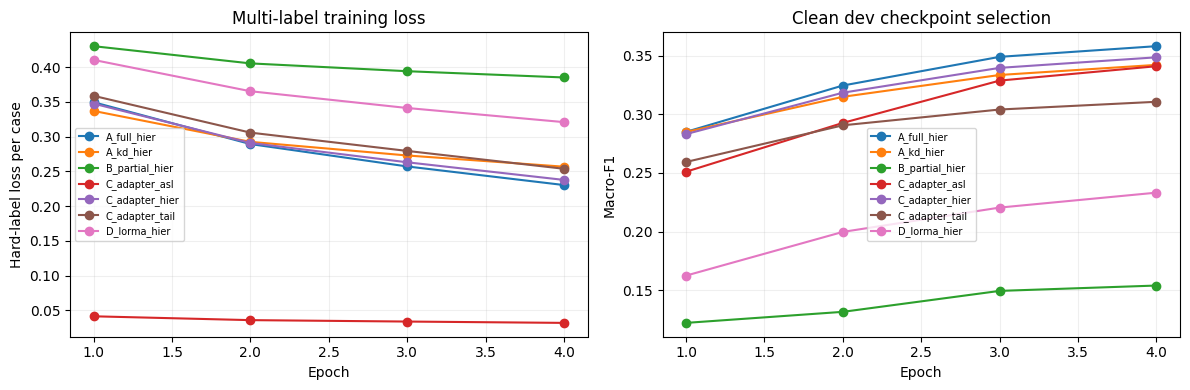

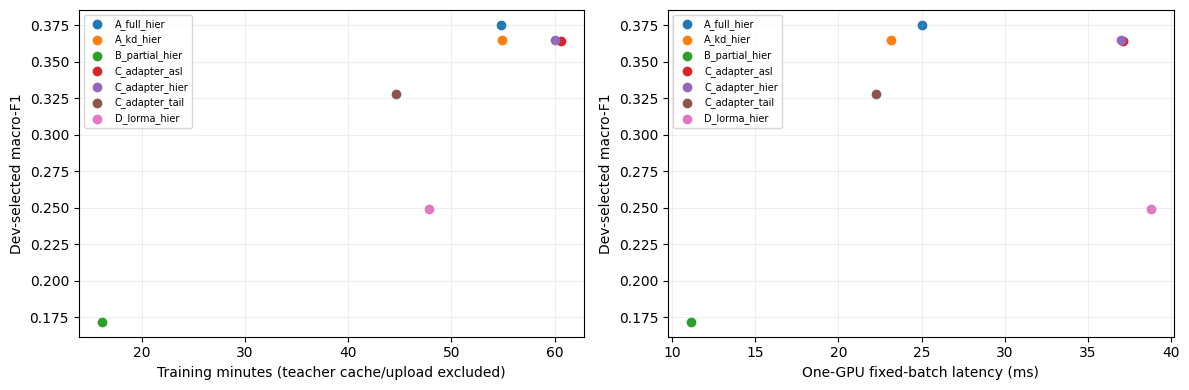

In [30]:
if RUN_WORKFLOW and RUN_MODE == "train":
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for item in RESULTS:
        history = read(OUTPUT_DIR / item["experiment"] / "history.json")
        epochs = [row["epoch"] for row in history]
        axes[0].plot(
            epochs, [row["train_loss"] for row in history], marker="o", label=item["experiment"]
        )
        axes[1].plot(
            epochs, [row["dev_macro_f1"] for row in history], marker="o", label=item["experiment"]
        )
    axes[0].set(
        title="Multi-label training loss", xlabel="Epoch", ylabel="Hard-label loss per case"
    )
    axes[1].set(title="Clean dev checkpoint selection", xlabel="Epoch", ylabel="Macro-F1")
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150)
    display(fig)
    plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for item in RESULTS:
        axes[0].scatter(
            item["training_minutes"], item["selected_dev_macro_f1"], label=item["experiment"]
        )
        axes[1].scatter(
            item["latency_batch_ms"], item["selected_dev_macro_f1"], label=item["experiment"]
        )
    axes[0].set(
        xlabel="Training minutes (teacher cache/upload excluded)", ylabel="Dev-selected macro-F1"
    )
    axes[1].set(xlabel="One-GPU fixed-batch latency (ms)", ylabel="Dev-selected macro-F1")
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "quality_cost.png", dpi=150)
    display(fig)
    plt.close(fig)


## Model bundle


In [31]:
MODEL_BUNDLE = None
if RUN_WORKFLOW and CREATE_LOCAL_MODEL_BUNDLE:
    MODEL_BUNDLE, BUNDLE_RECEIPT = make_backup(
        CONFIG_PATH,
        RUNTIME,
        TOKENIZER_DIR,
        ROOT / "model_bundles",
        include_resume=UPLOAD_RESUME_STATE,
        include_bases=INCLUDE_BASE_WEIGHTS_IN_BUNDLE,
    )
    print(json.dumps(BUNDLE_RECEIPT, indent=2))
    display(FileLink(str(MODEL_BUNDLE)))


{
  "phase": 5,
  "archive": "/kaggle/working/cs781-phase5/lsi_run1/model_bundles/cs781_phase5_models_20261026_235229_971912.zip",
  "sha256": "888c9e38bd493de6f17f602469006c1b2964d4d0fb60ac5784a2044c8f2438f5",
  "bytes": 763009106,
  "experiments": [
    "C_adapter_asl",
    "C_adapter_hier",
    "C_adapter_tail",
    "B_partial_hier",
    "A_kd_hier",
    "D_lorma_hier",
    "A_full_hier"
  ],
  "optimizer_resume_included": false,
  "original_bases_included": false
}


/kaggle/working/cs781-phase5/lsi_run1/model_bundles/cs781_phase5_models_20261026_235229_971912.zip

In [32]:
if RUN_WORKFLOW and AUTO_HF_BACKUP:
    for checkpoint in sorted(OUTPUT_DIR.glob("*/best.pt")):
        sync_snapshot(read(CONFIG_PATH), RUNTIME, checkpoint.parent.name)
    print("Phase 5 snapshots saved under:", HF_BACKUP_REPO, "runs/" + RUN_NAME)


HF_BACKUP_COMPLETED {'repo': 'I-230482/cs781-phase5-models', 'prefix': 'runs/lsi_run1', 'commit': 'cce46bc0eb6f068de5e38a0d849cc164f9a525ac', 'experiment': 'A_full_hier', 'seconds': 4.225017621000006, 'optimizer_resume_included': False}
HF_BACKUP_COMPLETED {'repo': 'I-230482/cs781-phase5-models', 'prefix': 'runs/lsi_run1', 'commit': 'd4e445508bd99365bea8881c0190fc5b963cc2e1', 'experiment': 'A_kd_hier', 'seconds': 4.108944649997284, 'optimizer_resume_included': False}
HF_BACKUP_COMPLETED {'repo': 'I-230482/cs781-phase5-models', 'prefix': 'runs/lsi_run1', 'commit': '56193cf5067153ac93c4370422681891ff1adf20', 'experiment': 'B_partial_hier', 'seconds': 2.3826424309991125, 'optimizer_resume_included': False}
HF_BACKUP_COMPLETED {'repo': 'I-230482/cs781-phase5-models', 'prefix': 'runs/lsi_run1', 'commit': '5326177e1d6fd64d5a459f592779751023f4a544', 'experiment': 'C_adapter_asl', 'seconds': 1.472050461001345, 'optimizer_resume_included': False}
HF_BACKUP_COMPLETED {'repo': 'I-230482/cs781-pha

In [33]:
from pathlib import Path
from datetime import datetime, timezone
import os

from huggingface_hub import HfApi, hf_hub_url
from IPython.display import display, Markdown

HF_REPO_ID = "I-230482/cs781-phase5-models"
RESULTS_DIR = Path(
    globals().get(
        "OUTPUT_DIR",
        "/kaggle/working/cs781-phase5/lsi_run1/results",
    )
).resolve()

# Find the generated competition files.
files = sorted(
    p for p in RESULTS_DIR.rglob("*")
    if p.is_file()
    and (p.suffix == ".zip" or p.name == "prediction.json")
)
if not files:
    raise FileNotFoundError(
        f"No submission files found in {RESULTS_DIR}. "
        "Run the prediction/export cells first."
    )

# Read credentials from the environment or Kaggle Secrets.
token = os.environ.get("HF_TOKEN")
if not token:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("HF_TOKEN")
if not token:
    raise RuntimeError("Add HF_TOKEN to Kaggle Secrets and enable access.")

api = HfApi(token=token)
api.create_repo(
    repo_id=HF_REPO_ID,
    repo_type="model",
    private=True,
    exist_ok=True,
)
api.update_repo_settings(
    repo_id=HF_REPO_ID,
    repo_type="model",
    private=True,
)

# A new folder preserves earlier uploads.
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
remote_folder = f"submissions/phase5_{stamp}"

commit = api.upload_folder(
    repo_id=HF_REPO_ID,
    repo_type="model",
    folder_path=str(RESULTS_DIR),
    path_in_repo=remote_folder,
    allow_patterns=[p.relative_to(RESULTS_DIR).as_posix() for p in files],
    commit_message="Back up Phase 5 submission files",
)

print(f"UPLOAD COMPLETED: {len(files)} files")
print("Commit:", commit.oid)

folder_url = (
    f"https://huggingface.co/{HF_REPO_ID}"
    f"/tree/{commit.oid}/{remote_folder}"
)
display(Markdown(f"**[Open all uploaded submissions]({folder_url})**"))

for path in files:
    if path.suffix == ".zip":
        relative = path.relative_to(RESULTS_DIR).as_posix()
        url = hf_hub_url(
            repo_id=HF_REPO_ID,
            filename=f"{remote_folder}/{relative}",
            revision=commit.oid,
            repo_type="model",
        )
        display(Markdown(f"[Download {relative}]({url}?download=true)"))

UPLOAD COMPLETED: 21 files
Commit: 2523faeda18a94d13efb93a16c640d63c05c4db1


**[Open all uploaded submissions](https://huggingface.co/I-230482/cs781-phase5-models/tree/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197)**

[Download A_full_hier/submission/submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/A_full_hier/submission/submission.zip?download=true)

[Download A_kd_hier/submission/submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/A_kd_hier/submission/submission.zip?download=true)

[Download B_partial_hier/submission/submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/B_partial_hier/submission/submission.zip?download=true)

[Download C_adapter_asl/submission/submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/C_adapter_asl/submission/submission.zip?download=true)

... (6 outputs left out)

[Download selected_A_submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/selected_A_submission.zip?download=true)

[Download selected_B_submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/selected_B_submission.zip?download=true)

[Download selected_C_submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/selected_C_submission.zip?download=true)

[Download selected_D_submission.zip](https://huggingface.co/I-230482/cs781-phase5-models/resolve/2523faeda18a94d13efb93a16c640d63c05c4db1/submissions/phase5_20261026_235251_005197/selected_D_submission.zip?download=true)

## ..................................................................................................................................................References and reload
